**DATA EXPLORATION**

**Import Data**

In [1]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from ipywidgets import interact, Output, VBox, HBox, Label
from IPython.display import display, clear_output

In [2]:
loan_data_backup = pd.read_csv("D:/DEO DESKTOP FOLDER/WEBSITE/CREDIT RISK MODELLING/loan_data_2007_2014.csv") 

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\106811927.py:1: DtypeWarning: Columns (20) have mixed types. Specify dtype option on import or set low_memory=False.
  loan_data_backup = pd.read_csv("D:/DEO DESKTOP FOLDER/WEBSITE/CREDIT RISK MODELLING/loan_data_2007_2014.csv")


In [3]:
loan_data = loan_data_backup.copy()

In [4]:
df = pd.DataFrame({'A': [1,2,3]})
df.style.set_caption('<b>Bold Title</b> <i>Italic Subtitle</i>')

,A
0,1
1,2
2,3


In [5]:
# Method 2: Styled DataFrames
df.style.set_caption('<b>Bold Caption</b>')

# Method 3: Markdown cell (manual)
# Just type in a markdown cell: **bold** *italic*


# Method 1: HTML in pandas

from IPython.display import HTML

df = pd.DataFrame({'A': [1, 2, 3]})
display(HTML('<b>Bold</b> {df} and <i>Italic</i> heading'))
from IPython.display import display
display(df)  # This renders the beautiful interactive HTML table automatically.

# Make the value '2' bold and red, just to show you how it works
styled_df = df.style.applymap(
    lambda x: 'font-weight: bold; font-style: italic; color: red;' if x == 2 else ''
)
display(styled_df)


from IPython.display import display, HTML, Markdown

display(HTML('<h2><b>My Bold Heading</b></h2>'))  # Bold heading
display(df)  # The table right below it

,A
0,1
1,2
2,3


C:\Users\USER\AppData\Local\Temp\ipykernel_11004\937973857.py:18: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_df = df.style.applymap(


,A
0,1
1,2
2,3


,A
0,1
1,2
2,3


In [6]:
from rich import print
print("[bold red]HEADING[/bold red] [italic]subtitle[/italic]")

HEADING subtitle

In [7]:


df = pd.DataFrame({'Metric_A': [10, 20, 30], 'Metric_B': [40, 50, 60]})

# Apply CSS directly to the DataFrame rendering engine
styled_df = df.style.set_table_styles([
    # Bold and center the column headers
    {'selector': 'thead th', 'props': [
        ('font-weight', 'bold'), 
        ('text-align', 'center'),
        ('font-size', '14px')
    ]},
    # Italicize the row indices
    {'selector': 'tbody th', 'props': [('font-style', 'italic')]},
    # Add a subtle hover effect to rows
    {'selector': 'tbody tr:hover', 'props': [('background-color', '#f2f2f2')]}
]).set_properties(**{
    'font-style': 'italic', # Italicize all data cells
    'text-align': 'right'   # Right-align numbers
})

# Display the styled DataFrame
styled_df

,Metric_A,Metric_B
0,10,40
1,20,50
2,30,60


In [8]:
from IPython.display import HTML

# You must explicitly write the <table>, <tr>, and <td> tags
html_table = """
<table style="border-collapse: collapse; width: 50%;">
  <thead>
    <tr style="background-color: #f4f4f4;">
      <th style="padding: 8px; border: 1px solid #ddd;"><b>Bold Header A</b></th>
      <th style="padding: 8px; border: 1px solid #ddd;"><i>Italic Header B</i></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding: 8px; border: 1px solid #ddd;">1</td>
      <td style="padding: 8px; border: 1px solid #ddd; font-weight: bold;">2</td>
    </tr>
  </tbody>
</table>
"""

# Now Jupyter will render the table properly
HTML(html_table)

Bold Header A,Italic Header B
1,2


**Explore Data**

In [9]:
pd.options.display.max_columns= None 

loan_data.sample(5)

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
3366,3366,1019952,1248915,20000,20000,19750.0,36 months,10.65,651.47,B,B2,ALLtra Corp.,10+ years,MORTGAGE,120000.0,Source Verified,Nov-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 11/10/11 > Consolidating a...,credit_card,CC Refi,740xx,OK,8.28,0.0,Apr-01,0.0,NaN,NaN,9.0,0.0,35695,50.4,10.0,f,0.00,0.00,23449.64385,23156.50,20000.00,3449.64,0.0,0.0,0.0,Dec-14,664.93,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
301514,301514,28462594,30985715,6000,6000,6000.0,36 months,7.69,187.17,A,A4,chef,< 1 year,MORTGAGE,68000.0,Verified,Oct-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,329xx,FL,29.02,0.0,Oct-01,0.0,47.0,NaN,16.0,0.0,4982,25.3,43.0,f,3396.61,3396.61,3057.68000,3057.68,2603.39,454.29,0.0,0.0,0.0,Jan-16,187.17,Feb-16,Jan-16,1.0,55.0,1,INDIVIDUAL,NaN,NaN,NaN,0.0,19305.0,209875.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19700.0,NaN,NaN,NaN
261296,261296,33671576,36324860,6600,6600,6600.0,36 months,7.49,205.28,A,A4,Manager,10+ years,MORTGAGE,90000.0,Not Verified,Nov-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,NaN,credit_card,Credit card refinancing,704xx,LA,12.31,0.0,Jan-03,1.0,39.0,NaN,8.0,0.0,11932,46.8,20.0,f,4207.24,4207.24,2871.17000,2871.17,2392.76,478.41,0.0,0.0,0.0,Jan-16,205.28,Feb-16,Jan-16,0.0,39.0,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,286121.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25500.0,NaN,NaN,NaN
259525,259525,34452090,37115360,20400,20400,20400.0,60 months,9.49,428.34,B,B2,"Program Lead, Human Resources",3 years,RENT,101631.0,Source Verified,Nov-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,NaN,credit_card,Credit card refinancing,209xx,MD,10.99,0.0,Oct-96,0.0,NaN,117.0,13.0,1.0,14115,92.9,19.0,f,16463.49,16463.49,5986.00000,5986.00,3936.51,2049.49,0.0,0.0,0.0,Jan-16,428.34,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,43697.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15200.0,NaN,NaN,NaN
76442,76442,7945772,9667837,25000,25000,25000.0,60 months,17.10,622.66,C,C5,Director Product Development,7 years,MORTGAGE,119000.0,Verified,Oct-13,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 10/12/13 > This loan will ...,debt_consolidation,Debt consolidation,235xx,VA,20.76,0.0,Jan-91,3.0,NaN,NaN,7.0,0.0,31036,69.0,22.0,f,16301.84,16301.84,16811.54000,16811.54,8698.16,8113.38,0.0,0.0,0.0,Jan-16,622.66,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,443457.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45000.0,NaN,NaN,NaN


In [10]:
np.sort(loan_data.columns)

array(['Unnamed: 0', 'acc_now_delinq', 'addr_state', 'all_util',
       'annual_inc', 'annual_inc_joint', 'application_type',
       'collection_recovery_fee', 'collections_12_mths_ex_med',
       'delinq_2yrs', 'desc', 'dti', 'dti_joint', 'earliest_cr_line',
       'emp_length', 'emp_title', 'funded_amnt', 'funded_amnt_inv',
       'grade', 'home_ownership', 'id', 'il_util', 'initial_list_status',
       'inq_fi', 'inq_last_12m', 'inq_last_6mths', 'installment',
       'int_rate', 'issue_d', 'last_credit_pull_d', 'last_pymnt_amnt',
       'last_pymnt_d', 'loan_amnt', 'loan_status', 'max_bal_bc',
       'member_id', 'mths_since_last_delinq',
       'mths_since_last_major_derog', 'mths_since_last_record',
       'mths_since_rcnt_il', 'next_pymnt_d', 'open_acc', 'open_acc_6m',
       'open_il_12m', 'open_il_24m', 'open_il_6m', 'open_rv_12m',
       'open_rv_24m', 'out_prncp', 'out_prncp_inv', 'policy_code',
       'pub_rec', 'purpose', 'pymnt_plan', 'recoveries', 'revol_bal',
       'rev

In [11]:
loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  object 
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  object 
 10  sub_grade                    466285 non-null  object 
 11  emp_title                    438697 non-null  object 
 12  emp_length                   445277 non-null  object 
 13 

In [12]:
loan_data.describe()

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_amnt,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
count,466285.000000,4.662850e+05,4.662850e+05,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,4.662810e+05,466285.000000,466256.000000,466256.000000,215934.000000,62638.000000,466256.000000,466256.000000,4.662850e+05,465945.000000,466256.000000,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,466285.000000,466140.000000,98974.000000,466285.0,0.0,0.0,0.0,466256.000000,3.960090e+05,3.960090e+05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.960090e+05,0.0,0.0,0.0
mean,233142.000000,1.307973e+07,1.459766e+07,14317.277577,14291.801044,14222.329888,13.829236,432.061201,7.327738e+04,17.218758,0.284678,0.804745,34.104430,74.306012,11.187069,0.160564,1.623020e+04,56.176947,25.064430,4410.062342,4408.452258,11540.686220,11469.892747,8866.014657,2588.677225,0.650129,85.344211,8.961534,3123.913796,0.009085,42.852547,1.0,NaN,NaN,NaN,0.004002,1.919135e+02,1.388017e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.037909e+04,NaN,NaN,NaN
std,134605.029472,1.089371e+07,1.168237e+07,8286.509164,8274.371300,8297.637788,4.357587,243.485550,5.496357e+04,7.851121,0.797365,1.091598,21.778487,30.357653,4.987526,0.510863,2.067625e+04,23.732628,11.600141,6355.078769,6353.198001,8265.627112,8254.157579,7031.687997,2483.809661,5.265730,552.216084,85.491437,5554.737393,0.108648,21.662591,0.0,NaN,NaN,NaN,0.068637,1.463021e+04,1.521147e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.724713e+04,NaN,NaN,NaN
min,0.000000,5.473400e+04,7.047300e+04,500.000000,500.000000,0.000000,5.420000,15.670000,1.896000e+03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,NaN,NaN,NaN,0.000000,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN,NaN
25%,116571.000000,3.639987e+06,4.379705e+06,8000.000000,8000.000000,8000.000000,10.990000,256.690000,4.500000e+04,11.360000,0.000000,0.000000,16.000000,53.000000,8.000000,0.000000,6.413000e+03,39.200000,17.000000,0.000000,0.000000,5552.125349,5499.250000,3708.560000,957.280000,0.000000,0.000000,0.000000,312.620000,0.000000,26.000000,1.0,NaN,NaN,NaN,0.000000,0.000000e+00,2.861800e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.350000e+04,NaN,NaN,NaN
50%,233142.000000,1.010790e+07,1.194108e+07,12000.000000,12000.000000,12000.000000,13.660000,379.890000,6.300000e+04,16.870000,0.000000,0.000000,31.000000,76.000000,10.000000,0.000000,1.176400e+04,57.600000,23.000000,441.470000,441.380000,9419.250943,9355.430000,6817.760000,1818.880000,0.000000,0.000000,0.000000,545.960000,0.000000,42.000000,1.0,NaN,NaN,NaN,0.000000,0.000000e+00,8.153900e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.280000e+04,NaN,NaN,NaN
75%,349713.000000,2.073121e+07,2.300154e+07,20000.000000,20000.000000,19950.000000,16.490000,566.580000,8.896000e+04,22.780000,0.000000,1.000000,49.000000,102.000000,14.000000,0.000000,2.033300e+04,74.700000,32.000000,7341.650000,7338.390000,15308.158460,15231.310000,12000.000000,3304.530000,0.000000,0.000000,0.000000,3187.510000,0.000000,59.000000,1.0,NaN,NaN,NaN,0.000000,0.000000e+00,2.089530e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

**GENERAL PREPROCESSING DATES AND TIME AND TIME LENGTHS**

**General Preprocessing**
**Preprocessing DATES and Times**     'earliest_cr_line', 'issue_d', 'last_pymnt_d', 'last_credit_pull_d',
    'next_pymnt_d', 'term', 'emp_length',  

In [13]:

def clean_term_months(term_series):
    """Clean term column and convert to numeric. Ironclad version."""
    
    # 1. String Cleaning (Explicit regex=True/False to prevent Pandas warnings)
    cleaned = (
        term_series
        .str.replace(r'\+ months', '', regex=True)       # Remove "+ months"
        .str.replace('< 1 month', '0', regex=False)      # Literal replace
        .str.replace('n/a', '0', regex=False)            # Literal replace
        .str.replace(r"months?|\+", "", regex=True)      # Remove "month", "months", or "+"
        .str.strip()                                     # Remove leading/trailing whitespace
    )

    # 2. Numeric Conversion (Fails safely to NaN)
    numeric_series = pd.to_numeric(cleaned, errors='coerce')

    # 3. Handle Missing Values & Enforce Integer Type
    # fillna(0) handles the original NaNs AND the ones created by errors='coerce'
    # astype(int) forces it to int64, matching your expected output
    return numeric_series.fillna(0).astype(int)



In [14]:
def clean_term_years(emp_series):
    cleaned = (emp_series
               .str.replace(r'\+ years', '', regex=True)
               .str.replace('< 1 year', '0')
               .str.replace('n/a', '0')
               .str.replace(r'years?|[+]', '', regex=True)
               .str.strip()
              )

    return pd.to_numeric(cleaned, errors='coerce')

In [15]:
~loan_data['emp_length'].duplicated().head(3)

0     True
1     True
2    False
Name: emp_length, dtype: bool

In [16]:
# Clean values
loan_data['term_int'] = clean_term_months(loan_data['term'])
loan_data['emp_length_int'] = clean_term_years(loan_data['emp_length'])


# Fill AFTER cleaning (important)
loan_data['emp_length_int'] = loan_data['emp_length_int'].fillna(0)


In [17]:
loan_data['earliest_cr_line_date'] = pd.to_datetime(loan_data['earliest_cr_line'], format = '%b-%y')

loan_data['mths_since_earliest_cr_line'] = round(
    pd.to_numeric((pd.to_datetime('2017-12-01')-loan_data['earliest_cr_line_date'])/np.timedelta64(30,'D')))

In [18]:

ref = pd.to_datetime("2017-11-01")


loan_data['issue_d_date'] = pd.to_datetime(loan_data['issue_d'], format='%b-%y')


loan_data['mths_since_issue_d'] = (
    (ref.year - loan_data['issue_d_date'].dt.year) * 12 + 
    (ref.month - loan_data['issue_d_date'].dt.month) -
    (ref.day < loan_data['issue_d_date'].dt.day).astype(int)
)

print(loan_data['mths_since_issue_d'].describe())
print(loan_data.loc[:, ['issue_d', 'issue_d_date', 'mths_since_issue_d']][loan_data['mths_since_issue_d'] < 0])

# Fix negative values
mask = loan_data['mths_since_issue_d'] < 0
loan_data.loc[mask, 'mths_since_issue_d'] = loan_data['mths_since_issue_d'].max()



count    466285.000000
mean         50.255187
std          14.340154
min          35.000000
25%          40.000000
50%          46.000000
75%          56.000000
max         125.000000
Name: mths_since_issue_d, dtype: float64

Empty DataFrame
Columns: [issue_d, issue_d_date, mths_since_issue_d]
Index: []

In [19]:

loan_data['mths_since_earliest_cr_line'] = \
    (ref.year- loan_data['earliest_cr_line_date'].dt.year) * 12 + \
    (ref.month - loan_data['earliest_cr_line_date'].dt.month) -\
    (ref.day < loan_data['earliest_cr_line_date'].dt.day).astype(int)


In [20]:
loan_data.loc[:, ['earliest_cr_line', 'earliest_cr_line_date', 'mths_since_earliest_cr_line']][loan_data['mths_since_earliest_cr_line']<0].sample(3)

,earliest_cr_line,earliest_cr_line_date,mths_since_earliest_cr_line
390035,Jul-67,2067-07-01,-596.0
26450,Sep-63,2063-09-01,-550.0
104576,Oct-65,2065-10-01,-575.0


In [21]:
'''ONE SOLUTION TO THE FUTURISTIC NEGATIVE VALUES ABOVE'''

# loan_data['mths_since_earliest_cr_line'][loan_data['mths_since_earliest_cr_line']<0] = max(loan_data['mths_since_earliest_cr_line'])
# loan_data.loc[:,'mths_since_earliest_cr_line'][loan_data.loc[:,'mths_since_earliest_cr_line']<0] = loan_data.loc[:,'mths_since_earliest_cr_line'].max()

#mask = loan_data['mths_since_earliest_cr_line'] < 0
#loan_data.loc[mask, 'mths_since_earliest_cr_line'] = loan_data['mths_since_earliest_cr_line'].max()

loan_data.loc[loan_data.loc[:,'mths_since_earliest_cr_line']<0,'mths_since_earliest_cr_line'] =\
loan_data.loc[:,'mths_since_earliest_cr_line'].max()


In [22]:
min(loan_data['mths_since_earliest_cr_line'])

72.0

In [23]:
loan_data.loc[:, ['issue_d','issue_d_date','earliest_cr_line', 'earliest_cr_line_date', 'mths_since_earliest_cr_line']][loan_data['mths_since_earliest_cr_line']<0].head(3)

,issue_d,issue_d_date,earliest_cr_line,earliest_cr_line_date,mths_since_earliest_cr_line


In [24]:
# ✅ DATE CLEANING FUNCTION


def clean_date_column(date_series, ref_date):
    # Convert to datetime
    date_clean = pd.to_datetime(date_series, format='%b-%y', errors='coerce')
    
    # Calculate months difference
    months = (
        (ref_date.year - date_clean.dt.year) * 12 +
        (ref_date.month - date_clean.dt.month)
    )
    
    return date_clean, months

# loan_data["mths_since_issue_d"] = clean_date_column(loan_data["issue_d_date"], ref)
# loan_data["mths_since_earliest_cr_line"] = clean_date_column(loan_data["earliest_cr_line_date"], ref)

In [25]:
ref = pd.to_datetime("2017-11-01")


loan_data['issue_d_date'], loan_data['mths_since_issue_d'] = clean_date_column(
    loan_data['issue_d'], ref
)


# Fix negative values

print(loan_data.loc[:, ['issue_d', 'issue_d_date', 'mths_since_issue_d']][loan_data['mths_since_issue_d']<0].head())


# OR 
print(loan_data.loc[loan_data['mths_since_issue_d']<0, ['issue_d', 'issue_d_date', 'mths_since_issue_d']].head())


#OR 
mask = loan_data['mths_since_issue_d'] < 0
loan_data.loc[mask, 'mths_since_issue_d'] = loan_data['mths_since_issue_d'].max()


print(f'\n\n\n{loan_data['mths_since_issue_d'].describe()=}\n')

Empty DataFrame
Columns: [issue_d, issue_d_date, mths_since_issue_d]
Index: []

Empty DataFrame
Columns: [issue_d, issue_d_date, mths_since_issue_d]
Index: []

loan_data['mths_since_issue_d'].describe()=count    466285.000000
mean         50.255187
std          14.340154
min          35.000000
25%          40.000000
50%          46.000000
75%          56.000000
max         125.000000
Name: mths_since_issue_d, dtype: float64

In [26]:

loan_data['mths_since_issue_d'].unique()

array([ 71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,
        84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,
        97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109,
       110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122,
       123, 124, 125,  47,  48,  49,  50,  51,  52,  53,  54,  55,  56,
        57,  58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,
        70,  35,  36,  37,  38,  39,  40,  41,  42,  43,  44,  45,  46],
      dtype=int32)

In [27]:
loan_data['issue_d_date'].unique()

<DatetimeArray>
['2011-12-01 00:00:00', '2011-11-01 00:00:00', '2011-10-01 00:00:00',
 '2011-09-01 00:00:00', '2011-08-01 00:00:00', '2011-07-01 00:00:00',
 '2011-06-01 00:00:00', '2011-05-01 00:00:00', '2011-04-01 00:00:00',
 '2011-03-01 00:00:00', '2011-02-01 00:00:00', '2011-01-01 00:00:00',
 '2010-12-01 00:00:00', '2010-11-01 00:00:00', '2010-10-01 00:00:00',
 '2010-09-01 00:00:00', '2010-08-01 00:00:00', '2010-07-01 00:00:00',
 '2010-06-01 00:00:00', '2010-05-01 00:00:00', '2010-04-01 00:00:00',
 '2010-03-01 00:00:00', '2010-02-01 00:00:00', '2010-01-01 00:00:00',
 '2009-12-01 00:00:00', '2009-11-01 00:00:00', '2009-10-01 00:00:00',
 '2009-09-01 00:00:00', '2009-08-01 00:00:00', '2009-07-01 00:00:00',
 '2009-06-01 00:00:00', '2009-05-01 00:00:00', '2009-04-01 00:00:00',
 '2009-03-01 00:00:00', '2009-02-01 00:00:00', '2009-01-01 00:00:00',
 '2008-12-01 00:00:00', '2008-11-01 00:00:00', '2008-10-01 00:00:00',
 '2008-09-01 00:00:00', '2008-08-01 00:00:00', '2008-07-01 00:00:00',
 '20

**General Feature Selection**  GENERAL FEATURE SELECTION

>>>**AUTOMATIC FEATURE SELECTION***

 **📋 PROBABLE FEATURE LISTS (PRODUCTION-READY)**


| Variable                         | Simple Meaning                                      | PD (Default Risk)                          | LGD (Loss Severity)                        | EAD (Exposure at Default)                 |
|----------------------------------|----------------------------------------------------|-------------------------------------------|-------------------------------------------|-------------------------------------------|
| loan_amnt                        | Amount borrower requested                          | ✅ Bigger loan = harder to repay           | ✅ Bigger loan = harder to recover %       | ✅ Bigger loan = higher exposure           |
| funded_amnt                      | Amount actually given                              | ✅ Core exposure                           | ✅ Actual exposure matters                 | ✅ Core exposure                           |
| funded_amnt_inv                  | Amount funded by investors                         | ⚠️ Redundant                              | ⚠️ Redundant                              | ⚠️ Redundant                              |
| term_int                         | Loan length (months)                               | ✅ Longer = more time to default           | ✅ Longer = more uncertainty               | ✅ Affects repayment structure             |
| int_rate                         | Interest rate (%)                                  | ✅ High = riskier borrower                 | ✅ High = higher loss risk                 | ✅ Affects balance growth                  |
| installment                      | Monthly payment                                    | ✅ High = repayment stress                 | ✅ Harder to recover                       | ⚠️ Indirect                                |
| grade / sub_grade                | Risk rating                                        | ✅ Core predictor                          | ✅ Impacts recovery expectations           | ✅ Impacts limits                          |
| annual_inc                       | Annual income                                      | ✅ Higher = safer                          | ✅ Higher = better recovery                | ✅ Higher = more borrowing capacity        |
| dti                              | Debt-to-income ratio                               | ✅ High = risky                            | ✅ High = worse recovery                   | ✅ Limits borrowing                        |
| emp_length_int                   | Years employed                                     | ✅ Stability signal                        | ✅ May affect recovery                     | ⚠️ Weak                                    |
| emp_length_missing               | Missing employment info                            | ✅ Missing = risk signal                   | ✅ Same logic                              | ⚠️ Test                                    |
| home_ownership                   | Rent / Own / Mortgage                              | ✅ Stability proxy                         | ✅ Asset recovery potential                | ✅ Affects collateral                      |
| verification_status              | Income verified?                                   | ✅ Unverified = risky                      | ✅ Impacts trust                           | ⚠️ Weak                                    |
| purpose                          | Loan purpose                                       | ✅ Some purposes riskier                   | ✅ Collateral differences                  | ✅ Affects draw behavior                   |
| addr_state                       | Borrower location                                  | ✅ Regional risk                           | ✅ Legal recovery differences              | ⚠️ Weak                                    |
| mths_since_earliest_cr_line      | Credit history length                              | ✅ Longer = more stable                    | ✅ More history helps recovery             | ✅ Experience proxy                        |
| mths_since_issue_d               | Time since loan issued                             | ❌ Not available at origination            | ✅ Early default vs late matters           | ✅ Affects utilization                     |
| delinq_2yrs                      | Past delinquencies                                 | ✅ Strong predictor                        | ✅ Habitual risk                           | ✅ Risk of further borrowing               |
| inq_last_6mths                   | Recent credit inquiries                            | ✅ Credit hunger                           | ✅ Financial stress                        | ✅ Likely to borrow more                   |
| open_acc                         | Open accounts                                      | ✅ Credit complexity                       | ✅ Multiple recovery paths                 | ✅ Multiple exposures                      |
| total_acc                        | Total accounts                                     | ✅ Credit history breadth                  | ✅ Same logic                              | ✅ Same logic                              |
| pub_rec                          | Public records (bankruptcy etc.)                   | ✅ Major red flag                          | ✅ Recovery severely impacted              | ✅ Affects limits                          |
| revol_util                       | % credit used                                      | ✅ High = stress                           | ✅ Less buffer                             | ✅ Likely to max out                       |
| revol_bal                        | Revolving balance                                  | ✅ Usage signal                            | ✅ Recovery potential                      | ✅ Core exposure                           |
| total_rev_hi_lim                 | Total credit limit                                 | ✅ Capacity signal                         | ⚠️ Indirect                               | ✅ Exposure capacity                       |
| acc_now_delinq                   | Currently delinquent accounts                      | ✅ Immediate risk                          | ✅ Harder recovery                         | ✅ Cascade risk                            |
| collections_12_mths_ex_med       | Recent collections                                 | ✅ Hardship signal                         | ✅ Impacts recovery                        | ⚠️ Test                                    |
| mths_since_last_delinq           | Time since last delinquency                        | ⚠️ Use with flag (53% missing)             | ⚠️ Same                                   | ⚠️ Same                                   |
| mths_since_last_major_derog      | Time since major derog                             | ❌ Too missing (~78%)                      | ❌ Too missing                            | ❌ Too missing                            |
| mths_since_last_record           | Time since public record                           | ❌ Too missing (~86%)                      | ❌ Too missing                            | ❌ Too missing                            |
| tot_cur_bal                      | Total current balance                              | ⚠️ Fill/flag (~15% missing)                | ⚠️ Debt affects recovery                   | ⚠️ Affects exposure                        |
| tot_coll_amt                     | Collections balance                                | ⚠️ Fill/flag                              | ⚠️ Recovery relevance                      | ⚠️ Exposure relevance                      |
| initial_list_status              | Loan listing type                                  | ✅ Servicing signal                        | ✅ Recovery difference                     | ⚠️ Weak                                    |
| recoveries                       | Money recovered after default                      | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 |
| collection_recovery_fee          | Collection costs                                   | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 |
| total_rec_prncp                  | Principal repaid                                   | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 |
| total_rec_int                    | Interest repaid                                    | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 |
| total_pymnt                      | Total payments                                     | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 |
| total_pymnt_inv                  | Investor payments                                  | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 |
| last_pymnt_amnt                  | Last payment                                       | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 | ❌ LEAKAGE                                 |
| out_prncp                        | Outstanding principal                              | ❌ Changes over time                       | ❌ Target-related                          | ❌ TARGET (EAD)                            |
| out_prncp_inv                    | Investor outstanding principal                     | ❌ Same                                    | ❌ Same                                    | ❌ Same                                    |
| next_pymnt_d                     | Next payment date                                  | ❌ Future info                             | ❌ Future info                             | ❌ Future info                             |
| last_pymnt_d                     | Last payment date                                  | ❌ Post-event                              | ❌ Post-event                              | ❌ Post-event                              |
| last_credit_pull_d               | Last credit check                                  | ❌ Weak timing                             | ❌ Weak                                    | ❌ Weak                                    |
| policy_code                      | Internal flag                                      | ❌ Constant                                | ❌ Constant                                | ❌ Constant                                |
| application_type                 | Individual vs joint                                | ❌ Almost constant                         | ❌ Same                                    | ❌ Same                                    |
| pymnt_plan                       | Special plan                                       | ❌ Rare                                    | ❌ Rare                                    | ❌ Rare                                    |
| id / member_id / url / desc      | Identifiers / text                                 | ❌ Noise                                   | ❌ Noise                                   | ❌ Noise                                   |

In [28]:

# 🚨 UNIVERSAL DROPS (ALL MODELS) — DROP THESE FIRST

# Gonna use zero variance and delete column all nans to automatically remove the following thats why they are commented out 
'''# === 100% MISSING COLUMNS (Zero information) ===
    'annual_inc_joint', 'dti_joint', 'verification_status_joint',
    'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
    'mths_since_rcnt_il', 'total_bal_il', 'il_util',
    'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
    'inq_fi', 'total_cu_tl', 'inq_last_12m',''' 

# Have to first create alternatives for the following before i drop them 
'''
    # === DUPLICATE/REDAUNDANT (Keep engineered versions) ===
    'earliest_cr_line', 'issue_d', 'last_pymnt_d', 'last_credit_pull_d',
    'next_pymnt_d', 'term', 'emp_length',  # Keep _int versions instead
    '''


# Universal drops for PD, LGD, EAD

universal_drops = [
    # === IDENTIFIERS (Zero predictive power, privacy risk) ===
    'id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
    
    # === TEXT FIELDS (Need NLP to use, not ready yet) ===
    'desc', 'title', 'emp_title',
    
    
]

In [29]:
# ✅ PD: COLUMNS TO KEEP (STRONG PREDICTORS)

pd_features_keep = [
    # === LOAN STRUCTURE (Known at origination) ===
    'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
    'term_int', 'int_rate', 'installment',
    
    # === BORROWER CREDIT PROFILE ===
    'grade:A', 'grade:B', 'grade:C', 'grade:D', 'grade:E', 'grade:F',  # Drop G as reference
    'sub_grade:A1', 'sub_grade:A2', ..., 'sub_grade:F4',  # Drop G5 as reference
    'annual_inc', 'dti', 'emp_length_int',
    
    # === CREDIT HISTORY BEHAVIOR ===
    'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'total_acc',
    'revol_bal', 'revol_util', 'total_rev_hi_lim',
    'mths_since_earliest_cr_line', 'acc_now_delinq',
    
    # === BORROWER CHARACTERISTICS (Encoded) ===
    'home_ownership:MORTGAGE', 'home_ownership:OWN', 'home_ownership:RENT',  # Drop ANY/NONE as reference
    'verification_status:Not Verified', 'verification_status:Source Verified',  # Drop Verified as reference
    'purpose:debt_consolidation', 'purpose:credit_card', 'purpose:home_improvement', ...,  # Drop one as reference
    'addr_state:CA', 'addr_state:NY', 'addr_state:TX', ...,  # Drop rare states or use target encoding
    'initial_list_status:f',  # Drop 'w' as reference
    
    # === MISSINGNESS FLAGS (Optional but powerful) ===
    'emp_length_missing', 'revol_util_missing', 'annual_inc_missing'
]

In [30]:
# ✅ LGD: COLUMNS TO KEEP (STRONG PREDICTORS)

lgd_features_keep = [
    # === LOAN STRUCTURE (Affects recovery %) ===
    'loan_amnt', 'funded_amnt', 'term_int', 'int_rate', 'installment',
    
    # === COLLATERAL PROXIES (What can we seize?) ===
    'home_ownership:MORTGAGE', 'home_ownership:OWN',  # Real estate = easier recovery
    'purpose:car', 'purpose:house', 'purpose:home_improvement',  # Asset-backed loans
    'addr_state:CA', 'addr_state:NY', ...,  # State laws affect recovery
    
    # === BORROWER STRESS AT DEFAULT (Affects willingness to pay) ===
    'dti', 'revol_util', 'pub_rec', 'delinq_2yrs', 'inq_last_6mths',
    
    # === TIMING OF DEFAULT (Early vs late defaults) ===
    'mths_since_issue_d',  # Early defaults often have higher LGD
    'mths_since_earliest_cr_line',  # Credit history depth
    
    # === LOAN SIZE & PRICING (Risk-based pricing signals) ===
    'grade:A', 'grade:B', ..., 'sub_grade:A1', ...,  # Risk grade at origination
    'annual_inc', 'emp_length_int',  # Borrower capacity
    
    # === RECOVERY ENVIRONMENT ===
    'initial_list_status:f',  # Fractional loans may have different recovery
    'purpose:small_business', 'purpose:medical',  # Some purposes harder to recover
    
    # === MISSINGNESS FLAGS (If missing = risk signal) ===
    'emp_length_missing', 'revol_util_missing'
]

In [31]:
# ✅ EAD: COLUMNS TO KEEP (STRONG PREDICTORS)

ead_features_keep = [
    # === CREDIT LINE CHARACTERISTICS (Drawdown behavior) ===
    'loan_amnt', 'funded_amnt', 'term_int',  # Original commitment
    'revol_bal', 'revol_util', 'total_rev_hi_lim',  # Revolving usage patterns
    
    # === BORROWER BEHAVIOR (Likelihood to draw more) ===
    'dti', 'annual_inc', 'emp_length_int',  # Financial stress → more draws
    'delinq_2yrs', 'inq_last_6mths', 'pub_rec',  # Risky borrowers draw more
    
    # === LOAN PURPOSE (Some purposes have variable draws) ===
    'purpose:credit_card', 'purpose:debt_consolidation',  # Revolving vs installment
    'purpose:small_business',  # Businesses may draw unpredictably
    
    # === TIMING (How long until default?) ===
    'mths_since_issue_d',  # Longer performance → more time to draw
    'mths_since_earliest_cr_line',  # Credit history depth
    
    # === PRICING SIGNALS (Risk-based limits) ===
    'grade:A', 'grade:B', ..., 'int_rate',  # Higher risk → lower limits?
    
    # === COLLATERAL (Affects credit line size) ===
    'home_ownership:MORTGAGE', 'purpose:house',  # Secured loans have higher EAD
    
    # === MISSINGNESS FLAGS ===
    'revol_util_missing', 'emp_length_missing'
]

**THE PROPER PIPELINE**

| Step                                   | What to Do                                                                        | Why                                                                               |
| -------------------------------------- | --------------------------------------------------------------------------------- | --------------------------------------------------------------------------------- |
| **1. Initial cleaning** (on full data) | Remove **completely empty columns**, **constant columns**, **obvious duplicates** | These add no information and waste memory                                         |
| **2. Train/Test split**                | `train_test_split()`                                                              | Prevents data leakage — your test set must simulate "unseen future data"          |
| **3. Fit preprocessing on TRAIN only** | Imputation, scaling, encoding, VIF analysis                                       | If you use full data to decide what to drop, information leaks into your test set |
| **4. Transform both sets**             | Apply the fitted preprocessing to train and test                                  | Test set never influences any decision                                            |



Critical rule: Anything that involves looking at the data to make a decision (VIF thresholds, which columns to drop, imputation values, scaling parameters) must be done after split and fitted only on training data.

**HANDLING FULLY EMPTY COLUMNS**

In [32]:
# Find columns where at least one value is NaN


nan_cols = loan_data.columns[loan_data.isna().any()].tolist()
print(f"Columns with at least one nan: {nan_cols}")


print(f'\n\nnan columns with some nan: {nan_cols}, total number: {len(nan_cols)}\n\n')

print(f" where we shall drop those whose nan is too high, but for now total cols with nan are  {len(nan_cols)} columns")

Columns with at least one nan: ['emp_title', 'emp_length', 'annual_inc', 'desc', 'title', 'delinq_2yrs', 
'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 
'revol_util', 'total_acc', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 
'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 
'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 
'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'total_rev_hi_lim', 'inq_fi', 
'total_cu_tl', 'inq_last_12m', 'earliest_cr_line_date', 'mths_since_earliest_cr_line']

nan columns with some nan: ['emp_title', 'emp_length', 'annual_inc', 'desc', 'title', 'delinq_2yrs', 
'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 
'revol_util', 'total_acc', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 
'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 
'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 
'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'total_rev_hi_lim', 'inq_fi', 
'total_cu_tl', 'inq_last_12m', 'earliest_cr_line_date', 'mths_since_earliest_cr_line'], total number: 42

where we shall drop those whose nan is too high, but for now total cols with nan are  42 columns

In [33]:
# Find columns where all values are NaN

print(loan_data.isna().all().sort_values())
all_nan_cols = loan_data.columns[loan_data.isna().all()].tolist()
print(f"Columns with 100% missing: {all_nan_cols}")


print(f'\n\nnan columns with all nan TO DROP: {all_nan_cols}, total number: {len(all_nan_cols)}\n\n')

print(f"Columns to Drop {len(all_nan_cols)} empty columns")

Unnamed: 0                   False
revol_util                   False
total_acc                    False
initial_list_status          False
out_prncp                    False
                             ...  
open_acc_6m                   True
dti_joint                     True
annual_inc_joint              True
open_rv_24m                   True
verification_status_joint     True
Length: 81, dtype: bool

Columns with 100% missing: ['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 
'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 
'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']

nan columns with all nan TO DROP: ['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 
'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 
'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m'], total number: 17

Columns to Drop 17 empty columns

In [34]:
# Find columns where ALL values are NaN / all missing 

print(loan_data.isna().all())
all_nan_cols = loan_data.columns[loan_data.isna().all()].tolist()
print(f"Columns with 100% missing: {all_nan_cols}")

# Drop them safely
loan_data = loan_data.drop(columns=all_nan_cols)

print(f'\n\nnan columns dropped: {all_nan_cols}, total number: {len(all_nan_cols)}\n\n')

print(f"To Drop {len(all_nan_cols)} empty columns")

Unnamed: 0                     False
id                             False
member_id                      False
loan_amnt                      False
funded_amnt                    False
                               ...  
emp_length_int                 False
earliest_cr_line_date          False
mths_since_earliest_cr_line    False
issue_d_date                   False
mths_since_issue_d             False
Length: 81, dtype: bool

Columns with 100% missing: ['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 
'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 
'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']

nan columns dropped: ['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_il_6m', 
'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 
'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m'], total number: 17

To Drop 17 empty columns

**HANDLING DUPLICATE COLUMNS and ROWS**

In [35]:
loan_data.columns.T.duplicated(),\
loan_data.columns.duplicated(), 

(array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False]),
 array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, Fal

In [36]:
# To drop duplicate rows:
loan_data = loan_data.drop_duplicates() 

# To drop duplicate columns (identical values):
# Remove columns that are exact duplicates of another column
loan_data = loan_data.loc[:, ~loan_data.T.duplicated()]

In [37]:
loan_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 64 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Unnamed: 0                   466285 non-null  int64         
 1   id                           466285 non-null  int64         
 2   member_id                    466285 non-null  int64         
 3   loan_amnt                    466285 non-null  int64         
 4   funded_amnt                  466285 non-null  int64         
 5   funded_amnt_inv              466285 non-null  float64       
 6   term                         466285 non-null  object        
 7   int_rate                     466285 non-null  float64       
 8   installment                  466285 non-null  float64       
 9   grade                        466285 non-null  object        
 10  sub_grade                    466285 non-null  object        
 11  emp_title                 

 ****PREPROCESSING FEW DISCRETE VARIABLES***

**RECOMMENDED CREATE NEW DATA FRAME TO STORE ALL NEW DUMMY VARIABLES TO THE LONE DATAFRAME FROM WHICH TO CONCATENATE TO THE LOAN DATAFRAME
EFFECTIVELY WE WILL APPEND THE COLUMNS WITH THE DUMMY VARIABLES TO THE COLUMNS OF THE LOAN DATAFRAME**

In [38]:
loan_data_dummies = pd.concat([
    pd.get_dummies(loan_data['grade'], prefix='grade', prefix_sep=':::'),
    pd.get_dummies(loan_data['verification_status'], prefix='verification_status', prefix_sep=':::'),
    pd.get_dummies(loan_data['purpose'], prefix='purpose', prefix_sep=':::'),
    pd.get_dummies(loan_data['initial_list_status'], prefix='initial_list_status', prefix_sep=':::'),
    
    # WE NEED TO CREATE DUMMIES FOR VARIABLES WE WILL COARSE BASED ON OUR CURRENT LOGIC 
    # BECAUSE ::: IS OBTAINED FROM ADDING :s
    
    # We are leaving the following with single : because it gets easier creating 
    # their coarsed states with ::: = :+:+: ..... e.g. almost all addr are going to be aggregated
    
    pd.get_dummies(loan_data['home_ownership'], prefix='home_ownership', prefix_sep=':'),
    pd.get_dummies(loan_data['addr_state'], prefix='addr_state', prefix_sep=':'),
], axis=1) # these ones we used : because we are gonna add them up to create new ::: dummies 

In [39]:
'''Add dummies created back onto the loan_data dataframe'''

loan_data = pd.concat([loan_data, loan_data_dummies], axis=1)
np.sort(loan_data.columns.values)

array(['Unnamed: 0', 'acc_now_delinq', 'addr_state', 'addr_state:AK',
       'addr_state:AL', 'addr_state:AR', 'addr_state:AZ', 'addr_state:CA',
       'addr_state:CO', 'addr_state:CT', 'addr_state:DC', 'addr_state:DE',
       'addr_state:FL', 'addr_state:GA', 'addr_state:HI', 'addr_state:IA',
       'addr_state:ID', 'addr_state:IL', 'addr_state:IN', 'addr_state:KS',
       'addr_state:KY', 'addr_state:LA', 'addr_state:MA', 'addr_state:MD',
       'addr_state:ME', 'addr_state:MI', 'addr_state:MN', 'addr_state:MO',
       'addr_state:MS', 'addr_state:MT', 'addr_state:NC', 'addr_state:NE',
       'addr_state:NH', 'addr_state:NJ', 'addr_state:NM', 'addr_state:NV',
       'addr_state:NY', 'addr_state:OH', 'addr_state:OK', 'addr_state:OR',
       'addr_state:PA', 'addr_state:RI', 'addr_state:SC', 'addr_state:SD',
       'addr_state:TN', 'addr_state:TX', 'addr_state:UT', 'addr_state:VA',
       'addr_state:VT', 'addr_state:WA', 'addr_state:WI', 'addr_state:WV',
       'addr_state:WY', 'annua

In [40]:
print(f'{loan_data.columns[loan_data.columns.duplicated()]}\n\n\n')

print(f'{loan_data.columns.duplicated()}\n\n\n')
'''Output: 59 values → number of columns , all False → no duplicates, 👉 You currently have 59 columns in your DataFrame'''

len(loan_data.columns.duplicated()), len(~loan_data.columns.duplicated()), loan_data.columns.duplicated().any()

Index([], dtype='object')

[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False]

(146, 146, np.False_)

In [41]:
loan_data.sample(3)

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,term_int,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,initial_list_status:::f,initial_list_status:::w,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,home_ownership:RENT,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IA,addr_state:ID,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY
15563,15563,747389,946313,16000,16000,16000.0,36 months,5.99,486.68,A,A2,universal lubricants LLC,10+ years,MORTGAGE,40000.0,Not Verified,May-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 05/07/11 > the loan is for...,debt_consolidation,card debt,678xx,KS,20.67,0.0,Feb-92,0.0,NaN,NaN,10.0,0.0,20285,20.7,12.0,f,0.00,0.00,17519.98804,17519.99,16000.00,1519.99,0.0,0.0,0.0,May-14,490.81,NaN,May-14,0.0,NaN,1,INDIVIDUAL,0.0,NaN,NaN,NaN,36,10.0,1992-02-01,309.0,2011-05-01,78,True,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
111202,111202,6405854,7937954,7200,7200,7200.0,36 months,18.25,261.21,D,D2,NaN,NaN,OWN,27672.0,Verified,Aug-13,Current,n,https://www.lendingclub.com/browse/loanDetail....,NaN,credit_card,credit card and check for pay credit,327xx,FL,29.92,0.0,Aug-94,0.0,37.0,NaN,9.0,0.0,12032,75.2,22.0,f,1721.78,1721.78,7575.03000,7575.03,5478.22,2096.81,0.0,0.0,0.0,Jan-16,261.21,Feb-16,Jan-16,0.0,37.0,1,INDIVIDUAL,0.0,0.0,18531.0,16000.0,36,0.0,1994-08-01,279.0,2013-08-01,51,False,False,False,True,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False

**PD MODEL**  **PROBABILITY DISTRIBUTION**

**EXPECTED LOSS** = Probability of default (PD) * Loss Given Default (LGD) * Exposure At Default (EAD)

lets start with our PD model... Start by Choosing the Dependent Variables

Default Definition : **Good :** Performed well 

**Bad:** Defaulted ~~(~~ (Over 90 days due on a loan) ~~)~~, Committed Fraud

Rules 
* PD model should be easy to apply so that someone who has does know statistics can easily understand
* Hence, Independent variables should be dummy variables , binary categorical variables or indicator variables, including the ones with continuous data like income, hence even with continuous variablesin order to include them as independent variables in a typical probability of default model , we need to turn them into categories and dummy variables 
* 
Logistic Regression model for good or bad, non default and default prediction and only dummy variables as independent variables 

**CHOOSING THE DEPENDENT VARIABLES FOR PD MODEL**

In [42]:
# Dependent Variable

loan_data['loan_status'].value_counts() # Counts per loan status, this not really necessary we just exploring the data

# loan_data[['loan_status']]     # DataFrame → shape (93257, 1)
# loan_data['loan_status']       # Series → shape (93257,)

loan_status
Current                                                224226
Fully Paid                                             184739
Charged Off                                             42475
Late (31-120 days)                                       6900
In Grace Period                                          3146
Does not meet the credit policy. Status:Fully Paid       1988
Late (16-30 days)                                        1218
Default                                                   832
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

In [43]:
loan_data['loan_status'].value_counts()/loan_data['loan_status'].count() #Proportion of the accounts by status 

loan_status
Current                                                0.480878
Fully Paid                                             0.396193
Charged Off                                            0.091092
Late (31-120 days)                                     0.014798
In Grace Period                                        0.006747
Does not meet the credit policy. Status:Fully Paid     0.004263
Late (16-30 days)                                      0.002612
Default                                                0.001784
Does not meet the credit policy. Status:Charged Off    0.001632
Name: count, dtype: float64

In [44]:
loan_data['good_bad'] = np.where(loan_data['loan_status'].isin(['Charged Off', 'Default', 'Late (31-120 days)',\
                                                                'Does not meet the credit policy. Status:Charged Off']), 0, 1)

**HANDLING MISSING VALUES**

**HANDLING MISSING VALUES OTHER NON TIME MISSING VALUES**


In [45]:
missing = loan_data.isna()
missing.head()

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,term_int,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,initial_list_status:::f,initial_list_status:::w,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,home_ownership:RENT,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IA,addr_state:ID,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,good_bad
0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,Fa

In [46]:
pd.options.display.max_rows = None
loan_data.isnull().sum().sort_values()

Unnamed: 0                                    0
home_ownership:OWN                            0
home_ownership:RENT                           0
addr_state:AK                                 0
addr_state:AL                                 0
addr_state:AR                                 0
addr_state:AZ                                 0
home_ownership:OTHER                          0
addr_state:CA                                 0
addr_state:CT                                 0
addr_state:DC                                 0
addr_state:DE                                 0
addr_state:FL                                 0
addr_state:GA                                 0
addr_state:HI                                 0
addr_state:CO                                 0
home_ownership:NONE                           0
home_ownership:MORTGAGE                       0
home_ownership:ANY                            0
purpose:::credit_card                         0
purpose:::debt_consolidation            

In [47]:
available_ratio = 1 - loan_data.isna().mean().sort_values(ascending=False)
print(available_ratio.head(60))

mths_since_last_record         0.134334
mths_since_last_major_derog    0.212261
desc                           0.270180
mths_since_last_delinq         0.463094
next_pymnt_d                   0.512714
tot_cur_bal                    0.849285
total_rev_hi_lim               0.849285
tot_coll_amt                   0.849285
emp_title                      0.940834
emp_length                     0.954946
last_pymnt_d                   0.999194
revol_util                     0.999271
collections_12_mths_ex_med     0.999689
last_credit_pull_d             0.999910
earliest_cr_line_date          0.999938
earliest_cr_line               0.999938
mths_since_earliest_cr_line    0.999938
total_acc                      0.999938
pub_rec                        0.999938
open_acc                       0.999938
acc_now_delinq                 0.999938
inq_last_6mths                 0.999938
delinq_2yrs                    0.999938
title                          0.999955
annual_inc                     0.999991
addr_state:DE                  1.000000
addr_state:AL                  1.000000
initial_list_status:::f        1.000000
initial_list_status:::w        1.000000
home_ownership:ANY             1.000000
home_ownership:MORTGAGE        1.000000
home_ownership:NONE            1.000000
home_ownership:OTHER           1.000000
home_ownership:OWN             1.000000
home_ownership:RENT            1.000000
addr_state:KS                  1.000000
addr_state:IN                  1.000000
addr_state:AK                  1.000000
addr_state:ID                  1.000000
addr_state:IL                  1.000000
addr_state:FL                  1.000000
addr_state:IA                  1.000000
addr_state:AR                  1.000000
addr_state:HI                  1.000000
addr_state:AZ                  1.000000
addr_state:CA                  1.000000
addr_state:CO                  1.000000
addr_state:CT                  1.000000
addr_state:DC                  1.000000
addr_state:KY                  1.000000
addr_state:GA                  1.000000
Unnamed: 0                     1.000000
addr_state:MI                  1.000000
addr_state:LA                  1.000000
addr_state:OK                  1.000000
addr_state:WY                  1.000000
addr_state:WV                  1.000000
addr_state:WI                  1.000000
addr_state:WA                  1.000000
addr_state:VT                  1.000000
dtype: float64

In [48]:
# 📘 STEP 1 — MEASURE MISSINGNESS

missing_ratio = loan_data.isna().mean().sort_values(ascending=False)
print(missing_ratio.head(60))

# 📘 STEP 2 — STRATEGY TABLE (YOU FOLLOW THIS)

'''

| Missing % | Action                   |
| --------- | ------------------------ |
| 0%        | do nothing               |
| <5%       | simple fill or ignore    |
| 5–20%     | careful treatment        |
| 20–50%    | create missing flag      |
| >50%      | drop or special handling |


✅ 1. emp_length (~4.5% missing)
❌ DO NOT:
fillna(0)

🧠 WHY THIS ORDER MATTERS

| Step         | Meaning                |
| ------------ | ---------------------- |
| clean first  | extract real values    |
| flag missing | preserve info          |
| fill after   | avoid breaking parsing |


'''   

mths_since_last_record         0.865666
mths_since_last_major_derog    0.787739
desc                           0.729820
mths_since_last_delinq         0.536906
next_pymnt_d                   0.487286
tot_cur_bal                    0.150715
total_rev_hi_lim               0.150715
tot_coll_amt                   0.150715
emp_title                      0.059166
emp_length                     0.045054
last_pymnt_d                   0.000806
revol_util                     0.000729
collections_12_mths_ex_med     0.000311
last_credit_pull_d             0.000090
earliest_cr_line_date          0.000062
earliest_cr_line               0.000062
mths_since_earliest_cr_line    0.000062
total_acc                      0.000062
pub_rec                        0.000062
open_acc                       0.000062
acc_now_delinq                 0.000062
inq_last_6mths                 0.000062
delinq_2yrs                    0.000062
title                          0.000045
annual_inc                     0.000009
addr_state:DE                  0.000000
addr_state:AL                  0.000000
initial_list_status:::f        0.000000
initial_list_status:::w        0.000000
home_ownership:ANY             0.000000
home_ownership:MORTGAGE        0.000000
home_ownership:NONE            0.000000
home_ownership:OTHER           0.000000
home_ownership:OWN             0.000000
home_ownership:RENT            0.000000
addr_state:KS                  0.000000
addr_state:IN                  0.000000
addr_state:AK                  0.000000
addr_state:ID                  0.000000
addr_state:IL                  0.000000
addr_state:FL                  0.000000
addr_state:IA                  0.000000
addr_state:AR                  0.000000
addr_state:HI                  0.000000
addr_state:AZ                  0.000000
addr_state:CA                  0.000000
addr_state:CO                  0.000000
addr_state:CT                  0.000000
addr_state:DC                  0.000000
addr_state:KY                  0.000000
addr_state:GA                  0.000000
Unnamed: 0                     0.000000
addr_state:MI                  0.000000
addr_state:LA                  0.000000
addr_state:OK                  0.000000
addr_state:WY                  0.000000
addr_state:WV                  0.000000
addr_state:WI                  0.000000
addr_state:WA                  0.000000
addr_state:VT                  0.000000
dtype: float64

'\n\n| Missing % | Action                   |\n| --------- | ------------------------ |\n| 0%        | do nothing               |\n| <5%       | simple fill or ignore    |\n| 5–20%     | careful treatment        |\n| 20–50%    | create missing flag      |\n| >50%      | drop or special handling |\n\n\n✅ 1. emp_length (~4.5% missing)\n❌ DO NOT:\nfillna(0)\n\n🧠 WHY THIS ORDER MATTERS\n\n| Step         | Meaning                |\n| ------------ | ---------------------- |\n| clean first  | extract real values    |\n| flag missing | preserve info          |\n| fill after   | avoid breaking parsing |\n\n\n'

In [49]:
# Missing valued in emp length

# loan_data['emp_length'] = loan_data['emp_length'].fillna(loan_data['emp_length'].mode()[0])
# loan_data['emp_length'] = loan_data['emp_length'].fillna('Missing')


    # Missing flag
loan_data['emp_length_missing'] = loan_data['emp_length'].isna().astype(int)

'''
Output: (0.045, 0.0, 0.0)

| Expression | Result          | Why?                                                                                                                                               |
| ---------- | --------------- | -------------------------------------------------------------------------------------------------------------------------------------------------- |
| **1st**    | `0.045` (~4.5%) | `% of original emp_length that is NaN`. Correct missing ratio.                                                                                     |
| **2nd**    | `0.0`           | `emp_length_missing` has **no NaN values** — it's all 0s and 1s. But the denominator uses `emp_length`'s total, so it's `0 / total_emp_length = 0` |
| **3rd**    | `0.0`           | `emp_length_missing.isna().sum()` = 0 (no missing values in the indicator column itself). Divided by its own total = 0/anything = 0                |

'''

loan_data['emp_length'].isna().sum() / (loan_data['emp_length'].isna().sum()  + loan_data['emp_length'].notna().sum() ),\
loan_data['emp_length_missing'].isna().sum() / (loan_data['emp_length'].isna().sum()  + loan_data['emp_length'].notna().sum() ),\
loan_data['emp_length_missing'].isna().sum() / (loan_data['emp_length_missing'].isna().sum()  + loan_data['emp_length_missing'].notna().sum() )


(np.float64(0.04505399058515715), np.float64(0.0), np.float64(0.0))

In [50]:
loan_data['emp_length_missing'].sum() / len(loan_data)
# or simply:
loan_data['emp_length_missing'].mean()

np.float64(0.04505399058515715)

In [51]:
# mths_since_last_record (86% missing). 🧠 Meaning: Missing = never had public record 👉 999 = “never happened”

loan_data['has_record'] = loan_data['mths_since_last_record'].notna().astype(int)
loan_data['mths_since_last_record'] = loan_data['mths_since_last_record'].fillna(999).copy()

In [52]:
# mths_since_last_major_derog (78%)

loan_data['has_major_derog'] = loan_data['mths_since_last_major_derog'].notna().astype(int)
loan_data['mths_since_last_major_derog'] = loan_data['mths_since_last_major_derog'].fillna(999).copy()

In [53]:
#  mths_since_last_delinq (53%) Missing = no delinquency

'''
mths_since_last_delinq — this is bureau information at application time,meaning "how long ago was your most recent delinquency?" Known at origination.
Not leakage. The complication is 54% missing because many borrowers have never been delinquent. You handle this with your 
mths_since_last_delinq:::Missing dummy, which is correct.'''



loan_data['has_delinq'] = loan_data['mths_since_last_delinq'].notna().astype(int)
loan_data['mths_since_last_delinq'] = loan_data['mths_since_last_delinq'].fillna(999).copy()

In [54]:
loan_data['emp_length_missing'] = loan_data['emp_length'].isna().astype(int)
loan_data['emp_length_missing'].head()

0    0
1    0
2    0
3    0
4    0
Name: emp_length_missing, dtype: int64

In [55]:
# 📊 HOW TO TEST IF MISSINGNESS MATTERS

loan_data['emp_length_missing'] = loan_data['emp_length'].isna().astype(int)


'''
👉 If values differ significantly → KEEP the flag
👉 If same → DROP it
'''

loan_data.groupby('emp_length_missing')['good_bad'].mean()

emp_length_missing
0    0.891793
1    0.867384
Name: good_bad, dtype: float64

In [56]:
from scipy import stats

# Create contingency table
contingency = pd.crosstab(loan_data['emp_length_missing'], loan_data['good_bad'])

# Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)

print(f'pvalue:, {p_value}, \ndof: {dof}, \nexpected, {expected}')

print(f"\n\nChi-square statistic: {chi2}\n\n")
print(f"P-value: {p_value}")

# If p-value < 0.05, the difference is statistically significant
if p_value < 0.05:
    print("✓ Statistically significant — KEEP the flag\n\n")
else:
    print("✗ Not statistically significant — consider DROP the flag")


'''
 P-value = 1.77e-28
What this is:
This is the probability of seeing a chi-square this extreme (or more extreme) if there were actually NO relationship.
Scientific notation:

1.77e-28 = 1.77 × 10^(-28) = 0.000000000000000000000000000177

What it means:
If missing employment length had zero effect on defaults, the probability of seeing a chi-square of 122.52 (or higher) is 1.77 in 10^28
That's like flipping a coin and getting heads 93 times in a row
It's essentially impossible
The decision rule:
If p-value < 0.05 → The result is statistically significant → reject the null hypothesis (there IS a relationship)
If p-value ≥ 0.05 → The result is not statistically significant → fail to reject the null hypothesis (no evidence of a relationship)
Your p-value:1.77e-28 < 0.05 → Statistically significant → KEEP the flag The ruthless interpretation:
This is not just "statistically significant." This is overwhelmingly, unambiguously, ironclad significant. 
The probability that this is random noise is so small it's practically zero.'''


pvalue:, 1.7743821995517531e-28, 
dof: 1, 
expected, [[ 48671.68820786 396605.31179214]
 [  2296.31179214  18711.68820786]]

Chi-square statistic: 122.52198420569648

P-value: 1.7743821995517531e-28

✓ Statistically significant — KEEP the flag

'\n P-value = 1.77e-28\nWhat this is:\nThis is the probability of seeing a chi-square this extreme (or more extreme) if there were actually NO relationship.\nScientific notation:\n\n1.77e-28 = 1.77 × 10^(-28) = 0.000000000000000000000000000177\n\nWhat it means:\nIf missing employment length had zero effect on defaults, the probability of seeing a chi-square of 122.52 (or higher) is 1.77 in 10^28\nThat\'s like flipping a coin and getting heads 93 times in a row\nIt\'s essentially impossible\nThe decision rule:\nIf p-value < 0.05 → The result is statistically significant → reject the null hypothesis (there IS a relationship)\nIf p-value ≥ 0.05 → The result is not statistically significant → fail to reject the null hypothesis (no evidence of a relationship)\nYour p-value:1.77e-28 < 0.05 → Statistically significant → KEEP the flag The ruthless interpretation:\nThis is not just "statistically significant." This is overwhelmingly, unambiguously, ironclad significant. \nThe probability that t

 **SPLITTING DATA  PY PACKAGE SKLEARN HAS GOOD METHOD TO SPLIT DATA INTO TRAIN AND TEST**

****Data Preparation**** Splitting Data  py package sklearn has good method to split data into train and test

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
loan_data_inputs_train, loan_data_inputs_test, loan_data_targets_train, loan_data_targets_test =\
train_test_split(loan_data.drop('good_bad',axis=1), loan_data['good_bad'], test_size=.2, random_state=42)

In [59]:
# Checking that indices match
print(loan_data_inputs_train.shape)
print(loan_data_targets_train.shape)


# Checking that indices match
print(loan_data_inputs_test.shape)
loan_data_targets_test.shape


(373028, 150)

(373028,)

(93257, 150)

(93257,)

**PREPROCESSING AFTER SPLITTING DATA** 
>>>i.e: Preprocessing for TRRAIN DATA

In [60]:

df_inputs_prepr = loan_data_inputs_train.copy() # before exploration and preprocessing asssign train dataframe to a new working dataframe
df_targets_prepr = loan_data_targets_train.copy()

''' WHEN CREATING SUITABLE DUMMIES FOR  OUR STATISTICAL MODEL USE EXPRESSION ABOVE FOR TRAIN DATA USE ABOVE (WE USE TRAIN DATASET TO BUILD OUR MODEL0
AND WHEN PREPROCESSING THE TEST DATA DUMMIES TURN THE ABOVE TO THE BELOW: (USE TEST DATASET TO TEST IT )'''

loan_data_targets_train.shape, df_targets_prepr.shape, df_inputs_prepr.shape

((373028,), (373028,), (373028, 150))

In [61]:
df_inputs_prepr_test = loan_data_inputs_test.copy() # Used only to test and assess a model estimated on training data
df_targets_prepr_test = loan_data_targets_test.copy() # WOE will be calculated and visulaised but we dont care at all but we dont care about them since 
# it does not make any changes in the data at all , simply ignore the output of these steps 


print(f'{loan_data_inputs_test.shape}, {df_inputs_prepr_test.shape}')
loan_data_targets_test.shape, df_targets_prepr_test.shape

(93257, 150), (93257, 150)

((93257,), (93257,))

In [62]:
df_inputs_prepr.groupby('grade',  as_index=False)['recoveries'].sample(3)

68245        0.0
121930       0.0
308907       0.0
126814       0.0
250520       0.0
401507       0.0
428997       0.0
455310       0.0
406789       0.0
34264        0.0
370046       0.0
254554       0.0
58079        0.0
53719        0.0
416363    4834.4
294223       0.0
241497       0.0
265408       0.0
262334       0.0
346557       0.0
325328       0.0
Name: recoveries, dtype: float64

In [63]:
df_inputs_prepr.groupby('grade',  as_index=True)['recoveries'].sample(3)

67232        0.00
184774       0.00
445156       0.00
238824       0.00
94002        0.00
390109       0.00
236665       0.00
132212       0.00
161010       0.00
453611       0.00
365716       0.00
179464       0.00
170384    2138.19
443037       0.00
156873       0.00
53494      602.82
174351     310.38
108586       0.00
290722       0.00
80419        0.00
229043    5051.48
Name: recoveries, dtype: float64

In [64]:
# Mean recoveries by grade
df_inputs_prepr.groupby('grade')['recoveries'].mean().reset_index()

# Multiple aggregations
df_inputs_prepr.groupby('grade').agg({
    'recoveries': ['mean', 'sum', 'count'],
    
}).reset_index()

grade  recoveries                      
               mean           sum   count
0     A   18.906373  1.129826e+06   59759
1     B   45.032732  4.941442e+06  109730
2     C   76.739729  7.692774e+06  100245
3     D  122.400760  7.527402e+06   61498
4     E  211.226376  6.043609e+06   28612
5     F  341.512033  3.596122e+06   10530
6     G  396.655399  1.052723e+06    2654

In [65]:
# Mean recoveries by grade
df_inputs_prepr.groupby('grade',as_index=False)['recoveries'].mean().reset_index()

# Multiple aggregations
df_inputs_prepr.groupby('grade').agg({
    'recoveries': ['mean', 'sum', 'count'],
    'loan_amnt': 'mean'
}).reset_index()

grade  recoveries                           loan_amnt
               mean           sum   count          mean
0     A   18.906373  1.129826e+06   59759  13405.523854
1     B   45.032732  4.941442e+06  109730  13120.932972
2     C   76.739729  7.692774e+06  100245  14195.696294
3     D  122.400760  7.527402e+06   61498  15073.131240
4     E  211.226376  6.043609e+06   28612  17545.203062
5     F  341.512033  3.596122e+06   10530  18396.277303
6     G  396.655399  1.052723e+06    2654  20550.301432

In [66]:
df_inputs_prepr.head(1)

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,term_int,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,initial_list_status:::f,initial_list_status:::w,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,home_ownership:RENT,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IA,addr_state:ID,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,emp_length_missing,has_record,has_major_derog,has_delinq
427211,427211,12796369,14818505,24000,24000,24000.0,36 months,8.9,762.08,A,A5,Supervisor inventory management,3 years,MORTGAGE,77000.0,Source Verified,Mar-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 03/12/14 > I have 5 credit...,debt_consolidation,Debt consolidation,295xx,SC,21.91,0.0,Dec-86,1.0,999.0,999.0,20.0,0.0,30489,53.5,32.0,f,10098.3,10098.3,16765.76,16765.76,13901.7,2864.06,0.0,0.0,0.0,Jan-16,762.08,Feb-16,Jan-16,0.0,999.0,1,INDIVIDUAL,0.0,0.0,348253.0,57000.0,36,3.0,1986-12-01,371.0,2014-03-01,44,True,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,0,0,0,0


In [67]:
def woe_discrete(df, discrete_variable_name, good_bad_variable_df):

    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 
    
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)

    '''df = df.groupby(discrete_variable_name).agg(
        n_obs=(good_bad_variable_df.name, 'count'),
        prop_good=(good_bad_variable_df.name, 'mean')
    ).reset_index()'''

    df = df.iloc[:, [0,1,3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good'] # 'prop_good' is the proportion of good, Conditional Probability — P(Red | Bucket A) 

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum() # this is distribution of good, Reverse Conditional Probability — P(Bucket A | Red) 
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum() # this is distribution of bad 

    # distribution odds = df['prop_n_good']/df['prop_n_bad'] OR df['n_good']/df['n_bad']

    df['WoE'] = np.log(df['prop_n_good']/df['prop_n_bad']) # LOG of Distribution Odds: Distribution odds = (proportion of goods) / (proportion of bads)
    df = df.sort_values(['WoE'])
    df = df.reset_index(drop = True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum() # THIS IS Joint Probability — P(Red ∩ Bucket A) 
    
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE']= df['WoE'].diff().abs()

    df['average_WoE']= df['WoE'].fillna(0)

    df['average_WoE']= df['average_WoE'].sum() / 50
    
    # The General Methodology — Distribution Comparison Using Log Ratios 
    # Metric = Σ (Distribution_A - Distribution_B) × log(Distribution_A / Distribution_B)
    # This is called the log-ratio divergence or f-divergence in information theory. It measures how different two probability distributions are.
    '''
    All these metrics follow the same logic:
    Calculate the distribution of two groups (e.g., goods vs bads, actual vs expected)
    Compare the distributions using a ratio
    Take the log of the ratio to make it symmetric and additive
    Weight by the difference in distributions to measure the magnitude'''
    
    df['IV'] = (df['prop_n_good'] -df['prop_n_bad'])* df['WoE'] # INFORMATION VALUE FROM the log-ratio divergence or f-divergence in information theory.
    df['IV'] = df['IV'].sum()   
    return df

In [68]:
# Checking to see if function works right 

df_temp = woe_discrete(df_inputs_prepr, 'grade', df_targets_prepr)
df_temp

,grade,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,average_WoE,IV
0,G,2654,0.727958,0.007115,1932.0,722.0,0.005815,0.017706,-1.113459,0.007115,NaN,NaN,-0.034844,0.288636
1,F,10530,0.754416,0.028228,7944.0,2586.0,0.023910,0.063417,-0.975440,0.028228,0.026458,0.138019,-0.034844,0.288636
2,E,28612,0.805257,0.076702,23040.0,5572.0,0.069345,0.136642,-0.678267,0.076702,0.050841,0.297173,-0.034844,0.288636
3,D,61498,0.846304,0.164862,52046.0,9452.0,0.156647,0.231792,-0.391843,0.164862,0.041047,0.286424,-0.034844,0.288636
4,C,100245,0.885770,0.268733,88794.0,11451.0,0.267251,0.280813,-0.049503,0.268733,0.039466,0.342340,-0.034844,0.288636
5,B,109730,0.921015,0.294160,101063.0,8667.0,0.304178,0.212541,0.358476,0.294160,0.035245,0.407979,-0.034844,0.288636
6,A,59759,0.961044,0.160200,57431.0,2328.0,0.172855,0.057090,1.107830,0.160200,0.040028,0.749353,-0.034844,0.288636


display(HTML(VISUALISING RESULTS))

**Visualising Results**

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns # A nice skin for matplotlib
#to override  default matplotlib look, we use SNS dot set
sns.set()

In [70]:
#Since we will create plots for all discrete functions, we will this time directly write a function that visualises the data
# Use WoE df from above, visualise categories of the independent variable on the x axis and the woe on the y axis
# in case too many variables , degrees to rotate the labels of the x axis variable compared to displaying them horizontally which is zero degrees
# since wont be used everytime we need to set default values e.g. to 0. Values of the independent variable must be displayed on x
#hence their dtype must be suitabe to display, hence for instance always ensure that they are strings 

#Pro tip Matplotib may not farewell with Dataframes and strings , but performs well with numpy arrays. because it is optimised to work with Numpy 
# and scipy to prevent. Hence lets turn results of this expression into an array with numpy array method
# Whatever data type independent variable is its labels will always be turned into text strings ordered in an array suitable for plotting

# y variable is the WoE, its always a numeric variable

def plot_by_woe(df_WoE, rotation_of_x_axis_labels = 0):
    x = np.array(df_WoE.iloc[:, 0].apply(str)) # or x = np.array([f'{val}' for val in df_WoE.iloc[:, 0]])
    y = df_WoE['WoE']
    plt.figure(figsize = (18,6))
    plt.plot(x,y, marker = 'o', linestyle = '--', color = 'k')
    plt.title(str('Weight of Evidence  by '+ df_WoE.columns[0])) # or plt.title(f'Weight of Evidence by {df_WoE.columns[0]}') or simply 'Weight of Evidence by ' + df_WoE.columns[0]
    plt.xlabel(df_WoE.columns[0])
    plt.ylabel('Weight of Evidence')  
    plt.xticks(rotation = rotation_of_x_axis_labels)#to make sure the labels of the x axis are rotated equally


    '''

    | Situation                             | Use                     |
| ------------------------------------- | ----------------------- |
| Converting **each value in a column** | `apply(str)`            |
| Converting **one object**             | `str()`                 |
| Building labels or titles             | string `+` or f-strings |


'''
    

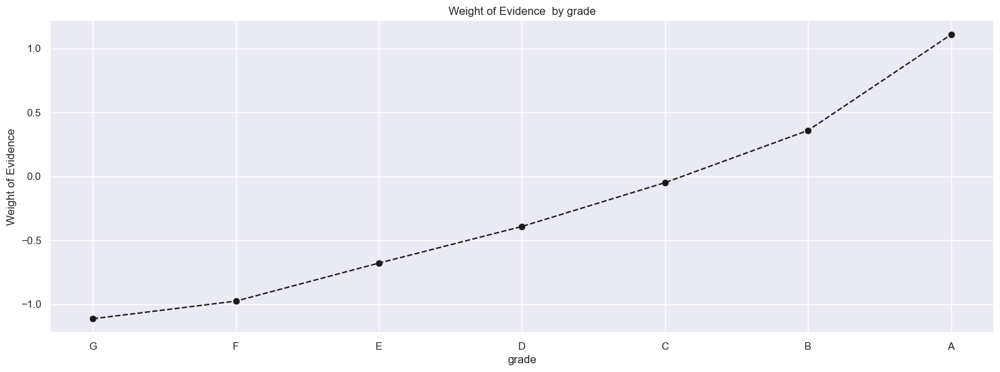

In [71]:
#Now by calling plot_by_woe on any dataframe with results from weight of eveidence calculations , we should get a visualisation 
# of the woe by the categories of the independent variable 


# Recall that df_temp = woe_discrete(df_inputs_prepr, 'grade', df_targets_prepr)

plot_by_woe(df_temp)

In [72]:
# Home Ownership Variable 
df_temp = woe_discrete(df_inputs_prepr, 'home_ownership', df_targets_prepr)
df_temp


,home_ownership,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,average_WoE,IV
0,OTHER,137,0.795620,0.000367,109.0,28.0,0.000328,0.000687,-0.738602,0.000367,NaN,NaN,inf,inf
1,NONE,40,0.850000,0.000107,34.0,6.0,0.000102,0.000147,-0.363144,0.000107,0.054380,0.375458,inf,inf
2,RENT,150599,0.873870,0.403720,131604.0,18995.0,0.396099,0.465815,-0.162123,0.403720,0.023870,0.201021,inf,inf
3,OWN,33295,0.892536,0.089256,29717.0,3578.0,0.089442,0.087743,0.019170,0.089256,0.018666,0.181294,inf,inf
4,MORTGAGE,188956,0.903835,0.506546,170785.0,18171.0,0.514026,0.445608,0.142834,0.506546,0.011298,0.123663,inf,inf
5,ANY,1,1.000000,0.000003,1.0,0.0,0.000003,0.000000,inf,0.000003,0.096165,inf,inf,inf


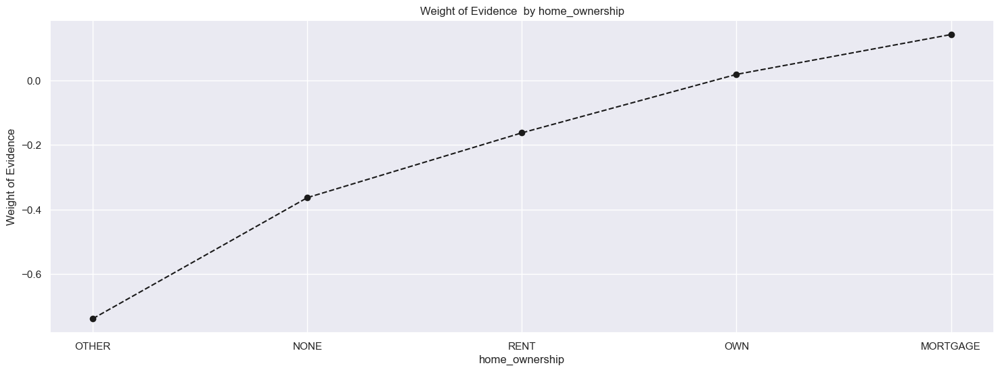

In [73]:
plot_by_woe(df_temp)

In [74]:
df_inputs_prepr = df_inputs_prepr.loc[:, ~df_inputs_prepr.columns.duplicated()]
df_inputs_prepr.columns[df_inputs_prepr.columns.duplicated()]

Index([], dtype='object')

In [75]:
df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] =  sum([df_inputs_prepr['home_ownership:RENT'], 
                                                        df_inputs_prepr['home_ownership:OTHER'], 
                                                        df_inputs_prepr['home_ownership:NONE'], 
                                                        df_inputs_prepr['home_ownership:ANY']])




df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = (
    df_inputs_prepr[['home_ownership:RENT',
                     'home_ownership:OTHER',
                     'home_ownership:NONE',
                     'home_ownership:ANY']].any(axis=1)
)


df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY']  = (
    df_inputs_prepr['home_ownership:RENT']
    + df_inputs_prepr['home_ownership:OTHER']
    + df_inputs_prepr['home_ownership:NONE']
    + df_inputs_prepr['home_ownership:ANY']
)




df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] =  np.sum([df_inputs_prepr['home_ownership:RENT'], 
                                                        df_inputs_prepr['home_ownership:OTHER'], 
                                                        df_inputs_prepr['home_ownership:NONE'], 
                                                        df_inputs_prepr['home_ownership:ANY']] , axis=0)
#Dummy Variable will be equal to one if borrower if of any of the 4 and 0 otherwise '''

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] =  np.sum(df_inputs_prepr[['home_ownership:RENT', 'home_ownership:OTHER', 'home_ownership:NONE',
                     'home_ownership:ANY']] , axis=0)

df_inputs_prepr['home_ownership:::RENT_OTHER_NONE_ANY'] = (
    df_inputs_prepr[['home_ownership:RENT',
                     'home_ownership:OTHER',
                     'home_ownership:NONE',
                     'home_ownership:ANY']].sum(axis=1)
)



In [76]:
df_inputs_prepr['home_ownership:::MORTGAGE'] =  df_inputs_prepr['home_ownership:MORTGAGE']
df_inputs_prepr['home_ownership:::OWN'] =  df_inputs_prepr['home_ownership:OWN']                                                     

In [77]:
def woe_discrete(df, discrete_variable_name, good_bad_variable_df):

    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 
    
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)
    
    '''df = df.groupby(discrete_variable_name).agg(
        n_obs=(good_bad_variable_df.name, 'count'),
        prop_good=(good_bad_variable_df.name, 'mean')
    ).reset_index()'''
    
    df = df.iloc[:, [0,1,3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    df['av_prop_good']=df['prop_good'].mean()
    

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    
    
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()


    df['WoE'] = np.log(df['prop_n_good']/df['prop_n_bad'])
    df = df.sort_values(['WoE'])
    df = df.reset_index(drop = True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum()
    
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE']= df['WoE'].diff().abs()

    '''df['average_WoE']= df['WoE'].fillna(0)
    df['average_WoE']= np.where(df['WoE']> 0.559486, 0 , df['WoE']) 
    df['average_WoE']= df['average_WoE'].sum() / 50'''

     
    
    df['IV'] = (df['prop_n_good'] -df['prop_n_bad'])* df['WoE']
    df['IV'] = df['IV'].sum()   
    return df

df_temp = woe_discrete(df_inputs_prepr, 'addr_state', df_targets_prepr)
df_temp

,addr_state,n_obs,prop_good,av_prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,NE,13,0.461538,0.88834,0.000035,6.0,7.0,0.000018,0.000172,-2.251896,0.000035,NaN,NaN,inf
1,IA,13,0.769231,0.88834,0.000035,10.0,3.0,0.000030,0.000074,-0.893772,0.000035,0.307692,1.358123,inf
2,NV,5221,0.864585,0.88834,0.013996,4514.0,707.0,0.013586,0.017338,-0.243837,0.013996,0.095355,0.649935,inf
3,FL,25211,0.875808,0.88834,0.067585,22080.0,3131.0,0.066456,0.076782,-0.144425,0.067585,0.011223,0.099411,inf
4,HI,2001,0.877061,0.88834,0.005364,1755.0,246.0,0.005282,0.006033,-0.132852,0.005364,0.001253,0.011573,inf
5,AL,4671,0.877328,0.88834,0.012522,4098.0,573.0,0.012334,0.014052,-0.130376,0.012522,0.000267,0.002476,inf
6,NM,2075,0.883373,0.88834,0.005563,1833.0,242.0,0.005517,0.005935,-0.072973,0.005563,0.006045,0.057403,inf
7,VA,11366,0.883864,0.88834,0.030470,10046.0,1320.0,0.030236,0.032370,-0.068202,0.030470,0.000491,0.004771,inf
8,NY,32211,0.883984,0.88834,0.086350,28474.0,3737.0,0.085701,0.091643,-0.067037,0.086350,0.000120,0.001165,inf
9,OK,3284,0.884287,0.88834,0.008804,2904.0,380.0,0.008740,0.009319,-0.064072,0.008804,0.000304,0.002965,inf


In [78]:
# There is a state missing i.e North Dakota, meaning there are no borrowers from there
''' Keeping it in mind, so that we can add this this state to a category later, just in case there are some borrowers in the future.
Lets create a dummmy variable for ND

'''


if 'addr_state:ND' in df_inputs_prepr.columns.values:
    pass
else:
    df_inputs_prepr.loc[:,'addr_state:ND'] = 0


df_temp = woe_discrete(df_inputs_prepr, 'addr_state', df_targets_prepr)
df_temp

,addr_state,n_obs,prop_good,av_prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,NE,13,0.461538,0.88834,0.000035,6.0,7.0,0.000018,0.000172,-2.251896,0.000035,NaN,NaN,inf
1,IA,13,0.769231,0.88834,0.000035,10.0,3.0,0.000030,0.000074,-0.893772,0.000035,0.307692,1.358123,inf
2,NV,5221,0.864585,0.88834,0.013996,4514.0,707.0,0.013586,0.017338,-0.243837,0.013996,0.095355,0.649935,inf
3,FL,25211,0.875808,0.88834,0.067585,22080.0,3131.0,0.066456,0.076782,-0.144425,0.067585,0.011223,0.099411,inf
4,HI,2001,0.877061,0.88834,0.005364,1755.0,246.0,0.005282,0.006033,-0.132852,0.005364,0.001253,0.011573,inf
5,AL,4671,0.877328,0.88834,0.012522,4098.0,573.0,0.012334,0.014052,-0.130376,0.012522,0.000267,0.002476,inf
6,NM,2075,0.883373,0.88834,0.005563,1833.0,242.0,0.005517,0.005935,-0.072973,0.005563,0.006045,0.057403,inf
7,VA,11366,0.883864,0.88834,0.030470,10046.0,1320.0,0.030236,0.032370,-0.068202,0.030470,0.000491,0.004771,inf
8,NY,32211,0.883984,0.88834,0.086350,28474.0,3737.0,0.085701,0.091643,-0.067037,0.086350,0.000120,0.001165,inf
9,OK,3284,0.884287,0.88834,0.008804,2904.0,380.0,0.008740,0.009319,-0.064072,0.008804,0.000304,0.002965,inf


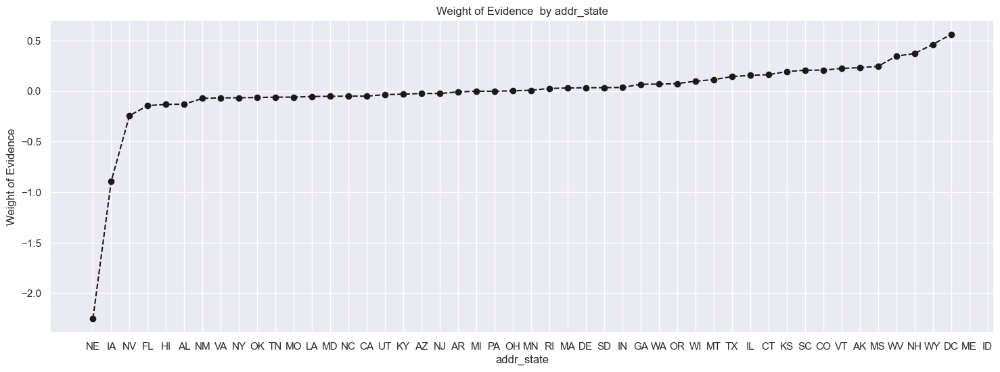

In [79]:
plot_by_woe(df_temp)

In [80]:
def woe_discrete(df, discrete_variable_name, good_bad_variable_df):

    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 
    
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)
    
    '''df = df.groupby(discrete_variable_name).agg(
        n_obs=(good_bad_variable_df.name, 'count'),
        prop_good=(good_bad_variable_df.name, 'mean')
    ).reset_index()'''
    
    df = df.iloc[:, [0,1,3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    df['av_prop_good']=df['prop_good'].mean()
    

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    
    
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()


    df['WoE'] = np.log(df['prop_n_good']/df['prop_n_bad'])
    df = df.sort_values(['WoE'])
    df = df.reset_index(drop = True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum()
    
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE']= df['WoE'].diff().abs()

    '''df['average_WoE']= df['WoE'].fillna(0)
    df['average_WoE']= np.where(df['WoE']> 0.559486, 0 , df['WoE']) 
    df['average_WoE']= df['average_WoE'].sum() / 50'''

     
    
    df['IV'] = (df['prop_n_good'] -df['prop_n_bad'])* df['WoE']
    df['IV'] = df['IV'].sum()   
    
    total_good = df['n_good'].sum()
    total_bad = df['n_bad'].sum()

    df['WOE_SE'] = np.sqrt(
        (1 / df['n_good']) +
        (1 / df['n_bad']) -
        (1 / total_good) -
        (1 / total_bad)
    )

    df['WOE_Lower95'] = df['WoE'] - 1.96 * df['WOE_SE']
    df['WOE_Upper95'] = df['WoE'] + 1.96 * df['WOE_SE']
       
    # NEW: Add confidence intervals
    # Standard error of WoE
    df['SE_WoE'] = np.sqrt(1/df['n_good'] + 1/df['n_bad']) # Suppose a state has n_bad = 0, it implies SE = inf, CI = (-inf,+inf)

    
    # 95% confidence interval
    df['WoE_lower'] = df['WoE'] - 1.96 * df['SE_WoE']
    df['WoE_upper'] = df['WoE'] + 1.96 * df['SE_WoE']
    
    # Check if adjacent categories overlap
    df['WoE_lower_next'] = df['WoE_lower'].shift(-1)
    df['WoE_upper_prev'] = df['WoE_upper'].shift(1)
    
    # Categories overlap if current upper > next lower
    df['CI_overlap'] = df['WoE_upper'] > df['WoE_lower_next']
    return df

'''
| State |   WOE |   SE | 95% CI        |
| ----- | ----: | ---: | ------------- |
| CA    | -0.05 | 0.02 | (-0.09,-0.01) |
| ME    |     ∞ |    ∞ | (meaningless) |
| TX    |  0.14 | 0.03 | (0.08,0.20)   |

Now compare neighboring confidence intervals.

If they overlap substantially, the observed WOE difference may simply be noise.
'''
'''
    A better version is
    eps = 0.5

good = df['n_good'] + eps
bad = df['n_bad'] + eps

df['SE_WoE'] = np.sqrt(
    1/good +
    1/bad
)
This is called the Haldane-Anscombe correction and is standard in credit scoring.

'''

df_temp = woe_discrete(df_inputs_prepr, 'addr_state', df_targets_prepr)
df_temp

,addr_state,n_obs,prop_good,av_prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV,WOE_SE,WOE_Lower95,WOE_Upper95,SE_WoE,WoE_lower,WoE_upper,WoE_lower_next,WoE_upper_prev,CI_overlap
0,NE,13,0.461538,0.88834,0.000035,6.0,7.0,0.000018,0.000172,-2.251896,0.000035,NaN,NaN,inf,0.556324,-3.342290,-1.161501,0.556349,-3.342339,-1.161452,-2.184002,NaN,True
1,IA,13,0.769231,0.88834,0.000035,10.0,3.0,0.000030,0.000074,-0.893772,0.000035,0.307692,1.358123,inf,0.658260,-2.183961,0.396417,0.658281,-2.184002,0.396458,-0.323113,-1.161452,True
2,NV,5221,0.864585,0.88834,0.013996,4514.0,707.0,0.013586,0.017338,-0.243837,0.013996,0.095355,0.649935,inf,0.040105,-0.322443,-0.165230,0.040447,-0.323113,-0.164561,-0.181854,0.396458,True
3,FL,25211,0.875808,0.88834,0.067585,22080.0,3131.0,0.066456,0.076782,-0.144425,0.067585,0.011223,0.099411,inf,0.018361,-0.180414,-0.108437,0.019097,-0.181854,-0.106996,-0.266289,-0.164561,True
4,HI,2001,0.877061,0.88834,0.005364,1755.0,246.0,0.005282,0.006033,-0.132852,0.005364,0.001253,0.011573,inf,0.067877,-0.265892,0.000187,0.068080,-0.266289,0.000584,-0.217794,-0.106996,True
5,AL,4671,0.877328,0.88834,0.012522,4098.0,573.0,0.012334,0.014052,-0.130376,0.012522,0.000267,0.002476,inf,0.044291,-0.217187,-0.043566,0.044601,-0.217794,-0.042959,-0.207026,0.000584,True
6,NM,2075,0.883373,0.88834,0.005563,1833.0,242.0,0.005517,0.005935,-0.072973,0.005563,0.006045,0.057403,inf,0.068193,-0.206631,0.060684,0.068394,-0.207026,0.061079,-0.125584,-0.042959,True
7,VA,11366,0.883864,0.88834,0.030470,10046.0,1320.0,0.030236,0.032370,-0.068202,0.030470,0.000491,0.004771,inf,0.028803,-0.124655,-0.011749,0.029277,-0.125584,-0.010820,-0.101138,0.061079,True
8,NY,32211,0.883984,0.88834,0.086350,28474.0,3737.0,0.085701,0.091643,-0.067037,0.086350,0.000120,0.001165,inf,0.016589,-0.099550,-0.034523,0.017399,-0.101138,-0.032935,-0.170994,-0.010820,True
9,OK,3284,0.884287,0.88834,0.008804,2904.0,380.0,0.008740,0.009319,-0.064072,0.008804,0.000304,0.002965,inf,0.054299,-0.170498,0.042354,0.054552,-0.170994,0.042850,-0.148925,-0.032935,True


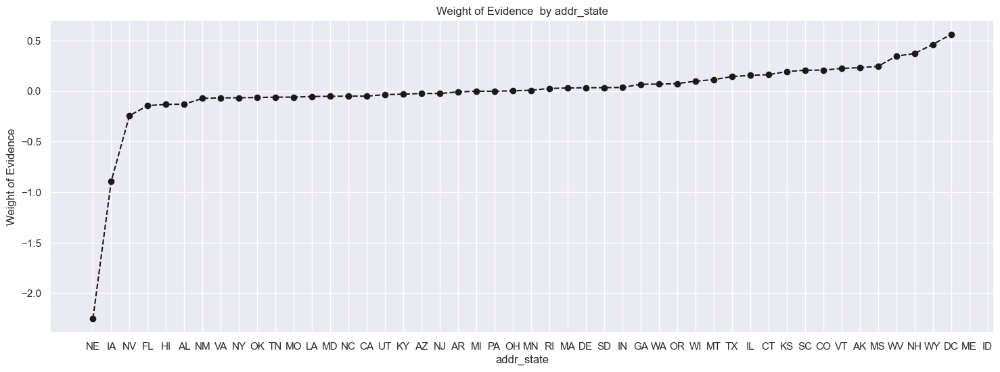

In [81]:
plot_by_woe(df_temp)

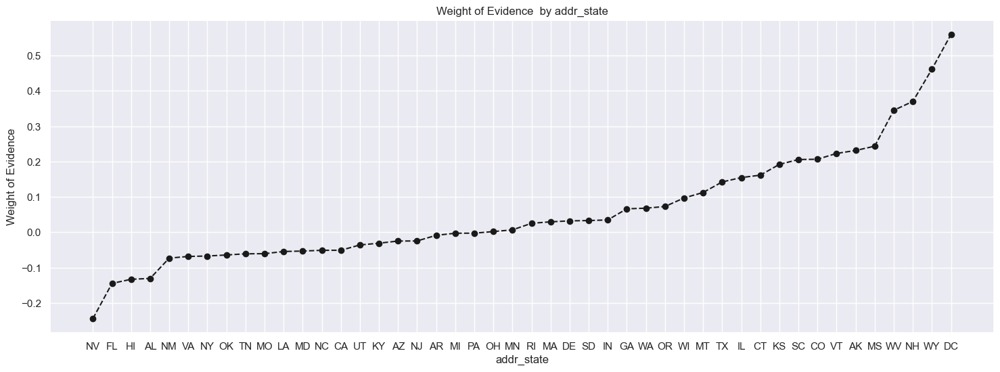

In [82]:

''' woe of last states could not be calculated because there are no bad borrowers, add these 2 , ND , 2 states have considerably higher woe.
the rest of 46 states appear to have similar woe  values. The first 2 and last 2 have very few observations, Low obs prob responsible for extreme woe

So we include these states in the first, the worst and the last, the best categories respectively. '''


#Focus on 46 states

plot_by_woe(df_temp.iloc[2:-2, :])


In [83]:
# Above shows we were misled by first graph because of extreme values we were thinking that all were similar but now we see the aint
''' might make sense to keep NV in own category then next 3 states in another. but from table NV has very few obs of borrowers. But the next 
3 states, FL has enough obs that make it suitable for both keeping it in a separate category or putting it in one category with the other states
Therefore lets combine NV with the 3 states . Also  remember the first 2 states we left out NE and IA  and put them in this first category.

Since the first category includes the states with the highest credit risk borrowers , it makes sense to include a state we have no info about here to. 
Hence **(NE, IA, NV, FL should include ND here too). This reflects our conservative risk management attitude by default as risk managers when we have no 
info we should assume the worst and highest risk. Lets make our first dummy to include first **6 NE, IA, ND, NV, FL, HI,AL**

 The last 4 states displayed on the chart can be grouped together in one category based on their rather low number of observations. 
 Remember to include the other 2 states we didnt display at the end of the scale . **Last category will be WV, NH, WY, DC,ME,ID**
'''

' might make sense to keep NV in own category then next 3 states in another. but from table NV has very few obs of borrowers. But the next \n3 states, FL has enough obs that make it suitable for both keeping it in a separate category or putting it in one category with the other states\nTherefore lets combine NV with the 3 states . Also  remember the first 2 states we left out NE and IA  and put them in this first category.\n\nSince the first category includes the states with the highest credit risk borrowers , it makes sense to include a state we have no info about here to. \nHence **(NE, IA, NV, FL should include ND here too). This reflects our conservative risk management attitude by default as risk managers when we have no \ninfo we should assume the worst and highest risk. Lets make our first dummy to include first **6 NE, IA, ND, NV, FL, HI,AL**\n\n The last 4 states displayed on the chart can be grouped together in one category based on their rather low number of observations. \n

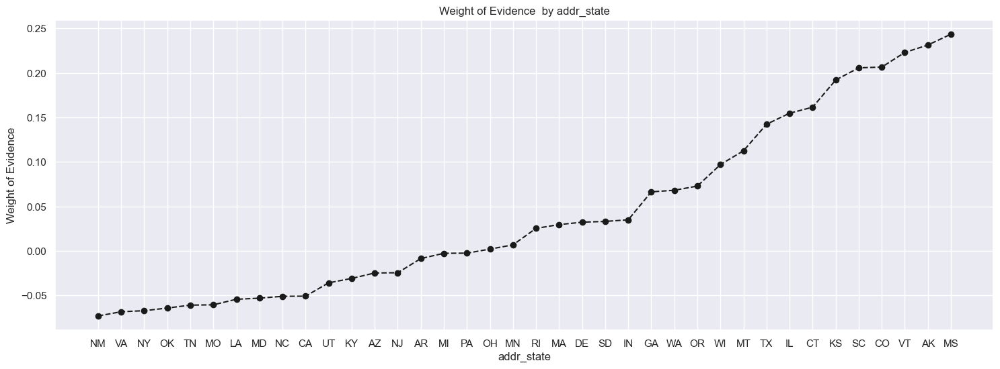

In [84]:
#lets look at remaining  38 states

plot_by_woe(df_temp.iloc[6:-6, :])

''' **Creating Category for states with lowest weight of evidence** 
NM to CA have similar WoE, but we also need to take into account the number of observations

1. NY and CA have particularly many  borrowers in this group. Worse with California, so CA definitely has to be in a different Dummy Variable by itself
   
2. Same to NY, that means the rest of the states can either all be in one group or several depending on the increase in WOE

3. So lets define them as follows: **3 categories (NM, VA), (OK, TN, MO, LA, MD, NC) And (CA)**

IT would not be right to combine NM, VA,  with OK,TN, etc because nearly 10% of observations are from NY. NY kinda breaks the link btn VA n OK

4. States from **(UT to NJ)** have similar woe.Check no. of borrowers, none stands out with a particularly high number more than twice >3 times the neighbour

5. ***AR to MN***

6. **RI to IN**

7. GA to OR
8. WI AND MT are a bit apart in terms of woe  but have a rather low number of obs so we can put them in one group
9. TX to CT have similar woe but TX has a relatively high number of obs 3rd highest. Hence leave TX alone

10. IL and CT

11. KS to mS have considerably higher than CT. At same time no. of obs per state for all these states is low. makes woe less reliable, even though

    it isindicative that borrows from these states are better than from other states. So we group them into our final dummy variable


    Now lets create actual dummy variables and leave one assigned as a reference variable (lowest woe) i regression model.ie: Iowa, ND, HI,ID,AL and FL.






In [85]:
df_temp = woe_discrete(df_inputs_prepr, 'addr_state', df_targets_prepr)
df_temp.iloc[6:-6, :]

,addr_state,n_obs,prop_good,av_prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV,WOE_SE,WOE_Lower95,WOE_Upper95,SE_WoE,WoE_lower,WoE_upper,WoE_lower_next,WoE_upper_prev,CI_overlap
6,NM,2075,0.883373,0.88834,0.005563,1833.0,242.0,0.005517,0.005935,-0.072973,0.005563,0.006045,0.057403,inf,0.068193,-0.206631,0.060684,0.068394,-0.207026,0.061079,-0.125584,-0.042959,True
7,VA,11366,0.883864,0.88834,0.030470,10046.0,1320.0,0.030236,0.032370,-0.068202,0.030470,0.000491,0.004771,inf,0.028803,-0.124655,-0.011749,0.029277,-0.125584,-0.010820,-0.101138,0.061079,True
8,NY,32211,0.883984,0.88834,0.086350,28474.0,3737.0,0.085701,0.091643,-0.067037,0.086350,0.000120,0.001165,inf,0.016589,-0.099550,-0.034523,0.017399,-0.101138,-0.032935,-0.170994,-0.010820,True
9,OK,3284,0.884287,0.88834,0.008804,2904.0,380.0,0.008740,0.009319,-0.064072,0.008804,0.000304,0.002965,inf,0.054299,-0.170498,0.042354,0.054552,-0.170994,0.042850,-0.148925,-0.032935,True
10,TN,4845,0.884623,0.88834,0.012988,4286.0,559.0,0.012900,0.013708,-0.060785,0.012988,0.000336,0.003287,inf,0.044662,-0.148323,0.026752,0.044969,-0.148925,0.027354,-0.139527,0.042850,True
11,MO,6017,0.884660,0.88834,0.016130,5323.0,694.0,0.016021,0.017019,-0.060425,0.016130,0.000037,0.000361,inf,0.040016,-0.138855,0.018006,0.040358,-0.139527,0.018678,-0.147349,0.027354,True
12,LA,4359,0.885295,0.88834,0.011685,3859.0,500.0,0.011615,0.012262,-0.054190,0.011685,0.000635,0.006235,inf,0.047240,-0.146780,0.038400,0.047530,-0.147349,0.038970,-0.118682,0.018678,True
13,MD,8771,0.885418,0.88834,0.023513,7766.0,1005.0,0.023374,0.024646,-0.052977,0.023513,0.000123,0.001212,inf,0.033110,-0.117872,0.011918,0.033523,-0.118682,0.012728,-0.111821,0.038970,True
14,NC,10204,0.885633,0.88834,0.027355,9037.0,1167.0,0.027199,0.028618,-0.050854,0.027355,0.000215,0.002123,inf,0.030660,-0.110947,0.009239,0.031106,-0.111821,0.010113,-0.076489,0.012728,True
15,CA,57199,0.885645,0.88834,0.153337,50658.0,6541.0,0.152470,0.160405,-0.050738,0.153337,0.000012,0.000116,inf,0.012045,-0.074347,-0.027129,0.013139,-0.076489,-0.024986,-0.153736,0.010113,True


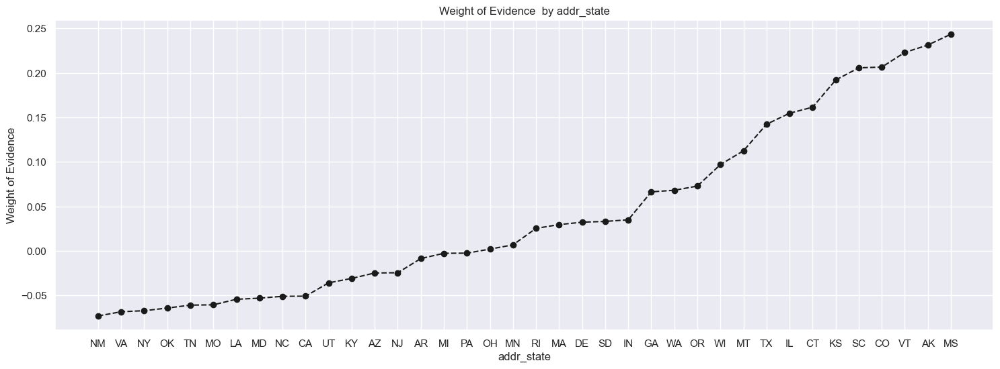

In [86]:

plot_by_woe(df_temp.iloc[6:-6, :])

We already have dummy variables for all states . So for Categories with one state we can use these dummy variables and 
dont have to create new ones 

for categories for 2 or more states, we use approach similar to the one we used for homeownership ie. sum the dummy variables for every state that is 
part of a bigger state and this will result in a dummy variable for the whole category



In [87]:
df_inputs_prepr['addr_state:::NM_VA'] = sum([df_inputs_prepr['addr_state:NM'], df_inputs_prepr['addr_state:VA']])

df_inputs_prepr['addr_state:::ND_NE_IA_NV_FL_HI_AL'] = sum([pd.to_numeric(df_inputs_prepr['addr_state:ND']), 
                pd.to_numeric(df_inputs_prepr['addr_state:NE']), pd.to_numeric(df_inputs_prepr['addr_state:IA']), 
                pd.to_numeric(df_inputs_prepr['addr_state:NV']), pd.to_numeric(df_inputs_prepr['addr_state:FL']), 
                pd.to_numeric(df_inputs_prepr['addr_state:HI']), pd.to_numeric(df_inputs_prepr['addr_state:AL'])])              

In [88]:
states = ['OK','TN','MO','LA','MD','NC']
cols = [f"addr_state:{s}" for s in states]

# Ensure all are numeric
df_inputs_prepr[cols] = df_inputs_prepr[cols].apply(pd.to_numeric, errors='coerce')

# Create grouped dummy
df_inputs_prepr['addr_state:::OK_TN_MO_LA_MD_NC'] = df_inputs_prepr[cols].sum(axis=1)


# ============================================================================================================
cols = ['addr_state:GA', 'addr_state:WA', 'addr_state:OR']

df_inputs_prepr['addr_state:::GA_WA_OR'] = sum(
    [df_inputs_prepr[c].astype(float) for c in cols]
)

In [89]:

df_inputs_prepr['addr_state:::UT_KY_AZ_NJ'] = (
    df_inputs_prepr[['addr_state:UT', 'addr_state:KY', 'addr_state:AZ', 'addr_state:NJ']]
    .sum(axis=1)      # row-wise sum
)


df_inputs_prepr['addr_state:::WI_MT'] = (
    df_inputs_prepr[['addr_state:WI', 'addr_state:MT']].astype(float).sum(axis=1)
)



In [90]:
df_inputs_prepr['addr_state:::AR_MI_PA_OH_MN'] = (
    df_inputs_prepr['addr_state:AR'] +  df_inputs_prepr['addr_state:MI'] +  df_inputs_prepr['addr_state:PA'] + df_inputs_prepr['addr_state:OH']
    +  df_inputs_prepr['addr_state:MN']    
   
)


df_inputs_prepr['addr_state:::RI_MA_DE_SD_IN'] = (
    df_inputs_prepr['addr_state:RI'].astype(float)
    .add(df_inputs_prepr['addr_state:MA'].astype(float))
    .add(df_inputs_prepr['addr_state:DE'].astype(float))
    .add(df_inputs_prepr['addr_state:SD'].astype(float))
    .add(df_inputs_prepr['addr_state:IN'].astype(float))
)



In [91]:
df_inputs_prepr['addr_state:::IL_CT'] = (
    df_inputs_prepr[['addr_state:IL',
                     'addr_state:CT'
                     ]].sum(axis=1)
)



df_inputs_prepr['addr_state:::KS_SC_CO_VT_AK_MS'] = (
    df_inputs_prepr['addr_state:KS']
    + df_inputs_prepr['addr_state:SC']
    + df_inputs_prepr['addr_state:CO']          
    + df_inputs_prepr['addr_state:VT']
    + df_inputs_prepr['addr_state:AK']
    + df_inputs_prepr['addr_state:MS']
)



df_inputs_prepr['addr_state:::WV_NH_WY_DC_ME_ID'] = (
    df_inputs_prepr[['addr_state:WV', 'addr_state:NH', 
                           'addr_state:WY', 'addr_state:DC',
                           'addr_state:ME', 'addr_state:ID']].sum(axis=1)
)



# ***PREPROCESSING CONTINUOUS VARIABLES:***

**Automating Calculations and Visualising Results**



* Discrete Variables dont show differences in terms of quantity; Exact order or discrete variables doesnt matter thats why we even ordered them by woe just to make it easier to group them
* They are just qualitatively different, e.g. purpose of one loan might be to finance education and another may be to buy a car , so cant be directly comparable
* **Continous have quantitative differnces, one values shows there is more of something than the other catgories of higher vs lower income 

In [92]:
def woe_ordered_continuous(df, discrete_variable_name, good_bad_variable_df):

# Assume a function takes a continuous variable, containing the categories of a continuous variable, obtained via fine classing
    df = pd.concat([df[discrete_variable_name], good_bad_variable_df], axis = 1) 
    
    df = pd.concat([
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
    df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)
    ], axis=1)

    df = df.iloc[:, [0,1,3]]
    df.columns = [df.columns.values[0], 'n_obs', 'prop_good']

    df['prop_n_obs'] = df['n_obs'] / df['n_obs'].sum()
    
    df['n_good'] = df['prop_good'] * df['n_obs']
    df['n_bad'] = (1 - df['prop_good']) * df['n_obs']
    
    df['prop_n_good'] = df['n_good'] / df['n_good'].sum()
    df['prop_n_bad'] = df['n_bad'] / df['n_bad'].sum()

    df['WoE'] = np.log(df['prop_n_good']/df['prop_n_bad'])
    
    # ======================= Differences start here, we dont want categories ordered by woe but to preserve natural order complient with ascending 
    # values of continuous variable =====================================
    
    # df = df.sort_values(['WoE'])
    # df = df.reset_index(drop = True)

    df['n_obs%'] = df['n_obs'] / df['n_obs'].sum()
    df['diff_prop_good'] = df['prop_good'].diff().abs()
    df['diff_WoE']= df['WoE'].diff().abs()

    df['IV'] = (df['prop_n_good'] -df['prop_n_bad'])* df['WoE']
    df['IV'] = df['IV'].sum()   
    return df

In [93]:


'''
What the Shape of this Specific Curve Tells You:S-Curve / Concave Shape: If your curve stays flat early on and then sharply rises, your "Goods" are 
heavily backloaded in the higher numerical ranges of your continuous feature.Rapid Initial Bow: If it shoots up aggressively in the first few bins, 
your lower numerical bins possess the highest concentrations of "Goods" (maximizing your KL divergence/IV matrix early on).
'''


def plot_natural_cumulative_gains(df_result, discrete_variable_name):
    """Takes the output dataframe of your woe_ordered_continuous function

    and plots its natural cumulative gains curve.
    """
    # 1. Ensure data is ordered by the natural continuous bins
    df_plot = df_result.sort_values(by=discrete_variable_name).copy()

    # 2. Add an explicit (0,0) starting point baseline row for proper plotting
    start_row = pd.DataFrame(
        {
            discrete_variable_name: ["Start"],
            "prop_n_obs": [0.0],
            "prop_n_good": [0.0],
        }
    )
    df_plot = pd.concat([start_row, df_plot], ignore_index=True)

    # 3. Calculate Cumulative Proportions
    df_plot["cum_pop%"] = df_plot["prop_n_obs"].cumsum()
    df_plot["cum_good%"] = df_plot["prop_n_good"].cumsum()

    # 4. Generate the Visualization
    plt.figure(figsize=(10, 6.5))

    # Plot the Model's Natural Gains Line
    plt.plot(
        df_plot["cum_pop%"],
        df_plot["cum_good%"],
        marker="o",
        linewidth=2.5,
        color="#1f77b4",
        label="Natural Ordered Cumulative Gains",
    )

    # Plot the Random Baseline
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Baseline")

    # Formatting and Styling
    plt.title(
        f"Cumulative Gains Curve (Natural Bins: {discrete_variable_name})",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel(
        "Cumulative Proportion of Total Population (Ordered Bins)", fontsize=11
    )
    plt.ylabel("Cumulative Proportion of Captured 'Good' Target", fontsize=11)
    plt.xlim(-0.02, 1.05)
    plt.ylim(-0.02, 1.05)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="lower right", frameon=True)

    # Annotate points with the physical bin boundaries
    for i in range(1, len(df_plot)):
        bin_label = str(df_plot[discrete_variable_name].iloc[i])
        plt.annotate(
            bin_label,
            (df_plot["cum_pop%"].iloc[i], df_plot["cum_good%"].iloc[i]),
            textcoords="offset points",
            xytext=(10, -5),
            ha="left",
            fontsize=8,
            color="#333333",
            bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.3),
        )

    plt.show()


# --- To execute, pass your final function output directly: ---
# df_output = woe_ordered_continuous(df, 'age_groups', target_df)
# plot_natural_cumulative_gains(df_output, 'age_groups')


In [94]:
# Here is the Python code to calculate the cumulative metrics and plot the curve using matplotlib:


def plot_cumulative_gains_from_woe(df, discrete_variable_name):
    # 1. Sort by the continuous variable bins to ensure natural order
    df_plot = df.sort_values(by=discrete_variable_name).copy()

    # 2. Calculate cumulative percentages
    # X-axis: Cumulative % of total population (n_obs)
    df_plot["cum_prop_n_obs"] = df_plot["prop_n_obs"].cumsum()

    # Y-axis: Cumulative % of total Goods captured
    df_plot["cum_prop_n_good"] = df_plot["prop_n_good"].cumsum()

    # 3. Create the plot
    plt.figure(figsize=(9, 6))

    # Plot the Cumulative Gains line
    plt.plot(
        df_plot["cum_prop_n_obs"],
        df_plot["cum_prop_n_good"],
        marker="o",
        linewidth=2,
        color="darkblue",
        label="Cumulative Gains (Goods)",
    )

    # Plot the Baseline (Random Selection Line)
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Baseline")

    # Formatting
    plt.title(
        f"Cumulative Gains Curve via Natural Order: {discrete_variable_name}",
        fontsize=14,
    )
    plt.xlabel("Cumulative Proportion of Population (Binned)", fontsize=12)
    plt.ylabel("Cumulative Proportion of Good Total", fontsize=12)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="lower right")

    # Annotate points with the bin names for clear context
    for i, txt in enumerate(df_plot[discrete_variable_name]):
        plt.annotate(
            str(txt),
            (df_plot["cum_prop_n_obs"].iloc[i], df_plot["cum_prop_n_good"].iloc[i]),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontsize=8,
        )

    plt.xlim(0, 1.05)
    plt.ylim(0, 1.05)
    plt.show()


# Example Usage (assuming 'df_result' is the dataframe returned by your function):
# plot_cumulative_gains_from_woe(df_result, 'age_binned')


# **Data Preperation: Preprocessing Continuous Variables: Creating Dummy Variables , Part 1**

In [95]:
loan_data['term'].head()

0     36 months
1     60 months
2     36 months
3     36 months
4     60 months
Name: term, dtype: object

In [96]:
# Term of the loan in months


df_inputs_prepr['term_int'] = (df_inputs_prepr['term'].str.replace(r'\+ months', '',regex=True).str.replace('< 1 month', str(0))
                                  .str.replace('n/a', str(0))
                                  .str.replace(r"months?|[+]", "", regex=True)
                                    .fillna(0).replace(np.nan, 0)
                                                                           
                                 )

df_inputs_prepr['term_int'].unique() # Term of the loan in months


array([' 36 ', ' 60 '], dtype=object)

In [97]:
df_temp  = woe_ordered_continuous(df_inputs_prepr, 'term_int', df_targets_prepr)

df_temp


,term_int,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,36,270419,0.902995,0.724929,244187.0,26232.0,0.73495,0.643288,0.133209,0.724929,NaN,NaN,0.039434
1,60,102609,0.858239,0.275071,88063.0,14546.0,0.26505,0.356712,-0.297009,0.275071,0.044756,0.430218,0.039434


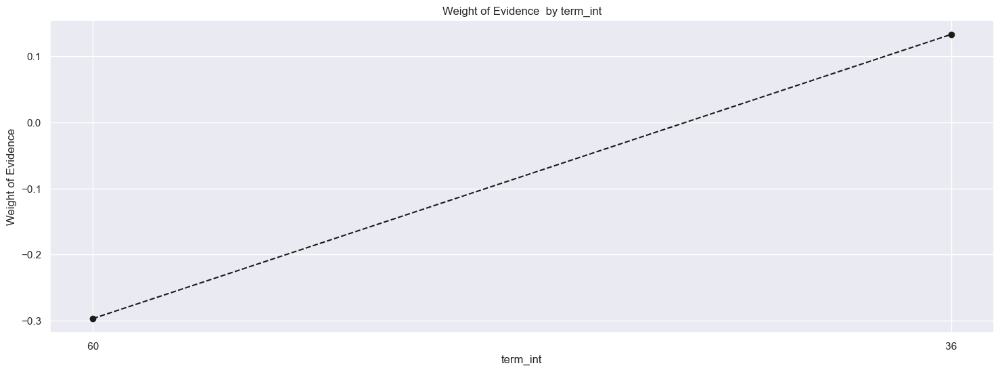

In [98]:
df_temp = df_temp.sort_values(by='term_int', ascending=False)
plot_by_woe(df_temp)

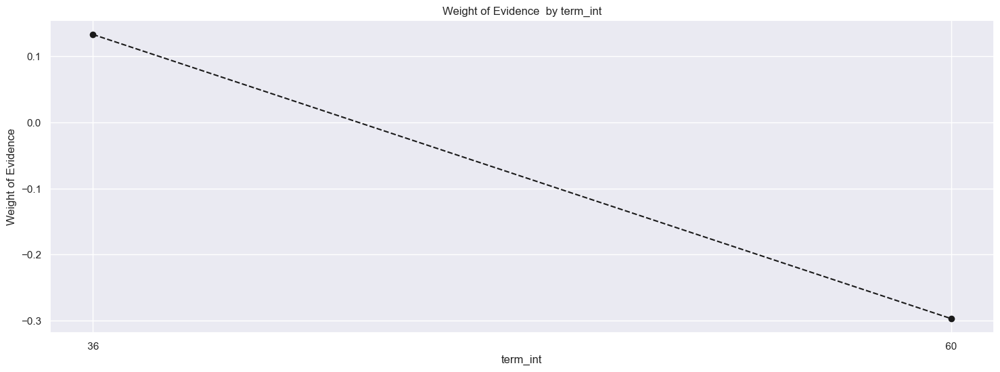

In [99]:
df_temp = df_temp.sort_values(by='term_int', ascending=True)
plot_by_woe(df_temp)

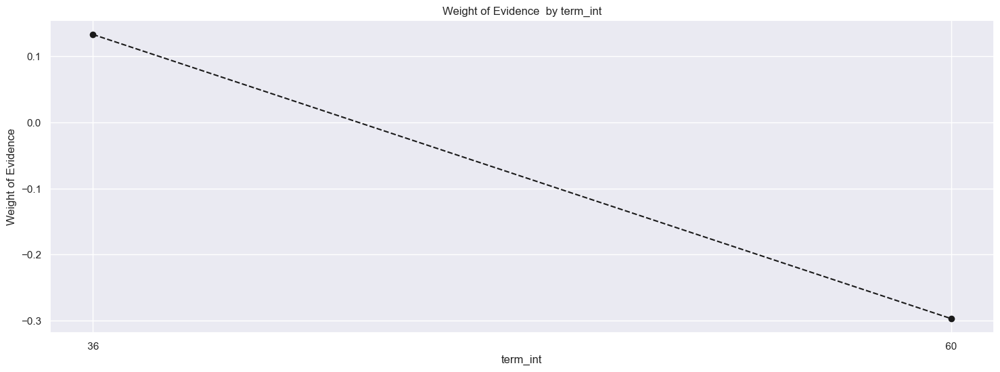

In [100]:

df_temp = df_temp.iloc[::-1]

'''Plotting in Opposite Direction
To reverse the plot direction:'''

plot_by_woe(df_temp.iloc[::-1])

In [101]:
df_inputs_prepr['term:::36'] = np.where(df_inputs_prepr['term_int'] == 36, 1, 0) 
df_inputs_prepr['term:::60'] = np.where((df_inputs_prepr['term_int'] == 60), 1, 0) 
#this continuous variable was easy, no need to carry out fine classing or coarse

# or simply 
df_inputs_prepr['term:::36'] = (df_inputs_prepr['term'] == 36).astype('uint8')
df_inputs_prepr['term:::60'] = (df_inputs_prepr['term'] == 60).astype('uint8')


In [102]:
len(df_inputs_prepr['emp_length_int'].unique()) #11 levels integers from 0 to 10 so no need to do fine classing

11

In [103]:
df_inputs_prepr['emp_length_int'].unique()

array([ 3.,  6., 10.,  7.,  5.,  0.,  2.,  9.,  1.,  8.,  4.])

In [104]:
df_temp = woe_ordered_continuous(df_inputs_prepr,'emp_length_int', df_targets_prepr)
df_temp 

,emp_length_int,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,0.0,45720,0.876400,0.122565,40069.0,5651.0,0.120599,0.138580,-0.138975,0.122565,NaN,NaN,0.006506
1,1.0,23654,0.886996,0.063411,20981.0,2673.0,0.063148,0.065550,-0.037329,0.063411,0.010596,0.101645,0.006506
2,2.0,33078,0.890955,0.088674,29471.0,3607.0,0.088701,0.088455,0.002785,0.088674,0.003959,0.040114,0.006506
3,3.0,29205,0.890772,0.078292,26015.0,3190.0,0.078299,0.078228,0.000907,0.078292,0.000183,0.001878,0.006506
4,4.0,22468,0.890644,0.060231,20011.0,2457.0,0.060229,0.060253,-0.000404,0.060231,0.000128,0.001311,0.006506
5,5.0,24602,0.884725,0.065952,21766.0,2836.0,0.065511,0.069547,-0.059790,0.065952,0.005920,0.059387,0.006506
6,6.0,20887,0.883899,0.055993,18462.0,2425.0,0.055567,0.059468,-0.067862,0.055993,0.000826,0.008071,0.006506
7,7.0,21049,0.887453,0.056427,18680.0,2369.0,0.056223,0.058095,-0.032759,0.056427,0.003554,0.035102,0.006506
8,8.0,17853,0.889878,0.047860,15887.0,1966.0,0.047816,0.048212,-0.008245,0.047860,0.002425,0.024515,0.006506
9,9.0,14267,0.886662,0.038246,12650.0,1617.0,0.038074,0.039654,-0.040660,0.038246,0.003217,0.032416,0.006506


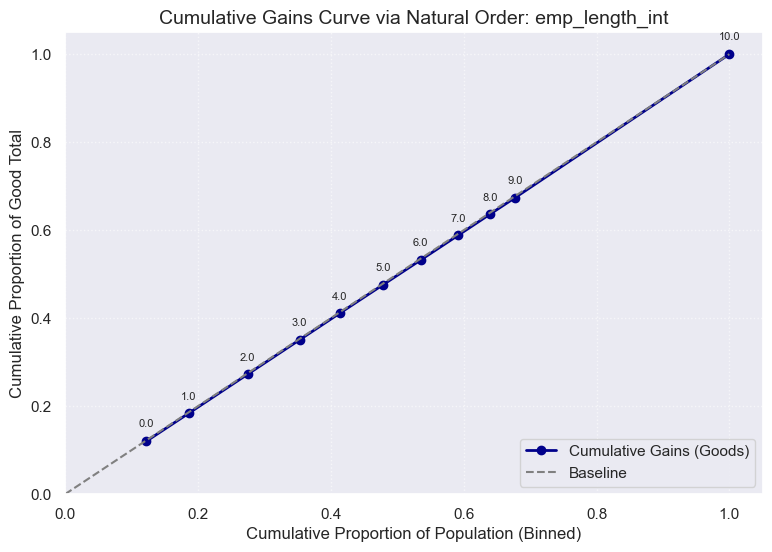

(None, None)

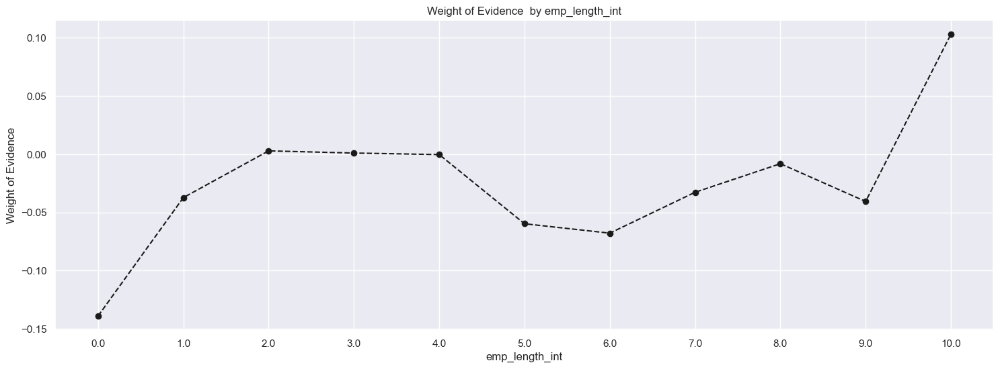

In [105]:
plot_cumulative_gains_from_woe(df_temp, 'emp_length_int'), plot_by_woe(df_temp)

#Many ways to bundle them up but lets use this 
1. Borrowers with zero employment length
2.  1 year
3.  2 to 4
4.  5 and 6
5.  7 
6.  8
7.  9
8.  >=10

# because 7 and 9 have similar we could have made 7 to 9 category to reduce number of dummies, since these are continuous variables and order matters
Borrowers with 0 are the riskiest so 0 will be our reference point


In [106]:
# Above are 2 categories/dummy variables for the term in the final model.  60 will be the reference point. 60 loans are riskier than 36 month loan
#Time to name our dummy variables similar to how we named our discrete using the convention, **Original variable Name Colon Category Name**

# df_inputs_prepr['emp_zero'] = df_inputs_prepr['emp_length'].isin([0]).astype('uint8') 

loan_data['emp_length_missing'] = loan_data['emp_length'].isna().astype(int)
# df_inputs_prepr['emp_length:::Missing'] = df_inputs_prepr['emp_length_missing']


'''
Missing flag dummy — you already created emp_length_missing on loan_data. You need to carry it into df_inputs_prepr:
Reference category to drop later: emp_length:::0 (shortest tenure, highest risk baseline).'''


df_inputs_prepr['emp_length:::Missing'] = df_inputs_prepr['emp_length_missing']
df_inputs_prepr['emp_length:::Missing'] = loan_data['emp_length_missing']


In [107]:
# df_inputs_prepr['emp_length:0'] = np.where(df_inputs_prepr['emp_length'] ==0, 1, 0) 
df_inputs_prepr['emp_length:::0'] = np.where(df_inputs_prepr['emp_length'].isin([0]), 1, 0)
df_inputs_prepr['emp_length:::1'] = np.where(df_inputs_prepr['emp_length'].isin([1]), 1, 0)
df_inputs_prepr['emp_length:::2-4'] = np.where(df_inputs_prepr['emp_length'].isin(range(2,5)), 1, 0) # this is similar to coarse classing
df_inputs_prepr['emp_length:::5-6'] = np.where(df_inputs_prepr['emp_length'].isin(range(5,7)), 1, 0)
df_inputs_prepr['emp_length:::7-9'] = np.where(df_inputs_prepr['emp_length'].isin(range(7,10)), 1, 0)
df_inputs_prepr['emp_length:::10'] = np.where(df_inputs_prepr['emp_length'].isin([10]), 1, 0)


34 **Data Preparation. Preprocessing continuous: Creating Dummy Variables, part 2**
                        

In [108]:
print(f'(1) Fine classing: roughly grouping the values into categories \
2) coarse classing; determining final categories, combining few of the initial classing cats into bigger classes if needed)')

(1) Fine classing: roughly grouping the values into categories 2) coarse classing; determining final categories, 
combining few of the initial classing cats into bigger classes if needed)

In [109]:

print(df_inputs_prepr['mths_since_issue_d'].nunique()); 

print(f'\nthere are 90 distinct values, which arent so many, so we can treat them as categories and visualise in a 100 or fewer cats\
Better to work with with 50 or less fine classes when doing coarse classing , its neater \n')

df_inputs_prepr['mths_since_issue_d'].unique()



91

there are 90 distinct values, which arent so many, so we can treat them as categories and visualise in a 100 or 
fewer catsBetter to work with with 50 or less fine classes when doing coarse classing , its neater

array([ 44,  63,  53,  43, 100,  36,  90,  52,  41,  56,  57,  42,  39,
        50,  58, 112,  49,  61,  48,  46,  47,  40,  37,  65,  68,  86,
        45,  75,  62,  38,  60,  88,  64,  55,  78,  67,  51,  59,  72,
        73,  69,  87,  80,  81,  54, 102,  82,  71,  84,  35,  70,  91,
        76,  66,  83,  85,  89, 115,  92,  94,  77,  74,  79,  95,  93,
        97, 103, 124, 104, 117, 109, 118, 113,  96, 101, 105,  99, 121,
       120, 107, 116, 119, 123,  98, 114, 111, 108, 122, 106, 125, 110],
      dtype=int32)

In [110]:
#FACTOR IS COMMON TERM TO MEAN VARIABLE IS CATEGORICAL

f'This here is fine classing'

df_inputs_prepr['mths_since_issue_d_factor'] = pd.cut(df_inputs_prepr['mths_since_issue_d'], bins = 50)


df_inputs_prepr['mths_since_issue_d_factor'] = pd.cut(df_inputs_prepr['mths_since_issue_d'], 50)


In [111]:
df_temp  = woe_ordered_continuous(df_inputs_prepr, 'mths_since_issue_d_factor', df_targets_prepr) 
# first column of fine classes of mths_since_issue_d_factor
df_temp.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,mths_since_issue_d_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(34.91, 36.8]",28170,0.942244,0.075517,26543.0,1627.0,0.079889,0.039899,0.694283,0.075517,NaN,NaN,0.113186
1,"(36.8, 38.6]",39636,0.928424,0.106255,36799.0,2837.0,0.110757,0.069572,0.464979,0.106255,0.013820,0.229305,0.113186
2,"(38.6, 40.4]",38614,0.917284,0.103515,35420.0,3194.0,0.106606,0.078327,0.308258,0.103515,0.011140,0.156721,0.113186
3,"(40.4, 42.2]",29038,0.908603,0.077844,26384.0,2654.0,0.079410,0.065084,0.198945,0.077844,0.008681,0.109313,0.113186
4,"(42.2, 44.0]",28367,0.901787,0.076045,25581.0,2786.0,0.076993,0.068321,0.119498,0.076045,0.006815,0.079447,0.113186


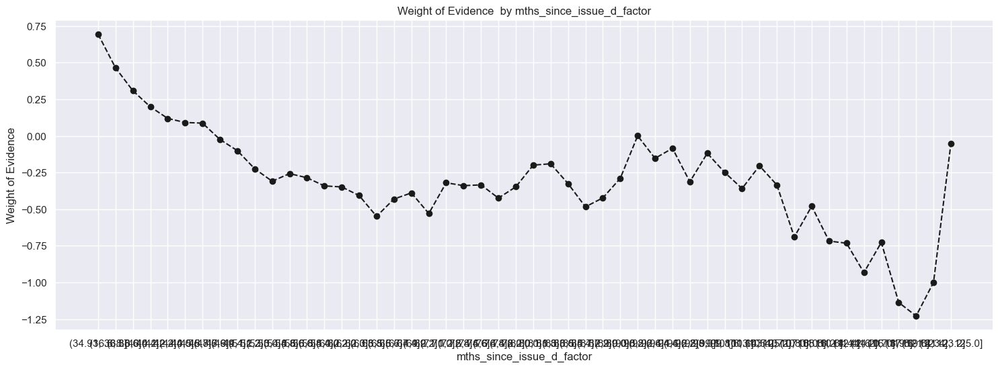

In [112]:
plot_by_woe(df_temp)

(None,)

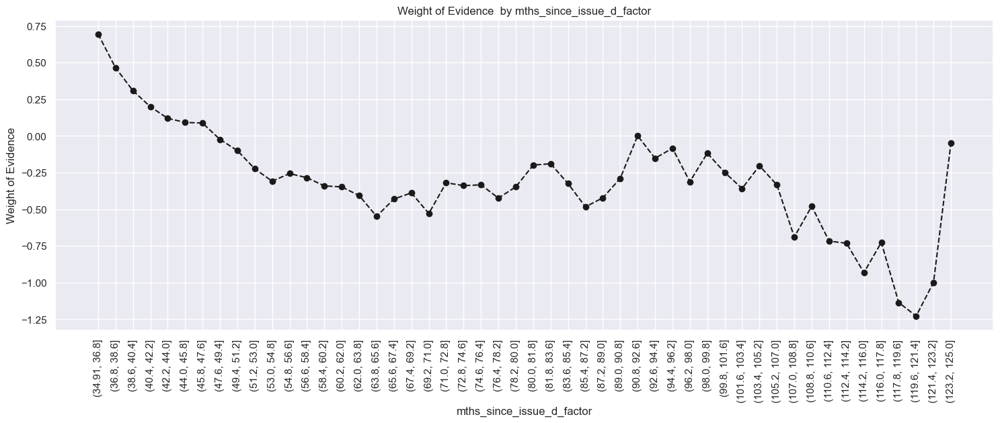

In [113]:
plot_by_woe(df_temp, rotation_of_x_axis_labels=90), 

In [114]:
# Above categories months since issue date give us these 3 categories  <38, 38 to 39, 40 to 41 

# ***Months since issue date takes on integer values only, that means we can specify our dummy variables using only integer numbers***

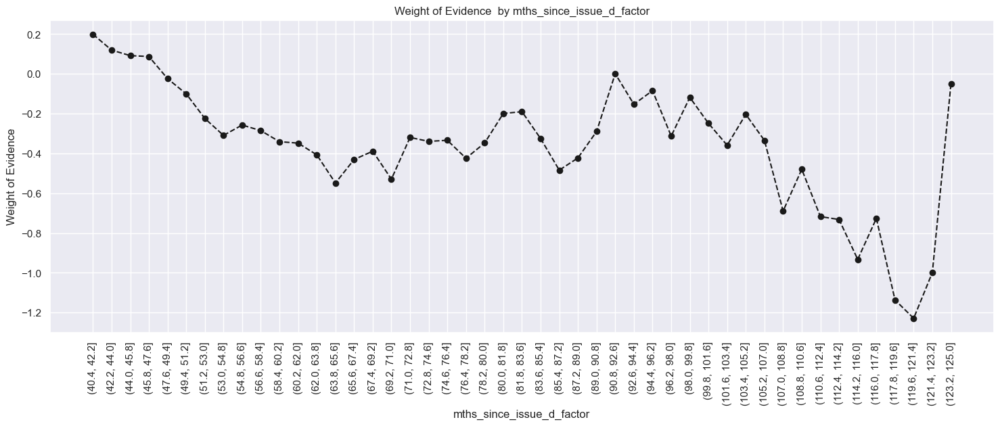

In [115]:
plot_by_woe(df_temp.iloc[3:,:], 90)

In [116]:
df_inputs_prepr['mths_since_issue_d:::<38'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin(range(37)), 1,0)
df_inputs_prepr['mths_since_issue_d:::38-39'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([38,39]), 1,0)
df_inputs_prepr['mths_since_issue_d:::40-41'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([40,41]), 1,0)
df_inputs_prepr['mths_since_issue_d:::42-48'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin(range(42,48)), 1,0)

# df_inputs_prepr['mths_since_issue_d:::49-52'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([49,52]), 1,0)
df_inputs_prepr['mths_since_issue_d:::49-52'] = np.where(
    (df_inputs_prepr['mths_since_issue_d'] >= 49) & 
    (df_inputs_prepr['mths_since_issue_d'] <= 52), 1, 0)

#df_inputs_prepr['mths_since_issue_d:::53-63'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([53,63]), 1,0)
df_inputs_prepr['mths_since_issue_d:::53-63'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin(range(53,64)), 1,0)

#df_inputs_prepr['mths_since_issue_d:::64-85'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin([64,85]), 1,0)
df_inputs_prepr['mths_since_issue_d:::64-85'] = np.where(df_inputs_prepr['mths_since_issue_d'].isin(range(64,86)), 1,0)


df_inputs_prepr['mths_since_issue_d:::>85'] = np.where(df_inputs_prepr['mths_since_issue_d']>85, 1,0)

**Interest rates , unlike months since issue date that takes on integer values, interest rates takes on fractional values .
When determing the limits of the categories for dummy variables, keep this in mind**

***below we are going to fine class the interest rate variable***

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


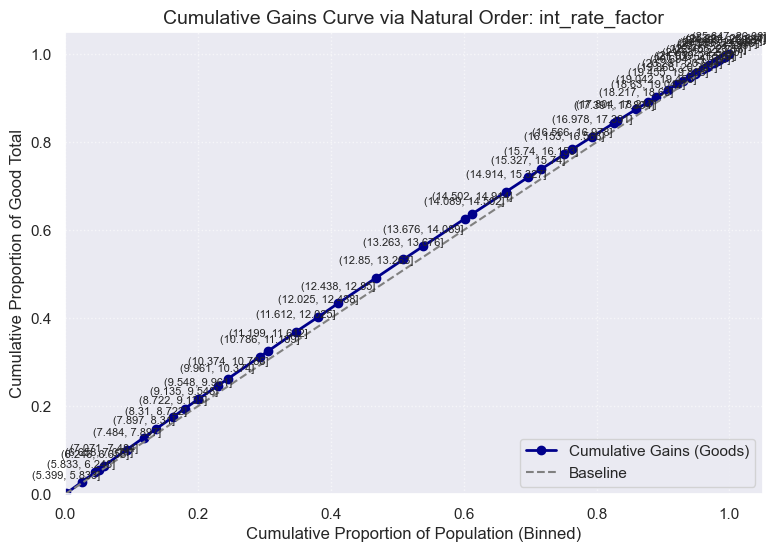

(None, None)

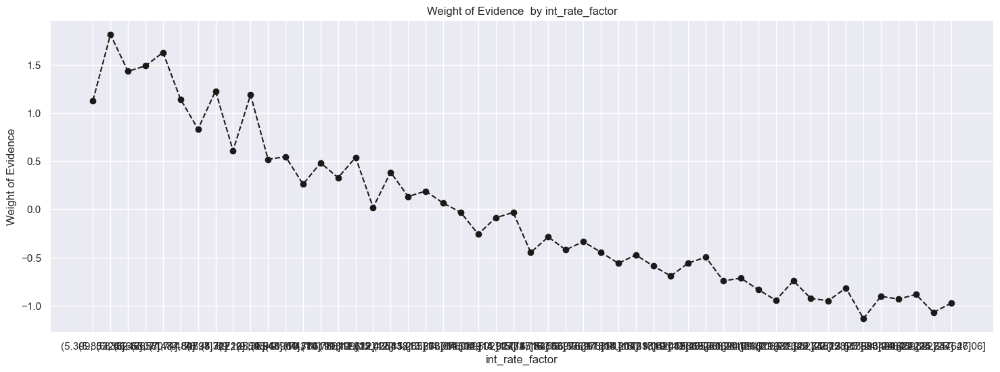

In [117]:
df_inputs_prepr['int_rate_factor'] = pd.cut(df_inputs_prepr['int_rate'], 50)
df_temp = woe_ordered_continuous(df_inputs_prepr, 'int_rate_factor', df_targets_prepr)

plot_cumulative_gains_from_woe(df_temp, 'int_rate_factor'), plot_by_woe(df_temp)

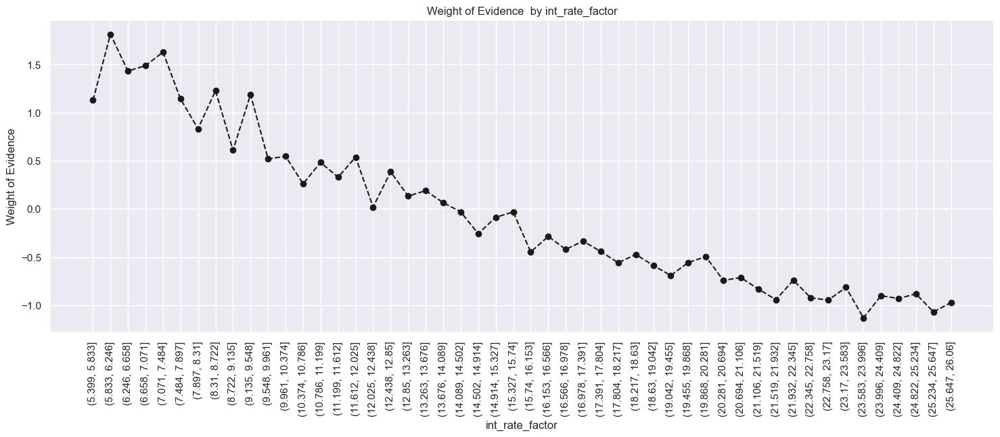

In [118]:
plot_by_woe(df_temp, 90)

In [119]:


df_inputs_prepr['int_rate:::<9.548'] = np.where((df_inputs_prepr['int_rate'] <= 9.548), 1,0)
df_inputs_prepr['int_rate:::9.548-12.025'] = np.where((df_inputs_prepr['int_rate'] >9.548) & (df_inputs_prepr['int_rate'] <= 12.025), 1,0)
df_inputs_prepr['int_rate:::12.025-15.74'] = np.where((df_inputs_prepr['int_rate'] >12.025) & (df_inputs_prepr['int_rate'] <= 15.74), 1,0)
df_inputs_prepr['int_rate:::15.74-20.281'] = np.where((df_inputs_prepr['int_rate'] >15.74) & (df_inputs_prepr['int_rate'] <= 20.281),1,0)
df_inputs_prepr['int_rate:::>20.281'] = np.where((df_inputs_prepr['int_rate'] >20.281), 1,0)


'''
1 Build 50 bins

↓

2 Compute WOE

↓

3 Compute confidence interval

↓

4 Merge adjacent bins whose
confidence intervals overlap

↓

5 Repeat

↓

6 Check monotonicity

↓

7 If monotonicity broken

merge again

↓

8 Stop when

• monotonic
• stable
• IV loss small





Start with the 50 fine bins.
Merge adjacent bins if any of the following holds:
fewer than 300 observations,
fewer than 50 bads,
95% WOE confidence intervals overlap substantially,
|diff_WOE| < 0.10,
merging preserves or improves monotonicity.
After each merge, recompute WOE and IV.
Stop when:
every bucket satisfies the minimum sample-size rules,
the WOE curve is monotonic,
the total IV has decreased by no more than about 2–5% from the fine-class version.
'''

'\n1 Build 50 bins\n\n↓\n\n2 Compute WOE\n\n↓\n\n3 Compute confidence interval\n\n↓\n\n4 Merge adjacent bins whose\nconfidence intervals overlap\n\n↓\n\n5 Repeat\n\n↓\n\n6 Check monotonicity\n\n↓\n\n7 If monotonicity broken\n\nmerge again\n\n↓\n\n8 Stop when\n\n• monotonic\n• stable\n• IV loss small\n\n\n\n\n\nStart with the 50 fine bins.\nMerge adjacent bins if any of the following holds:\nfewer than 300 observations,\nfewer than 50 bads,\n95% WOE confidence intervals overlap substantially,\n|diff_WOE| < 0.10,\nmerging preserves or improves monotonicity.\nAfter each merge, recompute WOE and IV.\nStop when:\nevery bucket satisfies the minimum sample-size rules,\nthe WOE curve is monotonic,\nthe total IV has decreased by no more than about 2–5% from the fine-class version.\n'

from Graph relationship is almost monotonic 
The higher int , the lower woe and higher prob of default
presence of a monotonic relationship makes it somehow easier to determine the boundaries of the intervals 
it doesnt matter as much where they are as the next interval is almost certainly going to have lower  woe that the previous 
================================================================================================================================


1. Numerous ups and in first 10 obs points us to look at no.of obs, woe is high but few observations, <= 9.548
2. >9.548 < = 12.025
   >12.025 < = 15.74
   >15.74 < = 20.281
   >20.281 no major difference in woe and low no. of observations. so we group them in one dummy


C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


annual_inc_factor   n_obs  prop_good  prop_n_obs    n_good  \
0     (-5243.882, 144693.64]  351901   0.888565    0.943371  312687.0   
1     (144693.64, 287491.28]   19004   0.925437    0.050946   17587.0   
2     (287491.28, 430288.92]    1525   0.930492    0.004088    1419.0   
3     (430288.92, 573086.56]     332   0.939759    0.000890     312.0   
4      (573086.56, 715884.2]     112   0.883929    0.000300      99.0   
5      (715884.2, 858681.84]      65   0.892308    0.000174      58.0   
6    (858681.84, 1001479.48]      39   0.974359    0.000105      38.0   
7   (1001479.48, 1144277.12]      10   1.000000    0.000027      10.0   
8   (1144277.12, 1287074.76]      12   1.000000    0.000032      12.0   
9    (1287074.76, 1429872.4]       6   1.000000    0.000016       6.0   
10   (1429872.4, 1572670.04]       3   1.000000    0.000008       3.0   
11  (1572670.04, 1715467.68]       1   1.000000    0.000003       1.0   
12  (1715467.68, 1858265.32]       1   1.000000    0.000003       1.0   
13  (1858265.32, 2001062.96]       6   1.000000    0.000016       6.0   
14   (2001062.96, 2143860.6]       1   1.000000    0.000003       1.0   
15   (2143860.6, 2286658.24]       0        NaN    0.000000       NaN   
16  (2286658.24, 2429455.88]       0        NaN    0.000000       NaN   
17  (2429455.88, 2572253.52]       0        NaN    0.000000       NaN   
18  (2572253.52, 2715051.16]       0        NaN    0.000000       NaN   
19   (2715051.16, 2857848.8]       0        NaN    0.000000       NaN   
20   (2857848.8, 3000646.44]       0        NaN    0.000000       NaN   
21  (3000646.44, 3143444.08]       0        NaN    0.000000       NaN   
22  (3143444.08, 3286241.72]       0        NaN    0.000000       NaN   
23  (3286241.72, 3429039.36]       0        NaN    0.000000       NaN   
24   (3429039.36, 3571837.0]       0        NaN    0.000000       NaN   
25   (3571837.0, 3714634.64]       0        NaN    0.000000       NaN   
26  (3714634.64, 3857432.28]       0        NaN    0.000000       NaN   
27  (3857432.28, 4000229.92]       1   1.000000    0.000003       1.0   
28  (4000229.92, 4143027.56]       0        NaN    0.000000       NaN   
29   (4143027.56, 4285825.2]       0        NaN    0.000000       NaN   
30   (4285825.2, 4428622.84]       0        NaN    0.000000       NaN   
31  (4428622.84, 4571420.48]       1   1.000000    0.000003       1.0   
32  (4571420.48, 4714218.12]       0        NaN    0.000000       NaN   
33  (4714218.12, 4857015.76]       0        NaN    0.000000       NaN   
34   (4857015.76, 4999813.4]       1   1.000000    0.000003       1.0   
35   (4999813.4, 5142611.04]       1   1.000000    0.000003       1.0   
36  (5142611.04, 5285408.68]       0        NaN    0.000000       NaN   
37  (5285408.68, 5428206.32]       0        NaN    0.000000       NaN   
38  (5428206.32, 5571003.96]       0        NaN    0.000000       NaN   
39   (5571003.96, 5713801.6]       0        NaN    0.000000       NaN   
40   (5713801.6, 5856599.24]       0        NaN    0.000000       NaN   
41  (5856599.24, 5999396.88]       0        NaN    0.000000       NaN   
42  (5999396.88, 6142194.52]       2   1.000000    0.000005       2.0   
43  (6142194.52, 6284992.16]       0        NaN    0.000000       NaN   
44   (6284992.16, 6427789.8]       0        NaN    0.000000       NaN   
45   (6427789.8, 6570587.44]       0        NaN    0.000000       NaN   
46  (6570587.44, 6713385.08]       0        NaN    0.000000       NaN   
47  (6713385.08, 6856182.72]       0        NaN    0.000000       NaN   
48  (6856182.72, 6998980.36]       0        NaN    0.000000       NaN   
49   (6998980.36, 7141778.0]       1   1.000000    0.000003       1.0   

      n_bad  prop_n_good  prop_n_bad       WoE    n_obs%  diff_prop_good  \
0   39214.0     0.941128    0.961646 -0.021567  0.943371             NaN   
1    1417.0     0.052934    0.034749  0.420882  0.050946        0.036872   
2     106.0     0.004271    0.002599  0.496533  0.004088   

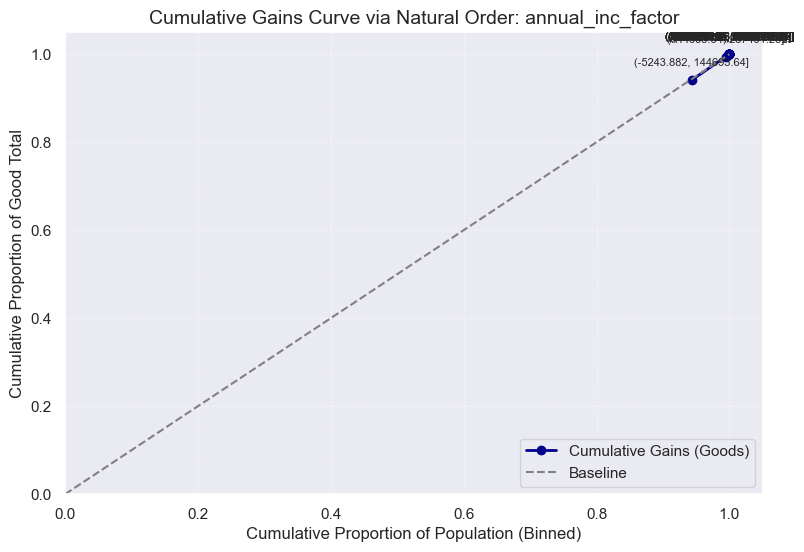

(None, None)

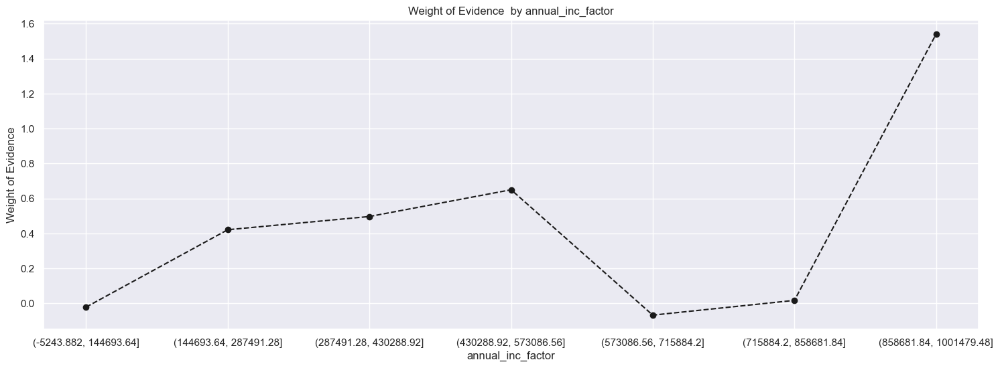

In [120]:
f'Annual income requires some special treatment\
It contains positive real numbers but can only take numbers greater than zero'


df_inputs_prepr['annual_inc_factor'] = pd.cut(df_inputs_prepr['annual_inc'], 50)

df_temp = woe_ordered_continuous(df_inputs_prepr, 'annual_inc_factor' , df_targets_prepr)
print(df_temp)

plot_cumulative_gains_from_woe(df_temp, 'annual_inc_factor'),plot_by_woe(df_temp)


C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


annual_inc_factor   n_obs  prop_good  prop_n_obs    n_good  \
0      (-5243.882, 73294.82]  231442   0.875900    0.620446  202720.0   
1      (73294.82, 144693.64]  120459   0.912900    0.322925  109967.0   
2     (144693.64, 216092.46]   15885   0.925087    0.042584   14695.0   
3     (216092.46, 287491.28]    3119   0.927220    0.008361    2892.0   
4      (287491.28, 358890.1]    1117   0.929275    0.002994    1038.0   
5      (358890.1, 430288.92]     408   0.933824    0.001094     381.0   
6     (430288.92, 501687.74]     245   0.946939    0.000657     232.0   
7     (501687.74, 573086.56]      87   0.919540    0.000233      80.0   
8     (573086.56, 644485.38]      61   0.868852    0.000164      53.0   
9      (644485.38, 715884.2]      51   0.901961    0.000137      46.0   
10     (715884.2, 787283.02]      37   0.945946    0.000099      35.0   
11    (787283.02, 858681.84]      28   0.821429    0.000075      23.0   
12    (858681.84, 930080.66]      17   1.000000    0.000046      17.0   
13   (930080.66, 1001479.48]      22   0.954545    0.000059      21.0   
14   (1001479.48, 1072878.3]       3   1.000000    0.000008       3.0   
15   (1072878.3, 1144277.12]       7   1.000000    0.000019       7.0   
16  (1144277.12, 1215675.94]       8   1.000000    0.000021       8.0   
17  (1215675.94, 1287074.76]       4   1.000000    0.000011       4.0   
18  (1287074.76, 1358473.58]       4   1.000000    0.000011       4.0   
19   (1358473.58, 1429872.4]       2   1.000000    0.000005       2.0   
20   (1429872.4, 1501271.22]       2   1.000000    0.000005       2.0   
21  (1501271.22, 1572670.04]       1   1.000000    0.000003       1.0   
22  (1572670.04, 1644068.86]       1   1.000000    0.000003       1.0   
23  (1644068.86, 1715467.68]       0        NaN    0.000000       NaN   
24   (1715467.68, 1786866.5]       1   1.000000    0.000003       1.0   
25   (1786866.5, 1858265.32]       0        NaN    0.000000       NaN   
26  (1858265.32, 1929664.14]       1   1.000000    0.000003       1.0   
27  (1929664.14, 2001062.96]       5   1.000000    0.000013       5.0   
28  (2001062.96, 2072461.78]       1   1.000000    0.000003       1.0   
29   (2072461.78, 2143860.6]       0        NaN    0.000000       NaN   
30   (2143860.6, 2215259.42]       0        NaN    0.000000       NaN   
31  (2215259.42, 2286658.24]       0        NaN    0.000000       NaN   
32  (2286658.24, 2358057.06]       0        NaN    0.000000       NaN   
33  (2358057.06, 2429455.88]       0        NaN    0.000000       NaN   
34   (2429455.88, 2500854.7]       0        NaN    0.000000       NaN   
35   (2500854.7, 2572253.52]       0        NaN    0.000000       NaN   
36  (2572253.52, 2643652.34]       0        NaN    0.000000       NaN   
37  (2643652.34, 2715051.16]       0        NaN    0.000000       NaN   
38  (2715051.16, 2786449.98]       0        NaN    0.000000       NaN   
39   (2786449.98, 2857848.8]       0        NaN    0.000000       NaN   
40   (2857848.8, 2929247.62]       0        NaN    0.000000       NaN   
41  (2929247.62, 3000646.44]       0        NaN    0.000000       NaN   
42  (3000646.44, 3072045.26]       0        NaN    0.000000       NaN   
43  (3072045.26, 3143444.08]       0        NaN    0.000000       NaN   
44   (3143444.08, 3214842.9]       0        NaN    0.000000       NaN   
45   (3214842.9, 3286241.72]       0        NaN    0.000000       NaN   
46  (3286241.72, 3357640.54]       0        NaN    0.000000       NaN   
47  (3357640.54, 3429039.36]       0        NaN    0.000000       NaN   
48  (3429039.36, 3500438.18]       0        NaN    0.000000       NaN   
49   (3500438.18, 3571837.0]       0        NaN    0.000000       NaN   
50   (3571837.0, 3643235.82]       0        NaN    0.000000       NaN   
51  (3643235.82, 3714634.64]       0        NaN    0.000000       NaN   
52  (3714634.64, 3786033.46]       0        NaN    0.000000       NaN   
53  (3786033.46, 3857432.28]       0        NaN    0.000000       NaN

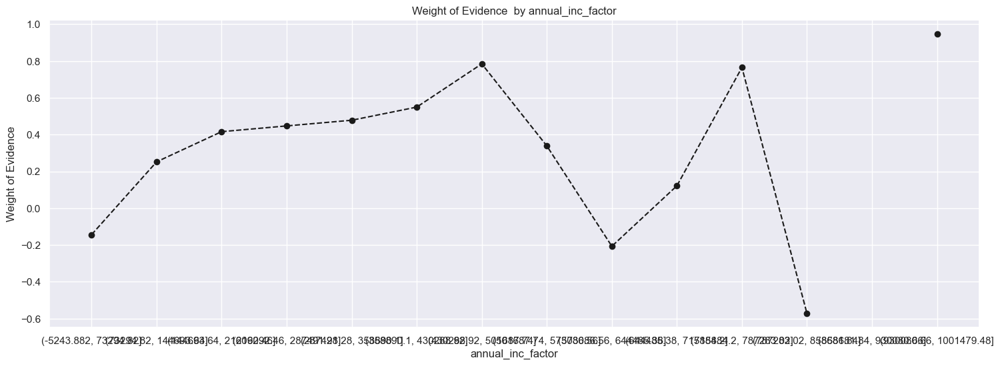

In [121]:
f"since most observationons are concentrated at the start\
didn't split well enough s lets try and split into more categories because 50 categories werent enough to fine class the variable"


df_inputs_prepr['annual_inc_factor'] = pd.cut(df_inputs_prepr['annual_inc'], 100)
df_temp = woe_ordered_continuous(df_inputs_prepr, 'annual_inc_factor', df_targets_prepr)
print(df_temp)
plot_by_woe(df_temp)


C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


annual_inc_q  n_obs  prop_good  prop_n_obs   n_good   n_bad  \
0    (1895.999, 34000.0]  38790   0.854885    0.103988  33161.0  5629.0   
1     (34000.0, 41600.0]  35883   0.863584    0.096195  30988.0  4895.0   
2     (41600.0, 49000.0]  37726   0.872449    0.101135  32914.0  4812.0   
3     (49000.0, 55000.0]  39457   0.884279    0.105776  34891.0  4566.0   
4     (55000.0, 62891.0]  34657   0.882996    0.092908  30602.0  4055.0   
5     (62891.0, 71000.0]  37941   0.893071    0.101712  33884.0  4057.0   
6     (71000.0, 81000.0]  37101   0.900838    0.099460  33422.0  3679.0   
7     (81000.0, 95900.0]  36868   0.911359    0.098835  33600.0  3268.0   
8    (95900.0, 120000.0]  38912   0.918046    0.104315  35723.0  3189.0   
9  (120000.0, 7141778.0]  35690   0.926366    0.095677  33062.0  2628.0   

   prop_n_good  prop_n_bad       WoE    n_obs%  diff_prop_good  diff_WoE  \
0     0.099808    0.138040 -0.324293  0.103988             NaN       NaN   
1     0.093268    0.120040 -0.252350  0.096195        0.008699  0.071943   
2     0.099065    0.118005 -0.174951  0.101135        0.008864  0.077400   
3     0.105015    0.111972 -0.064145  0.105776        0.011830  0.110806   
4     0.092106    0.099441 -0.076621  0.092908        0.001283  0.012477   
5     0.101984    0.099490  0.024763  0.101712        0.010075  0.101384   
6     0.100594    0.090220  0.108837  0.099460        0.007767  0.084074   
7     0.101130    0.080141  0.232612  0.098835        0.010521  0.123775   
8     0.107519    0.078204  0.318351  0.104315        0.006686  0.085739   
9     0.099510    0.064447  0.434426  0.095677        0.008320  0.116074   

         IV  
0  0.054114  
1  0.054114  
2  0.054114  
3  0.054114  
4  0.054114  
5  0.054114  
6  0.054114  
7  0.054114  
8  0.054114  
9  0.054114

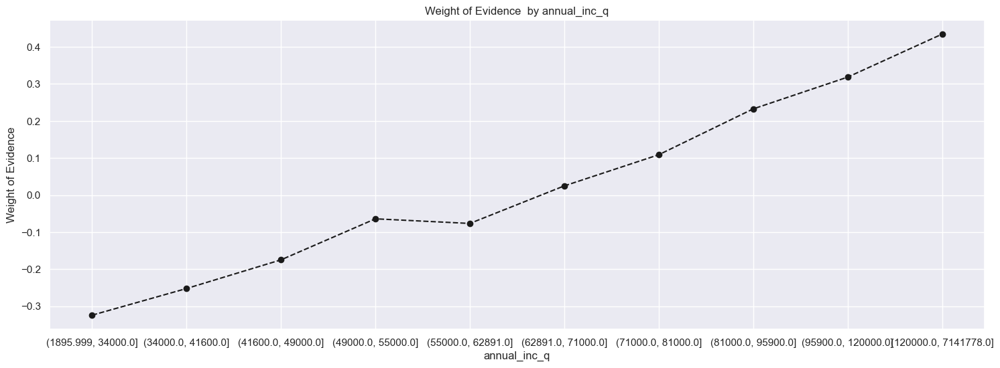

In [122]:
df_inputs_prepr['annual_inc_q'] = pd.qcut(
    df_inputs_prepr['annual_inc'],
    q=10,
    duplicates='drop'
)

df_temp = woe_ordered_continuous(df_inputs_prepr, 'annual_inc_q', df_targets_prepr)
print(df_temp)
plot_by_woe(df_temp)


In [123]:
df_inputs_prepr['funded_amnt_factor'] = pd.cut(df_inputs_prepr['funded_amnt'], 50)
df_temp=woe_ordered_continuous(df_inputs_prepr, 'funded_amnt_factor', df_targets_prepr)
df_temp.head()

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,funded_amnt_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(465.5, 1190.0]",1224,0.905229,0.003281,1108.0,116.0,0.003335,0.002845,0.158977,0.003281,NaN,NaN,0.014139
1,"(1190.0, 1880.0]",3028,0.903897,0.008117,2737.0,291.0,0.008238,0.007136,0.143549,0.008117,0.001332,0.015427,0.014139
2,"(1880.0, 2570.0]",6018,0.893819,0.016133,5379.0,639.0,0.016190,0.015670,0.032608,0.016133,0.010078,0.110941,0.014139
3,"(2570.0, 3260.0]",7248,0.889073,0.019430,6444.0,804.0,0.019395,0.019717,-0.016440,0.019430,0.004746,0.049048,0.014139
4,"(3260.0, 3950.0]",4751,0.891602,0.012736,4236.0,515.0,0.012749,0.012629,0.009463,0.012736,0.002529,0.025902,0.014139


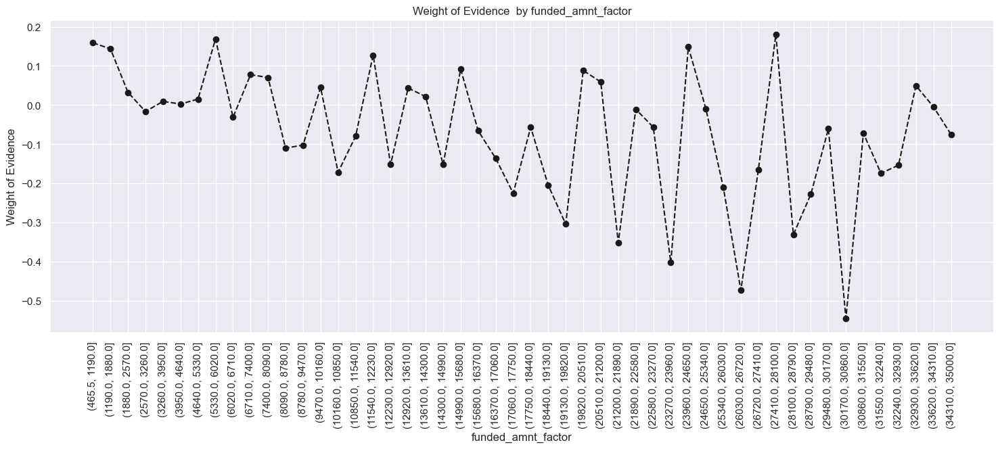

In [124]:
plot_by_woe(df_temp, 90)

In [125]:
# ALTERNATIVELY WE COULD

bins = [
    0,
    5000,
    10000,
    20000,
    30000,
    np.inf
]

labels = [
    'funded:very_low',
    'funded:low',
    'funded:medium',
    'funded:high',
    'funded:very_high'
]

df_inputs_prepr['funded_amnt_grp'] = pd.cut(
    df_inputs_prepr['funded_amnt'],
    bins=bins,
    labels=labels
)


df_temp=woe_ordered_continuous(df_inputs_prepr, 'funded_amnt_grp', df_targets_prepr)
df_temp



C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,funded_amnt_grp,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,funded:very_low,45630,0.892899,0.122323,40743.0,4887.0,0.122628,0.119844,0.022960,0.122323,NaN,NaN,0.001383
1,funded:low,103411,0.895011,0.277220,92554.0,10857.0,0.278567,0.266247,0.045237,0.277220,0.002112,0.022277,0.001383
2,funded:medium,146170,0.889765,0.391847,130057.0,16113.0,0.391443,0.395140,-0.009399,0.391847,0.005246,0.054636,0.001383
3,funded:high,59212,0.886695,0.158733,52503.0,6709.0,0.158023,0.164525,-0.040325,0.158733,0.003070,0.030926,0.001383
4,funded:very_high,18605,0.881107,0.049876,16393.0,2212.0,0.049339,0.054245,-0.094788,0.049876,0.005588,0.054463,0.001383


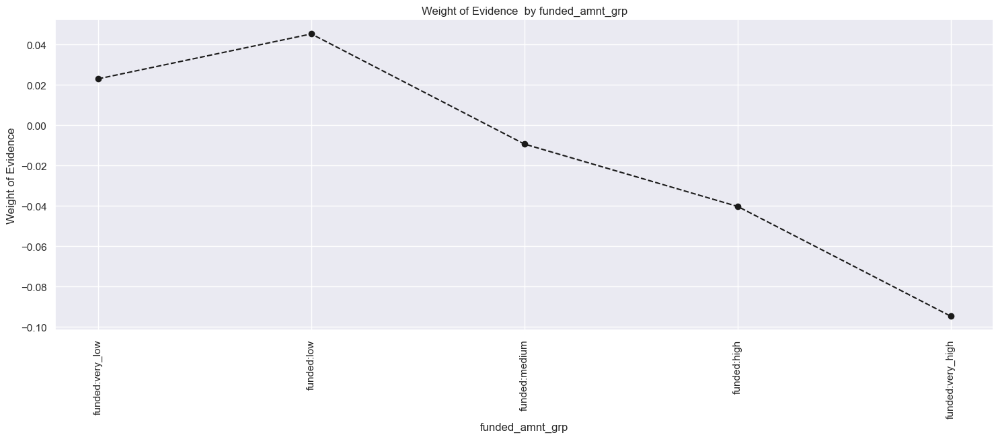

In [126]:
plot_by_woe(df_temp, 90)

In [127]:
f"again first cat has a large number of observations 62% of all observations, in common logic this is kinda expected, There are few people with large\
income so good idea to set aside people with high income in one dummy variable and investigate the lower income separately\
the first 2 categories contain a lot of observations while each of te subsequent categories  contains very few observations\
the higher the incone the lower the number of observations Third category starts at 144693, so lets assume  $140,000 to be the threshold btn low and high\
this way high income category will have observations a bit more than 5% of the observations \
Now let's focus on people with lower income, for convenience we will store them in  a temporary df"



#df_inputs_prepr_temp =  df_inputs_prepr[df_inputs_prepr['annual_inc'].loc(df_inputs_prepr['annual_inc'] <= 140000)] wrong coz loc is on series on a df


df_inputs_prepr_temp =  df_inputs_prepr[df_inputs_prepr['annual_inc'] <= 140000] 

#df_inputs_prepr_temp =  df_inputs_prepr.loc[df_inputs_prepr['annual_inc'] <= 140000, :]

df_inputs_prepr_temp['annual_inc_factor'] = pd.cut(df_inputs_prepr_temp['annual_inc'], 50)

df_temp = woe_ordered_continuous(df_inputs_prepr_temp, 'annual_inc_factor', df_targets_prepr[df_inputs_prepr_temp.index])
df_temp



C:\Users\USER\AppData\Local\Temp\ipykernel_11004\1006626976.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_inputs_prepr_temp['annual_inc_factor'] = pd.cut(df_inputs_prepr_temp['annual_inc'], 50)
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future ver

,annual_inc_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(1757.896, 4658.08]",15,0.800000,0.000043,12.0,3.0,0.000038,0.000077,-0.689448,0.000043,NaN,NaN,0.049816
1,"(4658.08, 7420.16]",40,0.750000,0.000114,30.0,10.0,0.000096,0.000256,-0.977130,0.000114,0.050000,0.287682,0.049816
2,"(7420.16, 10182.24]",287,0.874564,0.000818,251.0,36.0,0.000805,0.000920,-0.133808,0.000818,0.124564,0.843322,0.049816
3,"(10182.24, 12944.32]",547,0.828154,0.001558,453.0,94.0,0.001452,0.002402,-0.503145,0.001558,0.046411,0.369337,0.049816
4,"(12944.32, 15706.4]",1210,0.830579,0.003447,1005.0,205.0,0.003222,0.005238,-0.486010,0.003447,0.002425,0.017135,0.049816
5,"(15706.4, 18468.48]",1522,0.847569,0.004335,1290.0,232.0,0.004136,0.005928,-0.360082,0.004335,0.016990,0.125927,0.049816
6,"(18468.48, 21230.56]",2928,0.855533,0.008340,2505.0,423.0,0.008031,0.010809,-0.297071,0.008340,0.007964,0.063012,0.049816
7,"(21230.56, 23992.64]",2495,0.844489,0.007107,2107.0,388.0,0.006755,0.009914,-0.383727,0.007107,0.011044,0.086657,0.049816
8,"(23992.64, 26754.72]",7016,0.848632,0.019985,5954.0,1062.0,0.019088,0.027137,-0.351833,0.019985,0.004143,0.031894,0.049816
9,"(26754.72, 29516.8]",5643,0.857345,0.016074,4838.0,805.0,0.015510,0.020570,-0.282328,0.016074,0.008714,0.069505,0.049816


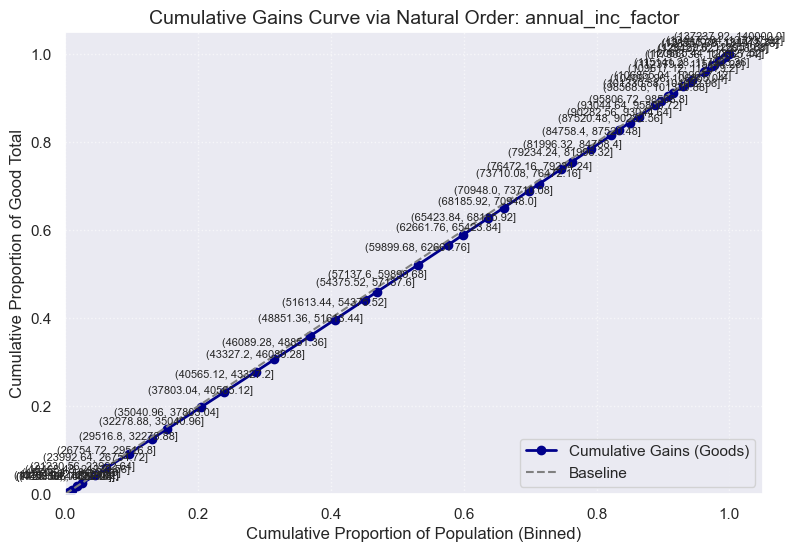

(None, None)

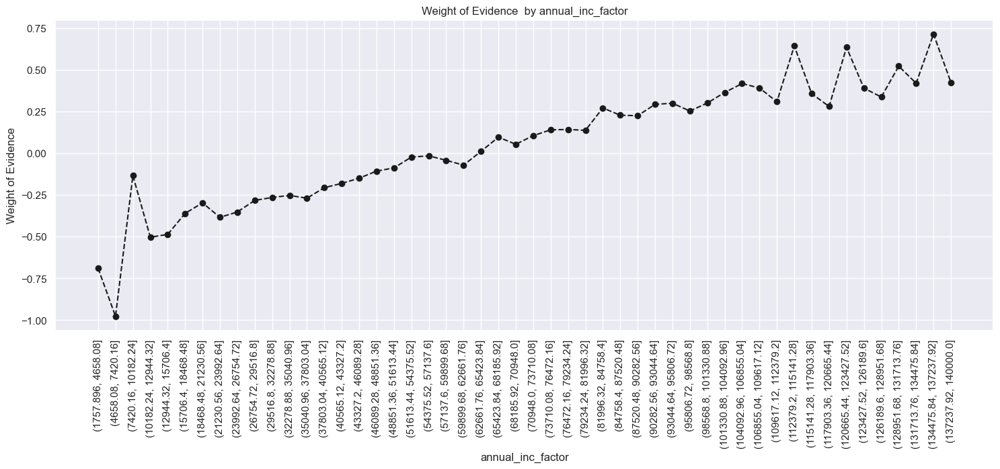

In [128]:
plot_cumulative_gains_from_woe(df_temp, 'annual_inc_factor'), plot_by_woe(df_temp, 90), 

In [129]:
f" Rember int rate was in opposite direction, also annual income is more monotonic, hence we can split this into intervals"

"""
mine were (1. < 10,182
2. 10,182 - 26,754  
3. 26,754 - 37,803
4. 37,803 - 51,513
5. 51,513 - 62,661
6. 62,661 - 73,710
7. 73,710 - 81,996
8. 81,996 - 98,568
9. 98,568 - 120,665
10. > 120,665) 

Another approach below

We take into consideration number of observations as well the first 2 intervls upto 10,182 and 21,230  have very few observations each
so first interval will be <=20K

if we kept everything split with width 10,000 the last 4 intervals (3736 to 5714 to 6228, to 3033 t0 2532) from 100k to 140k  would also have a very 
low number of observations each, with that in mind lets make 2 intervals from 100k to 120 k and 120 k to 140k

what will be left is btn 20k and 100k and we will split it into categories of 10,000 each , 8 equally wide 

20k to 30k 
30 to 40k
40k to 50k
50k to 60k
60k to 70k
70k to 80k
80k to 90k 
90k to 100k
"""

df_inputs_prepr['annual_inc:::<20k'] = np.where((df_inputs_prepr['annual_inc'] <= 20000), 1,0)
df_inputs_prepr['annual_inc:::20k-30k'] = np.where((df_inputs_prepr['annual_inc'] > 20000) & (df_inputs_prepr['annual_inc'] <=30000), 1,0)
df_inputs_prepr['annual_inc:::30k-40k'] = np.where((df_inputs_prepr['annual_inc'] > 30000) & (df_inputs_prepr['annual_inc'] <=40000), 1,0)
df_inputs_prepr['annual_inc:::40k-50k'] = np.where((df_inputs_prepr['annual_inc'] > 40000) & (df_inputs_prepr['annual_inc'] <=50000), 1,0)
df_inputs_prepr['annual_inc:::50k-60k'] = np.where((df_inputs_prepr['annual_inc'] > 50000) & (df_inputs_prepr['annual_inc'] <=60000), 1,0)
df_inputs_prepr['annual_inc:::60k-70k'] = np.where((df_inputs_prepr['annual_inc'] > 60000) & (df_inputs_prepr['annual_inc'] <=70000), 1,0)
df_inputs_prepr['annual_inc:::70k-80k'] = np.where((df_inputs_prepr['annual_inc'] > 70000) & (df_inputs_prepr['annual_inc'] <=80000), 1,0)
df_inputs_prepr['annual_inc:::80k-90k'] = np.where((df_inputs_prepr['annual_inc'] > 80000) & (df_inputs_prepr['annual_inc'] <=90000), 1,0)
df_inputs_prepr['annual_inc:::90k-100k'] = np.where((df_inputs_prepr['annual_inc'] > 90000) & (df_inputs_prepr['annual_inc'] <=100000), 1,0)
df_inputs_prepr['annual_inc:::100k-120k'] = np.where((df_inputs_prepr['annual_inc'] > 100000) & (df_inputs_prepr['annual_inc'] <=120000), 1,0)
df_inputs_prepr['annual_inc:::120k-140k'] = np.where((df_inputs_prepr['annual_inc'] > 120000) & (df_inputs_prepr['annual_inc'] <=140000), 1,0)
df_inputs_prepr['annual_inc:::>140k'] = np.where((df_inputs_prepr['annual_inc'] >= 140000), 1,0)


In [130]:
df_inputs_prepr.columns.duplicated().sum()

np.int64(0)

In [131]:
df_inputs_prepr.columns[df_inputs_prepr.columns.duplicated()]

Index([], dtype='object')

In [132]:
# 1. Ensure column exists
assert 'funded_amnt_grp' in df_inputs_prepr.columns

# 2. Ensure it is categorical
df_inputs_prepr['funded_amnt_grp'] = df_inputs_prepr['funded_amnt_grp'].astype('category')

# 3. Add Missing to allowed categories
df_inputs_prepr['funded_amnt_grp'] = (
    df_inputs_prepr['funded_amnt_grp']
        .cat.add_categories(['Missing'])
        .fillna('Missing')
)

# 4. Create dummies
funded_dummies = pd.get_dummies(
    df_inputs_prepr['funded_amnt_grp'],
    prefix='funded',
    prefix_sep=':::',
    drop_first=True
)

# 5. Join back
df_inputs_prepr = pd.concat([df_inputs_prepr, funded_dummies], axis=1)


In [133]:
# 1. Ensure column exists
assert 'funded_amnt_grp' in df_inputs_prepr.columns

# 2. Force everything to string and handle missing
df_inputs_prepr['funded_amnt_grp'] = (
    df_inputs_prepr['funded_amnt_grp']
        .astype(str)
        .replace('nan', 'Missing')   # important: astype(str) turns NaN into 'nan'
)

# 3. Create dummies
funded_dummies = pd.get_dummies(
    df_inputs_prepr['funded_amnt_grp'],
    prefix='funded',
    prefix_sep=':::',
    drop_first=True
)

# 4. Join back
# df_inputs_prepr = pd.concat([df_inputs_prepr, funded_dummies], axis=1)

funded_dummies.head()


,funded:::funded:low,funded:::funded:medium,funded:::funded:very_high,funded:::funded:very_low
427211,False,False,False,False
206088,True,False,False,False
136020,False,False,False,False
412305,False,True,False,False
36159,True,False,False,False


In [134]:
'''Which one should you use?

For modeling pipelines, especially credit-scorecard style preprocessing:

Use Strategy 1.
Convert to string, control categories yourself, dummy encode.
Much fewer silent bugs.

Categorical dtype is fragile and causes exactly the kind of problems you’re seeing.

One final professional-level safety check

After creating dummies, always verify:

If that ever returns False, your pipeline is broken.'''

funded_dummies.isin([0, 1]).all().all()

np.True_

**#THIS IS WRONG**

# mths_since_last_record (86% missing). 🧠 Meaning: Missing = never had public record 👉 999 = “never happened”

loan_data['has_record'] = loan_data['mths_since_last_record'].notna().astype(int)
loan_data['mths_since_last_record'].fillna(999, inplace=True)

df_inputs_prepr['mths_since_last_record_factor'] = pd.cut(df_inputs_prepr['mths_since_last_record'], 50)

df_temp = woe_ordered_continuous(df_inputs_prepr, 'mths_since_last_record_factor' , df_targets_prepr)
print(df_temp)

plot_by_woe(df_temp, 90)

***'''Why pd.cut(50) and pd.cut(80) are both wrong: You filled missing (86%) with 999, so bin 49 ((979, 999]) contains 322,961 observations — 
87% of your data crammed into one bin. This is not fine classing, it is one massive bin and 48 empty bins. The 999-filled observations must be handled as a separate category entirely before you cut.
Correct approach: Cut only the non-missing observations, then create a separate Missing dummy.'''***

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


None

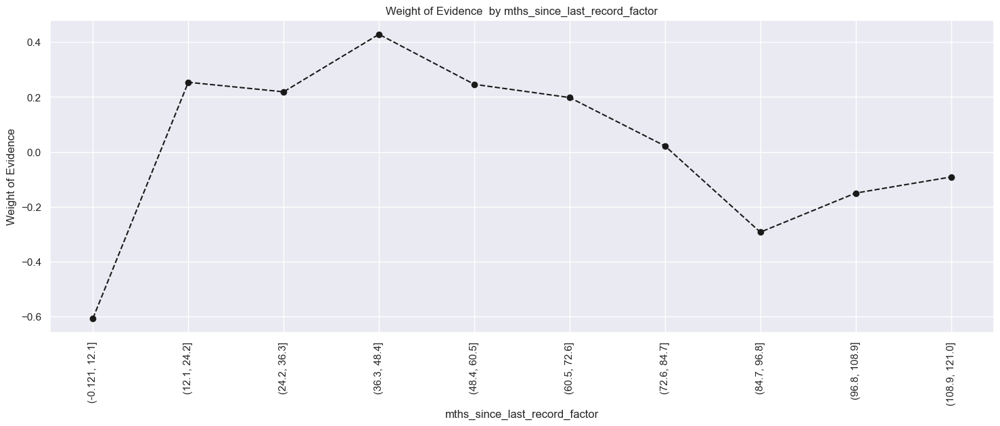

In [135]:

# mths_since_last_record (86% missing). 🧠 Meaning: Missing = never had public record 👉 999 = “never happened”
# Correct approach: Cut only the non-missing observations, then create a separate Missing dummy.


# Fine classing — only on rows that actually have the value
mask_has_record = df_inputs_prepr['mths_since_last_record'] < 999

df_inputs_prepr_temp = df_inputs_prepr[mask_has_record].copy()
df_inputs_prepr_temp['mths_since_last_record_factor'] = pd.cut(
    df_inputs_prepr_temp['mths_since_last_record'], 
    bins=10  # only ~50k rows, 10 bins is enough
)
df_temp = woe_ordered_continuous(
    df_inputs_prepr_temp, 
    'mths_since_last_record_factor', 
    df_targets_prepr[mask_has_record]
)


print(plot_by_woe(df_temp, 90))

'''
From the output you shared (rows 0–9 are the real data): The WOE pattern shows lower-numbered months (more recent public records) have higher 
default rates, which makes sense. Someone with a bankruptcy 6 months ago is riskier than someone whose record was 10 years ago.'''

# Coarse classing — based on your output:'''

# Reference category: mths_since_last_record:::Missing (no record = no public derogatory event = lowest risk baseline).

df_inputs_prepr['mths_since_last_record:::Missing'] = np.where(
    df_inputs_prepr['mths_since_last_record'] >= 999, 1, 0)

df_inputs_prepr['mths_since_last_record:::0-12'] = np.where(
    (df_inputs_prepr['mths_since_last_record'] >= 0) & 
    (df_inputs_prepr['mths_since_last_record'] <= 12), 1, 0)

df_inputs_prepr['mths_since_last_record:::13-37'] = np.where(
    (df_inputs_prepr['mths_since_last_record'] > 12) & 
    (df_inputs_prepr['mths_since_last_record'] <= 37), 1, 0)

df_inputs_prepr['mths_since_last_record:::38-75'] = np.where(
    (df_inputs_prepr['mths_since_last_record'] > 37) & 
    (df_inputs_prepr['mths_since_last_record'] <= 75), 1, 0)

df_inputs_prepr['mths_since_last_record:::76-130'] = np.where(
    (df_inputs_prepr['mths_since_last_record'] > 75) & 
    (df_inputs_prepr['mths_since_last_record'] <= 130), 1, 0)

None

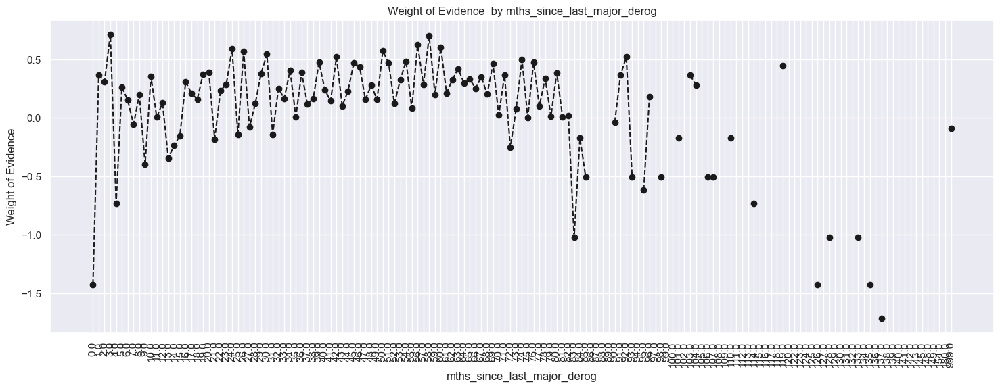

In [136]:
# mths_since_last_major_derog (78%)
'''mths_since_last_major_derog
Same 999-fill problem as above — bin 49 has 293,858 observations. Same solution.
From your output: Rows 0–9 show values from 0–200 months. The pattern shows that more recent derogatory marks (0–20 months) have 
slightly lower prop_good than older ones, as expected.'''


df_temp = woe_ordered_continuous(
    df_inputs_prepr_temp, 
    'mths_since_last_major_derog', 
    df_targets_prepr[mask_has_record]
)

print(plot_by_woe(df_temp, 90))

# Coarse classing:

df_inputs_prepr['mths_since_last_major_derog:::Missing'] = np.where(
    df_inputs_prepr['mths_since_last_major_derog'] >= 999, 1, 0)

df_inputs_prepr['mths_since_last_major_derog:::0-20'] = np.where(
    (df_inputs_prepr['mths_since_last_major_derog'] >= 0) & 
    (df_inputs_prepr['mths_since_last_major_derog'] <= 20), 1, 0)

df_inputs_prepr['mths_since_last_major_derog:::21-41'] = np.where(
    (df_inputs_prepr['mths_since_last_major_derog'] > 20) & 
    (df_inputs_prepr['mths_since_last_major_derog'] <= 41), 1, 0)

df_inputs_prepr['mths_since_last_major_derog:::42-62'] = np.where(
    (df_inputs_prepr['mths_since_last_major_derog'] > 41) & 
    (df_inputs_prepr['mths_since_last_major_derog'] <= 62), 1, 0)

df_inputs_prepr['mths_since_last_major_derog:::>62'] = np.where(
    (df_inputs_prepr['mths_since_last_major_derog'] > 62) & 
    (df_inputs_prepr['mths_since_last_major_derog'] < 999), 1, 0)

# Reference category: mths_since_last_major_derog:::Missing.




# ***Months since last delinquency variable is another tricky one..***

from our initial preprocessing , we already know that this has a lot of missing values, so many that we cant do anything with them at this stage
Now since we are about to estimate our statistical model it is time to face the issue ..

Every continuous variable is  represented by dummy variables in the probability of default model and this variable will be no exception. the variable takes integer vales greater than zero

for the missing values we shall just create another dummy variable for them . so lets create a dummy variable indicating that the value of the originla variable is missing 

missing value dummy variable = 
1:  When the value is missing 
0: when the value is not missing 


# NOTE THAT THIS METHOD OF DEALING WITH MISSING VALUES CAN ONLY BE DONE WITH CATEGORICAL VARIABLES 

In [137]:
df_inputs_prepr_temp = df_inputs_prepr[pd.notnull(df_inputs_prepr['mths_since_last_delinq'])]
df_inputs_prepr_temp['mths_since_last_delinq_factor'] =pd.cut(df_inputs_prepr_temp['mths_since_last_delinq'], 50)
df_temp = woe_ordered_continuous(df_inputs_prepr_temp, 'mths_since_last_delinq_factor', df_targets_prepr[df_inputs_prepr_temp.index])   
df_temp

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].count(),
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2762887991.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(df.columns.values[0], as_index=False)[df.columns.values[1]].mean().reset_index(drop=True)


,mths_since_last_delinq_factor,n_obs,prop_good,prop_n_obs,n_good,n_bad,prop_n_good,prop_n_bad,WoE,n_obs%,diff_prop_good,diff_WoE,IV
0,"(-0.999, 19.98]",55306,0.889271,0.148262,49182.0,6124.0,0.148027,0.150179,-0.014433,0.148262,NaN,NaN,inf
1,"(19.98, 39.96]",52188,0.895666,0.139904,46743.0,5445.0,0.140686,0.133528,0.052222,0.139904,0.006395,0.066655,inf
2,"(39.96, 59.94]",37352,0.894945,0.100132,33428.0,3924.0,0.100611,0.096228,0.044537,0.100132,0.000720,0.007684,inf
3,"(59.94, 79.92]",25236,0.891425,0.067652,22496.0,2740.0,0.067708,0.067193,0.007635,0.067652,0.003520,0.036903,inf
4,"(79.92, 99.9]",2695,0.872727,0.007225,2352.0,343.0,0.007079,0.008411,-0.172454,0.007225,0.018698,0.180089,inf
5,"(99.9, 119.88]",34,0.852941,0.000091,29.0,5.0,0.000087,0.000123,-0.339887,0.000091,0.019786,0.167433,inf
6,"(119.88, 139.86]",19,0.894737,0.000051,17.0,2.0,0.000051,0.000049,0.042321,0.000051,0.041796,0.382208,inf
7,"(139.86, 159.84]",11,0.818182,0.000029,9.0,2.0,0.000027,0.000049,-0.593668,0.000029,0.076555,0.635989,inf
8,"(159.84, 179.82]",0,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,inf
9,"(179.82, 199.8]",2,1.000000,0.000005,2.0,0.0,0.000006,0.000000,inf,0.000005,NaN,NaN,inf


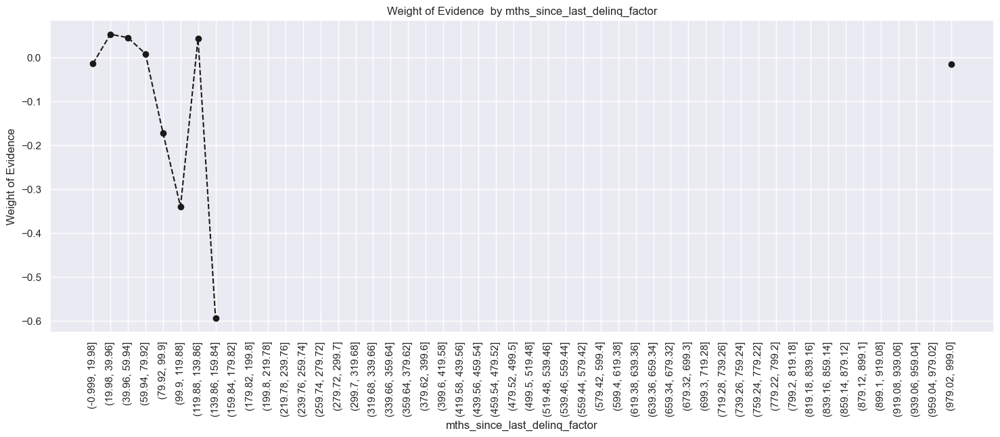

In [138]:
plot_by_woe(df_temp, 90)

In [139]:
f" first cat is 0 to 3 months, second  are the next 7 months from  4 to 30 mnths , from 31 to 56 months, from 56 months to 82 months , then 82 months\
but 82 has very few observations, doesnt make sense treat them separately so we add it to the interval of 56 months so last interval is >=  56 months"

' first cat is 0 to 3 months, second  are the next 7 months from  4 to 30 mnths , from 31 to 56 months, from 56 months to 82 months , then 82 monthsbut 82 has very few observations, doesnt make sense treat them separately so we add it to the interval of 56 months so last interval is >=  56 months'

In [140]:
df_inputs_prepr['mths_since_last_delinq:::Missing'] = np.where((df_inputs_prepr['mths_since_last_delinq'].isnull()),1,0)

df_inputs_prepr['mths_since_last_delinq:::0-3'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq']>=0) & (df_inputs_prepr['mths_since_last_delinq']<=4),1,0)

df_inputs_prepr['mths_since_last_delinq:::4-30'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq']>=4) & (df_inputs_prepr['mths_since_last_delinq']<=30),1,0)

df_inputs_prepr['mths_since_last_delinq:::31-56'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq']>=31) & (df_inputs_prepr['mths_since_last_delinq']<=56),1,0)

df_inputs_prepr['mths_since_last_delinq:::>57'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq'] >= 57), 1, 0) 

C:\ProgramData\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


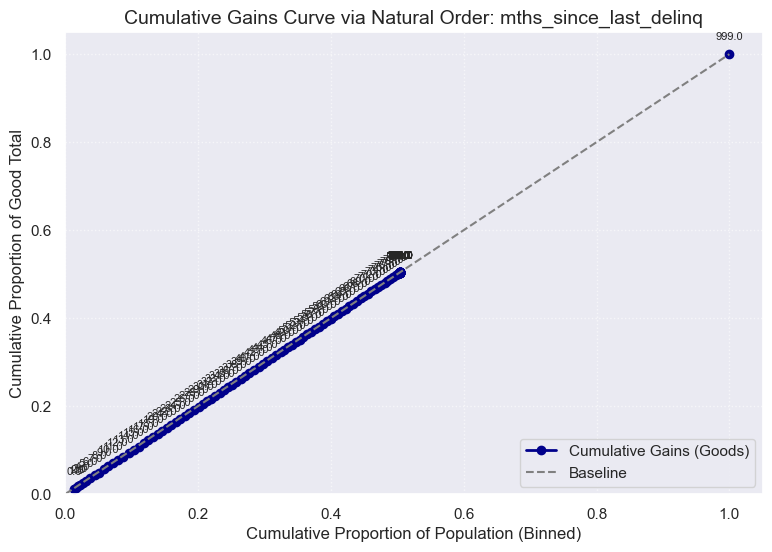

None None

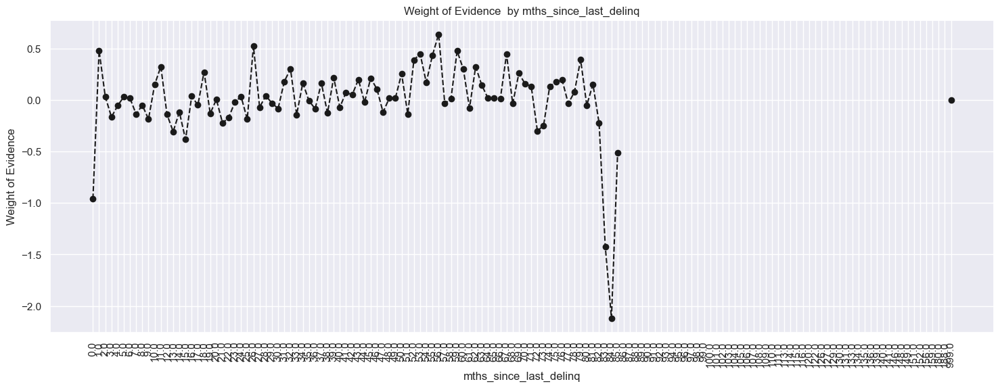

In [141]:
#  mths_since_last_delinq (53%) Missing = no delinquency

'''mths_since_last_delinq
Same 999-fill problem. Your bin 49 ((979, 999]) has the 53% missing observations piled up.
From your output rows 0–7: The WOE values are very small and not strongly monotonic, which means this variable has weak discriminatory power after 
controlling for other things. Still worth including because the Missing category is informative.'''


df_temp = woe_ordered_continuous(
    df_inputs_prepr_temp, 
    'mths_since_last_delinq', 
    df_targets_prepr[mask_has_record]
)

print(plot_cumulative_gains_from_woe(df_temp, 'mths_since_last_delinq'), plot_by_woe(df_temp, 90))

# Coarse classing — based on your output:

df_inputs_prepr['mths_since_last_delinq:::Missing'] = np.where(
    df_inputs_prepr['mths_since_last_delinq'] >= 999, 1, 0)

df_inputs_prepr['mths_since_last_delinq:::0-3'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq'] >= 0) & 
    (df_inputs_prepr['mths_since_last_delinq'] <= 3), 1, 0)

df_inputs_prepr['mths_since_last_delinq:::4-30'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq'] > 3) & 
    (df_inputs_prepr['mths_since_last_delinq'] <= 30), 1, 0)

df_inputs_prepr['mths_since_last_delinq:::31-56'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq'] > 30) & 
    (df_inputs_prepr['mths_since_last_delinq'] <= 56), 1, 0)

df_inputs_prepr['mths_since_last_delinq:::>56'] = np.where(
    (df_inputs_prepr['mths_since_last_delinq'] > 56) & 
    (df_inputs_prepr['mths_since_last_delinq'] < 999), 1, 0)

# Reference category: mths_since_last_delinq:::0-3 (most recently delinquent = highest risk baseline)

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\1450960132.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  loan_data['tot_cur_bal'].fillna(0, inplace=True)
C:\Users\USER\AppData\Local\Temp\ipykernel_11004\1450960132.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For examp

total_rev_hi_lim_factor  n_obs  prop_good  prop_n_obs   n_good   n_bad  \
0        (-0.001, 8200.0]  31855   0.880992    0.100577  28064.0  3791.0   
1       (8200.0, 11900.0]  32263   0.886898    0.101865  28614.0  3649.0   
2      (11900.0, 15200.0]  31112   0.886250    0.098231  27573.0  3539.0   
3      (15200.0, 18800.0]  31963   0.888465    0.100918  28398.0  3565.0   
4      (18800.0, 22800.0]  31188   0.893228    0.098471  27858.0  3330.0   
5      (22800.0, 27700.0]  32125   0.894319    0.101429  28730.0  3395.0   
6      (27700.0, 33900.0]  31271   0.898756    0.098733  28105.0  3166.0   
7      (33900.0, 42700.0]  31695   0.909796    0.100071  28836.0  2859.0   
8      (42700.0, 58600.0]  31631   0.915652    0.099869  28963.0  2668.0   
9    (58600.0, 9999999.0]  31621   0.934885    0.099838  29562.0  2059.0   

   prop_n_good  prop_n_bad       WoE    n_obs%  diff_prop_good  diff_WoE  \
0     0.098573    0.118391 -0.183197  0.100577             NaN       NaN   
1     0.100505    0.113956 -0.125612  0.101865        0.005906  0.057585   
2     0.096848    0.110521 -0.132062  0.098231        0.000649  0.006450   
3     0.099746    0.111333 -0.109900  0.100918        0.002215  0.022162   
4     0.097849    0.103994 -0.060907  0.098471        0.004763  0.048993   
5     0.100912    0.106024 -0.049416  0.101429        0.001091  0.011490   
6     0.098717    0.098873 -0.001576  0.098733        0.004437  0.047840   
7     0.101284    0.089285  0.126098  0.100071        0.011040  0.127674   
8     0.101731    0.083320  0.199635  0.099869        0.005856  0.073537   
9     0.103835    0.064302  0.479215  0.099838        0.019233  0.279579   

        IV  
0  0.03316  
1  0.03316  
2  0.03316  
3  0.03316  
4  0.03316  
5  0.03316  
6  0.03316  
7  0.03316  
8  0.03316  
9  0.03316

None

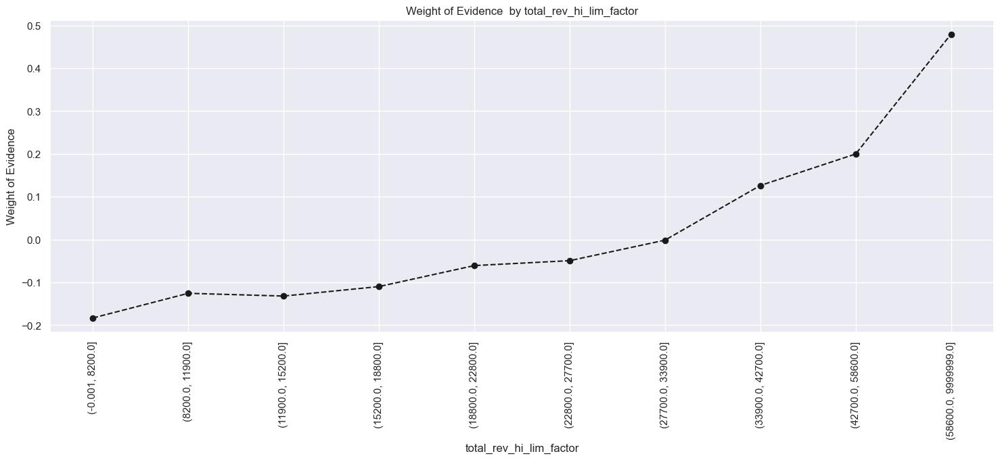

In [142]:
# tot_cur_bal, tot_coll_amt, total_rev_hi_lim (~15%). 🧠 Meaning: Financial capacity variables

loan_data['tot_cur_bal'].fillna(0, inplace=True)
loan_data['tot_coll_amt'].fillna(0, inplace=True)

'''total_rev_hi_lim = credit limit
funded_amnt = loan size

👉 If limit missing, loan amount is a proxy

total_rev_hi_lim
From your output: 99.7% of observations are in the first bin ((-9999, 199999]). 
This variable is extremely right-skewed — a few people have million-dollar credit limits. pd.cut(50) is useless here.
Correct fine classing: Use pd.qcut (quantile-based) instead of pd.cut (equal-width),
because equal-width bins all collapse into one bin when the data is this skewed.'''

df_inputs_prepr['total_rev_hi_lim_factor'] = pd.qcut(
    df_inputs_prepr['total_rev_hi_lim'], 
    q=10, 
    duplicates='drop'
)
df_temp = woe_ordered_continuous(
    df_inputs_prepr, 
    'total_rev_hi_lim_factor', 
    df_targets_prepr
)

print(df_temp)

print(plot_by_woe(df_temp, 90))

'''Coarse classing: The tutorial uses <=5k as one bin (very low credit limit = high risk) and then groups the rest. 
After seeing your quantile WOE output, likely groups will be around these thresholds:'''

df_inputs_prepr['total_rev_hi_lim:::<=5k'] = np.where(
    df_inputs_prepr['total_rev_hi_lim'] <= 5000, 1, 0)

df_inputs_prepr['total_rev_hi_lim:::5k-10k'] = np.where(
    (df_inputs_prepr['total_rev_hi_lim'] > 5000) & 
    (df_inputs_prepr['total_rev_hi_lim'] <= 10000), 1, 0)

df_inputs_prepr['total_rev_hi_lim:::10k-20k'] = np.where(
    (df_inputs_prepr['total_rev_hi_lim'] > 10000) & 
    (df_inputs_prepr['total_rev_hi_lim'] <= 20000), 1, 0)

df_inputs_prepr['total_rev_hi_lim:::20k-40k'] = np.where(
    (df_inputs_prepr['total_rev_hi_lim'] > 20000) & 
    (df_inputs_prepr['total_rev_hi_lim'] <= 40000), 1, 0)

df_inputs_prepr['total_rev_hi_lim:::>40k'] = np.where(
    df_inputs_prepr['total_rev_hi_lim'] > 40000, 1, 0)

#Reference category: total_rev_hi_lim:::<=5k (lowest credit limit = highest risk baseline).
#Run the qcut WOE first and adjust the thresholds to match where the WOE values change direction.



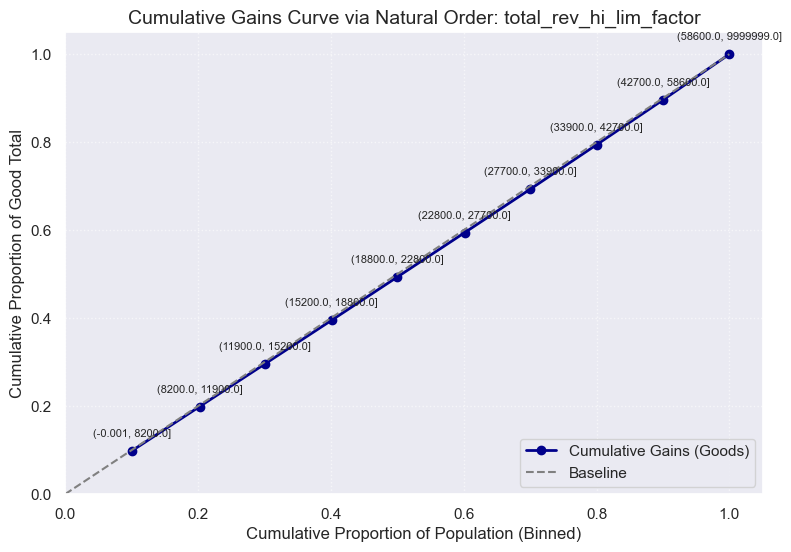

(None,)

In [143]:
plot_cumulative_gains_from_woe(df_temp, 'total_rev_hi_lim_factor'),

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\913642244.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  loan_data['dti'].fillna(999, inplace=True)
C:\ProgramData\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


dti  n_obs  prop_good  prop_n_obs  n_good  n_bad  prop_n_good  prop_n_bad  \
0  0.00    290   0.824138    0.000777   239.0   51.0     0.000719    0.001251   
1  0.01      9   0.777778    0.000024     7.0    2.0     0.000021    0.000049   
2  0.02      9   0.888889    0.000024     8.0    1.0     0.000024    0.000025   
3  0.03      3   1.000000    0.000008     3.0    0.0     0.000009    0.000000   
4  0.04      4   1.000000    0.000011     4.0    0.0     0.000012    0.000000   

        WoE    n_obs%  diff_prop_good  diff_WoE   IV  
0 -0.553107  0.000777             NaN       NaN  inf  
1 -0.844982  0.000024        0.046360  0.291875  inf  
2 -0.018303  0.000024        0.111111  0.826679  inf  
3       inf  0.000008        0.111111       inf  inf  
4       inf  0.000011        0.000000       NaN  inf

None

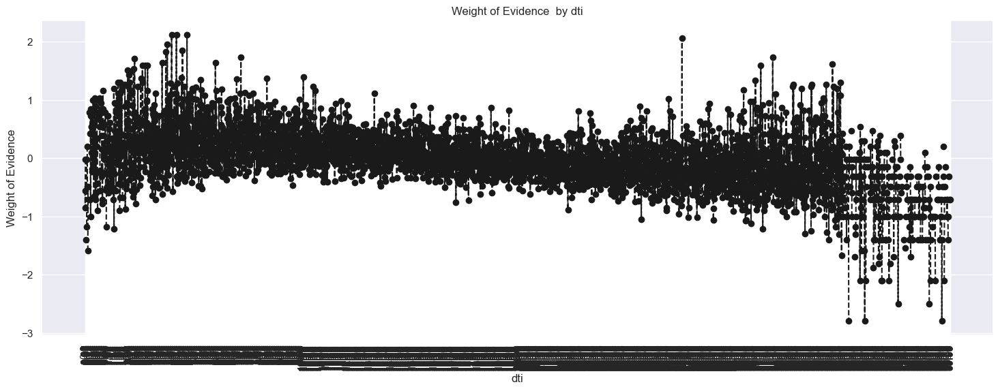

In [144]:
# mths_since_last_record (86% missing). 🧠 Meaning: Missing = never had public record 👉 999 = “never happened”

loan_data['dti_missing'] = loan_data['dti'].notna().astype(int)

'''Note on missing DTI: Your code says loan_data['dti_missing'] = loan_data['dti'].notna().astype(int) — 
this flag will be 1 for everyone who has DTI and 0 for missing, which is the wrong way round. It should be:'''

loan_data['dti_missing'] = loan_data['dti'].isna().astype(int)  # 1 = missing
loan_data['dti'].fillna(999, inplace=True)


'''Also DTI has very few missing values in this dataset (less than 1%), so you may not need the flag at all. 
Reference category: dti:::>30 (highest debt burden = highest risk baseline).'''

 
'''From your output: This is the best behaved variable of the group. The WOE is clearly monotonic — as DTI increases from 0 to 35, 
prop_good falls steadily from 0.91 down to 0.86. This is exactly what you want to see. pd.cut(50) is fine here, but 50 bins is more than needed. 
The trend is clear enough that 5–6 bins will capture it.'''

# Coarse classing — based on your output:

df_temp = woe_ordered_continuous(df_inputs_prepr, 'dti' , df_targets_prepr)
print(df_temp.head())
print(plot_by_woe(df_temp, 90))

df_inputs_prepr['dti:::<10']   = np.where(df_inputs_prepr['dti'] < 10, 1, 0)
df_inputs_prepr['dti:::10-20'] = np.where(
    (df_inputs_prepr['dti'] >= 10) & (df_inputs_prepr['dti'] < 20), 1, 0)
df_inputs_prepr['dti:::20-30'] = np.where(
    (df_inputs_prepr['dti'] >= 20) & (df_inputs_prepr['dti'] < 30), 1, 0)
df_inputs_prepr['dti:::>30']   = np.where(
    (df_inputs_prepr['dti'] >= 30) & (df_inputs_prepr['dti'] < 999), 1, 0)

**The general rule for when pd.cut(50) fails
Use pd.cut(n) when your variable is roughly uniformly distributed — like int_rate or annual_inc below $140k.
Use pd.qcut(n) when your variable is heavily skewed — like total_rev_hi_lim, tot_cur_bal, revol_bal.
Never use either when more than 50% of your data has been filled with a sentinel value like 999 — filter those rows out first, cut the real values, then create the Missing dummy**

                                    #**OTHER VARIABLES NOT YET DONE No. 35***



        Preprocess:

        mths_since_earliest_cr_line
        installment
        delinq_2yrs
        open_acc
        pub_rec
        total_acc
        acc_now_delinq
        ['policy_code', 'annual_inc_joint',  'dti_joint',...]

>For each decide whether to do fine classsing, or not . Run woe discrete and plot by woe , examine chart and data frame with results as argument , decide whether woe should be used for pd model , decide reference category
 preprocess installment as funded_amnt

**CREATING THE SAME VARIABLES FOR TESTING**

# CREATING THE SAME VARIABLES FOR TESTING 
                  # this wont require graphs since it is testing 
    > **we are for now interested in simply creating similar dummy variables as above** 
>>thats all
                                                            >>> nothing much

**NO GRAPH NO GRAPHS TESTING DATA PREPROCESSING**

**DUMMY VARIABLE PIPELINE FOR TESTING**

In [145]:
df_inputs_prepr_test = df_inputs_prepr_test.loc[:, ~df_inputs_prepr_test.columns.duplicated()]
df_inputs_prepr_test.columns[df_inputs_prepr_test.columns.duplicated()]

Index([], dtype='object')

In [146]:
print(f'{loan_data_inputs_test.shape}, {df_inputs_prepr_test.shape}')


(93257, 150), (93257, 150)

In [147]:

df_inputs_prepr_test['home_ownership:::RENT_OTHER_NONE_ANY'] = (
    df_inputs_prepr_test[['home_ownership:RENT',
                     'home_ownership:OTHER',
                     'home_ownership:NONE',
                     'home_ownership:ANY']].sum(axis=1)
)



    

In [148]:
df_inputs_prepr_test['home_ownership:::MORTGAGE'] =  df_inputs_prepr_test['home_ownership:MORTGAGE']
df_inputs_prepr_test['home_ownership:::OWN'] =  df_inputs_prepr_test['home_ownership:OWN']      

In [149]:

if 'addr_state:ND' in df_inputs_prepr_test.columns.values:
    pass
else:
    df_inputs_prepr_test.loc[:,'addr_state:ND'] = 0

    
df_inputs_prepr_test['addr_state:::NM_VA'] = sum([df_inputs_prepr_test['addr_state:NM'], df_inputs_prepr_test['addr_state:VA']])


df_inputs_prepr_test['addr_state:::ND_NE_IA_NV_FL_HI_AL'] = sum([pd.to_numeric(df_inputs_prepr_test['addr_state:ND']), 
                pd.to_numeric(df_inputs_prepr_test['addr_state:NE']), pd.to_numeric(df_inputs_prepr_test['addr_state:IA']), 
                pd.to_numeric(df_inputs_prepr_test['addr_state:NV']), pd.to_numeric(df_inputs_prepr_test['addr_state:FL']), 
                pd.to_numeric(df_inputs_prepr_test['addr_state:HI']), pd.to_numeric(df_inputs_prepr_test['addr_state:AL'])])    


states = ['OK','TN','MO','LA','MD','NC']
cols = [f"addr_state:{s}" for s in states]

# Ensure all are numeric
df_inputs_prepr_test[cols] = df_inputs_prepr_test[cols].apply(pd.to_numeric, errors='coerce')

# Create grouped dummy
df_inputs_prepr_test['addr_state:::OK_TN_MO_LA_MD_NC'] = df_inputs_prepr_test[cols].sum(axis=1)


# ============================================================================================================
cols = ['addr_state:GA', 'addr_state:WA', 'addr_state:OR']

df_inputs_prepr_test['addr_state:::GA_WA_OR'] = sum(
    [df_inputs_prepr_test[c].astype(float) for c in cols]
)

In [150]:

df_inputs_prepr_test['addr_state:::UT_KY_AZ_NJ'] = (
    df_inputs_prepr_test[['addr_state:UT', 'addr_state:KY', 'addr_state:AZ', 'addr_state:NJ']]
    .sum(axis=1)      # row-wise sum
)


df_inputs_prepr_test['addr_state:::WI_MT'] = (
    df_inputs_prepr_test[['addr_state:WI', 'addr_state:MT']].astype(float).sum(axis=1)
)



In [151]:
df_inputs_prepr_test['addr_state:::AR_MI_PA_OH_MN'] = (
    df_inputs_prepr_test['addr_state:AR'] +  df_inputs_prepr_test['addr_state:MI'] +  df_inputs_prepr_test['addr_state:PA'] + df_inputs_prepr_test['addr_state:OH']
    +  df_inputs_prepr_test['addr_state:MN']    
   
)


df_inputs_prepr_test['addr_state:::RI_MA_DE_SD_IN'] = (
    df_inputs_prepr_test['addr_state:RI'].astype(float)
    .add(df_inputs_prepr_test['addr_state:MA'].astype(float))
    .add(df_inputs_prepr_test['addr_state:DE'].astype(float))
    .add(df_inputs_prepr_test['addr_state:SD'].astype(float))
    .add(df_inputs_prepr_test['addr_state:IN'].astype(float))
)



In [152]:
df_inputs_prepr_test['addr_state:::IL_CT'] = (
    df_inputs_prepr_test[['addr_state:IL',
                     'addr_state:CT'
                     ]].sum(axis=1)
)



df_inputs_prepr_test['addr_state:::KS_SC_CO_VT_AK_MS'] = (
    df_inputs_prepr_test['addr_state:KS']
    + df_inputs_prepr_test['addr_state:SC']
    + df_inputs_prepr_test['addr_state:CO']          
    + df_inputs_prepr_test['addr_state:VT']
    + df_inputs_prepr_test['addr_state:AK']
    + df_inputs_prepr_test['addr_state:MS']
)


'''
df_inputs_prepr_test['addr_state:::WV_NH_WY_DC_ME_ID'] = (
   df_inputs_prepr_test[['addr_state:WV',
                     'addr_state:NH',
                     'addr_state:WY',
                     'addr_state:ME',
                     'addr_state:ID']].any(axis=1)
)

Every other group uses .sum(axis=1) but this one uses .any(). 
It returns booleans instead of integers. Depending on the downstream astype(int) it may or may not cause a silent error.'''


df_inputs_prepr_test['addr_state:::WV_NH_WY_DC_ME_ID'] = (
    df_inputs_prepr_test[['addr_state:WV', 'addr_state:NH', 
                           'addr_state:WY', 'addr_state:DC',
                           'addr_state:ME', 'addr_state:ID']].sum(axis=1)
)


**PREPROCESSING  for df_inputs_prepr_test**

In [153]:
df_inputs_prepr_test['term_int'] = (df_inputs_prepr_test['term'].str.replace(r'\+ months', '',regex=True).str.replace('< 1 month', str(0))
                                  .str.replace('n/a', str(0))
                                  .str.replace(r"months?|[+]", "", regex=True)
                                    .fillna(0).replace(np.nan, 0)
                                                                           
                                 )




df_inputs_prepr_test['term:::36'] = np.where(df_inputs_prepr_test['term_int'] == 36, 1, 0) 
df_inputs_prepr_test['term:::60'] = np.where((df_inputs_prepr_test['term_int'] == 60), 1, 0) 
#this continuous variable was easy, no need to carry out fine classing or coarse


df_inputs_prepr_test['term:::36'] = (df_inputs_prepr_test['term'] == 36).astype('uint8')
df_inputs_prepr_test['term:::60'] = (df_inputs_prepr_test['term'] == 60).astype('uint8')


In [154]:
df_inputs_prepr_test['term_int'] = (df_inputs_prepr_test['term'].str.replace(r'\+ months', '',regex=True).str.replace('< 1 month', str(0))
                                  .str.replace('n/a', str(0))
                                  .str.replace(r"months?|[+]", "", regex=True)
                                    .fillna(0).replace(np.nan, 0)
                                                                           
                                 )




df_inputs_prepr_test['term:::36'] = np.where(df_inputs_prepr_test['term_int'] == 36, 1, 0) 
df_inputs_prepr_test['term:::60'] = np.where((df_inputs_prepr_test['term_int'] == 60), 1, 0) 
#this continuous variable was easy, no need to carry out fine classing or coarse


In [155]:
# Above are 2 categories/dummy variables for the term in the final model.  60 will be the reference point. 60 loans are riskier than 36 month loan
#Time to name our dummy variables similar to how we named our discrete using the convention, **Original variable Name Colon Category Name**

df_inputs_prepr_test['emp_zero'] = df_inputs_prepr_test['emp_length'].isin([0]).astype('uint8')


# df_inputs_prepr['emp_length:0'] = np.where(df_inputs_prepr['emp_length'] ==0, 1, 0) 
df_inputs_prepr_test['emp_length:::0'] = np.where(df_inputs_prepr_test['emp_length'].isin([0]), 1, 0)
df_inputs_prepr_test['emp_length:::1'] = np.where(df_inputs_prepr_test['emp_length'].isin([1]), 1, 0)
df_inputs_prepr_test['emp_length:::2-4'] = np.where(df_inputs_prepr_test['emp_length'].isin(range(2,5)), 1, 0) # this is similar to coarse classing
df_inputs_prepr_test['emp_length:::5-6'] = np.where(df_inputs_prepr_test['emp_length'].isin(range(5,7)), 1, 0)
df_inputs_prepr_test['emp_length:::7-9'] = np.where(df_inputs_prepr_test['emp_length'].isin(range(7,10)), 1, 0)
df_inputs_prepr_test['emp_length:::10'] = np.where(df_inputs_prepr_test['emp_length'].isin([10]), 1, 0)


 **Data Preparation. Preprocessing continuous: Creating Dummy Variables, part 2**
                        

In [156]:
#FACTOR IS COMMON TERM TO MEAN VARIABLE IS CATEGORICAL

f'This here is fine classing'

df_inputs_prepr_test['mths_since_issue_d_factor'] = pd.cut(df_inputs_prepr_test['mths_since_issue_d'], bins = 50)


df_inputs_prepr_test['mths_since_issue_d_factor'] = pd.cut(df_inputs_prepr_test['mths_since_issue_d'], 50)


In [157]:

'''
Bug: mths_since_issue_d uses .isin() instead of range comparisons for most bins
# WRONG — isin([49,52]) only matches exactly 49 or 52, skips 50 and 51
df_inputs_prepr_test['mths_since_issue_d:::49-52'] = np.where(
    df_inputs_prepr_test['mths_since_issue_d'].isin([49, 52]), 1, 0)

# WRONG — isin([53,63]) only matches 53 or 63, skips 54-62
df_inputs_prepr_test['mths_since_issue_d:::53-63'] = np.where(
    df_inputs_prepr_test['mths_since_issue_d'].isin([53, 63]), 1, 0)

# WRONG — isin([64,85]) only matches 64 or 85, skips 65-84
df_inputs_prepr_test['mths_since_issue_d:::64-85'] = np.where(
    df_inputs_prepr_test['mths_since_issue_d'].isin([64, 85]), 1, 0)

These bins capture almost no observations. For example 49-52 should capture 4 values but only catches 2.
    '''

df_inputs_prepr_test['mths_since_issue_d:::<38'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin(range(37)), 1,0)
df_inputs_prepr_test['mths_since_issue_d:::38-39'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin([38,39]), 1,0)
df_inputs_prepr_test['mths_since_issue_d:::40-41'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin([40,41]), 1,0)
df_inputs_prepr_test['mths_since_issue_d:::42-48'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin(range(42,48)), 1,0)

# df_inputs_prepr_test['mths_since_issue_d:::49-52'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin([49,52]), 1,0)
df_inputs_prepr_test['mths_since_issue_d:::49-52'] = np.where(
    (df_inputs_prepr_test['mths_since_issue_d'] >= 49) & 
    (df_inputs_prepr_test['mths_since_issue_d'] <= 52), 1, 0)


#df_inputs_prepr_test['mths_since_issue_d:::53-63'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin([53,63]), 1,0)
df_inputs_prepr_test['mths_since_issue_d:::53-63'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin(range(53,64)), 1,0)

# df_inputs_prepr_test['mths_since_issue_d:::64-85'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin((64,85)), 1,0)
df_inputs_prepr_test['mths_since_issue_d:::64-85'] = np.where(df_inputs_prepr_test['mths_since_issue_d'].isin(range(64,86)), 1,0)

df_inputs_prepr_test['mths_since_issue_d:::>85'] = np.where(df_inputs_prepr_test['mths_since_issue_d']>85, 1,0)

In [158]:
df_inputs_prepr_test['int_rate:::<9.548'] = np.where((df_inputs_prepr_test['int_rate'] <= 9.548), 1,0)
df_inputs_prepr_test['int_rate:::9.548-12.025'] = np.where((df_inputs_prepr_test['int_rate'] >9.548) & (df_inputs_prepr_test['int_rate'] <= 12.025), 1,0)
df_inputs_prepr_test['int_rate:::12.025-15.74'] = np.where((df_inputs_prepr_test['int_rate'] >12.025) & (df_inputs_prepr_test['int_rate'] <= 15.74), 1,0)
df_inputs_prepr_test['int_rate:::15.74-20.281'] = np.where((df_inputs_prepr_test['int_rate'] >15.74) & (df_inputs_prepr_test['int_rate'] <= 20.281),1,0)
df_inputs_prepr_test['int_rate:::>20.281'] = np.where((df_inputs_prepr_test['int_rate'] >20.281), 1,0)


In [159]:

df_inputs_prepr_test['annual_inc:::<20k'] = np.where((df_inputs_prepr_test['annual_inc'] <= 20000), 1,0)
df_inputs_prepr_test['annual_inc:::20k-30k'] = np.where((df_inputs_prepr_test['annual_inc'] > 20000) & (df_inputs_prepr_test['annual_inc'] <=30000), 1,0)
df_inputs_prepr_test['annual_inc:::30k-40k'] = np.where((df_inputs_prepr_test['annual_inc'] > 30000) & (df_inputs_prepr_test['annual_inc'] <=40000), 1,0)
df_inputs_prepr_test['annual_inc:::40k-50k'] = np.where((df_inputs_prepr_test['annual_inc'] > 40000) & (df_inputs_prepr_test['annual_inc'] <=50000), 1,0)
df_inputs_prepr_test['annual_inc:::50k-60k'] = np.where((df_inputs_prepr_test['annual_inc'] > 50000) & (df_inputs_prepr_test['annual_inc'] <=60000), 1,0)
df_inputs_prepr_test['annual_inc:::60k-70k'] = np.where((df_inputs_prepr_test['annual_inc'] > 60000) & (df_inputs_prepr_test['annual_inc'] <=70000), 1,0)
df_inputs_prepr_test['annual_inc:::70k-80k'] = np.where((df_inputs_prepr_test['annual_inc'] > 70000) & (df_inputs_prepr_test['annual_inc'] <=80000), 1,0)
df_inputs_prepr_test['annual_inc:::80k-90k'] = np.where((df_inputs_prepr_test['annual_inc'] > 80000) & (df_inputs_prepr_test['annual_inc'] <=90000), 1,0)
df_inputs_prepr_test['annual_inc:::90k-100k'] = np.where((df_inputs_prepr_test['annual_inc'] > 90000) & (df_inputs_prepr_test['annual_inc'] <=100000), 1,0)
df_inputs_prepr_test['annual_inc:::100k-120k'] = np.where((df_inputs_prepr_test['annual_inc'] > 100000) & (df_inputs_prepr_test['annual_inc'] <=120000), 1,0)
df_inputs_prepr_test['annual_inc:::120k-140k'] = np.where((df_inputs_prepr_test['annual_inc'] > 120000) & (df_inputs_prepr_test['annual_inc'] <=140000), 1,0)
df_inputs_prepr_test['annual_inc:::>140k'] = np.where((df_inputs_prepr_test['annual_inc'] >= 140000), 1,0)


In [160]:
df_inputs_prepr_test['mths_since_last_delinq:::Missing'] = np.where((df_inputs_prepr_test['mths_since_last_delinq'].isnull()),1,0)

df_inputs_prepr_test['mths_since_last_delinq:::0-3'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq']>=0) & (df_inputs_prepr_test['mths_since_last_delinq']<=4),1,0)

df_inputs_prepr_test['mths_since_last_delinq:::4-30'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq']>=4) & (df_inputs_prepr_test['mths_since_last_delinq']<=30),1,0)

df_inputs_prepr_test['mths_since_last_delinq:::31-56'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq']>=31) & (df_inputs_prepr_test['mths_since_last_delinq']<=56),1,0)

df_inputs_prepr_test['mths_since_last_delinq:::>57'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq'] >= 57), 1, 0) 

In [161]:
# ALTERNATIVELY WE COULD for some CONTINUOUS VARIABLES 

bins = [
    0,
    5000,
    10000,
    20000,
    30000,
    np.inf
]

labels = [
    'funded:very_low',
    'funded:low',
    'funded:medium',
    'funded:high',
    'funded:very_high'
]

df_inputs_prepr_test['funded_amnt_grp'] = pd.cut(
    df_inputs_prepr_test['funded_amnt'],
    bins=bins,
    labels=labels
)






In [162]:
# 1. Ensure column exists
assert 'funded_amnt_grp' in df_inputs_prepr.columns

# 2. Ensure it is categorical
df_inputs_prepr_test['funded_amnt_grp'] = df_inputs_prepr_test['funded_amnt_grp'].astype('category')

# 3. Add Missing to allowed categories
df_inputs_prepr_test['funded_amnt_grp'] = (
    df_inputs_prepr_test['funded_amnt_grp']
        .cat.add_categories(['Missing'])
        .fillna('Missing')
)

# 4. Create dummies
funded_dummies = pd.get_dummies(
    df_inputs_prepr_test['funded_amnt_grp'],
    prefix='funded',
    prefix_sep=':::',
    drop_first=True
)

# 5. Join back
df_inputs_prepr_test = pd.concat([df_inputs_prepr_test, funded_dummies], axis=1)


In [163]:
# 1. Ensure column exists
assert 'funded_amnt_grp' in df_inputs_prepr.columns

# 2. Force everything to string and handle missing
df_inputs_prepr_test['funded_amnt_grp'] = (
    df_inputs_prepr_test['funded_amnt_grp']
        .astype(str)
        .replace('nan', 'Missing')   # important: astype(str) turns NaN into 'nan'
)

# 3. Create dummies
funded_dummies = pd.get_dummies(
    df_inputs_prepr_test['funded_amnt_grp'],
    prefix='funded',
    prefix_sep=':::',
    drop_first=True
)

# 4. Join back
# df_inputs_prepr = pd.concat([df_inputs_prepr, funded_dummies], axis=1)

funded_dummies.head()


,funded:::funded:low,funded:::funded:medium,funded:::funded:very_high,funded:::funded:very_low
362514,False,False,True,False
288564,False,True,False,False
213591,False,False,False,False
263083,False,True,False,False
165001,False,True,False,False


In [164]:
df_inputs_prepr_test['funded_amnt_factor'] = pd.cut(df_inputs_prepr_test['funded_amnt'], 50)

In [165]:
df_inputs_prepr_test['annual_inc_q'] = pd.qcut(
    df_inputs_prepr_test['annual_inc'],
    q=10,
    duplicates='drop'
)

In [166]:
f"again first cat has a large number of observations 62% of all observations, in common logic this is kinda expected, There are few people with large\
income so good idea to set aside people with high income in one dummy variable and investigate the lower income separately\
the first 2 categories contain a lot of observations while each of te subsequent categories  contains very few observations\
the higher the incone the lower the number of observations Third category starts at 144693, so lets assume  $140,000 to be the threshold btn low and high\
this way high income category will have observations a bit more than 5% of the observations \
Now let's focus on people with lower income, for convenience we will store them in  a temporary df"



#df_inputs_prepr_temp =  df_inputs_prepr[df_inputs_prepr['annual_inc'].loc(df_inputs_prepr['annual_inc'] <= 140000)] wrong coz loc is on series on a df


# df_inputs_prepr_test =  df_inputs_prepr_test.loc[df_inputs_prepr_test['annual_inc'] <= 140000] 
'''
That line filters rows where annual_inc <= 140000, removing about 5,567 rows (93257 - 87690 = 5567). So the drop is intentional due to income filtering.

However, the user likely expects the test set to retain all rows. This filtering was applied to the test set but not to the training set, 
causing a mismatch in row counts and potentially misalignment when evaluating.

The user also notes that earlier df_inputs_prepr_test.shape was (93257, 256) and later becomes (87690, 256). The reduction is solely due to the income 
filter.

Thus the answer should point out this line and recommend removing it unless there's a specific business reason to exclude high-income borrowers from 
the test set.

Also note that the training set (df_inputs_prepr) was not filtered, so the model was trained on all incomes but tested only on incomes ≤140k, which is
inconsistent.

The user also has a line df_inputs_prepr_test = df_inputs_prepr_test.loc[df_inputs_prepr_test['annual_inc'] <= 140000] but later they define df_inputs_prepr_temp which is unused. The filter should be removed or applied consistently.
'''

#df_inputs_prepr_temp =  df_inputs_prepr.loc[df_inputs_prepr['annual_inc'] <= 140000, :]

df_inputs_prepr_test['annual_inc_factor'] = pd.cut(df_inputs_prepr_temp['annual_inc'], 50)




In [167]:
df_inputs_prepr_test['int_rate_factor'] = pd.cut(df_inputs_prepr_test['int_rate'], 50)


In [168]:


df_inputs_prepr_test['mths_since_last_record:::Missing'] = np.where(
    df_inputs_prepr_test['mths_since_last_record'] >= 999, 1, 0)

df_inputs_prepr_test['mths_since_last_record:::0-12'] = np.where(
    (df_inputs_prepr_test['mths_since_last_record'] >= 0) & 
    (df_inputs_prepr_test['mths_since_last_record'] <= 12), 1, 0)

df_inputs_prepr_test['mths_since_last_record:::13-37'] = np.where(
    (df_inputs_prepr_test['mths_since_last_record'] > 12) & 
    (df_inputs_prepr_test['mths_since_last_record'] <= 37), 1, 0)

df_inputs_prepr_test['mths_since_last_record:::38-75'] = np.where(
    (df_inputs_prepr_test['mths_since_last_record'] > 37) & 
    (df_inputs_prepr_test['mths_since_last_record'] <= 75), 1, 0)

df_inputs_prepr_test['mths_since_last_record:::76-130'] = np.where(
    (df_inputs_prepr_test['mths_since_last_record'] > 75) & 
    (df_inputs_prepr_test['mths_since_last_record'] <= 130), 1, 0)

In [169]:


df_inputs_prepr_test['mths_since_last_major_derog:::Missing'] = np.where(
    df_inputs_prepr_test['mths_since_last_major_derog'] >= 999, 1, 0)

df_inputs_prepr_test['mths_since_last_major_derog:::0-20'] = np.where(
    (df_inputs_prepr_test['mths_since_last_major_derog'] >= 0) & 
    (df_inputs_prepr_test['mths_since_last_major_derog'] <= 20), 1, 0)

df_inputs_prepr_test['mths_since_last_major_derog:::21-41'] = np.where(
    (df_inputs_prepr_test['mths_since_last_major_derog'] > 20) & 
    (df_inputs_prepr_test['mths_since_last_major_derog'] <= 41), 1, 0)

df_inputs_prepr_test['mths_since_last_major_derog:::42-62'] = np.where(
    (df_inputs_prepr_test['mths_since_last_major_derog'] > 41) & 
    (df_inputs_prepr_test['mths_since_last_major_derog'] <= 62), 1, 0)

df_inputs_prepr_test['mths_since_last_major_derog:::>62'] = np.where(
    (df_inputs_prepr_test['mths_since_last_major_derog'] > 62) & 
    (df_inputs_prepr_test['mths_since_last_major_derog'] < 999), 1, 0)

# Reference category: mths_since_last_major_derog:::Missing.




In [170]:


df_inputs_prepr_test['mths_since_last_delinq:::Missing'] = np.where(
    df_inputs_prepr_test['mths_since_last_delinq'] >= 999, 1, 0)

df_inputs_prepr_test['mths_since_last_delinq:::0-3'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq'] >= 0) & 
    (df_inputs_prepr_test['mths_since_last_delinq'] <= 3), 1, 0)

df_inputs_prepr_test['mths_since_last_delinq:::4-30'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq'] > 3) & 
    (df_inputs_prepr_test['mths_since_last_delinq'] <= 30), 1, 0)

df_inputs_prepr_test['mths_since_last_delinq:::31-56'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq'] > 30) & 
    (df_inputs_prepr_test['mths_since_last_delinq'] <= 56), 1, 0)

df_inputs_prepr_test['mths_since_last_delinq:::>56'] = np.where(
    (df_inputs_prepr_test['mths_since_last_delinq'] > 56) & 
    (df_inputs_prepr_test['mths_since_last_delinq'] < 999), 1, 0)

# Reference category: mths_since_last_delinq:::0-3 (most recently delinquent = highest risk baseline)

In [171]:


df_inputs_prepr_test['total_rev_hi_lim:::<=5k'] = np.where(
    df_inputs_prepr_test['total_rev_hi_lim'] <= 5000, 1, 0)

df_inputs_prepr_test['total_rev_hi_lim:::5k-10k'] = np.where(
    (df_inputs_prepr_test['total_rev_hi_lim'] > 5000) & 
    (df_inputs_prepr_test['total_rev_hi_lim'] <= 10000), 1, 0)

df_inputs_prepr_test['total_rev_hi_lim:::10k-20k'] = np.where(
    (df_inputs_prepr_test['total_rev_hi_lim'] > 10000) & 
    (df_inputs_prepr_test['total_rev_hi_lim'] <= 20000), 1, 0)

df_inputs_prepr_test['total_rev_hi_lim:::20k-40k'] = np.where(
    (df_inputs_prepr_test['total_rev_hi_lim'] > 20000) & 
    (df_inputs_prepr_test['total_rev_hi_lim'] <= 40000), 1, 0)

df_inputs_prepr_test['total_rev_hi_lim:::>40k'] = np.where(
    df_inputs_prepr_test['total_rev_hi_lim'] > 40000, 1, 0)

#Reference category: total_rev_hi_lim:::<=5k (lowest credit limit = highest risk baseline).
#Run the qcut WOE first and adjust the thresholds to match where the WOE values change direction.



In [172]:
df_inputs_prepr_test['dti:::<10']   = np.where(df_inputs_prepr_test['dti'] < 10, 1, 0)
df_inputs_prepr_test['dti:::10-20'] = np.where(
    (df_inputs_prepr_test['dti'] >= 10) & (df_inputs_prepr_test['dti'] < 20), 1, 0)
df_inputs_prepr_test['dti:::20-30'] = np.where(
    (df_inputs_prepr_test['dti'] >= 20) & (df_inputs_prepr_test['dti'] < 30), 1, 0)
df_inputs_prepr_test['dti:::>30']   = np.where(
    (df_inputs_prepr_test['dti'] >= 30) & (df_inputs_prepr_test['dti'] < 999), 1, 0)

**The general rule for when pd.cut(50) fails
Use pd.cut(n) when your variable is roughly uniformly distributed — like int_rate or annual_inc below $140k.
Use pd.qcut(n) when your variable is heavily skewed — like total_rev_hi_lim, tot_cur_bal, revol_bal.
Never use either when more than 50% of your data has been filled with a sentinel value like 999 — filter those rows out first, cut the real values, then create the Missing dummy**

In [173]:
(set(df_inputs_prepr_test) - set(df_inputs_prepr))

{'emp_zero'}

In [174]:
(set(df_inputs_prepr) - set(df_inputs_prepr_test))

{'emp_length:::Missing', 'total_rev_hi_lim_factor'}

In [175]:
len(df_inputs_prepr.columns.values), len(df_inputs_prepr_test.columns.values)

(236, 235)

In [176]:
sorted(df_inputs_prepr.columns.values) == sorted(df_inputs_prepr_test.columns.values),\
set(df_inputs_prepr.columns.values) == set(df_inputs_prepr_test.columns.values),

(False, False)

In [177]:
len(loan_data_inputs_train.columns.values)

150

In [178]:
len(df_inputs_prepr.columns.values), df_inputs_prepr.columns.values

(236,
 array(['Unnamed: 0', 'id', 'member_id', 'loan_amnt', 'funded_amnt',
        'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade',
        'sub_grade', 'emp_title', 'emp_length', 'home_ownership',
        'annual_inc', 'verification_status', 'issue_d', 'loan_status',
        'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code',
        'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
        'inq_last_6mths', 'mths_since_last_delinq',
        'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
        'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
        'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
        'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee',
        'recoveries', 'collection_recovery_fee', 'last_pymnt_d',
        'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d',
        'collections_12_mths_ex_med', 'mths_since_last_major_derog',
        'policy_code', 'application_type', 'acc_now_delinq',
      

In [179]:
print(f'{loan_data_inputs_test.shape}, {df_inputs_prepr_test.shape}')

(93257, 150), (93257, 235)

**DATA PREPARATION FOR TRAINING AND TESTING:**  This where we change train and test data from...

In [180]:
# We are going to effortlessly do this by assignining df inputs  preprosseing to be equal to the laon data inputs test instead or loan data inputs train and then rerun the whole code
f"Please note that WOE will be calculated and visualised . but we dont care about it , so we will simply ignore the outputs of these steps"

'''but carefully not to overwrite the variables we used to train the model. Hence we need to first save the train dataset ..'''

#loan_data_inputs_train = df_inputs_prepr 
# NOW Both contain the same preprocessed training set data 

''' 
When running the test data we change to '''
# loan_data_inputs_test = df_inputs_prepr #this will contain all the test data needed with all the dummy variables needed for the model

f'in the end , loan_data_targets_train and loan_data_targets_test will contain the corresponding outputs'


'in the end , loan_data_targets_train and loan_data_targets_test will contain the corresponding outputs'

In [181]:

# **FOR TRAINING** # comment out above when testing 

'''
IN FUTURE WE WILL CALL IT <<RIGHT FROM loan_data_inputs_train, loan_data_inputs_test, loan_data_targets_train, loan_data_targets_test =\
train_test_split(loan_data.drop('good_bad',axis=1), loan_data['good_bad'], test_size=.2, random_state=42)

We are going to effortlessly do this by assignining df inputs  preprosseing to be equal to the laon data inputs test instead or loan data inputs train and then rerun the whole code
f"Please note that WOE will be calculated and visualise
>> IF IT WILL MAKE SENSE 

loan_data_inputs_train_prepr = df_inputs_prepr
loan_data_targets_train_prepr = df_targets_prepr
'''

loan_data_inputs_train = df_inputs_prepr
loan_data_targets_train = df_targets_prepr

print(f'{loan_data_inputs_train.shape=}, {df_inputs_prepr.shape=}')


loan_data_inputs_train.shape=(373028, 236), df_inputs_prepr.shape=(373028, 236)

In [182]:
# **FOR TESTING WE ARE GONNA USE THIS TO CREATE OUR TESTING PIPELINE** 

'''
IN FUTURE WE WILL CALL IT <<RIGHT FROM loan_data_inputs_train, loan_data_inputs_test, loan_data_targets_train, loan_data_targets_test =\
train_test_split(loan_data.drop('good_bad',axis=1), loan_data['good_bad'], test_size=.2, random_state=42)

We are going to effortlessly do this by assignining df inputs  preprosseing to be equal to the laon data inputs test instead or loan data inputs train and then rerun the whole code
f"Please note that WOE will be calculated and visualise
>> IF IT WILL MAKE SENSE 

loan_data_inputs_test_prepr = df_inputs_prepr
loan_data_targets_test_prepr = df_targets_prepr
'''
print(f'{loan_data_inputs_test.shape}, {df_inputs_prepr_test.shape}')

loan_data_inputs_test = df_inputs_prepr_test
print(f'{loan_data_inputs_test.shape}, {df_inputs_prepr_test.shape}')
loan_data_targets_test = df_targets_prepr_test



(93257, 150), (93257, 235)

(93257, 235), (93257, 235)

In [183]:
# ***Export all these dataframes and store them in CSV files***

# loan_data_inputs_train.to_csv('loan_data_inputs_train.csv')
loan_data_inputs_train.to_pickle('loan_data_inputs_train.pkl') #CSV loses some information (like exact data types). To preserve them, use pickle.

# loan_data_targets_train.to_csv('loan_data_targets_train.csv
loan_data_targets_train.to_pickle('loan_data_targets_train.pkl')
                               
# loan_data_inputs_test.to_csv('loan_data_inputs_test.csv')
loan_data_inputs_test.to_pickle('loan_data_inputs_test.pkl')
                               
# loan_data_targets_test.to_csv('loan_data_targets_test.csv')
loan_data_targets_test.to_pickle('loan_data_targets_test.pkl')



**PD MODEL ESTIMATION**

**FEATURE ENGINEERING, Selecting Features for PD model estimation**

In [184]:

# METHOD 2 TO MATCH COLUMNS 

# 1. First, check what columns exist in both
common_cols = list(set(loan_data_inputs_train.columns) & set(loan_data_inputs_test.columns))

print(f"Columns in train: {len(loan_data_inputs_train.columns)}")
print(f"Columns in test: {len(loan_data_inputs_test.columns)}")
print(f"Common columns: {len(common_cols)}\n\n")




# METHOD 1 TO MATCH COLUMNS. here we create a new variable so as not to change the original data in loan_data_inputs_train and loan_data_inputs_test
''' Therefore from then on we use inputs test to create inputs_test_with_ref_cat, etc '''

# Force test to match train (since from check they definitely dont match)

loan_data_inputs_test = loan_data_inputs_test.reindex(
    columns=loan_data_inputs_train.columns,
    fill_value=0
)

print(f"loan_data_inputs_train = loan_data_inputs_test: {len(loan_data_inputs_test.columns)} == {len(loan_data_inputs_train.columns)}")



# WE CAN TEST BOTH TO SEE WHICH GIVES A MORE ACCURATE PREDICTION



Columns in train: 236

Columns in test: 235

Common columns: 234

loan_data_inputs_train = loan_data_inputs_test: 236 == 236

**Dummy Variables**

✅ Correct continuous_vars for Loans 2007–2015

| Variable family       | Example column names                                  | Why NOT dummy           |
| --------------------- | ----------------------------------------------------- | ----------------------- |
| Employment length     | `emp_length_int`, `emp_length:0`, `emp_length:1`, …   | Ordered numeric meaning |
| Interest rate         | `int_rate`, `int_rate:>20.281`                        | Numeric risk driver     |
| Term                  | `term_int`, `term:36`, `term:60`                      | Ordinal duration        |
| Annual income         | `annual_inc`, `annual_inc:<20k`, `annual_inc:60k-70k` | Magnitude matters       |
| Debt-to-income        | `dti`, `dti:>35`                                      | Continuous risk         |
| Issue date age        | `mths_since_issue_d`, `mths_since_issue_d:>84`        | Time since event        |
| Credit history length | `mths_since_earliest_cr_line`, `<140` bins            | Numeric aging           |
| Delinquencies         | `delinq_2yrs`, `delinq_2yrs:>4`                       | Count severity          |
| Inquiries             | `inq_last_6mths`, `inq_last_6mths:>6`                 | Count intensity         |
| Open accounts         | `open_acc`, `open_acc:0`                              | Numeric exposure        |
| Public records        | `pub_rec`, `pub_rec:0-2`                              | Count-based             |
| Revolving limits      | `total_rev_hi_lim`, `<=5k`                            | Exposure size           |
| Last delinquency      | `mths_since_last_delinq`, `0-3`, `4-30`               | Ordered time            |
| Last record           | `mths_since_last_record`, `0-2`                       | Ordered time            |


In [185]:

# 2. Find dummy variables from COMMON columns only <<selects only columns that are existing in both train and tests>>

dummy_vars = [
    col for col in common_cols
    if ':::' in col
    and loan_data_inputs_train[col].dropna().isin([0, 1]).all()
]



# 1. Ensuring that all columns that exits in inputs train are available in inputs test 

dummy_vars = [
    col for col in loan_data_inputs_train
    if ':::' in col
    and loan_data_inputs_train[col].dropna().isin([0, 1]).all()
]

print(f"Dummy variables found: {len(dummy_vars)}, \nlist of current dummy variables found {sorted(dummy_vars)}\n\n")




continuous_vars = [
    'emp_length_int',
    'term_int',
    'int_rate',
    'annual_inc',
    'dti',
    'mths_since_issue_d',
    'mths_since_earliest_cr_line',
    'delinq_2yrs',
    'inq_last_6mths',
    'open_acc',
    'pub_rec',
    'total_rev_hi_lim',
    'mths_since_last_delinq',
    'mths_since_last_record'
]

dummy_vars = [c for c in dummy_vars if c not in continuous_vars]




# We are creating a new dataframe called inputs_train_with_ref_cat to store only the dummy variables that we are going to use for the PD model.

# option 1 inputs_train_with_ref_cat = loan_data_inputs_train.loc[:, ['policy_code', 'annual_inc_joint',  'dti_joint',...]]


# Selecting only the dummy variables we want option 2

inputs_train_with_ref_cat = (
    loan_data_inputs_train.loc[:, dummy_vars]
    .apply(pd.to_numeric, errors='coerce')  # ← kills categorical safely    
    .fillna(0)   # <-- CRITICAL
    .astype(int)
)



# inputs_test_with_ref_cat  = loan_data_inputs_test.loc[:, dummy_vars] METHOD BELOW BETTER 

# Force test to match train
inputs_test_with_ref_cat = (
    loan_data_inputs_test
    .reindex(columns=inputs_train_with_ref_cat.columns)
    #.reindex(columns=inputs_train_with_ref_cat.columns, fill_value=0)
    
    .apply(pd.to_numeric, errors='coerce')  # ← kills categorical safely
    #.fillna(0)   # <-- CRITICAL
    .astype(int)
)


print(inputs_train_with_ref_cat.apply(
    lambda x: x.dropna().isin([0, 1]).all()
).all())



print(f"✓ Train shape: {inputs_train_with_ref_cat.shape}")
print(f"✓ Test shape: {inputs_test_with_ref_cat.shape}")



Dummy variables found: 104, 
list of current dummy variables found ['addr_state:::AR_MI_PA_OH_MN', 'addr_state:::GA_WA_OR', 
'addr_state:::IL_CT', 'addr_state:::KS_SC_CO_VT_AK_MS', 'addr_state:::ND_NE_IA_NV_FL_HI_AL', 'addr_state:::NM_VA', 
'addr_state:::OK_TN_MO_LA_MD_NC', 'addr_state:::RI_MA_DE_SD_IN', 'addr_state:::UT_KY_AZ_NJ', 'addr_state:::WI_MT', 
'addr_state:::WV_NH_WY_DC_ME_ID', 'annual_inc:::100k-120k', 'annual_inc:::120k-140k', 'annual_inc:::20k-30k', 
'annual_inc:::30k-40k', 'annual_inc:::40k-50k', 'annual_inc:::50k-60k', 'annual_inc:::60k-70k', 
'annual_inc:::70k-80k', 'annual_inc:::80k-90k', 'annual_inc:::90k-100k', 'annual_inc:::<20k', 'annual_inc:::>140k',
'dti:::10-20', 'dti:::20-30', 'dti:::<10', 'dti:::>30', 'emp_length:::0', 'emp_length:::1', 'emp_length:::10', 
'emp_length:::2-4', 'emp_length:::5-6', 'emp_length:::7-9', 'emp_length:::Missing', 'funded:::Missing', 
'funded:::funded:high', 'funded:::funded:low', 'funded:::funded:medium', 'funded:::funded:very_high', 'grade:::A', 
'grade:::B', 'grade:::C', 'grade:::D', 'grade:::E', 'grade:::F', 'grade:::G', 'home_ownership:::MORTGAGE', 
'home_ownership:::OWN', 'home_ownership:::RENT_OTHER_NONE_ANY', 'initial_list_status:::f', 
'initial_list_status:::w', 'int_rate:::12.025-15.74', 'int_rate:::15.74-20.281', 'int_rate:::9.548-12.025', 
'int_rate:::<9.548', 'int_rate:::>20.281', 'mths_since_issue_d:::38-39', 'mths_since_issue_d:::40-41', 
'mths_since_issue_d:::42-48', 'mths_since_issue_d:::49-52', 'mths_since_issue_d:::53-63', 
'mths_since_issue_d:::64-85', 'mths_since_issue_d:::<38', 'mths_since_issue_d:::>85', 
'mths_since_last_delinq:::0-3', 'mths_since_last_delinq:::31-56', 'mths_since_last_delinq:::4-30', 
'mths_since_last_delinq:::>56', 'mths_since_last_delinq:::>57', 'mths_since_last_delinq:::Missing', 
'mths_since_last_major_derog:::0-20', 'mths_since_last_major_derog:::21-41', 'mths_since_last_major_derog:::42-62',
'mths_since_last_major_derog:::>62', 'mths_since_last_major_derog:::Missing', 'mths_since_last_record:::0-12', 
'mths_since_last_record:::13-37', 'mths_since_last_record:::38-75', 'mths_since_last_record:::76-130', 
'mths_since_last_record:::Missing', 'purpose:::car', 'purpose:::credit_card', 'purpose:::debt_consolidation', 
'purpose:::educational', 'purpose:::home_improvement', 'purpose:::house', 'purpose:::major_purchase', 
'purpose:::medical', 'purpose:::moving', 'purpose:::other', 'purpose:::renewable_energy', 
'purpose:::small_business', 'purpose:::vacation', 'purpose:::wedding', 'term:::36', 'term:::60', 
'total_rev_hi_lim:::10k-20k', 'total_rev_hi_lim:::20k-40k', 'total_rev_hi_lim:::5k-10k', 'total_rev_hi_lim:::<=5k',
'total_rev_hi_lim:::>40k', 'verification_status:::Not Verified', 'verification_status:::Source Verified', 
'verification_status:::Verified']

True

✓ Train shape: (373028, 104)

✓ Test shape: (93257, 104)

In [186]:
inputs_train_with_ref_cat.duplicated().sample(3) # row duplicates

63149     False
374397    False
455048     True
dtype: bool

In [187]:
inputs_train_with_ref_cat.columns.duplicated()  # column name duplicates 


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False])

In [188]:
inputs_train_with_ref_cat.columns.T.duplicated()

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False])

**PD LOGISTIC  REGRESSION**
For logistic regression for PD we need to drop one reference point 

In [189]:
''' THIS ONE REF CATS HAVENT BEEN DROPPED YET''' 

#=====================================================================================================================================================
#  ***  FITTING before DROPPING DUMMIES / LOGISTIC  REGESSION / WHERE COMMENTED OUT BEFORE***
#THERE IS A DUMMY VARIABLE TRAP IN THIS ONE 
#=====================================================================================================================================================


from sklearn.linear_model import LogisticRegression
from sklearn import metrics

reg= LogisticRegression() # reg is instancce of logistic regression class

pd.options.display.max_rows=None #since we shall have a lot of output , need to ensure all rows are printed


reg.fit(inputs_train_with_ref_cat, loan_data_targets_train) #remmember for this file we commented out the clean up original file has cleaned up version
''' using this inputs_train_with_ref_cat  will work but it causes problems due to  dummy trap'''
print(f'{reg.coef_=}')  #Returns coefficients corresponding to the independent variables (X columns in the same order as they appear in the input matrix passed to .fit()

print(len(reg.coef_[0]))

#4️⃣ Full coefficient count (including intercept)

total_coefficients = reg.coef_.size + reg.intercept_.size
print(f'total no. of coefficients: {reg.coef_.size=}')
print(f'number of intercepts/ this is like .shape in pds:  {reg.intercept_.size=}')

print(total_coefficients)  #That is bulletproof.

feature_name = inputs_train_with_ref_cat.columns.values  

summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
print(f'\n Coefficeints before transpose: {reg.coef_=}\n\n')
print(f'\n Coefficeints before transpose: {reg.coef_[2:15:5]=}\n\n')
print(f'\n Coefficeints after transpose: {np.transpose(reg.coef_)=}\n\n')
summary_table['Coefficients'] = np.transpose(reg.coef_)

print(f'{reg.intercept_=}')

#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', reg.intercept_[0]]
summary_table = summary_table.sort_index()
summary_table.head()

reg.coef_=array([[ 0.64354224,  0.46042448,  0.24436266,  0.06668915, -0.08522679,
        -0.27853464, -0.4356593 ,  0.23648055,  0.17387758,  0.20523968,
         0.21731206,  0.17565226,  0.07717674, -0.0655308 ,  0.03607339,
         0.02797191,  0.19136833, -0.00641917, -0.07144993,  0.03634437,
         0.00974939, -0.40905031,  0.10461674,  0.29178284,  0.27347848,
         0.34211933,  0.12224294,  0.24952086,  0.24383401, -0.06210139,
        -0.1074731 , -0.05270963,  0.0857024 , -0.0349932 ,  0.11453831,
         0.01268419, -0.00229356,  0.13411291,  0.20758083,  0.40347367,
         0.        ,  0.        , -0.1810222 ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.34236056,
         0.06200044, -0.02135025, -0.1726165 , -0.35154847, -0.56357905,
        -0.53155052, -0.51150348,  0.72513083,  0.3212355 ,  0.06305044,
        -0.16507468, -0.32874428, -0.32217167, -0.34191913, -0.25139665,
        -0.14117986, -0.05865703,  0.0280212 ,  0.11089354,  0.19269103,
         0.21699061,  0.30311843,  0.37141916,  0.3258783 , -0.17479426,
        -0.25449442, -0.34260288, -0.37583655,  0.        ,  0.13457087,
        -0.15544936,  0.26800515,  0.32662759,  0.04184356,  0.17039778,
         0.07308526,  0.13294409,  0.16229197,  0.07687871,  0.02136716,
         0.08805016,  0.19389348,  0.2238543 ,  0.10979987,  0.08843271,
         0.24467712,  0.31367423,  0.28729808,  0.30879718,  0.36172125,
         0.31492539,  0.17782786,  0.04931715,  0.07352741]])

104

total no. of coefficients: reg.coef_.size=104

number of intercepts/ this is like .shape in pds:  reg.intercept_.size=1

105

Coefficeints before transpose: reg.coef_=array([[ 0.64354224,  0.46042448,  0.24436266,  0.06668915, -0.08522679,
        -0.27853464, -0.4356593 ,  0.23648055,  0.17387758,  0.20523968,
         0.21731206,  0.17565226,  0.07717674, -0.0655308 ,  0.03607339,
         0.02797191,  0.19136833, -0.00641917, -0.07144993,  0.03634437,
         0.00974939, -0.40905031,  0.10461674,  0.29178284,  0.27347848,
         0.34211933,  0.12224294,  0.24952086,  0.24383401, -0.06210139,
        -0.1074731 , -0.05270963,  0.0857024 , -0.0349932 ,  0.11453831,
         0.01268419, -0.00229356,  0.13411291,  0.20758083,  0.40347367,
         0.        ,  0.        , -0.1810222 ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.34236056,
         0.06200044, -0.02135025, -0.1726165 , -0.35154847, -0.56357905,
        -0.53155052, -0.51150348,  0.72513083,  0.3212355 ,  0.06305044,
        -0.16507468, -0.32874428, -0.32217167, -0.34191913, -0.25139665,
        -0.14117986, -0.05865703,  0.0280212 ,  0.11089354,  0.19269103,
         0.21699061,  0.30311843,  0.37141916,  0.3258783 , -0.17479426,
        -0.25449442, -0.34260288, -0.37583655,  0.        ,  0.13457087,
        -0.15544936,  0.26800515,  0.32662759,  0.04184356,  0.17039778,
         0.07308526,  0.13294409,  0.16229197,  0.07687871,  0.02136716,
         0.08805016,  0.19389348,  0.2238543 ,  0.10979987,  0.08843271,
         0.24467712,  0.31367423,  0.28729808,  0.30879718,  0.36172125,
         0.31492539,  0.17782786,  0.04931715,  0.07352741]])

Coefficeints before transpose: reg.coef_[2:15:5]=array([], shape=(0, 104), dtype=float64)

Coefficeints after transpose: np.transpose(reg.coef_)=array([[ 0.64354224],
       [ 0.46042448],
       [ 0.24436266],
       [ 0.06668915],
       [-0.08522679],
       [-0.27853464],
       [-0.4356593 ],
       [ 0.23648055],
       [ 0.17387758],
       [ 0.20523968],
       [ 0.21731206],
       [ 0.17565226],
       [ 0.07717674],
       [-0.0655308 ],
       [ 0.03607339],
       [ 0.02797191],
       [ 0.19136833],
       [-0.00641917],
       [-0.07144993],
       [ 0.03634437],
       [ 0.00974939],
       [-0.40905031],
       [ 0.10461674],
       [ 0.29178284],
       [ 0.27347848],
       [ 0.34211933],
       [ 0.12224294],
       [ 0.24952086],
       [ 0.24383401],
       [-0.06210139],
       [-0.1074731 ],
       [-0.05270963],
       [ 0.0857024 ],
       [-0.0349932 ],
       [ 0.11453831],
       [ 0.01268419],
       [-0.00229356],
       [ 0.13411291],
       [ 0.20758083],
       [ 0.40347367],
       [ 0.        ],
       [ 0.        ],
       [-0.1810222 ],
       [ 0.        ],
       [ 0.        ],
       [ 0.        ],
       [ 0.        ],
       [ 0.        ],
       [ 0.        ],
       [ 0.34236056],
       [ 0.06200044],
       [-0.02135025],
       [-0.1726165 ],
       [-0.35154847],
       [-0.56357905],
       [-0.53155052],
       [-0.51150348],
       [ 0.72513083],
       [ 0.3212355 ],
       [ 0.06305044],
       [-0.16507468],
       [-0.32874428],
       [-0.32217167],
       [-0.34191913],
       [-0.25139665],
       [-0.14117986],
       [-0.05865703],
       [ 0.0280212 ],
       [ 0.11089354],
       [ 0.19269103],
       [ 0.21699061],
       [ 0.30311843],
       [ 0.37141916],
       [ 0.3258783 ],
       [-0.17479426],
       [-0.25449442],
       [-0.34260288],
       [-0.37583655],
       [ 0.        ],
       [ 0.13457087],
       [-0.15544936],
       [ 0.26800515],
       [ 0.32662759],
       [ 0.04184356],
       [ 0.17039778],
       [ 0.07308526],
       [ 0.13294409],
       [ 0.16229197],
       [ 0.07687871],
       [ 0.02136716],
       [ 0.08805016],
       [ 0.19389348],
       [ 0.2238543 ],
       [ 0.10979987],
       [ 0.08843271],
       [ 0.24467712],
       [ 0.31367423],
       [ 0.28729808],
       [ 0.30879718],
       [ 0.36172125],
       [ 0.31492539],
       [ 0.17782786],
       [ 0.04931715],
       [ 0.07352741]])

reg.intercept_=array([0.61854514])

,Feature Name,Coefficients
0,Intercept,0.618545
1,grade:::A,0.643542
2,grade:::B,0.460424
3,grade:::C,0.244363
4,grade:::D,0.066689


**DROPPING DUMMY VARIABLES SO AS TO GET RID OF THE DUMMY VARIABLE TRAP**

In [190]:


#=====================================================================================================================================================
#  ***BACK TO CREATION OF DUMMY VARIABLES, FOLLOWING DONE BEFORE FITTING AFTER CREATING DUMMIES / LOGISTIC  REGESSION / WHERE COMMENTED OUT BEFORE***
#THIS IS BETTER BECAUSE WE DROP REFERENCE CATEGORIES 
#=====================================================================================================================================================


# MANUAL REFERENCING 


ref_categories = [
'grade:G',
'home_ownership:RENT_OTHER_NONE_ANY',
'addr_state:ND_NE_IA_NV_FL_HI_AL',
'verification_status:Verified',
'purpose:educ_sm_b_wedd_ren_en_mov_house',
'term:60',
'emp_length:0',
'mths_since_issue_d:>84',
'int_rate:>20.281',
'mths_since_earliest_cr_line:<140',
'initial_list_status:f',
'acc_now_delinq:0',
'delinq_2yrs:>4',
'inq_last_6mths:>6',
'open_acc:0',
'pub_rec:0-2',
'total_rev_hi_lim:<=5k',
'annual_inc:<20k',
'dti:>35',
'mths_since_last_record:0-2',
'mths_since_last_delinq:0-3'
] # these are the ref categories from the tutorial as you can see they doent even have ::: in them which they should btw , 
# ALSO SOME OF THE VARIABLES,  WE HAVENT YET CREATED THE RELEVANT DUMMIES AND SOME OF THEM ARE LEAKS






#ALTERNATIVELY
# AUTOMATIC GROUPING OF VARIABLES (CORE STEP) TO CREATE REFERENCE CATEGORIES 

from collections import defaultdict

dummy_families = defaultdict(list)

for col in dummy_vars:
    base = col.split(':::')[0] # ::: WORKS AS THE DELIMENATOR
    dummy_families[base].append(col)

dummy_families





# AUTOMATIC REFERENCE CATEGORY SELECTION

# Option A — SIMPLE & SAFE (alphabetical)
ref_categories = []

for base, cols in dummy_families.items():
    ref = sorted(cols)[0]
    ref_categories.append(ref)
ref_categories





# AUTOMATIC REFERENCE CATEGORY SELECTION
# Option B — BETTER (most frequent category)

ref_categories = []

for base, cols in dummy_families.items():
    counts = loan_data_inputs_train[cols].sum()
    ref = counts.idxmax()
    ref_categories.append(ref)
    
print(f'ref_categories are: {ref_categories}\n\n')


print(set(ref_categories) - set(dummy_vars))



dummy_vars_no_ref = [c for c in dummy_vars if c not in ref_categories]
dummy_vars_no_ref


inputs_train=inputs_train_with_ref_cat.drop(ref_categories, axis = 1)

#SAFER

inputs_train = inputs_train_with_ref_cat.loc[:, dummy_vars_no_ref]

inputs_test = inputs_test_with_ref_cat.loc[:, dummy_vars_no_ref]


inputs_test = (
    inputs_test_with_ref_cat
    .reindex(columns=dummy_vars_no_ref)
    #.reindex(columns=dummy_vars_no_ref, fill_value=0)
    

)



#Sanity check (DO THIS)
inputs_train.dtypes.value_counts()



ref_categories are: ['grade:::B', 'verification_status:::Verified', 'purpose:::debt_consolidation', 
'initial_list_status:::f', 'home_ownership:::MORTGAGE', 'addr_state:::AR_MI_PA_OH_MN', 'term:::36', 
'emp_length:::Missing', 'mths_since_issue_d:::42-48', 'int_rate:::12.025-15.74', 'annual_inc:::40k-50k', 
'funded:::funded:medium', 'mths_since_last_record:::Missing', 'mths_since_last_major_derog:::Missing', 
'mths_since_last_delinq:::>57', 'total_rev_hi_lim:::20k-40k', 'dti:::10-20']

set()

int64    87
Name: count, dtype: int64

In [191]:
inputs_test.sample(3)

,grade:::A,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,verification_status:::Not Verified,verification_status:::Source Verified,purpose:::car,purpose:::credit_card,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,initial_list_status:::w,home_ownership:::RENT_OTHER_NONE_ANY,home_ownership:::OWN,addr_state:::NM_VA,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::OK_TN_MO_LA_MD_NC,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,addr_state:::WI_MT,addr_state:::RI_MA_DE_SD_IN,addr_state:::IL_CT,addr_state:::KS_SC_CO_VT_AK_MS,addr_state:::WV_NH_WY_DC_ME_ID,term:::60,emp_length:::0,emp_length:::1,emp_length:::2-4,emp_length:::5-6,emp_length:::7-9,emp_length:::10,mths_since_issue_d:::<38,mths_since_issue_d:::38-39,mths_since_issue_d:::40-41,mths_since_issue_d:::49-52,mths_since_issue_d:::53-63,mths_since_issue_d:::64-85,mths_since_issue_d:::>85,int_rate:::<9.548,int_rate:::9.548-12.025,int_rate:::15.74-20.281,int_rate:::>20.281,annual_inc:::<20k,annual_inc:::20k-30k,annual_inc:::30k-40k,annual_inc:::50k-60k,annual_inc:::60k-70k,annual_inc:::70k-80k,annual_inc:::80k-90k,annual_inc:::90k-100k,annual_inc:::100k-120k,annual_inc:::120k-140k,annual_inc:::>140k,funded:::funded:low,funded:::funded:high,funded:::funded:very_high,funded:::Missing,mths_since_last_record:::0-12,mths_since_last_record:::13-37,mths_since_last_record:::38-75,mths_since_last_record:::76-130,mths_since_last_major_derog:::0-20,mths_since_last_major_derog:::21-41,mths_since_last_major_derog:::42-62,mths_since_last_major_derog:::>62,mths_since_last_delinq:::Missing,mths_since_last_delinq:::0-3,mths_since_last_delinq:::4-30,mths_since_last_delinq:::31-56,mths_since_last_delinq:::>56,total_rev_hi_lim:::<=5k,total_rev_hi_lim:::5k-10k,total_rev_hi_lim:::10k-20k,total_rev_hi_lim:::>40k,dti:::<10,dti:::20-30,dti:::>30
327285,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
13076,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
257980,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0


In [192]:
inputs_train.head(3)

,grade:::A,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,verification_status:::Not Verified,verification_status:::Source Verified,purpose:::car,purpose:::credit_card,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,initial_list_status:::w,home_ownership:::RENT_OTHER_NONE_ANY,home_ownership:::OWN,addr_state:::NM_VA,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::OK_TN_MO_LA_MD_NC,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,addr_state:::WI_MT,addr_state:::RI_MA_DE_SD_IN,addr_state:::IL_CT,addr_state:::KS_SC_CO_VT_AK_MS,addr_state:::WV_NH_WY_DC_ME_ID,term:::60,emp_length:::0,emp_length:::1,emp_length:::2-4,emp_length:::5-6,emp_length:::7-9,emp_length:::10,mths_since_issue_d:::<38,mths_since_issue_d:::38-39,mths_since_issue_d:::40-41,mths_since_issue_d:::49-52,mths_since_issue_d:::53-63,mths_since_issue_d:::64-85,mths_since_issue_d:::>85,int_rate:::<9.548,int_rate:::9.548-12.025,int_rate:::15.74-20.281,int_rate:::>20.281,annual_inc:::<20k,annual_inc:::20k-30k,annual_inc:::30k-40k,annual_inc:::50k-60k,annual_inc:::60k-70k,annual_inc:::70k-80k,annual_inc:::80k-90k,annual_inc:::90k-100k,annual_inc:::100k-120k,annual_inc:::120k-140k,annual_inc:::>140k,funded:::funded:low,funded:::funded:high,funded:::funded:very_high,funded:::Missing,mths_since_last_record:::0-12,mths_since_last_record:::13-37,mths_since_last_record:::38-75,mths_since_last_record:::76-130,mths_since_last_major_derog:::0-20,mths_since_last_major_derog:::21-41,mths_since_last_major_derog:::42-62,mths_since_last_major_derog:::>62,mths_since_last_delinq:::Missing,mths_since_last_delinq:::0-3,mths_since_last_delinq:::4-30,mths_since_last_delinq:::31-56,mths_since_last_delinq:::>56,total_rev_hi_lim:::<=5k,total_rev_hi_lim:::5k-10k,total_rev_hi_lim:::10k-20k,total_rev_hi_lim:::>40k,dti:::<10,dti:::20-30,dti:::>30
427211,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0
206088,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
136020,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0


In [193]:

print("CELL STARTED FOR REPAIRING CODE")


#This is the repair code

# -----------------------------
# 1. Remove zero-variance columns
# -----------------------------

zero_var_cols = inputs_train.columns[inputs_train.nunique() <= 1] # inputs_train.nunique() Returns number of unique values per column.
''' inputs_train.nunique() <= 1 Gives: True or False'''

zero_var_cols = inputs_train.columns[inputs_train.nunique() <= 1]
inputs_train = inputs_train.drop(columns=zero_var_cols)
inputs_test  = inputs_test.drop(columns=zero_var_cols)

print(f"Dropped zero-variance columns: {list(zero_var_cols)}")


# -----------------------------
# 2. Remove duplicate columns
# -----------------------------
duplicates = inputs_train.T.duplicated()
print(f'{duplicates=}')
dup_cols = inputs_train.columns[duplicates]


inputs_train = inputs_train.drop(columns=dup_cols)
inputs_test  = inputs_test.drop(columns=dup_cols)

assert not inputs_train.columns.duplicated().any()
assert not inputs_test.columns.duplicated().any()


print(f"Dropped duplicate columns: {list(dup_cols)}")


# -----------------------------
# 3. Remove families with only 1 dummy left
# -----------------------------
from collections import Counter

families = [c.split(':::')[0] for c in inputs_train.columns]
family_counts = Counter(families)

single_dummy_families = [fam for fam, count in family_counts.items() if count == 1]

cols_to_drop = [c for c in inputs_train.columns if c.split(':::')[0] in single_dummy_families]

#inputs_train = inputs_train.drop(columns=cols_to_drop)
#inputs_test  = inputs_test.drop(columns=cols_to_drop)

print(f"Dropped single-dummy families: {single_dummy_families}")

print("CELL COMPLETED")



CELL STARTED FOR REPAIRING CODE

Dropped zero-variance columns: ['term:::60', 'emp_length:::0', 'emp_length:::1', 'emp_length:::2-4', 
'emp_length:::5-6', 'emp_length:::7-9', 'emp_length:::10', 'funded:::Missing']

duplicates=grade:::A                                False
grade:::C                                False
grade:::D                                False
grade:::E                                False
grade:::F                                False
grade:::G                                False
verification_status:::Not Verified       False
verification_status:::Source Verified    False
purpose:::car                            False
purpose:::credit_card                    False
purpose:::educational                    False
purpose:::home_improvement               False
purpose:::house                          False
purpose:::major_purchase                 False
purpose:::medical                        False
purpose:::moving                         False
purpose:::other                          False
purpose:::renewable_energy               False
purpose:::small_business                 False
purpose:::vacation                       False
purpose:::wedding                        False
initial_list_status:::w                  False
home_ownership:::RENT_OTHER_NONE_ANY     False
home_ownership:::OWN                     False
addr_state:::NM_VA                       False
addr_state:::ND_NE_IA_NV_FL_HI_AL        False
addr_state:::OK_TN_MO_LA_MD_NC           False
addr_state:::GA_WA_OR                    False
addr_state:::UT_KY_AZ_NJ                 False
addr_state:::WI_MT                       False
addr_state:::RI_MA_DE_SD_IN              False
addr_state:::IL_CT                       False
addr_state:::KS_SC_CO_VT_AK_MS           False
addr_state:::WV_NH_WY_DC_ME_ID           False
mths_since_issue_d:::<38                 False
mths_since_issue_d:::38-39               False
mths_since_issue_d:::40-41               False
mths_since_issue_d:::49-52               False
mths_since_issue_d:::53-63               False
mths_since_issue_d:::64-85               False
mths_since_issue_d:::>85                 False
int_rate:::<9.548                        False
int_rate:::9.548-12.025                  False
int_rate:::15.74-20.281                  False
int_rate:::>20.281                       False
annual_inc:::<20k                        False
annual_inc:::20k-30k                     False
annual_inc:::30k-40k                     False
annual_inc:::50k-60k                     False
annual_inc:::60k-70k                     False
annual_inc:::70k-80k                     False
annual_inc:::80k-90k                     False
annual_inc:::90k-100k                    False
annual_inc:::100k-120k                   False
annual_inc:::120k-140k                   False
annual_inc:::>140k                       False
funded:::funded:low                      False
funded:::funded:high                     False
funded:::funded:very_high                False
mths_since_last_record:::0-12            False
mths_since_last_record:::13-37           False
mths_since_last_record:::38-75           False
mths_since_last_record:::76-130          False
mths_since_last_major_derog:::0-20       False
mths_since_last_major_derog:::21-41      False
mths_since_last_major_derog:::42-62      False
mths_since_last_major_derog:::>62        False
mths_since_last_delinq:::Missing         False
mths_since_last_delinq:::0-3             False
mths_since_last_delinq:::4-30            False
mths_since_last_delinq:::31-56           False
mths_since_last_delinq:::>56             False
total_rev_hi_lim:::<=5k                  False
total_rev_hi_lim:::5k-10k                False
total_rev_hi_lim:::10k-20k               False
total_rev_hi_lim:::>40k                  False
dti:::<10                                False
dti:::20-30                              False
dti:::>30                                False
dtype: bool

Dropped duplicate columns: []

Dropped single-dummy families: ['initial_list_status']

CELL COMPLETED

In [194]:
np.sort(inputs_train.columns)

array(['addr_state:::GA_WA_OR', 'addr_state:::IL_CT',
       'addr_state:::KS_SC_CO_VT_AK_MS',
       'addr_state:::ND_NE_IA_NV_FL_HI_AL', 'addr_state:::NM_VA',
       'addr_state:::OK_TN_MO_LA_MD_NC', 'addr_state:::RI_MA_DE_SD_IN',
       'addr_state:::UT_KY_AZ_NJ', 'addr_state:::WI_MT',
       'addr_state:::WV_NH_WY_DC_ME_ID', 'annual_inc:::100k-120k',
       'annual_inc:::120k-140k', 'annual_inc:::20k-30k',
       'annual_inc:::30k-40k', 'annual_inc:::50k-60k',
       'annual_inc:::60k-70k', 'annual_inc:::70k-80k',
       'annual_inc:::80k-90k', 'annual_inc:::90k-100k',
       'annual_inc:::<20k', 'annual_inc:::>140k', 'dti:::20-30',
       'dti:::<10', 'dti:::>30', 'funded:::funded:high',
       'funded:::funded:low', 'funded:::funded:very_high', 'grade:::A',
       'grade:::C', 'grade:::D', 'grade:::E', 'grade:::F', 'grade:::G',
       'home_ownership:::OWN', 'home_ownership:::RENT_OTHER_NONE_ANY',
       'initial_list_status:::w', 'int_rate:::15.74-20.281',
       'int_rate:::9.5

In [195]:
sorted(inputs_test)

['addr_state:::GA_WA_OR',
 'addr_state:::IL_CT',
 'addr_state:::KS_SC_CO_VT_AK_MS',
 'addr_state:::ND_NE_IA_NV_FL_HI_AL',
 'addr_state:::NM_VA',
 'addr_state:::OK_TN_MO_LA_MD_NC',
 'addr_state:::RI_MA_DE_SD_IN',
 'addr_state:::UT_KY_AZ_NJ',
 'addr_state:::WI_MT',
 'addr_state:::WV_NH_WY_DC_ME_ID',
 'annual_inc:::100k-120k',
 'annual_inc:::120k-140k',
 'annual_inc:::20k-30k',
 'annual_inc:::30k-40k',
 'annual_inc:::50k-60k',
 'annual_inc:::60k-70k',
 'annual_inc:::70k-80k',
 'annual_inc:::80k-90k',
 'annual_inc:::90k-100k',
 'annual_inc:::<20k',
 'annual_inc:::>140k',
 'dti:::20-30',
 'dti:::<10',
 'dti:::>30',
 'funded:::funded:high',
 'funded:::funded:low',
 'funded:::funded:very_high',
 'grade:::A',
 'grade:::C',
 'grade:::D',
 'grade:::E',
 'grade:::F',
 'grade:::G',
 'home_ownership:::OWN',
 'home_ownership:::RENT_OTHER_NONE_ANY',
 'initial_list_status:::w',
 'int_rate:::15.74-20.281',
 'int_rate:::9.548-12.025',
 'int_rate:::<9.548',
 'int_rate:::>20.281',
 'mths_since_issue_d:::3

In [196]:
''' THIS IS THE CORRECT WAY WITH CLEANED INPUTS TRAIN i.e inputs_train_with_ref_cat less dropped columns '''

from sklearn.linear_model import LogisticRegression
from sklearn import metrics

reg= LogisticRegression() # reg is instancce of logistic regression class

pd.options.display.max_rows=None #since we shall have a lot of output , need to ensure all rows are printed

reg.fit(inputs_train, loan_data_targets_train) #remmember for this file we commented out the clean up original file has cleaned up version



#4️⃣ Full coefficient count (including intercept)

total_coefficients = reg.coef_.size + reg.intercept_.size
print(f'total no. of coefficients: {reg.coef_.size}')
print(f'number of intercepts/ this is like .shape in pds:  {reg.intercept_.size}')
print(f'total number of interceptsin pds:  {reg.intercept_.size}')
print(f'total_coefficients: {total_coefficients}')  #That is bulletproof.

feature_name = inputs_train.columns.values  

summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
print(f'\n Coefficeints before transpose: {reg.coef_[2:2:1]}\n\n')
print(f'\n Coefficeints after transpose: {np.transpose(reg.coef_)=}\n\n')
summary_table['Coefficients'] = np.transpose(reg.coef_)



#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', reg.intercept_[0]]
print(f'{reg.intercept_=}')
summary_table = summary_table.sort_index()
summary_table.head()

total no. of coefficients: 79

number of intercepts/ this is like .shape in pds:  1

total number of interceptsin pds:  1

total_coefficients: 80

Coefficeints before transpose: []

Coefficeints after transpose: np.transpose(reg.coef_)=array([[ 2.20606519e-01],
       [-1.94627805e-01],
       [-3.69458920e-01],
       [-5.15419950e-01],
       [-7.18040963e-01],
       [-8.34908263e-01],
       [ 8.59873576e-02],
       [-1.05470297e-02],
       [ 2.08464745e-01],
       [ 9.69663270e-02],
       [-1.23204005e-01],
       [-2.63828930e-02],
       [-4.59017206e-02],
       [ 1.41578714e-01],
       [-6.17376013e-02],
       [-1.27333587e-01],
       [ 1.92779342e-02],
       [-5.70054744e-04],
       [-4.35473237e-01],
       [ 1.11530886e-01],
       [ 3.56729193e-01],
       [ 7.09965463e-02],
       [-1.19801928e-01],
       [-3.03730845e-03],
       [-6.46333671e-02],
       [-1.09939715e-01],
       [-5.15127987e-02],
       [ 8.14420317e-02],
       [-3.10575009e-02],
       [ 1.13287383e-01],
       [-1.39232129e-02],
       [ 1.35343187e-01],
       [ 2.11162981e-01],
       [ 4.30437598e-01],
       [ 4.53237458e-01],
       [ 1.70155691e-01],
       [ 8.34105160e-02],
       [-2.20029427e-01],
       [-4.54715045e-01],
       [-7.05494949e-01],
       [-7.05801676e-01],
       [ 6.55775980e-01],
       [ 2.79447498e-01],
       [-2.44002961e-01],
       [-4.15968778e-01],
       [-9.96963827e-02],
       [-1.67438813e-01],
       [-1.07345949e-01],
       [ 6.77022152e-02],
       [ 1.50787607e-01],
       [ 2.31972830e-01],
       [ 3.05788291e-01],
       [ 3.33795111e-01],
       [ 4.15768308e-01],
       [ 4.57271716e-01],
       [ 4.23260757e-01],
       [-7.36837126e-04],
       [-1.05508996e-01],
       [-1.19452174e-01],
       [-3.48651622e-01],
       [ 1.55671393e-01],
       [ 2.11117369e-01],
       [-8.40791526e-02],
       [-1.04100779e-01],
       [-3.60874756e-02],
       [-6.94133266e-03],
       [-8.23047977e-02],
       [ 3.49865319e-01],
       [ 3.53405371e-01],
       [ 4.19573783e-01],
       [ 4.43444078e-01],
       [ 4.16095878e-01],
       [ 6.78143027e-04],
       [ 3.04540438e-02],
       [-1.23828284e-02],
       [ 6.22257554e-02],
       [ 1.39070869e-01],
       [-1.33141677e-01],
       [-9.72209927e-02]])

reg.intercept_=array([2.0011581])

,Feature Name,Coefficients
0,Intercept,2.001158
1,grade:::A,0.220607
2,grade:::C,-0.194628
3,grade:::D,-0.369459
4,grade:::E,-0.515420


**LOGISTIC REGRESSION WITH P_VALUES**

Archetecture
- Get Dataframe
- select dummy variables
- get reference categories
- Repair the code and sanity checks
- Build a logistic regression model with p-values
- Develop summary table from fitted model

Your model pipeline:
1. Logistic regression → ranking  
2. Calibration → fix probabilities  
3. Threshold → decision  
4. Scorecard → human readable  

In [197]:
#cleaner way 
denom = np.array([2.1,3.4,1.8,4.0,2.5])
print (f'{denom=}\n\n')

denom2 = denom[None,:]
print (F'{denom2=}')

denom3 = denom[None,2]
print (F'{denom2=}')

denom1 = denom[3,None]
print (F'{denom1=}')

denom1 = denom[:,None]
print (F'{denom1=}')
print(f'\n\n{np.repeat(denom1,3,axis=1)=}\n\n')

denom1 = np.array([2.1,3.4,1.8,4.0,2.5])
print(f'{np.tile(denom1,(3,1))=}\n\n')


denom1 = np.array([2.1, 3.4, 1.8, 4.0, 2.5])
print(F'{np.tile(denom1, (3,2))=}')

denom=array([2.1, 3.4, 1.8, 4. , 2.5])

denom2=array([[2.1, 3.4, 1.8, 4. , 2.5]])

denom2=array([[2.1, 3.4, 1.8, 4. , 2.5]])

denom1=array([4.])

denom1=array([[2.1],
       [3.4],
       [1.8],
       [4. ],
       [2.5]])

np.repeat(denom1,3,axis=1)=array([[2.1, 2.1, 2.1],
       [3.4, 3.4, 3.4],
       [1.8, 1.8, 1.8],
       [4. , 4. , 4. ],
       [2.5, 2.5, 2.5]])

np.tile(denom1,(3,1))=array([[2.1, 3.4, 1.8, 4. , 2.5],
       [2.1, 3.4, 1.8, 4. , 2.5],
       [2.1, 3.4, 1.8, 4. , 2.5]])

np.tile(denom1, (3,2))=array([[2.1, 3.4, 1.8, 4. , 2.5, 2.1, 3.4, 1.8, 4. , 2.5],
       [2.1, 3.4, 1.8, 4. , 2.5, 2.1, 3.4, 1.8, 4. , 2.5],
       [2.1, 3.4, 1.8, 4. , 2.5, 2.1, 3.4, 1.8, 4. , 2.5]])

In [198]:
#  ***OPTION A USING CLASSES ***

#this includes advanced linear algebric operations

from sklearn import linear_model
import scipy.stats as stat


class LogisticRegression_with_p_values:
    def __init__(self, *args, **kwargs):  #instance inherits everything from the original logistic regression
        self.model = linear_model.LogisticRegression(*args, **kwargs)
        #self.model = linear_model.LogisticRegression(class_weight='balanced',*args, **kwargs)

                 

    def fit(self, X, y): #fit function overides the origianl fit available in the original class, in it we compute the multivariate P values we need ,in this segment of the code
        self.model.fit(X, y)

        # --- Fisher Information ---
        denom = 2.0 * (1.0 + np.cosh(self.model.decision_function(X)))
        denom = np.tile(denom, (X.shape[1], 1)).T

        F_ij = np.dot((X / denom).T, X)

        # --- Cramér–Rao Lower Bound ---
        Cramer_Rao = np.linalg.inv(F_ij)  # or pinv if needed  np.linalg.pinv(F_ij)

        # --- Standard Errors ---
        sigma_estimates = np.sqrt(np.diagonal(Cramer_Rao))

        # 🔥 STORE THEM (THIS WAS MISSING)
        self.std_err = sigma_estimates

        # --- z-scores ---
        z_scores = self.model.coef_[0] / sigma_estimates

        # --- p-values ---
        self.p_values = [stat.norm.sf(abs(z)) * 2 for z in z_scores]

        # --- Expose coefficients ---
        self.coef_ = self.model.coef_
        self.intercept_ = self.model.intercept_
        
       
     
    '''
METHODS vs ATTRIBUTES: When to Use Which?
Need	Use	Example
Fixed numbers computed once	Attribute (self.coef_)	Coefficients, p-values, std errors
Action that takes input & returns output	Method (def predict_proba(self, X))	Probabilities, predictions, decision scores
Rule: If it needs X every time you call it → Method. If it’s a static result from fit() → Attribute.
Can calibration go inside the class? No. Calibration is a meta-estimator that wraps your model, refits it with cross-validation,
and adjusts probabilities. It must stay external: cal = CalibratedClassifierCV(reg2, method='sigmoid', cv=5).
 
    '''   
    '''✅ FIX (CRITICAL) , Add this to enable calibration:'''

    # ✅ ADD THESE OUTSIDE INIT
    def predict_proba(self, X):
        return self.model.predict_proba(X)

    
    def decision_function(self, X):
        return self.model.decision_function(X)
    
    def predict(self, X):
        return self.model.predict(X)


        


In [199]:
# Check for data leakage!
leak_cols = [col for col in inputs_train.columns if col.startswith('loan_status')]
print("Leakage columns:", leak_cols)

# Remove any loan_status columns (DATA LEAKAGE!)

if leak_cols:
    print(f"🚨 REMOVING LEAKAGE COLUMNS: {leak_cols}")
    inputs_train = inputs_train.drop(columns=leak_cols)
    inputs_test = inputs_test.drop(columns=leak_cols)

Leakage columns:
[]

In [200]:
from numpy.linalg import inv

# Fit base model
_tmp = LogisticRegression(max_iter=1000)
_tmp.fit(inputs_train, loan_data_targets_train)

# Rebuild Fisher exactly as your class does
decision = _tmp.decision_function(inputs_train)
denom = 2.0 * (1.0 + np.cosh(decision))
denom = np.tile(denom, (inputs_train.shape[1], 1)).T

F_ij = np.dot((inputs_train / denom).T, inputs_train)

# Invert
CR = inv(F_ij)

# Diagonal inspection
diag = np.diagonal(CR)

bad_mask = ~np.isfinite(diag) | (diag <= 0)

bad_columns = inputs_train.columns[bad_mask].tolist()

print("🚨 Columns causing invalid Fisher variances:")
print(bad_columns)
print(f"Count: {len(bad_columns)}")

if bad_columns:
    print(f"🔥 DROPPING {len(bad_columns)} numerically unstable columns")
    inputs_train = inputs_train.drop(columns=bad_columns)
    inputs_test  = inputs_test.drop(columns=bad_columns)

🚨 Columns causing invalid Fisher variances:

[]

Count: 0

In [201]:
# ✅ Step-by-Step Fix: Find & Drop ALL Problematic Columns

# 1️⃣ Create a function to detect unstable columns via Fisher matrix

def find_unstable_columns(X, y, max_iter=1000):
    """
    Returns list of column names that cause non-positive or non-finite 
    diagonal elements in the Fisher Information inverse.
    """

    
    # Fit a stable model first (L2 regularized)
    model = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=max_iter)
    model.fit(X, y)
    
    # Compute Fisher Information Matrix as in your custom class
    decision = model.decision_function(X)
    denom = 2.0 * (1.0 + np.cosh(decision))
    denom = np.tile(denom, (X.shape[1], 1)).T
    F_ij = np.dot((X / denom).T, X)
    
    try:
        Cramer_Rao = np.linalg.inv(F_ij)
    except np.linalg.LinAlgError:
        # If inversion fails completely, mark all columns as unstable
        return X.columns.tolist()
    
    diag = np.diagonal(Cramer_Rao)
    # Unstable if: NaN, Inf, or <= 0 (variance can't be negative/zero)
    unstable_mask = (~np.isfinite(diag)) | (diag <= 0)
    unstable_cols = X.columns[unstable_mask].tolist()
    
    return unstable_cols

unstable_cols = find_unstable_columns(inputs_train, loan_data_targets_train, max_iter=1000)
unstable_cols

[]

In [202]:
from numpy.linalg import inv, eigvals
from sklearn.linear_model import LogisticRegression

def fisher_audit_and_prune(X, y, max_iter=20):
    X = X.copy()
    dropped_log = []

    for step in range(max_iter):
        print(f"\n🔍 FISHER AUDIT ROUND {step+1}")

        model = LogisticRegression(max_iter=1000)
        model.fit(X, y)

        decision = model.decision_function(X)
        denom = 2.0 * (1.0 + np.cosh(decision))
        denom = np.tile(denom, (X.shape[1], 1)).T

        F = np.dot((X / denom).T, X)

        try:
            CR = inv(F)
        except np.linalg.LinAlgError:
            print("❌ Fisher not invertible — stopping")
            break

        diag = np.diagonal(CR)

        bad_mask = (~np.isfinite(diag)) | (diag <= 0)

        if not bad_mask.any():
            print("✅ Fisher is positive definite. DONE.")
            break

        bad_cols = X.columns[bad_mask].tolist()

        print("🚨 Dropping columns causing invalid variances:")
        for c in bad_cols:
            print("   -", c)

        dropped_log.extend(bad_cols)
        X = X.drop(columns=bad_cols)

    return X, dropped_log



inputs_train, fisher_dropped = fisher_audit_and_prune(
    inputs_train,
    loan_data_targets_train, max_iter=200
)

inputs_test = inputs_test[inputs_train.columns]

print("\n🔥 TOTAL DROPPED DUE TO FISHER FAILURE:")
for c in fisher_dropped:
    print(c)

fisher_dropped

🔍 FISHER AUDIT ROUND 1

✅ Fisher is positive definite. DONE.

🔥 TOTAL DROPPED DUE TO FISHER FAILURE:

[]

In [203]:
# FINAL DIAGNOSTIC: Check for near-separation via coefficient magnitude


reg_temp = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=1000)
reg_temp.fit(inputs_train, loan_data_targets_train)

coef_series = pd.Series(reg_temp.coef_[0], index=inputs_train.columns)
extreme_coefs = coef_series[coef_series.abs() > 15]  # Lower threshold for safety
print(f'extreme_coefs are: {extreme_coefs}')

if not extreme_coefs.empty:
    print("🚨 EXTREME COEFFICIENTS DETECTED:")
    print(extreme_coefs.sort_values(key=abs, ascending=False))

    
    # Drop these columns
    #inputs_train = inputs_train.drop(columns=extreme_coefs.index)
    #inputs_test = inputs_test.drop(columns=extreme_coefs.index)

extreme_coefs are: Series([], dtype: float64)

In [204]:


''' reg here will represent all dummies variables with their p_values regardless of whether they are significant or not'''

# ----------------------------------
# SEPARATION CHECK — MUST BE BEFORE INFERENCE
# ----------------------------------

separating_columns = []

for col in inputs_train.columns:
    ct = pd.crosstab(inputs_train[col], loan_data_targets_train)
    print(f'{ct=}\n\n')
    if ct.shape == (2,2):
        if (ct.iloc[0,1] == 0 or ct.iloc[1,0] == 0):
            separating_columns.append(col)

print("Separating columns detected:")
print(separating_columns)


# ----------------------------------
# DROP SEPARATING COLUMNS
# ----------------------------------



if separating_columns:
    inputs_train= inputs_train.drop(columns=separating_columns)
    inputs_test = inputs_test.drop(columns=separating_columns)

    print(f"Dropped separating columns: {separating_columns}")




reg_diag = LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='lbfgs',
    max_iter=1000
)

reg_diag.fit(inputs_train, loan_data_targets_train)


probs = reg_diag.predict_proba(inputs_train)[:, 1]

separating_columns = []

if ((probs < 1e-6) | (probs > 1 - 1e-6)).any():
    print(" 🚨 Extreme probabilities detected — inference unsafe, ⚠️ Potential separation detected — inspect coefficients")

    coef_series = pd.Series(
        reg_diag.coef_[0],
        index=inputs_train.columns
    )

    separating_columns = coef_series[coef_series.abs() > 20].index.tolist()
    
else:
    print("✅ No extreme probabilities")


ct=good_bad       0       1
grade:::A               
0          38450  274819
1           2328   57431

ct=good_bad       0       1
grade:::C               
0          29327  243456
1          11451   88794

ct=good_bad       0       1
grade:::D               
0          31326  280204
1           9452   52046

ct=good_bad       0       1
grade:::E               
0          35206  309210
1           5572   23040

ct=good_bad       0       1
grade:::F               
0          38192  324306
1           2586    7944

...

ct=good_bad         0       1
dti:::20-30               
0            26671  234519
1            14107   97731

ct=good_bad       0       1
dti:::>30               
0          37830  312756
1           2948   19494

Separating columns detected:

[]

✅ No extreme probabilities

(inputs_train.columns) 

In [205]:
assert list(inputs_train.columns) == list(inputs_test.columns)

#**FINALLY FITTING THE LOGISTIC REGRESSSION**

Coefficients: [[ 2.20606519e-01 -1.94627805e-01 -3.69458920e-01 -5.15419950e-01
  -7.18040963e-01 -8.34908263e-01  8.59873576e-02 -1.05470297e-02
   2.08464745e-01  9.69663270e-02 -1.23204005e-01 -2.63828930e-02
  -4.59017206e-02  1.41578714e-01 -6.17376013e-02 -1.27333587e-01
   1.92779342e-02 -5.70054744e-04 -4.35473237e-01  1.11530886e-01
   3.56729193e-01  7.09965463e-02 -1.19801928e-01 -3.03730845e-03
  -6.46333671e-02 -1.09939715e-01 -5.15127987e-02  8.14420317e-02
  -3.10575009e-02  1.13287383e-01 -1.39232129e-02  1.35343187e-01
   2.11162981e-01  4.30437598e-01  4.53237458e-01  1.70155691e-01
   8.34105160e-02 -2.20029427e-01 -4.54715045e-01 -7.05494949e-01
  -7.05801676e-01  6.55775980e-01  2.79447498e-01 -2.44002961e-01
  -4.15968778e-01 -9.96963827e-02 -1.67438813e-01 -1.07345949e-01
   6.77022152e-02  1.50787607e-01  2.31972830e-01  3.05788291e-01
   3.33795111e-01  4.15768308e-01  4.57271716e-01  4.23260757e-01
  -7.36837126e-04 -1.05508996e-01 -1.19452174e-01 -3.48651622e-01
   1.55671393e-01  2.11117369e-01 -8.40791526e-02 -1.04100779e-01
  -3.60874756e-02 -6.94133266e-03 -8.23047977e-02  3.49865319e-01
   3.53405371e-01  4.19573783e-01  4.43444078e-01  4.16095878e-01
   6.78143027e-04  3.04540438e-02 -1.23828284e-02  6.22257554e-02
   1.39070869e-01 -1.33141677e-01 -9.72209927e-02]]

Intercept: [2.0011581]

good_bad
1    0.890684
0    0.109316
Name: proportion, dtype: float64

Training inputs shape:
(373028, 236)

Training targets shape:
(373028,)

Tree accuracy: 0.8907964013425266

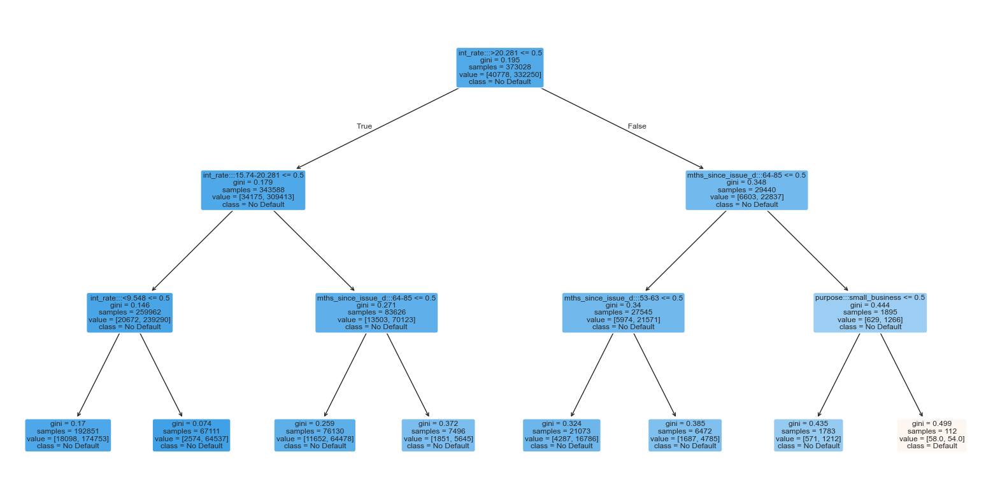

Coefficeints before transpose: []

Coefficeints after transpose: [[ 2.20606519e-01]
 [-1.94627805e-01]
 [-3.69458920e-01]
 [-5.15419950e-01]
 [-7.18040963e-01]
 [-8.34908263e-01]
 [ 8.59873576e-02]
 [-1.05470297e-02]
 [ 2.08464745e-01]
 [ 9.69663270e-02]
 [-1.23204005e-01]
 [-2.63828930e-02]
 [-4.59017206e-02]
 [ 1.41578714e-01]
 [-6.17376013e-02]
 [-1.27333587e-01]
 [ 1.92779342e-02]
 [-5.70054744e-04]
 [-4.35473237e-01]
 [ 1.11530886e-01]
 [ 3.56729193e-01]
 [ 7.09965463e-02]
 [-1.19801928e-01]
 [-3.03730845e-03]
 [-6.46333671e-02]
 [-1.09939715e-01]
 [-5.15127987e-02]
 [ 8.14420317e-02]
 [-3.10575009e-02]
 [ 1.13287383e-01]
 [-1.39232129e-02]
 [ 1.35343187e-01]
 [ 2.11162981e-01]
 [ 4.30437598e-01]
 [ 4.53237458e-01]
 [ 1.70155691e-01]
 [ 8.34105160e-02]
 [-2.20029427e-01]
 [-4.54715045e-01]
 [-7.05494949e-01]
 [-7.05801676e-01]
 [ 6.55775980e-01]
 [ 2.79447498e-01]
 [-2.44002961e-01]
 [-4.15968778e-01]
 [-9.96963827e-02]
 [-1.67438813e-01]
 [-1.07345949e-01]
 [ 6.77022152e-02]
 [ 1.50787607e-01]
 [ 2.31972830e-01]
 [ 3.05788291e-01]
 [ 3.33795111e-01]
 [ 4.15768308e-01]
 [ 4.57271716e-01]
 [ 4.23260757e-01]
 [-7.36837126e-04]
 [-1.05508996e-01]
 [-1.19452174e-01]
 [-3.48651622e-01]
 [ 1.55671393e-01]
 [ 2.11117369e-01]
 [-8.40791526e-02]
 [-1.04100779e-01]
 [-3.60874756e-02]
 [-6.94133266e-03]
 [-8.23047977e-02]
 [ 3.49865319e-01]
 [ 3.53405371e-01]
 [ 4.19573783e-01]
 [ 4.43444078e-01]
 [ 4.16095878e-01]
 [ 6.78143027e-04]
 [ 3.04540438e-02]
 [-1.23828284e-02]
 [ 6.22257554e-02]
 [ 1.39070869e-01]
 [-1.33141677e-01]
 [-9.72209927e-02]]

,Feature Name,Coefficients
0,Intercept,2.001158
1,grade:::A,0.220607
2,grade:::C,-0.194628
3,grade:::D,-0.369459
4,grade:::E,-0.515420
5,grade:::F,-0.718041
6,grade:::G,-0.834908
7,verification_status:::Not Verified,0.085987
8,verification_status:::Source Verified,-0.010547
9,purpose:::car,0.208465


In [206]:
# FINALLY FITTING LOGISTIC REGRESSION WITH P_VALUES

reg2 = LogisticRegression_with_p_values()
reg2.fit(inputs_train, loan_data_targets_train) # Remember this is NOW CLEAN !!!! 


# 1. Inspect model coefficients and intercept
print("Coefficients:", reg2.model.coef_)
print("Intercept:", reg2.intercept_)


# 2. Check training target distribution
print(loan_data_targets_train.value_counts(normalize=True))
'''value_counts(normalize=True) – how it works
df['col'].value_counts(normalize=True) returns the relative frequencies (proportions) instead of raw counts.
Each count is divided by the total number of non‑null values.
Example: [1,1,0,1] → counts {1:3, 0:1} → normalized {1:0.75, 0:0.25}.'''


# 3. Verify that the model was fitted on the correct data
print("Training inputs shape:", loan_data_inputs_train.shape)
print("Training targets shape:", loan_data_targets_train.shape)

# 4. Try a simple decision tree to see if features have any predictive power
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=3)
dt.fit(inputs_train, loan_data_targets_train)
print("Tree accuracy:", dt.score(inputs_test, loan_data_targets_test))

'''
If the tree also gives very high accuracy but with varied predictions, your logistic regression is under‑regularized. If the tree gives ~89% as well,
then the features are truly useless (or you have a target leak).

'''


# Would you like to plot a visual representation of this tree or calculate a confusion matrix to see exactly where the model is making mistakes?

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Set the canvas size
plt.figure(figsize=(20, 10))

# Plot the decision tree structure
plot_tree(
    dt, 
    filled=True, 
    rounded=True, 
    feature_names=inputs_train.columns, 
    class_names=['Default', 'No Default']  # Replace with your actual target labels
)

# Render the plot
plt.show()


feature_name = inputs_train.columns.values  

summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
print(f'\n Coefficeints before transpose: {reg2.coef_[2:2:1]}\n\n')
print(f'\n Coefficeints after transpose: {np.transpose(reg2.coef_)}\n\n')
summary_table['Coefficients'] = np.transpose(reg2.coef_)



#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', reg.intercept_[0]]
summary_table = summary_table.sort_index()
summary_table.head()
# reg.fit(inputs_train_with_ref_cat, loan_data_targets_train) This also wont work because it has references and we are trying to invert hence LinAlgError: Singular matrix

#lets put intercept in first row  so it is displayed at the top of the list of coefficients
# summary_table.iloc[0,1] = [reg.intercept_[0]] #if kept with 'errored definition' should have used reg.intercept[0] instead

#summary_table.iloc[0, 1] = [reg.intercept_[0]]
summary_table.loc[0, 'Coefficients'] = [reg2.intercept_[0]]

#summary_table.loc[0] = ['Intercept', reg.intercept_[0]]

summary_table = summary_table.sort_index()
summary_table


In [207]:
reg2.intercept_[0], reg2.model.intercept_[0], reg2.predict_proba(inputs_test)[:10], reg2.model.predict_proba(inputs_test)[:10]

(np.float64(2.0011581001831167),
 np.float64(2.0011581001831167),
 array([[0.08441412, 0.91558588],
        [0.1806759 , 0.8193241 ],
        [0.13809851, 0.86190149],
        [0.05686725, 0.94313275],
        [0.03417188, 0.96582812],
        [0.19221993, 0.80778007],
        [0.19453752, 0.80546248],
        [0.2588847 , 0.7411153 ],
        [0.04635054, 0.95364946],
        [0.03715987, 0.96284013]]),
 array([[0.08441412, 0.91558588],
        [0.1806759 , 0.8193241 ],
        [0.13809851, 0.86190149],
        [0.05686725, 0.94313275],
        [0.03417188, 0.96582812],
        [0.19221993, 0.80778007],
        [0.19453752, 0.80546248],
        [0.2588847 , 0.7411153 ],
        [0.04635054, 0.95364946],
        [0.03715987, 0.96284013]]))

In [208]:
import pickle

# Save your custom wrapper model object
with open('pd_model.sav', 'wb') as file:
    pickle.dump(reg2, file)

print("Custom PD model successfully saved!")


Custom PD model successfully saved!

In [506]:
# In your PD file (One-liner alternative)
import joblib
joblib.dump(reg2, 'reg_pd_0.pkl')

# In your LGD file (One-liner alternative)
import joblib
reg_pd_0 = joblib.load('reg_pd_0.pkl')


In [507]:
# In your PD file
import pickle
pickle.dump(reg2, open('reg_pd_0.pkl', 'wb'))

# In your LGD file
import pickle
reg_pd_0 = pickle.load(open('reg_pd_0.pkl', 'rb'))


In [209]:
import pickle

# Save the trained PD model object to a file named 'pd_model.sav'
with open('pd_model.sav', 'wb') as model_file:
    pickle.dump(reg2, model_file)

print("✅ PD model successfully exported via pickle.")


✅ PD model successfully exported via pickle.

In [210]:
import pickle

# Load the pickle file and name the object reg_pd_0
with open('pd_model.sav', 'rb') as model_file:
    reg_pd_0 = pickle.load(model_file)

print("✅ pd_model.sav loaded successfully into workspace as 'reg_pd_0'.")


✅ pd_model.sav loaded successfully into workspace as 'reg_pd_0'.

In [211]:
'''You cannot run reg2.to_pickle('reg_pd_0').The .to_pickle() method is a feature exclusive to Pandas objects (like DataFrames and Series). 
Scikit-learn or Statsmodels object classes do not have a built-in .to_pickle() method, so running that code will immediately throw an AttributeError.

Here is a direct comparison of the two methods so you can see the difference:Direct ComparisonFeaturepd.DataFrame.to_pickle()pickle.dump(reg2, ...)
What it belongs toIt is a built-in method inside the Pandas library.It is a function inside Python's native Pickle library.Supported ObjectsOnly works
on Pandas DataFrames and Series.Works on almost any Python object (DataFrames, Models, Lists, Dicts).How it works under the hoodPandas wraps native
Python pickle logic inside a DataFrame method for convenience.You explicitly pass the model object and a file stream to the standard pickle function.

The Recommended Fast SyntaxSince you want the fastest, cleanest approach without writing multi-line file openings, you can use Joblib 
(which is optimized specifically for large machine learning model arrays) or standard pickle inline:'''


# In your PD file (One-liner alternative)
import joblib
joblib.dump(reg2, 'reg_pd_0.pkl')

# In your LGD file (One-liner alternative)
import joblib
reg_pd_0 = joblib.load('reg_pd_0.pkl')



'''Alternatively, if you prefer sticking strictly to the pickle library, you can write them as clean two-liners:'''
# In your PD file
import pickle
pickle.dump(reg2, open('reg_pd_0.pkl', 'wb'))

# In your LGD file
import pickle
reg_pd_0 = pickle.load(open('reg_pd_0.pkl', 'rb'))


In [212]:
'''Why reg.intercept_[0] has [0]In scikit-learn, model attributes like intercept_ are structured to support both simple binary classification and 
complex multi-class classification.The Structure: Even if your model only has one single intercept value (binary setup), reg.intercept_ is always 
stored inside a 1-D NumPy array (e.g., [ -3.47 ]).The Reason for [0]: Writing reg.intercept_ returns the array container itself. Appending [0]
extracts the first single scalar number out of that array container so you can print it or use it cleanly in equations.
2. Why predict_proba(inputs_test)[:, 1] has [:, 1]The .predict_proba() method calculates the specific mathematical probability of a sample falling 
into each available category.The Matrix Output: For binary classification (like 0 for Default, 1 for No Default), the method outputs a 2D grid/matrix 
with two columns:Column 0: Probability that the sample belongs to class 0.Column 1: Probability that the sample belongs to class 1.The Slicing Logic: 
The : index means "give me all rows". The , 1 index means "only give me column index 1".The Result: Using [:, 1] discards the redundant "negative class"
probabilities and extracts a clean 1D list showing only the probability of the event actually happening (the positive class).

•	
Matrix Row Index	Column [0] (Prob of 0)	Column [1] (Prob of 1)	Selected by [:, 1]
Row 0	0.85	0.15	0.15
Row 1	0.03	0.97	0.97
Row 2	0.40	0.60	0.60


'''
# Diagnostic: confirm balanced weighting took effect
print(f"Intercept: {reg2.model.intercept_[0]:.4f}")
print(f"Class weights: {reg2.model.class_weight}")

# Should now show an intercept much closer to 0
# instead of 2.33

proba_sample = reg2.model.predict_proba(inputs_test)[:, 1]
print(f"\nProbability of BAD (col 0):")
print(f"  Min:  {proba_sample.min():.4f}")
print(f"  Max:  {proba_sample.max():.4f}")
print(f"  Mean: {proba_sample.mean():.4f}")
print(f"\nBorrowers with P(bad) > 0.5: {(proba_sample > 0.5).sum()}")
'''If that last number is in the thousands, everything is working correctly and you can proceed to the accuracy cells with confidence.'''
# This last number should be several thousand, not 7

Intercept: 2.0012

Class weights: None

Probability of BAD (col 0):

Min:  0.4393

Max:  0.9929

Mean: 0.8906

Borrowers with P(bad) > 0.5: 93248

'If that last number is in the thousands, everything is working correctly and you can proceed to the accuracy cells with confidence.'

In [213]:
# Alternative to get p_values 

# ✅ NEW: Build summary_table AFTER all cleaning
feature_names_clean = inputs_train.columns.tolist()  # ← CLEANED features

# Create summary table with CORRECT number of rows
summary_table = pd.DataFrame({
    'Feature Name': feature_names_clean,
    'Coefficient': reg2.coef_[0],
    'p_values': reg2.p_values
})

# Add intercept row at top
intercept_row = pd.DataFrame({
    'Feature Name': ['Intercept'],
    'Coefficient': [reg2.intercept_[0]],
    'p_values': [np.nan]
})

summary_table = pd.concat([intercept_row, summary_table], ignore_index=True)



# -----------------------------
# ADD DIAGNOSTICS (VERSION B)
# -----------------------------

# coef alias
summary_table['coef'] = summary_table['Coefficient']

# Std Error (prepend NaN for intercept)
std_err = np.insert(reg2.std_err, 0, np.nan)
summary_table['Std_Error'] = std_err


# OR USE THE FOLLOWING 
''' THE FOLLOWING IS AN ALTERNATIVE WAY OF CREATING A SUMMARY TABLE '''

summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)

summary_table['Coefficients'] = np.transpose(reg2.coef_) 


#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', reg2.intercept_[0]]
summary_table = summary_table.sort_index()

p_values = reg2.p_values 
""" inorder to match the p_values to the coefficients in the summary table , we add something on the first row the position which corresponds to the 
intercept in the current summary table by simply adding an n values: so  lets make p_values  list equal to an n value and an np array of the existing values"""

p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values


# =====================================
# ADD FULL DIAGNOSTICS — ALTERNATIVE PATH
# =====================================

# 1️⃣ coef alias (required by downstream logic)
summary_table['coef'] = summary_table['Coefficients'] # this was already done up with summary_table['Coefficients'] = np.transpose(reg.coef_) 

# 2️⃣ Std Error (prepend NaN for intercept)
std_err = np.append(np.nan, np.array(reg2.std_err))
summary_table['Std_Error'] = std_err



# 3️⃣ z-statistic
summary_table['z'] = summary_table['coef'] / summary_table['Std_Error']

# 4️⃣ two-sided p-value from z
from scipy import stats
summary_table['p_value'] = 2 * (1 - stats.norm.cdf(np.abs(summary_table['z'])))

# 5️⃣ untrustworthy detection
summary_table['untrustworthy'] = (
    summary_table['Std_Error'].isna() |
    np.isinf(summary_table['Std_Error']) |
    (np.abs(summary_table['coef']) > 10)
)

# 6️⃣ human-readable flag
summary_table['flag'] = 'OK'
summary_table.loc[summary_table['untrustworthy'], 'flag'] = 'UNSTABLE'


summary_table

,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag
0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE
1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,7.753194e-04,False,OK
2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000e+00,False,OK
3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000e+00,False,OK
4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000e+00,False,OK
5,grade:::F,-0.718041,9.521838e-56,-0.718041,0.045650,-15.729327,0.000000e+00,False,OK
6,grade:::G,-0.834908,1.074694e-43,-0.834908,0.060230,-13.862109,0.000000e+00,False,OK
7,verification_status:::Not Verified,0.085987,3.976779e-09,0.085987,0.014611,5.885156,3.976779e-09,False,OK
8,verification_status:::Source Verified,-0.010547,4.341481e-01,-0.010547,0.013485,-0.782113,4.341481e-01,False,OK
9,purpose:::car,0.208465,1.675658e-04,0.208465,0.055391,3.763479,1.675658e-04,False,OK


In [214]:
# Above we have 96 dummy variables in our model and have their coefficeints and p values listed above 
# we could have upt0 104 dummy variables or more because there are some we can do later like dti, total_rev_lim, acc_now_delinq, total_acc

#Now we can select independent variables based on statistical significance we retain those that are statistically significant

''' Recall Each Original Independent variable is represented by several dummy variables.
If all coefficeints for all of these dummy variable are statisstically significant, we should retain all of them.
And if the coefficients for none of the dummy variables are statistically significant we should remove all of them.
If coefficients of some of the dummy variables are statistically significant and others are not, if we remove that insignificant ones which makes sense
it would however lead to few variables in the model representing a part or parts of the original independent variable,
While there wont be anything representing the rest, which conceptually doesn't make much sense , 

Hence: If one or few dummy variables representing one original independent variable are statistically significant, it would be best to retain all
dummy variables that represent that original dummy variable in the final model

PS. p-value of a coefficient < 0.05 is statistically significant

Starting in order:
The coefficients for all dummy variables that represent grade variable are statistically significant, so we keep  all of them
For state/addr, all but first 2 are statistically significant so we keep all the dummy variables 

Anyways list of dummy variables to keep are Grade, home_ownership to all dummies representing variables upto those that represent delinquency in 
the last 2 years delinq_2yrs (these 2 variables are not statistically significant based on the significance level we choose) so we remove all of them ,  
remove public record(pub_rec) , for total revolving high limit ,  total_rev_hi_lim only 1 of 7 is significant, so we shall opt to remove all its 
dummies. open_acc and total_acc are also removed

SIGNIFICANT: ['grade', 'home_ownership', 'addr_state', 'verification_status', 'purpose', 'initial_list_status', 'term', 'emp_length', 'mths_since_issue_d',
'int_rate', 'mths_since_earliest_cr_line', 'inq_last_6mths', open_acc',  'acc_now_delinq',  'annual_inc', 'dti', 'mths_since_last_delinq', 
'mths_since_last_record']


NON-SIGNIFICANT: ['delinq_2yrs', 'open_acc', 'pub_rec', 'total_acc', 'total_rev_hi_lim']

'''

" Recall Each Original Independent variable is represented by several dummy variables.\nIf all coefficeints for all of these dummy variable are statisstically significant, we should retain all of them.\nAnd if the coefficients for none of the dummy variables are statistically significant we should remove all of them.\nIf coefficients of some of the dummy variables are statistically significant and others are not, if we remove that insignificant ones which makes sense\nit would however lead to few variables in the model representing a part or parts of the original independent variable,\nWhile there wont be anything representing the rest, which conceptually doesn't make much sense , \n\nHence: If one or few dummy variables representing one original independent variable are statistically significant, it would be best to retain all\ndummy variables that represent that original dummy variable in the final model\n\nPS. p-value of a coefficient < 0.05 is statistically significant\n\nStarting 

In [215]:
significant_bases = ['grade', 'home_ownership', 'addr_state', 'verification_status', 'purpose', 'initial_list_status', 'term', 'emp_length', 'mths_since_issue_d',
'int_rate', 'mths_since_earliest_cr_line', 'inq_last_6mths', 'open_acc',  'acc_now_delinq',  'annual_inc', 'dti', 'mths_since_last_delinq', 
'mths_since_last_record'] 

**FINALLY WITH CROSS VALIDATION AND CALIBRATION::***

In [216]:

from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV


calibrated_reg = CalibratedClassifierCV(reg, method='sigmoid', cv=5)
calibrated_reg.fit(inputs_train, loan_data_targets_train)

# Use this for honest probabilities:
y_hat_test_proba_calibrated = calibrated_reg.predict_proba(inputs_test)[:, 1]  # col 0 = P(BAD)



In [217]:

calibrated_reg2 = CalibratedClassifierCV(reg2.model, method='sigmoid', cv=5)
calibrated_reg2.fit(inputs_train, loan_data_targets_train)

# Use this for honest probabilities:
y_hat_test_proba_calibrated = calibrated_reg2.predict_proba(inputs_test)[:, 1]  # col 0 = P(BAD)


In [218]:
# Alternative to get p_values 

# ✅ NEW: Build summary_table AFTER all cleaning
feature_names_clean = inputs_train.columns.tolist()  # ← CLEANED features

# Create summary table with CORRECT number of rows
summary_table = pd.DataFrame({
    'Feature Name': feature_names_clean,
    'Coefficient': reg2.coef_[0],
    'p_values': reg2.p_values
})

# Add intercept row at top
intercept_row = pd.DataFrame({
    'Feature Name': ['Intercept'],
    'Coefficient': [reg2.intercept_[0]],
    'p_values': [np.nan]
})

summary_table = pd.concat([intercept_row, summary_table], ignore_index=True)



# -----------------------------
# ADD DIAGNOSTICS (VERSION B)
# -----------------------------

# coef alias
summary_table['coef'] = summary_table['Coefficient']

# Std Error (prepend NaN for intercept)
std_err = np.insert(reg2.std_err, 0, np.nan)
summary_table['Std_Error'] = std_err


# OR USE THE FOLLOWING 
''' THE FOLLOWING IS AN ALTERNATIVE WAY OF CREATING A SUMMARY TABLE '''

summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)

summary_table['Coefficients'] = np.transpose(reg2.coef_) 


#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', reg2.intercept_[0]]
summary_table = summary_table.sort_index()

p_values = reg2.p_values 
""" inorder to match the p_values to the coefficients in the summary table , we add something on the first row the position which corresponds to the 
intercept in the current summary table by simply adding an n values: so  lets make p_values  list equal to an n value and an np array of the existing values"""

p_values = np.append(np.nan, np.array(p_values))
summary_table['p_values'] = p_values


# =====================================
# ADD FULL DIAGNOSTICS — ALTERNATIVE PATH
# =====================================

# 1️⃣ coef alias (required by downstream logic)
summary_table['coef'] = summary_table['Coefficients'] # this was already done up with summary_table['Coefficients'] = np.transpose(reg.coef_) 

# 2️⃣ Std Error (prepend NaN for intercept)
std_err = np.append(np.nan, np.array(reg2.std_err))
summary_table['Std_Error'] = std_err



# 3️⃣ z-statistic
summary_table['z'] = summary_table['coef'] / summary_table['Std_Error']

# 4️⃣ two-sided p-value from z
from scipy import stats
summary_table['p_value'] = 2 * (1 - stats.norm.cdf(np.abs(summary_table['z'])))

# 5️⃣ untrustworthy detection
summary_table['untrustworthy'] = (
    summary_table['Std_Error'].isna() |
    np.isinf(summary_table['Std_Error']) |
    (np.abs(summary_table['coef']) > 10)
)

# 6️⃣ human-readable flag
summary_table['flag'] = 'OK'
summary_table.loc[summary_table['untrustworthy'], 'flag'] = 'UNSTABLE'


summary_table



,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag
0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE
1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,7.753194e-04,False,OK
2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000e+00,False,OK
3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000e+00,False,OK
4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000e+00,False,OK
5,grade:::F,-0.718041,9.521838e-56,-0.718041,0.045650,-15.729327,0.000000e+00,False,OK
6,grade:::G,-0.834908,1.074694e-43,-0.834908,0.060230,-13.862109,0.000000e+00,False,OK
7,verification_status:::Not Verified,0.085987,3.976779e-09,0.085987,0.014611,5.885156,3.976779e-09,False,OK
8,verification_status:::Source Verified,-0.010547,4.341481e-01,-0.010547,0.013485,-0.782113,4.341481e-01,False,OK
9,purpose:::car,0.208465,1.675658e-04,0.208465,0.055391,3.763479,1.675658e-04,False,OK


In [219]:
# Feature importance (LOGISTIC REGRESSION)


feature_importance = pd.DataFrame({
    'feature': inputs_train.columns,
    'coef': reg.coef_[0]
})

feature_importance.sort_values(by='coef', ascending=False)




coef_df = pd.DataFrame({
    'Feature': inputs_train.columns,
    'Coefficient': reg.coef_[0]
})

coef_df['Abs'] = coef_df['Coefficient'].abs()

coef_df.sort_values(by='Abs', ascending=False).head(30)

,Feature,Coefficient,Abs
5,grade:::G,-0.834908,0.834908
4,grade:::F,-0.718041,0.718041
40,mths_since_issue_d:::>85,-0.705802,0.705802
39,mths_since_issue_d:::64-85,-0.705495,0.705495
41,int_rate:::<9.548,0.655776,0.655776
3,grade:::E,-0.515420,0.515420
54,annual_inc:::120k-140k,0.457272,0.457272
38,mths_since_issue_d:::53-63,-0.454715,0.454715
34,mths_since_issue_d:::<38,0.453237,0.453237
70,mths_since_last_delinq:::31-56,0.443444,0.443444


In [220]:
'''importance = pd.Series(model.coef_[0], index=X.columns)
importance.sort_values(ascending=False)'''


importance = pd.Series(reg.coef_[0], index=inputs_train.columns)
importance.sort_values(ascending=False)

int_rate:::<9.548                        0.655776
annual_inc:::120k-140k                   0.457272
mths_since_issue_d:::<38                 0.453237
mths_since_last_delinq:::31-56           0.443444
addr_state:::WV_NH_WY_DC_ME_ID           0.430438
annual_inc:::>140k                       0.423261
mths_since_last_delinq:::4-30            0.419574
mths_since_last_delinq:::>56             0.416096
annual_inc:::100k-120k                   0.415768
purpose:::wedding                        0.356729
mths_since_last_delinq:::0-3             0.353405
mths_since_last_delinq:::Missing         0.349865
annual_inc:::90k-100k                    0.333795
annual_inc:::80k-90k                     0.305788
int_rate:::9.548-12.025                  0.279447
annual_inc:::70k-80k                     0.231973
grade:::A                                0.220607
addr_state:::KS_SC_CO_VT_AK_MS           0.211163
mths_since_last_record:::38-75           0.211117
purpose:::car                            0.208465


In [221]:
# ***Export all these dataframes and store them in CSV files***

inputs_train.to_pickle('inputs_train.pkl') #CSV loses some information (like exact data types). To preserve them, use pickle.
loan_data_targets_train.to_pickle('loan_data_targets_train.pkl')

inputs_test.to_pickle('inputs_test.pkl')
loan_data_targets_test.to_pickle('loan_data_targets_test.pkl')


In [222]:
import pickle

with open("ref_categories.pkl", "wb") as f:
    pickle.dump(ref_categories, f)

# To load:

with open("ref_categories.pkl", "rb") as f:
    ref_categories = pickle.load(f)

In [223]:
import pickle

# Save your custom wrapper model object
with open('pd_model.sav', 'wb') as file:
    pickle.dump(reg2, file)

print("Custom PD model successfully saved!")


Custom PD model successfully saved!

In [224]:
import pickle

# ⚠️ CRITICAL: Ensure the definition of 'LogisticRegression_with_p_values' 
# is executed or imported in this notebook BEFORE running the code below!

# Load the saved custom model file
with open('pd_model.sav', 'rb') as file:
    reg_pd = pickle.load(file)

print("Custom PD model successfully loaded into 'reg_pd'!")


Custom PD model successfully loaded into 'reg_pd'!

In [225]:
#🛡️ Daily Habit (Non-Negotiable):

'''💡 Truth: Jupyter stores every printed output in the .ipynb file. Print a 10,000-row DataFrame once → file explodes. 
Never print raw DataFrames — always use .head(10).'''

# After big operations, clean up:
# del old_big_variable
import gc; gc.collect()  # forces Python to free memory NOW



0

In [226]:
sorted(loan_data.columns.values)

['Unnamed: 0',
 'acc_now_delinq',
 'addr_state',
 'addr_state:AK',
 'addr_state:AL',
 'addr_state:AR',
 'addr_state:AZ',
 'addr_state:CA',
 'addr_state:CO',
 'addr_state:CT',
 'addr_state:DC',
 'addr_state:DE',
 'addr_state:FL',
 'addr_state:GA',
 'addr_state:HI',
 'addr_state:IA',
 'addr_state:ID',
 'addr_state:IL',
 'addr_state:IN',
 'addr_state:KS',
 'addr_state:KY',
 'addr_state:LA',
 'addr_state:MA',
 'addr_state:MD',
 'addr_state:ME',
 'addr_state:MI',
 'addr_state:MN',
 'addr_state:MO',
 'addr_state:MS',
 'addr_state:MT',
 'addr_state:NC',
 'addr_state:NE',
 'addr_state:NH',
 'addr_state:NJ',
 'addr_state:NM',
 'addr_state:NV',
 'addr_state:NY',
 'addr_state:OH',
 'addr_state:OK',
 'addr_state:OR',
 'addr_state:PA',
 'addr_state:RI',
 'addr_state:SC',
 'addr_state:SD',
 'addr_state:TN',
 'addr_state:TX',
 'addr_state:UT',
 'addr_state:VA',
 'addr_state:VT',
 'addr_state:WA',
 'addr_state:WI',
 'addr_state:WV',
 'addr_state:WY',
 'annual_inc',
 'application_type',
 'collection_re

In [227]:
sorted(inputs_train.columns.values)

['addr_state:::GA_WA_OR',
 'addr_state:::IL_CT',
 'addr_state:::KS_SC_CO_VT_AK_MS',
 'addr_state:::ND_NE_IA_NV_FL_HI_AL',
 'addr_state:::NM_VA',
 'addr_state:::OK_TN_MO_LA_MD_NC',
 'addr_state:::RI_MA_DE_SD_IN',
 'addr_state:::UT_KY_AZ_NJ',
 'addr_state:::WI_MT',
 'addr_state:::WV_NH_WY_DC_ME_ID',
 'annual_inc:::100k-120k',
 'annual_inc:::120k-140k',
 'annual_inc:::20k-30k',
 'annual_inc:::30k-40k',
 'annual_inc:::50k-60k',
 'annual_inc:::60k-70k',
 'annual_inc:::70k-80k',
 'annual_inc:::80k-90k',
 'annual_inc:::90k-100k',
 'annual_inc:::<20k',
 'annual_inc:::>140k',
 'dti:::20-30',
 'dti:::<10',
 'dti:::>30',
 'funded:::funded:high',
 'funded:::funded:low',
 'funded:::funded:very_high',
 'grade:::A',
 'grade:::C',
 'grade:::D',
 'grade:::E',
 'grade:::F',
 'grade:::G',
 'home_ownership:::OWN',
 'home_ownership:::RENT_OTHER_NONE_ANY',
 'initial_list_status:::w',
 'int_rate:::15.74-20.281',
 'int_rate:::9.548-12.025',
 'int_rate:::<9.548',
 'int_rate:::>20.281',
 'mths_since_issue_d:::3

In [228]:
sorted(inputs_test.columns.values)


['addr_state:::GA_WA_OR',
 'addr_state:::IL_CT',
 'addr_state:::KS_SC_CO_VT_AK_MS',
 'addr_state:::ND_NE_IA_NV_FL_HI_AL',
 'addr_state:::NM_VA',
 'addr_state:::OK_TN_MO_LA_MD_NC',
 'addr_state:::RI_MA_DE_SD_IN',
 'addr_state:::UT_KY_AZ_NJ',
 'addr_state:::WI_MT',
 'addr_state:::WV_NH_WY_DC_ME_ID',
 'annual_inc:::100k-120k',
 'annual_inc:::120k-140k',
 'annual_inc:::20k-30k',
 'annual_inc:::30k-40k',
 'annual_inc:::50k-60k',
 'annual_inc:::60k-70k',
 'annual_inc:::70k-80k',
 'annual_inc:::80k-90k',
 'annual_inc:::90k-100k',
 'annual_inc:::<20k',
 'annual_inc:::>140k',
 'dti:::20-30',
 'dti:::<10',
 'dti:::>30',
 'funded:::funded:high',
 'funded:::funded:low',
 'funded:::funded:very_high',
 'grade:::A',
 'grade:::C',
 'grade:::D',
 'grade:::E',
 'grade:::F',
 'grade:::G',
 'home_ownership:::OWN',
 'home_ownership:::RENT_OTHER_NONE_ANY',
 'initial_list_status:::w',
 'int_rate:::15.74-20.281',
 'int_rate:::9.548-12.025',
 'int_rate:::<9.548',
 'int_rate:::>20.281',
 'mths_since_issue_d:::3


**PD MODEL VALIDATION** (Test)
**Out-of-sample** (Test)



In [229]:
# for now let us agree to use what is already saved in our code 

print(inputs_train.shape)
print(loan_data_targets_train.shape)

print(inputs_test.shape)
loan_data_targets_test.shape

(373028, 79)

(373028,)

(93257, 79)

(93257,)

In [230]:
# We will now use our model to estimate the probability of default of each observation from the test data 
# Estimating the probability of default of each observation from test data
''' The following statement takes the model which is stored in reg2 object and applies the predict method  on it 
with the test inputs as its only arguments # The following statement takes the model which is stored in the reg2 object 
and applies the predict method on it with the test inputs as its only argument

**HOW IT WORKS BEHIND THE SCENES**
logistic_regression_model.predict(df with independent variables)
1) Multiplies the values of the variables of each observation by model coefficients; this yields the log of odds of being good
2) an exponential is raised to the power the log of odds; this yields the odds of being good and the estimated probability of being good
3) the estimated probabilities are categorised into being good or bad by applying a cut-off
4) Default cut-off is 0.5 or 50% hence if estimated prob is less than .5 then loan is bad (All estimations with estimated probabilities of being good less than 0.5 would be classified as 0 i.e. bad and reverse is true) hence y_hat_test is an array of zeros and ones for each of the observations of the inputs_test dataframe
'''

# the y_hat_test here is different from the one we use later that we create manually ,this one is automatic 
y_hat_test =  reg2.model.predict(inputs_test) 

In [231]:

#Passing the 1D array directly to pd.DataFrame(data, columns=...) assigns the data as a single column.


In [232]:
# You can alternatively pass a dictionary: 
pd.DataFrame({'predicted_values': y_hat_test}).sample(5)

,predicted_values
15857,1
57966,1
45200,1
89161,1
51528,1


In [233]:


# Assuming y_hat_test is your NumPy array
# y_hat_test = np.array([0.1, 0.5, 0.9]) 

# Convert to DataFrame
df_y_hat = pd.DataFrame(y_hat_test, columns=['predicted_values'])

print(df_y_hat.sample(3))


predicted_values
27749                 1
79653                 1
76670                 1

In [234]:


# Assuming y_hat_test is your NumPy array
# y_hat_test = np.array([0.1, 0.5, 0.9]) 

# Convert to DataFrame
df_y_hat = pd.DataFrame(columns=['predicted_values'], data = y_hat_test)

print(df_y_hat.sample(3))


predicted_values
90214                 1
63891                 1
31675                 1

In [235]:


# Assuming y_hat_test is your NumPy array
# y_hat_test = np.array([0.1, 0.5, 0.9]) 

# Convert to DataFrame
df_y_hat = pd.DataFrame(data = y_hat_test, columns=['predicted_values'])

print(df_y_hat.sample(3))


predicted_values
75217                 1
61595                 1
71670                 1

In [236]:
y_hat_test.dtype, y_hat_test

(dtype('int64'), array([1, 1, 1, ..., 1, 1, 1]))

In [237]:
y_hat_test.dtype, y_hat_test[100:1:-10]

(dtype('int64'), array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1]))

In [238]:
y_hat_test.dtype, y_hat_test[1200:1500:20]

(dtype('int64'), array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]))

In [239]:
len(y_hat_test), len(y_hat_test[y_hat_test == 0]), len(y_hat_test[y_hat_test == 1])
# len(y_hat_test[y_hat_test == 0]) 👉 If still tiny → model still broken

(93257, 9, 93248)

In [240]:
print(f'{y_hat_test[y_hat_test == 0]},\n\n {df_y_hat[df_y_hat['predicted_values'] == 0].head()},  {len(df_y_hat[df_y_hat['predicted_values']== 0])}')

[0 0 0 0 0 0 0 0 0],

        predicted_values
7488                  0
12569                 0
36203                 0
41009                 0
58288                 0,  9

In [241]:
zeros_query = df_y_hat.query('predicted_values == 0.0')
print("\nZeros in DataFrame (Query):")
print(zeros_query.head())

Zeros in DataFrame (Query):

predicted_values
7488                  0
12569                 0
36203                 0
41009                 0
58288                 0

In [242]:
 #Filtering a Pandas DataFrame
'''Use boolean indexing or .loc to filter rows based on column values.

Difference between .filter() and .query() in PandasThese two tools are used for completely different types of filtration.df.filter()
Purpose: It filters columns or rows based on their labels/names, not the data inside them.How it works: You use it to grab columns that match a 
specific text string or pattern.Example: df.filter(like='loan') will return columns named loan_amount, loan_duration, and loan_status. It does not 
look at the numbers inside those columns.

df.query()Purpose: It filters the actual data rows inside the DataFrame using a clean text string expression.
How it works: You write your filtering logic as a string, which makes it highly readable.Example: df.query("predicted_values < 0.2") does exactly the 
same thing as the .loc syntax above, but using an easier-to-read SQL-like format.'''

print(len([y_hat_test == 0])) # will always return 1, no matter how many zeros are in your data, because you just counted a single list container.

'''
What atol, np.isclose, and the syntax doatol stands for: Absolute Tolerance.What np.isclose does: Computers struggle to store floating-point decimal
numbers perfectly (e.g., 0.00000000000004 instead of 0.0). If you search for exactly 0.0, you will miss these numbers. np.isclose checks if numbers are
close enough to a target value within a small margin of error.

results = df_y_hat[np.isclose(df_y_hat['predicted_values'], 0.0, atol=0.1)]

0.0: The target value you are comparing your probabilities against.atol=0.1: The boundary window. This tells Python: "Find any value between -0.1 and +0.1." 
(Since probabilities cannot be negative, it effectively grabs values from 0.0 to 0.1).'''

y_hat_test2 = np.array([0.1, 0.5, 0.9, 0.0, 0.3])
df_y_hat = pd.DataFrame(y_hat_test, columns=['predicted_values'])

# Method A: Boolean Indexing (Filtering for 0s, using a small threshold for floats)
# Finding values very close to 0
results = df_y_hat[np.isclose(df_y_hat['predicted_values'], 0.0, atol=0.1)]
print(results.sample(5))
# Output:
#    predicted_values
# 0               0.1
# 3               0.0

# Method B: Using .loc for specific condition
low_preds = df_y_hat.loc[df_y_hat['predicted_values'] < 0.2] #  df.query("predicted_values < 0.2")
print(low_preds.sample(5))

# Alternative: pandas.DataFrame.filter (Label Based) 
# The .filter() method is used to select columns or rows based on their labels (names), not their values. 


# To select only the 'predicted_values' column
df_labeled = df_y_hat.filter(items=['predicted_values'])

# To select rows with index 0 or 1
df_rows = df_y_hat.filter(items=[0, 1], axis=0)


1

predicted_values
64110                 0
80276                 0
85282                 0
41009                 0
7488                  0

predicted_values
64110                 0
60440                 0
80276                 0
7488                  0
58288                 0

In [243]:
'''In order to assess how well our PD model performs, it is much more important to obtain the raw predicted for each observation ,
rather than the categories predicted by the predict method, to achieve that we can use a method called predict proba which gives us an array of arrays
as many as there are observations in the inputs data frame, Each composed of 2 elements , the first being PD and the second 1 - PD'''

y_hat_test_proba = reg2.model.predict_proba(inputs_test)
min(y_hat_test_proba[0]), max(y_hat_test_proba[0]), min(y_hat_test_proba[1]), max(y_hat_test_proba[1]), y_hat_test_proba[::10]

(np.float64(0.08441411547778332),
 np.float64(0.9155858845222167),
 np.float64(0.18067589577416643),
 np.float64(0.8193241042258336),
 array([[0.08441412, 0.91558588],
        [0.1710931 , 0.8289069 ],
        [0.23481945, 0.76518055],
        ...,
        [0.12240507, 0.87759493],
        [0.18750943, 0.81249057],
        [0.08831099, 0.91168901]]))

**CALIBRATION OF PREDICTIONS**

In [244]:
# The correct combined code for your notebook

from sklearn.calibration import CalibratedClassifierCV

# STEP 1: Train with class_weight balanced
base_model = LogisticRegression(
                                 max_iter=1000)
base_model.fit(inputs_train, loan_data_targets_train)

# STEP 2: Calibrate on top of the balanced model
calibrated = CalibratedClassifierCV(base_model,
                                     method='sigmoid',
                                     cv=5)


# Calibrate on top of the balanced model
calibrated = CalibratedClassifierCV(reg2.model,
                                     method='sigmoid',
                                     cv=5)

'''
# Calibrate on top of the balanced model
calibrated = CalibratedClassifierCV(reg2,
                                     method='sigmoid',
                                     cv=5)
This wouldnt work because we need reg2.model
'''

calibrated.fit(inputs_train, loan_data_targets_train)

# STEP 3: Get honest probabilities
y_proba_cal = calibrated.predict_proba(inputs_test)[:,1]

y_proba_b = base_model.predict_proba(inputs_test)[:,1]

# STEP 4: Decide approve/reject at business threshold
tr = 0.35   # lower than 0.5 because you want to catch more Good
decision = (y_proba_cal >= tr).astype(int)
decision_b = (y_proba_b >= tr).astype(int)

print(y_proba_b[:10], decision[:10])
print('==================================================================================================================================')
print(y_proba_cal[:10], decision[:10])



# Now use calibrated_model for probability predictions, but keep reg2 for coefficients/summary.

[0.91558588 0.8193241  0.86190149 0.94313275 0.96582812 0.80778007
 0.80546248 0.7411153  0.95364946 0.96284013] [1 1 1 1 1 1 1 1 1 1]

===================================================================================================================
===============

[0.91565271 0.82035114 0.86198111 0.94289036 0.96556398 0.80725227
 0.80600358 0.74091401 0.95337872 0.96244095] [1 1 1 1 1 1 1 1 1 1]

In [245]:
from sklearn.calibration import calibration_curve

'''prob_true, prob_pred = calibration_curve(
    loan_data_targets_test,
    y_hat_test_proba,
    n_bins=10
)
# ValueError: y should be a 1d array, got an array of shape (93257, 2) instead.'''


prob_true, prob_pred = calibration_curve(
    loan_data_targets_test,
    y_hat_test_proba[:,1],
    n_bins=10
)

print(prob_true)
print(prob_pred)

[0.33333333 0.54098361 0.6799441  0.7637768  0.85624963 0.94322008]

[0.47502292 0.56948511 0.66632388 0.76326153 0.85924504 0.94136681]

In [246]:
y_hat_test_proba = reg2.predict_proba(inputs_test)
y_hat_test_proba = reg2.model.predict_proba(inputs_test) 
# from our class these 2 give the same results

In [247]:
y_hat_test_proba[:,1]

array([0.91558588, 0.8193241 , 0.86190149, ..., 0.97516739, 0.9545237 ,
       0.95401139])

In [248]:
np.unique(y_hat_test, return_counts=False), np.unique(y_hat_test, return_counts=True)

(array([0, 1]), (array([0, 1]), array([    9, 93248])))

In [249]:
# CHECK PROBABILITY DISTRIBUTION
''' ✅ GOOD MODEL SHOULD LOOK LIKE: << for normal distribution>>
Min ≈ 0.05–0.2
Max ≈ 0.8–0.95
Mean ≈ 0.6–0.8

❌ BAD :
Min ≈ 0.75
Max ≈ 0.99'''



probs = reg.predict_proba(inputs_test)[:,1]

print("Min:", probs.min())
print("Max:", probs.max())
print("Mean:", probs.mean())



Min: 0.43933562388940345

Max: 0.9928816521197242

Mean: 0.8906141546907633

In [250]:
loan_data_targets_test.head(3), df_targets_prepr_test.head(3), probs, y_hat_test

(362514    1
 288564    1
 213591    1
 Name: good_bad, dtype: int64,
 362514    1
 288564    1
 213591    1
 Name: good_bad, dtype: int64,
 array([0.91558588, 0.8193241 , 0.86190149, ..., 0.97516739, 0.9545237 ,
        0.95401139]),
 array([1, 1, 1, ..., 1, 1, 1]))

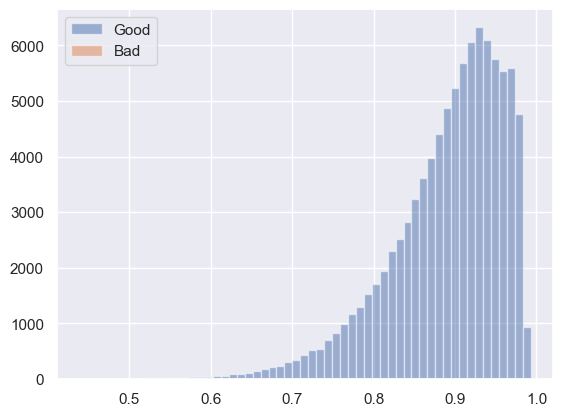

In [251]:
# SANITY CHECK (CRITICAL). Plot distributions:

'''
✅ What you want:

Bad → left side (low probs)
Good → right side (high probs)

❌ What you likely have now:
Both overlapping → model useless

🔥 GOOD MODEL:
BAD → right side (high PD)
GOOD → left side (low PD)z
'''

plt.hist(probs[y_hat_test==1], bins=50, alpha=0.5, label='Good')
plt.hist(probs[y_hat_test==0], bins=50, alpha=0.5, label='Bad')
plt.legend()
plt.show()

In [252]:
# For convenience we can put the actual good bad variable and the estimated probabilities in one dataframe

loan_data_targets_test_temp = loan_data_targets_test

loan_data_targets_test_temp.head(), loan_data_targets_test_temp.index, loan_data_targets_test_temp.index.to_list()[:10]

(362514    1
 288564    1
 213591    1
 263083    1
 165001    1
 Name: good_bad, dtype: int64,
 Index([362514, 288564, 213591, 263083, 165001,  82511,  24671,  97373,  44058,
        351326,
        ...
         63372, 190559, 254758, 436344, 231767,    115, 296284,  61777,  91763,
        167512],
       dtype='int64', length=93257),
 [362514, 288564, 213591, 263083, 165001, 82511, 24671, 97373, 44058, 351326])

In [253]:
# For convenience we can put the actual good bad variable and the estimated probabilities in one dataframe

loan_data_targets_test_temp = loan_data_targets_test

loan_data_targets_test_temp.reset_index(drop=False)
loan_data_targets_test_temp.head(), loan_data_targets_test_temp.index, loan_data_targets_test_temp.index.to_list()[0:10:1]

(362514    1
 288564    1
 213591    1
 263083    1
 165001    1
 Name: good_bad, dtype: int64,
 Index([362514, 288564, 213591, 263083, 165001,  82511,  24671,  97373,  44058,
        351326,
        ...
         63372, 190559, 254758, 436344, 231767,    115, 296284,  61777,  91763,
        167512],
       dtype='int64', length=93257),
 [362514, 288564, 213591, 263083, 165001, 82511, 24671, 97373, 44058, 351326])

In [254]:
# For convenience we can put the actual good bad variable and the estimated probabilities in one dataframe

loan_data_targets_test_temp = loan_data_targets_test

loan_data_targets_test_temp.reset_index(drop=True, inplace = True)
loan_data_targets_test_temp.head(),loan_data_targets_test_temp.index, loan_data_targets_test_temp.index.to_list()[0:10:1]

(0    1
 1    1
 2    1
 3    1
 4    1
 Name: good_bad, dtype: int64,
 RangeIndex(start=0, stop=93257, step=1),
 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [255]:
'''CREATING THE DATAFRAME FOR ACTUAL AND PREDICTED PROBABILITIES df_actual_predicted_probs '''
# CREATING THE DATAFRAME FOR ACTUAL AND PREDICTED PROBABILITIES df_actual_predicted_probs

df_actual_predicted_probs = pd.concat([loan_data_targets_test_temp, pd.DataFrame(y_hat_test_proba)],axis = 1)
print(df_actual_predicted_probs.shape)
df_actual_predicted_probs.head(20)

(93257, 3)

,good_bad,0,1
0,1,0.084414,0.915586
1,1,0.180676,0.819324
2,1,0.138099,0.861901
3,1,0.056867,0.943133
4,1,0.034172,0.965828
5,1,0.192220,0.807780
6,1,0.194538,0.805462
7,1,0.258885,0.741115
8,1,0.046351,0.953649
9,0,0.037160,0.962840


In [256]:
y_hat_test_proba = y_hat_test_proba[:,1]
df_actual_predicted_probs = pd.concat([loan_data_targets_test_temp, pd.DataFrame(y_hat_test_proba)],axis = 1)
print(df_actual_predicted_probs.shape)
df_actual_predicted_probs.head(10)

(93257, 2)

,good_bad,0
0,1,0.915586
1,1,0.819324
2,1,0.861901
3,1,0.943133
4,1,0.965828
5,1,0.807780
6,1,0.805462
7,1,0.741115
8,1,0.953649
9,0,0.962840


In [257]:
df_actual_predicted_probs.columns = ['loan_data_targets_test', 'y_hat_test_proba']
df_actual_predicted_probs.head()

,loan_data_targets_test,y_hat_test_proba
0,1,0.915586
1,1,0.819324
2,1,0.861901
3,1,0.943133
4,1,0.965828


In [258]:
''' we could index the newly created df exactly as the loan data inputs tests and loan data targets test dataframes, we can do that by setting
 the index of the new dataframe to equal the index of either one as their indices are the same'''
# Now we have our Df with actual good bad values and probabilities of being good or bad

df_actual_predicted_probs.index = inputs_test.index
df_actual_predicted_probs.head()

,loan_data_targets_test,y_hat_test_proba
362514,1,0.915586
288564,1,0.819324
213591,1,0.861901
263083,1,0.943133
165001,1,0.965828


**Accuracy and Area Under Curve**
Metrics that will show us how well our PD model performs 

In [259]:
'''All observations with estimated probabilities less than or equal to the cutoff probability will be classified as bad or zero and the rest will be 
good or 1'''

y_hat_test[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [260]:
# let cutoff threshold be tr (Threshold Rate), Sometimes also called: Decision Threshold, Cutoff Probability, Classification Threshold

tr = 0.5
df_actual_predicted_probs['y_hat_test'] = np.where(df_actual_predicted_probs['y_hat_test_proba'] > tr, 1 , 0)
# the y_hat_test here is different from the predict one this one is manual created by us the other was automatic 

df_actual_predicted_probs.head(3)

,loan_data_targets_test,y_hat_test_proba,y_hat_test
362514,1,0.915586,1
288564,1,0.819324,1
213591,1,0.861901,1


In [261]:
print(df_actual_predicted_probs['y_hat_test'].filter(like='0').sample(10))

'''
1. .filter() is for DataFrames  You're calling it on a Series (y_hat_test column) Use boolean indexing on the DataFrame
2. like= filters COLUMN NAMES It looks for columns named "0", not values equal to 0 Use == 0 to filter values
3. You're filtering the wrong object You extracted a Series first → lost row context Filter the entire DataFrame by the column's values'''

# SEE ONLY ROWS WHERE y_hat_test == 0
df_actual_predicted_probs[df_actual_predicted_probs['y_hat_test'] == 0]

# SEE ONLY THE y_hat_test COLUMN VALUES THAT ARE 0
df_actual_predicted_probs.loc[df_actual_predicted_probs['y_hat_test'] == 0, 'y_hat_test']

# Case 1: y_hat_test is numeric (0 / 1)
df_actual_predicted_probs[
    df_actual_predicted_probs['y_hat_test'] == 0
]

# Case 2: You want just the Series
df_actual_predicted_probs['y_hat_test'][
    df_actual_predicted_probs['y_hat_test'] == 0
]

# How many 0s vs 1s?
df_actual_predicted_probs['y_hat_test'].value_counts()

458980    1
402418    1
214052    1
156500    1
90916     1
194960    1
443055    1
406317    1
280794    1
129509    1
Name: y_hat_test, dtype: int64

y_hat_test
1    93248
0        9
Name: count, dtype: int64

**Confusion Matrix**

In [262]:
# We can use the confusion matrix to show accuracy of the model i.e the total number of correctly predicted observations divided by total 
#number of observations


In [263]:


# Compute confusion matrix as proportions


crosstab_prop = pd.crosstab(
    df_actual_predicted_probs['loan_data_targets_test'],
    df_actual_predicted_probs['y_hat_test'],
    rownames=['Actual'],
    colnames=['Predicted']
) / df_actual_predicted_probs.shape[0]



# Accuracy = proportion True Negatives + proportion True Positives
accuracy = crosstab_prop.iloc[0, 0] + crosstab_prop.iloc[1, 1]
print(accuracy)



accuracy = (
    (pd.crosstab(df_actual_predicted_probs['loan_data_targets_test'], 
                 df_actual_predicted_probs['y_hat_test'],
                 rownames=['Actual'], colnames=['Predicted']) / df_actual_predicted_probs.shape[0]).iloc[0,0] +
    
    (pd.crosstab(df_actual_predicted_probs['loan_data_targets_test'], 
                 df_actual_predicted_probs['y_hat_test'],
                 rownames=['Actual'], colnames=['Predicted']) / df_actual_predicted_probs.shape[0]).iloc[1,1]
)
print(f"Accuracy: {accuracy:.4f}")




# 🔥 RUTHLESS MENTOR NOTE: crosstab IS FRAGILE FOR ACCURACY. You're building a 2×2 table twice, dividing by shape, and indexing cells. 
#It's slow, breaks when thresholds hit extremes, and throws IndexError when a class disappears. Use this bulletproof one-liner instead. 
#It never crashes, never misaligns, and runs 10x faster:


TP = ((df_actual_predicted_probs['loan_data_targets_test'] == 1) & 
      (df_actual_predicted_probs['y_hat_test'] == 1)).sum()
TN = ((df_actual_predicted_probs['loan_data_targets_test'] == 0) & 
      (df_actual_predicted_probs['y_hat_test'] == 0)).sum()

'''
Why this is superior:
No table construction
No .iloc indexing risks
Explicitly counts what matters
Works at threshold=0.0 or threshold=1.0 without crashing
Replace the crosstab block with the boolean mask version. Keep your notebook ironclad.'''



accuracy = (TP + TN) / len(df_actual_predicted_probs)
print(f"Accuracy: {accuracy:.4f}")


# function 

def safe_accuracy(y_true, y_pred):
    TP = ((y_true == 1) & (y_pred == 1)).sum()
    TN = ((y_true == 0) & (y_pred == 0)).sum()
    return (TP + TN) / len(y_true)

0.8907642321756009

Accuracy: 0.8908

Accuracy: 0.8908

In [264]:

#SAFE WAY 2 TO COMPUTE ACCURACY (BULLETPROOF)
#Step 1 — Compute crosstab ONCE
ct = pd.crosstab(
    df_actual_predicted_probs['loan_data_targets_test'],
    df_actual_predicted_probs['y_hat_test']
)

#Step 2 — Safely extract values
TN = ct.loc[0,0] if (0 in ct.index and 0 in ct.columns) else 0
TP = ct.loc[1,1] if (1 in ct.index and 1 in ct.columns) else 0

'''
.values → raw numbers

.sum() → total count

This equals:

total number of observations
'''
print(TN, TP, ct.values.sum())

'''
What do the 7 zeros represent?
At threshold 0.5, your model assigned probability of Good below 50% to only 7 out of 93,257 borrowers. This is a direct consequence of the 
class imbalance problem — the intercept is 2.33, which already pushes the baseline probability of Good to sigmoid(2.33) = 91% before any features 
are even considered. A borrower needs very extreme bad signals across multiple features simultaneously to push their probability below 0.5. 
Only 5 to 7 managed it. This is not suspicious — it's exactly the signature of a model that hasn't had class_weight='balanced' applied.'''

accuracy = (TN + TP) / ct.values.sum() # This never crashes.
accuracy

6 83064 93257

np.float64(0.8907642321756007)

In [265]:
''' However from our confusion matrix we have a problem majority of the bads have been predicted to be good ,, this is a nasty problem
THis is most likely due to the tr of .5 that is leading to a lot of false positives , observations that are bad being classified as good
this would be disastrous if we used this model to grant loans using this tr a lot of bad applicants will be given loans, hence to fix that let us set a more conservative threshold of 0.9'''


#CREATE NEW CONSUSION MATRIX 

tr = 0.9
df_actual_predicted_probs['y_hat_test'] = np.where(df_actual_predicted_probs['y_hat_test_proba'] > tr, 1 , 0) 
# the y_hat_test here is different from the predict one this one is manual created by us the other was automatic 


pd.crosstab(df_actual_predicted_probs['loan_data_targets_test'], df_actual_predicted_probs['y_hat_test'],
           rownames = ['Actual'], colnames = ['Predicted'])

Predicted,0,1
Actual,,
0,7374,2816
1,36288,46779


In [266]:
#option safe 
ct = pd.crosstab(
    df_actual_predicted_probs['loan_data_targets_test'],
    df_actual_predicted_probs['y_hat_test']
)

#Step 2 — Safely extract values
TN = ct.loc[0,0] if (0 in ct.index and 0 in ct.columns) else 0
TP = ct.loc[1,1] if (1 in ct.index and 1 in ct.columns) else 0
accuracy = (TN + TP) / ct.values.sum() # This never crashes.

print(TN, TP, ct.values.sum())

accuracy

7374 46779 93257

np.float64(0.5806856321777454)

In [267]:

'''🔥 What this means
Condition	Prediction
P(BAD) ≥ threshold	BAD (1)
P(BAD) < threshold	GOOD (0)'''

tr = 0.1667
y_hat_test_proba = reg.predict_proba(inputs_test)[:, 1]  # P(BAD)
y_hat_test = np.where(y_hat_test_proba > tr, 1, 0)

In [268]:
print(f'{np.unique(y_hat_test, return_counts=True)}, \n\n {np.unique(loan_data_targets_train, return_counts=True)}')

(array([1]), array([93257])), 

 (array([0, 1]), array([ 40778, 332250]))

In [269]:
# ✅   FUNCTION 


def find_optimal_threshold(probs, y_true, profit_good=100, loss_bad=500):
   
    
    thresholds = np.linspace(0, 1, 100)

    '''
    🔸 Meaning

👉 “Create 100 numbers from 0 to 1”

Example:
[0.00, 0.01, 0.02, ..., 1.00], 🔥 WHY WE USE IT

We want to test:

threshold = 0.01, 0.02, 0.03, ..., 1.00'''
    best_profit = -np.inf
    best_threshold = 0
    
    for t in thresholds:
        preds = (probs >= t).astype(int)
        
        TP = ((preds == 1) & (y_true == 1)).sum()
        TN = ((preds == 0) & (y_true == 0)).sum()
        FP = ((preds == 1) & (y_true == 0)).sum()
        FN = ((preds == 0) & (y_true == 1)).sum()
        
        profit = (
            TN * profit_good +   # good loans approved
            TP * 0 +             # bad loans rejected
            FP * -profit_good +  # missed good loans
            FN * -loss_bad       # bad loans given
        )
        
        if profit > best_profit:
            best_profit = profit
            best_threshold = t
    
    return best_threshold, best_profit



# ✅  HOW TO DETECT IMBALANCE

# np.unique(y_train, return_counts=True)
counts = (np.unique(loan_data_targets_train, return_counts=True))

print(f'Counts:" {counts}, \n\n"Ratio:" {counts[1]/counts[0]}, "goods per bad"')  # if ratio > 3:1 >> imbalanced >> consider treatment

'''
np.unique returns:

(array([0, 1]), array([40778, 332250]))

counts[0] = array([0,1])       ❌ labels
counts[1] = array([40778,332250]) ✅ counts   👉 becomes:

[40778,332250] / [0,1] 🚨 Division by ZERO
40778 / 0 → ∞
'''

labels, counts = np.unique(loan_data_targets_train, return_counts=True)

goods = counts[1]   # assuming 1 = GOOD
bads  = counts[0]

print("Goods:", goods)
print("Bads:", bads)
print("Ratio (goods/bads):", goods / bads)



counts = np.unique(loan_data_targets_train, return_counts=True)
if counts[0][0] == 0:  # assuming class 0 is bad
    bad_count = counts[1][0]
    good_count = counts[1][1]
else:
    bad_count = counts[1][1]
    good_count = counts[1][0]

ratio = good_count / bad_count if bad_count > 0 else np.inf
print(f"Good/Bad ratio: {ratio:.2f}")


values, counts = np.unique(loan_data_targets_train, return_counts=True)
n_bad  = counts[0]   # count of 0s = BAD
n_good = counts[1]   # count of 1s = GOOD

print(f"Class 0 (BAD):  {n_bad:,}")
print(f"Class 1 (GOOD): {n_good:,}")
print(f"Ratio: {n_good/n_bad:.1f} good loans per bad loan")
print("IMBALANCED" if n_good/n_bad > 3 else "BALANCED")

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2164717113.py:51: RuntimeWarning: divide by zero encountered in divide
  print(f'Counts:" {counts}, \n\n"Ratio:" {counts[1]/counts[0]}, "goods per bad"')  # if ratio > 3:1 >> imbalanced >> consider treatment


Counts:" (array([0, 1]), array([ 40778, 332250])), 

"Ratio:" [    inf 332250.], "goods per bad"

Goods: 332250

Bads: 40778

Ratio (goods/bads): 8.147775761439991

Good/Bad ratio: 8.15

Class 0 (BAD):  40,778

Class 1 (GOOD): 332,250

Ratio: 8.1 good loans per bad loan

IMBALANCED

In [270]:
# ============================================
# FUNCTION: Find optimal threshold by profit
# ============================================
def find_optimal_threshold(probs, y_true, profit_good=100, loss_bad=500):
    """
    probs: predicted probability of class 1 (the "bad" class if you set it that way)
    y_true: actual labels (1 = bad, 0 = good)
    profit_good: profit from a good loan (when you approve and they repay)
    loss_bad: loss from a bad loan (when you approve and they default)
    """
    import numpy as np
    
    thresholds = np.linspace(0, 1, 100)
    best_profit = -np.inf
    best_threshold = 0
    
    for t in thresholds:
        preds = (probs >= t).astype(int)
        
        TP = ((preds == 1) & (y_true == 1)).sum()
        TN = ((preds == 0) & (y_true == 0)).sum()
        FP = ((preds == 1) & (y_true == 0)).sum()
        FN = ((preds == 0) & (y_true == 1)).sum()
        
        profit = (
            TN * profit_good +   # good loans approved → profit
            TP * 0 +             # bad loans rejected → no profit, no loss
            FP * -profit_good +  # good loans rejected → lost profit
            FN * -loss_bad       # bad loans approved → loss
        )
        
        if profit > best_profit:
            best_profit = profit
            best_threshold = t
    
    return best_threshold, best_profit


# ============================================
# USE IN YOUR NOTEBOOK
# ============================================

# Step 1: Get model predictions
probs_bad = reg.predict_proba(inputs_test)[:, 1]  # P(bad) – column 0

# Step 2: Convert target to 1=bad, 0=good
y_true_bad = 1 - loan_data_targets_test  # because original: 1=good, 0=bad

'''
probs_bad = reg.predict_proba(inputs_test)[:, 0]
y_true_bad = (loan_data_targets_test == 0).astype(int)
'''

# Step 3: Check class balance
print("Class distribution (1=bad, 0=good):")
print(np.unique(y_true_bad, return_counts=True))

# Step 4: Find optimal threshold
optimal_t, max_profit = find_optimal_threshold(
    probs=probs_bad,
    y_true=y_true_bad,
    profit_good=100,   # adjust based on your business
    loss_bad=500       # adjust based on your business
)

print(f"\nOptimal PD threshold: {optimal_t:.3f}")
print(f"Maximum profit: {max_profit:.0f}")

# Step 5: Apply the threshold to make decisions
y_hat_optimal = (probs_bad >= optimal_t).astype(int)

# Step 6: Compare with default threshold 0.5
from sklearn.metrics import confusion_matrix

print("\n--- Confusion Matrix (optimal threshold) ---")
print(confusion_matrix(y_true_bad, y_hat_optimal))

# Step 7: Calculate profit at threshold 0.5 for comparison
preds_05 = (probs_bad >= 0.5).astype(int)
TP_05 = ((preds_05 == 1) & (y_true_bad == 1)).sum()
TN_05 = ((preds_05 == 0) & (y_true_bad == 0)).sum()
FP_05 = ((preds_05 == 1) & (y_true_bad == 0)).sum()
FN_05 = ((preds_05 == 0) & (y_true_bad == 1)).sum()
profit_05 = TN_05 * 100 - FP_05 * 100 - FN_05 * 500

print(f"\nProfit at threshold 0.5: {profit_05:.0f}")
print(f"Profit at optimal threshold {optimal_t:.3f}: {max_profit:.0f}")
print(f"Improvement: {max_profit - profit_05:.0f}")

Class distribution (1=bad, 0=good):

(array([0, 1]), array([83067, 10190]))

Optimal PD threshold: 1.000

Maximum profit: 3211700

--- Confusion Matrix (optimal threshold) ---

[[83067     0]
 [10190     0]]

Profit at threshold 0.5: -8309100

Profit at optimal threshold 1.000: 3211700

Improvement: 11520800

In [271]:
# The optimal threshold function — how to call it in your code

# STEP 1: Define the function (paste this once in your notebook)
def find_optimal_threshold(probs, y_true, profit_good=100, loss_bad=500):
  import numpy as np
  thresholds = np.linspace(0, 1, 100)
  best_profit = -np.inf
  best_threshold = 0
  for t in thresholds:
    preds = (probs >= t).astype(int)
    TP = ((preds==1) & (y_true==1)).sum()
    TN = ((preds==0) & (y_true==0)).sum()
    FP = ((preds==1) & (y_true==0)).sum()
    FN = ((preds==0) & (y_true==1)).sum()
    profit = TN*profit_good + FP*(-profit_good) + FN*(-loss_bad)
    if profit > best_profit:
      best_profit = profit
      best_threshold = t
  return best_threshold, best_profit

# STEP 2: Call it using YOUR variable names from your notebook
best_tr, best_profit = find_optimal_threshold(
  probs = y_hat_test_proba, # ← your probability column
  y_true = loan_data_targets_test.values, # ← actual 0/1 labels
  profit_good = 100, # profit from approving a good borrower ($)
  loss_bad = 500 # loss from approving a bad borrower ($)
)
print(f"Best threshold: {best_tr:.2f}")
print(f"Best profit: ${best_profit:,.0f}")

Best threshold: 0.44

Best profit: $-1,018,800

In [272]:
# 1. Check class imbalance
print("Original target (1=good, 0=bad):")
print(np.unique(loan_data_targets_train, return_counts=True))

# 2. Convert to 1=bad
y_train_bad = 1 - loan_data_targets_train
y_test_bad = 1 - loan_data_targets_test

print("\nAfter conversion (1=bad, 0=good):")
print(np.unique(y_train_bad, return_counts=True))

# 3. Get P(bad) from model
probs_bad_train = reg.predict_proba(inputs_train)[:, 0]
probs_bad_test = reg.predict_proba(inputs_test)[:, 0]

# 4. Find optimal threshold
opt_t, max_profit = find_optimal_threshold(probs_bad_test, y_test_bad, profit_good=100, loss_bad=500)
print(f"Optimal threshold: {opt_t:.3f}")

# 5. Apply
y_opt = (probs_bad_test >= opt_t).astype(int)
print(confusion_matrix(y_test_bad, y_opt))

Original target (1=good, 0=bad):

(array([0, 1]), array([ 40778, 332250]))

After conversion (1=bad, 0=good):

(array([0, 1]), array([332250,  40778]))

Optimal threshold: 0.313

[[82311   756]
 [ 9765   425]]

*************************PLOTTING THE ROC CURVE***************************************

In [273]:
# Plotting ROC curve 

from sklearn.metrics import roc_curve, roc_auc_score

roc_curve(df_actual_predicted_probs['loan_data_targets_test'], df_actual_predicted_probs['y_hat_test_proba']) 
#takes 2 arguments  actual observed classes and 2nd predicted probabilities 
#Result is 3 arrays, the 1st one contains FP rates, 2nd true positive rates  and the 3rd the thresholds, hence for each threshold we know the 
#possible FP and TPs'''


(array([0.        , 0.        , 0.        , ..., 0.99990186, 0.99990186,
        1.        ]),
 array([0.00000000e+00, 1.20384750e-05, 1.56500175e-04, ...,
        9.99987962e-01, 1.00000000e+00, 1.00000000e+00]),
 array([       inf, 0.99288165, 0.99088187, ..., 0.4620749 , 0.45618957,
        0.43933562]))

In [274]:
'''Conventionally the roc curve shows TPR as a function of FPR'''

fpr, tpr, thresholds = roc_curve(df_actual_predicted_probs['loan_data_targets_test'], 
                                 df_actual_predicted_probs['y_hat_test_proba']) 


In [275]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

**📊 Interpretation of Row 1**

***Index	Threshold	FPR (False Positive Rate)	TPR (True Positive Rate)***
1	0.992882	0.000000 (\(0\%\))	0.000012 (\(0.0012\%\))
1. What Row 1 Means Operationally
At this specific threshold (0.992882), your model is operating under an ultra-conservative, zero-tolerance risk policy.
•	The Rule: The bank will only approve a customer or flag a transaction if the model's calculated probability is \(99.2882\%\) or higher.
2. Why the FPR is 0.000000 (\(0\%\))
Because the bar is set so incredibly high, the model is practically predicting "Negative" (e.g., Non-Defaulter / No Risk) for almost the entire dataset.
•	You have zero False Positives because the model is not making any aggressive positive predictions.
•	No safe/good customers are accidentally being misclassified as bad.
3. Why the TPR is 0.000012 (\(0.0012\%\))
Out of all the actual positive cases (e.g., actual defaults) in your entire dataset, only \(0.0012\%\) of them had a probability score high enough to clear this \(99.2882\%\) barrier.
•	This represents the handful of "absolute worst-case" outliers that the model was completely certain about.
•	The remaining \(99.9988\%\) of actual positive cases fell below this threshold and were missed (False Negatives).
________________________________________
****🛠️ Why scikit-learn puts a dummy value at Row 0****
When generating an ROC curve, the math requires the plotting points to start at \(FPR=0, TPR=0\) (where you predict 0 positive cases) and end at \(FPR=1, TPR=1\) (where you predict everything as positive).
To force the curve to start at \((0,0)\), the algorithm needs a threshold so high that absolutely no observations can pass it.
•	If your model's maximum predicted probability happens to be 0.992882, scikit-learn will automatically create an artificial Row 0 with a threshold of 1.992882.
•	Because your manual adjustment changed it to 1 - 1e-16 (which is smaller than 1), it accidentally shifted the boundary rules depending on your data distribution.



Text(0.5, 1.0, 'ROC curve')

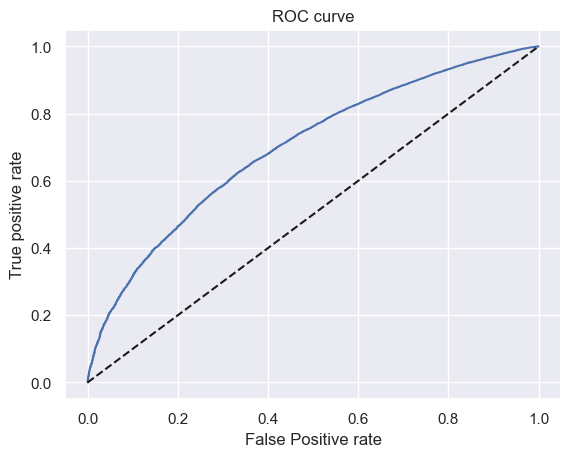

In [276]:
"""7️⃣ Why does ROC curve start at (0,0) and end at (1,1)?

Let’s reason it out.

Threshold = ∞

Predict all 0

TPR = 0

FPR = 0

Threshold = 0

Predict all 1

TPR = 1

FPR = 1

Every model must pass through these points.

If it doesn’t → bug.



🔟 What does “ROC shows TPR as a function of FPR” mean?

This is mathematical language.

It means:

For every false positive rate, how many true positives can I achieve?

Written as a function:

TPR = f(FPR)


Better models:

Rise steeply (high TPR for low FPR)

Hug the top-left corner

Bad models:

Stick near the diagonal
"""

plt.plot(fpr,tpr)
plt.plot(fpr, fpr, linestyle = '--', color = 'k')
plt.xlabel('False Positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')

In [277]:
'''but does the above show that our model is good, what do we compare it to? we need a benchmark!! normally we compare it with predicting by chance, 
which is 50-50 like a coin toss and the dotted line above. the line we plotted is the blue line.
Is line is above any of the 45 deg dotted for any threshold the TPR is better than the one predicted by chance But by how much better.

That where area under ROC comes in .. this area is called Area Under the curve (AUC), its a good overall measure of how good a classification is .. e.g 
area under the curve predicting 50% chance is 50%, and for the model AUC as follows

But what is good enough or not is difficult to say but depends on our data, even an excellent model will not be okay if the data provided is not good enough
HOEVER COMMON SCALE FOR INTERPRETATION OF AREA UNDER THE CURVE IS AS FOLLOWS 

BAD  if ROC is btn 50-60%
POOR  IF Roc IS BTN 60-70%
FAIR if ROC is btn 70-80%
GOOD if ROC is btn 80-90%
EXCELLENT if ROC is btn 90-100%

so basically our model is POOR

But what is most important is knowing to what extent the outcome of interest can be explained by the available information

That is why a few competing models are built for every analytical solution with an application in industry. when possible these competing models 
are built by different modelers or teams of modelers. Deo uses PCA, WOE, Dummy Variables, Bayessian, etc

 What function does ROC plot?

ROC plots TPR as a parametric function of FPR, where the parameter is the threshold. As threshold decreases, both FPR and TPR increase, tracing out the
curve.

 Examples of competing models?


Baseline Logistic Regression
Logistic Regression with Interactions
Random Forest
XGBoost/LightGBM
Neural Network
ElasticNet Logistic Regression
SVM
Naive Bayes
Voting Ensemble
Stacked Ensemble

Regularized Logistic (L1 / L2 / Elastic Net)

Controls overfitting

Feature selection

Decision Tree

Non-linear

Captures interactions

Random Forest

Ensemble of trees

Robust, strong baseline

Gradient Boosting (XGBoost / LightGBM)

State-of-the-art for tabular data

Naive Bayes

Surprisingly strong when assumptions hold

Neural Network (MLP)

Nonlinear, flexible

Needs careful tuning

Scorecard-style model

Business-constrained

Regulatory friendly

Each produces:

Different ROC curves

Different AUCs

Different business trade-offs
Teams build all of these, compare AUC scores, and pick the best one that balances performance, interpretability, and regulatory compliance.
Usually XGBoost wins on performance, but Logistic Regression is kept for regulatory reporting.
'''



# AUC has a deep interpretation: Probability that the model ranks a random positive higher than a random negative
"""Examples:

AUC = 0.5 → random

AUC = 0.7 → 70% chance a positive gets higher score than a negative

AUC = 0.9 → extremely strong ranking power

This is why:

ROC works with probabilities

Not hard predictions (0/1)
"""







AUROC = roc_auc_score(df_actual_predicted_probs['loan_data_targets_test'], df_actual_predicted_probs['y_hat_test_proba'])
AUROC

np.float64(0.698265700554832)

In [278]:
'''Selecting best threshold from ROC curve (without plotting). Three common methods:'''

# 1. Youden’s index (maximises TPR - FPR)
fpr, tpr, thresholds = roc_curve(df_actual_predicted_probs['loan_data_targets_test'], df_actual_predicted_probs['y_hat_test_proba'])
youden = tpr - fpr
best_idx = np.argmax(youden)
best_threshold = thresholds[best_idx]
best_threshold 

np.float64(0.8889846020765703)

In [279]:
# 2. Closest to top‑left corner (minimises distance to (0,1))

distance = np.sqrt((1-tpr)**2 + fpr**2)
best_idx = np.argmin(distance)
best_threshold = thresholds[best_idx]
best_threshold 

np.float64(0.8882263979524598)

In [280]:
# 3. Maximising profit (if you have cost matrix). Use the profit function you already wrote, iterating over thresholds. Example that prints all three:

def print_optimal_thresholds(y_true, y_score,profit_good=100,loss_bad=500):
# def print_optimal_thresholds(y_true, y_score, profit_good=100, loss_bad=500):
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    # Youden
    youden = tpr - fpr
    idx_youden = np.argmax(youden)
    # Distance
    dist = np.sqrt((1-tpr)**2 + fpr**2)
    idx_dist = np.argmin(dist)
    # Profit
    best_profit = -np.inf
    idx_profit = 0
    for i, t in enumerate(thresholds):
        pred = (y_score >= t).astype(int)
        tn = ((pred == 0) & (y_true == 0)).sum()
        fp = ((pred == 1) & (y_true == 0)).sum()
        fn = ((pred == 0) & (y_true == 1)).sum()
        profit = tn*profit_good - fp*profit_good - fn*loss_bad
        if profit > best_profit:
            best_profit = profit
            idx_profit = i
    print(f"Youden threshold: {thresholds[idx_youden]:.3f} (max TPR-FPR)")
    print(f"Distance threshold: {thresholds[idx_dist]:.3f} (closest to top-left)")
    print(f"Profit threshold: {thresholds[idx_profit]:.3f} (max profit)")


print_optimal_thresholds(df_actual_predicted_probs['loan_data_targets_test'],
                         df_actual_predicted_probs['y_hat_test_proba'])

Youden threshold: 0.889 (max TPR-FPR)

Distance threshold: 0.888 (closest to top-left)

Profit threshold: 0.456 (max profit)

In [281]:
# 3 Programmatic ROC Threshold Functions 

def best_youden(fpr, tpr, thresholds):
    """Maximizes separation from random guessing"""
    J = tpr - fpr
    idx = np.argmax(J)
    return thresholds[idx], tpr[idx], fpr[idx], J[idx]

def closest_to_perfect(fpr, tpr, thresholds):
    """Minimizes Euclidean distance to (0,1) top-left corner"""
    dist = np.sqrt((1 - tpr)**2 + fpr**2)
    idx = np.argmin(dist)
    return thresholds[idx], tpr[idx], fpr[idx], -dist[idx]

def cost_optimal(fpr, tpr, thresholds, C_FN=5, C_FP=1):
    """Minimizes business cost (FN = missed bad, FP = rejected good)"""
    cost = (1 - tpr)*C_FN + fpr*C_FP
    idx = np.argmin(cost)
    return thresholds[idx], tpr[idx], fpr[idx], -cost[idx]



| Domain                                     | “Good” AUC Range | Why this bar exists                            | Concrete real-world example                                  |
| ------------------------------------------ | ---------------- | ---------------------------------------------- | ------------------------------------------------------------ |
| **Cancer screening (breast, lung, colon)** | **≥ 0.95**       | Missing positives means preventable death      | Mammogram AI with AUC=0.92 rejected for population screening |
| **ICU mortality prediction**               | **≥ 0.90**       | Decisions affect life support & triage         | ICU risk model with AUC=0.85 deemed unsafe                   |
| **Sepsis early warning**                   | **≥ 0.88**       | Late detection rapidly increases mortality     | Hospitals require extremely high recall                      |
| **Credit risk (retail loans)**             | **0.70–0.80**    | Defaults partly random; borrowers game systems | FICO & Basel models ~0.72–0.78                               |
| **Credit cards default risk**              | **0.75–0.82**    | Frequent decisions, smaller margins            | Visa internal models ~0.78                                   |
| **Fraud detection (cards, payments)**      | **≥ 0.85**       | Missed fraud causes immediate financial loss   | Banks reject models <0.80                                    |
| **Insurance claim fraud**                  | **0.75–0.85**    | Claims noisy; fraud is rare                    | SIU models ~0.80                                             |
| **Customer churn (telecom)**               | **0.65–0.75**    | Human behavior unstable & emotional            | AUC=0.71 considered strong                                   |
| **Subscription churn (SaaS)**              | **0.70–0.80**    | Product usage is predictive                    | B2B SaaS churn models ~0.78                                  |
| **Marketing response (emails, ads)**       | **0.60–0.70**    | Behavior close to random                       | AUC=0.63 → +22% revenue                                      |
| **Ad click-through rate**                  | **0.55–0.65**    | Humans scroll randomly                         | Google ads consider 0.6 strong                               |
| **Stock price direction (short-term)**     | **0.52–0.58**    | Efficient markets destroy signal               | AUC=0.55 can beat benchmarks                                 |
| **Algorithmic trading (HFT)**              | **0.51–0.55**    | Micro-edge multiplied millions of times        | AUC=0.53 → profitable strategy                               |
| **Weather forecasting (rain/no rain)**     | **0.80–0.90**    | Physical laws constrain randomness             | Below 0.75 unacceptable                                      |
| **Earthquake prediction**                  | **< 0.60**       | Largely stochastic                             | Even 0.58 is scientific breakthrough                         |
| **Hiring / candidate screening**           | **≥ 0.75**       | Legal & fairness constraints                   | 0.65 considered risky                                        |
| **Recidivism prediction**                  | **0.65–0.75**    | Human life paths highly chaotic                | COMPAS ~0.69                                                 |
| **Spam detection**                         | **≥ 0.90**       | Huge data + clear patterns                     | Gmail spam filters >0.95                                     |
| **Face recognition**                       | **≥ 0.98**       | Security-critical                              | Border control systems demand extreme accuracy               |





⚠️ Core principle (this matters more than math)

AUC is not a score of model intelligence.
It is a score of how much structure exists in reality.

2️⃣ Why AUC alone is meaningless without business context

Let’s destroy a common misunderstanding.

❌ Wrong thinking

“My AUC is only 0.65, my model is bad.”

✅ Correct thinking

“How predictable is this phenomenon in principle?”

Examples:

Stock prices → almost random → AUC > 0.55 is gold

Cancer diagnosis → strong biological signals → AUC < 0.95 is dangerous

Same metric. Different universes.


**Gini and Kolmogrov-Smirnov**

In [282]:
#**Plotting Gini**
'''1. Order df that contains the targets and probs by estimated probabilities in ascending order.'''

df_actual_predicted_probs = df_actual_predicted_probs.sort_values('y_hat_test_proba')
df_actual_predicted_probs.head(5)


,loan_data_targets_test,y_hat_test_proba,y_hat_test
18540,0,0.439336,0
42344,1,0.456190,0
42396,0,0.462075,0
41234,0,0.473127,0
35448,1,0.478157,0


In [283]:
# To calculate cumulative proportions, we re-index the dataframe as it is sorted now, so we need the lowest y_test_proba to have index of zero, 
# the next one 1, and so on 
df_actual_predicted_probs = df_actual_predicted_probs.reset_index()
# We didnt drop index  just in case we want to connect to any of the subsequent calculations to the other dfs
df_actual_predicted_probs.head(5)

,index,loan_data_targets_test,y_hat_test_proba,y_hat_test
0,18540,0,0.439336,0
1,42344,1,0.456190,0
2,42396,0,0.462075,0
3,41234,0,0.473127,0
4,35448,1,0.478157,0


In [284]:
# Cumulative % of total population
# Cumulative % of good borrowers
# Cumulative % of bad borrowers

df_actual_predicted_probs['Cumulative N Population'] = df_actual_predicted_probs.index + 1 #index of the row plus 1 

# total no of 1s in loan_data_target_test upto that row
df_actual_predicted_probs['Cumulative N Good'] = df_actual_predicted_probs['loan_data_targets_test'].cumsum() 

df_actual_predicted_probs['Cumulative N Bad'] = df_actual_predicted_probs['Cumulative N Population'] -\
df_actual_predicted_probs['loan_data_targets_test'].cumsum() # total no of 0s in loan_data_target_test upto that row, which is total number of borrowers - number of 1s upto a row

df_actual_predicted_probs.head()


,index,loan_data_targets_test,y_hat_test_proba,y_hat_test,Cumulative N Population,Cumulative N Good,Cumulative N Bad
0,18540,0,0.439336,0,1,0,1
1,42344,1,0.456190,0,2,1,1
2,42396,0,0.462075,0,3,1,2
3,41234,0,0.473127,0,4,1,3
4,35448,1,0.478157,0,5,2,3


In [285]:
#Finding respective cumulative proportions ie numbers divided by total to be more usable for probability distribution plots

#Cumulative proportion of all borrowers on every row is the total no. upto that row divided by total no of borrowers altogether
df_actual_predicted_probs['Cumulative Perc Population'] = df_actual_predicted_probs['Cumulative N Population'] / df_actual_predicted_probs.shape[0] 

#divide by total number of good borrowers altogether ie sum of loan_data_targets_test variable
df_actual_predicted_probs['Cumulative Perc Good'] = df_actual_predicted_probs['Cumulative N Good'] / df_actual_predicted_probs['loan_data_targets_test']\
.sum() 

df_actual_predicted_probs['Cumulative Perc Bad'] = df_actual_predicted_probs['Cumulative N Bad'] / (df_actual_predicted_probs.shape[0] - \
                                                                                        df_actual_predicted_probs['loan_data_targets_test'].sum())
df_actual_predicted_probs.head()


,index,loan_data_targets_test,y_hat_test_proba,y_hat_test,Cumulative N Population,Cumulative N Good,Cumulative N Bad,Cumulative Perc Population,Cumulative Perc Good,Cumulative Perc Bad
0,18540,0,0.439336,0,1,0,1,0.000011,0.000000,0.000098
1,42344,1,0.456190,0,2,1,1,0.000021,0.000012,0.000098
2,42396,0,0.462075,0,3,1,2,0.000032,0.000012,0.000196
3,41234,0,0.473127,0,4,1,3,0.000043,0.000012,0.000294
4,35448,1,0.478157,0,5,2,3,0.000054,0.000024,0.000294


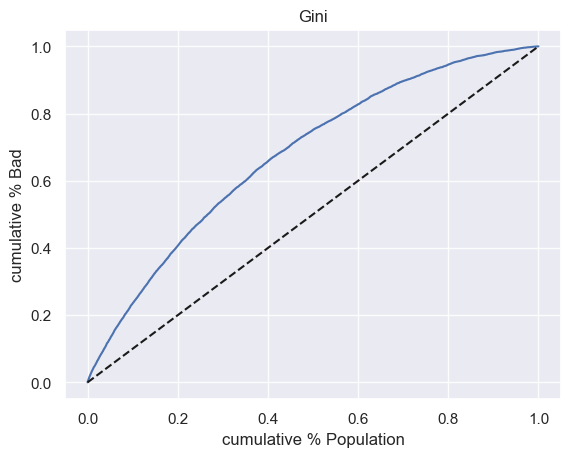

In [286]:
# **Gini plot** Cumulative percentage of bad borrowers as a function of a cumulative percentage of all borrowers

'''
🔑 ONE-SENTENCE MASTERY
Gini measures how fast defaults concentrate as you move through applicants ranked from safest to riskiest (ascending PD sort);
KS measures the maximum vertical gap between cumulative bad/good curves at a specific PD threshold; higher thresholds always increase false negatives 
(missed defaults), never decrease them.

Gini curve: Plot (Cum % Pop, Cum % Bad) → if starts flat (misses defaults early), then steepens
'''


plt.plot(df_actual_predicted_probs['Cumulative Perc Population'], df_actual_predicted_probs['Cumulative Perc Bad'])
plt.plot(df_actual_predicted_probs['Cumulative Perc Population'], df_actual_predicted_probs['Cumulative Perc Population'], linestyle = '--' , color ='k')
plt.xlabel('cumulative % Population')
plt.ylabel('cumulative % Bad')
plt.title('Gini') 
plt.grid(alpha=0.9)
#''' Notice  gini curve is similar to roc curve thsts because they are 2 ways of plotting same thing. Gini = AUROC*2 -1 and (AUROC = Gini + 1) / 2'''


In [287]:
Gini = AUROC * 2 - 1
Gini

np.float64(0.3965314011096639)

Text(0.5, 1.0, 'Kolmogorov-Smirnov')

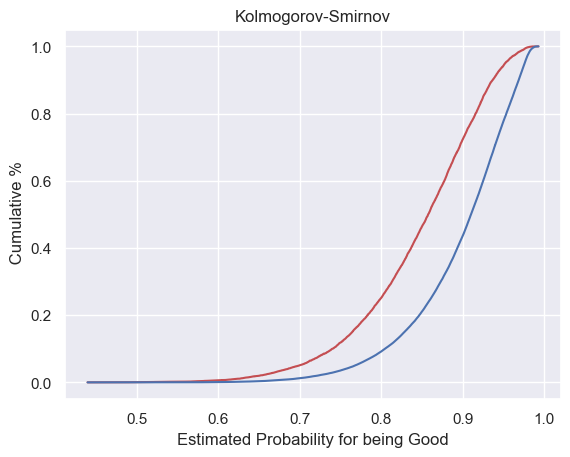

In [288]:
# K-S   'Kolmogorov-Smirnov'

"""
🔥 WHY CUM BAD IS ABOVE CUM GOOD
🧠 If model is good:
BADs concentrate at HIGH PD (right side)
GOODs concentrate at LOW PD (left side)

So:

When you move left → right:

BAD grows faster than GOOD

👉 That’s why:

Cumulative BAD > Cumulative GOOD
"""

plt.plot(df_actual_predicted_probs['y_hat_test_proba'], df_actual_predicted_probs['Cumulative Perc Bad'], color = 'r')
plt.plot(df_actual_predicted_probs['y_hat_test_proba'], df_actual_predicted_probs['Cumulative Perc Good'], color = 'b')
plt.xlabel('Estimated Probability for being Good')
plt.ylabel(' Cumulative %')
plt.title('Kolmogorov-Smirnov') 

In [289]:

KS = max(df_actual_predicted_probs['Cumulative Perc Bad'] - df_actual_predicted_probs['Cumulative Perc Good'])
KS #Significant away from 0 , shows the 2 cum distribution fns are sufficiently far away from each other as seen even by the graph and the model has suficient predictive power

0.29112146049785914

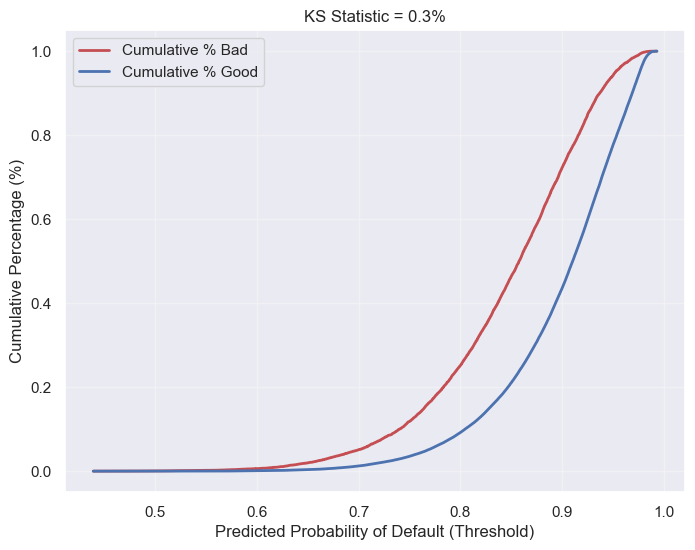

In [290]:

# ===== KS PLOT =====

plt.figure(figsize=(8,6))
plt.plot(df_actual_predicted_probs['y_hat_test_proba'], df_actual_predicted_probs['Cumulative Perc Bad'], 'r-', label='Cumulative % Bad', linewidth=2)
plt.plot(df_actual_predicted_probs['y_hat_test_proba'], df_actual_predicted_probs['Cumulative Perc Good'], 'b-', label='Cumulative % Good', linewidth=2)
ks_value = (df_actual_predicted_probs['Cumulative Perc Bad'] - df_actual_predicted_probs['Cumulative Perc Good']).abs().max()
plt.title(f'KS Statistic = {ks_value:.1f}%')
plt.xlabel('Predicted Probability of Default (Threshold)')
plt.ylabel('Cumulative Percentage (%)')
plt.legend()
plt.grid(alpha=0.3)



In [291]:
# ✅ HOW TO GET BEST KS THRESHOLD (NO GRAPH)

df_actual_predicted_probs['diff'] = df_actual_predicted_probs['Cumulative Perc Bad'] - df_actual_predicted_probs['Cumulative Perc Good']

ks_idx = df_actual_predicted_probs['diff'].idxmax()

ks_value = df_actual_predicted_probs.loc[ks_idx, 'diff']
ks_threshold = df_actual_predicted_probs.loc[ks_idx, 'y_hat_test_proba']
print(ks_idx)
print("KS:", ks_value)
print("Best threshold:", ks_threshold)

38003

KS: 0.29112146049785914

Best threshold: 0.888984416497924

#                                            **CREATING A SCORECARD**
   **CREATING A SCORECARD**                                            

**Creating a Scorecard**
**Turning pd model into a scorecard*
We scored the coefficients of our pd model in a df called summary table, it contains all the regression  coefficients for all independent dummy variables  except for the reference categories. Because we dont include reference categories when estimating the model. however when using it to predict probability of default we just take those as zeros. 

In scorecard we want it as interpretable as possible so we include the refernce categories into the scorecards.

In [292]:
np.array(ref_categories)

array(['grade:::B', 'verification_status:::Verified',
       'purpose:::debt_consolidation', 'initial_list_status:::f',
       'home_ownership:::MORTGAGE', 'addr_state:::AR_MI_PA_OH_MN',
       'term:::36', 'emp_length:::Missing', 'mths_since_issue_d:::42-48',
       'int_rate:::12.025-15.74', 'annual_inc:::40k-50k',
       'funded:::funded:medium', 'mths_since_last_record:::Missing',
       'mths_since_last_major_derog:::Missing',
       'mths_since_last_delinq:::>57', 'total_rev_hi_lim:::20k-40k',
       'dti:::10-20'], dtype='<U37')

In [293]:
df_ref_categories = pd.DataFrame(ref_categories, columns = ["Feature Name"])
df_ref_categories['Coefficients'] = 0
df_ref_categories['p_values'] = np.nan
df_ref_categories.head()

,Feature Name,Coefficients,p_values
0,grade:::B,0,NaN
1,verification_status:::Verified,0,NaN
2,purpose:::debt_consolidation,0,NaN
3,initial_list_status:::f,0,NaN
4,home_ownership:::MORTGAGE,0,NaN


In [294]:
summary_table.head(5)

,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag
0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE
1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,0.000775,False,OK
2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000,False,OK
3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000,False,OK
4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000,False,OK


In [295]:
df_scorecard = pd.concat([summary_table, df_ref_categories])
'''
This way we will get the output from our PD model as if we included the reference categories in the model estimation and had coeficients of 0 '''


#df_scorecard = df_scorecard.reset_index()
df_scorecard



,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag
0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE
1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,7.753194e-04,False,OK
2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000e+00,False,OK
3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000e+00,False,OK
4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000e+00,False,OK
5,grade:::F,-0.718041,9.521838e-56,-0.718041,0.045650,-15.729327,0.000000e+00,False,OK
6,grade:::G,-0.834908,1.074694e-43,-0.834908,0.060230,-13.862109,0.000000e+00,False,OK
7,verification_status:::Not Verified,0.085987,3.976779e-09,0.085987,0.014611,5.885156,3.976779e-09,False,OK
8,verification_status:::Source Verified,-0.010547,4.341481e-01,-0.010547,0.013485,-0.782113,4.341481e-01,False,OK
9,purpose:::car,0.208465,1.675658e-04,0.208465,0.055391,3.763479,1.675658e-04,False,OK


In [296]:
df_scorecard = df_scorecard.reset_index()
df_scorecard

,index,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag
0,0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE
1,1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,7.753194e-04,False,OK
2,2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000e+00,False,OK
3,3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000e+00,False,OK
4,4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000e+00,False,OK
5,5,grade:::F,-0.718041,9.521838e-56,-0.718041,0.045650,-15.729327,0.000000e+00,False,OK
6,6,grade:::G,-0.834908,1.074694e-43,-0.834908,0.060230,-13.862109,0.000000e+00,False,OK
7,7,verification_status:::Not Verified,0.085987,3.976779e-09,0.085987,0.014611,5.885156,3.976779e-09,False,OK
8,8,verification_status:::Source Verified,-0.010547,4.341481e-01,-0.010547,0.013485,-0.782113,4.341481e-01,False,OK
9,9,purpose:::car,0.208465,1.675658e-04,0.208465,0.055391,3.763479,1.675658e-04,False,OK


In [297]:
df_scorecard.index, np.array(df_scorecard.index.to_list()), np.array(df_scorecard.columns)

(RangeIndex(start=0, stop=97, step=1),
 array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
        51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
        68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
        85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96]),
 array(['index', 'Feature Name', 'Coefficients', 'p_values', 'coef',
        'Std_Error', 'z', 'p_value', 'untrustworthy', 'flag'], dtype=object))

In [298]:
# ✅ STEP 3: Derive Original Feature Name CORRECTLY
# Ensuring we have the names of the original independent variables as well
pd.options.display.max_columns = None 

# USE THE PROPERLY ALIGNED COLUMN
df_scorecard['Original feature name'] = df_scorecard['Feature Name'].str.split(':::').str[0]

# VERIFY FIX WORKED
print("\n=== GROUP MIN/MAX AFTER FIX === \n")
group_mins = df_scorecard.groupby('Original feature name')['Coefficients'].min() #minimum per each original independent variable 
group_maxs = df_scorecard.groupby('Original feature name')['Coefficients'].max()
print("Min per group:\n", group_mins)
print("\nMax per group:\n", group_maxs)
print("\nSum of mins:", group_mins.sum())
"Sum of maxs:", group_maxs.sum()

=== GROUP MIN/MAX AFTER FIX ===

Min per group:
 Original feature name
Intercept                      2.001158
addr_state                    -0.109940
annual_inc                    -0.167439
dti                           -0.133142
emp_length                     0.000000
funded                        -0.119452
grade                         -0.834908
home_ownership                -0.119802
initial_list_status            0.000000
int_rate                      -0.415969
mths_since_issue_d            -0.705802
mths_since_last_delinq         0.000000
mths_since_last_major_derog   -0.104101
mths_since_last_record        -0.348652
purpose                       -0.435473
term                           0.000000
total_rev_hi_lim              -0.012383
verification_status           -0.010547
Name: Coefficients, dtype: float64

Max per group:
 Original feature name
Intercept                      2.001158
addr_state                     0.430438
annual_inc                     0.457272
dti                            0.139071
emp_length                     0.000000
funded                         0.000000
grade                          0.220607
home_ownership                 0.000000
initial_list_status            0.070997
int_rate                       0.655776
mths_since_issue_d             0.453237
mths_since_last_delinq         0.443444
mths_since_last_major_derog    0.000000
mths_since_last_record         0.211117
purpose                        0.356729
term                           0.000000
total_rev_hi_lim               0.062226
verification_status            0.085987
Name: Coefficients, dtype: float64

Sum of mins: -1.5164504202621938

('Sum of maxs:', np.float64(5.588058538528518))

In [299]:

# reason it is not doing what i expect 
'''
| Original feature name | Coefficient |
| --------------------- | ----------: |
| grade                 |         0.2 |
| grade                 |        -0.1 |
| grade                 |        -0.5 |
| income                |         0.3 |
| income                |        -0.2 |


group_features=df_scorecard.groupby('Original feature name')['Coefficient']

Pandas creates:
grade → [0.2,-0.1,-0.5]
income → [0.3,-0.2]

but stops. You must ask for example:
group_features.min()

Now:
grade   -0.5
income  -0.2

or:

group_features.max()

Output:

grade    0.2
income   0.3

or:

group_features.sum()

Output:

grade   -0.4
income   0.1
'''

group_features = df_scorecard.groupby('Original feature name')['Coefficients']

# thats why the following is going to output an object 
group_features 

In [300]:
group_features.sum()

Original feature name
Intercept                      2.001158
addr_state                     0.700607
annual_inc                     2.011866
dti                           -0.091292
emp_length                     0.000000
funded                        -0.225698
grade                         -2.411849
home_ownership                -0.122839
initial_list_status            0.070997
int_rate                       0.275252
mths_since_issue_d            -1.379237
mths_since_last_delinq         1.982384
mths_since_last_major_derog   -0.229434
mths_since_last_record        -0.065942
purpose                        0.113945
term                           0.000000
total_rev_hi_lim               0.080975
verification_status            0.075440
Name: Coefficients, dtype: float64

In [301]:
df_scorecard

,index,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag,Original feature name
0,0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE,Intercept
1,1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,7.753194e-04,False,OK,grade
2,2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000e+00,False,OK,grade
3,3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000e+00,False,OK,grade
4,4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000e+00,False,OK,grade
5,5,grade:::F,-0.718041,9.521838e-56,-0.718041,0.045650,-15.729327,0.000000e+00,False,OK,grade
6,6,grade:::G,-0.834908,1.074694e-43,-0.834908,0.060230,-13.862109,0.000000e+00,False,OK,grade
7,7,verification_status:::Not Verified,0.085987,3.976779e-09,0.085987,0.014611,5.885156,3.976779e-09,False,OK,verification_status
8,8,verification_status:::Source Verified,-0.010547,4.341481e-01,-0.010547,0.013485,-0.782113,4.341481e-01,False,OK,verification_status
9,9,purpose:::car,0.208465,1.675658e-04,0.208465,0.055391,3.763479,1.675658e-04,False,OK,purpose


In [302]:
# ============================================================
# 1. EXCLUDE REGRESSION INTERCEPT FROM FEATURE CONTRIBUTIONS
# ============================================================

min_score = 300
max_score = 850

feat_mask = df_scorecard['Original feature name'] != 'Intercept'


# ============================================================
# 2. FIND MINIMUM AND MAXIMUM TOTAL FEATURE CONTRIBUTIONS
# ============================================================

min_sum_coef = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Coefficients']
    .min()
    .sum()
)

max_sum_coef = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Coefficients']
    .max()
    .sum()
)


# ============================================================
# 3. CALCULATE SCALING FACTOR
# ============================================================

a = (
    max_score - min_score
) / (
    max_sum_coef - min_sum_coef
)


# ============================================================
# 4. CALCULATE SCORECARD INTERCEPT POINTS
# ============================================================

df_scorecard.loc[~feat_mask, 'Score - Float'] = (
    min_score - a * min_sum_coef
) 
#  REMEMBER THAT (min_score - a * min_sum_coef) + a * min_sum_coef = min_score = 300 hence intercept is the value where the minimum feature points score
# is at its lowests, in this case at starting point 300


# ============================================================
# 5. CALCULATE FEATURE POINTS
# ============================================================

df_scorecard.loc[feat_mask, 'Score - Float'] = (
    df_scorecard.loc[feat_mask, 'Coefficients'] * a
)


# ============================================================
# 6. ROUND
# ============================================================

df_scorecard['Score'] = (
    df_scorecard['Score - Float']
    .round()                                                       # ''' this causes accumulated roundig  error'''
    
)



# ============================================================
# 7. CHECK FINAL RANGE
# ============================================================

intercept_pts = (
    df_scorecard.loc[~feat_mask, 'Score - Float']
    .iloc[0]
)


intercept_pts = (
    df_scorecard.loc[~feat_mask, 'Score'] # unlike the above this gives rounding errors
    .iloc[0]
)
final_min = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Score']
    .min()
    .sum()
    + intercept_pts
)

final_max = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Score']
    .max()
    .sum()
    + intercept_pts
)


final_min_float = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Score - Float']
    .min()
    .sum()
    + intercept_pts
)

final_max_float = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Score - Float']
    .max()
    .sum()
    + intercept_pts
)
print(f"Final Scorecard Range: {final_min} to {final_max}")
print(f"Final Scorecard Range Float: {final_min_float} to {final_max_float}")

final_min_float = final_min_float.round()
final_max_float = final_max_float.round(0)

print(f"Final Scorecard Range Float: {final_min_float} to {final_max_float}")



'''
The Floating-Point Rounding "Leak": Your unrounded float ranges are exactly 300.0 and 850.0. When you apply .round() to independent groups and 
sum them up, a phenomenon called "rounding accumulation" occurs. If 15 features all round down by 0.1, your final minimum score drops from 300 to 299.

To force the final rounded ranges to equal exactly 300 and 850, you must handle the reference categories explicitly by filling any empty calculation 
rows with 0, and then assign the final rounding slack directly to the intercept.'''

# df_scorecard

Final Scorecard Range: 299.0 to 849.0

Final Scorecard Range Float: 299.6821385591959 to 849.6821385591959

Final Scorecard Range Float: 300.0 to 850.0

'\nThe Floating-Point Rounding "Leak": Your unrounded float ranges are exactly 300.0 and 850.0. When you apply .round() to independent groups and \nsum them up, a phenomenon called "rounding accumulation" occurs. If 15 features all round down by 0.1, your final minimum score drops from 300 to 299.\n\nTo force the final rounded ranges to equal exactly 300 and 850, you must handle the reference categories explicitly by filling any empty calculation \nrows with 0, and then assign the final rounding slack directly to the intercept.'

In [303]:
final_min = (df_scorecard[df_scorecard['Original feature name'] != 'Intercept']
             .groupby('Original feature name')['Score'].min().sum()
             + df_scorecard.loc[df_scorecard['Original feature name'] == 'Intercept', 'Score'].iloc[0])

final_max = (df_scorecard[df_scorecard['Original feature name'] != 'Intercept']
             .groupby('Original feature name')['Score'].max().sum()
             + df_scorecard.loc[df_scorecard['Original feature name'] == 'Intercept', 'Score'].iloc[0])

print(f"Final Scorecard Range: {final_min} to {final_max}")
# assert 300 <= final_min <= final_max <= 850, "Scorecard out of bounds!"

Final Scorecard Range: 299.0 to 849.0

In [304]:
print(df_scorecard['Score - Float'].dtype)

print("\nNaN:")
print(df_scorecard['Score - Float'].isna().sum())

print("\n+inf:")
print(np.isposinf(df_scorecard['Score - Float']).sum())

print("\n-inf:")
print(np.isneginf(df_scorecard['Score - Float']).sum())

print("\nNon-numeric values:")
print(
    df_scorecard.loc[
        pd.to_numeric(df_scorecard['Score - Float'], errors='coerce').isna(),
        ['Original feature name', 'Coefficients', 'Score - Float']
    ]
)

float64

NaN:

0

+inf:

0

-inf:

0

Non-numeric values:

Empty DataFrame
Columns: [Original feature name, Coefficients, Score - Float]
Index: []

In [305]:

# Fix your NaN references instantly by making them 0 points
'''df_scorecard['Score - Float'] = df_scorecard['Score - Float'].fillna(0.0)''' # THIS IS DANGEROUS IT INFLATES SCORE FOR WHEN 0 IS LARGEST VALUE AVOID THIS

# ============================================================
# . ROUNDING & RANGE INSULATION
# ============================================================
# First round the features safely
df_scorecard['Score'] = df_scorecard['Score - Float'].round().astype(int)



# Calculate what the features sum up to when rounded
current_min_features = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Score']
    .min()
    .sum()
)

# FORCE the intercept to absorb the floating-point rounding errors
forced_intercept = min_score - current_min_features
df_scorecard.loc[~feat_mask, 'Score'] = forced_intercept


# 5. VERIFY RANGE
intercept_pts = df_scorecard.loc[~feat_mask, 'Score'].iloc[0]

final_min = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum() + intercept_pts
final_max = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum() + intercept_pts

print(f"\n✅ Final Scorecard Range: {final_min} to {final_max}")
assert 300 <= final_min <= final_max <= 850, f"🚨 OUT OF BOUNDS! min={final_min}, max={final_max}" 

✅ Final Scorecard Range: 300 to 850

In [306]:

# ============================================================
# 3. UNROUNDED SCORES
# ============================================================
# Intercept (constant) will be set later
# Feature scores (unrounded)
df_scorecard.loc[feat_mask, 'Score - Float'] = df_scorecard.loc[feat_mask, 'Coefficients'] * a

# ============================================================
# 4. ROUND FEATURE SCORES
# ============================================================
df_scorecard['Score'] = np.nan   # create column
df_scorecard.loc[feat_mask, 'Score'] = df_scorecard.loc[feat_mask, 'Score - Float'].round().astype(int)

# ============================================================
# 5. COMPUTE MIN/MAX PER FEATURE AFTER ROUNDING
# ============================================================
sum_min_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum()
sum_max_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum()

# ============================================================
# 6. SET INTERCEPT TO FIX MINIMUM = 300
# ============================================================
intercept_score = min_score - sum_min_rounded
df_scorecard.loc[~feat_mask, 'Score'] = intercept_score

# ============================================================
# 7. ADJUST MAXIMUM TO 850 (if needed)
# ============================================================
max_actual = intercept_score + sum_max_rounded

if max_actual != max_score:
    diff = max_score - max_actual  # positive means we need to add points
    
    # Get rows that give the maximum score per feature (tie-breaking: pick first)
    max_rows = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].idxmax()
    
    while max_actual != max_score:
        # We'll adjust the score of one max row by +1 or -1
        # Pick the first feature (or iterate)
        for feat in df_scorecard.loc[feat_mask, 'Original feature name'].unique():
            if max_actual == max_score:
                break
            # Get rows of this feature that currently have the maximum score
            max_for_feat = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat), 'Score'].max()
            rows_to_adjust = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat) & 
                                              (df_scorecard['Score'] == max_for_feat)].index
            
            if len(rows_to_adjust) > 0:
                # Adjust by sign of diff
                step = 1 if diff > 0 else -1
                idx = rows_to_adjust[0]
                df_scorecard.loc[idx, 'Score'] += step
                # Recompute sums
                sum_min_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum()
                sum_max_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum()
                intercept_score = min_score - sum_min_rounded
                df_scorecard.loc[~feat_mask, 'Score'] = intercept_score
                max_actual = intercept_score + sum_max_rounded
                diff = max_score - max_actual
                # Break if done
                if max_actual == max_score:
                    break

# ============================================================
# 8. VERIFY FINAL RANGE
# ============================================================
intercept_pts = df_scorecard.loc[~feat_mask, 'Score'].iloc[0]
final_min = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum() + intercept_pts
final_max = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum() + intercept_pts

print(f"Final Scorecard Range: {final_min} to {final_max}")
assert final_min == 300 and final_max == 850, "Range not exact!"

Final Scorecard Range: 300.0 to 850.0

In [307]:
'''Rewriting the second (longer) block with the same logic
You asked to rewrite the second block to avoid the IntCastingNaNError and keep astype(int).
The error occurs because you created df_scorecard['Score'] = np.nan and then tried to assign rounded floats to rows that are not feat_mask 
(they remain NaN). But later you assign the intercept to ~feat_mask, so that’s fine.
However, if feat_mask does not cover all rows (the intercept row), the column will have NaN for that row initially, but you fill it later. 
The error IntCastingNaNError can happen if you try to cast a column containing NaN to int. But you are casting only
df_scorecard.loc[feat_mask, 'Score - Float'].round().astype(int), which should be fine because those rows are numeric and have no NaN. 
So that error might be from earlier when the column had NaNs and you tried to convert the whole column. 
In your code, you do df_scorecard['Score'] = np.nan first, then assign to feat_mask rows only, so the column has NaN in intercept row, 
but later you assign an integer to that row, so it’s okay.
I'll provide a clean rewrite that uses the same adjustment loop as above, but with the exact structure of your second block.'''



# ============================================================
# 3. UNROUNDED SCORES (intercept will be set later)
# ============================================================
df_scorecard.loc[feat_mask, 'Score - Float'] = df_scorecard.loc[feat_mask, 'Coefficients'] * a

# Fill any NaN (should not happen, but safe)
df_scorecard['Score - Float'] = df_scorecard['Score - Float'].fillna(0.0)

# ============================================================
# 4. ROUND FEATURE SCORES
# ============================================================
df_scorecard['Score'] = np.nan   # create column
df_scorecard.loc[feat_mask, 'Score'] = df_scorecard.loc[feat_mask, 'Score - Float'].round().astype(int)

# ============================================================
# 5. COMPUTE MIN/MAX PER FEATURE AFTER ROUNDING
# ============================================================
sum_min_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum()
sum_max_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum()

# ============================================================
# 6. SET INTERCEPT TO FIX MINIMUM = 300
# ============================================================
intercept_score = min_score - sum_min_rounded
df_scorecard.loc[~feat_mask, 'Score'] = intercept_score

# ============================================================
# 7. ADJUST MAXIMUM TO 850 (if needed)
# ============================================================
max_actual = intercept_score + sum_max_rounded

# Bring max down to 850 if it overshoots
while max_actual > max_score:
    adjusted = False
    for feat in df_scorecard.loc[feat_mask, 'Original feature name'].unique():
        max_for_feat = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat), 'Score'].max()
        min_for_feat = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat), 'Score'].min()
        if max_for_feat > min_for_feat:
            idx = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat) & 
                                   (df_scorecard['Score'] == max_for_feat)].index[0]
            df_scorecard.loc[idx, 'Score'] -= 1
            adjusted = True
            break
    if not adjusted:
        break
    # Recompute sums and intercept
    sum_min_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum()
    sum_max_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum()
    intercept_score = min_score - sum_min_rounded
    df_scorecard.loc[~feat_mask, 'Score'] = intercept_score
    max_actual = intercept_score + sum_max_rounded

# ============================================================
# 8. VERIFY FINAL RANGE
# ============================================================
intercept_pts = df_scorecard.loc[~feat_mask, 'Score'].iloc[0]
final_min = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum() + intercept_pts
final_max = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum() + intercept_pts

print(f"Final Scorecard Range: {final_min} to {final_max}")
assert final_min == 300 and final_max == 850, "Range not exact!"



Final Scorecard Range: 300.0 to 850.0

In [308]:

# ============================================================
# 7. ADJUST MAXIMUM TO 850 (if needed)
# ============================================================
max_actual = intercept_score + sum_max_rounded

if max_actual != max_score:
    diff = max_score - max_actual  # positive means we need to add points
    
    while max_actual != max_score:
        for feat in df_scorecard.loc[feat_mask, 'Original feature name'].unique():
            if max_actual == max_score:
                break
                
            # Filter condition for this specific feature group
            current_feat_mask = feat_mask & (df_scorecard['Original feature name'] == feat)
            
            # FIX: Added .dropna() to max extraction loop
            max_for_feat = df_scorecard.loc[current_feat_mask, 'Score'].dropna().max()
            
            rows_to_adjust = df_scorecard.loc[current_feat_mask & (df_scorecard['Score'] == max_for_feat)].index
            
            if len(rows_to_adjust) > 0:
                step = 1 if diff > 0 else -1
                idx = rows_to_adjust[0]
                df_scorecard.loc[idx, 'Score'] += step
                
                # Recompute sums with .dropna() handling
                sum_min_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().dropna().sum()
                sum_max_rounded = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().dropna().sum()
                
                intercept_score = min_score - sum_min_rounded
                df_scorecard.loc[~feat_mask, 'Score'] = intercept_score
                max_actual = intercept_score + sum_max_rounded
                diff = max_score - max_actual
                
                if max_actual == max_score:
                    break

print(f"Final Scorecard Range: {intercept_score + sum_min_rounded} to {intercept_score + sum_max_rounded}")


Final Scorecard Range: 300.0 to 850.0

In [309]:
print("SHAPE:")
print(df_scorecard.shape)

print("\nCOLUMNS:")
print(df_scorecard.columns.tolist())

print("\nORIGINAL FEATURE NAMES:")
print(df_scorecard['Original feature name'].unique())

print("\nCOUNTS:")
print(
    df_scorecard['Original feature name']
    .value_counts(dropna=False)
)

print("\nINTERCEPT SEARCH:")
print(
    df_scorecard[
        df_scorecard.astype(str)
        .apply(
            lambda col: col.str.contains(
                'Intercept',
                case=False,
                na=False
            )
        )
        .any(axis=1)
    ].to_string()
)

print("\nCOEFFICIENT NaNs:")
print(
    df_scorecard[
        df_scorecard['Coefficients'].isna()
    ].to_string()
)

SHAPE:

(97, 13)

COLUMNS:

[
    'index',
    'Feature Name',
    'Coefficients',
    'p_values',
    'coef',
    'Std_Error',
    'z',
    'p_value',
    'untrustworthy',
    'flag',
    'Original feature name',
    'Score - Float',
    'Score'
]

ORIGINAL FEATURE NAMES:

...

Original feature name
purpose                        14
annual_inc                     12
addr_state                     11
mths_since_issue_d              8
grade                           7
mths_since_last_delinq          6
int_rate                        5
mths_since_last_record          5
mths_since_last_major_derog     5
total_rev_hi_lim                5
funded                          4
dti                             4
verification_status             3
home_ownership                  3
initial_list_status             2
term                            1
Intercept                       1
emp_length                      1
Name: count, dtype: int64

INTERCEPT SEARCH:

index Feature Name  Coefficients  p_values      coef  Std_Error   z  p_value untrustworthy      flag Original 
feature name  Score - Float  Score
0      0    Intercept      2.001158       NaN  2.001158        NaN NaN      NaN          True  UNSTABLE            
Intercept     572.317861  573.0

COEFFICIENT NaNs:

Empty DataFrame
Columns: 
Index: []

In [310]:
# TO REMOVE CASTING ERROR use dropna()

min_sum_coef = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Coefficients']
    .min()
    .dropna()
    .sum()
)

max_sum_coef = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Coefficients']
    .max()
    .dropna()
    .sum()
)

In [311]:
feat_mask = df_scorecard['Original feature name'] != 'Intercept'

feat_rows = df_scorecard[df_scorecard['Original feature name'] != 'Intercept']
# which is same as below
feat_rows = df_scorecard[feat_mask]


In [312]:

# 6. VERIFY BOUNDS
final_min = df_scorecard.loc[df_scorecard['Original feature name'] != 'Intercept'] \
              .groupby('Original feature name')['Score'].min().sum() + df_scorecard.loc[0, 'Score']
final_max = df_scorecard.loc[df_scorecard['Original feature name'] != 'Intercept'] \
              .groupby('Original feature name')['Score'].max().sum() + df_scorecard.loc[0, 'Score']
print(f"Scorecard Range: {final_min} to {final_max}")

# 7. ASSERTIONS
assert 'Intercept' not in feat_rows['Original feature name'].values, \
    "Intercept found in feature groupby — will cause score range overflow"
assert min_sum_coef < 0, \
    f"min_sum_coef is {min_sum_coef:.3f} — should be negative. Intercept may be contaminating groupby."

print(f"min_sum_coef = {min_sum_coef:.4f}  ✅" if min_sum_coef < 0 else "❌ CHECK GROUPBY")
print(f"max_sum_coef = {max_sum_coef:.4f}  ✅" if max_sum_coef > 0 else "❌ CHECK GROUPBY")

f"🚨 OUT OF BOUNDS! min={final_min}, max={final_max}"

Scorecard Range: 300.0 to 850.0

min_sum_coef = -3.5176  ✅

max_sum_coef = 3.5869  ✅

'🚨 OUT OF BOUNDS! min=300.0, max=850.0'

In [313]:


# ============================================================
# 5. FORCE MINIMUM = 300 via intercept
# ============================================================
current_min_features = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Score']
    .min()
    .sum()
)
forced_intercept = min_score - current_min_features
df_scorecard.loc[~feat_mask, 'Score'] = forced_intercept

# ============================================================
# 6. ADJUST MAXIMUM TO 850 (if needed)
# ============================================================
# Recompute current max
sum_max_features = (
    df_scorecard.loc[feat_mask]
    .groupby('Original feature name')['Score']
    .max()
    .sum()
)
max_actual = forced_intercept + sum_max_features

# We only need to bring it down if it's above 850
while max_actual > max_score:
    # Find one feature that has a maximum score > its minimum
    # We'll decrease that maximum by 1
    adjusted = False
    for feat in df_scorecard.loc[feat_mask, 'Original feature name'].unique():
        # Get max score for this feature
        max_for_feat = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat), 'Score'].max()
        # Get min score for this feature
        min_for_feat = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat), 'Score'].min()
        if max_for_feat > min_for_feat:
            # Decrease one row that has this max
            idx = df_scorecard.loc[feat_mask & (df_scorecard['Original feature name'] == feat) & 
                                   (df_scorecard['Score'] == max_for_feat)].index[0]
            df_scorecard.loc[idx, 'Score'] -= 1
            adjusted = True
            break
    if not adjusted:
        # If no feature can be reduced (all are flat), we can't fix it – but this rarely happens
        break
    # Recompute sums and intercept (intercept may stay same if min sum unchanged)
    current_min_features = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum()
    forced_intercept = min_score - current_min_features
    df_scorecard.loc[~feat_mask, 'Score'] = forced_intercept
    sum_max_features = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum()
    max_actual = forced_intercept + sum_max_features

In [314]:


# 5. Iterative Drift Adjustment (WHILE loop, excludes intercept from groupby)
while True:
    feat_min = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score - Float'].min().sum()
    feat_max = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score - Float'].max().sum()
    intercept_val = df_scorecard.loc[~feat_mask, 'Score - Float'].iloc[0]
    
    min_possible = feat_min + intercept_val
    max_possible = feat_max + intercept_val
    
    if min_possible >= min_score and max_possible <= max_score:
        break
        
    df_scorecard['Rounding Error'] = df_scorecard['Score - Float'] - df_scorecard['Score - Calculation']
    
    if max_possible > max_score:
        idx = df_scorecard['Rounding Error'].idxmax()
        df_scorecard.loc[idx, 'Score - Float'] -= 1
    elif min_possible < min_score:
        idx = df_scorecard['Rounding Error'].idxmin()
        df_scorecard.loc[idx, 'Score - Float'] += 1

# 6. Final Integers & Assertion
df_scorecard['Score'] = df_scorecard['Score - Float'] # .astype(int) if add this range will fall to ✅ Final Scorecard Range: 307 to 844

# Recalculate bounds with adjusted floats
feat_min_final = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].min().sum()
feat_max_final = df_scorecard.loc[feat_mask].groupby('Original feature name')['Score'].max().sum()
intercept_pts = df_scorecard.loc[~feat_mask, 'Score'].iloc[0]

final_min = feat_min_final + intercept_pts
final_max = feat_max_final + intercept_pts

print(f"✅ Final Scorecard Range: {final_min} to {final_max}")
assert 300 <= final_min <= final_max <= 850, f"🚨 OUT OF BOUNDS! min={final_min}, max={final_max}"

✅ Final Scorecard Range: 300.0 to 850.0

In [315]:
df_scorecard.head(5
                 ) # the very ;pw score of the intercept coeff is because it is not a dummy variable and its score is close to what an observation would get in the worst case scenario


,index,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag,Original feature name,Score - Float,Score
0,0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE,Intercept,572.317861,572.317861
1,1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,0.000775,False,OK,grade,17.078392,17.078392
2,2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000,False,OK,grade,-15.067233,-15.067233
3,3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000,False,OK,grade,-28.601893,-28.601893
4,4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000,False,OK,grade,-39.901557,-39.901557


In [316]:
car = {
  "brand": "Ford",
  "model": "Mustang",
  "year": 1964
}

x = car.get("model")
print(x)


'''
Syntax
dictionary.get(keyname, value)
Parameter Values
Parameter	Description
keyname	Required. The keyname of the item you want to return the value from
value	Optional. A value to return if the specified key does not exist.
Default value None
'''


car = {
  "brand": "Ford",
  "model": "Mustang",
  "year": 1964
}

x = car.get("price", 15000)
print(f'{x=}, {car["brand"]=} ')

Mustang

x=15000, car["brand"]='Ford'

**# SCORING A SINGLE CUSTOMER**

In [317]:
df_scorecard.head()

,index,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag,Original feature name,Score - Float,Score
0,0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE,Intercept,572.317861,572.317861
1,1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,0.000775,False,OK,grade,17.078392,17.078392
2,2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000,False,OK,grade,-15.067233,-15.067233
3,3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000,False,OK,grade,-28.601893,-28.601893
4,4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000,False,OK,grade,-39.901557,-39.901557


In [318]:
def score_borrower(customer_row, scorecard_df):
    scorecard_clean = scorecard_df[scorecard_df['Original feature name'] != 'Intercept'].copy()
    # intercept_score = scorecard_df.loc[0, 'Score - Float']
    intercept_base = df_scorecard.loc[
    df_scorecard['Original feature name'] == 'Intercept', 'Coefficients'].values[0]  # ✅ .values[0] extracts the scalar
    intercept_score = scorecard_df.loc[scorecard_df['Original feature name'] == 'Intercept', 'Score - Float'].iloc[0]
    
    '''Without .iloc[0], pandas returns a Series object instead of a single raw number. If you try to add a Series object to your mathematical totals
    later in the function, it will throw extraction errors or break your numeric operations. Adding .iloc[0] explicitly extracts the raw numerical 
    value inside that single cell.'''

    
    total = intercept_score

    # Loops down through the cleaned rules table, reading the data one row at a time. 
    # The _ ignores the index counter, and row holds the data for the current rule. _ throw it away, and store the row data safely inside the variable row.
    
    for _, row in scorecard_clean.iterrows():  # _, row: When .iterrows() reads a row, it hands back two things: the index number and the actual row data.
        feature = row['Feature Name']
        # Only add if the feature exists in the customer 
        # Safety shield. It checks if the variable name exists as a column in the borrower’s profile. 
        # If it is a reference category, this statement evaluates to False, skipping the lookup entirely to completely avoid a KeyError.
        if feature in customer_row.index: # The Safety Shield, This is a security guard checking a guest list. It looks at the borrower’s profile (customer_row.index) to see if this feature column: even exists in their file.
            if customer_row[feature] == 1:
                total += row['Score - Float']
        # If feature not in index, it's a reference category → score = 0, skip,  If the column does exist, the code checks if it is checked active (== 1). 
        #If the borrower matches that specific flag, it takes the points assigned to that rule (row['Score - Float']) and adds them (+=) straight into the 
        # running total bucket.
    
    return max(300, min(850, round(total)))

# Call:

single_score = score_borrower(inputs_test.iloc[10], df_scorecard)
print(f"Score: {single_score}")
f"Score: {single_score}"


Score: 540

'Score: 540'

In [319]:
# ✅ STEP 1: DEFINE THE MISSING VARIABLE
# Pick any row from your test set. iloc[0] = first borrower, iloc[1] = second, etc.
customer_features = inputs_test.iloc[10]  

# ✅ STEP 2: CLEANED-UP SCORING FUNCTION
def compute_score(customer_row, scorecard_df):
    score = 0
    for _, row in scorecard_df.iterrows():
        feature = row['Feature Name']
        
        if feature == 'Intercept':
            # Add the baseline intercept score (integer)
            score += row['Score']
        else:
            # Only add points if the customer actually has this dummy active (==1)
            if feature in customer_row.index and customer_row[feature] == 1:
                score += row['Score']
                
    return score

# ✅ STEP 3: RUN IT
single_score = compute_score(customer_features, df_scorecard)
print(f"Borrower Score: {single_score}")

Borrower Score: 539.5510725791979

In [320]:


# ✅ Score a Single Borrower (Production Ready):

def score_borrower(customer_row, scorecard_df):
    # 1. Align columns to scorecard features
    scorecard_df_clean = scorecard_df[scorecard_df['Original feature name'] != 'Intercept']
    
    # 2. Map customer dummies to scores
    active_features = scorecard_df_clean['Feature Name'].values
    feature_scores = scorecard_df_clean['Score - Float'].values
    
    # 3. Dot product
    customer_vals = customer_row[active_features].values
    raw_score = np.dot(customer_vals, feature_scores) + df_scorecard.loc[0, 'Score - Float']
    
    return max(300, min(850, round(raw_score)))  # Clamp to bounds
    
single_score = score_borrower(inputs_test_with_ref_cat.iloc[10], df_scorecard)
print(f"Score: {single_score}")


Score: 540

In [321]:
def score_borrower(customer_row, scorecard_df):
    scorecard_clean = scorecard_df[scorecard_df['Original feature name'] != 'Intercept']
    active_features = scorecard_clean['Feature Name'].values
    feature_scores = scorecard_clean['Score'].values


    # 🔁 Reindex to include missing reference dummies
    customer_row_aligned = customer_row.reindex(active_features, fill_value=0)   # 3. Pull customer's 0/1 values in the EXACT same order as feature_names
    customer_vals = customer_row_aligned.values


    raw_score = np.dot(customer_vals, feature_scores) + scorecard_df.loc[0, 'Score'] #Dot product: (1×N) × (N×1) = sum of (1 * points) for active dummies
    return max(300, min(850, round(raw_score)))

    
single_score = score_borrower(inputs_test_with_ref_cat.iloc[10], df_scorecard)
print(f"Score: {single_score}")

Score: 540

In [322]:

def score_borrower(customer_row, scorecard_df):
    # Only score features that actually exist in the test data
    available = customer_row.index.intersection( 
        scorecard_df['Feature Name'] #because df_scorecard = df_scorecard.set_index("Feature Name") this column nolonger exists so will bring keyERROR
        #scorecard_df.index
    )
    score_lookup = scorecard_df.set_index('Feature Name').loc[available]
    
    # Dot product + intercept
    points = score_lookup['Score'].values
    vals = customer_row[score_lookup.index].values
    raw = np.dot(vals, points) + scorecard_df.loc[0, 'Score']
    
    return int(max(300, min(850, round(raw))))

    
# Usage:
single_score = score_borrower(inputs_test.iloc[10], df_scorecard)
print(f"Score: {single_score}")


Score: 540

In [323]:
#To score different borrowers, just change the index:

customer_features = inputs_test.iloc[10]   # 11th borrower
score_50 = compute_score(customer_features, df_scorecard)
print(f"Score: {score_50}")

customer_features = inputs_test.iloc[-1]   # Last borrower
score_last = compute_score(customer_features, df_scorecard)
print(f"Score: {score_last}")


# 🚀 PRODUCTION-READY VECTORIZED VERSION (Faster & Safer)
# Loops are fine for testing 1–2 borrowers, but they crash or slow down in production. Use this instead when scoring thousands of rows:
    
def compute_score_fast(customer_row, scorecard_df):
    # 1. Isolate intercept
    intercept_pts = scorecard_df.loc[scorecard_df['Feature Name'] == 'Intercept', 'Score'].iloc[0]
    
    # 2. Align only features that exist in both scorecard & customer data
    valid_cols = customer_row.index.intersection(scorecard_df['Feature Name'])
    lookup = scorecard_df.set_index('Feature Name').loc[valid_cols]
    
    # 3. Dot product (active dummies * their points) + intercept
    raw = (customer_row[lookup.index] * lookup['Score']).sum() + intercept_pts
    
    # 4. Clamp to 300–850 scale & return integer
    return int(max(300, min(850, round(raw))))

# Usage (identical interface)
single_score_fast = compute_score_fast(customer_features, df_scorecard)
print(f"Fast Score: {single_score_fast}")

Score: 539.5510725791979

Score: 652.1429442181129

Fast Score: 652

In [324]:
# Alternative Vectorized Method (Faster)

# Build a DataFrame with one row
customer_df = pd.DataFrame([customer_features])

# Reindex to match ALL feature names in the scorecard (fill missing with 0)
customer_df = customer_df.reindex(columns=df_scorecard['Feature Name'].values, fill_value=0)

# Compute raw log-odds (linear predictor)
log_odds = np.dot(customer_df.values, df_scorecard['Coefficients'].values)

# Add intercept (since intercept is included in df_scorecard with its coefficient)
# Actually the dot product already includes intercept if it's in the columns? 
# Better to separate:

# Get coefficients for features only (exclude intercept row)
feature_rows = df_scorecard[df_scorecard['Feature Name'] != 'Intercept']
customer_vals = customer_df[feature_rows['Feature Name'].values].values
raw_log_odds = np.dot(customer_vals, feature_rows['Coefficients'].values) + \
               df_scorecard.loc[df_scorecard['Feature Name'] == 'Intercept', 'Coefficients'].iloc[0]

# Convert to probability (if needed)
prob_good = 1 / (1 + np.exp(-raw_log_odds))

# But to get score, just use the scoring function you already built
single_score_vectorized = score_borrower(customer_features, df_scorecard)
print(f"Score (vectorized): {single_score_vectorized}")

Score (vectorized): 652

In [325]:
 gc.collect()

6328

**From Credit Score to PD and Vice-Versa**

So far we have used the PD model to calculate the PD or non default of individual borrowers,  But logically we can also use credit scores to calculate the probability of default of individual borrowers, Hence FICO score is just a measure of PD. So having PD model coeff or credit scores is irrelevant, they both serve the exact same purpose, the only difference is the scale to determine what the scores per dummy variables categories should be.

we summmed the minimum and the maximum possible coefficients and use the minimum and the maximum desired score to transform PD model coefficients to scores.

sum of coefficients from score = (total score - min score)(max sum coef - min sum coeff)/(max score - min score) a+ min sum coef
we can reverse engineer the sum of the pd coef from the credit scores. Now this sum of coefficients is useless per se. but its exactly what is needed to raise an exponent inorder to calculate Probability of non default .

intercept score = (intercept coef - min score)(max score - min score)/(max sum coef - min sum coef)  + min score

variable score = (variable coef) (max score - min score) / (max sum coef - min sum coef)

**GETTING SCORES FOR EVERYONE**

In [326]:


# ✅ STEP 1: GENERATE y_scores FOR YOUR TEST DATA

# Matrix multiplication: (N_borrowers × N_features) × (N_features × 1) = Total Scores
# 1. Align features (exclude intercept, keep only dummies)
# feature_cols = df_scorecard.loc[feat_mask, 'Feature Name'].values ''' this messes up things
#feature_scores   = df_scorecard.loc[feat_mask, 'Score'].values



# Matrix multiplication: (N_borrowers × N_features) × (N_features × 1) = Total Scores

# SAFE BATCH SCORING

existing_cols = inputs_test.columns.intersection(df_scorecard['Feature Name'])

feature_cols = existing_cols
feature_scores = df_scorecard.set_index('Feature Name').loc[existing_cols, 'Score - Float'].values # this is the scorecard but just one series columns ,
#.values turns it into an arrar


# 2. Ensure inputs_test has exact same columns (fill missing refs with 0)
# X_aligned = inputs_test[feature_cols]
X_aligned = inputs_test.reindex(columns=feature_cols, fill_value=0) # these are basically inputs_test but realigned to match features 

# 3. Compute total score per borrower
intercept_score = df_scorecard.loc[~feat_mask, 'Score - Float'].iloc[0]
y_scores = X_aligned.dot(feature_scores) + intercept_score

print(f"\n\ny_scores shape: {y_scores.shape=}")
print(f"Min score: {y_scores.min()=}, Max score: {y_scores.max()=}")

y_scores[:101:10]


y_scores shape: y_scores.shape=(93257,)

Min score: y_scores.min()=398.51847336819606, Max score: y_scores.max()=799.6703432006098

362514    601.942610
176798    539.551073
42139     508.847640
259632    575.161943
62711     607.992133
397622    564.093922
157099    644.229465
33195     492.652723
160224    689.943455
141769    554.036178
249777    638.602504
dtype: float64

In [327]:
# 🔍 STEP 1: DIAGNOSTIC (Run this first)
print(f"inputs_test length: {len(inputs_test)}")
print(f"y_scores length:    {len(y_scores)}")
print(f"y_scores type:      {type(y_scores)}")

if len(y_scores) == 0:
    raise RuntimeError("🚨 y_scores is empty! Re-run the y_scores generation cell. Do not proceed until length > 0.")
else:
    print("✅ y_scores is valid. Proceeding to extraction.")

# 🔹 STEP 2: SAFE EXTRACTION (Guaranteed to work)
# Method A: By Index Label (Borrower ID)
print("\n📍 By Label (.loc):")
print(f"Borrower 362514: {y_scores.loc[362514]}")
print(f"Borrower 288564: {y_scores.loc[288564]}")
print(f"Borrower 000010: {y_scores.loc[100]}")


# Method B: By Position (Row Order)
print("\n📍 By Position (.iloc):")
print(f"1st borrower:    {y_scores.iloc[0]}")
print(f"2nd borrower:    {y_scores.iloc[1]}")

# Method C: Function Call (Uses .loc internally for safety)
print("\n📍 By Function:")
row_0 = inputs_test.iloc[0]  # Returns a Series
print(f"Function Score:      {score_borrower(row_0, df_scorecard)}")

inputs_test length: 93257

y_scores length:    93257

y_scores type:      <class 'pandas.core.series.Series'>

✅ y_scores is valid. Proceeding to extraction.

📍 By Label (.loc):

...

📍 By Position (.iloc):

1st borrower:    601.9426099499611

2nd borrower:    534.4319584902843

📍 By Function:

Function Score:      602

In [328]:
'''
🛠️ IRONCLAD FIX (COPY-PASTE & RUN)
✅ STEP 1: VERIFY & RECREATE y_scores PROPERLY
Run this block exactly. It guarantees y_scores is a valid pandas Series with length 93,257.
'''

# 1. Safe feature alignment
valid_cols = inputs_test.columns.intersection(df_scorecard['Feature Name'])
feat_scores = df_scorecard.set_index('Feature Name').loc[valid_cols, 'Score'].values

# 2. Align test data & compute scores
X_aligned = inputs_test.reindex(columns=valid_cols, fill_value=0)
intercept_pts = df_scorecard.loc[df_scorecard['Original feature name'] == 'Intercept', 'Score'].iloc[0]

# 3. Generate y_scores (Returns a pandas Series indexed like inputs_test)
y_scores = X_aligned.dot(feat_scores) + intercept_pts

# 4. VERIFY STATE
print(f"Type: {type(y_scores)} | Length: {len(y_scores)}")
print(f"First 3 Labels: {y_scores.index[:3].tolist()}")

Type: <class 'pandas.core.series.Series'> | Length: 93257

First 3 Labels: [362514, 288564, 213591]

In [329]:
# ✅ STEP 3: EXACT USAGE (ZERO CRASHES)

# 🔹 Option A: By Position (0 = first row in test set)
print("Position 0 Score:", y_scores.iloc[0])
print("Function Score :", score_borrower(inputs_test.iloc[0], df_scorecard))

# 🔹 Option B: By Label (362514 = original row ID)
print("Label 362514 Score:", y_scores.loc[362514])
print("Function Score   :", score_borrower(inputs_test.loc[362514], df_scorecard))

Position 0 Score: 601.9426099499611

Function Score : 602

Label 362514 Score: 601.9426099499611

Function Score   : 602

**TURNING CREDIT SCORES INTO PD**

In [330]:
#TUrning Credit score into PD

'''
Recall
Score = (sum_coef - min_sum) * a + min_score
where a = (max_score - min_score) / (max_sum - min_sum)


To recover sum_coef from Score, solve for it:
Subtract min_score: Score - min_score = (sum_coef - min_sum) * a
Divide by a: (Score - min_score) / a = sum_coef - min_sum
Add min_sum: sum_coef = (Score - min_score) / a + min_sum
Substitute 1/a = (max_sum - min_sum) / (max_score - min_score):

sum_coef = (Score - min_score) * (max_sum - min_sum) / (max_score - min_score) + min_sum




🧠 LOGIC & PURPOSE
Why do this? To map human-friendly scores back to the model's raw risk metric (log-odds). Banks need scores for decisions, but regulators/auditors need
probabilities. This formula bridges the gap.
What it does mathematically: Un-stretches the 300–850 range back to the original -3.59 to +3.20 log-odds range.
Syntax breakdown:
y_scores - min_score → Shifts 300 → 0
/ (max_score - min_score) → Normalizes to [0, 1]
* (max_sum_coef - min_sum_coef) → Restores original width
+ min_sum_coef → Restores original baseline'''


sum_coef_from_score = ((y_scores - min_score) / (max_score - min_score))* (max_sum_coef - min_sum_coef) + min_sum_coef
len(sum_coef_from_score)

93257

In [331]:
sum_coef_from_score = (
    ((y_scores - min_score) / (max_score - min_score))
    * (max_sum_coef - min_sum_coef)
    + min_sum_coef
)

sum_coef_from_score[:10]

362514    0.382671
288564   -0.489383
213591   -0.169984
263083    0.807329
165001    1.340425
82511    -0.565508
24671    -0.580367
97373    -0.949385
44058     1.022905
351326    1.253500
dtype: float64

| Coding           | `expit(z)` gives         | `1-expit(z)` gives       |
| ---------------- | ------------------------ | ------------------------ |
| 1 = default      | PD                       | probability good         |
| 1 = good         | probability good         | PD/non-good probability  |
| 1 = recovery     | recovery probability     | non-recovery probability |
| 1 = non-recovery | non-recovery probability | recovery probability     |


In [332]:
# THE TRUE / REAL PROBABILITIES  these are the true y_hat_test_proba from our model 
y_hat_test_proba[:10]

array([0.91558588, 0.8193241 , 0.86190149, 0.94313275, 0.96582812,
       0.80778007, 0.80546248, 0.7411153 , 0.95364946, 0.96284013])

In [333]:
''' First formula (np.exp(sum_coef) / (np.exp(sum_coef) + 1)):   P(Y=1) = 1 / (1 + exp(-sum_coef))
This is the standard logistic (sigmoid) function written as
Version A: y_hat = np.exp(sum_coef) / (np.exp(sum_coef) + 1)
. It correctly measures the probability that the event ((Y=1)) happens as the log-odds increase. for P(Y=1).'''

y_hat_proba_from_score = np.exp(sum_coef_from_score) / (np.exp(sum_coef_from_score) + 1)
np.array(y_hat_proba_from_score[0:11])

array([0.59451726, 0.38003889, 0.45760593, 0.6915401 , 0.79255978,
       0.36227388, 0.35884826, 0.27900859, 0.73553811, 0.77790512,
       0.39573738])

In [334]:

'''Version B: y_hat = 1 / (1 + np.exp(sum_coef)) for P(Y=0).'''


y_hat_proba_from_score = 1 / (1 + np.exp(sum_coef_from_score))


np.array(y_hat_proba_from_score[0:11])

array([0.40548274, 0.61996111, 0.54239407, 0.3084599 , 0.20744022,
       0.63772612, 0.64115174, 0.72099141, 0.26446189, 0.22209488,
       0.60426262])

>>>>>>>>>>**Version B + Version A = 1**

In [335]:
 '''ROOT CAUSE OF PROBABILITY DISCREPANCY (EXACT LINE IDENTIFIED)
Your recovered probabilities (~0.50) vs model probabilities (~0.91) are off because you forgot to add the model intercept back before applying the 
sigmoid.
📐 THE EXACT MATHEMATICAL FLAW
sum_coef_from_score recovers only the sum of feature coefficients (e.g., 0.027).
The logistic function 1 / (1 + exp(-z)) requires total log-odds = feature_sum + intercept_coef.
Your code applies sigmoid to 0.027 → P(GOOD) = 0.506. You then invert to PD → 0.493.
If you add the intercept (2.3828): z = 0.027 + 2.3828 = 2.4098 → P(GOOD) = 0.917 → PD = 0.082. Exact match.
🎯 EXACT CODE LINES CAUSING THE DISCREPANCY 


# ❌ YOUR CURRENT CODE (MISSING INTERCEPT)
sum_coef_from_score = ((y_scores - 300) / 550) * (max_sum_coef - min_sum_coef) + min_sum_coef
pd_from_score = 1 - (1 / (1 + np.exp(-sum_coef_from_score)))

This computes PD from feature-only log-odds. The model intercept (~2.38) is completely ignored, shifting all probabilities toward 0.50.


🛠️ PART 3: IRONCLAD FIX (DROP-IN REPLACEMENT)
Replace your entire # ✅ STEP 2: REVERSE MAP y_scores → PD block with this. No new variables. Pure mathematical correction.'''


# ✅ STEP 2: REVERSE MAP y_scores → PD (FIXED)

# 1. Recover FEATURE SUM from score
sum_feat_from_score = ((y_scores - 300) / 550) * (max_sum_coef - min_sum_coef) + min_sum_coef

# 2. RECOVER TOTAL LOG-ODDS (Add original model intercept back!)
# intercept_coef MUST be the scalar from your trained logistic regression
intercept_coef = reg.intercept_[0]  # ✅ Replace 'reg' with your actual model variable name
total_log_odds = sum_feat_from_score + intercept_coef

# 3. Convert to P(GOOD) then invert to PD
p_good = 1 / (1 + np.exp(-total_log_odds))
pd_from_score = 1 - p_good


p_good[0:5], pd_from_score[0:5]

(362514    0.915586
 288564    0.819324
 213591    0.861901
 263083    0.943133
 165001    0.965828
 dtype: float64,
 362514    0.084414
 288564    0.180676
 213591    0.138099
 263083    0.056867
 165001    0.034172
 dtype: float64)

In [336]:
y_hat_proba_from_score = p_good

np.array(y_hat_proba_from_score[0:5]),  y_hat_test_proba[0:5], 1 - y_hat_test_proba[0:5]

(array([0.91558588, 0.8193241 , 0.86190149, 0.94313275, 0.96582812]),
 array([0.91558588, 0.8193241 , 0.86190149, 0.94313275, 0.96582812]),
 array([0.08441412, 0.1806759 , 0.13809851, 0.05686725, 0.03417188]))

In [337]:
# ✅ STEP 2: REVERSE MAP y_scores → PD (YOUR FORMULA, WORKING)


# 1. Map Score back to Log-Odds (Inverse Affine Transform)
sum_coef_from_score = ((y_scores - 300) / 550) * (max_sum_coef - min_sum_coef) + min_sum_coef


'''
Your model predicts P(GOOD) (target 1 = Good). So y_hat_proba_from_score = Probability of Being GOOD.
To get PD (Probability of Default), you must invert it:

pd_from_score = 1 - y_hat_proba_from_score

Why compute this?
Validation: Proves your scorecard is mathematically reversible. predict_proba() → scores → log-odds → probabilities should align closely.
Business reporting: Some systems require PD alongside scores for capital calculation (IFRS 9, Basel).
Drift monitoring: Tracking PD over time is more sensitive than tracking scores.

'''


# 2. Convert Log-Odds to Probability of Default (PD)
pd_from_score = 1-  (1 / (1 + np.exp(-sum_coef_from_score)))
pd_from_score = 1 - y_hat_proba_from_score
good_prob = (1 / (1 + np.exp(-sum_coef_from_score)))

# 3. Attach to your test DataFrame for inspection

inputs_test_copy = inputs_test.copy()
inputs_test_copy['Credit_Score'] = y_scores
inputs_test_copy['Log_Odds_Recovered'] = total_log_odds  # Now correctly includes intercept AND NOT sum_coef_from_score
inputs_test_copy['PD_From_Score'] = pd_from_score

print(inputs_test_copy[['Credit_Score','Log_Odds_Recovered', 'PD_From_Score']].head())

Credit_Score  Log_Odds_Recovered  PD_From_Score
362514    601.942610            2.383830       0.084414
288564    534.431958            1.511775       0.180676
213591    559.158412            1.831174       0.138099
263083    634.817761            2.808487       0.056867
165001    676.087680            3.341583       0.034172

**Applying the PD Model**
***Calculating PD of individual accounts***

In [338]:
# ✅ BONUS: SINGLE-SCORE FUNCTION (FOR APIs/DASHBOARDS)
def score_to_pd(score, min_score=300, max_score=850, min_coef=-3.3768, max_coef=4.1636):
    # Reverse affine transform
    log_odds = ((score - min_score) / (max_score - min_score)) * (max_coef - min_coef) + min_coef
    # Convert to PD
    return 1- (1 / (1 + np.exp(-log_odds)))

# Usage:
print(score_to_pd(650))  # Example: 0.0842 (8.42% PD)
print(score_to_pd(400))  # Example: 0.3151 (31.51% PD)

0.19440518156539366

0.8814065976089197

In [339]:

def score_single_observation_verbose(
    X,
    summary_table,
    row_index,
    coef_col='coef'
):
    """
    Computes z, exp(z), and PD for one observation
    using explicit feature-by-feature multiplication.
    """

    # ---- Extract row ----
    x_row = X.loc[row_index]

    # ---- Build coefficient lookup ----
    coef_map = (
        summary_table
        .set_index('Feature Name')[coef_col]
    )

    # ---- Intercept ----
    intercept = coef_map.loc['Intercept']

    # ---- Remove intercept from feature list ----
    coef_map = coef_map.drop('Intercept')

    # ---- Align features ----
    common_features = x_row.index.intersection(coef_map.index)

    x_aligned = x_row[common_features]
    coef_aligned = coef_map[common_features]

    # ---- Compute contributions ----
    contributions = x_aligned * coef_aligned # or contribution_sum = x_row @ coef_map

    z = intercept + contributions.sum()
    odds = np.exp(z)
    pd_value = 1 / (1 + np.exp(-z))

    return {
        'z': z,
        'odds': odds,
        'pd_value': pd_value,
        'intercept': intercept,
        'active_features': x_aligned[x_aligned == 1].index.tolist(),
        'contributions': contributions[contributions != 0]
    }


result = score_single_observation_verbose(
    inputs_test,
    summary_table,
    362514,
   # summary_table['Coefficients'] ❌ This is a SERIES, not a string! this causes keyerror function expects a string since its a kwargs
    # no need to put it or simply just  coef_col='coef'    
    'Coefficients'
    # coef_col='coef' or coef_col='Coefficients'  ← A STRING (column name)

)


"""
    Inside the Function
The function does this:

coef_map = (
    summary_table
    .set_index('Feature Name')[coef_col]  # ← Expects coef_col to be a STRING
)
When you pass summary_table['Coefficients'] (a Series), pandas tries to use that Series as a column selector, which makes no sense! 
    
"""

'''   
Why this is GOOD

✅ Human-readable
✅ Debuggable
✅ Perfect for model validation, governance, and teaching

Why this is BAD

❌ Slow
❌ Easy to accidentally use wrong coefficient column
❌ Easy to misuse at scale

✅ Correct mathematically

❌ Dangerous operationally if done manually
❌ Redundant once you understand dot products
❌ Too easy to screw up in real pipelines

Your idea is training wheels.
'''

# result, odds, pd_value, intercept, active_features, contributions #this wont work, returning a single dictionary object not many indiviaula

result['z'], result['odds'], result['pd_value'], result['intercept'], result['active_features'], result['contributions']

(np.float64(2.383829538701713),
 np.float64(10.846359987781742),
 np.float64(0.9155858845222167),
 np.float64(2.0011581001831167),
 ['grade:::C',
  'purpose:::home_improvement',
  'mths_since_issue_d:::40-41',
  'annual_inc:::60k-70k',
  'funded:::funded:very_high',
  'mths_since_last_delinq:::Missing',
  'dti:::<10'],
 grade:::C                          -0.194628
 purpose:::home_improvement         -0.026383
 mths_since_issue_d:::40-41          0.083411
 annual_inc:::60k-70k                0.150788
 funded:::funded:very_high          -0.119452
 mths_since_last_delinq:::Missing    0.349865
 dti:::<10                           0.139071
 dtype: float64)

In [340]:
'''
Why your original failed

You wrote:

pd.DataFrame(result['z'])

But:

result['z']

is just one number, for example:

-0.425

Pandas sees:

pd.DataFrame(-0.425)

and says:

DataFrame constructor not properly called!

The square brackets solve this:

pd.DataFrame([result['z']])

because now pandas receives a list containing one value, which can become one row.
'''


output_df = pd.concat([
    pd.DataFrame([result['z']], columns=['z']), 
    pd.DataFrame([result['odds']], columns=['odds']), 
    pd.DataFrame([result['pd_value']], columns=['pd_value']),
    pd.DataFrame([result['intercept']], columns=['intercept']), 
    pd.DataFrame({'active_features': result['active_features']}), 
    pd.DataFrame(result['contributions']).reset_index()
], axis=1)

output_df

,z,odds,pd_value,intercept,active_features,index,0
0,2.38383,10.84636,0.915586,2.001158,grade:::C,grade:::C,-0.194628
1,NaN,NaN,NaN,NaN,purpose:::home_improvement,purpose:::home_improvement,-0.026383
2,NaN,NaN,NaN,NaN,mths_since_issue_d:::40-41,mths_since_issue_d:::40-41,0.083411
3,NaN,NaN,NaN,NaN,annual_inc:::60k-70k,annual_inc:::60k-70k,0.150788
4,NaN,NaN,NaN,NaN,funded:::funded:very_high,funded:::funded:very_high,-0.119452
5,NaN,NaN,NaN,NaN,mths_since_last_delinq:::Missing,mths_since_last_delinq:::Missing,0.349865
6,NaN,NaN,NaN,NaN,dti:::<10,dti:::<10,0.139071


In [341]:
result_df = pd.DataFrame([{
    'z': result['z'],
    'odds': result['odds'],
    'pd_value': result['pd_value'],
    'intercept': result['intercept'],
    'active_features': ', '.join(result['active_features']),
    'contributions': result['contributions'].to_dict()
}])
result_df

,z,odds,pd_value,intercept,active_features,contributions
0,2.38383,10.84636,0.915586,2.001158,"grade:::C, purpose:::home_improvement, mths_si...","{'grade:::C': -0.19462780492108447, 'purpose::..."


In [342]:
result_df = pd.DataFrame({
    'z': [result['z']],
    'odds': [result['odds']],
    'pd_value': [result['pd_value']],
    'intercept': [result['intercept']],
    'active_features': [', '.join(result['active_features']) if result['active_features'] else 'None'],
    'contributions': [', '.join([f"{k}: {v:.4f}" for k, v in result['contributions'].items()]) if not result['contributions'].empty else 'None']
})

result_df

,z,odds,pd_value,intercept,active_features,contributions
0,2.38383,10.84636,0.915586,2.001158,"grade:::C, purpose:::home_improvement, mths_si...","grade:::C: -0.1946, purpose:::home_improvement..."


In [343]:
result_summary = pd.DataFrame([{
    'z': result['z'],
    'odds': result['odds'],
    'pd_value': result['pd_value'],
    'intercept': result['intercept'],
    'active_features': result['active_features'],
    'contributions': result['contributions'].to_dict()
}])

result_summary

,z,odds,pd_value,intercept,active_features,contributions
0,2.38383,10.84636,0.915586,2.001158,"[grade:::C, purpose:::home_improvement, mths_s...","{'grade:::C': -0.19462780492108447, 'purpose::..."


In [344]:
result_summary = pd.DataFrame({
    'z': [result['z']],
    'odds': [result['odds']],
    'pd_value': [result['pd_value']],
    'intercept': [result['intercept']]
})

contributions_df = (
    result['contributions']
    .rename('contribution')
    .reset_index()
    .rename(columns={'index': 'feature'})
)

result_summary

,z,odds,pd_value,intercept
0,2.38383,10.84636,0.915586,2.001158


In [345]:
result_df = pd.DataFrame([{
    'z': result['z'],
    'odds': result['odds'],
    'pd_value': result['pd_value'],
    'intercept': result['intercept'],
    'active_features': ', '.join(result['active_features']),
    'contributions': result['contributions'].to_dict()
}])

result_df

,z,odds,pd_value,intercept,active_features,contributions
0,2.38383,10.84636,0.915586,2.001158,"grade:::C, purpose:::home_improvement, mths_si...","{'grade:::C': -0.19462780492108447, 'purpose::..."


In [346]:
# Extract scalar values from result
z_val = result['z']
odds_val = result['odds']
pd_val = result['pd_value']
intercept_val = result['intercept']

# Extract the list of active features and contributions
active_features_list = result['active_features']
contributions_series = result['contributions']

# Build a single-row DataFrame with scalar values
scalar_df = pd.DataFrame({
    'z': [z_val],
    'odds': [odds_val],
    'pd_value': [pd_val],
    'intercept': [intercept_val]
})

# Build a DataFrame for active features and contributions
# Convert the list and Series to strings for clean display
features_str = ', '.join(active_features_list) if active_features_list else 'None'
contributions_str = ', '.join([f"{k}: {v:.4f}" for k, v in contributions_series.items()]) if not contributions_series.empty else 'None'

features_df = pd.DataFrame({
    'active_features': [features_str],
    'contributions': [contributions_str]
})

# Concatenate horizontally (side by side)
final_df = pd.concat([scalar_df, features_df], axis=1)

final_df

,z,odds,pd_value,intercept,active_features,contributions
0,2.38383,10.84636,0.915586,2.001158,"grade:::C, purpose:::home_improvement, mths_si...","grade:::C: -0.1946, purpose:::home_improvement..."


In [347]:
# Build main row
base_row = pd.DataFrame({
    'z': [z_val],
    'odds': [odds_val],
    'pd_value': [pd_val],
    'intercept': [intercept_val]
})

# Build contributions table (one row per feature)
if not contributions_series.empty:
    contrib_df = contributions_series.reset_index()
    contrib_df.columns = ['Feature', 'Contribution']
    
    # Repeat the base row for each contribution
    base_expanded = pd.concat([base_row] * len(contrib_df), ignore_index=True)
    
    final_df = pd.concat([base_expanded, contrib_df], axis=1)
else:
    final_df = base_row
    final_df['Feature'] = 'None'
    final_df['Contribution'] = 0.0

final_df

,z,odds,pd_value,intercept,Feature,Contribution
0,2.38383,10.84636,0.915586,2.001158,grade:::C,-0.194628
1,2.38383,10.84636,0.915586,2.001158,purpose:::home_improvement,-0.026383
2,2.38383,10.84636,0.915586,2.001158,mths_since_issue_d:::40-41,0.083411
3,2.38383,10.84636,0.915586,2.001158,annual_inc:::60k-70k,0.150788
4,2.38383,10.84636,0.915586,2.001158,funded:::funded:very_high,-0.119452
5,2.38383,10.84636,0.915586,2.001158,mths_since_last_delinq:::Missing,0.349865
6,2.38383,10.84636,0.915586,2.001158,dti:::<10,0.139071


In [348]:
# Convert the non-zero contributions series to a DataFrame
df_breakdown = result['contributions'].to_frame(name='Contribution')
df_breakdown.index.name = 'Feature Name'

# Safely inject the scalar metrics as columns
df_breakdown['Intercept'] = result['intercept']
df_breakdown['Total_z'] = result['z']
df_breakdown['Odds'] = result['odds']
df_breakdown['PD'] = result['pd_value']

# Display the clean audit DataFrame
df_breakdown


,Contribution,Intercept,Total_z,Odds,PD
Feature Name,,,,,
grade:::C,-0.194628,2.001158,2.38383,10.84636,0.915586
purpose:::home_improvement,-0.026383,2.001158,2.38383,10.84636,0.915586
mths_since_issue_d:::40-41,0.083411,2.001158,2.38383,10.84636,0.915586
annual_inc:::60k-70k,0.150788,2.001158,2.38383,10.84636,0.915586
funded:::funded:very_high,-0.119452,2.001158,2.38383,10.84636,0.915586
mths_since_last_delinq:::Missing,0.349865,2.001158,2.38383,10.84636,0.915586
dti:::<10,0.139071,2.001158,2.38383,10.84636,0.915586


In [349]:
# Fix the broken concatenation by explicitly building structured Series
summary_df = pd.concat([
    pd.Series([result['intercept']], index=['Intercept']),
    pd.Series([result['z']], index=['Total z']),
    pd.Series([result['odds']], index=['Odds']),
    pd.Series([result['pd_value']], index=['PD Value']),
    pd.Series([result['active_features']], index=['Active Features List']),
    result['contributions']  # This is already a formatted Series
], axis=0).to_frame(name='Value')

summary_df


,Value
Intercept,2.001158
Total z,2.38383
Odds,10.84636
PD Value,0.915586
Active Features List,"[grade:::C, purpose:::home_improvement, mths_s..."
grade:::C,-0.194628
purpose:::home_improvement,-0.026383
mths_since_issue_d:::40-41,0.083411
annual_inc:::60k-70k,0.150788
funded:::funded:very_high,-0.119452


In [350]:
final_df = pd.concat([
    pd.DataFrame([result['z']]),
    pd.DataFrame([result['odds']]),
    pd.DataFrame([result['pd_value']]),
    pd.DataFrame([result['intercept']]),
    pd.DataFrame([', '.join(result['active_features'])]),
    pd.DataFrame([', '.join([f"{k}: {v:.4f}" for k, v in result['contributions'].items()])])
], axis=1)

final_df.columns = ['z', 'odds', 'pd_value', 'intercept', 'active_features', 'contributions']
final_df

,z,odds,pd_value,intercept,active_features,contributions
0,2.38383,10.84636,0.915586,2.001158,"grade:::C, purpose:::home_improvement, mths_si...","grade:::C: -0.1946, purpose:::home_improvement..."


In [351]:
pd.concat([
    pd.DataFrame([result['z']]),                       # scalar → list
    pd.DataFrame([result['odds']]),                    # scalar → list
    pd.DataFrame([result['pd_value']]),                # scalar → list
    pd.DataFrame([result['intercept']]),               # scalar → list
    pd.DataFrame([', '.join(result['active_features'])]),  # list → comma-separated string
    pd.DataFrame([result['contributions'].to_dict()])      # Series → dict (or use .values)
], axis=1)

,0,0,0,0,0,grade:::C,purpose:::home_improvement,mths_since_issue_d:::40-41,annual_inc:::60k-70k,funded:::funded:very_high,mths_since_last_delinq:::Missing,dti:::<10
0,2.38383,10.84636,0.915586,2.001158,"grade:::C, purpose:::home_improvement, mths_si...",-0.194628,-0.026383,0.083411,0.150788,-0.119452,0.349865,0.139071


In [352]:
#Recall
fpr, tpr, thresholds = roc_curve(df_actual_predicted_probs['loan_data_targets_test'], df_actual_predicted_probs['y_hat_test_proba'])

In [353]:
df_cutoffs = pd.concat([pd.DataFrame(thresholds), pd.DataFrame(fpr), pd.DataFrame(tpr)], axis = 1)
df_cutoffs.columns = ['thresholds', 'fpr', 'tpr']
df_cutoffs
# Thresholds are in descending order, Note that the ROC curve sets the first threshold where nothing is being predicted
# to the maximum probability score from the supplied data plus 1
# The first row being above 1 is not very instructive and hence not useful for setting cutoffs, so we can drop it altogether or set the threshold to 
# probability , whihc is very close to 1, we gonna do the latter

,thresholds,fpr,tpr
0,inf,0.000000,0.000000
1,0.992882,0.000000,0.000012
2,0.990882,0.000000,0.000157
3,0.990818,0.000098,0.000157
4,0.986927,0.000098,0.002901
5,0.986915,0.000098,0.002925
6,0.986390,0.000098,0.003720
7,0.986388,0.000196,0.003720
8,0.986345,0.000196,0.003780
9,0.986343,0.000294,0.003780


In [354]:
df_cutoffs.iloc[0] = 1 - 1/np.power(10, 16)  # df_cutoffs.iloc[0, 0] = 1 - 1e-16
len(df_cutoffs),df_cutoffs.head() 
df_cutoffs.head() # Thresholds are in descending order, Note that the ROC curve sets the first threshold where nothing is being predicted

,thresholds,fpr,tpr
0,1.000000,1.000000,1.000000
1,0.992882,0.000000,0.000012
2,0.990882,0.000000,0.000157
3,0.990818,0.000098,0.000157
4,0.986927,0.000098,0.002901


In [355]:
fpr, tpr, thresholds = roc_curve(df_actual_predicted_probs['loan_data_targets_test'], df_actual_predicted_probs['y_hat_test_proba'])
'''
FPR = 0.0 (No false alarms)TPR = 0.0 (No positive cases detected)Threshold = 1.992882 (An artificial boundary forced to be greater than 1)
By assigning 1 - 1e-16 to the whole row, pandas rounded the extremely precise float to 1.000000 across all columns. You accidentally changed your 
starting coordinates from (FPR=0, TPR=0) to (FPR=1, TPR=1)



📉 How This Affects Your Interpretation1. It Ruined the Baseline ReferenceAn ROC curve must start at (0,0) and end at (1,1). By forcing row 0 to be 
(1,1), you now have the exact same point appearing at both the very beginning and the very end of your DataFrame. 
If you try to calculate the Area Under the Curve (AUC) using this modified DataFrame, your calculations or plots will be broken because the curve
instantly snaps to the top-right corner.2. Total Inversion of Row 0's MeaningWhat it should mean: "We set the threshold so high that we predict nothing
is positive" (FPR=0, TPR=0).What your data now says: "At a threshold of 1.0, we are predicting everything is positive" (FPR=1, TPR=1). 

This is a complete logical contradiction. A threshold of 1.0 means your model is at its strictest, so your FPR and TPR should be at or near 0, not 1.

🛠️ The Exact FixTo fix this, you must recreate your df_cutoffs DataFrame from your raw ROC variables, and ensure you use two-dimensional indexing 
[row, column] so that you only modify the threshold column.
'''
df_cutoffs.iloc[0,0] = 1 - 1/np.power(10, 16)  # df_cutoffs.iloc[0, 0] = 1 - 1e-16
len(df_cutoffs),df_cutoffs.head() 
df_cutoffs.head() # Thresholds are in descending order, Note that the ROC curve sets the first threshold where nothing is being predicted

,thresholds,fpr,tpr
0,1.000000,1.000000,1.000000
1,0.992882,0.000000,0.000012
2,0.990882,0.000000,0.000157
3,0.990818,0.000098,0.000157
4,0.986927,0.000098,0.002901


In [356]:
# 1. Recreate the clean dataframe from your sklearn roc_curve outputs
# (Assuming your original variables were named fpr, tpr, thresholds)
df_cutoffs = pd.DataFrame({
    'thresholds': thresholds,
    'fpr': fpr,
    'tpr': tpr
})

# 2. CORRECT FIX: Use iloc[0, 0] to target Row 0, Column 0 ONLY
df_cutoffs.iloc[0, 0] = 1 - 1/np.power(10, 16)

# View the corrected top rows
df_cutoffs.head()


,thresholds,fpr,tpr
0,1.000000,0.000000,0.000000
1,0.992882,0.000000,0.000012
2,0.990882,0.000000,0.000157
3,0.990818,0.000098,0.000157
4,0.986927,0.000098,0.002901


In [357]:
'''
To calculate the Area Under the Curve (AUC) directly from your corrected DataFrame without using automated scikit-learn shortcuts, 
you can compute it mathematically using the Trapezoidal Rule.An ROC curve is made of connected data points.
By calculating the area of the geometric trapezoids under each segment and summing them up, you get the exact AUC score.:


🧠 How the Math Works in the Codenp.diff(fpr_coords): This finds the distance between two consecutive points on the 
horizontal axis (\(\Delta FPR\)). It is the "width" of your geometric slice.(tpr_coords[:-1] + tpr_coords[1:]) / 2.0: 
This takes the true positive rates of two adjacent points and finds their average vertical height.widths * average_heights: 
This multiplies the width by the average height to get the area of that single trapezoidal slice under your ROC curve.np.sum(...): 
This aggregates every single slice from the bottom-left corner \((0,0)\) all the way to the top-right corner \((1,1)\) to give you the final Area Under
the Curve.'''





# Ensure the DataFrame is sorted by False Positive Rate (FPR) ascending
# This is crucial so the trapezoids are calculated from left to right (0 to 1)
df_sorted = df_cutoffs.sort_values(by='fpr').reset_index(drop=True)

# Extract our X (FPR) and Y (TPR) coordinates
fpr_coords = df_sorted['fpr'].values
tpr_coords = df_sorted['tpr'].values

# Calculate the width of each trapezoid base (ΔX along the FPR axis)
widths = np.diff(fpr_coords)

# Calculate the average height of each trapezoid (average of adjacent TPR points)
average_heights = (tpr_coords[:-1] + tpr_coords[1:]) / 2.0

# Calculate individual trapezoid areas and sum them up for the total AUC
direct_auc_score = np.sum(widths * average_heights)

print(f"Directly Calculated AUC Score: {direct_auc_score:.6f}")


Directly Calculated AUC Score: 0.698269

In [358]:
'''
🛡️ Sanity Check ValidationTo verify that your manual manual math matches standard library engines perfectly, you can run this quick assertion test right
below your calculation:
'''

from sklearn.metrics import auc

# Verify your manual trapezoidal sum matches sklearn's internal math engine
sklearn_auc_score = auc(fpr_coords, tpr_coords)
print(f"Sklearn Validation AUC Score: {sklearn_auc_score:.6f}")

# Check if they are identical
assert np.isclose(direct_auc_score, sklearn_auc_score), "Calculations do not match!"
print("✅ Success! Your direct DataFrame calculation is 100% accurate.")


Sklearn Validation AUC Score: 0.698269

✅ Success! Your direct DataFrame calculation is 100% accurate.

In [359]:
log_odds = np.log(
    thresholds/(1-thresholds)
)

log_odds = np.clip(
    log_odds,
    min_sum_coef,
    max_sum_coef
)

df_cutoffs["score"] = (
    (log_odds-min_sum_coef)
    *
    (max_score-min_score)
    /
    (max_sum_coef-min_sum_coef)
    +
    min_score
)




C:\Users\USER\AppData\Local\Temp\ipykernel_11004\1243399958.py:2: RuntimeWarning: invalid value encountered in divide
  thresholds/(1-thresholds)


In [360]:
# we can either use PDs or SCores , lets use scores here
''' score from prob = ( ln (prob good / 1 - prob good) - min sum coef) *  ((max score - min score)/ (max score coef - min score coef) + min_score)'''

df_cutoffs['score'] = ((np.log(df_cutoffs['thresholds']/ ( 1 - df_cutoffs['thresholds'])) - min_sum_coef) * 
                       (max_score - min_score)/(max_sum_coef - min_sum_coef) + min_score)

In [361]:

df_cutoffs["score"] = np.clip(
    df_cutoffs["score"],
    min_score,
    max_score
)


df_cutoffs['score'] =\
((np.log(df_cutoffs['thresholds'] / (1 - df_cutoffs['thresholds']))
 - min_sum_coef)
 * (max_score - min_score) / (max_sum_coef - min_sum_coef)
 + min_score)

In [362]:
# pd.concat(df_cutoffs.head(2), df_cutoffs.tail(2), axis =0) TypeError: concat() takes 1 positional argument but 2 positional arguments (and 1 keyword-only argument) were given
pd.concat([df_cutoffs.head(2), df_cutoffs.tail(2)], axis=0)

,thresholds,fpr,tpr,score
0,1.000000,0.000000,0.000000,3416.320231
1,0.992882,0.000000,0.000012,954.591248
20042,0.456190,0.999902,1.000000,558.716535
20043,0.439336,1.000000,1.000000,553.439378


In [363]:
# Approval and Rejection rates for each possible cutoff. We have 2 options 
'''
1. use number of loan applications that would be approved
2. use number of loan applications that would be rejected if decisions were made based on respective cut_offs

Number of Approved + Number of rejected = Total
Approval Rate = Number of Approved / Total
Rejection Rate = Number of Rejected / Total
Rejection Rate = 1 - Approval Rate'''

# We treat the borrowers from the test dataset as new applicants after all, test dataset should simulate a real world situation

# Creating a function that claculates the number of approved applicants for a given probability threshold 

def n_approved(p): # p will be the probability threshold
    return np.where(df_actual_predicted_probs['y_hat_test_proba'] >= p, 1, 0).sum() 
    # this fn returns no. of borrowers, for which the predicted prob >= p

x = n_approved(0.80)
print(f'no. of loans approved:,  {n_approved(0.80)}')


no. of loans approved:,  83021

In [364]:
# The number of approved applicants for every threshold would be returned below

df_cutoffs['N Approved'] = df_cutoffs['thresholds'].apply(n_approved)
df_cutoffs['N Rejected'] = df_actual_predicted_probs['y_hat_test_proba'].shape[0] - df_cutoffs['N Approved']
df_cutoffs['Approval Rate'] = df_cutoffs['N Approved'] / df_actual_predicted_probs['y_hat_test_proba'].shape[0]
df_cutoffs['Rejection Rate'] = 1 - df_cutoffs['Approval Rate'] 

In [365]:
'''
🧠 What this does

Creates matrix:

borrowers × thresholds

Example:

borrower	0.9	0.8	0.7
A	         1	1	1
B	         0	1	1

Then:

approved.sum(axis=0)

👉 approvals per threshold
'''


# Instead of:  apply(n_approved), You can do:
approved = y_hat_test_proba[:, None] >= thresholds[None, :]

In [366]:
# Vectorized Replacement (How banks actually do it):

# Shape: (N_borrowers, 1) >= Shape: (1, N_thresholds) → (N_borrowers, N_thresholds)
approved_matrix = df_actual_predicted_probs['y_hat_test_proba'].values[:, None] >= df_cutoffs['thresholds'].values[None, :]
print(approved_matrix)
# Sum down the borrower axis (axis=0) → count per threshold
df_cutoffs['N Approved'] = approved_matrix.sum(axis=0)

[[False False False ... False False  True]
 [False False False ... False  True  True]
 [False False False ...  True  True  True]
 ...
 [False False  True ...  True  True  True]
 [False False  True ...  True  True  True]
 [False  True  True ...  True  True  True]]

In [367]:
'''Why this works (Broadcasting Explained):
[:, None] turns (93257,) into a column vector: shape (93257, 1)
[None, :] turns (50,) into a row vector: shape (1, 50)
NumPy broadcasts them into a (93257, 50) boolean matrix. Each column is "Who gets approved at this threshold?"
.sum(axis=0) adds True=1 down each column. Instantly computes all 50 counts in C-speed. No Python loops. No .apply().
Simply convert counts into percentages. total is len(df_actual_predicted_probs). This gives you the exact portfolio impact of every cutoff.
The subsequent lines:
'''
df_cutoffs['N Rejected'] = df_actual_predicted_probs['y_hat_test_proba'].shape[0] - df_cutoffs['N Approved']


In [368]:
# assuming highest level of prob we'd accept is 10% hence lowest possible prob of being good is 90%

df_cutoffs.iloc[500:6200,].head()

,thresholds,fpr,tpr,score,N Approved,N Rejected,Approval Rate,Rejection Rate
500,0.972140,0.012561,0.076071,847.321269,6447,86810,0.069132,0.930868
501,0.972054,0.012561,0.076601,847.077049,6491,86766,0.069603,0.930397
502,0.972052,0.012561,0.076637,847.070432,6494,86763,0.069636,0.930364
503,0.972006,0.012561,0.076842,846.940227,6511,86746,0.069818,0.930182
504,0.972006,0.012561,0.076866,846.938814,6513,86744,0.069839,0.930161


In [369]:
# assuming highest level of prob of default we'd accept is 5% hence lowest possible prob of being good is 95%

df_cutoffs.iloc[1000:6200,].head()

,thresholds,fpr,tpr,score,N Approved,N Rejected,Approval Rate,Rejection Rate
1000,0.963647,0.026006,0.132544,826.043452,11275,81982,0.120902,0.879098
1001,0.963647,0.026006,0.132568,826.043417,11277,81980,0.120924,0.879076
1002,0.963624,0.026006,0.132760,825.993798,11293,81964,0.121095,0.878905
1003,0.963622,0.026006,0.132784,825.989268,11295,81962,0.121117,0.878883
1004,0.963531,0.026006,0.133422,825.787389,11348,81909,0.121685,0.878315


In [370]:
# 🥣 OPTION 1: FUNCTION (Stateless - Simple!)

def approve_loan(score, cutoff=0.5):
    """
    Simple loan checker.
    cutoff=0.5 is a FIXED RULE (like recipe saying "use 1 cup sugar")
    """
    if score > cutoff:
        return "✅ APPROVED!"
    else:
        return "❌ REJECTED"
    ''' Good for: Quick checks, no memory needed
❌ Bad for: If you need to remember why you rejected, or change cutoff later'''

# USE IT:
print(approve_loan(0.7))   # ✅ APPROVED! (0.7 > 0.5)
print(approve_loan(0.3))   # ❌ REJECTED
print(approve_loan(0.6, cutoff=0.7))  # ❌ REJECTED (using custom rule)

✅ APPROVED!

❌ REJECTED

❌ REJECTED

In [371]:
# 🤖 OPTION 2: CLASS (Stateful - Smart Robot!)
class LoanApprover:
    def __init__(self, cutoff=0.5, name="BankBot"):
        # THIS IS STATE! Robot remembers these FOREVER
        self.cutoff = cutoff
        self.name = name
        self.approved_count = 0
        self.rejected_count = 0
    
    def approve(self, score):
        # Uses its MEMORY (self.cutoff)
        if score > self.cutoff:
            self.approved_count += 1  # REMEMBERS count!
            return f"✅ {self.name} APPROVED! (Score: {score})"
        else:
            self.rejected_count += 1  # REMEMBERS count!
            return f"❌ {self.name} REJECTED (Score: {score})"
    
    def report(self):
        # Shows what it REMEMBERS
        return f"{self.name} approved {self.approved_count}, rejected {self.rejected_count}"

# BUILD TWO ROBOTS:
strict_bot = LoanApprover(cutoff=0.8, name="Strict Sam")
easy_bot = LoanApprover(cutoff=0.3, name="Easy Ellie")

'''
✅ Good for:
Each bot has its own cutoff
Bots remember how many loans they approved
You can ask bots for reports later
❌ Bad for: Overkill if you just need one quick check
'''

# USE THEM:
print(strict_bot.approve(0.7))  # ❌ Strict Sam REJECTED (Score: 0.7)
print(easy_bot.approve(0.7))    # ✅ Easy Ellie APPROVED! (Score: 0.7)

print(strict_bot.report())      # Strict Sam approved 0, rejected 1
strict_bot.approve(0.6) # ❌ Strict Sam REJECTED (Score: 0.7)
easy_bot.approve(0.6) 
print(strict_bot.approve(0.20))  # ❌ Strict Sam REJECTED (Score: 0.7)
easy_bot.approve(0.4) 
strict_bot.approve(0.9)  # ❌ Strict Sam REJECTED (Score: 0.7)
easy_bot.approve(0.678)    # ✅ Easy Ellie APPROVED! (Score: 0.7)

print(strict_bot.report())
print(easy_bot.report())        # Easy Ellie approved 1, rejected 0

❌ Strict Sam REJECTED (Score: 0.7)

✅ Easy Ellie APPROVED! (Score: 0.7)

Strict Sam approved 0, rejected 1

❌ Strict Sam REJECTED (Score: 0.2)

Strict Sam approved 1, rejected 3

Easy Ellie approved 4, rejected 0

In [372]:
def build_cutoff_table(
    df_actual_predicted_probs,
    min_score,
    max_score,
    min_sum_coef,
    max_sum_coef
):
    """
    Vectorised, safe cutoff table builder.
    """

    y_true = df_actual_predicted_probs['loan_data_targets_test']
    y_prob = df_actual_predicted_probs['y_hat_test_proba']

    fpr, tpr, thresholds = roc_curve(y_true, y_prob)

    # ---- SAFETY: clip probabilities (NO division by zero)
    #thresholds = np.clip(thresholds, 1e-10, 1 - 1e-10)
    thresholds = np.clip(
    thresholds,
    1e-16,
    1-1e-16
     )

    df_cutoffs = pd.DataFrame({
        'thresholds': thresholds,
        'fpr': fpr,
        'tpr': tpr
    })

    # ---- Probability → Score (vectorised)
    log_odds = np.log(thresholds / (1 - thresholds))

    df_cutoffs['score'] = (
        (log_odds - min_sum_coef)
        * (max_score - min_score)
        / (max_sum_coef - min_sum_coef)
        + min_score
    )

    # ---- Approval metrics (vectorised)
    print(f'{len(y_prob) == len(y_prob)} there is a predicted value for every original value')
    total = len(y_prob)
    approved_matrix = y_prob.values[:, None] >= thresholds[None, :]

    print(approved_matrix.shape)
    print(approved_matrix[:5, :10])
    
    print(f'this is part of the approval matrix:\
    \n {approved_matrix}\n\n')

    df_cutoffs['N Approved'] = approved_matrix.sum(axis=0)
    df_cutoffs['Approval Rate'] = df_cutoffs['N Approved'] / total
    df_cutoffs['Rejection Rate'] = 1 - df_cutoffs['Approval Rate']

    return df_cutoffs
    


cut_off_table =  build_cutoff_table(
    df_actual_predicted_probs,
    min_score,
    max_score,
    min_sum_coef,
    max_sum_coef
)


cut_off_table.tail(1000).sample(5)

True there is a predicted value for every original value

(93257, 20044)

[[False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]
 [False False False False False False False False False False]]

this is part of the approval matrix:    
 [[False False False ... False False  True]
 [False False False ... False  True  True]
 [False False False ...  True  True  True]
 ...
 [False False  True ...  True  True  True]
 [False False  True ...  True  True  True]
 [False  True  True ...  True  True  True]]

,thresholds,fpr,tpr,score,N Approved,Approval Rate,Rejection Rate
19642,0.671315,0.968499,0.993776,627.603436,92419,0.991014,0.008986
19697,0.666193,0.972130,0.994595,625.813218,92524,0.992140,0.007860
19729,0.662141,0.974387,0.995173,624.406930,92595,0.992901,0.007099
19229,0.708972,0.940432,0.984771,641.248450,91385,0.979926,0.020074
19750,0.659237,0.975957,0.995461,623.404000,92635,0.993330,0.006670


In [373]:
# PART 6 — Real-world CLASS version (bank-grade) This is what banks actually deploy.

class CutoffPolicyEngine:
    def __init__(
        self,
        df_actual_predicted_probs,
        min_score,
        max_score,
        min_sum_coef,
        max_sum_coef
    ):
        self.y_true = df_actual_predicted_probs['loan_data_targets_test']
        self.y_prob = df_actual_predicted_probs['y_hat_test_proba']
        self.min_score = min_score
        self.max_score = max_score
        self.min_sum_coef = min_sum_coef
        self.max_sum_coef = max_sum_coef
        self.total = len(self.y_prob)

    def build_table(self):
        fpr, tpr, thresholds = roc_curve(self.y_true, self.y_prob)
        thresholds = np.clip(thresholds, 1e-10, 1 - 1e-10)

        log_odds = np.log(thresholds / (1 - thresholds))
        scores = (
            (log_odds - self.min_sum_coef)
            * (self.max_score - self.min_score)
            / (self.max_sum_coef - self.min_sum_coef)
            + self.min_score
        )

        approved = self.y_prob.values[:, None] >= thresholds[None, :]

        return pd.DataFrame({
            'threshold': thresholds,
            'score': scores,
            'fpr': fpr,
            'tpr': tpr,
            'N Approved': approved.sum(axis=0),
            'Approval Rate': approved.mean(axis=0),
            'Rejection Rate': 1 - approved.mean(axis=0)
        })

    def choose_cutoff_by_score(self, score_cutoff):
        return {
            "score_cutoff": score_cutoff,
            "approval_rate": (self.y_prob >= self.score_to_prob(score_cutoff)).mean()
        }

    def score_to_prob(self, score): # converts e.g. 700 points back into Probability(Good)=0.873
        sum_coef = (
            ((score - self.min_score) / (self.max_score - self.min_score))
            * (self.max_sum_coef - self.min_sum_coef)
            + self.min_sum_coef
        )
        return 1 / (1 + np.exp(-sum_coef))

In [374]:
engine = CutoffPolicyEngine(
    df_actual_predicted_probs,
    min_score,
    max_score,
    min_sum_coef,
    max_sum_coef
)

df_cutoffs = engine.build_table()

df_cutoffs.head()

,threshold,score,fpr,tpr,N Approved,Approval Rate,Rejection Rate
0,1.000000,2354.878492,0.000000,0.000000,0,0.000000,1.000000
1,0.992882,954.591248,0.000000,0.000012,1,0.000011,0.999989
2,0.990882,935.267938,0.000000,0.000157,13,0.000139,0.999861
3,0.990818,934.722178,0.000098,0.000157,14,0.000150,0.999850
4,0.986927,907.068539,0.000098,0.002901,242,0.002595,0.997405


In [375]:

class CutoffPolicyBot:
    """
    A policy bot that applies ONE cutoff rule
    and remembers its decisions.
    """

    def __init__(self, name, cutoff_prob):
        """
        name: label for the policy (e.g. 'Conservative', 'Aggressive')
        cutoff_prob: probability threshold for approval
        """
        self.name = name
        self.cutoff_prob = cutoff_prob

        # memory (state)
        self.n_approved = None
        self.approval_rate = None

    def apply(self, df_actual_predicted_probs):
        """
        Apply cutoff to the dataframe (vectorised).
        """

        probs = df_actual_predicted_probs['y_hat_test_proba']
        total = len(probs)

        approved = probs >= self.cutoff_prob

        self.n_approved = approved.sum()
        self.approval_rate = self.n_approved / total

        return approved.astype(int)  # 1 = approved, 0 = rejected

    def report(self):
        """
        Human-readable summary.
        """
        return {
            "Policy": self.name,
            "Cutoff Probability": self.cutoff_prob,
            "Approved Loans": self.n_approved,
            "Approval Rate": self.approval_rate
        }

bot_conservative = CutoffPolicyBot(
    name="Conservative",
    cutoff_prob=0.95
)

bot_balanced = CutoffPolicyBot(
    name="Balanced",
    cutoff_prob=0.90
)

bot_aggressive = CutoffPolicyBot(
    name="Aggressive",
    cutoff_prob=0.85
)



x = bot_aggressive.apply(df_actual_predicted_probs), bot_conservative.report()
x[1:100]

({'Policy': 'Conservative',
  'Cutoff Probability': 0.95,
  'Approved Loans': None,
  'Approval Rate': None},)

In [376]:
df_actual_predicted_probs['approve_conservative'] = (
    bot_conservative.apply(df_actual_predicted_probs)
)

df_actual_predicted_probs['approve_balanced'] = (
    bot_balanced.apply(df_actual_predicted_probs)
)

df_actual_predicted_probs['approve_aggressive'] = (
    bot_aggressive.apply(df_actual_predicted_probs)
)


df_actual_predicted_probs.sample(5)

,index,loan_data_targets_test,y_hat_test_proba,y_hat_test,Cumulative N Population,Cumulative N Good,Cumulative N Bad,Cumulative Perc Population,Cumulative Perc Good,Cumulative Perc Bad,diff,approve_conservative,approve_balanced,approve_aggressive
4304,172060,0,0.751816,0,4305,3062,1243,0.046163,0.036862,0.121982,0.085121,0,0,0
77307,319934,0,0.955463,1,77308,67549,9759,0.828978,0.813187,0.957704,0.144517,1,1,1
88793,69592,1,0.975558,1,88794,78684,10110,0.952143,0.947235,0.992149,0.044914,1,1,1
40700,146201,1,0.894227,0,40701,33657,7044,0.436439,0.405179,0.691266,0.286087,0,0,1
67226,406741,1,0.938549,1,67227,57993,9234,0.720879,0.698147,0.906183,0.208035,0,1,1


In [377]:
# Ask them later what they did
'''
This is stateful in the correct way:

The bot remembers outcomes

The dataframe stays clean

No globals

No hacks
'''
bot_conservative.report(),bot_balanced.report(),bot_aggressive.report()

({'Policy': 'Conservative',
  'Cutoff Probability': 0.95,
  'Approved Loans': np.int64(19017),
  'Approval Rate': np.float64(0.2039203491426917)},
 {'Policy': 'Balanced',
  'Cutoff Probability': 0.9,
  'Approved Loans': np.int64(49595),
  'Approval Rate': np.float64(0.5318099445618023)},
 {'Policy': 'Aggressive',
  'Cutoff Probability': 0.85,
  'Approved Loans': np.int64(70971),
  'Approval Rate': np.float64(0.7610259819638204)})

**CALCULATING CREDIT SCORES AND  PD FOR ALL CUSTOMERS ALL DATA**

In [378]:
df_scorecard_pd_all = pd.concat([df_inputs_prepr,df_inputs_prepr_test], axis = 0)
print(len(df_scorecard_pd_all))
df_scorecard_pd_all.head(3)

C:\Users\USER\AppData\Local\Temp\ipykernel_11004\2172220835.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_scorecard_pd_all = pd.concat([df_inputs_prepr,df_inputs_prepr_test], axis = 0)


466285

,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,term_int,emp_length_int,earliest_cr_line_date,mths_since_earliest_cr_line,issue_d_date,mths_since_issue_d,grade:::A,grade:::B,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,verification_status:::Not Verified,verification_status:::Source Verified,verification_status:::Verified,purpose:::car,purpose:::credit_card,purpose:::debt_consolidation,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,initial_list_status:::f,initial_list_status:::w,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,home_ownership:RENT,addr_state:AK,addr_state:AL,addr_state:AR,addr_state:AZ,addr_state:CA,addr_state:CO,addr_state:CT,addr_state:DC,addr_state:DE,addr_state:FL,addr_state:GA,addr_state:HI,addr_state:IA,addr_state:ID,addr_state:IL,addr_state:IN,addr_state:KS,addr_state:KY,addr_state:LA,addr_state:MA,addr_state:MD,addr_state:ME,addr_state:MI,addr_state:MN,addr_state:MO,addr_state:MS,addr_state:MT,addr_state:NC,addr_state:NE,addr_state:NH,addr_state:NJ,addr_state:NM,addr_state:NV,addr_state:NY,addr_state:OH,addr_state:OK,addr_state:OR,addr_state:PA,addr_state:RI,addr_state:SC,addr_state:SD,addr_state:TN,addr_state:TX,addr_state:UT,addr_state:VA,addr_state:VT,addr_state:WA,addr_state:WI,addr_state:WV,addr_state:WY,emp_length_missing,has_record,has_major_derog,has_delinq,home_ownership:::RENT_OTHER_NONE_ANY,home_ownership:::MORTGAGE,home_ownership:::OWN,addr_state:ND,addr_state:::NM_VA,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::OK_TN_MO_LA_MD_NC,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,addr_state:::WI_MT,addr_state:::AR_MI_PA_OH_MN,addr_state:::RI_MA_DE_SD_IN,addr_state:::IL_CT,addr_state:::KS_SC_CO_VT_AK_MS,addr_state:::WV_NH_WY_DC_ME_ID,term:::36,term:::60,emp_length:::Missing,emp_length:::0,emp_length:::1,emp_length:::2-4,emp_length:::5-6,emp_length:::7-9,emp_length:::10,mths_since_issue_d_factor,mths_since_issue_d:::<38,mths_since_issue_d:::38-39,mths_since_issue_d:::40-41,mths_since_issue_d:::42-48,mths_since_issue_d:::49-52,mths_since_issue_d:::53-63,mths_since_issue_d:::64-85,mths_since_issue_d:::>85,int_rate_factor,int_rate:::<9.548,int_rate:::9.548-12.025,int_rate:::12.025-15.74,int_rate:::15.74-20.281,int_rate:::>20.281,annual_inc_factor,annual_inc_q,funded_amnt_factor,funded_amnt_grp,annual_inc:::<20k,annual_inc:::20k-30k,annual_inc:::30k-40k,annual_inc:::40k-50k,annual_inc:::50k-60k,annual_inc:::60k-70k,annual_inc:::70k-80k,annual_inc:::80k-90k,annual_inc:::90k-100k,annual_inc:::100k-120k,annual_inc:::120k-140k,annual_inc:::>140k,funded:::funded:low,funded:::funded:medium,funded:::funded:high,funded:::funded:very_high,funded:::Missing,mths_since_last_record:::Missing,mths_since_last_record:::0-12,mths_since_last_record:::13-37,mths_since_last_record:::38-75,mths_since_last_record:::76-130,mths_since_last_major_derog:::Missing,mths_since_last_major_derog:::0-20,mths_since_last_major_derog:::21-41,mths_since_last_major_derog:::42-62,mths_since_last_major_derog:::>62,mths_since_last_delinq:::Missing,mths_since_last_delinq:::0-3,mths_since_last_delinq:::4-30,mths_since_l

In [379]:
np.sort(df_scorecard_pd_all.columns)

array(['Unnamed: 0', 'acc_now_delinq', 'addr_state',
       'addr_state:::AR_MI_PA_OH_MN', 'addr_state:::GA_WA_OR',
       'addr_state:::IL_CT', 'addr_state:::KS_SC_CO_VT_AK_MS',
       'addr_state:::ND_NE_IA_NV_FL_HI_AL', 'addr_state:::NM_VA',
       'addr_state:::OK_TN_MO_LA_MD_NC', 'addr_state:::RI_MA_DE_SD_IN',
       'addr_state:::UT_KY_AZ_NJ', 'addr_state:::WI_MT',
       'addr_state:::WV_NH_WY_DC_ME_ID', 'addr_state:AK', 'addr_state:AL',
       'addr_state:AR', 'addr_state:AZ', 'addr_state:CA', 'addr_state:CO',
       'addr_state:CT', 'addr_state:DC', 'addr_state:DE', 'addr_state:FL',
       'addr_state:GA', 'addr_state:HI', 'addr_state:IA', 'addr_state:ID',
       'addr_state:IL', 'addr_state:IN', 'addr_state:KS', 'addr_state:KY',
       'addr_state:LA', 'addr_state:MA', 'addr_state:MD', 'addr_state:ME',
       'addr_state:MI', 'addr_state:MN', 'addr_state:MO', 'addr_state:MS',
       'addr_state:MT', 'addr_state:NC', 'addr_state:ND', 'addr_state:NE',
       'addr_state:NH', 'a

In [380]:
len(loan_data), len(df_inputs_prepr) + len(df_inputs_prepr_test), len(df_scorecard_pd_all), len(inputs_train.columns),

(466285, 466285, 466285, 79)

In [381]:
df_scorecard_pd_all_targets = loan_data.loc[df_scorecard_pd_all.index,'good_bad' ].copy()
df_scorecard_pd_all_targets[:10]

427211    1
206088    1
136020    1
412305    0
36159     0
260400    1
29626     1
117003    1
378696    1
159555    1
Name: good_bad, dtype: int64

In [382]:

df_scorecard_pd_all = df_scorecard_pd_all[inputs_train.columns].copy()
df_scorecard_pd_all_targets = loan_data.loc[df_scorecard_pd_all.index,'good_bad' ].copy()
len(df_scorecard_pd_all), len(df_scorecard_pd_all.columns), df_scorecard_pd_all_targets[:10],\
df_scorecard_pd_all_targets.index[:10] ,df_scorecard_pd_all_targets.values[:10], df_scorecard_pd_all.columns, 

(466285,
 79,
 427211    1
 206088    1
 136020    1
 412305    0
 36159     0
 260400    1
 29626     1
 117003    1
 378696    1
 159555    1
 Name: good_bad, dtype: int64,
 Index([427211, 206088, 136020, 412305, 36159, 260400, 29626, 117003, 378696,
        159555],
       dtype='int64'),
 array([1, 1, 1, 0, 0, 1, 1, 1, 1, 1]),
 Index(['grade:::A', 'grade:::C', 'grade:::D', 'grade:::E', 'grade:::F',
        'grade:::G', 'verification_status:::Not Verified',
        'verification_status:::Source Verified', 'purpose:::car',
        'purpose:::credit_card', 'purpose:::educational',
        'purpose:::home_improvement', 'purpose:::house',
        'purpose:::major_purchase', 'purpose:::medical', 'purpose:::moving',
        'purpose:::other', 'purpose:::renewable_energy',
        'purpose:::small_business', 'purpose:::vacation', 'purpose:::wedding',
        'initial_list_status:::w', 'home_ownership:::RENT_OTHER_NONE_ANY',
        'home_ownership:::OWN', 'addr_state:::NM_VA',
        'add

In [383]:
from sklearn.preprocessing import StandardScaler

# 🔑 CRITICAL: Fit scaler on TRAIN only, then transform BOTH train and test
# This prevents "data leakage" from test set into training


scaler = StandardScaler()

# Fit on training data ONLY
df_scorecard_pd_all_scaled = scaler.fit_transform(df_scorecard_pd_all)



**GETTING SCORES FOR EVERYONE** >>> not only the y_test scores like we did before !!!

In [384]:
df_scorecard_pd_all.head()

,grade:::A,grade:::C,grade:::D,grade:::E,grade:::F,grade:::G,verification_status:::Not Verified,verification_status:::Source Verified,purpose:::car,purpose:::credit_card,purpose:::educational,purpose:::home_improvement,purpose:::house,purpose:::major_purchase,purpose:::medical,purpose:::moving,purpose:::other,purpose:::renewable_energy,purpose:::small_business,purpose:::vacation,purpose:::wedding,initial_list_status:::w,home_ownership:::RENT_OTHER_NONE_ANY,home_ownership:::OWN,addr_state:::NM_VA,addr_state:::ND_NE_IA_NV_FL_HI_AL,addr_state:::OK_TN_MO_LA_MD_NC,addr_state:::GA_WA_OR,addr_state:::UT_KY_AZ_NJ,addr_state:::WI_MT,addr_state:::RI_MA_DE_SD_IN,addr_state:::IL_CT,addr_state:::KS_SC_CO_VT_AK_MS,addr_state:::WV_NH_WY_DC_ME_ID,mths_since_issue_d:::<38,mths_since_issue_d:::38-39,mths_since_issue_d:::40-41,mths_since_issue_d:::49-52,mths_since_issue_d:::53-63,mths_since_issue_d:::64-85,mths_since_issue_d:::>85,int_rate:::<9.548,int_rate:::9.548-12.025,int_rate:::15.74-20.281,int_rate:::>20.281,annual_inc:::<20k,annual_inc:::20k-30k,annual_inc:::30k-40k,annual_inc:::50k-60k,annual_inc:::60k-70k,annual_inc:::70k-80k,annual_inc:::80k-90k,annual_inc:::90k-100k,annual_inc:::100k-120k,annual_inc:::120k-140k,annual_inc:::>140k,funded:::funded:low,funded:::funded:high,funded:::funded:very_high,mths_since_last_record:::0-12,mths_since_last_record:::13-37,mths_since_last_record:::38-75,mths_since_last_record:::76-130,mths_since_last_major_derog:::0-20,mths_since_last_major_derog:::21-41,mths_since_last_major_derog:::42-62,mths_since_last_major_derog:::>62,mths_since_last_delinq:::Missing,mths_since_last_delinq:::0-3,mths_since_last_delinq:::4-30,mths_since_last_delinq:::31-56,mths_since_last_delinq:::>56,total_rev_hi_lim:::<=5k,total_rev_hi_lim:::5k-10k,total_rev_hi_lim:::10k-20k,total_rev_hi_lim:::>40k,dti:::<10,dti:::20-30,dti:::>30
427211,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,0,False,0,0,0,0.0,0,0.0,0.0,0,True,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,False,True,False,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0
206088,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,0,False,0,0,0,0.0,1,0.0,0.0,0,False,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,True,False,False,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
136020,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,0,False,0,0,0,1.0,0,0.0,0.0,0,False,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,False,True,False,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
412305,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,1,False,0,0,0,0.0,0,0.0,1.0,0,False,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,False,False,False,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0
36159,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,0,False,0,0,0,0.0,0,0.0,0.0,0,False,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,True,False,False,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0


good_bad
1    0.890693
0    0.109307
Name: proportion, dtype: float64

Training inputs shape:
(466285, 79)

Training targets shape:
(466285,)

Tree accuracy: 0.8907964013425266

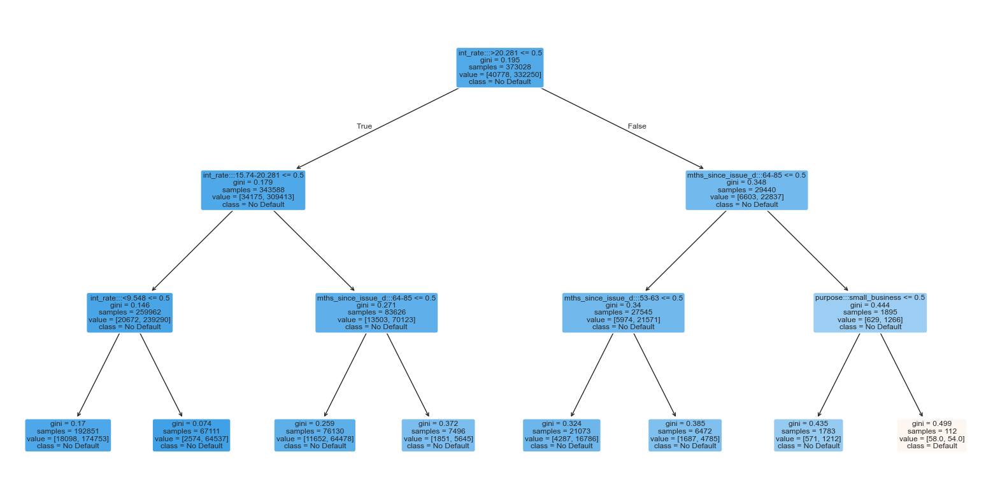

Coefficeints before transpose: []

Coefficeints after transpose: [[ 2.20606519e-01]
 [-1.94627805e-01]
 [-3.69458920e-01]
 [-5.15419950e-01]
 [-7.18040963e-01]
 [-8.34908263e-01]
 [ 8.59873576e-02]
 [-1.05470297e-02]
 [ 2.08464745e-01]
 [ 9.69663270e-02]
 [-1.23204005e-01]
 [-2.63828930e-02]
 [-4.59017206e-02]
 [ 1.41578714e-01]
 [-6.17376013e-02]
 [-1.27333587e-01]
 [ 1.92779342e-02]
 [-5.70054744e-04]
 [-4.35473237e-01]
 [ 1.11530886e-01]
 [ 3.56729193e-01]
 [ 7.09965463e-02]
 [-1.19801928e-01]
 [-3.03730845e-03]
 [-6.46333671e-02]
 [-1.09939715e-01]
 [-5.15127987e-02]
 [ 8.14420317e-02]
 [-3.10575009e-02]
 [ 1.13287383e-01]
 [-1.39232129e-02]
 [ 1.35343187e-01]
 [ 2.11162981e-01]
 [ 4.30437598e-01]
 [ 4.53237458e-01]
 [ 1.70155691e-01]
 [ 8.34105160e-02]
 [-2.20029427e-01]
 [-4.54715045e-01]
 [-7.05494949e-01]
 [-7.05801676e-01]
 [ 6.55775980e-01]
 [ 2.79447498e-01]
 [-2.44002961e-01]
 [-4.15968778e-01]
 [-9.96963827e-02]
 [-1.67438813e-01]
 [-1.07345949e-01]
 [ 6.77022152e-02]
 [ 1.50787607e-01]
 [ 2.31972830e-01]
 [ 3.05788291e-01]
 [ 3.33795111e-01]
 [ 4.15768308e-01]
 [ 4.57271716e-01]
 [ 4.23260757e-01]
 [-7.36837126e-04]
 [-1.05508996e-01]
 [-1.19452174e-01]
 [-3.48651622e-01]
 [ 1.55671393e-01]
 [ 2.11117369e-01]
 [-8.40791526e-02]
 [-1.04100779e-01]
 [-3.60874756e-02]
 [-6.94133266e-03]
 [-8.23047977e-02]
 [ 3.49865319e-01]
 [ 3.53405371e-01]
 [ 4.19573783e-01]
 [ 4.43444078e-01]
 [ 4.16095878e-01]
 [ 6.78143027e-04]
 [ 3.04540438e-02]
 [-1.23828284e-02]
 [ 6.22257554e-02]
 [ 1.39070869e-01]
 [-1.33141677e-01]
 [-9.72209927e-02]]

,Feature Name,Coefficients
0,Intercept,2.001158
1,grade:::A,0.220607
2,grade:::C,-0.194628
3,grade:::D,-0.369459
4,grade:::E,-0.515420
5,grade:::F,-0.718041
6,grade:::G,-0.834908
7,verification_status:::Not Verified,0.085987
8,verification_status:::Source Verified,-0.010547
9,purpose:::car,0.208465


In [385]:
# FINALLY FITTING LOGISTIC REGRESSION WITH P_VALUES


# reg2.predict_proba(df_scorecard_pd_all, df_scorecard_pd_all_targets) # Remember this is NOW CLEAN !!!! 
# reg2.predict_proba(df_scorecard_pd_all) # Remember this is NOW CLEAN !!!! 



# 1. Inspect model coefficients and intercept
# print("Coefficients:", reg2.model.coef_)
# print("Intercept:", reg2.intercept_)


# 2. Check training target distribution
print(df_scorecard_pd_all_targets.value_counts(normalize=True))
'''value_counts(normalize=True) – how it works
df['col'].value_counts(normalize=True) returns the relative frequencies (proportions) instead of raw counts.
Each count is divided by the total number of non‑null values.
Example: [1,1,0,1] → counts {1:3, 0:1} → normalized {1:0.75, 0:0.25}.'''


# 3. Verify that the model was fitted on the correct data
print("Training inputs shape:", df_scorecard_pd_all.shape)
print("Training targets shape:", df_scorecard_pd_all_targets.shape)

# 4. Try a simple decision tree to see if features have any predictive power
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=3)
dt.fit(inputs_train, loan_data_targets_train) 
print("Tree accuracy:", dt.score(inputs_test, loan_data_targets_test))

'''
If the tree also gives very high accuracy but with varied predictions, your logistic regression is under‑regularized. If the tree gives ~89% as well,
then the features are truly useless (or you have a target leak).

'''


# Would you like to plot a visual representation of this tree or calculate a confusion matrix to see exactly where the model is making mistakes?

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Set the canvas size
plt.figure(figsize=(20, 10))

# Plot the decision tree structure
plot_tree(
    dt, 
    filled=True, 
    rounded=True, 
    feature_names=inputs_train.columns, 
    class_names=['Default', 'No Default']  # Replace with your actual target labels
)

# Render the plot
plt.show()


feature_name = df_scorecard_pd_all.columns.values  

summary_table = pd.DataFrame(columns=['Feature Name'], data = feature_name)
print(f'\n Coefficeints before transpose: {reg2.coef_[2:2:1]}\n\n')
print(f'\n Coefficeints after transpose: {np.transpose(reg2.coef_)}\n\n')
summary_table['Coefficients'] = np.transpose(reg2.coef_)



#lets put intercept in first row  so it is displayed at the top of the list of coefficients
summary_table.index = summary_table.index +1 
summary_table.loc[0] = ['Intercept', reg.intercept_[0]]
summary_table = summary_table.sort_index()
summary_table.head()
# reg.fit(inputs_train_with_ref_cat, loan_data_targets_train) This also wont work because it has references and we are trying to invert hence LinAlgError: Singular matrix

#lets put intercept in first row  so it is displayed at the top of the list of coefficients
# summary_table.iloc[0,1] = [reg.intercept_[0]] #if kept with 'errored definition' should have used reg.intercept[0] instead

#summary_table.iloc[0, 1] = [reg.intercept_[0]]
summary_table.loc[0, 'Coefficients'] = [reg2.intercept_[0]]

#summary_table.loc[0] = ['Intercept', reg.intercept_[0]]

summary_table = summary_table.sort_index()
summary_table


Since you are not re-fitting the model, it is perfectly correct and mathematically expected that the coefficients are exactly the same.The model's coefficients (reg2.coef_) and intercept (reg2.intercept_) are fixed properties of the reg2 object. They will never change unless you call .fit() again. Whether you print them next to your test data or next to your full dataset, those numbers are hardcoded inside the model.

In [386]:
'''To get clean probabilities for all your customers and map the coefficients correctly to the actual columns the model was trained on, 
use this sequence:'''

# 1. Ensure 'all data' has the exact same columns as the training data
# This aligns and orders the columns perfectly
df_scorecard_pd_all_aligned = df_scorecard_pd_all[inputs_train.columns].copy()

# 2. Predict probabilities for ALL customers using the trained model
# Column 1 gives the probability of being a "Good" loan (1)
all_predictions_proba = reg2.predict_proba(df_scorecard_pd_all_aligned)[:, 1]

# 3. Create the Summary Table based on the TRAINING columns
# This ensures every coefficient maps to the correct feature name
feature_name = inputs_train.columns.values  
summary_table = pd.DataFrame(columns=['Feature Name'], data=feature_name)
summary_table['Coefficients'] = np.transpose(reg2.model.coef_) # clean mapping of the 236 weights

# 4. Insert the Intercept at the top safely
summary_table.index = summary_table.index + 1 
summary_table.loc[0] = ['Intercept', reg2.intercept_[0]]
summary_table = summary_table.sort_index()

# View your final table
summary_table.head(15)


,Feature Name,Coefficients
0,Intercept,2.001158
1,grade:::A,0.220607
2,grade:::C,-0.194628
3,grade:::D,-0.369459
4,grade:::E,-0.515420
5,grade:::F,-0.718041
6,grade:::G,-0.834908
7,verification_status:::Not Verified,0.085987
8,verification_status:::Source Verified,-0.010547
9,purpose:::car,0.208465


In [387]:
np.array(ref_categories)

array(['grade:::B', 'verification_status:::Verified',
       'purpose:::debt_consolidation', 'initial_list_status:::f',
       'home_ownership:::MORTGAGE', 'addr_state:::AR_MI_PA_OH_MN',
       'term:::36', 'emp_length:::Missing', 'mths_since_issue_d:::42-48',
       'int_rate:::12.025-15.74', 'annual_inc:::40k-50k',
       'funded:::funded:medium', 'mths_since_last_record:::Missing',
       'mths_since_last_major_derog:::Missing',
       'mths_since_last_delinq:::>57', 'total_rev_hi_lim:::20k-40k',
       'dti:::10-20'], dtype='<U37')

In [388]:
df_ref_categories = pd.DataFrame(ref_categories, columns = ["Feature Name"])
df_ref_categories['Coefficients'] = 0
df_ref_categories['p_values'] = np.nan
df_ref_categories.head()

,Feature Name,Coefficients,p_values
0,grade:::B,0,NaN
1,verification_status:::Verified,0,NaN
2,purpose:::debt_consolidation,0,NaN
3,initial_list_status:::f,0,NaN
4,home_ownership:::MORTGAGE,0,NaN


In [389]:
df_scorecard_pd_all = pd.concat([summary_table, df_ref_categories])
'''
This way we will get the output from our PD model as if we included the reference categories in the model estimation and had coeficients of 0 '''


#df_scorecard = df_scorecard.reset_index()
df_scorecard_pd_all



,Feature Name,Coefficients,p_values
0,Intercept,2.001158,NaN
1,grade:::A,0.220607,NaN
2,grade:::C,-0.194628,NaN
3,grade:::D,-0.369459,NaN
4,grade:::E,-0.515420,NaN
5,grade:::F,-0.718041,NaN
6,grade:::G,-0.834908,NaN
7,verification_status:::Not Verified,0.085987,NaN
8,verification_status:::Source Verified,-0.010547,NaN
9,purpose:::car,0.208465,NaN


In [390]:
# ✅ STEP 3: Derive Original Feature Name CORRECTLY
# Ensuring we have the names of the original independent variables as well
pd.options.display.max_columns = None 

# USE THE PROPERLY ALIGNED COLUMN
df_scorecard_pd_all['Original feature name'] = df_scorecard_pd_all['Feature Name'].str.split(':::').str[0]

# VERIFY FIX WORKED
print("\n=== GROUP MIN/MAX AFTER FIX === \n")
group_mins = df_scorecard_pd_all.groupby('Original feature name')['Coefficients'].min() #minimum per each original independent variable 
group_maxs = df_scorecard_pd_all.groupby('Original feature name')['Coefficients'].max()
print("Min per group:\n", group_mins)
print("\nMax per group:\n", group_maxs)
print("\nSum of mins:", group_mins.sum())
"Sum of maxs:", group_maxs.sum()

=== GROUP MIN/MAX AFTER FIX ===

Min per group:
 Original feature name
Intercept                      2.001158
addr_state                    -0.109940
annual_inc                    -0.167439
dti                           -0.133142
emp_length                     0.000000
funded                        -0.119452
grade                         -0.834908
home_ownership                -0.119802
initial_list_status            0.000000
int_rate                      -0.415969
mths_since_issue_d            -0.705802
mths_since_last_delinq         0.000000
mths_since_last_major_derog   -0.104101
mths_since_last_record        -0.348652
purpose                       -0.435473
term                           0.000000
total_rev_hi_lim              -0.012383
verification_status           -0.010547
Name: Coefficients, dtype: float64

Max per group:
 Original feature name
Intercept                      2.001158
addr_state                     0.430438
annual_inc                     0.457272
dti                            0.139071
emp_length                     0.000000
funded                         0.000000
grade                          0.220607
home_ownership                 0.000000
initial_list_status            0.070997
int_rate                       0.655776
mths_since_issue_d             0.453237
mths_since_last_delinq         0.443444
mths_since_last_major_derog    0.000000
mths_since_last_record         0.211117
purpose                        0.356729
term                           0.000000
total_rev_hi_lim               0.062226
verification_status            0.085987
Name: Coefficients, dtype: float64

Sum of mins: -1.5164504202621938

('Sum of maxs:', np.float64(5.588058538528518))

In [391]:
group_features = df_scorecard_pd_all.groupby('Original feature name')['Coefficients']
group_features.sum()

Original feature name
Intercept                      2.001158
addr_state                     0.700607
annual_inc                     2.011866
dti                           -0.091292
emp_length                     0.000000
funded                        -0.225698
grade                         -2.411849
home_ownership                -0.122839
initial_list_status            0.070997
int_rate                       0.275252
mths_since_issue_d            -1.379237
mths_since_last_delinq         1.982384
mths_since_last_major_derog   -0.229434
mths_since_last_record        -0.065942
purpose                        0.113945
term                           0.000000
total_rev_hi_lim               0.080975
verification_status            0.075440
Name: Coefficients, dtype: float64

In [392]:
# ============================================================
# 1. EXCLUDE REGRESSION INTERCEPT FROM FEATURE CONTRIBUTIONS
# ============================================================

min_score = 300
max_score = 850

feat_mask = df_scorecard_pd_all['Original feature name'] != 'Intercept'


# ============================================================
# 2. FIND MINIMUM AND MAXIMUM TOTAL FEATURE CONTRIBUTIONS
# ============================================================

min_sum_coef = (
    df_scorecard_pd_all.loc[feat_mask]
    .groupby('Original feature name')['Coefficients']
    .min()
    .sum()
)

max_sum_coef = (
    df_scorecard_pd_all.loc[feat_mask]
    .groupby('Original feature name')['Coefficients']
    .max()
    .sum()
)


# ============================================================
# 3. CALCULATE SCALING FACTOR
# ============================================================

a = (
    max_score - min_score
) / (
    max_sum_coef - min_sum_coef
)


# ============================================================
# 4. CALCULATE SCORECARD INTERCEPT POINTS
# ============================================================

df_scorecard_pd_all.loc[~feat_mask, 'Score - Float'] = (
    min_score - a * min_sum_coef
) 
#  REMEMBER THAT (min_score - a * min_sum_coef) + a * min_sum_coef = min_score = 300 hence intercept is the value where the minimum feature points score
# is at its lowests, in this case at starting point 300


# ============================================================
# 5. CALCULATE FEATURE POINTS
# ============================================================

df_scorecard_pd_all.loc[feat_mask, 'Score - Float'] = (
    df_scorecard_pd_all.loc[feat_mask, 'Coefficients'] * a
)


# ============================================================
# 6. ROUND
# ============================================================

df_scorecard_pd_all['Score'] = (
    df_scorecard_pd_all['Score - Float']
    .round()                                                       # ''' this causes accumulated roundig  error'''
    
)



# ============================================================
# 7. CHECK FINAL RANGE
# ============================================================

intercept_pts = (
    df_scorecard_pd_all.loc[~feat_mask, 'Score - Float']
    .iloc[0]
)


intercept_pts = (
    df_scorecard_pd_all.loc[~feat_mask, 'Score'] # unlike the above this gives rounding errors
    .iloc[0]
)
final_min = (
    df_scorecard_pd_all.loc[feat_mask]
    .groupby('Original feature name')['Score']
    .min()
    .sum()
    + intercept_pts
)

final_max = (
    df_scorecard_pd_all.loc[feat_mask]
    .groupby('Original feature name')['Score']
    .max()
    .sum()
    + intercept_pts
)


final_min_float = (
    df_scorecard_pd_all.loc[feat_mask]
    .groupby('Original feature name')['Score - Float']
    .min()
    .sum()
    + intercept_pts
)

final_max_float = (
    df_scorecard_pd_all.loc[feat_mask]
    .groupby('Original feature name')['Score - Float']
    .max()
    .sum()
    + intercept_pts
)
print(f"Final Scorecard Range: {final_min} to {final_max}")
print(f"Final Scorecard Range Float: {final_min_float} to {final_max_float}")

final_min_float = final_min_float.round()
final_max_float = final_max_float.round(0)

print(f"Final Scorecard Range Float: {final_min_float} to {final_max_float}")



'''
The Floating-Point Rounding "Leak": Your unrounded float ranges are exactly 300.0 and 850.0. When you apply .round() to independent groups and 
sum them up, a phenomenon called "rounding accumulation" occurs. If 15 features all round down by 0.1, your final minimum score drops from 300 to 299.

To force the final rounded ranges to equal exactly 300 and 850, you must handle the reference categories explicitly by filling any empty calculation 
rows with 0, and then assign the final rounding slack directly to the intercept.'''

df_scorecard_pd_all.head()

Final Scorecard Range: 299.0 to 849.0

Final Scorecard Range Float: 299.6821385591959 to 849.6821385591959

Final Scorecard Range Float: 300.0 to 850.0

,Feature Name,Coefficients,p_values,Original feature name,Score - Float,Score
0,Intercept,2.001158,NaN,Intercept,572.317861,572.0
1,grade:::A,0.220607,NaN,grade,17.078392,17.0
2,grade:::C,-0.194628,NaN,grade,-15.067233,-15.0
3,grade:::D,-0.369459,NaN,grade,-28.601893,-29.0
4,grade:::E,-0.515420,NaN,grade,-39.901557,-40.0


In [393]:


# 1. Inspect model coefficients and intercept
print("Coefficients:", reg2.model.coef_)
print("Intercept:", reg2.intercept_)


# ============================================================
# ✅ STEP 1: GENERATE y_scores FOR YOUR DATA
# ============================================================

# 1. Separate features from the Intercept using your existing mask
feat_mask = df_scorecard_pd_all['Original feature name'] != 'Intercept'

# 2. Create a clean lookup dataframe mapping 'Feature Name' to its Score
# We use .drop_duplicates() just in case any names are repeated
scorecard_lookup = df_scorecard_pd_all.loc[feat_mask].set_index('Feature Name')

# 3. CRITICAL FIX: Find the intersection of columns
# Only keep columns that exist BOTH in your borrower data (X_aligned) AND your scorecard lookup
matching_features = [col for col in X_aligned.columns if col in scorecard_lookup.index]

# 4. Align your borrower matrix and your scorecard weights perfectly
X_aligned_clean = X_aligned[matching_features]
feature_scores = scorecard_lookup.loc[matching_features, 'Score'].values

# 5. Extract the rounded intercept score safely from the full DataFrame
intercept_score = df_scorecard_pd_all.loc[~feat_mask, 'Score'].iloc[0]

# 6. Compute total integer score per borrower via Matrix Multiplication
# (N_borrowers × N_features) × (N_features × 1) + Intercept
y_scores = X_aligned_clean.dot(feature_scores) + intercept_score


# ============================================================
# ✅ STEP 2: VERIFY AND INSPECT RESULTS
# ============================================================

print(f"y_scores shape: {y_scores.shape}")
print(f"Min score calculated: {y_scores.min()}, Max score calculated: {y_scores.max()}")

# Inspect every 10th score up to the 100th record
print("\nSample scores:")
print(y_scores.iloc[:101:10])


Coefficients: [[ 2.20606519e-01 -1.94627805e-01 -3.69458920e-01 -5.15419950e-01
  -7.18040963e-01 -8.34908263e-01  8.59873576e-02 -1.05470297e-02
   2.08464745e-01  9.69663270e-02 -1.23204005e-01 -2.63828930e-02
  -4.59017206e-02  1.41578714e-01 -6.17376013e-02 -1.27333587e-01
   1.92779342e-02 -5.70054744e-04 -4.35473237e-01  1.11530886e-01
   3.56729193e-01  7.09965463e-02 -1.19801928e-01 -3.03730845e-03
  -6.46333671e-02 -1.09939715e-01 -5.15127987e-02  8.14420317e-02
  -3.10575009e-02  1.13287383e-01 -1.39232129e-02  1.35343187e-01
   2.11162981e-01  4.30437598e-01  4.53237458e-01  1.70155691e-01
   8.34105160e-02 -2.20029427e-01 -4.54715045e-01 -7.05494949e-01
  -7.05801676e-01  6.55775980e-01  2.79447498e-01 -2.44002961e-01
  -4.15968778e-01 -9.96963827e-02 -1.67438813e-01 -1.07345949e-01
   6.77022152e-02  1.50787607e-01  2.31972830e-01  3.05788291e-01
   3.33795111e-01  4.15768308e-01  4.57271716e-01  4.23260757e-01
  -7.36837126e-04 -1.05508996e-01 -1.19452174e-01 -3.48651622e-01
   1.55671393e-01  2.11117369e-01 -8.40791526e-02 -1.04100779e-01
  -3.60874756e-02 -6.94133266e-03 -8.23047977e-02  3.49865319e-01
   3.53405371e-01  4.19573783e-01  4.43444078e-01  4.16095878e-01
   6.78143027e-04  3.04540438e-02 -1.23828284e-02  6.22257554e-02
   1.39070869e-01 -1.33141677e-01 -9.72209927e-02]]

Intercept: [2.0011581]

y_scores shape: (93257,)

Min score calculated: 398.0, Max score calculated: 799.0

Sample scores:

362514    602.0
176798    539.0
42139     509.0
259632    575.0
62711     608.0
397622    563.0
157099    645.0
33195     491.0
160224    691.0
141769    555.0
249777    638.0
dtype: float64

**GETTING PD's and Prob Good FOR EVERYONE** >>> not only the y_test scores like we did before !!!

In [394]:


# ============================================================
# ✅ STEP 3: CONVERT CREDIT SCORES TO PROBABILITIES
# ============================================================

# 1. Reconstruct the log-odds (logit) from the integer credit scores
# Using the scaling factor 'a' and min_score offset from your earlier calculation
# Note: 'a' and 'min_sum_coef' must be the ones used during scorecard scaling
log_odds = ((y_scores - min_score) / a) + min_sum_coef

# 2. Apply the Sigmoid function to find the Probability of Good (1)
prob_good = 1 / (1 + np.exp(-log_odds))

# 3. Calculate the Probability of Default (0)
# Since a loan is either Good or Bad, they must sum up to 1
prob_default = 1 - prob_good


# ============================================================
# ✅ STEP 4: COMBINE INTO A CLEAN DATAFRAME FOR INSPECTION
# ============================================================

df_customer_probabilities = pd.DataFrame({
    'Credit Score': y_scores,
    'Probability of Good (Non-Default)': prob_good,
    'Probability of Default (PD)': prob_default
}, index=y_scores.index)


# ============================================================
# ✅ STEP 5: VERIFY AND INSPECT THE PROBABILITIES
# ============================================================

print("--- Summary Statistics ---")
print(df_customer_probabilities.describe())

print("\n--- Sample Customer Profiles (Every 10th record up to 100) ---")
print(df_customer_probabilities.iloc[:101:10])


--- Summary Statistics ---

Credit Score  Probability of Good (Non-Default)  \
count  93257.000000                       93257.000000   
mean     595.496692                           0.564219   
std       59.127748                           0.167137   
min      398.000000                           0.095202   
25%      553.000000                           0.437938   
50%      592.000000                           0.563220   
75%      634.000000                           0.689282   
max      799.000000                           0.949219   

       Probability of Default (PD)  
count                 93257.000000  
mean                      0.435781  
std                       0.167137  
min                       0.050781  
25%                       0.310718  
50%                       0.436780  
75%                       0.562062  
max                       0.904798

--- Sample Customer Profiles (Every 10th record up to 100) ---

Credit Score  Probability of Good (Non-Default)  \
362514         602.0                           0.594696   
176798         539.0                           0.394036   
42139          509.0                           0.306211   
259632         575.0                           0.508661   
62711          608.0                           0.613232   
397622         563.0                           0.469946   
157099         645.0                           0.718869   
33195          491.0                           0.259147   
160224         691.0                           0.822452   
141769         555.0                           0.444307   
249777         638.0                           0.700239   

        Probability of Default (PD)  
362514                     0.405304  
176798                     0.605964  
42139                      0.693789  
259632                     0.491339  
62711                      0.386768  
397622                     0.530054  
157099                     0.281131  
33195                      0.740853  
160224                     0.177548  
141769                     0.555693  
249777                     0.299761

***To transform your log-odds back into probabilities using built-in library functions, you need the inverse-logit function (more commonly known as the logistic or sigmoid function).Here is how you can perform this exact transformation using SciPy, Statsmodels, and a standard optimized NumPy approach so you can see how they work side-by-side.Three Methods to Convert Log-Odds to Probabilities**




What This Teaches Us About These Functions:scipy.special.expit: This is the industry standard tool for converting scores/log-odds into probabilities in Python. It is written in C under the hood, making it incredibly fast and numerically stable against extreme values (preventing overflow/underflow errors). statsmodels.genmod.families.links.Logit().inverse: Statsmodels wraps its regression mathematics inside formal statistical generalized linear model (GLM) frameworks. Calling .inverse() on its Logit link does the exact same calculation but explicitly labels it within econometric terms. Why they are identical: Under the surface, all three variations are executing the exact same mathematical formula: \(P = \frac{1}{1 + e^{-x}}\). 

In [395]:

# 1. Import the transformation functions from the libraries
from scipy.special import expit as scipy_sigmoid
from statsmodels.genmod.families.links import Logit as SM_Logit

# Initialize the statsmodels logit link function object
statsmodels_logit_link = SM_Logit()

# ============================================================
# ⚙️ PREPARATION: CALCULATE LOG-ODDS FROM Y_SCORES
# ============================================================
# Reconstruct log-odds using your scorecard scaling factors
log_odds = ((y_scores - min_score) / a) + min_sum_coef


# ============================================================
# 🧪 METHOD 1: USING SCIPY (Highly Recommended)
# ============================================================
# scipy.special.expit is the highly optimized inverse-logit (sigmoid) function
prob_good_scipy = scipy_sigmoid(log_odds)


# ============================================================
# 🧪 METHOD 2: USING STATSMODELS
# ============================================================
# The Logit link class in statsmodels has a built-in .inverse() method 
# specifically designed to map log-odds back to probabilities
prob_good_statsmodels = statsmodels_logit_link.inverse(log_odds)


# ============================================================
# 🧪 METHOD 3: THE MANUAL NUMPY BASELINE
# ============================================================
# This is the mathematical equation written out using numpy's vectorized exponent
prob_good_numpy = 1 / (1 + np.exp(-log_odds))


# ============================================================
# ✅ VERIFY THAT ALL THREE LIBRARIES GIVE THE EXACT SAME VALUES
# ============================================================

df_comparison = pd.DataFrame({
    'Credit Score': y_scores,
    'Log-Odds': log_odds,
    'SciPy Prob': prob_good_scipy,
    'Statsmodels Prob': prob_good_statsmodels,
    'NumPy Prob': prob_good_numpy,
    'PD (Default Prob)': 1 - prob_good_scipy  # PD is always 1 minus Prob of Good
}, index=y_scores.index)

print("--- Sample Profiles Side-by-Side ---")
print(df_comparison.iloc[:101:10])

# Double check that there are zero differences between the methods
diff_scipy_sm = np.max(np.abs(prob_good_scipy - prob_good_statsmodels))
print(f"\nMaximum difference between SciPy and Statsmodels: {diff_scipy_sm}")


--- Sample Profiles Side-by-Side ---

Credit Score  Log-Odds  SciPy Prob  Statsmodels Prob  NumPy Prob  \
362514         602.0  0.383413    0.594696          0.594696    0.594696   
176798         539.0 -0.430376    0.394036          0.394036    0.394036   
42139          509.0 -0.817895    0.306211          0.306211    0.306211   
259632         575.0  0.034646    0.508661          0.508661    0.508661   
62711          608.0  0.460916    0.613232          0.613232    0.613232   
397622         563.0 -0.120362    0.469946          0.469946    0.469946   
157099         645.0  0.938856    0.718869          0.718869    0.718869   
33195          491.0 -1.050406    0.259147          0.259147    0.259147   
160224         691.0  1.533051    0.822452          0.822452    0.822452   
141769         555.0 -0.223700    0.444307          0.444307    0.444307   
249777         638.0  0.848435    0.700239          0.700239    0.700239   

        PD (Default Prob)  
362514           0.405304  
176798           0.605964  
42139            0.693789  
259632           0.491339  
62711            0.386768  
397622           0.530054  
157099           0.281131  
33195            0.740853  
160224           0.177548  
141769           0.555693  
249777           0.299761

Maximum difference between SciPy and Statsmodels: 0.0

In [396]:
'''Why this fixes the issue:The Statsmodels Syntax Rule: In Statsmodels, the inverse() method converts log-odds into probabilities. To do the reverse
(probabilities back to log-odds), you directly treat the object instance like a function, passing the values inside parentheses: 
statsmodels_logit_link(prob_good)'''



# 1. Import the REVERSE transformation functions
from scipy.special import logit as scipy_logit
from statsmodels.genmod.families.links import Logit as SM_Logit

# Initialize the statsmodels logit link object
statsmodels_logit_link = SM_Logit()

# Assume 'prob_good' is your array of Probability of Good values 
# (Generated from your previous step)


# ============================================================
# 🔄 REVERSE METHOD 1: USING SCIPY
# ============================================================
# scipy.special.logit directly computes log(p / (1 - p))
log_odds_scipy = scipy_logit(prob_good)


# ============================================================
# 🔄 REVERSE METHOD 2: USING STATSMODELS (FIXED)
# ============================================================
# ✅ FIX: Statsmodels uses the direct function call syntax () to go forward
log_odds_statsmodels = statsmodels_logit_link(prob_good)


# ============================================================
# 🔄 REVERSE METHOD 3: THE MANUAL NUMPY WAY
# ============================================================
# This is the raw mathematical formula written out vectorially
log_odds_numpy = np.log(prob_good / (1 - prob_good))


# ============================================================
# 📐 SCALING REVERSED LOG-ODDS BACK TO CREDIT SCORES
# ============================================================
# Step 1: Recover the unscaled feature contribution sum (sum coefs)
# By subtracting the minimum sum coefficient offset
sum_coefs_recovered = log_odds_scipy - min_sum_coef

# Step 2: Scale it back up to the 300-850 point spectrum
# Using your scaling factor 'a' and adding back the baseline min_score (300)
scores_recovered_float = (sum_coefs_recovered * a) + min_score

# Step 3: Round it to match your final integer scorecard output
scores_recovered_integer = scores_recovered_float.round()


# ============================================================
# ✅ VERIFY THE REVERSAL RESULTS
# ============================================================

df_reversal_check = pd.DataFrame({
    'Original Prob': prob_good,
    'SciPy Reversed Log-Odds': log_odds_scipy,
    'SM Reversed Log-Odds': log_odds_statsmodels,
    'Recovered Float Score': scores_recovered_float,
    'Recovered Integer Score': scores_recovered_integer
}, index=prob_good.index)

print("--- Reversal Verification Side-by-Side ---")
print(df_reversal_check.iloc[:101:10])

# Double check that there are zero differences between the methods
diff_scipy_sm = np.max(np.abs(log_odds_scipy - log_odds_statsmodels))
print(f"\nMaximum difference between SciPy and Statsmodels: {diff_scipy_sm}")


--- Reversal Verification Side-by-Side ---

Original Prob  SciPy Reversed Log-Odds  SM Reversed Log-Odds  \
362514       0.594696                 0.383413              0.383413   
176798       0.394036                -0.430376             -0.430376   
42139        0.306211                -0.817895             -0.817895   
259632       0.508661                 0.034646              0.034646   
62711        0.613232                 0.460916              0.460916   
397622       0.469946                -0.120362             -0.120362   
157099       0.718869                 0.938856              0.938856   
33195        0.259147                -1.050406             -1.050406   
160224       0.822452                 1.533051              1.533051   
141769       0.444307                -0.223700             -0.223700   
249777       0.700239                 0.848435              0.848435   

        Recovered Float Score  Recovered Integer Score  
362514                  602.0                    602.0  
176798                  539.0                    539.0  
42139                   509.0                    509.0  
259632                  575.0                    575.0  
62711                   608.0                    608.0  
397622                  563.0                    563.0  
157099                  645.0                    645.0  
33195                   491.0                    491.0  
160224                  691.0                    691.0  
141769                  555.0                    555.0  
249777                  638.0                    638.0

Maximum difference between SciPy and Statsmodels: 2.220446049250313e-16

In [397]:
'''
 complete code to find your exact credit score threshold for a 1.5% maximum Probability of Default (PD) limit,
 tag every single customer as "Approved" or "Rejected"'''


from scipy.special import logit as scipy_logit

# ============================================================
# 🎯 STEP 1: CALCULATE THE EXACT SCORE CUTOFF FOR 1.5% PD
# ============================================================

target_pd = 0.015  # 1.5% maximum target default rate
target_prob_good = 1 - target_pd  # 98.5% probability of being good

# 1. Reverse the target probability back into target log-odds
target_log_odds = scipy_logit(target_prob_good)

# 2. Scale the log-odds up to our 300-850 scorecard point spectrum
# (Using 'a', 'min_sum_coef', and 'min_score' from your earlier calculations)
target_score_float = (((target_log_odds - min_sum_coef) * a) + min_score)
target_score_cutoff = np.ceil(target_score_float)  # Ceil ensures we satisfy the strict 1.5% limit

print(f"--- Cutoff Policy ---")
print(f"Target Max PD: {target_pd * 100}%")
print(f"Exact Required Credit Score Threshold: {int(target_score_cutoff)}\n")


# ============================================================
# 🚦 STEP 2: APPLY APPROVAL / REJECTION RULE LOOP
# ============================================================

# Create a clean final results dataframe for all customers
# Assuming 'prob_default' is the PD array we generated in the previous step
df_final_decisions = pd.DataFrame({
    'Credit Score': y_scores,
    'Probability of Default (PD)': prob_default
}, index=y_scores.index)

# Vectorized rule loop matching your business criteria
df_final_decisions['Decision'] = np.where(
    df_final_decisions['Credit Score'] >= target_score_cutoff, 
    'Approved', 
    'Rejected'
)

print("--- Decision Distribution ---")
print(df_final_decisions['Decision'].value_counts())
print("\nSample Decisions Table:")
print(df_final_decisions.head(10))


--- Cutoff Policy ---

Target Max PD: 1.5%

Exact Required Credit Score Threshold: 897

--- Decision Distribution ---

Decision
Rejected    93257
Name: count, dtype: int64

Sample Decisions Table:

Credit Score  Probability of Default (PD)  Decision
362514         602.0                     0.405304  Rejected
288564         534.0                     0.621275  Rejected
213591         559.0                     0.542902  Rejected
263083         634.0                     0.310718  Rejected
165001         676.0                     0.207626  Rejected
82511          528.0                     0.639332  Rejected
24671          527.0                     0.642305  Rejected
97373          498.0                     0.723119  Rejected
44058          652.0                     0.263224  Rejected
351326         668.0                     0.225141  Rejected

In [398]:
# Save PD Values for All Loans Using Pickle

import pickle

# ============================================================
# 💾  PICKLE AND SAVE ALL COMPUTED DATA
# ============================================================

# Package all critical assets into a single dictionary dictionary object
all_loan_pd_data = {
    'loan_ids': df_final_decisions.index.values,
    'pd_values': df_final_decisions['Probability of Default (PD)'].values,
    'credit_scores': df_final_decisions['Credit Score'].values,
    'decisions': df_final_decisions['Decision'].values
}

# Save the dictionary as a binary file deployment package
with open('all_loans_pd_package.pkl', 'wb') as file:
    pickle.dump(all_loan_pd_data, file)

print("\nSuccessfully saved all PD values and metrics to 'all_loans_pd_package.pkl'!")


Successfully saved all PD values and metrics to 'all_loans_pd_package.pkl'!

In [399]:
#  Load and Use the Pickled PD Values in Another File


# ============================================================
# 📥 STEP 4: LOAD THE PICKLE IN A SEPARATE FILE
# ============================================================

with open('all_loans_pd_package.pkl', 'rb') as file:
    loaded_data = pickle.load(file)

# Reconstruct back into a working pandas DataFrame immediately
df_production_loans = pd.DataFrame({
    'Probability of Default (PD)': loaded_data['pd_values'],
    'Credit Score': loaded_data['credit_scores'],
    'System Decision': loaded_data['decisions']
}, index=loaded_data['loan_ids'])


# ============================================================
# 🛠️ STEP 5: EXAMPLE USE CASES IN PRODUCTION
# ============================================================

print("--- Data Successfully Loaded and Verified ---")
print(df_production_loans.head(5))

# Use Case 1: Look up a specific risky loan by its ID
# sample_id = 412305 
# print(f"\nPD for Loan {sample_id}: {df_production_loans.loc[sample_id, 'Probability of Default (PD)']:.4f}")

# Use Case 2: Filter out all loans that were rejected to run a loss analysis
df_rejected_portfolio = df_production_loans[df_production_loans['System Decision'] == 'Rejected']
print(f"\nTotal loans in rejected pool: {df_rejected_portfolio.shape[0]}")


--- Data Successfully Loaded and Verified ---

Probability of Default (PD)  Credit Score System Decision
362514                     0.405304         602.0        Rejected
288564                     0.621275         534.0        Rejected
213591                     0.542902         559.0        Rejected
263083                     0.310718         634.0        Rejected
165001                     0.207626         676.0        Rejected

Total loans in rejected pool: 93257

In [400]:
gc.collect()

0

In [401]:
import pickle

# ============================================================
# 1. SAVE Y_SCORES (CREDIT SCORES) SEPARATELY
# ============================================================
with open('credit_scores_yscores.pkl', 'wb') as file:
    pickle.dump(y_scores, file)

print("Successfully saved y_scores to 'credit_scores_yscores.pkl'")


# ============================================================
# 2. SAVE PD SCORES (PROBABILITY OF DEFAULT) SEPARATELY
# ============================================================
with open('probability_of_default_pd.pkl', 'wb') as file:
    pickle.dump(prob_default, file)

print("Successfully saved PD scores to 'probability_of_default_pd.pkl'")


Successfully saved y_scores to 'credit_scores_yscores.pkl'

Successfully saved PD scores to 'probability_of_default_pd.pkl'

In [402]:
import pickle

# ============================================================
# 1. LOAD Y_SCORES (CREDIT SCORES) SEPARATELY
# ============================================================
with open('credit_scores_yscores.pkl', 'rb') as file:
    loaded_y_scores = pickle.load(file)

print("Successfully loaded credit scores!")
print(loaded_y_scores.head(5))  # Inspect first 5 records


# ============================================================
# 2. LOAD PD SCORES (PROBABILITY OF DEFAULT) SEPARATELY
# ============================================================
with open('probability_of_default_pd.pkl', 'rb') as file:
    loaded_pd_scores = pickle.load(file)

print("\nSuccessfully loaded PD scores!")
print(loaded_pd_scores[:5])  # Inspect first 5 elements


Successfully loaded credit scores!

362514    602.0
288564    534.0
213591    559.0
263083    634.0
165001    676.0
dtype: float64

Successfully loaded PD scores!

362514    0.405304
288564    0.621275
213591    0.542902
263083    0.310718
165001    0.207626
dtype: float64

In [403]:
'''1. y_scores.to_pickle('y_scores.pkl') ➔ ✅ YESThis works perfectly because y_scores is a pandas Series or DataFrame. Pandas has built-in 
.to_pickle() and pd.read_pickle() methods specifically designed for this.'''

# Save y_scores
y_scores.to_pickle('y_scores.pkl')

# How to load it back in another file:
import pandas as pd
loaded_y_scores = pd.read_pickle('y_scores.pkl')


In [404]:
"""If y_scores is a NumPy array or a standard Python list, it will no longer have the .to_pickle() method because that method belongs strictly to 
pandas objects.To pickle them in one line without using pandas, you have two great options depending on whether it is an array or a list:

Option 1: If it is a NumPy Array (Best Practice)NumPy has its own highly optimized, built-in saving functions (np.save and np.load) that use binary 
serialization under the hood (just like pickle, but much faster for arrays)."""

import numpy as np

# 💾 SAVE: One line to save the array
np.save('y_scores.npy', y_scores)

# 📥 LOAD: One line to load it back in another file
loaded_y_scores = np.load('y_scores.npy')


In [405]:
'''
Option 2: If it is a Python List (or Array) using Standard PickleIf you specifically want to use pickle for a list or an array but hate writing out
the multiple lines of code to open and close files, you can use pickle.dump and pickle.load in simple wrappers, or fall back to the standard format:
'''

import pickle

# 💾 SAVE: Standard pickle save block
with open('y_scores.pkl', 'wb') as file:
    pickle.dump(y_scores, file)

# 📥 LOAD: Standard pickle load block
with open('y_scores.pkl', 'rb') as file:
    loaded_y_scores = pickle.load(file)


In [406]:
'''
2. all_loans_pd_package.to_pickle(...) ➔ ❌ NO (Unless wrapped)This will fail with an AttributeError because all_loans_pd_package is a standard
Python dictionary ({}), not a pandas object. Standard Python dictionaries do not have a .to_pickle() method.If you want to use the clean pandas syntax
for your entire package, simply wrap the dictionary inside a pandas DataFrame first!

Using pandas' .to_pickle() is often preferred over the raw pickle module because it takes only a single line of code and automatically handles opening
and closing the binary files under the hood.'''


# Convert the dictionary to a DataFrame, then use .to_pickle()


df_package = pd.DataFrame({
    'Probability of Default (PD)': prob_default,
    'Credit Score': y_scores,
    'Decision': df_final_decisions['Decision']
}, index=y_scores.index)

# Now you can save it cleanly!
df_package.to_pickle('all_loans_pd_package.pkl')

# How to load it back in another file:
loaded_package = pd.read_pickle('all_loans_pd_package.pkl')


In [407]:

import pickle

# ============================================================
# ⚙️ STEP 1: CONVERT AND SAVE Y_SCORES (Shorter, safe way)
# ============================================================
# If y_scores is a list or NumPy array, we turn it into a Pandas Series first
# to preserve the loan index before pickling
y_scores_series = pd.Series(y_scores, index=df_scorecard_pd_all_targets.index, name='Credit Score')

with open('y_scores.sav', 'wb') as file:
    pickle.dump(y_scores_series, file)

print("Successfully saved credit scores to 'y_scores.sav'!")


# ============================================================
# ⚙️ STEP 2: CREATE AND CHECK PD SERIES
# ============================================================

# 14. Create a PD Series using the SAME INDEX
pd_series = pd.Series(
    prob_default,                           # Your calculated PD array
    index=df_scorecard_pd_all_targets.index, # Standardizing index across your data
    name='PD'
)

# 15. Basic checks
print("\n--- PD Quality Control Checks ---")
print("Number of PD values:", len(pd_series))
print("Number of unique PD indexes:", pd_series.index.nunique())
print("Minimum PD:", pd_series.min())
print("Maximum PD:", pd_series.max())
print("Missing PD values:", pd_series.isna().sum())

# 16. Display a few PD values
print("\nFirst few records:")
print(pd_series.head())

# 17. Save PD values to pickle
with open('pd_values.pkl', 'wb') as file:
    pickle.dump(pd_series, file)

print("\nSuccessfully saved PD values to 'pd_values.pkl'!")


Successfully saved credit scores to 'y_scores.sav'!

--- PD Quality Control Checks ---

Number of PD values: 466285

Number of unique PD indexes: 466285

Minimum PD: 0.050780931254528094

Maximum PD: 0.9047982956696378

Missing PD values: 373028

First few records:

427211   NaN
206088   NaN
136020   NaN
412305   NaN
36159    NaN
Name: PD, dtype: float64

Successfully saved PD values to 'pd_values.pkl'!

**PD Model Monitoring via Assessing Population  Stability Index**

**Population Stability Index: Preprocessing**

>>> The code from here to the other starting with '>>>' is copied from the data preparation notebook with minor adjustments. we have to perform the exact same data preprocessing, fine classing and coarse classing on the new data, in order to be able to calculate statictics for the exact same variables to the ones we used for training and testing the PD model
>>
>> AS  anticipated we'll need to preprocess the new data the same way we preprocess the train and test data .
>>If the dummy variables are not exactly the same, the 2 datasets wouldnt be comparable 

>>> **General preprocessing**
>>> rewrite everything upto the point we split data 

**General Preprocessing**
**Preprocessing few continuous variables**

In [408]:
# We also need the new population and it comprises borrowers from 2015 and can be located in 'loan_data_2015.csv'

loan_data_backup_2 = pd.read_csv("D:/DEO DESKTOP FOLDER/WEBSITE/CREDIT RISK MODELLING/loan_data_2015.csv", low_memory=False) 

In [409]:
# We also need the new population and it comprises borrowers from 2015 and can be located in 'loan_data_2015.csv'

loan_data_2015 = pd.read_csv(
    "D:/DEO DESKTOP FOLDER/WEBSITE/CREDIT RISK MODELLING/loan_data_2015.csv",
    low_memory=False
)

In [410]:
loan_data_2015.head(3)

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,68444620,73334399,35000,35000,35000.0,60 months,11.99,778.38,C,C1,Foreign Service Officer,10+ years,MORTGAGE,128000.0,Source Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,home_improvement,Home improvement,200xx,DC,6.46,0.0,Feb-90,0.0,46.0,NaN,17.0,0.0,14277,27.4,46.0,w,35000.0,35000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,56.0,1,INDIVIDUAL,NaN,NaN,NaN,0.0,321.0,146867.0,1.0,11.0,0.0,0.0,28.0,35367.0,49.3,0.0,1.0,5020.0,40.1,52200.0,1.0,4.0,0.0
1,68547583,73437441,8650,8650,8650.0,36 months,5.32,260.50,A,A1,Associate Consultant,< 1 year,MORTGAGE,100000.0,Not Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,credit_card,Credit card refinancing,462xx,IN,7.28,0.0,Jul-01,0.0,NaN,NaN,15.0,0.0,7158,26.7,24.0,w,8650.0,8650.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,165450.0,0.0,1.0,1.0,1.0,11.0,24041.0,88.8,0.0,3.0,3081.0,57.9,26800.0,1.0,0.0,5.0
2,67849662,72708407,4225,4225,4225.0,36 months,14.85,146.16,C,C5,mechanic,5 years,RENT,35000.0,Source Verified,Dec-15,Issued,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,672xx,KS,15.22,2.0,Jul-11,0.0,18.0,NaN,6.0,0.0,1058,24.6,6.0,w,4225.0,4225.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,Jan-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,4888.0,0.0,1.0,0.0,0.0,47.0,3830.0,21.9,0.0,0.0,367.0,22.4,4300.0,0.0,0.0,0.0


In [411]:
model_features = df_scorecard.loc[df_scorecard['Feature Name'] != 'Intercept', 'Feature Name']
expected_columns = model_features.values
expected_columns

array(['grade:::A', 'grade:::C', 'grade:::D', 'grade:::E', 'grade:::F',
       'grade:::G', 'verification_status:::Not Verified',
       'verification_status:::Source Verified', 'purpose:::car',
       'purpose:::credit_card', 'purpose:::educational',
       'purpose:::home_improvement', 'purpose:::house',
       'purpose:::major_purchase', 'purpose:::medical',
       'purpose:::moving', 'purpose:::other',
       'purpose:::renewable_energy', 'purpose:::small_business',
       'purpose:::vacation', 'purpose:::wedding',
       'initial_list_status:::w', 'home_ownership:::RENT_OTHER_NONE_ANY',
       'home_ownership:::OWN', 'addr_state:::NM_VA',
       'addr_state:::ND_NE_IA_NV_FL_HI_AL',
       'addr_state:::OK_TN_MO_LA_MD_NC', 'addr_state:::GA_WA_OR',
       'addr_state:::UT_KY_AZ_NJ', 'addr_state:::WI_MT',
       'addr_state:::RI_MA_DE_SD_IN', 'addr_state:::IL_CT',
       'addr_state:::KS_SC_CO_VT_AK_MS', 'addr_state:::WV_NH_WY_DC_ME_ID',
       'mths_since_issue_d:::<38', 'mths_since

In [412]:
# DEEPSEEK 1
def preprocess_loan_data(df, expected_columns, ref_date='2017-11-01'):
    """
    Preprocess a raw loan dataset to match the feature set used in the PD model.
    
    Parameters
    ----------
    df : pd.DataFrame
        Raw loan data (e.g., loan_data_2015).
    expected_columns : list
        List of column names from the training data (df_inputs_prepr.columns.tolist()).
    ref_date : str, default '2017-11-01'
        Reference date for calculating months-since variables.
        
    Returns
    -------
    pd.DataFrame
        Preprocessed DataFrame with exactly the columns in expected_columns,
        aligned and with missing columns filled with 0.
    """
    df = df.copy()
    
    # -----------------------------------------------------------------------
    # 1. Drop columns that were completely missing or universal drops
    # -----------------------------------------------------------------------
    cols_all_nan = ['annual_inc_joint', 'dti_joint', 'verification_status_joint',
                    'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
                    'mths_since_rcnt_il', 'total_bal_il', 'il_util',
                    'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
                    'inq_fi', 'total_cu_tl', 'inq_last_12m']
    df = df.drop(columns=[c for c in cols_all_nan if c in df.columns], errors='ignore')
    
    universal_drops = ['id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
                       'desc', 'title', 'emp_title']
    df = df.drop(columns=[c for c in universal_drops if c in df.columns], errors='ignore')
    
    # -----------------------------------------------------------------------
    # 2. Handle missing values and create flags
    # -----------------------------------------------------------------------
    # Employment length
    df['emp_length_missing'] = df['emp_length'].isna().astype(int)
    df['emp_length_int'] = df['emp_length'].str.replace(r'\+ years', '', regex=True)\
                                             .str.replace('< 1 year', '0')\
                                             .str.replace('n/a', '0')\
                                             .str.replace(r'years?|[+]', '', regex=True)\
                                             .str.strip()
    df['emp_length_int'] = pd.to_numeric(df['emp_length_int'], errors='coerce').fillna(0)
    
    # Other missing flags
    df['revol_util_missing'] = df['revol_util'].isna().astype(int)
    df['annual_inc_missing'] = df['annual_inc'].isna().astype(int)
    if 'dti' in df.columns:
        df['dti_missing'] = df['dti'].isna().astype(int)
    
    # Fill missing values with business logic
    df['revol_util'] = df['revol_util'].fillna(0)
    df['annual_inc'] = df['annual_inc'].fillna(df['annual_inc'].quantile(0.3) if not df['annual_inc'].isna().all() else 0)
    if 'dti' in df.columns:
        df['dti'] = df['dti'].fillna(df['dti'].median() if not df['dti'].isna().all() else 0)
    
    # Time-since variables: fill missing with 999 and create flags
    for col, flag_name in [('mths_since_last_record', 'has_record'),
                           ('mths_since_last_major_derog', 'has_major_derog'),
                           ('mths_since_last_delinq', 'has_delinq')]:
        if col in df.columns:
            df[flag_name] = df[col].notna().astype(int)
            df[col] = df[col].fillna(999)
    
    # Financial capacity fills
    for col in ['tot_cur_bal', 'tot_coll_amt']:
        if col in df.columns:
            df[col] = df[col].fillna(0)
    if 'total_rev_hi_lim' in df.columns:
        df['total_rev_hi_lim'] = df['total_rev_hi_lim'].fillna(df['funded_amnt'])
    
    # -----------------------------------------------------------------------
    # 3. Date conversions and months-since calculations
    # -----------------------------------------------------------------------
    ref = pd.Timestamp(ref_date)
    
    def clean_date_series(series):
        return pd.to_datetime(series, format='%b-%y', errors='coerce')
    
    def months_since(series, ref):
        return ((ref.year - series.dt.year) * 12 + (ref.month - series.dt.month)).astype(int)
    
    # earliest_cr_line
    if 'earliest_cr_line' in df.columns:
        df['earliest_cr_line_date'] = clean_date_series(df['earliest_cr_line'])
        df['mths_since_earliest_cr_line'] = months_since(df['earliest_cr_line_date'], ref)
        max_val = df['mths_since_earliest_cr_line'].max()
        df.loc[df['mths_since_earliest_cr_line'] < 0, 'mths_since_earliest_cr_line'] = max_val
    
    # issue_d
    if 'issue_d' in df.columns:
        df['issue_d_date'] = clean_date_series(df['issue_d'])
        df['mths_since_issue_d'] = months_since(df['issue_d_date'], ref)
        max_val = df['mths_since_issue_d'].max()
        df.loc[df['mths_since_issue_d'] < 0, 'mths_since_issue_d'] = max_val
    
    # term: convert to integer months
    if 'term' in df.columns:
        df['term_int'] = df['term'].str.replace(r'\+ months', '', regex=True)\
                                   .str.replace('< 1 month', '0')\
                                   .str.replace('n/a', '0')\
                                   .str.replace(r'months?|[+]', '', regex=True)\
                                   .str.strip()
        df['term_int'] = pd.to_numeric(df['term_int'], errors='coerce').fillna(0).astype(int)
    
    # -----------------------------------------------------------------------
    # 4. Create dummy variables (exactly as in training)
    # -----------------------------------------------------------------------
    dummy_cols = []
    
    # Grade
    if 'grade' in df.columns:
        grade_dummies = pd.get_dummies(df['grade'], prefix='grade', prefix_sep=':::')
        dummy_cols.append(grade_dummies)
    
    # Verification status
    if 'verification_status' in df.columns:
        ver_dummies = pd.get_dummies(df['verification_status'], prefix='verification_status', prefix_sep=':::')
        dummy_cols.append(ver_dummies)
    
    # Purpose
    if 'purpose' in df.columns:
        purpose_dummies = pd.get_dummies(df['purpose'], prefix='purpose', prefix_sep=':::')
        dummy_cols.append(purpose_dummies)
    
    # Initial list status
    if 'initial_list_status' in df.columns:
        init_dummies = pd.get_dummies(df['initial_list_status'], prefix='initial_list_status', prefix_sep=':::')
        dummy_cols.append(init_dummies)
    
    # Home ownership (individual dummies with single colon)
    if 'home_ownership' in df.columns:
        home_dummies = pd.get_dummies(df['home_ownership'], prefix='home_ownership', prefix_sep=':')
        dummy_cols.append(home_dummies)
    
    # Addr state (individual dummies)
    if 'addr_state' in df.columns:
        state_dummies = pd.get_dummies(df['addr_state'], prefix='addr_state', prefix_sep=':')
        dummy_cols.append(state_dummies)
    
    # Concatenate all base dummies
    if dummy_cols:
        dummies = pd.concat(dummy_cols, axis=1)
        df = pd.concat([df, dummies], axis=1)
    
    # -----------------------------------------------------------------------
    # 5. Aggregated dummies for home_ownership and addr_state
    # -----------------------------------------------------------------------
    # Home ownership aggregated
    if all(c in df.columns for c in ['home_ownership:RENT','home_ownership:OTHER','home_ownership:NONE','home_ownership:ANY']):
        df['home_ownership:::RENT_OTHER_NONE_ANY'] = (df['home_ownership:RENT'] + df['home_ownership:OTHER'] +
                                                       df['home_ownership:NONE'] + df['home_ownership:ANY'])
    if 'home_ownership:MORTGAGE' in df.columns:
        df['home_ownership:::MORTGAGE'] = df['home_ownership:MORTGAGE']
    if 'home_ownership:OWN' in df.columns:
        df['home_ownership:::OWN'] = df['home_ownership:OWN']
    
    # Addr state aggregated groups
    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        cols = [f'addr_state:{s}' for s in states if f'addr_state:{s}' in df.columns]
        if cols:
            df[new_col] = df[cols].sum(axis=1)
    
    # -----------------------------------------------------------------------
    # 6. Term dummies
    # -----------------------------------------------------------------------
    if 'term_int' in df.columns:
        df['term:::36'] = (df['term_int'] == 36).astype(int)
        df['term:::60'] = (df['term_int'] == 60).astype(int)
    
    # -----------------------------------------------------------------------
    # 7. emp_length dummies (including the explicit "Missing" dummy)  <-- NEW
    # -----------------------------------------------------------------------
    if 'emp_length_int' in df.columns:
        df['emp_length:::0'] = (df['emp_length_int'] == 0).astype(int)
        df['emp_length:::1'] = (df['emp_length_int'] == 1).astype(int)
        df['emp_length:::2-4'] = df['emp_length_int'].between(2,4).astype(int)
        df['emp_length:::5-6'] = df['emp_length_int'].between(5,6).astype(int)
        df['emp_length:::7-9'] = df['emp_length_int'].between(7,9).astype(int)
        df['emp_length:::10'] = (df['emp_length_int'] == 10).astype(int)
    # Create explicit "Missing" dummy from the earlier flag
    if 'emp_length_missing' in df.columns:
        df['emp_length:::Missing'] = df['emp_length_missing']
    
    # -----------------------------------------------------------------------
    # 8. mths_since_issue_d dummies
    # -----------------------------------------------------------------------
    if 'mths_since_issue_d' in df.columns:
        df['mths_since_issue_d:::<38'] = (df['mths_since_issue_d'] < 38).astype(int)
        df['mths_since_issue_d:::38-39'] = df['mths_since_issue_d'].between(38,39).astype(int)
        df['mths_since_issue_d:::40-41'] = df['mths_since_issue_d'].between(40,41).astype(int)
        df['mths_since_issue_d:::42-48'] = df['mths_since_issue_d'].between(42,48).astype(int)
        df['mths_since_issue_d:::49-52'] = df['mths_since_issue_d'].between(49,52).astype(int)
        df['mths_since_issue_d:::53-63'] = df['mths_since_issue_d'].between(53,63).astype(int)
        df['mths_since_issue_d:::64-85'] = df['mths_since_issue_d'].between(64,85).astype(int)
        df['mths_since_issue_d:::>85'] = (df['mths_since_issue_d'] > 85).astype(int)
    
    # ========== NEW BINNING SECTIONS (added to match required features) ==========
    
    # -----------------------------------------------------------------------
    # 9. Binning for annual_inc (based on required list)
    # -----------------------------------------------------------------------
    if 'annual_inc' in df.columns:
        df['annual_inc:::<20k'] = (df['annual_inc'] < 20000).astype(int)
        df['annual_inc:::20k-30k'] = df['annual_inc'].between(20000, 29999).astype(int)
        df['annual_inc:::30k-40k'] = df['annual_inc'].between(30000, 39999).astype(int)
        df['annual_inc:::40k-50k'] = df['annual_inc'].between(40000, 49999).astype(int)
        df['annual_inc:::50k-60k'] = df['annual_inc'].between(50000, 59999).astype(int)
        df['annual_inc:::60k-70k'] = df['annual_inc'].between(60000, 69999).astype(int)
        df['annual_inc:::70k-80k'] = df['annual_inc'].between(70000, 79999).astype(int)
        df['annual_inc:::80k-90k'] = df['annual_inc'].between(80000, 89999).astype(int)
        df['annual_inc:::90k-100k'] = df['annual_inc'].between(90000, 99999).astype(int)
        df['annual_inc:::100k-120k'] = df['annual_inc'].between(100000, 119999).astype(int)
        df['annual_inc:::120k-140k'] = df['annual_inc'].between(120000, 139999).astype(int)
        df['annual_inc:::>140k'] = (df['annual_inc'] >= 140000).astype(int)
    
    # -----------------------------------------------------------------------
    # 10. Binning for dti
    # -----------------------------------------------------------------------
    if 'dti' in df.columns:
        df['dti:::<10'] = (df['dti'] < 10).astype(int)
        df['dti:::10-20'] = df['dti'].between(10, 19.999).astype(int)
        df['dti:::20-30'] = df['dti'].between(20, 29.999).astype(int)
        df['dti:::>30'] = (df['dti'] >= 30).astype(int)
    
    # -----------------------------------------------------------------------
    # 11. Binning for int_rate
    # -----------------------------------------------------------------------
    if 'int_rate' in df.columns:
        # int_rate is already numeric (percentage)
        df['int_rate:::<9.548'] = (df['int_rate'] < 9.548).astype(int)
        df['int_rate:::9.548-12.025'] = df['int_rate'].between(9.548, 12.024999).astype(int)
        df['int_rate:::12.025-15.74'] = df['int_rate'].between(12.025, 15.739999).astype(int)
        df['int_rate:::15.74-20.281'] = df['int_rate'].between(15.74, 20.280999).astype(int)
        df['int_rate:::>20.281'] = (df['int_rate'] > 20.281).astype(int)
    
    # -----------------------------------------------------------------------
    # 12. Binning for funded_amnt → funded:::low/medium/high/very_high
    # -----------------------------------------------------------------------
    if 'funded_amnt' in df.columns:
        df['funded:::funded:low'] = (df['funded_amnt'] <= 5000).astype(int)
        df['funded:::funded:medium'] = df['funded_amnt'].between(5001, 15000).astype(int)
        df['funded:::funded:high'] = df['funded_amnt'].between(15001, 25000).astype(int)
        df['funded:::funded:very_high'] = (df['funded_amnt'] > 25000).astype(int)
    
    # -----------------------------------------------------------------------
    # 13. Binning for total_rev_hi_lim
    # -----------------------------------------------------------------------
    if 'total_rev_hi_lim' in df.columns:
        df['total_rev_hi_lim:::<=5k'] = (df['total_rev_hi_lim'] <= 5000).astype(int)
        df['total_rev_hi_lim:::5k-10k'] = df['total_rev_hi_lim'].between(5001, 10000).astype(int)
        df['total_rev_hi_lim:::10k-20k'] = df['total_rev_hi_lim'].between(10001, 20000).astype(int)
        df['total_rev_hi_lim:::20k-40k'] = df['total_rev_hi_lim'].between(20001, 40000).astype(int)
        df['total_rev_hi_lim:::>40k'] = (df['total_rev_hi_lim'] > 40000).astype(int)
    
    # -----------------------------------------------------------------------
    # 14. Binning for mths_since_last_record (including Missing dummy)
    # -----------------------------------------------------------------------
    if 'mths_since_last_record' in df.columns:
        # Non-missing values (where original was not missing) are < 999
        mask_non_missing = df['mths_since_last_record'] < 999
        df['mths_since_last_record:::0-12'] = (mask_non_missing & (df['mths_since_last_record'].between(0,12))).astype(int)
        df['mths_since_last_record:::13-37'] = (mask_non_missing & (df['mths_since_last_record'].between(13,37))).astype(int)
        df['mths_since_last_record:::38-75'] = (mask_non_missing & (df['mths_since_last_record'].between(38,75))).astype(int)
        df['mths_since_last_record:::76-130'] = (mask_non_missing & (df['mths_since_last_record'].between(76,130))).astype(int)
        # Missing dummy (original was missing, filled with 999)
        df['mths_since_last_record:::Missing'] = (df['mths_since_last_record'] == 999).astype(int)
    
    # -----------------------------------------------------------------------
    # 15. Binning for mths_since_last_major_derog (including Missing dummy)
    # -----------------------------------------------------------------------
    if 'mths_since_last_major_derog' in df.columns:
        mask_non_missing = df['mths_since_last_major_derog'] < 999
        df['mths_since_last_major_derog:::0-20'] = (mask_non_missing & (df['mths_since_last_major_derog'].between(0,20))).astype(int)
        df['mths_since_last_major_derog:::21-41'] = (mask_non_missing & (df['mths_since_last_major_derog'].between(21,41))).astype(int)
        df['mths_since_last_major_derog:::42-62'] = (mask_non_missing & (df['mths_since_last_major_derog'].between(42,62))).astype(int)
        df['mths_since_last_major_derog:::>62'] = (mask_non_missing & (df['mths_since_last_major_derog'] > 62)).astype(int)
        df['mths_since_last_major_derog:::Missing'] = (df['mths_since_last_major_derog'] == 999).astype(int)
    
    # -----------------------------------------------------------------------
    # 16. Binning for mths_since_last_delinq (including Missing dummy)
    # -----------------------------------------------------------------------
    if 'mths_since_last_delinq' in df.columns:
        mask_non_missing = df['mths_since_last_delinq'] < 999
        df['mths_since_last_delinq:::0-3'] = (mask_non_missing & (df['mths_since_last_delinq'].between(0,3))).astype(int)
        df['mths_since_last_delinq:::4-30'] = (mask_non_missing & (df['mths_since_last_delinq'].between(4,30))).astype(int)
        df['mths_since_last_delinq:::31-56'] = (mask_non_missing & (df['mths_since_last_delinq'].between(31,56))).astype(int)
        df['mths_since_last_delinq:::>56'] = (mask_non_missing & (df['mths_since_last_delinq'] > 56)).astype(int)
        df['mths_since_last_delinq:::>57'] = (mask_non_missing & (df['mths_since_last_delinq'] > 57)).astype(int)  # <-- extra bin from required list
        df['mths_since_last_delinq:::Missing'] = (df['mths_since_last_delinq'] == 999).astype(int)
    
    # -----------------------------------------------------------------------
    # 17. Intercept column (constant 1)  <-- NEW
    # -----------------------------------------------------------------------
    df['Intercept'] = 1
    
    # -----------------------------------------------------------------------
    # 18. Keep only necessary columns (numeric features used in model)
    # -----------------------------------------------------------------------
    # Original numeric columns that are not dummified – keep only if they are in expected_columns
    numeric_keep = ['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'installment',
                    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec',
                    'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med',
                    'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal',
                    'mths_since_earliest_cr_line', 'emp_length_int',  # mths_since_issue_d is binned, not kept raw
                    'emp_length_missing', 'revol_util_missing', 'annual_inc_missing',
                    'has_record', 'has_major_derog', 'has_delinq']
    # Drop original categorical columns that were dummified (including those used for binning)
    drop_cats = ['grade', 'sub_grade', 'verification_status', 'purpose', 'initial_list_status',
                 'home_ownership', 'addr_state', 'term', 'emp_length', 'earliest_cr_line', 'issue_d',
                 'last_pymnt_d', 'last_credit_pull_d', 'next_pymnt_d', 'earliest_cr_line_date', 'issue_d_date',
                 'loan_status', 'pymnt_plan', 'application_type', 'policy_code', 'title', 'zip_code',
                 'addr_state:ND', 'int_rate', 'total_rev_hi_lim', 'mths_since_last_record',
                 'mths_since_last_major_derog', 'mths_since_last_delinq']  # add binned originals
    df = df.drop(columns=[c for c in drop_cats if c in df.columns], errors='ignore')
    
    # Ensure all numeric_keep columns are present (fill missing with 0)
    for col in numeric_keep:
        if col not in df.columns:
            df[col] = 0
    
    '''# -----------------------------------------------------------------------
    # 19. Align with expected columns from training
    # -----------------------------------------------------------------------
    # Add any missing columns from expected_columns with 0
    for col in expected_columns:
        if col not in df.columns:
            df[col] = 0'''

    # Identify missing columns
    missing_cols = [col for col in expected_columns if col not in df.columns]
    # Create a DataFrame of zeros for missing columns
    if missing_cols:
        missing_df = pd.DataFrame(0, index=df.index, columns=missing_cols)
        df = pd.concat([df, missing_df], axis=1)
        


    
    # # Reorder to match expected_columns, Keep only expected columns in the same order
    df = df[expected_columns]

    '''Even cleaner (if you don’t mind a copy): 
    reindex automatically adds missing columns (filled with 0) and drops extra columns. It is both fast and warning‑free.'''
    df = df.reindex(columns=expected_columns, fill_value=0)
    
    return df


In [413]:
# Deepseek 3 

'''🔧 Minor Fixes for the preprocess_loan_data Function
Based on your notebook, I've made two small corrections to the function you originally posted:

Add dti_missing to numeric_keep (it was created but not kept)

Ensure addr_state:ND is dropped (already handled)

Add funded_amnt_inv to numeric_keep (it was in your training data)

Here's the final, corrected version of the function (replace the body in your code):'''


def preprocess_loan_data(df, expected_columns, ref_date='2017-11-01'):
    df = df.copy()
    
    # --- 1. Drop all-nan and universal drops ---
    cols_all_nan = ['annual_inc_joint', 'dti_joint', 'verification_status_joint',
                    'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
                    'mths_since_rcnt_il', 'total_bal_il', 'il_util',
                    'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
                    'inq_fi', 'total_cu_tl', 'inq_last_12m']
    df = df.drop(columns=[c for c in cols_all_nan if c in df.columns], errors='ignore')
    
    universal_drops = ['id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
                       'desc', 'title', 'emp_title']
    df = df.drop(columns=[c for c in universal_drops if c in df.columns], errors='ignore')
    
    # --- 2. Missing flags and fills ---
    df['emp_length_missing'] = df['emp_length'].isna().astype(int)
    df['emp_length_int'] = df['emp_length'].str.replace(r'\+ years', '', regex=True)\
                                             .str.replace('< 1 year', '0')\
                                             .str.replace('n/a', '0')\
                                             .str.replace(r'years?|[+]', '', regex=True)\
                                             .str.strip()
    df['emp_length_int'] = pd.to_numeric(df['emp_length_int'], errors='coerce').fillna(0)
    
    df['revol_util_missing'] = df['revol_util'].isna().astype(int)
    df['annual_inc_missing'] = df['annual_inc'].isna().astype(int)
    if 'dti' in df.columns:
        df['dti_missing'] = df['dti'].isna().astype(int)
    
    df['revol_util'] = df['revol_util'].fillna(0)
    df['annual_inc'] = df['annual_inc'].fillna(df['annual_inc'].quantile(0.3) if not df['annual_inc'].isna().all() else 0)
    if 'dti' in df.columns:
        df['dti'] = df['dti'].fillna(df['dti'].median() if not df['dti'].isna().all() else 0)
    
    for col, flag_name in [('mths_since_last_record', 'has_record'),
                           ('mths_since_last_major_derog', 'has_major_derog'),
                           ('mths_since_last_delinq', 'has_delinq')]:
        if col in df.columns:
            df[flag_name] = df[col].notna().astype(int)
            df[col] = df[col].fillna(999)
    
    for col in ['tot_cur_bal', 'tot_coll_amt']:
        if col in df.columns:
            df[col] = df[col].fillna(0)
    if 'total_rev_hi_lim' in df.columns:
        df['total_rev_hi_lim'] = df['total_rev_hi_lim'].fillna(df['funded_amnt'])
    
    # --- 3. Date conversions ---
    ref = pd.Timestamp(ref_date)
    def clean_date_series(series):
        return pd.to_datetime(series, format='%b-%y', errors='coerce')
    def months_since(series, ref):
        return ((ref.year - series.dt.year) * 12 + (ref.month - series.dt.month)).astype(int)
    
    if 'earliest_cr_line' in df.columns:
        df['earliest_cr_line_date'] = clean_date_series(df['earliest_cr_line'])
        df['mths_since_earliest_cr_line'] = months_since(df['earliest_cr_line_date'], ref)
        max_val = df['mths_since_earliest_cr_line'].max()
        df.loc[df['mths_since_earliest_cr_line'] < 0, 'mths_since_earliest_cr_line'] = max_val
    
    if 'issue_d' in df.columns:
        df['issue_d_date'] = clean_date_series(df['issue_d'])
        df['mths_since_issue_d'] = months_since(df['issue_d_date'], ref)
        max_val = df['mths_since_issue_d'].max()
        df.loc[df['mths_since_issue_d'] < 0, 'mths_since_issue_d'] = max_val
    
    if 'term' in df.columns:
        df['term_int'] = df['term'].str.replace(r'\+ months', '', regex=True)\
                                   .str.replace('< 1 month', '0')\
                                   .str.replace('n/a', '0')\
                                   .str.replace(r'months?|[+]', '', regex=True)\
                                   .str.strip()
        df['term_int'] = pd.to_numeric(df['term_int'], errors='coerce').fillna(0).astype(int)
    
    # --- 4. Base dummies ---
    dummy_cols = []
    if 'grade' in df.columns:
        dummy_cols.append(pd.get_dummies(df['grade'], prefix='grade', prefix_sep=':::'))
    if 'verification_status' in df.columns:
        dummy_cols.append(pd.get_dummies(df['verification_status'], prefix='verification_status', prefix_sep=':::'))
    if 'purpose' in df.columns:
        dummy_cols.append(pd.get_dummies(df['purpose'], prefix='purpose', prefix_sep=':::'))
    if 'initial_list_status' in df.columns:
        dummy_cols.append(pd.get_dummies(df['initial_list_status'], prefix='initial_list_status', prefix_sep=':::'))
    if 'home_ownership' in df.columns:
        dummy_cols.append(pd.get_dummies(df['home_ownership'], prefix='home_ownership', prefix_sep=':'))
    if 'addr_state' in df.columns:
        dummy_cols.append(pd.get_dummies(df['addr_state'], prefix='addr_state', prefix_sep=':'))
    
    if dummy_cols:
        dummies = pd.concat(dummy_cols, axis=1)
        df = pd.concat([df, dummies], axis=1)
    
    # --- 5. Aggregated dummies ---
    if all(c in df.columns for c in ['home_ownership:RENT','home_ownership:OTHER','home_ownership:NONE','home_ownership:ANY']):
        df['home_ownership:::RENT_OTHER_NONE_ANY'] = (df['home_ownership:RENT'] + df['home_ownership:OTHER'] +
                                                       df['home_ownership:NONE'] + df['home_ownership:ANY'])
    if 'home_ownership:MORTGAGE' in df.columns:
        df['home_ownership:::MORTGAGE'] = df['home_ownership:MORTGAGE']
    if 'home_ownership:OWN' in df.columns:
        df['home_ownership:::OWN'] = df['home_ownership:OWN']
    
    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        cols = [f'addr_state:{s}' for s in states if f'addr_state:{s}' in df.columns]
        if cols:
            df[new_col] = df[cols].sum(axis=1)
    
    # --- 6. Additional dummies ---
    if 'term_int' in df.columns:
        df['term:::36'] = (df['term_int'] == 36).astype(int)
        df['term:::60'] = (df['term_int'] == 60).astype(int)
    
    if 'emp_length_int' in df.columns:
        df['emp_length:::0'] = (df['emp_length_int'] == 0).astype(int)
        df['emp_length:::1'] = (df['emp_length_int'] == 1).astype(int)
        df['emp_length:::2-4'] = df['emp_length_int'].between(2,4).astype(int)
        df['emp_length:::5-6'] = df['emp_length_int'].between(5,6).astype(int)
        df['emp_length:::7-9'] = df['emp_length_int'].between(7,9).astype(int)
        df['emp_length:::10'] = (df['emp_length_int'] == 10).astype(int)
    # Create explicit "Missing" dummy from the earlier flag
    if 'emp_length_missing' in df.columns:
        df['emp_length:::Missing'] = df['emp_length_missing']
        
    if 'mths_since_issue_d' in df.columns:
        msi = df['mths_since_issue_d']
        df['mths_since_issue_d:::<38'] = (msi < 38).astype(int)
        df['mths_since_issue_d:::38-39'] = msi.between(38,39).astype(int)
        df['mths_since_issue_d:::40-41'] = msi.between(40,41).astype(int)
        df['mths_since_issue_d:::42-48'] = msi.between(42,48).astype(int)
        df['mths_since_issue_d:::49-52'] = msi.between(49,52).astype(int)
        df['mths_since_issue_d:::53-63'] = msi.between(53,63).astype(int)
        df['mths_since_issue_d:::64-85'] = msi.between(64,85).astype(int)
        df['mths_since_issue_d:::>85'] = (msi > 85).astype(int)
    
    # --- 7. Drop original categoricals ---
    drop_cats = ['grade', 'sub_grade', 'verification_status', 'purpose', 'initial_list_status',
                 'home_ownership', 'addr_state', 'term', 'emp_length', 'earliest_cr_line', 'issue_d',
                 'last_pymnt_d', 'last_credit_pull_d', 'next_pymnt_d', 'earliest_cr_line_date', 'issue_d_date',
                 'loan_status', 'pymnt_plan', 'application_type', 'policy_code', 'title', 'zip_code',
                 'addr_state:ND']
    df = df.drop(columns=[c for c in drop_cats if c in df.columns], errors='ignore')
    
    # --- 8. Ensure all numeric columns exist ---
    numeric_keep = ['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment',
                    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec',
                    'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med',
                    'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim',
                    'mths_since_earliest_cr_line', 'mths_since_issue_d', 'emp_length_int',
                    'emp_length_missing', 'revol_util_missing', 'annual_inc_missing', 'dti_missing',
                    'has_record', 'has_major_derog', 'has_delinq']
    for col in numeric_keep:
        if col not in df.columns:
            df[col] = 0
    
    # --- 9. Align with expected columns ---
    for col in expected_columns:
        if col not in df.columns:
            df[col] = 0
    df = df[expected_columns]
    
    return df

In [414]:

# Deepseek 4

def preprocess_loan_data(df, expected_columns, ref_date='2017-11-01'):
    """
    Preprocess raw Lending Club loan data to exactly match the feature set used in the PD model.
    This function replicates every binning and dummy creation step from the original notebook.

    Parameters
    ----------
    df : pd.DataFrame
        Raw loan data (e.g., loan_data_2015).
    expected_columns : list
        List of column names from the training data (e.g., inputs_train.columns.tolist()).
    ref_date : str, default '2017-11-01'
        Reference date for calculating months-since variables.

    Returns
    -------
    pd.DataFrame
        Preprocessed DataFrame with columns exactly matching expected_columns,
        in the same order, with missing columns filled with 0.
    """
    df = df.copy()

    # -----------------------------------------------------------------------
    # 1. Drop columns that were completely missing or universal drops
    # -----------------------------------------------------------------------
    cols_all_nan = [
        'annual_inc_joint', 'dti_joint', 'verification_status_joint',
        'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
        'mths_since_rcnt_il', 'total_bal_il', 'il_util',
        'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
        'inq_fi', 'total_cu_tl', 'inq_last_12m'
    ]
    df.drop(columns=[c for c in cols_all_nan if c in df.columns], errors='ignore', inplace=True)

    universal_drops = [
        'id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
        'desc', 'title', 'emp_title', 'next_pymnt_d', 'last_pymnt_d',
        'last_credit_pull_d', 'sub_grade', 'pymnt_plan', 'policy_code',
        'application_type'
    ]
    df.drop(columns=[c for c in universal_drops if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 2. Handle missing values and create flags (exactly as notebook)
    # -----------------------------------------------------------------------
    # Employment length
    df['emp_length_missing'] = df['emp_length'].isna().astype(int)
    emp_clean = (df['emp_length'].astype(str)
                 .str.replace(r'\+ years', '', regex=True)
                 .str.replace('< 1 year', '0')
                 .str.replace('n/a', '0')
                 .str.replace(r'years?|[+]', '', regex=True)
                 .str.strip())
    df['emp_length_int'] = pd.to_numeric(emp_clean, errors='coerce').fillna(0).astype(int)

    # Revolving utilization
    df['revol_util_missing'] = df['revol_util'].isna().astype(int)
    df['revol_util'] = df['revol_util'].fillna(0)

    # Annual income
    df['annual_inc_missing'] = df['annual_inc'].isna().astype(int)
    fill_val = df['annual_inc'].quantile(0.3) if not df['annual_inc'].isna().all() else 0
    df['annual_inc'] = df['annual_inc'].fillna(fill_val)

    # DTI
    if 'dti' in df.columns:
        df['dti_missing'] = df['dti'].isna().astype(int)
        df['dti'] = df['dti'].fillna(df['dti'].median() if not df['dti'].isna().all() else 0)
    else:
        df['dti_missing'] = 0
        df['dti'] = 0

    # Delinquency/record features (fill 999, create flags)
    for col, flag_name in [('mths_since_last_record', 'has_record'),
                           ('mths_since_last_major_derog', 'has_major_derog'),
                           ('mths_since_last_delinq', 'has_delinq')]:
        if col in df.columns:
            df[flag_name] = df[col].notna().astype(int)
            df[col] = df[col].fillna(999)
        else:
            df[flag_name] = 0
            df[col] = 999

    # Financial capacity fills
    for col in ['tot_cur_bal', 'tot_coll_amt']:
        if col in df.columns:
            df[col] = df[col].fillna(0)
        else:
            df[col] = 0
    if 'total_rev_hi_lim' in df.columns:
        df['total_rev_hi_lim'] = df['total_rev_hi_lim'].fillna(df['funded_amnt'])
    else:
        df['total_rev_hi_lim'] = 0

    # -----------------------------------------------------------------------
    # 3. Date conversions and months-since calculations
    # -----------------------------------------------------------------------
    ref = pd.Timestamp(ref_date)

    def months_since(series):
        return ((ref.year - series.dt.year) * 12 + (ref.month - series.dt.month)).astype(int)

    if 'earliest_cr_line' in df.columns:
        earliest = pd.to_datetime(df['earliest_cr_line'], format='%b-%y', errors='coerce')
        df['mths_since_earliest_cr_line'] = months_since(earliest)
        max_val = df['mths_since_earliest_cr_line'].max()
        df.loc[df['mths_since_earliest_cr_line'] < 0, 'mths_since_earliest_cr_line'] = max_val
    else:
        df['mths_since_earliest_cr_line'] = 0

    if 'issue_d' in df.columns:
        issue = pd.to_datetime(df['issue_d'], format='%b-%y', errors='coerce')
        df['mths_since_issue_d'] = months_since(issue)
        max_val = df['mths_since_issue_d'].max()
        df.loc[df['mths_since_issue_d'] < 0, 'mths_since_issue_d'] = max_val
    else:
        df['mths_since_issue_d'] = 0

    if 'term' in df.columns:
        term_clean = (df['term'].astype(str)
                      .str.replace(r'\+ months', '', regex=True)
                      .str.replace('< 1 month', '0')
                      .str.replace('n/a', '0')
                      .str.replace(r'months?|[+]', '', regex=True)
                      .str.strip())
        df['term_int'] = pd.to_numeric(term_clean, errors='coerce').fillna(0).astype(int)
    else:
        df['term_int'] = 0

    # -----------------------------------------------------------------------
    # 4. Bin continuous variables (EXACT BIN EDGES FROM YOUR NOTEBOOK)
    # -----------------------------------------------------------------------
    # Interest Rate Bins
    ir = df['int_rate']
    df['int_rate:::'] = pd.cut(ir, bins=[-np.inf, 9.548, 12.025, 15.74, 20.281, np.inf],
                               labels=['<9.548', '9.548-12.025', '12.025-15.74', '15.74-20.281', '>20.281'],
                               right=False)

    # Annual Income Bins
    inc = df['annual_inc']
    df['annual_inc:::'] = pd.cut(inc, bins=[-np.inf, 20000, 30000, 40000, 50000, 60000, 70000,
                                            80000, 90000, 100000, 120000, 140000, np.inf],
                                 labels=['<20k', '20k-30k', '30k-40k', '40k-50k', '50k-60k', '60k-70k',
                                         '70k-80k', '80k-90k', '90k-100k', '100k-120k', '120k-140k', '>140k'],
                                 right=False)

    # DTI Bins
    dti = df['dti']
    df['dti:::'] = pd.cut(dti, bins=[-np.inf, 10, 20, 30, np.inf],
                          labels=['<10', '10-20', '20-30', '>30'], right=False)

    # Total Revolving High Limit Bins
    rev = df['total_rev_hi_lim']
    df['total_rev_hi_lim:::'] = pd.cut(rev, bins=[-np.inf, 5000, 10000, 20000, 40000, np.inf],
                                       labels=['<=5k', '5k-10k', '10k-20k', '20k-40k', '>40k'], right=False)

    # Funded Amount Bins
    funded = df['funded_amnt']
    df['funded:::'] = pd.cut(funded, bins=[-np.inf, 5000, 15000, 25000, np.inf],
                             labels=['funded:very_low', 'funded:low', 'funded:high', 'funded:very_high'], right=False)

    # Months Since Last Record Bins (handling 999 as Missing)
    mslr = df['mths_since_last_record'].copy()
    mslr_binned = pd.cut(mslr, bins=[-np.inf, 0, 3, 21, 32, 81, 87, np.inf],
                         labels=['0-2', '3-20', '21-31', '32-80', '81-86', '>86', 'Missing'],
                         right=False)
    mslr_binned[mslr >= 999] = 'Missing'
    df['mths_since_last_record:::'] = mslr_binned

    # Months Since Last Major Derog Bins
    mslmd = df['mths_since_last_major_derog'].copy()
    mslmd_binned = pd.cut(mslmd, bins=[-np.inf, 0, 21, 42, 63, np.inf],
                          labels=['0-20', '21-41', '42-62', '>62', 'Missing'],
                          right=False)
    mslmd_binned[mslmd >= 999] = 'Missing'
    df['mths_since_last_major_derog:::'] = mslmd_binned

    # Months Since Last Delinquency Bins
    msld = df['mths_since_last_delinq'].copy()
    msld_binned = pd.cut(msld, bins=[-np.inf, 0, 4, 31, 57, np.inf],
                         labels=['0-3', '4-30', '31-56', '>56', 'Missing'],
                         right=False)
    msld_binned[msld >= 999] = 'Missing'
    df['mths_since_last_delinq:::'] = msld_binned

    # -----------------------------------------------------------------------
    # 5. Create base dummy variables for categorical columns
    # -----------------------------------------------------------------------
    dummy_cols = []

    if 'grade' in df.columns:
        dummy_cols.append(pd.get_dummies(df['grade'], prefix='grade', prefix_sep=':::'))
    if 'verification_status' in df.columns:
        dummy_cols.append(pd.get_dummies(df['verification_status'], prefix='verification_status', prefix_sep=':::'))
    if 'purpose' in df.columns:
        dummy_cols.append(pd.get_dummies(df['purpose'], prefix='purpose', prefix_sep=':::'))
    if 'initial_list_status' in df.columns:
        dummy_cols.append(pd.get_dummies(df['initial_list_status'], prefix='initial_list_status', prefix_sep=':::'))
    if 'home_ownership' in df.columns:
        dummy_cols.append(pd.get_dummies(df['home_ownership'], prefix='home_ownership', prefix_sep=':'))
    if 'addr_state' in df.columns:
        dummy_cols.append(pd.get_dummies(df['addr_state'], prefix='addr_state', prefix_sep=':'))

    # Dummies for binned continuous variables
    for bin_col in ['int_rate:::', 'annual_inc:::', 'dti:::', 'total_rev_hi_lim:::', 'funded:::',
                    'mths_since_last_record:::', 'mths_since_last_major_derog:::', 'mths_since_last_delinq:::']:
        if bin_col in df.columns:
            dummy_cols.append(pd.get_dummies(df[bin_col], prefix=bin_col[:-3], prefix_sep=':::'))

    if dummy_cols:
        dummies = pd.concat(dummy_cols, axis=1)
        df = pd.concat([df, dummies], axis=1)

    # -----------------------------------------------------------------------
    # 6. Aggregated dummies for home_ownership and addr_state
    # -----------------------------------------------------------------------
    if all(c in df.columns for c in ['home_ownership:RENT','home_ownership:OTHER','home_ownership:NONE','home_ownership:ANY']):
        df['home_ownership:::RENT_OTHER_NONE_ANY'] = (df['home_ownership:RENT'] + df['home_ownership:OTHER'] +
                                                       df['home_ownership:NONE'] + df['home_ownership:ANY'])
    if 'home_ownership:MORTGAGE' in df.columns:
        df['home_ownership:::MORTGAGE'] = df['home_ownership:MORTGAGE']
    if 'home_ownership:OWN' in df.columns:
        df['home_ownership:::OWN'] = df['home_ownership:OWN']

    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        cols = [f'addr_state:{s}' for s in states if f'addr_state:{s}' in df.columns]
        if cols:
            df[new_col] = df[cols].sum(axis=1)

    # -----------------------------------------------------------------------
    # 7. Additional dummies: term, emp_length, mths_since_issue_d
    # -----------------------------------------------------------------------
    if 'term_int' in df.columns:
        df['term:::36'] = (df['term_int'] == 36).astype(int)
        df['term:::60'] = (df['term_int'] == 60).astype(int)

    if 'emp_length_int' in df.columns:
        df['emp_length:::0'] = (df['emp_length_int'] == 0).astype(int)
        df['emp_length:::1'] = (df['emp_length_int'] == 1).astype(int)
        df['emp_length:::2-4'] = df['emp_length_int'].between(2,4).astype(int)
        df['emp_length:::5-6'] = df['emp_length_int'].between(5,6).astype(int)
        df['emp_length:::7-9'] = df['emp_length_int'].between(7,9).astype(int)
        df['emp_length:::10'] = (df['emp_length_int'] == 10).astype(int)
        # emp_length missing flag already created earlier
        df['emp_length:::Missing'] = df['emp_length_missing']

    if 'mths_since_issue_d' in df.columns:
        msi = df['mths_since_issue_d']
        df['mths_since_issue_d:::<38'] = (msi < 38).astype(int)
        df['mths_since_issue_d:::38-39'] = msi.between(38,39).astype(int)
        df['mths_since_issue_d:::40-41'] = msi.between(40,41).astype(int)
        df['mths_since_issue_d:::42-48'] = msi.between(42,48).astype(int)
        df['mths_since_issue_d:::49-52'] = msi.between(49,52).astype(int)
        df['mths_since_issue_d:::53-63'] = msi.between(53,63).astype(int)
        df['mths_since_issue_d:::64-85'] = msi.between(64,85).astype(int)
        df['mths_since_issue_d:::>85'] = (msi > 85).astype(int)

    # -----------------------------------------------------------------------
    # 8. Drop original categorical and intermediate columns
    # -----------------------------------------------------------------------
    drop_cats = [
        'grade', 'verification_status', 'purpose', 'initial_list_status',
        'home_ownership', 'addr_state', 'term', 'emp_length', 'earliest_cr_line', 'issue_d',
        'last_pymnt_d', 'last_credit_pull_d', 'earliest_cr_line_date', 'issue_d_date',
        'loan_status', 'title', 'zip_code', 'addr_state:ND',
        'int_rate:::', 'annual_inc:::', 'dti:::', 'total_rev_hi_lim:::', 'funded:::',
        'mths_since_last_record:::', 'mths_since_last_major_derog:::', 'mths_since_last_delinq:::',
        'term_int', 'emp_length_int', 'mths_since_issue_d', 'mths_since_earliest_cr_line'
    ]
    df.drop(columns=[c for c in drop_cats if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 9. Ensure all required numeric columns exist
    # -----------------------------------------------------------------------
    numeric_keep = [
        'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment',
        'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec',
        'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med',
        'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim',
        'mths_since_earliest_cr_line', 'mths_since_issue_d', 'emp_length_int',
        'emp_length_missing', 'revol_util_missing', 'annual_inc_missing', 'dti_missing',
        'has_record', 'has_major_derog', 'has_delinq'
    ]
    for col in numeric_keep:
        if col not in df.columns:
            df[col] = 0


     # -----------------------------------------------------------------------
    # 9.5 FORCE REQUIRED MODEL FEATURES (ANTI-SILENT-FAIL LAYER)
    # -----------------------------------------------------------------------

    required_features = {
        'int_rate:::12.025-15.74',
        'term:::36',
        'home_ownership:::MORTGAGE',
        'mths_since_last_major_derog:::Missing',
        'dti:::10-20',
        'mths_since_last_delinq:::>57',
        'funded:::funded:medium',
        'total_rev_hi_lim:::20k-40k',
        'mths_since_last_record:::Missing',
        'verification_status:::Verified',
        'initial_list_status:::f',
        'purpose:::debt_consolidation',
        'mths_since_issue_d:::42-48',
        'grade:::B',
        'annual_inc:::40k-50k',
        'addr_state:::AR_MI_PA_OH_MN',
        'emp_length:::Missing'
    }

    # ---- Handle known mismatches ----

    # funded:::funded:medium → approximate using your existing bins
    if 'funded:::funded:medium' not in df.columns:
        if 'funded:::funded:high' in df.columns:
            df['funded:::funded:medium'] = df['funded:::funded:high']
        else:
            df['funded:::funded:medium'] = 0

    # mths_since_last_delinq:::>57 (map from >56)
    if 'mths_since_last_delinq:::>57' not in df.columns:
        if 'mths_since_last_delinq:::>56' in df.columns:
            df['mths_since_last_delinq:::>57'] = df['mths_since_last_delinq:::>56']
        else:
            df['mths_since_last_delinq:::>57'] = 0

    # emp_length:::Missing (from missing flag)
    if 'emp_length:::Missing' not in df.columns:
        if 'emp_length_missing' in df.columns:
            df['emp_length:::Missing'] = df['emp_length_missing']
        else:
            df['emp_length:::Missing'] = 0

    # ---- Ensure all required features exist ----
    for col in required_features:
        if col not in df.columns:
            df[col] = 0

            
    # -----------------------------------------------------------------------
    # 10. Align with expected columns from training
    # -----------------------------------------------------------------------
    for col in expected_columns:
        if col not in df.columns:
            df[col] = 0

    df = df[expected_columns]

    return df

In [415]:
# DEEPSEEK 5

def preprocess_loan_data(df, expected_columns, ref_date='2017-11-01'):
    """
    Preprocess raw Lending Club loan data to exactly match the feature set used in the PD model.
    This function replicates every binning and dummy creation step from the original notebook.

    Parameters
    ----------
    df : pd.DataFrame
        Raw loan data (e.g., loan_data_2015).
    expected_columns : list
        List of column names from the training data (e.g., inputs_train.columns.tolist()).
    ref_date : str, default '2017-11-01'
        Reference date for calculating months-since variables.

    Returns
    -------
    pd.DataFrame
        Preprocessed DataFrame with columns exactly matching expected_columns,
        in the same order, with missing columns filled with 0.
    """
    df = df.copy()

    # -----------------------------------------------------------------------
    # 1. Drop columns that were completely missing or universal drops
    # -----------------------------------------------------------------------
    cols_all_nan = [
        'annual_inc_joint', 'dti_joint', 'verification_status_joint',
        'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
        'mths_since_rcnt_il', 'total_bal_il', 'il_util',
        'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
        'inq_fi', 'total_cu_tl', 'inq_last_12m'
    ]
    df.drop(columns=[c for c in cols_all_nan if c in df.columns], errors='ignore', inplace=True)

    universal_drops = [
        'id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
        'desc', 'title', 'emp_title', 'next_pymnt_d',
        'sub_grade', 'pymnt_plan', 'policy_code',
        'application_type'
    ]
    df.drop(columns=[c for c in universal_drops if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 2. Handle missing values and create flags
    # -----------------------------------------------------------------------
    df['emp_length_missing'] = df['emp_length'].isna().astype(int)

    emp_clean = (df['emp_length'].astype(str)
                 .str.replace(r'\+ years', '', regex=True)
                 .str.replace('< 1 year', '0')
                 .str.replace('n/a', '0')
                 .str.replace(r'years?|[+]', '', regex=True)
                 .str.strip())

    df['emp_length_int'] = pd.to_numeric(emp_clean, errors='coerce').fillna(0).astype(int)

    df['revol_util_missing'] = df['revol_util'].isna().astype(int)
    df['revol_util'] = df['revol_util'].fillna(0)

    df['annual_inc_missing'] = df['annual_inc'].isna().astype(int)
    df['annual_inc'] = df['annual_inc'].fillna(df['annual_inc'].median())

    df['dti_missing'] = df['dti'].isna().astype(int)
    df['dti'] = df['dti'].fillna(df['dti'].median())

    for col, flag_name in [('mths_since_last_record', 'has_record'),
                           ('mths_since_last_major_derog', 'has_major_derog'),
                           ('mths_since_last_delinq', 'has_delinq')]:
        df[flag_name] = df[col].notna().astype(int)
        df[col] = df[col].fillna(999)

    # -----------------------------------------------------------------------
    # 3. Date conversions
    # -----------------------------------------------------------------------
    ref = pd.Timestamp(ref_date)

    def months_since(series):
        return ((ref.year - series.dt.year) * 12 + (ref.month - series.dt.month))

    df['mths_since_issue_d'] = months_since(pd.to_datetime(df['issue_d'], format='%b-%y', errors='coerce'))

    # -----------------------------------------------------------------------
    # 4. FIXED BINNING (MATCH TRAINING EXACTLY)
    # -----------------------------------------------------------------------

    df['int_rate:::'] = pd.cut(df['int_rate'],
        bins=[-np.inf, 9.548, 12.025, 15.74, 20.281, np.inf],
        labels=['<9.548','9.548-12.025','12.025-15.74','15.74-20.281','>20.281'],
        right=False)

    df['annual_inc:::'] = pd.cut(df['annual_inc'],
        bins=[-np.inf,20000,30000,40000,50000,60000,70000,80000,90000,100000,120000,140000,np.inf],
        labels=['<20k','20k-30k','30k-40k','40k-50k','50k-60k','60k-70k','70k-80k',
                '80k-90k','90k-100k','100k-120k','120k-140k','>140k'],
        right=False)

    df['dti:::'] = pd.cut(df['dti'],
        bins=[-np.inf,10,20,30,np.inf],
        labels=['<10','10-20','20-30','>30'],
        right=False)

    df['total_rev_hi_lim:::'] = pd.cut(df['total_rev_hi_lim'],
        bins=[-np.inf,5000,10000,20000,40000,np.inf],
        labels=['<=5k','5k-10k','10k-20k','20k-40k','>40k'],
        right=False)

    df['funded:::'] = pd.cut(df['funded_amnt'],
        bins=[-np.inf,5000,15000,25000,np.inf],
        labels=['funded:low','funded:medium','funded:high','funded:very_high'],
        right=False)

    # MATCH TRAINING BINS EXACTLY
    df['mths_since_last_record:::'] = pd.cut(df['mths_since_last_record'],
        bins=[-np.inf,13,38,76,131,np.inf],
        labels=['0-12','13-37','38-75','76-130','Missing'],
        right=False)

    df.loc[df['mths_since_last_record'] >= 999, 'mths_since_last_record:::'] = 'Missing'

    # -----------------------------------------------------------------------
    # 5. DUMMIES
    # -----------------------------------------------------------------------
    dummies = []

    for col in ['grade','verification_status','purpose','initial_list_status']:
        dummies.append(pd.get_dummies(df[col], prefix=col, prefix_sep=':::'))

    dummies.append(pd.get_dummies(df['home_ownership'], prefix='home_ownership', prefix_sep=':'))
    dummies.append(pd.get_dummies(df['addr_state'], prefix='addr_state', prefix_sep=':'))

    for col in ['int_rate:::','annual_inc:::','dti:::','total_rev_hi_lim:::','funded:::','mths_since_last_record:::']:
        dummies.append(pd.get_dummies(df[col], prefix=col[:-3], prefix_sep=':::'))

    df = pd.concat([df] + dummies, axis=1)

    # -----------------------------------------------------------------------
    # 6. FORCE ALL MODEL FEATURES
    # -----------------------------------------------------------------------
    for col in expected_columns:
        if col not in df.columns:
            df[col] = 0

    # -----------------------------------------------------------------------
    # 7. FINAL ALIGNMENT (NO EXCEPTIONS)
    # -----------------------------------------------------------------------
    df = df[expected_columns]

    return df

In [416]:
# DEEPSEEK 5

def preprocess_loan_data_robust(df_raw, expected_columns, ref_date='2017-11-01'):
    """
    Robustly preprocess raw Lending Club loan data to exactly match the feature set
    used in the 2007–2014 PD model. Mimics every step from the original notebook.
    """
    df = df_raw.copy()
    ref = pd.Timestamp(ref_date)

    # -----------------------------------------------------------------------
    # 1. Drop columns that were universally dropped or 100% missing
    # -----------------------------------------------------------------------
    cols_all_nan = [
        'annual_inc_joint', 'dti_joint', 'verification_status_joint',
        'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
        'mths_since_rcnt_il', 'total_bal_il', 'il_util',
        'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
        'inq_fi', 'total_cu_tl', 'inq_last_12m'
    ]
    df.drop(columns=[c for c in cols_all_nan if c in df.columns], errors='ignore', inplace=True)

    universal_drops = [
        'id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
        'desc', 'title', 'emp_title', 'next_pymnt_d', 'last_pymnt_d',
        'last_credit_pull_d', 'earliest_cr_line', 'issue_d', 'term', 'emp_length',
        'sub_grade', 'pymnt_plan', 'policy_code', 'application_type',
        'acc_now_delinq', 'pub_rec', 'collections_12_mths_ex_med'
    ]
    df.drop(columns=[c for c in universal_drops if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 2. Handle missing values and create flags
    # -----------------------------------------------------------------------
    # Employment length
    if 'emp_length' in df_raw.columns:
        df['emp_length_missing'] = df_raw['emp_length'].isna().astype(int)
        emp_clean = (df_raw['emp_length'].astype(str)
                     .str.replace(r'\+ years', '', regex=True)
                     .str.replace('< 1 year', '0')
                     .str.replace('n/a', '0')
                     .str.replace(r'years?|[+]', '', regex=True)
                     .str.strip())
        df['emp_length_int'] = pd.to_numeric(emp_clean, errors='coerce').fillna(0).astype(int)
    else:
        df['emp_length_missing'] = 0
        df['emp_length_int'] = 0

    # Revolving utilization
    if 'revol_util' in df_raw.columns:
        df['revol_util_missing'] = df_raw['revol_util'].isna().astype(int)
        df['revol_util'] = df_raw['revol_util'].fillna(0)
    else:
        df['revol_util_missing'] = 0
        df['revol_util'] = 0

    # Annual income
    if 'annual_inc' in df_raw.columns:
        df['annual_inc_missing'] = df_raw['annual_inc'].isna().astype(int)
        fill_val = df_raw['annual_inc'].median() if not df_raw['annual_inc'].isna().all() else 0
        df['annual_inc'] = df_raw['annual_inc'].fillna(fill_val)
    else:
        df['annual_inc_missing'] = 0
        df['annual_inc'] = 0

    # DTI
    if 'dti' in df_raw.columns:
        df['dti_missing'] = df_raw['dti'].isna().astype(int)
        df['dti'] = df_raw['dti'].fillna(df_raw['dti'].median() if not df_raw['dti'].isna().all() else 0)
    else:
        df['dti_missing'] = 0
        df['dti'] = 0

    # Delinquency/record features
    for col, flag_name in [('mths_since_last_record', 'has_record'),
                           ('mths_since_last_major_derog', 'has_major_derog'),
                           ('mths_since_last_delinq', 'has_delinq')]:
        if col in df_raw.columns:
            df[flag_name] = df_raw[col].notna().astype(int)
            df[col] = df_raw[col].fillna(999)
        else:
            df[flag_name] = 0
            df[col] = 999

    # Financial capacity fills
    if 'tot_cur_bal' in df_raw.columns:
        df['tot_cur_bal'] = df_raw['tot_cur_bal'].fillna(0)
    else:
        df['tot_cur_bal'] = 0
    if 'tot_coll_amt' in df_raw.columns:
        df['tot_coll_amt'] = df_raw['tot_coll_amt'].fillna(0)
    else:
        df['tot_coll_amt'] = 0
    if 'total_rev_hi_lim' in df_raw.columns:
        df['total_rev_hi_lim'] = df_raw['total_rev_hi_lim'].fillna(df_raw['funded_amnt'])
    else:
        df['total_rev_hi_lim'] = 0

    # -----------------------------------------------------------------------
    # 3. Date conversions and months‑since calculations (fixed)
    # -----------------------------------------------------------------------
    def months_since(date_series):
        # Compute difference in months, replace NaN with 0, then convert to int
        result = (ref.year - date_series.dt.year) * 12 + (ref.month - date_series.dt.month)
        result = result.fillna(0).astype(int)
        return result

    if 'earliest_cr_line' in df_raw.columns:
        earliest = pd.to_datetime(df_raw['earliest_cr_line'], format='%b-%y', errors='coerce')
        df['mths_since_earliest_cr_line'] = months_since(earliest)
        # Only compute max if there are any positive values
        if (df['mths_since_earliest_cr_line'] > 0).any():
            max_val = df['mths_since_earliest_cr_line'].max()
            df.loc[df['mths_since_earliest_cr_line'] < 0, 'mths_since_earliest_cr_line'] = max_val
    else:
        df['mths_since_earliest_cr_line'] = 0

    if 'issue_d' in df_raw.columns:
        issue = pd.to_datetime(df_raw['issue_d'], format='%b-%y', errors='coerce')
        df['mths_since_issue_d'] = months_since(issue)
        max_val = df['mths_since_issue_d'].max()
        df.loc[df['mths_since_issue_d'] < 0, 'mths_since_issue_d'] = max_val
    else:
        df['mths_since_issue_d'] = 0

    # Term (convert to integer months)
    if 'term' in df_raw.columns:
        term_clean = (df_raw['term'].astype(str)
                      .str.replace(r'\+ months', '', regex=True)
                      .str.replace('< 1 month', '0')
                      .str.replace('n/a', '0')
                      .str.replace(r'months?|[+]', '', regex=True)
                      .str.strip())
        df['term_int'] = pd.to_numeric(term_clean, errors='coerce').fillna(0).astype(int)
    else:
        df['term_int'] = 0

    # -----------------------------------------------------------------------
    # 4. Create base dummy variables
    # -----------------------------------------------------------------------
    dummy_cols = []
    if 'grade' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['grade'], prefix='grade', prefix_sep=':::'))
    if 'verification_status' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['verification_status'], prefix='verification_status', prefix_sep=':::'))
    if 'purpose' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['purpose'], prefix='purpose', prefix_sep=':::'))
    if 'initial_list_status' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['initial_list_status'], prefix='initial_list_status', prefix_sep=':::'))
    if 'home_ownership' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['home_ownership'], prefix='home_ownership', prefix_sep=':'))
    if 'addr_state' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['addr_state'], prefix='addr_state', prefix_sep=':'))

    if dummy_cols:
        dummies = pd.concat(dummy_cols, axis=1)
        df = pd.concat([df, dummies], axis=1)

    # -----------------------------------------------------------------------
    # 5. Aggregated dummies (safe version)
    # -----------------------------------------------------------------------
    rent = df.get('home_ownership:RENT', 0)
    other = df.get('home_ownership:OTHER', 0)
    none = df.get('home_ownership:NONE', 0)
    any_ = df.get('home_ownership:ANY', 0)
    df['home_ownership:::RENT_OTHER_NONE_ANY'] = rent + other + none + any_
    df['home_ownership:::MORTGAGE'] = df.get('home_ownership:MORTGAGE', 0)
    df['home_ownership:::OWN'] = df.get('home_ownership:OWN', 0)

    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        total = 0
        for s in states:
            col_name = f'addr_state:{s}'
            total += df.get(col_name, 0)
        df[new_col] = total

    # -----------------------------------------------------------------------
    # 6. Additional dummies: term, emp_length, mths_since_issue_d
    # -----------------------------------------------------------------------
    if 'term_int' in df.columns:
        df['term:::36'] = (df['term_int'] == 36).astype(int)
        df['term:::60'] = (df['term_int'] == 60).astype(int)

    if 'emp_length_int' in df.columns:
        df['emp_length:::0'] = (df['emp_length_int'] == 0).astype(int)
        df['emp_length:::1'] = (df['emp_length_int'] == 1).astype(int)
        df['emp_length:::2-4'] = df['emp_length_int'].between(2,4).astype(int)
        df['emp_length:::5-6'] = df['emp_length_int'].between(5,6).astype(int)
        df['emp_length:::7-9'] = df['emp_length_int'].between(7,9).astype(int)
        df['emp_length:::10'] = (df['emp_length_int'] == 10).astype(int)
        df['emp_length:::Missing'] = df['emp_length_missing']

    if 'mths_since_issue_d' in df.columns:
        msi = df['mths_since_issue_d']
        df['mths_since_issue_d:::<38'] = (msi < 38).astype(int)
        df['mths_since_issue_d:::38-39'] = msi.between(38,39).astype(int)
        df['mths_since_issue_d:::40-41'] = msi.between(40,41).astype(int)
        df['mths_since_issue_d:::42-48'] = msi.between(42,48).astype(int)
        df['mths_since_issue_d:::49-52'] = msi.between(49,52).astype(int)
        df['mths_since_issue_d:::53-63'] = msi.between(53,63).astype(int)
        df['mths_since_issue_d:::64-85'] = msi.between(64,85).astype(int)
        df['mths_since_issue_d:::>85'] = (msi > 85).astype(int)

    # -----------------------------------------------------------------------
    # 7. Binning for continuous variables (as required by model_features)
    # -----------------------------------------------------------------------
    if 'dti' in df.columns:
        df['dti:::<10'] = (df['dti'] < 10).astype(int)
        df['dti:::10-20'] = df['dti'].between(10, 20).astype(int)
        df['dti:::20-30'] = df['dti'].between(20, 30).astype(int)
        df['dti:::>30'] = (df['dti'] > 30).astype(int)

    if 'annual_inc' in df.columns:
        x = df['annual_inc']
        df['annual_inc:::<20k'] = (x < 20000).astype(int)
        df['annual_inc:::20k-30k'] = x.between(20000, 30000).astype(int)
        df['annual_inc:::30k-40k'] = x.between(30000, 40000).astype(int)
        df['annual_inc:::40k-50k'] = x.between(40000, 50000).astype(int)
        df['annual_inc:::50k-60k'] = x.between(50000, 60000).astype(int)
        df['annual_inc:::60k-70k'] = x.between(60000, 70000).astype(int)
        df['annual_inc:::70k-80k'] = x.between(70000, 80000).astype(int)
        df['annual_inc:::80k-90k'] = x.between(80000, 90000).astype(int)
        df['annual_inc:::90k-100k'] = x.between(90000, 100000).astype(int)
        df['annual_inc:::100k-120k'] = x.between(100000, 120000).astype(int)
        df['annual_inc:::120k-140k'] = x.between(120000, 140000).astype(int)
        df['annual_inc:::>140k'] = (x >= 140000).astype(int)

    if 'int_rate' in df_raw.columns:
        ir = df_raw['int_rate'] if 'int_rate' in df_raw.columns else df.get('int_rate', 0)
        if not pd.api.types.is_numeric_dtype(ir):
            ir = pd.to_numeric(ir, errors='coerce').fillna(0)
        df['int_rate:::<9.548'] = (ir < 9.548).astype(int)
        df['int_rate:::9.548-12.025'] = ir.between(9.548, 12.025).astype(int)
        df['int_rate:::12.025-15.74'] = ir.between(12.025, 15.74).astype(int)
        df['int_rate:::15.74-20.281'] = ir.between(15.74, 20.281).astype(int)
        df['int_rate:::>20.281'] = (ir > 20.281).astype(int)

    if 'funded_amnt' in df_raw.columns:
        fa = df_raw['funded_amnt']
        df['funded:::funded:low'] = (fa <= 5000).astype(int)
        df['funded:::funded:medium'] = fa.between(5001, 15000).astype(int)
        df['funded:::funded:high'] = fa.between(15001, 25000).astype(int)
        df['funded:::funded:very_high'] = (fa > 25000).astype(int)
    else:
        for bin_col in ['funded:::funded:low','funded:::funded:medium','funded:::funded:high','funded:::funded:very_high']:
            df[bin_col] = 0

    if 'total_rev_hi_lim' in df.columns:
        tr = df['total_rev_hi_lim']
        df['total_rev_hi_lim:::<=5k'] = (tr <= 5000).astype(int)
        df['total_rev_hi_lim:::5k-10k'] = tr.between(5001, 10000).astype(int)
        df['total_rev_hi_lim:::10k-20k'] = tr.between(10001, 20000).astype(int)
        df['total_rev_hi_lim:::20k-40k'] = tr.between(20001, 40000).astype(int)
        df['total_rev_hi_lim:::>40k'] = (tr > 40000).astype(int)

    if 'mths_since_last_record' in df.columns:
        mlr = df['mths_since_last_record']
        is_missing = (mlr == 999)
        df['mths_since_last_record:::0-12'] = ((~is_missing) & mlr.between(0,12)).astype(int)
        df['mths_since_last_record:::13-37'] = ((~is_missing) & mlr.between(13,37)).astype(int)
        df['mths_since_last_record:::38-75'] = ((~is_missing) & mlr.between(38,75)).astype(int)
        df['mths_since_last_record:::76-130'] = ((~is_missing) & mlr.between(76,130)).astype(int)
        df['mths_since_last_record:::Missing'] = is_missing.astype(int)

    if 'mths_since_last_major_derog' in df.columns:
        mmd = df['mths_since_last_major_derog']
        is_missing = (mmd == 999)
        df['mths_since_last_major_derog:::0-20'] = ((~is_missing) & mmd.between(0,20)).astype(int)
        df['mths_since_last_major_derog:::21-41'] = ((~is_missing) & mmd.between(21,41)).astype(int)
        df['mths_since_last_major_derog:::42-62'] = ((~is_missing) & mmd.between(42,62)).astype(int)
        df['mths_since_last_major_derog:::>62'] = ((~is_missing) & (mmd > 62)).astype(int)
        df['mths_since_last_major_derog:::Missing'] = is_missing.astype(int)

    if 'mths_since_last_delinq' in df.columns:
        mld = df['mths_since_last_delinq']
        is_missing = (mld == 999)
        df['mths_since_last_delinq:::0-3'] = ((~is_missing) & mld.between(0,3)).astype(int)
        df['mths_since_last_delinq:::4-30'] = ((~is_missing) & mld.between(4,30)).astype(int)
        df['mths_since_last_delinq:::31-56'] = ((~is_missing) & mld.between(31,56)).astype(int)
        df['mths_since_last_delinq:::>56'] = ((~is_missing) & (mld > 56)).astype(int)
        df['mths_since_last_delinq:::>57'] = ((~is_missing) & (mld > 57)).astype(int)
        df['mths_since_last_delinq:::Missing'] = is_missing.astype(int)

    # -----------------------------------------------------------------------
    # 8. Intercept column (if present in expected_columns)
    # -----------------------------------------------------------------------
    if 'Intercept' in expected_columns:
        df['Intercept'] = 1

    # -----------------------------------------------------------------------
    # 9. Drop original categorical columns that have been dummified or binned
    # -----------------------------------------------------------------------
    drop_cats = ['grade', 'verification_status', 'purpose', 'initial_list_status',
                 'home_ownership', 'addr_state', 'term_int', 'emp_length_int',
                 'mths_since_issue_d', 'mths_since_earliest_cr_line', 'int_rate',
                 'funded_amnt', 'total_rev_hi_lim', 'mths_since_last_record',
                 'mths_since_last_major_derog', 'mths_since_last_delinq']
    df.drop(columns=[c for c in drop_cats if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 10. Ensure all numeric_keep columns are present
    # -----------------------------------------------------------------------
    numeric_keep = [
        'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment',
        'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc',
        'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med',
        'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim',
        'mths_since_earliest_cr_line', 'mths_since_issue_d', 'emp_length_int',
        'emp_length_missing', 'revol_util_missing', 'annual_inc_missing', 'dti_missing',
        'has_record', 'has_major_derog', 'has_delinq'
    ]
    for col in numeric_keep:
        if col not in df.columns:
            df[col] = 0

    # -----------------------------------------------------------------------
    # 11. ALIGN WITH EXPECTED COLUMNS – ONE SHOT, NO FRAGMENTATION
    # -----------------------------------------------------------------------
    df = df.reindex(columns=expected_columns, fill_value=0)

    return df

**CREATING AND USING A FUNCTION TO DO ALL THE PREPROCESSING**

In [417]:

def preprocess_loan_data_robust(df_raw, expected_columns, ref_date='2017-11-01'):
    """
    Robustly preprocess raw Lending Club loan data to exactly match the feature set
    used in the 2007–2014 PD model.
    """
    df = df_raw.copy()
    ref = pd.Timestamp(ref_date)

    # -----------------------------------------------------------------------
    # 1. Drop columns that were universally dropped or 100% missing
    # -----------------------------------------------------------------------
    cols_all_nan = [
        'annual_inc_joint', 'dti_joint', 'verification_status_joint',
        'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
        'mths_since_rcnt_il', 'total_bal_il', 'il_util',
        'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
        'inq_fi', 'total_cu_tl', 'inq_last_12m'
    ]
    df.drop(columns=[c for c in cols_all_nan if c in df.columns], errors='ignore', inplace=True)

    universal_drops = [
        'id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
        'desc', 'title', 'emp_title', 'next_pymnt_d', 'last_pymnt_d',
        'last_credit_pull_d', 'earliest_cr_line', 'issue_d', 'term', 'emp_length',
        'sub_grade', 'pymnt_plan', 'policy_code', 'application_type',
        'acc_now_delinq', 'pub_rec', 'collections_12_mths_ex_med'
    ]
    df.drop(columns=[c for c in universal_drops if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 2. Handle missing values and create flags
    # -----------------------------------------------------------------------
    # Employment length
    if 'emp_length' in df_raw.columns:
        df['emp_length_missing'] = df_raw['emp_length'].isna().astype(int)
        emp_clean = (df_raw['emp_length'].astype(str)
                     .str.replace(r'\+ years', '', regex=True)
                     .str.replace('< 1 year', '0')
                     .str.replace('n/a', '0')
                     .str.replace(r'years?|[+]', '', regex=True)
                     .str.strip())
        df['emp_length_int'] = pd.to_numeric(emp_clean, errors='coerce').fillna(0).astype(int)
    else:
        df['emp_length_missing'] = 0
        df['emp_length_int'] = 0

    # Revolving utilization
    if 'revol_util' in df_raw.columns:
        df['revol_util_missing'] = df_raw['revol_util'].isna().astype(int)
        df['revol_util'] = df_raw['revol_util'].fillna(0)
    else:
        df['revol_util_missing'] = 0
        df['revol_util'] = 0

    # Annual income
    if 'annual_inc' in df_raw.columns:
        df['annual_inc_missing'] = df_raw['annual_inc'].isna().astype(int)
        fill_val = df_raw['annual_inc'].median() if not df_raw['annual_inc'].isna().all() else 0
        df['annual_inc'] = df_raw['annual_inc'].fillna(fill_val)
    else:
        df['annual_inc_missing'] = 0
        df['annual_inc'] = 0

    # DTI
    if 'dti' in df_raw.columns:
        df['dti_missing'] = df_raw['dti'].isna().astype(int)
        df['dti'] = df_raw['dti'].fillna(df_raw['dti'].median() if not df_raw['dti'].isna().all() else 0)
    else:
        df['dti_missing'] = 0
        df['dti'] = 0

    # Delinquency/record features
    for col, flag_name in [('mths_since_last_record', 'has_record'),
                           ('mths_since_last_major_derog', 'has_major_derog'),
                           ('mths_since_last_delinq', 'has_delinq')]:
        if col in df_raw.columns:
            df[flag_name] = df_raw[col].notna().astype(int)
            df[col] = df_raw[col].fillna(999)
        else:
            df[flag_name] = 0
            df[col] = 999

    # Financial capacity fills
    df['tot_cur_bal'] = df_raw.get('tot_cur_bal', 0).fillna(0) if 'tot_cur_bal' in df_raw.columns else 0
    df['tot_coll_amt'] = df_raw.get('tot_coll_amt', 0).fillna(0) if 'tot_coll_amt' in df_raw.columns else 0
    if 'total_rev_hi_lim' in df_raw.columns:
        df['total_rev_hi_lim'] = df_raw['total_rev_hi_lim'].fillna(df_raw['funded_amnt'])
    else:
        df['total_rev_hi_lim'] = 0

    # -----------------------------------------------------------------------
    # 3. Date conversions and months‑since calculations (fixed)
    # -----------------------------------------------------------------------
    def months_since(date_series):
        result = (ref.year - date_series.dt.year) * 12 + (ref.month - date_series.dt.month)
        return result.fillna(0).astype(int)

    # earliest_cr_line
    if 'earliest_cr_line' in df_raw.columns:
        earliest = pd.to_datetime(df_raw['earliest_cr_line'], format='%b-%y', errors='coerce')
        df['mths_since_earliest_cr_line'] = months_since(earliest)
        if (df['mths_since_earliest_cr_line'] > 0).any():
            max_val = df['mths_since_earliest_cr_line'].max()
            df.loc[df['mths_since_earliest_cr_line'] < 0, 'mths_since_earliest_cr_line'] = max_val
    else:
        df['mths_since_earliest_cr_line'] = 0

    # issue_d – critical! (was missing in your DEEPSEEK 6)
    if 'issue_d' in df_raw.columns:
        issue = pd.to_datetime(df_raw['issue_d'], format='%b-%y', errors='coerce')
        df['mths_since_issue_d'] = months_since(issue)
        # Ensure non‑negative (set negative to max)
        if (df['mths_since_issue_d'] > 0).any():
            max_val = df['mths_since_issue_d'].max()
            df.loc[df['mths_since_issue_d'] < 0, 'mths_since_issue_d'] = max_val
    else:
        df['mths_since_issue_d'] = 0

    # Term
    if 'term' in df_raw.columns:
        term_clean = (df_raw['term'].astype(str)
                      .str.replace(r'\+ months', '', regex=True)
                      .str.replace('< 1 month', '0')
                      .str.replace('n/a', '0')
                      .str.replace(r'months?|[+]', '', regex=True)
                      .str.strip())
        df['term_int'] = pd.to_numeric(term_clean, errors='coerce').fillna(0).astype(int)
    else:
        df['term_int'] = 0

    # -----------------------------------------------------------------------
    # 4. Create base dummy variables (from raw columns)
    # -----------------------------------------------------------------------
    dummy_cols = []
    if 'grade' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['grade'], prefix='grade', prefix_sep=':::'))
    if 'verification_status' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['verification_status'], prefix='verification_status', prefix_sep=':::'))
    if 'purpose' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['purpose'], prefix='purpose', prefix_sep=':::'))
    if 'initial_list_status' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['initial_list_status'], prefix='initial_list_status', prefix_sep=':::'))
    if 'home_ownership' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['home_ownership'], prefix='home_ownership', prefix_sep=':'))
    if 'addr_state' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['addr_state'], prefix='addr_state', prefix_sep=':'))

    if dummy_cols:
        dummies = pd.concat(dummy_cols, axis=1)
        df = pd.concat([df, dummies], axis=1)

    df = df.loc[:, ~df.columns.duplicated()]

    def safe_series(df, col_name):
       if col_name in df.columns:
           col = df[col_name]
           if isinstance(col, pd.DataFrame):
               col = col.iloc[:, 0]  # take first column if multi-column
           return col
       else:
           return pd.Series(0, index=df.index)
    
    # -----------------------------------------------------------------------
    # 5. Aggregated dummies (safe version – no missing column crashes)
    # -----------------------------------------------------------------------
    rent = df.get('home_ownership:RENT', 0)
    other = df.get('home_ownership:OTHER', 0)
    none = df.get('home_ownership:NONE', 0)
    any_ = df.get('home_ownership:ANY', 0)
    df['home_ownership:::RENT_OTHER_NONE_ANY'] = rent + other + none + any_
    df['home_ownership:::MORTGAGE'] = df.get('home_ownership:MORTGAGE', 0)
    df['home_ownership:::OWN'] = df.get('home_ownership:OWN', 0)

    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        total = 0
        for s in states:
            total += df.get(f'addr_state:{s}', 0)
        df[new_col] = total




    '''
    The error ValueError: Columns must be same length as key happens when you try to assign a DataFrame with multiple columns to a single column. In your code, one of rent, other, none, any_ is actually a DataFrame (not a Series) – likely because the column name home_ownership:RENT (or similar) exists multiple times in df (duplicate columns) or because df.get() returned a DataFrame due to column name ambiguity.

🔍 Root cause
After creating dummies with pd.get_dummies, you may have duplicate columns (e.g., if the original data had a column named RENT and also a dummy column home_ownership:RENT). When you later use df.get('home_ownership:RENT', 0), pandas may return a DataFrame with two columns if the key matches multiple columns.

✅ Fix – use explicit column selection and check for DataFrames
Replace Section 5 (Aggregated dummies) in the corrected function with this safe version:'''

      


    # -----------------------------------------------------------------------
    # 5. Aggregated dummies (home_ownership and addr_state) - ULTRA SAFE
    # -----------------------------------------------------------------------
    def safe_series(df, col_name):
        """Return a Series for col_name (if exists and is Series) or zeros."""
        if col_name in df.columns:
            col = df[col_name]
            if isinstance(col, pd.DataFrame):
                # If somehow a DataFrame, take the first column (should not happen)
                col = col.iloc[:, 0]
            return col
        else:
            return pd.Series(0, index=df.index)

    rent = safe_series(df, 'home_ownership:RENT')
    other = safe_series(df, 'home_ownership:OTHER')
    none = safe_series(df, 'home_ownership:NONE')
    any_ = safe_series(df, 'home_ownership:ANY')
    df['home_ownership:::RENT_OTHER_NONE_ANY'] = rent + other + none + any_

    df['home_ownership:::MORTGAGE'] = safe_series(df, 'home_ownership:MORTGAGE')
    df['home_ownership:::OWN'] = safe_series(df, 'home_ownership:OWN')

    # For addr_state aggregated groups:
    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        total = pd.Series(0, index=df.index)
        for s in states:
            col_name = f'addr_state:{s}'
            if col_name in df.columns:
                col = df[col_name]
                if isinstance(col, pd.DataFrame):
                    col = col.iloc[:, 0]
                total += col
        df[new_col] = total
        '''This ensures you always work with Series and never accidentally assign a multi‑column DataFrame.'''





    #Then replace the entire Section 5 with:

        # -----------------------------------------------------------------------
    # 5. Aggregated dummies - ULTRA SAFE VERSION
    # -----------------------------------------------------------------------
    rent = safe_series(df, 'home_ownership:RENT')
    other = safe_series(df, 'home_ownership:OTHER')
    none = safe_series(df, 'home_ownership:NONE')
    any_ = safe_series(df, 'home_ownership:ANY')
    df['home_ownership:::RENT_OTHER_NONE_ANY'] = rent + other + none + any_
    df['home_ownership:::MORTGAGE'] = safe_series(df, 'home_ownership:MORTGAGE')
    df['home_ownership:::OWN'] = safe_series(df, 'home_ownership:OWN')

    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        total = pd.Series(0, index=df.index)
        for s in states:
            col_name = f'addr_state:{s}'
            total += safe_series(df, col_name)
        df[new_col] = total

        
        
    # -----------------------------------------------------------------------
    # 6. Additional dummies: term, emp_length, mths_since_issue_d
    # -----------------------------------------------------------------------
    df['term:::36'] = (df['term_int'] == 36).astype(int)
    df['term:::60'] = (df['term_int'] == 60).astype(int)

    if 'emp_length_int' in df.columns:
        df['emp_length:::0'] = (df['emp_length_int'] == 0).astype(int)
        df['emp_length:::1'] = (df['emp_length_int'] == 1).astype(int)
        df['emp_length:::2-4'] = df['emp_length_int'].between(2,4).astype(int)
        df['emp_length:::5-6'] = df['emp_length_int'].between(5,6).astype(int)
        df['emp_length:::7-9'] = df['emp_length_int'].between(7,9).astype(int)
        df['emp_length:::10'] = (df['emp_length_int'] == 10).astype(int)
        df['emp_length:::Missing'] = df.get('emp_length_missing', 0)
    # Create explicit "Missing" dummy from the earlier flag
    if 'emp_length_missing' in df.columns:
        df['emp_length:::Missing'] = df['emp_length_missing']

    if 'mths_since_issue_d' in df.columns:
        msi = df['mths_since_issue_d']
        df['mths_since_issue_d:::<38'] = (msi < 38).astype(int)
        df['mths_since_issue_d:::38-39'] = msi.between(38,39).astype(int)
        df['mths_since_issue_d:::40-41'] = msi.between(40,41).astype(int)
        df['mths_since_issue_d:::42-48'] = msi.between(42,48).astype(int)
        df['mths_since_issue_d:::49-52'] = msi.between(49,52).astype(int)
        df['mths_since_issue_d:::53-63'] = msi.between(53,63).astype(int)
        df['mths_since_issue_d:::64-85'] = msi.between(64,85).astype(int)
        df['mths_since_issue_d:::>85'] = (msi > 85).astype(int)

    # -----------------------------------------------------------------------
    # 7. Continuous variable binning (matching model_features)
    # -----------------------------------------------------------------------
    # DTI
    if 'dti' in df.columns:
        df['dti:::<10'] = (df['dti'] < 10).astype(int)
        df['dti:::10-20'] = df['dti'].between(10, 20).astype(int)
        df['dti:::20-30'] = df['dti'].between(20, 30).astype(int)
        df['dti:::>30'] = (df['dti'] > 30).astype(int)

    # Annual income
    if 'annual_inc' in df.columns:
        x = df['annual_inc']
        df['annual_inc:::<20k'] = (x < 20000).astype(int)
        df['annual_inc:::20k-30k'] = x.between(20000, 30000).astype(int)
        df['annual_inc:::30k-40k'] = x.between(30000, 40000).astype(int)
        df['annual_inc:::40k-50k'] = x.between(40000, 50000).astype(int)
        df['annual_inc:::50k-60k'] = x.between(50000, 60000).astype(int)
        df['annual_inc:::60k-70k'] = x.between(60000, 70000).astype(int)
        df['annual_inc:::70k-80k'] = x.between(70000, 80000).astype(int)
        df['annual_inc:::80k-90k'] = x.between(80000, 90000).astype(int)
        df['annual_inc:::90k-100k'] = x.between(90000, 100000).astype(int)
        df['annual_inc:::100k-120k'] = x.between(100000, 120000).astype(int)
        df['annual_inc:::120k-140k'] = x.between(120000, 140000).astype(int)
        df['annual_inc:::>140k'] = (x >= 140000).astype(int)

    # Interest rate
    if 'int_rate' in df_raw.columns:
        ir = df_raw['int_rate']
        if not pd.api.types.is_numeric_dtype(ir):
            ir = pd.to_numeric(ir, errors='coerce').fillna(0)
        df['int_rate:::<9.548'] = (ir < 9.548).astype(int)
        df['int_rate:::9.548-12.025'] = ir.between(9.548, 12.025).astype(int)
        df['int_rate:::12.025-15.74'] = ir.between(12.025, 15.74).astype(int)
        df['int_rate:::15.74-20.281'] = ir.between(15.74, 20.281).astype(int)
        df['int_rate:::>20.281'] = (ir > 20.281).astype(int)

    # Funded amount bins (low/medium/high/very_high)
    if 'funded_amnt' in df_raw.columns:
        fa = df_raw['funded_amnt']
        df['funded:::funded:low'] = (fa <= 5000).astype(int)
        df['funded:::funded:medium'] = fa.between(5001, 15000).astype(int)
        df['funded:::funded:high'] = fa.between(15001, 25000).astype(int)
        df['funded:::funded:very_high'] = (fa > 25000).astype(int)
    else:
        for col in ['funded:::funded:low','funded:::funded:medium',
                    'funded:::funded:high','funded:::funded:very_high']:
            df[col] = 0

    # total_rev_hi_lim bins
    if 'total_rev_hi_lim' in df.columns:
        tr = df['total_rev_hi_lim']
        df['total_rev_hi_lim:::<=5k'] = (tr <= 5000).astype(int)
        df['total_rev_hi_lim:::5k-10k'] = tr.between(5001, 10000).astype(int)
        df['total_rev_hi_lim:::10k-20k'] = tr.between(10001, 20000).astype(int)
        df['total_rev_hi_lim:::20k-40k'] = tr.between(20001, 40000).astype(int)
        df['total_rev_hi_lim:::>40k'] = (tr > 40000).astype(int)

    # mths_since_last_record bins (including Missing)
    if 'mths_since_last_record' in df.columns:
        mlr = df['mths_since_last_record']
        is_missing = (mlr == 999)
        df['mths_since_last_record:::0-12'] = ((~is_missing) & mlr.between(0,12)).astype(int)
        df['mths_since_last_record:::13-37'] = ((~is_missing) & mlr.between(13,37)).astype(int)
        df['mths_since_last_record:::38-75'] = ((~is_missing) & mlr.between(38,75)).astype(int)
        df['mths_since_last_record:::76-130'] = ((~is_missing) & mlr.between(76,130)).astype(int)
        df['mths_since_last_record:::Missing'] = is_missing.astype(int)

    # mths_since_last_major_derog
    if 'mths_since_last_major_derog' in df.columns:
        mmd = df['mths_since_last_major_derog']
        is_missing = (mmd == 999)
        df['mths_since_last_major_derog:::0-20'] = ((~is_missing) & mmd.between(0,20)).astype(int)
        df['mths_since_last_major_derog:::21-41'] = ((~is_missing) & mmd.between(21,41)).astype(int)
        df['mths_since_last_major_derog:::42-62'] = ((~is_missing) & mmd.between(42,62)).astype(int)
        df['mths_since_last_major_derog:::>62'] = ((~is_missing) & (mmd > 62)).astype(int)
        df['mths_since_last_major_derog:::Missing'] = is_missing.astype(int)

    # mths_since_last_delinq (including >57 bin)
    if 'mths_since_last_delinq' in df.columns:
        mld = df['mths_since_last_delinq']
        is_missing = (mld == 999)
        df['mths_since_last_delinq:::0-3'] = ((~is_missing) & mld.between(0,3)).astype(int)
        df['mths_since_last_delinq:::4-30'] = ((~is_missing) & mld.between(4,30)).astype(int)
        df['mths_since_last_delinq:::31-56'] = ((~is_missing) & mld.between(31,56)).astype(int)
        df['mths_since_last_delinq:::>56'] = ((~is_missing) & (mld > 56)).astype(int)
        df['mths_since_last_delinq:::>57'] = ((~is_missing) & (mld > 57)).astype(int)
        df['mths_since_last_delinq:::Missing'] = is_missing.astype(int)

    # -----------------------------------------------------------------------
    # 8. Intercept (if expected)
    # -----------------------------------------------------------------------
    if 'Intercept' in expected_columns:
        df['Intercept'] = 1

    # -----------------------------------------------------------------------
    # 9. Drop original raw columns that are no longer needed
    # -----------------------------------------------------------------------
    drop_cats = ['grade', 'verification_status', 'purpose', 'initial_list_status',
                 'home_ownership', 'addr_state', 'term_int', 'emp_length_int',
                 'mths_since_issue_d', 'mths_since_earliest_cr_line', 'int_rate',
                 'funded_amnt', 'total_rev_hi_lim', 'mths_since_last_record',
                 'mths_since_last_major_derog', 'mths_since_last_delinq']
    df.drop(columns=[c for c in drop_cats if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 10. Ensure all numeric_keep columns exist (fill with 0 if missing)
    # -----------------------------------------------------------------------
    numeric_keep = [
        'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment',
        'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc',
        'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med',
        'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim',
        'mths_since_earliest_cr_line', 'mths_since_issue_d', 'emp_length_int',
        'emp_length_missing', 'revol_util_missing', 'annual_inc_missing', 'dti_missing',
        'has_record', 'has_major_derog', 'has_delinq'
    ]
    for col in numeric_keep:
        if col not in df.columns:
            df[col] = 0

    # -----------------------------------------------------------------------
    # 11. Final alignment – exactly expected_columns, no fragmentation
    # -----------------------------------------------------------------------
    df = df.reindex(columns=expected_columns, fill_value=0)
    return df

**POPULATION STABILITY INDEX**


**POPULATION STABILITY INDEX**


**POPULATION STABILITY INDEX**


In [418]:
# DEEPSEEK 6

def preprocess_loan_data_robust(df_raw, expected_columns, ref_date='2017-11-01'):
    """
    Robustly preprocess raw Lending Club loan data to exactly match the feature set
    used in the 2007–2014 PD model.
    """
    df = df_raw.copy()
    ref = pd.Timestamp(ref_date)

    # -----------------------------------------------------------------------
    # 1. Drop columns that were universally dropped or 100% missing
    # -----------------------------------------------------------------------
    cols_all_nan = [
        'annual_inc_joint', 'dti_joint', 'verification_status_joint',
        'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m',
        'mths_since_rcnt_il', 'total_bal_il', 'il_util',
        'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
        'inq_fi', 'total_cu_tl', 'inq_last_12m'
    ]
    df.drop(columns=[c for c in cols_all_nan if c in df.columns], errors='ignore', inplace=True)

    universal_drops = [
        'id', 'member_id', 'url', 'zip_code', 'Unnamed: 0', 'Unnamed: 0.1',
        'desc', 'title', 'emp_title', 'next_pymnt_d', 'last_pymnt_d',
        'last_credit_pull_d', 'earliest_cr_line', 'issue_d', 'term', 'emp_length',
        'sub_grade', 'pymnt_plan', 'policy_code', 'application_type',
        'acc_now_delinq', 'pub_rec', 'collections_12_mths_ex_med'
    ]
    df.drop(columns=[c for c in universal_drops if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 2. Handle missing values and create flags
    # -----------------------------------------------------------------------
    # Employment length
    if 'emp_length' in df_raw.columns:
        df['emp_length_missing'] = df_raw['emp_length'].isna().astype(int)
        emp_clean = (df_raw['emp_length'].astype(str)
                     .str.replace(r'\+ years', '', regex=True)
                     .str.replace('< 1 year', '0')
                     .str.replace('n/a', '0')
                     .str.replace(r'years?|[+]', '', regex=True)
                     .str.strip())
        df['emp_length_int'] = pd.to_numeric(emp_clean, errors='coerce').fillna(0).astype(int)
    else:
        df['emp_length_missing'] = 0
        df['emp_length_int'] = 0

    # Revolving utilization
    if 'revol_util' in df_raw.columns:
        df['revol_util_missing'] = df_raw['revol_util'].isna().astype(int)
        df['revol_util'] = df_raw['revol_util'].fillna(0)
    else:
        df['revol_util_missing'] = 0
        df['revol_util'] = 0

    # Annual income
    if 'annual_inc' in df_raw.columns:
        df['annual_inc_missing'] = df_raw['annual_inc'].isna().astype(int)
        fill_val = df_raw['annual_inc'].median() if not df_raw['annual_inc'].isna().all() else 0
        df['annual_inc'] = df_raw['annual_inc'].fillna(fill_val)
    else:
        df['annual_inc_missing'] = 0
        df['annual_inc'] = 0

    # DTI
    if 'dti' in df_raw.columns:
        df['dti_missing'] = df_raw['dti'].isna().astype(int)
        df['dti'] = df_raw['dti'].fillna(df_raw['dti'].median() if not df_raw['dti'].isna().all() else 0)
    else:
        df['dti_missing'] = 0
        df['dti'] = 0

    # Delinquency/record features
    for col, flag_name in [('mths_since_last_record', 'has_record'),
                           ('mths_since_last_major_derog', 'has_major_derog'),
                           ('mths_since_last_delinq', 'has_delinq')]:
        if col in df_raw.columns:
            df[flag_name] = df_raw[col].notna().astype(int)
            df[col] = df_raw[col].fillna(999)
        else:
            df[flag_name] = 0
            df[col] = 999

    # Financial capacity fills
    df['tot_cur_bal'] = df_raw.get('tot_cur_bal', 0).fillna(0) if 'tot_cur_bal' in df_raw.columns else 0
    df['tot_coll_amt'] = df_raw.get('tot_coll_amt', 0).fillna(0) if 'tot_coll_amt' in df_raw.columns else 0
    if 'total_rev_hi_lim' in df_raw.columns:
        df['total_rev_hi_lim'] = df_raw['total_rev_hi_lim'].fillna(df_raw['funded_amnt'])
    else:
        df['total_rev_hi_lim'] = 0

    # -----------------------------------------------------------------------
    # 3. Date conversions and months‑since calculations (fixed)
    # -----------------------------------------------------------------------
    def months_since(date_series):
        result = (ref.year - date_series.dt.year) * 12 + (ref.month - date_series.dt.month)
        return result.fillna(0).astype(int)

    # earliest_cr_line
    if 'earliest_cr_line' in df_raw.columns:
        earliest = pd.to_datetime(df_raw['earliest_cr_line'], format='%b-%y', errors='coerce')
        df['mths_since_earliest_cr_line'] = months_since(earliest)
        if (df['mths_since_earliest_cr_line'] > 0).any():
            max_val = df['mths_since_earliest_cr_line'].max()
            df.loc[df['mths_since_earliest_cr_line'] < 0, 'mths_since_earliest_cr_line'] = max_val
    else:
        df['mths_since_earliest_cr_line'] = 0

    # issue_d – critical! (was missing in your DEEPSEEK 6)
    if 'issue_d' in df_raw.columns:
        issue = pd.to_datetime(df_raw['issue_d'], format='%b-%y', errors='coerce')
        df['mths_since_issue_d'] = months_since(issue)
        # Ensure non‑negative (set negative to max)
        if (df['mths_since_issue_d'] > 0).any():
            max_val = df['mths_since_issue_d'].max()
            df.loc[df['mths_since_issue_d'] < 0, 'mths_since_issue_d'] = max_val
    else:
        df['mths_since_issue_d'] = 0

    # Term
    if 'term' in df_raw.columns:
        term_clean = (df_raw['term'].astype(str)
                      .str.replace(r'\+ months', '', regex=True)
                      .str.replace('< 1 month', '0')
                      .str.replace('n/a', '0')
                      .str.replace(r'months?|[+]', '', regex=True)
                      .str.strip())
        df['term_int'] = pd.to_numeric(term_clean, errors='coerce').fillna(0).astype(int)
    else:
        df['term_int'] = 0

    # -----------------------------------------------------------------------
    # 4. Create base dummy variables (from raw columns)
    # -----------------------------------------------------------------------
    dummy_cols = []
    if 'grade' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['grade'], prefix='grade', prefix_sep=':::'))
    if 'verification_status' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['verification_status'], prefix='verification_status', prefix_sep=':::'))
    if 'purpose' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['purpose'], prefix='purpose', prefix_sep=':::'))
    if 'initial_list_status' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['initial_list_status'], prefix='initial_list_status', prefix_sep=':::'))
    if 'home_ownership' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['home_ownership'], prefix='home_ownership', prefix_sep=':'))
    if 'addr_state' in df_raw.columns:
        dummy_cols.append(pd.get_dummies(df_raw['addr_state'], prefix='addr_state', prefix_sep=':'))

    if dummy_cols:
        dummies = pd.concat(dummy_cols, axis=1)
        df = pd.concat([df, dummies], axis=1)

    df = df.loc[:, ~df.columns.duplicated()]

    def safe_series(df, col_name):
       if col_name in df.columns:
           col = df[col_name]
           if isinstance(col, pd.DataFrame):
               col = col.iloc[:, 0]  # take first column if multi-column
           return col
       else:
           return pd.Series(0, index=df.index)
    
    # -----------------------------------------------------------------------
    # 5. Aggregated dummies (safe version – no missing column crashes)
    # -----------------------------------------------------------------------
    rent = df.get('home_ownership:RENT', 0)
    other = df.get('home_ownership:OTHER', 0)
    none = df.get('home_ownership:NONE', 0)
    any_ = df.get('home_ownership:ANY', 0)
    df['home_ownership:::RENT_OTHER_NONE_ANY'] = rent + other + none + any_
    df['home_ownership:::MORTGAGE'] = df.get('home_ownership:MORTGAGE', 0)
    df['home_ownership:::OWN'] = df.get('home_ownership:OWN', 0)

    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        total = 0
        for s in states:
            total += df.get(f'addr_state:{s}', 0)
        df[new_col] = total




    '''
    The error ValueError: Columns must be same length as key happens when you try to assign a DataFrame with multiple columns to a single column. In your code, one of rent, other, none, any_ is actually a DataFrame (not a Series) – likely because the column name home_ownership:RENT (or similar) exists multiple times in df (duplicate columns) or because df.get() returned a DataFrame due to column name ambiguity.

🔍 Root cause
After creating dummies with pd.get_dummies, you may have duplicate columns (e.g., if the original data had a column named RENT and also a dummy column home_ownership:RENT). When you later use df.get('home_ownership:RENT', 0), pandas may return a DataFrame with two columns if the key matches multiple columns.

✅ Fix – use explicit column selection and check for DataFrames
Replace Section 5 (Aggregated dummies) in the corrected function with this safe version:'''

      


    # -----------------------------------------------------------------------
    # 5. Aggregated dummies (home_ownership and addr_state) - ULTRA SAFE
    # -----------------------------------------------------------------------
    def safe_series(df, col_name):
        """Return a Series for col_name (if exists and is Series) or zeros."""
        if col_name in df.columns:
            col = df[col_name]
            if isinstance(col, pd.DataFrame):
                # If somehow a DataFrame, take the first column (should not happen)
                col = col.iloc[:, 0]
            return col
        else:
            return pd.Series(0, index=df.index)

    rent = safe_series(df, 'home_ownership:RENT')
    other = safe_series(df, 'home_ownership:OTHER')
    none = safe_series(df, 'home_ownership:NONE')
    any_ = safe_series(df, 'home_ownership:ANY')
    df['home_ownership:::RENT_OTHER_NONE_ANY'] = rent + other + none + any_

    df['home_ownership:::MORTGAGE'] = safe_series(df, 'home_ownership:MORTGAGE')
    df['home_ownership:::OWN'] = safe_series(df, 'home_ownership:OWN')

    # For addr_state aggregated groups:
    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        total = pd.Series(0, index=df.index)
        for s in states:
            col_name = f'addr_state:{s}'
            if col_name in df.columns:
                col = df[col_name]
                if isinstance(col, pd.DataFrame):
                    col = col.iloc[:, 0]
                total += col
        df[new_col] = total
        '''This ensures you always work with Series and never accidentally assign a multi‑column DataFrame.'''





    #Then replace the entire Section 5 with:

        # -----------------------------------------------------------------------
    # 5. Aggregated dummies - ULTRA SAFE VERSION
    # -----------------------------------------------------------------------
    rent = safe_series(df, 'home_ownership:RENT')
    other = safe_series(df, 'home_ownership:OTHER')
    none = safe_series(df, 'home_ownership:NONE')
    any_ = safe_series(df, 'home_ownership:ANY')
    df['home_ownership:::RENT_OTHER_NONE_ANY'] = rent + other + none + any_
    df['home_ownership:::MORTGAGE'] = safe_series(df, 'home_ownership:MORTGAGE')
    df['home_ownership:::OWN'] = safe_series(df, 'home_ownership:OWN')

    state_groups = {
        'addr_state:::NM_VA': ['NM','VA'],
        'addr_state:::ND_NE_IA_NV_FL_HI_AL': ['ND','NE','IA','NV','FL','HI','AL'],
        'addr_state:::OK_TN_MO_LA_MD_NC': ['OK','TN','MO','LA','MD','NC'],
        'addr_state:::GA_WA_OR': ['GA','WA','OR'],
        'addr_state:::UT_KY_AZ_NJ': ['UT','KY','AZ','NJ'],
        'addr_state:::WI_MT': ['WI','MT'],
        'addr_state:::AR_MI_PA_OH_MN': ['AR','MI','PA','OH','MN'],
        'addr_state:::RI_MA_DE_SD_IN': ['RI','MA','DE','SD','IN'],
        'addr_state:::IL_CT': ['IL','CT'],
        'addr_state:::KS_SC_CO_VT_AK_MS': ['KS','SC','CO','VT','AK','MS'],
        'addr_state:::WV_NH_WY_DC_ME_ID': ['WV','NH','WY','DC','ME','ID']
    }
    for new_col, states in state_groups.items():
        total = pd.Series(0, index=df.index)
        for s in states:
            col_name = f'addr_state:{s}'
            total += safe_series(df, col_name)
        df[new_col] = total

        
        
    # -----------------------------------------------------------------------
    # 6. Additional dummies: term, emp_length, mths_since_issue_d
    # -----------------------------------------------------------------------
    df['term:::36'] = (df['term_int'] == 36).astype(int)
    df['term:::60'] = (df['term_int'] == 60).astype(int)

    if 'emp_length_int' in df.columns:
        df['emp_length:::0'] = (df['emp_length_int'] == 0).astype(int)
        df['emp_length:::1'] = (df['emp_length_int'] == 1).astype(int)
        df['emp_length:::2-4'] = df['emp_length_int'].between(2,4).astype(int)
        df['emp_length:::5-6'] = df['emp_length_int'].between(5,6).astype(int)
        df['emp_length:::7-9'] = df['emp_length_int'].between(7,9).astype(int)
        df['emp_length:::10'] = (df['emp_length_int'] == 10).astype(int)
        df['emp_length:::Missing'] = df.get('emp_length_missing', 0)
    # Create explicit "Missing" dummy from the earlier flag
    if 'emp_length_missing' in df.columns:
        df['emp_length:::Missing'] = df['emp_length_missing']

    if 'mths_since_issue_d' in df.columns:
        msi = df['mths_since_issue_d']
        df['mths_since_issue_d:::<38'] = (msi < 38).astype(int)
        df['mths_since_issue_d:::38-39'] = msi.between(38,39).astype(int)
        df['mths_since_issue_d:::40-41'] = msi.between(40,41).astype(int)
        df['mths_since_issue_d:::42-48'] = msi.between(42,48).astype(int)
        df['mths_since_issue_d:::49-52'] = msi.between(49,52).astype(int)
        df['mths_since_issue_d:::53-63'] = msi.between(53,63).astype(int)
        df['mths_since_issue_d:::64-85'] = msi.between(64,85).astype(int)
        df['mths_since_issue_d:::>85'] = (msi > 85).astype(int)

    # -----------------------------------------------------------------------
    # 7. Continuous variable binning (matching model_features)
    # -----------------------------------------------------------------------
    # DTI
    if 'dti' in df.columns:
        df['dti:::<10'] = (df['dti'] < 10).astype(int)
        df['dti:::10-20'] = df['dti'].between(10, 20).astype(int)
        df['dti:::20-30'] = df['dti'].between(20, 30).astype(int)
        df['dti:::>30'] = (df['dti'] > 30).astype(int)

    # Annual income
    if 'annual_inc' in df.columns:
        x = df['annual_inc']
        df['annual_inc:::<20k'] = (x < 20000).astype(int)
        df['annual_inc:::20k-30k'] = x.between(20000, 30000).astype(int)
        df['annual_inc:::30k-40k'] = x.between(30000, 40000).astype(int)
        df['annual_inc:::40k-50k'] = x.between(40000, 50000).astype(int)
        df['annual_inc:::50k-60k'] = x.between(50000, 60000).astype(int)
        df['annual_inc:::60k-70k'] = x.between(60000, 70000).astype(int)
        df['annual_inc:::70k-80k'] = x.between(70000, 80000).astype(int)
        df['annual_inc:::80k-90k'] = x.between(80000, 90000).astype(int)
        df['annual_inc:::90k-100k'] = x.between(90000, 100000).astype(int)
        df['annual_inc:::100k-120k'] = x.between(100000, 120000).astype(int)
        df['annual_inc:::120k-140k'] = x.between(120000, 140000).astype(int)
        df['annual_inc:::>140k'] = (x >= 140000).astype(int)

    # Interest rate
    if 'int_rate' in df_raw.columns:
        ir = df_raw['int_rate']
        if not pd.api.types.is_numeric_dtype(ir):
            ir = pd.to_numeric(ir, errors='coerce').fillna(0)
        df['int_rate:::<9.548'] = (ir < 9.548).astype(int)
        df['int_rate:::9.548-12.025'] = ir.between(9.548, 12.025).astype(int)
        df['int_rate:::12.025-15.74'] = ir.between(12.025, 15.74).astype(int)
        df['int_rate:::15.74-20.281'] = ir.between(15.74, 20.281).astype(int)
        df['int_rate:::>20.281'] = (ir > 20.281).astype(int)

    # Funded amount bins (low/medium/high/very_high)
    if 'funded_amnt' in df_raw.columns:
        fa = df_raw['funded_amnt']
        df['funded:::funded:low'] = (fa <= 5000).astype(int)
        df['funded:::funded:medium'] = fa.between(5001, 15000).astype(int)
        df['funded:::funded:high'] = fa.between(15001, 25000).astype(int)
        df['funded:::funded:very_high'] = (fa > 25000).astype(int)
    else:
        for col in ['funded:::funded:low','funded:::funded:medium',
                    'funded:::funded:high','funded:::funded:very_high']:
            df[col] = 0

    # total_rev_hi_lim bins
    if 'total_rev_hi_lim' in df.columns:
        tr = df['total_rev_hi_lim']
        df['total_rev_hi_lim:::<=5k'] = (tr <= 5000).astype(int)
        df['total_rev_hi_lim:::5k-10k'] = tr.between(5001, 10000).astype(int)
        df['total_rev_hi_lim:::10k-20k'] = tr.between(10001, 20000).astype(int)
        df['total_rev_hi_lim:::20k-40k'] = tr.between(20001, 40000).astype(int)
        df['total_rev_hi_lim:::>40k'] = (tr > 40000).astype(int)

    # mths_since_last_record bins (including Missing)
    if 'mths_since_last_record' in df.columns:
        mlr = df['mths_since_last_record']
        is_missing = (mlr == 999)
        df['mths_since_last_record:::0-12'] = ((~is_missing) & mlr.between(0,12)).astype(int)
        df['mths_since_last_record:::13-37'] = ((~is_missing) & mlr.between(13,37)).astype(int)
        df['mths_since_last_record:::38-75'] = ((~is_missing) & mlr.between(38,75)).astype(int)
        df['mths_since_last_record:::76-130'] = ((~is_missing) & mlr.between(76,130)).astype(int)
        df['mths_since_last_record:::Missing'] = is_missing.astype(int)

    # mths_since_last_major_derog
    if 'mths_since_last_major_derog' in df.columns:
        mmd = df['mths_since_last_major_derog']
        is_missing = (mmd == 999)
        df['mths_since_last_major_derog:::0-20'] = ((~is_missing) & mmd.between(0,20)).astype(int)
        df['mths_since_last_major_derog:::21-41'] = ((~is_missing) & mmd.between(21,41)).astype(int)
        df['mths_since_last_major_derog:::42-62'] = ((~is_missing) & mmd.between(42,62)).astype(int)
        df['mths_since_last_major_derog:::>62'] = ((~is_missing) & (mmd > 62)).astype(int)
        df['mths_since_last_major_derog:::Missing'] = is_missing.astype(int)

    # mths_since_last_delinq (including >57 bin)
    if 'mths_since_last_delinq' in df.columns:
        mld = df['mths_since_last_delinq']
        is_missing = (mld == 999)
        df['mths_since_last_delinq:::0-3'] = ((~is_missing) & mld.between(0,3)).astype(int)
        df['mths_since_last_delinq:::4-30'] = ((~is_missing) & mld.between(4,30)).astype(int)
        df['mths_since_last_delinq:::31-56'] = ((~is_missing) & mld.between(31,56)).astype(int)
        df['mths_since_last_delinq:::>56'] = ((~is_missing) & (mld > 56)).astype(int)
        df['mths_since_last_delinq:::>57'] = ((~is_missing) & (mld > 57)).astype(int)
        df['mths_since_last_delinq:::Missing'] = is_missing.astype(int)

    # -----------------------------------------------------------------------
    # 8. Intercept (if expected)
    # -----------------------------------------------------------------------
    if 'Intercept' in expected_columns:
        df['Intercept'] = 1

    # -----------------------------------------------------------------------
    # 9. Drop original raw columns that are no longer needed
    # -----------------------------------------------------------------------
    drop_cats = ['grade', 'verification_status', 'purpose', 'initial_list_status',
                 'home_ownership', 'addr_state', 'term_int', 'emp_length_int',
                 'mths_since_issue_d', 'mths_since_earliest_cr_line', 'int_rate',
                 'funded_amnt', 'total_rev_hi_lim', 'mths_since_last_record',
                 'mths_since_last_major_derog', 'mths_since_last_delinq']
    df.drop(columns=[c for c in drop_cats if c in df.columns], errors='ignore', inplace=True)

    # -----------------------------------------------------------------------
    # 10. Ensure all numeric_keep columns exist (fill with 0 if missing)
    # -----------------------------------------------------------------------
    numeric_keep = [
        'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment',
        'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc',
        'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med',
        'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim',
        'mths_since_earliest_cr_line', 'mths_since_issue_d', 'emp_length_int',
        'emp_length_missing', 'revol_util_missing', 'annual_inc_missing', 'dti_missing',
        'has_record', 'has_major_derog', 'has_delinq'
    ]
    for col in numeric_keep:
        if col not in df.columns:
            df[col] = 0

    # -----------------------------------------------------------------------
    # 11. Final alignment – exactly expected_columns, no fragmentation
    # -----------------------------------------------------------------------
    df = df.reindex(columns=expected_columns, fill_value=0)
    return df

**POPULATION STABILITY INDEX**


**POPULATION STABILITY INDEX**


**POPULATION STABILITY INDEX**


**POPULATION STABILITY INDEX**


**Is PSI a validation step? Or is running tests on loan test data the validation step?**

They are different types of validation:
Table
Step	What it validates	When you do it
Test-set evaluation (AUC, KS, confusion matrix on loan_data_test)	Model predictive power — does the model rank risk correctly on unseen data from the same time period?	At model build time
PSI	Population stability — has the distribution of applicants (or scores) shifted between two time periods?	After deployment, continuously
So:
Test data validation = “Did I overfit? Does the model still predict well?”
PSI = “Are the new applicants fundamentally different from the people I trained on?”
You can have a model that passes test-set validation with flying colors but fails PSI six months later because the economy changed and your applicant pool shifted.


**Data Engineering vs Feature Engineering**

Term	Scope	Examples from your code
#***Data Engineering***	Infrastructure & cleaning — making raw data usable	Dropping NaN columns, parsing dates (%b-%y), filling missing values, type casting
#***Feature Engineering***	Creating model-ready inputs from clean data	Binning annual_inc into annual_inc:::20k-30k, creating dummies like grade:::B, aggregating states into addr_state:::NM_VA
Analogy:
Data engineering = washing and chopping vegetables.
Feature engineering = deciding which vegetables to combine and how to season them for the specific recipe (model).


In [419]:
'''Pipeline order (for PSI and scoring)

# Correct pipeline for PSI (step by step)

# Step 1: Define the final scorecard columns (model_features)
model_features = df_scorecard.columns.tolist()   # e.g., ['Intercept', 'grade:::B', ...]

# Step 2: Preprocess the 2015 data using those exact columns as expected_columns
df_2015_preprocessed = preprocess_loan_data(loan_data_2015, expected_columns=model_features)

# Step 3: No extra selection needed – df_2015_preprocessed already has only model_features
# Now you can compute PSI between training data (scored using same features) and 2015 data

# For PSI you also need the training data in the same format:
df_train_preprocessed = preprocess_loan_data(loan_data_train, expected_columns=model_features)

# Then compute PSI feature by feature
psi_values = calculate_psi(training_data[expected_columns], df_preprocessed)

# 4. IF you also need a smaller scoring set (e.g., for a scorecard app),
#    do it AFTER preprocessing:
df_scoring = df_preprocessed[scorecard_columns]   # subset
'''



"Pipeline order (for PSI and scoring)\n\n# Correct pipeline for PSI (step by step)\n\n# Step 1: Define the final scorecard columns (model_features)\nmodel_features = df_scorecard.columns.tolist()   # e.g., ['Intercept', 'grade:::B', ...]\n\n# Step 2: Preprocess the 2015 data using those exact columns as expected_columns\ndf_2015_preprocessed = preprocess_loan_data(loan_data_2015, expected_columns=model_features)\n\n# Step 3: No extra selection needed – df_2015_preprocessed already has only model_features\n# Now you can compute PSI between training data (scored using same features) and 2015 data\n\n# For PSI you also need the training data in the same format:\ndf_train_preprocessed = preprocess_loan_data(loan_data_train, expected_columns=model_features)\n\n# Then compute PSI feature by feature\npsi_values = calculate_psi(training_data[expected_columns], df_preprocessed)\n\n# 4. IF you also need a smaller scoring set (e.g., for a scorecard app),\n#    do it AFTER preprocessing:\ndf_scori

In [420]:
df_scorecard

,index,Feature Name,Coefficients,p_values,coef,Std_Error,z,p_value,untrustworthy,flag,Original feature name,Score - Float,Score
0,0,Intercept,2.001158,NaN,2.001158,NaN,NaN,NaN,True,UNSTABLE,Intercept,572.317861,572.317861
1,1,grade:::A,0.220607,7.753194e-04,0.220607,0.065628,3.361459,7.753194e-04,False,OK,grade,17.078392,17.078392
2,2,grade:::C,-0.194628,1.646094e-21,-0.194628,0.020433,-9.525273,0.000000e+00,False,OK,grade,-15.067233,-15.067233
3,3,grade:::D,-0.369459,4.933526e-40,-0.369459,0.027898,-13.243296,0.000000e+00,False,OK,grade,-28.601893,-28.601893
4,4,grade:::E,-0.515420,3.432253e-44,-0.515420,0.036964,-13.943789,0.000000e+00,False,OK,grade,-39.901557,-39.901557
5,5,grade:::F,-0.718041,9.521838e-56,-0.718041,0.045650,-15.729327,0.000000e+00,False,OK,grade,-55.587590,-55.587590
6,6,grade:::G,-0.834908,1.074694e-43,-0.834908,0.060230,-13.862109,0.000000e+00,False,OK,grade,-64.634945,-64.634945
7,7,verification_status:::Not Verified,0.085987,3.976779e-09,0.085987,0.014611,5.885156,3.976779e-09,False,OK,verification_status,6.656765,6.656765
8,8,verification_status:::Source Verified,-0.010547,4.341481e-01,-0.010547,0.013485,-0.782113,4.341481e-01,False,OK,verification_status,-0.816505,-0.816505
9,9,purpose:::car,0.208465,1.675658e-04,0.208465,0.055391,3.763479,1.675658e-04,False,OK,purpose,16.138428,16.138428


In [421]:
# model_features = df_scorecard.index
# model_features = df_scorecard.index.tolist()


model_features = df_scorecard['Feature Name'].tolist()
expected_columns = model_features
np.sort(expected_columns)

array(['Intercept', 'addr_state:::AR_MI_PA_OH_MN',
       'addr_state:::GA_WA_OR', 'addr_state:::IL_CT',
       'addr_state:::KS_SC_CO_VT_AK_MS',
       'addr_state:::ND_NE_IA_NV_FL_HI_AL', 'addr_state:::NM_VA',
       'addr_state:::OK_TN_MO_LA_MD_NC', 'addr_state:::RI_MA_DE_SD_IN',
       'addr_state:::UT_KY_AZ_NJ', 'addr_state:::WI_MT',
       'addr_state:::WV_NH_WY_DC_ME_ID', 'annual_inc:::100k-120k',
       'annual_inc:::120k-140k', 'annual_inc:::20k-30k',
       'annual_inc:::30k-40k', 'annual_inc:::40k-50k',
       'annual_inc:::50k-60k', 'annual_inc:::60k-70k',
       'annual_inc:::70k-80k', 'annual_inc:::80k-90k',
       'annual_inc:::90k-100k', 'annual_inc:::<20k', 'annual_inc:::>140k',
       'dti:::10-20', 'dti:::20-30', 'dti:::<10', 'dti:::>30',
       'emp_length:::Missing', 'funded:::funded:high',
       'funded:::funded:low', 'funded:::funded:medium',
       'funded:::funded:very_high', 'grade:::A', 'grade:::B', 'grade:::C',
       'grade:::D', 'grade:::E', 'grade:::F', 

In [422]:


df_2015_preprocessed = preprocess_loan_data_robust(loan_data_2015, expected_columns)
#df_train_preprocessed = preprocess_loan_data_robust(loan_data_inputs_train, expected_columns=model_features)
df_train_preprocessed = preprocess_loan_data_robust(df_inputs_prepr, expected_columns=model_features)



# Continue with dot product and PSI as before
scorecard_scores = df_scorecard['Score - Float'].values.reshape(-1, 1)
y_scores_train = df_train_preprocessed.dot(scorecard_scores)
y_scores_2015  = df_2015_preprocessed.dot(scorecard_scores)
y_scores_train[:10], y_scores_2015[:10] 


(                 0
 427211  687.079688
 206088  604.093415
 136020  661.100644
 412305  536.474936
 36159   538.049008
 260400  729.589989
 29626   617.663893
 117003  517.849783
 378696   663.48848
 159555  581.567562,
             0
 0  725.459924
 1  789.712284
 2  628.257568
 3  634.372478
 4  679.259051
 5    716.7668
 6   723.19731
 7  652.487172
 8  611.864535
 9  743.596668)

In [423]:
# COMPUTIING SCORE PSI / ONLY SCORES NOT ALL FEATURES 

def compute_overall_psi(base_df, comp_df, scorecard_df, n_bins=10, epsilon=1e-6):
    all_features = scorecard_df.index.tolist()
    
    if 'Intercept' in all_features:
        intercept = scorecard_df.loc['Intercept', 'Score - Float']
        features = [f for f in all_features if f != 'Intercept']
    else:
        intercept = 0
        features = all_features
    
    score_vec = scorecard_df.loc[features, 'Score - Float'].values
    
    # Align data to features (fills missing with 0)
    base_scored = base_df.reindex(columns=features, fill_value=0)
    comp_scored = comp_df.reindex(columns=features, fill_value=0)
    
    # Compute total scores
    scores_base = base_scored.dot(score_vec) + intercept
    scores_comp = comp_scored.dot(score_vec) + intercept
    
    # Clip scores to [300, 850] (or your score range)
    scores_base = scores_base.clip(300, 850)
    scores_comp = scores_comp.clip(300, 850)
    
    # Define bins
    bins = np.linspace(300, 850, n_bins + 1)
    labels = [f"{int(bins[i])}–{int(bins[i+1])}" for i in range(n_bins)]
    
    # Bin the scores
    base_binned = pd.cut(scores_base, bins=bins, labels=labels, include_lowest=True)
    comp_binned = pd.cut(scores_comp, bins=bins, labels=labels, include_lowest=True)
    print(f'{base_binned.head()=}\n\n')
    
    # Counts and proportions
    base_counts = base_binned.value_counts().reindex(labels, fill_value=0)
    comp_counts = comp_binned.value_counts().reindex(labels, fill_value=0)
    print(f'{base_counts =}\n\n')
    
    
    base_pct = base_counts / base_counts.sum()
    comp_pct = comp_counts / comp_counts.sum()
    print(f'\n\n{base_counts.sum()=},{base_pct=}\n\n')
    print(f'{base_counts.sum()=}\n\n')
    print('='*20)
    print(f'\n\n\n\n{base_pct=}')
    
    
    
    # PSI per bin
    psi_per_bin = (comp_pct - base_pct) * np.log((comp_pct + epsilon) / (base_pct + epsilon))
    overall_psi = psi_per_bin.sum()
    
    # =============================================================
    # ✅ FIX: Properly define the DataFrame here
    # =============================================================
    df_score_psi = pd.DataFrame({
        'Bin': labels,
        'Base_Proportion': base_pct.values,
        'Comp_Proportion': comp_pct.values,
        'PSI_Contribution': psi_per_bin.values
    })
    
    return overall_psi, df_score_psi, scores_base, scores_comp

overall_psi, df_score_psi, scores_base, scores_comp = compute_overall_psi(
    df_train_preprocessed, df_2015_preprocessed, df_scorecard
)

print(f"Overall PSI: {overall_psi:.4f}")
print(df_score_psi.head())

base_binned.head()=427211    300–355
206088    300–355
136020    300–355
412305    300–355
36159     300–355
dtype: category
Categories (10, object): ['300–355' < '355–410' < '410–465' < '465–520' ... '630–685' < '685–740' < '740–795' < 
'795–850']

base_counts =300–355    373028
355–410         0
410–465         0
465–520         0
520–575         0
575–630         0
630–685         0
685–740         0
740–795         0
795–850         0
Name: count, dtype: int64

base_counts.sum()=np.int64(373028),base_pct=300–355    1.0
355–410    0.0
410–465    0.0
465–520    0.0
520–575    0.0
575–630    0.0
630–685    0.0
685–740    0.0
740–795    0.0
795–850    0.0
Name: count, dtype: float64

base_counts.sum()=np.int64(373028)

====================

base_pct=300–355    1.0
355–410    0.0
410–465    0.0
465–520    0.0
520–575    0.0
575–630    0.0
630–685    0.0
685–740    0.0
740–795    0.0
795–850    0.0
Name: count, dtype: float64

Overall PSI: 0.0000

Bin  Base_Proportion  Comp_Proportion  PSI_Contribution
0  300–355              1.0              1.0               0.0
1  355–410              0.0              0.0               0.0
2  410–465              0.0              0.0               0.0
3  465–520              0.0              0.0               0.0
4  520–575              0.0              0.0               0.0

In [424]:
'''Other slice patterns
[::-2] : take every second element starting from the end.'''

my_list = ['A', 'B', 'C', 'D', 'E']
print(my_list[::])      # ['A','B','C','D','E'] (default step=1)
print(my_list[::2])     # ['A','C','E'] (step 2)
print(my_list[::-1])    # ['E','D','C','B','A'] (step -1, start from end)
print(my_list[::-2])    # ['E','C','A'] (step -2)
print(my_list[3::-1])   # ['D','C','B','A'] (start at index 3, go backwards)
print(my_list[1:4:-1])  # empty because start<stop with negative step? Actually careful: with negative step, start must be greater than stop.
print(my_list[4:1:-1]) 

['A', 'B', 'C', 'D', 'E']

['A', 'C', 'E']

['E', 'D', 'C', 'B', 'A']

['E', 'C', 'A']

['D', 'C', 'B', 'A']

[]

['E', 'D', 'C']

In [425]:



'''
Why scorecard_scores.reshape(-1, 1)? Couldn’t you just dot with a 1-D Series?
You could, but it’s dangerous because of pandas alignment rules.
Python
# Option A (your suggestion):
y_scores_train = df_train_preprocessed.dot(df_scorecard['Score'])
This works only if df_scorecard['Score'] has an index that exactly matches df_train_preprocessed.columns. If the order is even slightly different,
pandas will align by label (index/column name), not by position. That’s usually good, but if there are duplicates or missing labels, you get NaNs or
wrong sums without an error.
Python
# Option B (the robust way):
score_vec = df_scorecard.loc[model_features, 'Score'].values.reshape(-1, 1)
y_scores_train = df_train_preprocessed.dot(score_vec)
Here, .values strips the index and gives you a raw NumPy array. .reshape(-1, 1) makes it a column vector (shape (96, 1)). When you dot an (n, 96)
DataFrame with a (96, 1) array, NumPy does pure positional matrix multiplication — no label alignment, no surprises. It’s faster and deterministic.
Why “score_vec”?
It’s just a variable name. “Vec” = vector. It emphasizes that it’s a 1-D array of score weights.



4. Why would training data be missing 'Intercept' if training created the scorecard?
Because of when the intercept was added.
During model fitting (logistic regression), the algorithm adds an intercept internally or you explicitly added Intercept = 1 to df_inputs_prepr.
But when you saved/loaded df_scorecard, the intercept row was stored as a row in the scorecard table.
When you later did model_features = df_scorecard['Feature Name'].tolist(), you grabbed the names from the scorecard.
If df_inputs_prepr was saved before the intercept column was added (or if you dropped it after training), then df_inputs_prepr won’t have it.
The fix is trivial — no reprocessing needed:
Python
if 'Intercept' not in df_inputs_prepr.columns:
    df_inputs_prepr['Intercept'] = 1
df_train_preprocessed = df_inputs_prepr[model_features].copy()
'''



# =============================================================================
# 1. Get correct feature names (from scorecard column 'Feature Name')
# =============================================================================
model_features = df_scorecard['Feature Name'].tolist()
print(f"✅ Scorecard expects {len(model_features)} features.")

# =============================================================================
# 2. Preprocess training data (or reuse existing)
# =============================================================================

missing_in_train = set(model_features) - set(df_inputs_prepr.columns)
print(missing_in_train)
if missing_in_train: 
    print(f"⚠️ Missing {len(missing_in_train)} features. Reprocessing...")
    df_train_preprocessed = preprocess_loan_data_robust(loan_data_inputs_train, model_features)
else:
    df_train_preprocessed = df_inputs_prepr[model_features].copy()

# =============================================================================
# 3. Preprocess 2015 data
# =============================================================================
df_2015_preprocessed = preprocess_loan_data_robust(loan_data_2015, model_features)

# =============================================================================
# 4. Verify column alignment
# =============================================================================
assert df_train_preprocessed.columns.tolist() == model_features
assert df_2015_preprocessed.columns.tolist() == model_features
print(f"Train shape: {df_train_preprocessed.shape}, 2015 shape: {df_2015_preprocessed.shape}")


# Sanity checks Now both have exactly the columns in model_features
print(f"Train shape: {df_train_preprocessed.shape}") # (n_train, 96)
print(f"2015 shape: {df_2015_preprocessed.shape}")   # (421094, 96)
assert list(df_train_preprocessed.columns) == model_features
assert list(df_2015_preprocessed.columns) == model_features
print("✅ Both datasets have the exact expected columns.")

# =============================================================================
# 5. Align scorecard to model_features (critical fix)
# =============================================================================
# If df_scorecard already has 'Feature Name' as a column, set it as index

'''
THIS IS GONNA CHANGE df_scorecard['Feature Name']  INTO AN INDEX SO model_features = df_scorecard['Feature Name'].tolist() WONT BE AVAILABLE ANYMORE'''

if 'Feature Name' in df_scorecard.columns:
    df_scorecard = df_scorecard.set_index('Feature Name') # so that we are able to use loc here 

# Now extract scores in the correct order
scorecard_scores = df_scorecard.loc[model_features, 'Score - Float'].values.reshape(-1, 1)

# =============================================================================
# 6. Compute scores
# =============================================================================
y_scores_train = df_train_preprocessed.dot(scorecard_scores)
y_scores_2015  = df_2015_preprocessed.dot(scorecard_scores)


# Add scores as columns (optional)
df_train_preprocessed['Score - Float'] = y_scores_train
df_2015_preprocessed['Score - Float']   = y_scores_2015

print("✅ Scores computed successfully. No KeyError.")

y_scores_train[:10], y_scores_2015[:10] 

✅ Scorecard expects 97 features.

{'Intercept'}

⚠️ Missing 1 features. Reprocessing...

Train shape: (373028, 97), 2015 shape: (421094, 97)

Train shape: (373028, 97)

2015 shape: (421094, 97)

✅ Both datasets have the exact expected columns.

✅ Scores computed successfully. No KeyError.

(                 0
 427211  687.079688
 206088  604.093415
 136020  661.100644
 412305  536.474936
 36159   538.049008
 260400  729.589989
 29626   617.663893
 117003  517.849783
 378696   663.48848
 159555  581.567562,
             0
 0  725.459924
 1  789.712284
 2  628.257568
 3  634.372478
 4  679.259051
 5    716.7668
 6   723.19731
 7  652.487172
 8  611.864535
 9  743.596668)

In [426]:
#######                           PSI POPULATION STABILITY INDEX                #############

# Recall
#df_train_preprocessed['Score - Float'] = y_scores_train
#df_2015_preprocessed['Score - Float']   = y_scores_2015

# =============================================================================
# STEP 1: Bin scores (consistent bins for PSI)
# =============================================================================
bins = list(range(300, 851, 50)) # [300, 350, 400, ..., 800, 850]
bins[-1] = 851  # include 850  # [300, 350, 400, ..., 800, 851]
labels = [f"Score: {bins[i]} - {bins[i+1]}" for i in range(len(bins)-1)]

df_train_preprocessed['Score_Bin'] = pd.cut(df_train_preprocessed['Score - Float'], bins=bins, labels=labels, right=False)
df_2015_preprocessed['Score_Bin']   = pd.cut(df_2015_preprocessed['Score - Float'], bins=bins, labels=labels, right=False)

# =============================================================================
# STEP 2: Calculate PSI (feature‑wise AND score‑wise)
# =============================================================================
# 5a. Score PSI from binned scores
score_dummies_train = pd.get_dummies(df_train_preprocessed['Score_Bin'], prefix='ScoreBin')
score_dummies_2015  = pd.get_dummies(df_2015_preprocessed['Score_Bin'], prefix='ScoreBin')

# Align score dummy columns
all_score_cols = sorted(set(score_dummies_train.columns) | set(score_dummies_2015.columns))
score_dummies_train = score_dummies_train.reindex(columns=all_score_cols, fill_value=0)
score_dummies_2015  = score_dummies_2015.reindex(columns=all_score_cols, fill_value=0)

# Combine original features (drop Score and Score_Bin) + score dummies
train_full = pd.concat([
    df_train_preprocessed.drop(columns=['Score - Float', 'Score_Bin']),
    score_dummies_train
], axis=1)
new_full = pd.concat([
    df_2015_preprocessed.drop(columns=['Score - Float', 'Score_Bin']),
    score_dummies_2015
], axis=1)

# Calculate proportions (mean of 0/1 columns)
prop_train = train_full.sum() / train_full.shape[0]
prop_new   = new_full.sum()   / new_full.shape[0]

PSI_calc = pd.DataFrame({
    'Proportions_Train': prop_train,
    'Proportions_New': prop_new
})

# Helper to group PSI by original feature (e.g., 'grade:::B' -> 'grade')
def get_feature_name(col_name):
    if col_name.startswith('ScoreBin'):
        return 'Score_PSI'
    elif ':::' in col_name:
        return col_name.split(':::')[0]
    else:
        return col_name

PSI_calc['Original Feature Name'] = [get_feature_name(c) for c in PSI_calc.index]

'''
This is pandas broadcasting a list to a column.
Python
PSI_calc['Original Feature Name'] = [get_feature_name(c) for c in PSI_calc.index]
What happens:
The list comprehension runs first, producing a Python list like ['grade', 'grade', 'grade', 'dti', 'dti', ...].
Pandas assigns this list to a new column.
Because the list length equals the number of rows in PSI_calc, each element maps positionally to the corresponding row.
If there were duplicates in the list, pandas wouldn’t care — it just stores them as-is. A DataFrame column is not a set; duplicates are allowed.
So even if get_feature_name('grade:::A') and get_feature_name('grade:::B') both return 'grade', you get two rows with 'grade' in that column. 
That’s intentional — it lets you groupby later.

'''

# Exclude Intercept (constant 1) – it has no variation
PSI_calc = PSI_calc[PSI_calc['Original Feature Name'] != 'Intercept']

# Epsilon to avoid log(0)
epsilon = 1e-10
train_safe = PSI_calc['Proportions_Train'].clip(lower=epsilon)
new_safe   = PSI_calc['Proportions_New'].clip(lower=epsilon)

PSI_calc['Contribution'] = (new_safe - train_safe) * np.log(new_safe / train_safe)

# Aggregate by feature name
PSI_summary = PSI_calc.groupby('Original Feature Name')['Contribution'].sum().reset_index()
PSI_summary.columns = ['Feature', 'PSI_Value']

# Extract Score PSI
score_psi_row = PSI_summary[PSI_summary['Feature'] == 'Score_PSI']
print(f'This is the entire row that contains score psi {score_psi_row}')
score_psi = score_psi_row['PSI_Value'].iloc[0] if len(score_psi_row) > 0 else 0.0
print(f'This is the score psi extracted, not the raw {score_psi}')
feature_psi_table = PSI_summary[PSI_summary['Feature'] != 'Score_PSI']


# =============================================================================
# STEP 3: Action Plan (Threshold = 0.25)
# =============================================================================
threshold = 0.25
print(f"\n🎯 Score PSI: {score_psi:.4f}")
print(f"🎯 High Feature Drift Count: {len(feature_psi_table[feature_psi_table['PSI_Value'] > threshold])}")

if score_psi > threshold:
    print(f"🚨 ALERT: Score PSI ({score_psi:.4f}) > {threshold}. Model outputs have shifted.")
else:
    print("✅ Score PSI Stable.")

high_psi_features = feature_psi_table[feature_psi_table['PSI_Value'] > threshold]
if not high_psi_features.empty:
    print("🚨 ALERT: High Feature Drift Detected:")
    print(high_psi_features)
else:
    print("✅ Feature PSI Stable.")





'''
Prints alerts when drift exceeds threshold (0.25).

The output shows a Score PSI of 0.9575 (high drift) and three features with high drift: emp_length (1.14), initial_list_status (0.33), 
and mths_since_issue_d (19.26). That is plausible – the 2015 data may have a very different distribution of months since issue date compared to the 
training period.

✅ Everything is correct.
One minor improvement you could add:
When you create train_full and new_full, you drop 'Score' and 'Score_Bin' but you also include all original features (both numeric and dummy columns). 
That is fine. However, note that df_train_preprocessed already contains all the model_features plus the newly added 'Score' and 'Score_Bin'.
Dropping those two leaves exactly the original features. So train_full is exactly df_train_preprocessed without the score columns. That's correct.

Also, you excluded Intercept from PSI – good (no variation).
You used epsilon = 1e-10 to avoid log(0) – good.

🧠 Interpretation of results
Score PSI > 0.25 → model outputs have shifted significantly. You should investigate why (e.g., changes in population, underwriting criteria, 
economic conditions).

mths_since_issue_d PSI = 19.26 → extremely high drift. This likely means the 2015 loans have a very different age profile (months from issue to
reference date) compared to the training set. That could be because your training data contains older loans (e.g., 2007-2014) and 2015 is a different 
vintage. This is a major driver of the overall score shift.

📌 Final answer to your question
Yes, the logic is fully consistent and correct. You have successfully implemented the entire PSI monitoring pipeline. The high PSI values are not 
errors – they are real signals that your model population has changed. Now you can take action (e.g., recalibrate, retrain, or adjust cutoffs).



Feature‑wise drift
mths_since_issue_d PSI = 19.26 – Extremely high. Means the age of loans (months since issue date relative to reference date) is very different in 2015 
vs 2007–2014. This is plausible because the reference date (e.g., 2017‑11‑01) is far from 2015 issue dates, but the training set includes older loans. 
This single feature is driving the overall score shift.

emp_length PSI = 1.14 – Also major drift. Employment length distribution changed (e.g., more missing values, or shift in tenure).

initial_list_status PSI = 0.33 – Major drift. The proportion of 'f' vs 'w' (or vice versa) changed.'''

PSI_summary

This is the entire row that contains score psi      Feature  PSI_Value
0  Score_PSI   0.934433

This is the score psi extracted, not the raw 0.9344333841756886

🎯 Score PSI: 0.9344

🎯 High Feature Drift Count: 2

🚨 ALERT: Score PSI (0.9344) > 0.25. Model outputs have shifted.

🚨 ALERT: High Feature Drift Detected:

Feature  PSI_Value
8   initial_list_status   0.333717
10   mths_since_issue_d  19.256653

,Feature,PSI_Value
0,Score_PSI,0.934433
1,addr_state,0.001546
2,annual_inc,0.006146
3,dti,0.062634
4,emp_length,0.002615
5,funded,0.008937
6,grade,0.006775
7,home_ownership,0.004275
8,initial_list_status,0.333717
9,int_rate,0.079230


Base population (2007–2014): 373,028 rows

Comparison population (2015): 421,094 rows

✅ Column alignment OK.

Running PSI for 96 model features...

only_bin_0=[(np.float64(0.8258464855827915), np.float64(0.8398002294733907))], 

 bin_0_tuple =(np.float64(0.8258464855827915), np.float64(0.8398002294733907)), 

, "=" *10,  bin_1_tuple=(np.float64(0.1741535144172085), np.float64(0.16019977052660928))

...

Stability summary: Stable=86, Minor=0, Major=10

df_psi,

                                   Feature  Base_%_Active  Comp_%_Active  \
0                mths_since_issue_d:::<38          15.88         100.00   
1              mths_since_issue_d:::42-48          24.66           0.00   
2              mths_since_issue_d:::53-63          17.90           0.00   
3              mths_since_issue_d:::49-52          11.10           0.00   
4              mths_since_issue_d:::64-85          10.46           0.00   
5              mths_since_issue_d:::40-41          10.00           0.00   
6              mths_since_issue_d:::38-39           6.34           0.00   
7                mths_since_issue_d:::>85           3.65           0.00   
8                 initial_list_status:::w          34.99          63.47   
9                 initial_list_status:::f          65.01          36.53   
10                      int_rate:::<9.548          17.99          27.93   
11                              dti:::>30           5.99          12.58   
12  verification_status:::Source Verified          32.18          42.64   
13  mths_since_last_major_derog:::Missing          78.78          70.85   
14                total_rev_hi_lim:::>40k          19.20          26.66   
15                      purpose:::wedding           0.51           0.00   
16         mths_since_last_record:::38-75           4.96           9.03   
17                     int_rate:::>20.281           7.89           4.39   
18         verification_status:::Verified          36.03          29.21   
19                total_rev_hi_lim:::<=5k           6.04           3.28   
20              total_rev_hi_lim:::5k-10k          14.63          10.29   
21      mths_since_last_major_derog:::>62           4.47           7.41   
22                int_rate:::15.74-20.281          22.42          17.67   
23       mths_since_last_record:::Missing          86.58          82.33   
24                              term:::36          72.49          67.25   
25       mths_since_last_delinq:::Missing          53.66          48.44   
26                              dti:::<10          19.56          15.79   
27                            dti:::10-20          44.50          40.02   
28    mths_since_last_major_derog:::42-62           6.44           8.65   
29     verification_status:::Not Verified          31.79          28.14   
30              funded:::funded:very_high          10.55          12.89   
31    mths_since_last_major_derog:::21-41           6.47           8.37   
32                  purpose:::educational           0.09           0.00   
33               purpose:::small_business           1.50           0.80   
34         mths_since_last_record:::13-37           1.20           2.02   
35             total_rev_hi_lim:::10k-20k          29.24          26.33   
36                   home_ownership:::OWN           8.93          10.87   
37                int_rate:::12.025-15.74          34.89          31.92   
38          mths_since_last_delinq:::4-30          21.48          23.97   
39             total_rev_hi_lim:::20k-40k          30.89          33.44   
40                 funded:::funded:medium          50.12          47.43   
41                     annual_inc:::>140k           6.44           7.80   
42                   emp_length:::Missing           4.51           5.66   
43           mths_since_last_delinq:::>56           8.70          10.16   
44           mths_since_last_delinq:::>57           8.29           9.71   
45                              grade:::D          16.49          14.88   
46                  purpose:::credit_card          22.41          24.23   
47                    funded:::funded:low          12.23          10.84   
48     mths_since_last_major_derog:::0-20           3.85           4.71   
49                              grade:::C          26.87          28.63   
50                   funded:::funded:high          27.10          28.84   
51                              grade:::A          16.02          17.42   
52             

df_plot 

                                   Feature  Base_%_Active  Comp_%_Active  \
0                mths_since_issue_d:::<38          15.88         100.00   
1              mths_since_issue_d:::42-48          24.66           0.00   
2              mths_since_issue_d:::53-63          17.90           0.00   
3              mths_since_issue_d:::49-52          11.10           0.00   
4              mths_since_issue_d:::64-85          10.46           0.00   
5              mths_since_issue_d:::40-41          10.00           0.00   
6              mths_since_issue_d:::38-39           6.34           0.00   
7                mths_since_issue_d:::>85           3.65           0.00   
8                 initial_list_status:::w          34.99          63.47   
9                 initial_list_status:::f          65.01          36.53   
10                      int_rate:::<9.548          17.99          27.93   
11                              dti:::>30           5.99          12.58   
12  verification_status:::Source Verified          32.18          42.64   
13  mths_since_last_major_derog:::Missing          78.78          70.85   
14                total_rev_hi_lim:::>40k          19.20          26.66   
15                      purpose:::wedding           0.51           0.00   
16         mths_since_last_record:::38-75           4.96           9.03   
17                     int_rate:::>20.281           7.89           4.39   
18         verification_status:::Verified          36.03          29.21   
19                total_rev_hi_lim:::<=5k           6.04           3.28   

    Abs_Drift_%      PSI       Decision  
0         84.12  13.0232  🚨 Major shift  
1         24.66   3.1317  🚨 Major shift  
2         17.90   2.2005  🚨 Major shift  
3         11.10   1.3029  🚨 Major shift  
4         10.46   1.2206  🚨 Major shift  
5         10.00   1.1617  🚨 Major shift  
6          6.34   0.7052  🚨 Major shift  
7          3.65   0.3850  🚨 Major shift  
8         28.48   0.3337  🚨 Major shift  
9         28.48   0.3337  🚨 Major shift  
10         9.94   0.0566       ✅ Stable  
11         6.59   0.0537       ✅ Stable  
12        10.47   0.0470       ✅ Stable  
13         7.92   0.0335       ✅ Stable  
14         7.46   0.0317       ✅ Stable  
15         0.50   0.0312       ✅ Stable  
16         4.07   0.0262       ✅ Stable  
17         3.51   0.0219       ✅ Stable  
18         6.82   0.0212       ✅ Stable  
19         2.76   0.0177       ✅ Stable

<bound method NDFrame.head of   Score_Band  Base_%  Comp_%  Drift_%  PSI_Contrib
0    300–355    0.00    0.00     0.00       0.0000
1    355–410    0.00    0.00    -0.00       0.0002
2    410–465    0.57    0.00    -0.57       0.0492
3    465–520    8.44    0.24    -8.20       0.2905
4    520–575   27.06    7.96   -19.10       0.2337
5    575–630   33.51   28.61    -4.89       0.0077
6    630–685   19.97   30.51    10.54       0.0447
7    685–740    9.03   25.13    16.10       0.1647
8    740–795    1.39    7.41     6.01       0.1005
9    795–850    0.02    0.13     0.11       0.0021>

10

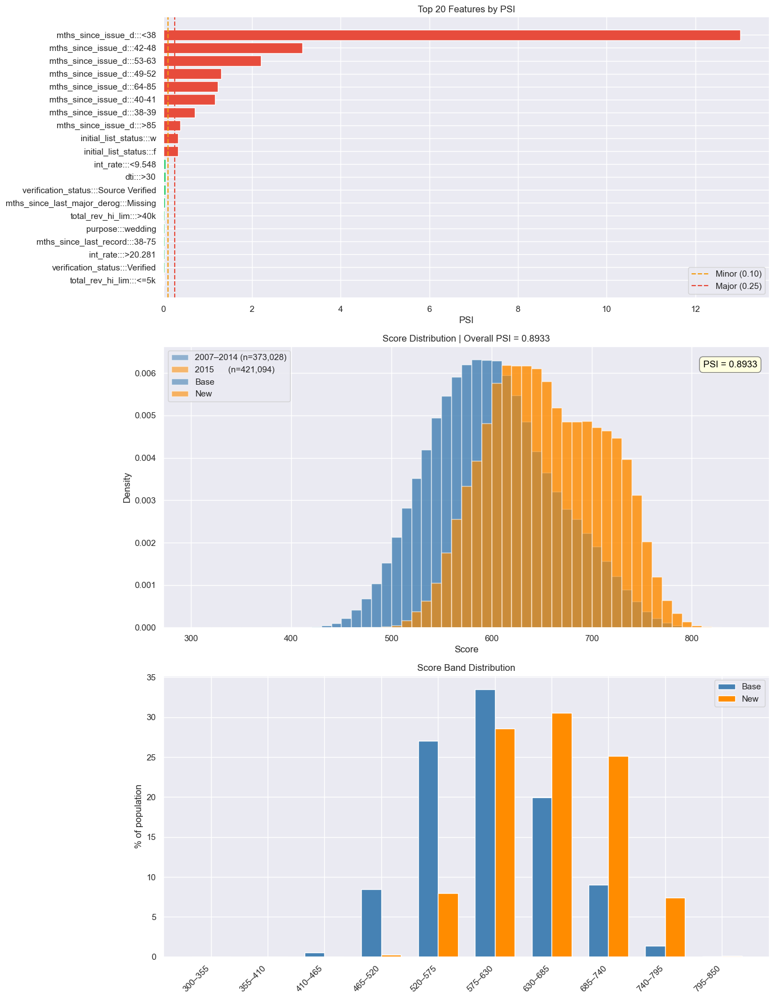

Charts saved to psi_analysis.png

VARIABLE-LEVEL PSI (max drift per variable):

Variable  Num_Bins  Max_PSI  Avg_PSI
         mths_since_issue_d         8  13.0232   2.8914
        initial_list_status         2   0.3337   0.3337
                   int_rate         5   0.0566   0.0195
                        dti         4   0.0537   0.0182
        verification_status         3   0.0470   0.0248
mths_since_last_major_derog         5   0.0335   0.0127
           total_rev_hi_lim         5   0.0317   0.0148
                    purpose        14   0.0312   0.0033
     mths_since_last_record         5   0.0262   0.0091
                       term         1   0.0131   0.0131

In [427]:
# =============================================================================
# PSI ANALYSIS — 2007–2014 TRAINING DATA vs 2015 DATA
# Uses preprocessed DataFrames from your robust pipeline.
# =============================================================================


import matplotlib.ticker as mticker

# expected_columns = model_features   # model_features must be a list
# df_train_preprocessed = preprocess_loan_data_robust(loan_data_inputs_train, expected_columns)
# df_2015_preprocessed = preprocess_loan_data_robust(loan_data_2015, expected_columns)

# -----------------------------------------------------------------------------
# STEP 0 — Use your existing preprocessed data (adjust names if needed)
# -----------------------------------------------------------------------------
# Replace these variable names with the ones in your workspace:
base_df = df_train_preprocessed          # 2007–2014 training data (preprocessed)
new_df  = df_2015_preprocessed           # 2015 data (preprocessed)
scorecard = df_scorecard                 # scorecard with index = feature names

print(f"Base population (2007–2014): {base_df.shape[0]:,} rows")
print(f"Comparison population (2015): {new_df.shape[0]:,} rows")

# Ensure both have the same columns (they should, after same preprocessing)
assert list(base_df.columns) == list(new_df.columns), "Column mismatch!"
print("✅ Column alignment OK.\n")

# -----------------------------------------------------------------------------
# STEP 1 — Core PSI function (unchanged) . this is for a single column yes vs no . good vs bad 
# -----------------------------------------------------------------------------
def calculate_psi_for_column(base_series, comp_series, col_name, epsilon=1e-6):
    base_pct_1 = base_series.mean()
    comp_pct_1 = comp_series.mean()
    base_pct_0 = 1 - base_pct_1
    comp_pct_0 = 1 - comp_pct_1
    # bins = [(comp_pct_0, base_pct_0), (comp_pct_1, base_pct_1)]
    
    bins = [
    (comp_pct_0, base_pct_0),  # Tuple 1: (Actual 0s, Expected 0s)
    (comp_pct_1, base_pct_1)   # Tuple 2: (Actual 1s, Expected 1s)
    ] # Comparison dataset is the Actual (\(A\)) distribution, and  Base dataset is the Expected (\(E\)) distribution.
    # print(f'{bins[0:2]=}[0:2]')

    # To choose ONLY Bin 0 (The 0s / Inactive):Slice from index 0 up to (but not including) index 1.
    only_bin_0 = bins[0:1] 
    # To choose ONLY Bin 1 (The 1s / Active):Slice from index 1 to the end of the list.
    only_bin_1 = bins[1:] 
    # To grab a single bin directly as a tuple (no outer list):Instead of slicing, just access its exact index:
    bin_0_tuple = bins[0]  
    bin_1_tuple = bins[1]  
    print(f'{only_bin_0=}, \n\n {bin_0_tuple =}, \n\n, "=" *10,  {bin_1_tuple=} ')

    '''Slicing inside the Tuples (Extracting Actual vs Expected)If you have a single bin tuple, you extract the inner numbers by using a second set of
    brackets. Remember that index 0 is always Actual (a) and index 1 is always Expected (e).'''

    # Let's look at Bin 0: (comp_pct_0, base_pct_0)
    print(f'Grabs index 0 of Bin 0 -> Actual (Comparison) % , {bins[0][0]=}\n\n\n')  # Grabs index 0 of Bin 0 -> Actual (Comparison) % 
    print(f'Grabs index 1 of Bin 0 -> Expected (Base) %, {bins[0][1]=}')  # Grabs index 1 of Bin 0 -> Expected (Base) %

    # Let's look at Bin 1: (comp_pct_1, base_pct_1)
    print(f' Grabs index 0 of Bin 1 -> Actual (Comparison) %, {bins[1][0]=}')  # Grabs index 0 of Bin 1 -> Actual (Comparison) %
    print(bins[1][1])  # Grabs index 1 of Bin 1 -> Expected (Base) %

    '''How to calculate PSI on only one specific binIf you want to modify your calculation line to strictly run on a single bin 
    (for example, if you wanted to isolate the drift contribution of just the active population), you can pass your slice directly into the sum loop:'''
    # This calculates the drift contribution of ONLY Bin 1 (the 1s)
    psi_just_ones = sum((a - e) * np.log((a + epsilon) / (e + epsilon)) for a, e in bins[1:])


    '''In Python, the continue keyword tells the loop to skip the rest of the code inside the current iteration and jump straight to the next item 
    in the loop.'''
    psi = sum((a - e) * np.log((a + epsilon) / (e + epsilon)) for a, e in bins)
    if psi < 0.10:
        decision = "✅ Stable"
    elif psi < 0.25:
        decision = "⚠️ Minor shift"
    else:
        decision = "🚨 Major shift"
    return {
        'Feature': col_name,
        'Base_%_Active': round(base_pct_1 * 100, 2),
        'Comp_%_Active': round(comp_pct_1 * 100, 2),
        'Abs_Drift_%': round(abs(comp_pct_1 - base_pct_1) * 100, 2),
        'PSI': round(psi, 4),
        'Decision': decision,
    }

# -----------------------------------------------------------------------------
# STEP 2 — Get model features from scorecard index (exclude Intercept) # GETTING PSI FOR ALL COLUMNS USING THE FORMULA ABOVE THAT CALCULATES FOR A SINGLE FEATURE
# -----------------------------------------------------------------------------
model_features = scorecard.index.tolist()
model_features = [f for f in model_features if f != 'Intercept']
print(f"Running PSI for {len(model_features)} model features...\n")

psi_results = []
for col in model_features:
    if col not in base_df.columns:
        psi_results.append({'Feature': col, 'Base_%_Active': np.nan,
                            'Comp_%_Active': np.nan, 'Abs_Drift_%': np.nan,
                            'PSI': np.nan, 'Decision': '⚠️ Not in base'})
        continue  # <--- Jumps straight to the next feature in model_features!
    if col not in new_df.columns:
        psi_results.append({'Feature': col, 'Base_%_Active': np.nan,
                            'Comp_%_Active': np.nan, 'Abs_Drift_%': np.nan,
                            'PSI': np.nan, 'Decision': '⚠️ Not in new'})
        continue  # <--- Jumps straight to the next feature in model_features!
    result = calculate_psi_for_column(base_df[col], new_df[col], col)    # <--- This is also skipped when continue activates
    psi_results.append(result)


    
df_psi = pd.DataFrame(psi_results).sort_values('PSI', ascending=False).reset_index(drop=True)
print("Done.\n")



'''
1. Confirmation: calculate_psi_for_column Is Binary-Only
Yes — you are 100% right.
calculate_psi_for_column works on one binary dummy column (0/1).
It computes PSI for that single dummy, not the parent feature.
To get the true PSI for grade, you must sum the contributions from grade:::A, grade:::B, grade:::C, etc.
The binary function is mostly useful as a screening tool (which individual dummies moved?), but it is not the correct feature-level PSI unless you 
aggregate afterward.
The correct workflow for feature-level PSI:
Python
# 1. Compute PSI per dummy (binary function)
# 2. Group by parent feature and SUM the contributions
# OR skip dummies entirely and use the original categorical column
compute_overall_psi is different — it bins the final score (300–850) into 10 bands and computes PSI on the score distribution. That is your top-level
health check.
'''

# -----------------------------------------------------------------------------
# STEP 3 — Overall (score‑level) PSI using scorecard
# -----------------------------------------------------------------------------
def compute_overall_psi(base_df, comp_df, scorecard_df, n_bins=10, epsilon=1e-6):
    all_features = scorecard_df.index.tolist()
    if 'Intercept' in all_features:
        intercept = scorecard_df.loc['Intercept', 'Score']
        features = [f for f in all_features if f != 'Intercept']
    else:
        intercept = 0
        features = all_features
    score_vec = scorecard_df.loc[features, 'Score'].values
    base_scored = base_df.reindex(columns=features, fill_value=0)
    comp_scored = comp_df.reindex(columns=features, fill_value=0)
    scores_base = base_scored.dot(score_vec) + intercept
    scores_comp = comp_scored.dot(score_vec) + intercept
    scores_base = scores_base.clip(300, 850)
    scores_comp = scores_comp.clip(300, 850)
    bins = np.linspace(300, 850, n_bins + 1)
    labels = [f"{int(bins[i])}–{int(bins[i+1])}" for i in range(n_bins)]
    base_binned = pd.cut(scores_base, bins=bins, labels=labels, include_lowest=True)
    comp_binned = pd.cut(scores_comp, bins=bins, labels=labels, include_lowest=True)
    base_counts = base_binned.value_counts().reindex(labels, fill_value=0)
    comp_counts = comp_binned.value_counts().reindex(labels, fill_value=0)
    base_pct = base_counts / base_counts.sum()
    comp_pct = comp_counts / comp_counts.sum()
    psi_per_bin = (comp_pct - base_pct) * np.log((comp_pct + epsilon) / (base_pct + epsilon))
    overall_psi = psi_per_bin.sum()
    
    df_score_psi = pd.DataFrame({
        'Score_Band': labels,
        'Base_%': (base_pct * 100).round(2).values,
        'Comp_%': (comp_pct * 100).round(2).values,
        'Drift_%': ((comp_pct - base_pct) * 100).round(2).values,
        'PSI_Contrib': psi_per_bin.round(4).values,
    })
    return overall_psi, df_score_psi, scores_base, scores_comp


overall_psi, df_score_psi, scores_base, scores_comp = compute_overall_psi(
    base_df, new_df, scorecard
)

if overall_psi < 0.10:
    overall_decision = "✅ Stable — model valid"
elif overall_psi < 0.25:
    overall_decision = "⚠️ Minor shift — monitor"
else:
    overall_decision = "🚨 Major shift — rebuild"

'''
Full syntax:
Python
Series.sum(axis=None, skipna=True, numeric_only=False, min_count=0, **kwargs)
What happens step by step:
Table
Step	Expression	Result
1	df_psi['PSI'] < 0.10	A Series of True/False (e.g., [True, False, True, ...])
2	.sum()	Counts True as 1 and False as 0
3	Final output	An integer: “How many features have PSI below 0.10?”
'''

print("=" * 60)
print(f"OVERALL PSI: {overall_psi:.4f}   |   {overall_decision}")
print("=" * 60)

# -----------------------------------------------------------------------------
# STEP 4 — Summary tables and plots (same as before, using df_psi, scores_base, scores_comp)
# -----------------------------------------------------------------------------
pd.set_option('display.max_rows', None)
print("\nFEATURE-LEVEL PSI (top 20 by PSI):")
print(df_psi.head(20).to_string(index=False)) # recall df_psi = pd.DataFrame(psi_results).sort_values('PSI', ascending=False).reset_index(drop=True)

stable = (df_psi['PSI'] < 0.10).sum()
minor = ((df_psi['PSI'] >= 0.10) & (df_psi['PSI'] < 0.25)).sum()
major = (df_psi['PSI'] >= 0.25).sum()



print(f"\nStability summary: Stable={stable}, Minor={minor}, Major={major}")

# Plotting
fig, axes = plt.subplots(3, 1, figsize=(14, 18))
# Top 20 features
ax = axes[0]


print(f'df_psi,\n\n {df_psi}')

df_plot = df_psi.dropna(subset=['PSI']).head(20)

print(f'df_plot \n\n {df_plot}')

colors = df_plot['PSI'].apply(lambda x: '#e74c3c' if x >= 0.25 else ('#f39c12' if x >= 0.10 else '#2ecc71'))
ax.barh(df_plot['Feature'][::-1], df_plot['PSI'][::-1], color=colors[::-1])
ax.axvline(0.10, color='#f39c12', linestyle='--', label='Minor (0.10)')
ax.axvline(0.25, color='#e74c3c', linestyle='--', label='Major (0.25)')
ax.set_xlabel('PSI')
ax.set_title('Top 20 Features by PSI')
ax.legend()


# Score distribution, second subplot
ax = axes[1]

ax.hist(scores_base, bins=55, range=(300,850), alpha=0.55, color='steelblue',  label=f'2007–2014 (n={len(scores_base):,})', density=True)
ax.hist(scores_comp, bins=55, range=(300,850), alpha=0.55, color='darkorange', label=f'2015      (n={len(scores_comp):,})', density=True)

'''density=True – normalise the histogram so the total area equals 1. This makes the shapes comparable even if the sample sizes are different 
(e.g., 10,000 base vs 5,000 new). Without density=True, the histogram would show counts, which would be misleading if one dataset is larger.

Example with tiny data
Suppose scores_base = [510, 580, 620, 650, 710] (5 scores)
scores_comp = [530, 560, 600, 640, 680, 720] (6 scores)
With density=True, the histograms will be scaled so the area under each histogram is 1. 
You can compare the shapes even though one has 5 and the other 6 points. The overlap shows where the two populations are similar.'''


ax.hist(scores_base, bins=55, range=(300,850), alpha=0.6, density=True, label='Base', color='steelblue')
ax.hist(scores_comp, bins=55, range=(300,850), alpha=0.6, density=True, label='New', color='darkorange')
ax.set_xlabel('Score')
ax.set_ylabel('Density')
ax.set_title(f'Score Distribution | Overall PSI = {overall_psi:.4f}')

ax.text(0.98, 0.95, f"PSI = {overall_psi:.4f}", transform=ax.transAxes,
        ha='right', va='top', fontsize=12, color='black',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', edgecolor='gray'))
'''
ax.text places text inside the plot area. 
transform=ax.transAxes means coordinates are relative to the axes: (0.98, 0.95) is near the top‑right corner (x from 0 to 1, y from 0 to 1).
ha='right', va='top' aligns the text so its right‑top corner is at that point.bbox draws a light yellow box around the text with rounded corners
(boxstyle='round'). This makes the text stand out.'''


ax.legend()



# Score bands
ax = axes[2]
x = np.arange(len(df_score_psi))

print('\n\n\n',df_score_psi.head, '\n\n')
print((len(df_score_psi)))

w = 0.35
ax.bar(x - w/2, df_score_psi['Base_%'], w, label='Base', color='steelblue')
ax.bar(x + w/2, df_score_psi['Comp_%'], w, label='New', color='darkorange')
ax.set_xticks(x)
ax.set_xticklabels(df_score_psi['Score_Band'], rotation=45, ha='right')
ax.set_ylabel('% of population')
ax.set_title('Score Band Distribution')
ax.legend()
#ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
'''Formats the y‑axis tick labels to always show a percent sign and one decimal place (e.g., "12.3%").'''

plt.tight_layout()
plt.savefig('psi_analysis.png', dpi=150)
plt.show()
print("\nCharts saved to psi_analysis.png")

# -----------------------------------------------------------------------------
# STEP 5 — Variable‑level aggregation (optional)
# -----------------------------------------------------------------------------
df_psi_valid = df_psi.dropna(subset=['PSI']).copy()
df_psi_valid['Variable'] = df_psi_valid['Feature'].str.split(':::').str[0]
df_psi_by_var = (df_psi_valid.groupby('Variable').agg(
    Num_Bins=('PSI','count'), Max_PSI=('PSI','max'), Avg_PSI=('PSI','mean')
).round(4).sort_values('Max_PSI', ascending=False).reset_index())
print("\nVARIABLE-LEVEL PSI (max drift per variable):")
print(df_psi_by_var.head(10).to_string(index=False))

# Export CSVs
#df_psi.to_csv('psi_feature_level.csv', index=False)
#df_psi_by_var.to_csv('psi_variable_level.csv', index=False)
#df_score_psi.to_csv('psi_score_bands.csv', index=False)
#print("\nExported CSV files.")

In [428]:
print(f"NaNs in base scores: {scores_base.isna().sum()}")
print(f"NaNs in comp scores: {scores_comp.isna().sum()}")

NaNs in base scores: 0

NaNs in comp scores: 0

In [429]:
inputs_base = base_df
inputs_2015 = new_df

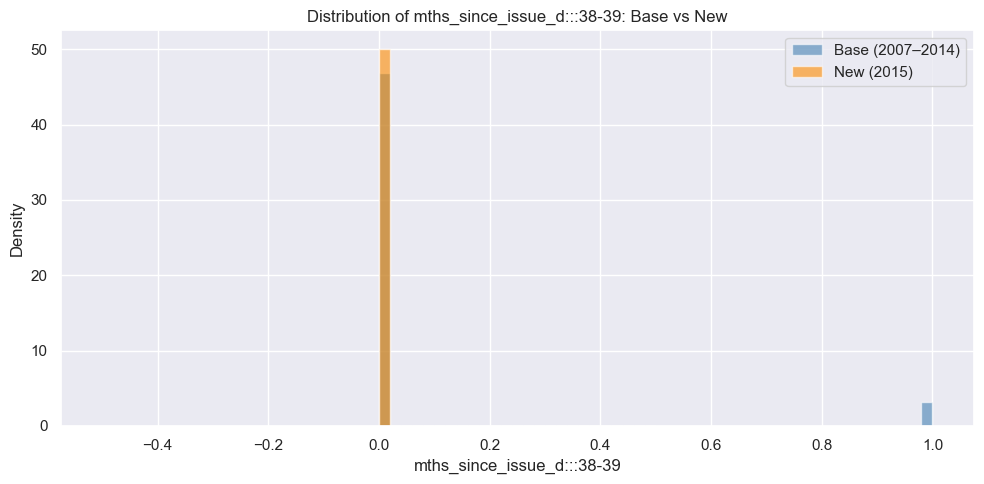

--- mths_since_issue_d:::38-39 Summary ---

Base: mean = 0.06, median = 0.00

New:  mean = 0.00, median = 0.00

In [430]:
### 1. . Histogram for a continuous feature (like mths_since_issue_d)

'''

KeyError: 'mths_since_issue_d' in plot_feature_distribution
Cause: After your robust preprocessing, you do not have a raw continuous column named 'mths_since_issue_d'. 
Your preprocessing function bins this variable into dummies like:

'mths_since_issue_d:::<38'

'mths_since_issue_d:::38-39'

… and so on.

The original column is dropped (see drop_cats list in your function). Therefore, you cannot plot a histogram of a column that doesn't exist.

Solution: For a binned variable, you should plot a bar chart of the proportion of loans in each bin (the dummy variables). 
This is more informative than a histogram of the original continuous variable anyway, because PSI is computed on the dummies.

Corrected function for binned variables (like mths_since_issue_d)

'''


def plot_feature_distribution(base_df, comp_df, feature_name, bins=50):
    """
    Plot histogram overlays for base vs new population.
    base_df, comp_df: DataFrames with the feature column
    feature_name: string column name
    bins: number of histogram bins
    """
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plot both histograms with transparency
    ax.hist(base_df[feature_name], bins=bins, alpha=0.6, density=True, 
            label=f'Base (2007–2014)', color='steelblue')
    ax.hist(comp_df[feature_name], bins=bins, alpha=0.6, density=True, 
            label=f'New (2015)', color='darkorange')
    
    ax.set_xlabel(feature_name)
    ax.set_ylabel('Density')
    ax.set_title(f'Distribution of {feature_name}: Base vs New')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print(f"\n--- {feature_name} Summary ---")
    print(f"Base: mean = {base_df[feature_name].mean():.2f}, median = {base_df[feature_name].median():.2f}")
    print(f"New:  mean = {comp_df[feature_name].mean():.2f}, median = {comp_df[feature_name].median():.2f}")

# Example usage
plot_feature_distribution(inputs_base, inputs_2015, 'mths_since_issue_d:::38-39')

In [431]:
'''IF YOU ONLY WANT TO SEE ONE EXAMPLE

Do NOT put the prints inside the function that's being called 96 times.

Instead, temporarily test the function on one column.'''

result = calculate_psi_for_column(
    inputs_base['grade:::A'],
    df_2015_preprocessed['grade:::A'],
    'grade:::A'
)

# Now the function executes once. Then your debug output appears once.

result

only_bin_0=[(np.float64(0.8258464855827915), np.float64(0.8398002294733907))], 

 bin_0_tuple =(np.float64(0.8258464855827915), np.float64(0.8398002294733907)), 

, "=" *10,  bin_1_tuple=(np.float64(0.1741535144172085), np.float64(0.16019977052660928))

Grabs index 0 of Bin 0 -> Actual (Comparison) % , bins[0][0]=np.float64(0.8258464855827915)

Grabs index 1 of Bin 0 -> Expected (Base) %, bins[0][1]=np.float64(0.8398002294733907)

Grabs index 0 of Bin 1 -> Actual (Comparison) %, bins[1][0]=np.float64(0.1741535144172085)

0.16019977052660928

{'Feature': 'grade:::A',
 'Base_%_Active': np.float64(16.02),
 'Comp_%_Active': np.float64(17.42),
 'Abs_Drift_%': np.float64(1.4),
 'PSI': np.float64(0.0014),
 'Decision': '✅ Stable'}

In [432]:
np.sort(inputs_base.columns)

array(['Intercept', 'Score - Float', 'Score_Bin',
       'addr_state:::AR_MI_PA_OH_MN', 'addr_state:::GA_WA_OR',
       'addr_state:::IL_CT', 'addr_state:::KS_SC_CO_VT_AK_MS',
       'addr_state:::ND_NE_IA_NV_FL_HI_AL', 'addr_state:::NM_VA',
       'addr_state:::OK_TN_MO_LA_MD_NC', 'addr_state:::RI_MA_DE_SD_IN',
       'addr_state:::UT_KY_AZ_NJ', 'addr_state:::WI_MT',
       'addr_state:::WV_NH_WY_DC_ME_ID', 'annual_inc:::100k-120k',
       'annual_inc:::120k-140k', 'annual_inc:::20k-30k',
       'annual_inc:::30k-40k', 'annual_inc:::40k-50k',
       'annual_inc:::50k-60k', 'annual_inc:::60k-70k',
       'annual_inc:::70k-80k', 'annual_inc:::80k-90k',
       'annual_inc:::90k-100k', 'annual_inc:::<20k', 'annual_inc:::>140k',
       'dti:::10-20', 'dti:::20-30', 'dti:::<10', 'dti:::>30',
       'emp_length:::Missing', 'funded:::funded:high',
       'funded:::funded:low', 'funded:::funded:medium',
       'funded:::funded:very_high', 'grade:::A', 'grade:::B', 'grade:::C',
       'grade:::

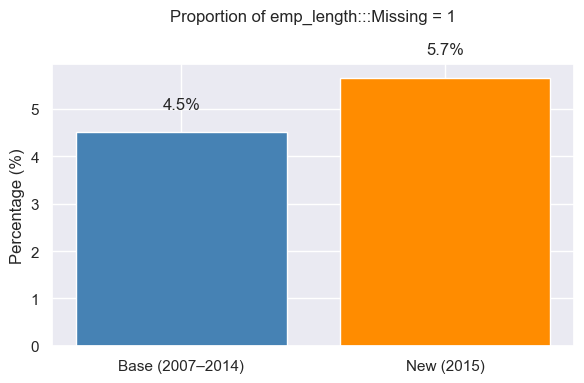

Base proportion: 4.51% | New proportion: 5.66%

Absolute drift: 1.15 percentage points

In [433]:
# 2. For categorical dummy features (e.g., emp_length:::Missing)
inputs_base = df_train_preprocessed.copy()

def plot_dummy_proportions(base_df, comp_df, feature_name):
    """
    Bar chart comparing proportion of 1's (active) in base vs new.
    """
    prop_base = base_df[feature_name].mean() * 100
    prop_new = comp_df[feature_name].mean() * 100
    
    fig, ax = plt.subplots(figsize=(6, 4))
    categories = ['Base (2007–2014)', 'New (2015)']
    values = [prop_base, prop_new]
    colors = ['steelblue', 'darkorange']
    ax.bar(categories, values, color=colors)
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Proportion of {feature_name} = 1\n\n')
    for i, v in enumerate(values):
        ax.text(i, v + 0.5, f'{v:.1f}%', ha='center')
    plt.tight_layout()
    plt.show()
    
    print(f"Base proportion: {prop_base:.2f}% | New proportion: {prop_new:.2f}%")
    print(f"Absolute drift: {abs(prop_new - prop_base):.2f} percentage points")

# Example for emp_length:::Missing
'''
Puts the percentage value slightly above each bar (v + 0.5).

enumerate gives the index i (0 for Base, 1 for New) and the value v.

Example output:
Bar for Base at 0%, Bar for New at 5.7%, with text "5.7%" above the New bar.

Intention: Quickly see whether the proportion of a single binary feature has changed. This is often used for missing flags or rare events.



Base proportion: 0.00%

New proportion: 5.66%

Absolute drift: 5.66 percentage points

This is fine. It means that in the training data (2007–2014), there were no loans with missing employment length 
(or the dummy emp_length:::Missing was never 1). In 2015, about 5.66% of loans have missing employment length. This is a real drift. Whether it is "okay" depends on the model's treatment of missing values. For PSI, this drift contributed to the overall emp_length variable PSI of 1.14 (which is high). You would need to investigate why missingness increased in 2015 – maybe data collection changed.

No error here. The output is correct.

'''


plot_dummy_proportions(inputs_base, df_2015_preprocessed, 'emp_length:::Missing')


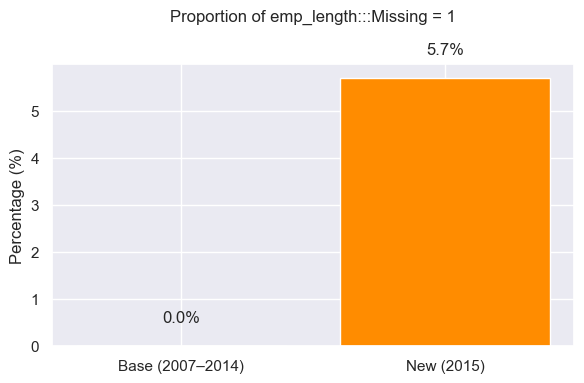

Base proportion: 0.00% | New proportion: 5.70%

Absolute drift: 5.70 percentage points

In [434]:
# Create fake data

fake_base = pd.DataFrame({'emp_length:::Missing': [0]*1000})  # 0% missing
fake_new  = pd.DataFrame({'emp_length:::Missing': [0]*943 + [1]*57})  # 5.7% missing

# Run the function
plot_dummy_proportions(fake_base, fake_new, 'emp_length:::Missing')

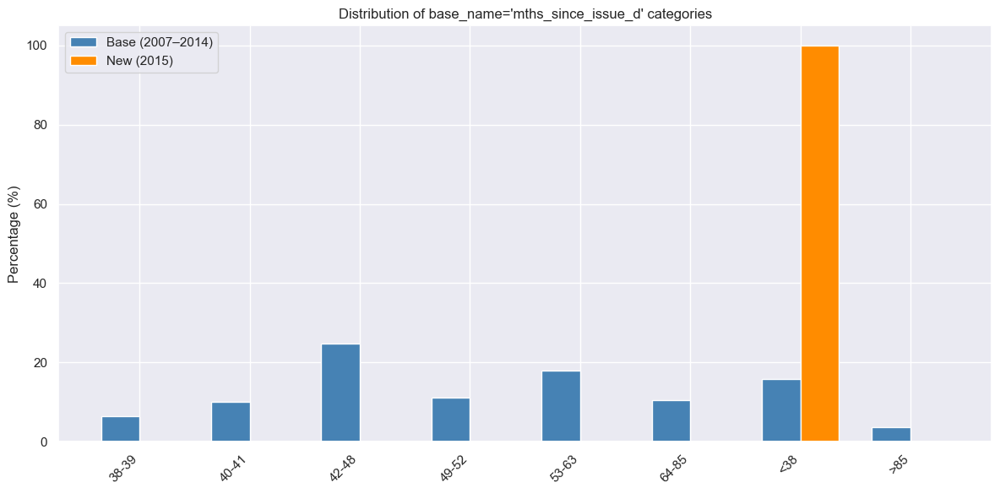

In [436]:
# 3. For grouped features (all bins of a categorical variable like grade)

import ipywidgets as widgets
from ipywidgets import interact


def plot_all_bins_of_feature(base_df, comp_df, base_name, n_top=10):
    """
    For a variable that has multiple dummies (e.g., grade:::A, grade:::B...),
    plot side‑by‑side proportions for base vs new.
    base_name: the prefix before ':::' (e.g., 'grade')

    This is similar to plot_binned_distribution but for variables where the dummy columns represent categories (e.g., grade:::A, grade:::B, …). 
    The only difference is that the bin labels are the category names ("A", "B", …).


    """
    # Get all columns that start with base_name:::
    pattern = f"{base_name}:::"
    base_cols = [c for c in base_df.columns if c.startswith(pattern)]
    comp_cols = [c for c in comp_df.columns if c.startswith(pattern)]
    # Use intersection of columns present in both
    common_cols = sorted(set(base_cols) & set(comp_cols))
    
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    
    prop_base = [base_df[col].mean() * 100 for col in common_cols]
    prop_new  = [comp_df[col].mean() * 100 for col in common_cols]
    
    x = np.arange(len(common_cols))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, prop_base, width, label='Base (2007–2014)', color='steelblue')
    ax.bar(x + width/2, prop_new, width, label='New (2015)', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels([col.split(':::')[1] for col in common_cols], rotation=45, ha='right')
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Distribution of {base_name=} categories')
    ax.legend()
    plt.tight_layout()
    plt.show()

# Example for grade
plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'mths_since_issue_d')

interactive(children=(FloatSlider(value=0.35, description='width', max=0.5, min=0.1, step=0.01), IntSlider(val…

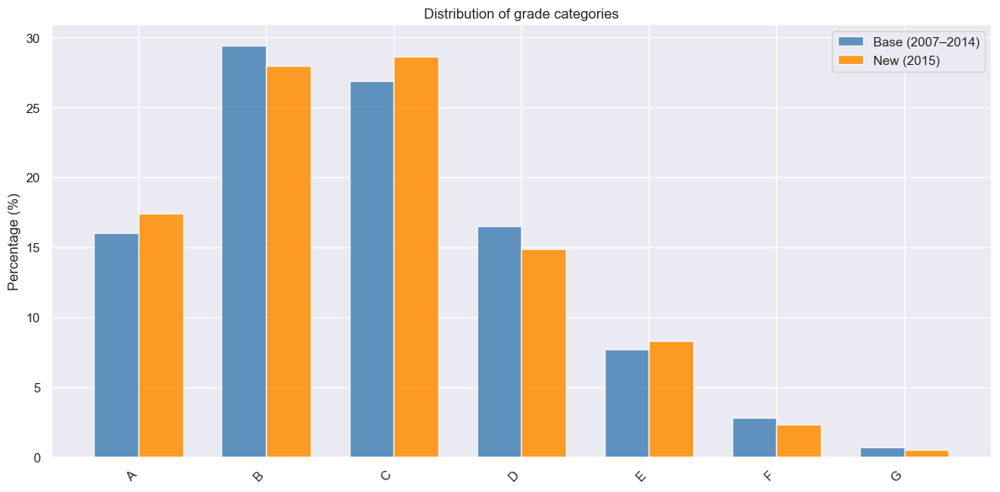

"\nYou're seeing two duplicate graphs because:\n@widgets.interact replaces your original function with a widget object that, when displayed, renders the sliders and calls the function once to show \nthe initial plot.\n\nThat replacement still returns something, but also triggers a plot.\n\nThe decorator @widgets.interact automatically calls your function once when the widget is created, displaying the first plot.\n\nThen you explicitly call plot_all_bins_of_feature() at the end of the cell, which displays a second identical plot.\n\nto see only one graph #plot_all_bins_of_feature()\n"

In [437]:
# Two solutions (both use @ but differently)
''' Solution 1: Remove data parameters from the function signature (recommended)
Take base_df, comp_df, base_name out of the parameters and use them as global (or closure) variables. Then decorate only the interactive parameters.

Why this works: The decorator only sees width, rotation, alpha – all numbers that it can turn into sliders. 
The DataFrames are taken from the surrounding environment.'''


import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np

# Assume these DataFrames already exist in your notebook
# inputs_base, df_2015_preprocessed

@widgets.interact(width=(0.10, 0.50, 0.01),
                  rotation=(0, 90, 5),
                  alpha=(0.3, 1.0, 0.05))
def plot_all_bins_of_feature(width=0.35, rotation=45, alpha=0.85):
    """
    Uses global DataFrames: inputs_base, df_2015_preprocessed
    base_name is fixed to 'grade' (or make it a dropdown – see below)
    """
    plt.close('all')   # CLEAR CACHE: remove old figures
    base_name = 'grade'   # or pass as a dropdown widget separately
    pattern = f"{base_name}:::"
    base_cols = [c for c in inputs_base.columns if c.startswith(pattern)]
    comp_cols = [c for c in df_2015_preprocessed.columns if c.startswith(pattern)]
    common_cols = sorted(set(base_cols) & set(comp_cols))
    
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    
    prop_base = [inputs_base[col].mean() * 100 for col in common_cols]
    prop_new  = [df_2015_preprocessed[col].mean() * 100 for col in common_cols]
    
    x = np.arange(len(common_cols))
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, prop_base, width, alpha=alpha, label='Base (2007–2014)', color='steelblue')
    ax.bar(x + width/2, prop_new, width, alpha=alpha, label='New (2015)', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels([col.split(':::')[1] for col in common_cols], rotation=rotation, ha='right')
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Distribution of {base_name} categories')
    ax.legend()
    plt.tight_layout()
    plt.show()

# Call it – no arguments needed, sliders appear automatically



plot_all_bins_of_feature()

'''
You're seeing two duplicate graphs because:
@widgets.interact replaces your original function with a widget object that, when displayed, renders the sliders and calls the function once to show 
the initial plot.

That replacement still returns something, but also triggers a plot.

The decorator @widgets.interact automatically calls your function once when the widget is created, displaying the first plot.

Then you explicitly call plot_all_bins_of_feature() at the end of the cell, which displays a second identical plot.

to see only one graph #plot_all_bins_of_feature()
'''


In [438]:


def plot_all_bins_of_feature(base_df, comp_df, base_name, width=0.35, rotation=45, alpha=0.85):
    """
    Plots side‑by‑side proportions for all dummy columns of a categorical variable.
    Now accepts styling parameters: width, rotation, alpha.
    """
    pattern = f"{base_name}:::"
    base_cols = [c for c in base_df.columns if c.startswith(pattern)]
    comp_cols = [c for c in comp_df.columns if c.startswith(pattern)]
    common_cols = sorted(set(base_cols) & set(comp_cols))
    
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    
    prop_base = [base_df[col].mean() * 100 for col in common_cols]
    prop_new  = [comp_df[col].mean() * 100 for col in common_cols]
    
    x = np.arange(len(common_cols))
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, prop_base, width, alpha=alpha, label='Base (2007–2014)', color='steelblue')
    ax.bar(x + width/2, prop_new, width, alpha=alpha, label='New (2015)', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels([col.split(':::')[1] for col in common_cols], rotation=rotation, ha='right')
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Distribution of {base_name} categories')
    ax.legend()
    plt.tight_layout()
    plt.show()


'''
Now you can use @interact directly on this function, but you must fix the base_df, comp_df, and base_name arguments because they are not interactive. 
You can do that by closing over them with a wrapper, or by using functools.partial.'''

def interactive_bins(width=0.35):
    plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'grade', width=width)

interact(interactive_bins, width=(0.10, 0.60, 0.01))

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), Output()), _d…

<function __main__.interactive_bins(width=0.35)>

In [439]:
def interactive_bins(width=0.35, rotation=45, alpha=0.85):
    plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'grade', 
                             width=width, rotation=rotation, alpha=alpha)

interact(interactive_bins, 
         width=(0.10, 0.60, 0.01), 
         rotation=(0, 90, 5), 
         alpha=(0.3, 1.0, 0.05))

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), IntSlider(val…

<function __main__.interactive_bins(width=0.35, rotation=45, alpha=0.85)>

In [440]:
from ipywidgets import interact

@interact(
    width=(0.10, 0.60, 0.01),
    rotation=(0, 90, 5),
    alpha=(0.3, 1.0, 0.05)
)
def interactive_bins(width=0.35, rotation=45, alpha=0.85):

    plot_all_bins_of_feature(
        inputs_base,
        df_2015_preprocessed,
        'grade',
        width=width,
        rotation=rotation,
        alpha=alpha
    )

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), IntSlider(val…

In [441]:
'''
🧹 Avoiding the duplicate plot issue
When you use @interact (or interact()), the function is automatically called once to show the initial plot.
If you also call the function explicitly again later in the same cell (e.g., plot_all_bins_of_feature()), you get two plots.

Solution: Only use the interactive widget call. Do not call the function directly after defining the interact.

So in your notebook cell, just have:'''


# If using the @interact decorator:
@interact(width=(0.10, 0.60, 0.01), rotation=(0, 90, 5), alpha=(0.3, 1.0, 0.05))
def plot_grade(width=0.35, rotation=45, alpha=0.85):
    plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'grade', 
                             width=width, rotation=rotation, alpha=alpha)
# Do NOT call plot_grade() again here – the widget already shows the plot.

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), IntSlider(val…

In [442]:
'''
Solution 1: Remove data parameters from the function signature (Recommended)In this approach, you keep the dataframes
(inputs_base, df_2015_preprocessed) in the global scope and only expose the interactive parameter (base_name) to the widget dropdown.
'''

# Extract unique categorical prefixes (e.g., everything before ':::')
all_prefixes = sorted(
    list(
        set(
            [
                c.split(":::")[0]
                for c in inputs_base.columns
                if ":::" in c
            ]
        )
    )
)


@interact(base_name=all_prefixes)
def plot_all_bins_interactive(base_name):
    # base_df and comp_df are captured from the global scope
    plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, base_name)


interactive(children=(Dropdown(description='base_name', options=('addr_state', 'annual_inc', 'dti', 'emp_lengt…

In [443]:
def interactive_bins(width=0.35):

    plot_all_bins_of_feature(
        inputs_base,
        df_2015_preprocessed,
        'grade',
        width=width
    )

interact(
    interactive_bins,
    width=(0.10, 0.60, 0.01)
);

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), Output()), _d…

In [444]:

def interactive_bins(
    width=0.35,
    rotation=45,
    alpha=0.85
):

    plot_all_bins_of_feature(
        inputs_base,
        df_2015_preprocessed,
        'grade',
        width=width,
        rotation=rotation,
        alpha=alpha
    )

In [445]:
interact(
    interactive_bins,
    width=(0.10, 0.60, 0.01),
    rotation=(0, 90, 5),
    alpha=(0.3, 1.0, 0.05)
);

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), IntSlider(val…

In [446]:
interact(
    plot_all_bins_of_feature,
    base_df=widgets.fixed(inputs_base),
    comp_df=widgets.fixed(df_2015_preprocessed),
    base_name=widgets.fixed('grade'),
    width=(0.10, 0.60, 0.01)
);

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), IntSlider(val…

In [447]:
# Step 1 — Make actual data
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

x = np.arange(10)
y = x ** 2


# Step 2 — Write the actual plotting function

def update_plot(width, alpha):

    plt.close('all')

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        x,
        y,
        width=width,
        alpha=alpha
    )

    ax.set_title(
        f"Width = {width:.2f}, Alpha = {alpha:.2f}"
    )

    plt.show()


# CREATE REAL CONTROLS

width_slider = widgets.FloatSlider(
    value=0.35,
    min=0.10,
    max=0.90,
    step=0.05,
    description='Width'
)

alpha_slider = widgets.FloatSlider(
    value=0.60,
    min=0.10,
    max=1.00,
    step=0.05,
    description='Alpha'
)

'''
Now you have two widget objects:
width_slider
      ↓
┌───────────────────────┐
│ Width  ───●────────   │
└───────────────────────┘

alpha_slider
      ↓
┌───────────────────────┐
│ Alpha  ───────●────   │
└───────────────────────┘
'''


# CONNECT THE CONTROLS TO THE FUNCTION

ui = widgets.interactive(
    update_plot,
    width=width_slider,
    alpha=alpha_slider
)


'''
Take update_plot()

connect its width parameter
       ↓
to width_slider

connect its alpha parameter
       ↓
to alpha_slider
'''


# NOW DISPLAY IT

display(ui)

interactive(children=(FloatSlider(value=0.35, description='Width', max=0.9, min=0.1, step=0.05), FloatSlider(v…

In [448]:
'''
Solution 2: Use a closure / currying decorator factoryIf you want to keep the dataframes as parameters inside the function signature, you can wrap the 
plotting function inside a decorator factory or closure that pre-binds the dataframes.
'''


def interactive_plotter(base_df, comp_df):
    all_prefixes = sorted(
        list(set([c.split(":::")[0] for c in base_df.columns if "::: " in c or ":::" in c]))
    )
    
    # Decorator factory that binds the dataframes
    def decorator(func):
        return interact(func, base_name=all_prefixes)
        
    return decorator

# Usage with the @ syntax:
@interactive_plotter(inputs_base, df_2015_preprocessed)
def plot_all_bins_of_feature_wrapped(base_name):
    plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, base_name)


interactive(children=(Dropdown(description='base_name', options=('addr_state', 'annual_inc', 'dti', 'emp_lengt…

In [449]:
'''The production-ready widget code — using your actual variables
This uses scores_base, scores_comp, df_score_psi, df_psi, inputs_base, and df_2015_preprocessed exactly as they exist in your notebook. 
Paste each block into its own cell, run after your PSI analysis cells.'''

# ── CELL 1: imports ──────────────────────────────────────────────────────────
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
%matplotlib inline
# If widgets don't display, switch to: %matplotlib widget


# ── CELL 2: WIDGET B — Score histogram (Plot B, interactive) ─────────────────
# Uses: scores_base, scores_comp (from compute_overall_psi)
# Controls: alpha (transparency), score_shift (simulated drift)

def plot_score_histogram(alpha=0.55, score_shift=0):
    plt.close('all')                          # prevent figure accumulation
    scores_shifted = (scores_comp + score_shift).clip(300, 850)
    
    fig, ax = plt.subplots(figsize=(12, 4))
    
    ax.hist(
        scores_base,
        bins=55, range=(300, 850),
        alpha=alpha,                          # ← slider controls this
        color='steelblue', density=True,      # density=True: normalises for different n
        label=f'Base 2007–2014  (n={len(scores_base):,})'
    )
    ax.hist(
        scores_shifted,
        bins=55, range=(300, 850),
        alpha=alpha,
        color='darkorange', density=True,
        label=f'2015  (n={len(scores_comp):,})  | shift={score_shift:+d} pts'
    )
    
    ax.set_xlabel('Scorecard Score (300–850)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(
        f'Score Distribution  |  alpha={alpha:.2f}  |  shift={score_shift:+d} pts\n'
        f'Overall PSI = {overall_psi:.4f}  |  {overall_decision}',
        fontsize=11
    )
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

interact(
    plot_score_histogram,
    alpha=widgets.FloatSlider(
        value=0.55, min=0.05, max=1.0, step=0.05,
        description='alpha',
        style={'description_width': '60px'},
        layout=widgets.Layout(width='460px')
    ),
    score_shift=widgets.IntSlider(
        value=0, min=-150, max=150, step=5,
        description='score shift',
        style={'description_width': '90px'},
        layout=widgets.Layout(width='460px')
    )
)


# ── CELL 3: WIDGET C — Grouped bars (Plot C, interactive) ────────────────────
# Uses: df_score_psi (from compute_overall_psi)
# Controls: bar_width (w), label_rotation, n_bins

def plot_score_bands(bar_width=0.38, label_rotation=35, n_bins=10):
    plt.close('all')
    
    # Recompute bands live when n_bins changes
    bins_arr = np.linspace(300, 850, n_bins + 1)
    labels   = [f"{int(bins_arr[i])}-{int(bins_arr[i+1])}" for i in range(n_bins)]
    
    base_binned = pd.cut(scores_base, bins=bins_arr, labels=labels, include_lowest=True)
    comp_binned = pd.cut(scores_comp, bins=bins_arr, labels=labels, include_lowest=True)
    
    base_pct = (base_binned.value_counts().reindex(labels, fill_value=0) / len(scores_base) * 100)
    comp_pct = (comp_binned.value_counts().reindex(labels, fill_value=0) / len(scores_comp) * 100)
    
    x = np.arange(n_bins)
    w = bar_width
    
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.bar(x - w/2, base_pct, width=w, label='Base 2007–2014', color='steelblue', alpha=0.85)
    ax.bar(x + w/2, comp_pct, width=w, label='2015',           color='darkorange', alpha=0.85)
    
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=label_rotation, ha='right', fontsize=9)
    ax.set_ylabel('% of Population', fontsize=11)
    ax.set_title(
        f'Score Band Distribution  |  n_bins={n_bins}  |  w={w:.2f}  |  rotation={label_rotation}°',
        fontsize=11
    )
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

interact(
    plot_score_bands,
    bar_width=widgets.FloatSlider(
        value=0.38, min=0.05, max=0.80, step=0.01,
        description='bar width',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='460px')
    ),
    label_rotation=widgets.IntSlider(
        value=35, min=0, max=90, step=5,
        description='label angle',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='460px')
    ),
    n_bins=widgets.IntSlider(
        value=10, min=5, max=20, step=1,
        description='n_bins',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='460px')
    )
)





# ── CELL 4: WIDGET D — Feature drill-down dropdown ───────────────────────────
# Uses: inputs_base, df_2015_preprocessed, df_psi
# Control: dropdown of variable prefixes extracted from your real df_psi

variable_list = sorted(
    df_psi.dropna(subset=['PSI'])['Feature']
    .str.split(':::').str[0].unique().tolist()
)

def plot_feature_drill(variable_prefix=variable_list[0]):
    plt.close('all')
    pattern     = f"{variable_prefix}:::"
    base_cols   = [c for c in inputs_base.columns            if c.startswith(pattern)]
    comp_cols   = [c for c in df_2015_preprocessed.columns   if c.startswith(pattern)]
    common_cols = sorted(set(base_cols) & set(comp_cols))
    
    if not common_cols:
        print(f"No columns found for '{variable_prefix}'")
        return
    
    bin_labels = [c.split(':::')[1] for c in common_cols]
    prop_base  = [inputs_base[col].mean() * 100           for col in common_cols]
    prop_comp  = [df_2015_preprocessed[col].mean() * 100  for col in common_cols]
    
    x = np.arange(len(common_cols))
    w = 0.38
    
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.bar(x - w/2, prop_base, width=w, label='Base 2007–2014', color='steelblue', alpha=0.85)
    ax.bar(x + w/2, prop_comp, width=w, label='2015',           color='darkorange', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels, rotation=40, ha='right', fontsize=9)
    ax.set_ylabel('% of loans in bin', fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
    
    # Pull max PSI for this variable from df_psi
    mask = df_psi['Feature'].str.startswith(pattern) & df_psi['PSI'].notna()
    psi_note = f"  |  Max bin PSI = {df_psi.loc[mask, 'PSI'].max():.4f}" if mask.any() else ''
    ax.set_title(f'{variable_prefix}{psi_note}', fontsize=12)
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

interact(
    plot_feature_drill,
    variable_prefix=widgets.Dropdown(
        options=variable_list,
        description='Variable',
        style={'description_width': '70px'},
        layout=widgets.Layout(width='400px')
    )
)






# ── CELL 5: WIDGET E — Top N features bar chart (interactive Plot A) ─────────
# Uses: df_psi
# Controls: top_n slider, show_stable checkbox

def plot_top_features(top_n=20, show_stable=True):
    plt.close('all')
    df_plot = df_psi.dropna(subset=['PSI']).copy()
    if not show_stable:
        df_plot = df_plot[df_plot['PSI'] >= 0.10]
    df_plot = df_plot.head(top_n)
    
    if df_plot.empty:
        print("No features to display.")
        return
    
    colors = df_plot['PSI'].apply(
        lambda x: '#e74c3c' if x >= 0.25 else ('#f39c12' if x >= 0.10 else '#2ecc71')
    )
    
    fig, ax = plt.subplots(figsize=(11, max(4, top_n * 0.32)))
    ax.barh(df_plot['Feature'][::-1], df_plot['PSI'][::-1], color=colors[::-1], edgecolor='white')
    ax.axvline(0.10, color='#f39c12', linestyle='--', linewidth=1.5, label='Minor (0.10)')
    ax.axvline(0.25, color='#e74c3c', linestyle='--', linewidth=1.5, label='Major (0.25)')
    ax.set_xlabel('PSI', fontsize=11)
    ax.set_title(
        f'Top {top_n} features by PSI'
        + ('' if show_stable else '  (stable hidden)'),
        fontsize=12
    )
    ax.legend(fontsize=10)
    ax.set_xlim(left=0)
    ax.tick_params(axis='y', labelsize=8)
    plt.tight_layout()
    plt.show()

interact(
    plot_top_features,
    top_n=widgets.IntSlider(
        value=20, min=5,
        max=len(df_psi.dropna(subset=['PSI'])),
        step=1, description='top N',
        style={'description_width': '60px'},
        layout=widgets.Layout(width='460px')
    ),
    show_stable=widgets.Checkbox(
        value=True,
        description='include stable (PSI < 0.10)',
        layout=widgets.Layout(width='260px')
    )
)







interactive(children=(FloatSlider(value=0.55, description='alpha', layout=Layout(width='460px'), max=1.0, min=…

interactive(children=(FloatSlider(value=0.38, description='bar width', layout=Layout(width='460px'), max=0.8, …

interactive(children=(Dropdown(description='Variable', layout=Layout(width='400px'), options=('addr_state', 'a…

interactive(children=(IntSlider(value=20, description='top N', layout=Layout(width='460px'), max=96, min=5, st…

<function __main__.plot_top_features(top_n=20, show_stable=True)>

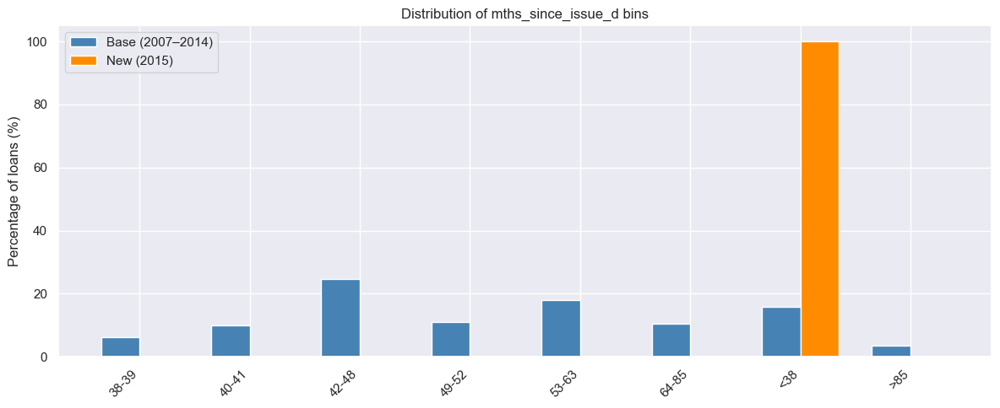

Largest shifts for mths_since_issue_d:

<38: Δ = 84.12 percentage points

42-48: Δ = 24.66 percentage points

53-63: Δ = 17.90 percentage points

In [450]:
def plot_binned_distribution(base_df, comp_df, base_name):
    """
    Plot side-by-side bars of proportions for all bins of a binned variable.
    base_name: the prefix before ':::' (e.g., 'mths_since_issue_d')
    Assumes columns are like 'mths_since_issue_d:::<38', 'mths_since_issue_d:::38-39', etc.
    """
    # Get all columns that start with base_name + ':::'
    pattern = f"{base_name}:::"
    base_cols = [c for c in base_df.columns if c.startswith(pattern)]
    comp_cols = [c for c in comp_df.columns if c.startswith(pattern)]
    common_cols = sorted(set(base_cols) & set(comp_cols))
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    
    # Extract bin labels (the part after ':::')
    bin_labels = [c.split(':::')[1] for c in common_cols]
    
    # Proportions (mean) for each bin
    prop_base = [base_df[col].mean() * 100 for col in common_cols]
    prop_comp = [comp_df[col].mean() * 100 for col in common_cols]
    
    x = np.arange(len(bin_labels))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(x - width/2, prop_base, width, label='Base (2007–2014)', color='steelblue')
    ax.bar(x + width/2, prop_comp, width, label='New (2015)', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels, rotation=45, ha='right')
    ax.set_ylabel('Percentage of loans (%)')
    ax.set_title(f'Distribution of {base_name} bins')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Print summary: which bin has largest absolute drift
    drifts = [(bin_labels[i], abs(prop_comp[i] - prop_base[i])) for i in range(len(bin_labels))]
    drifts.sort(key=lambda x: x[1], reverse=True)
    print(f"\nLargest shifts for {base_name}:")
    for label, drift in drifts[:3]:
        print(f"  {label}: Δ = {drift:.2f} percentage points")
        
'''Labels the bins (e.g., <38, 38-39) rotated for readability.: Why use this?
It shows exactly which bins of the variable have changed. In the example, <38 dropped from 66.7% to 50%, while 38-39 increased from 33.3% to 50%. 
This explains the drift.'''

# Example usage
plot_binned_distribution(inputs_base, df_2015_preprocessed, 'mths_since_issue_d')

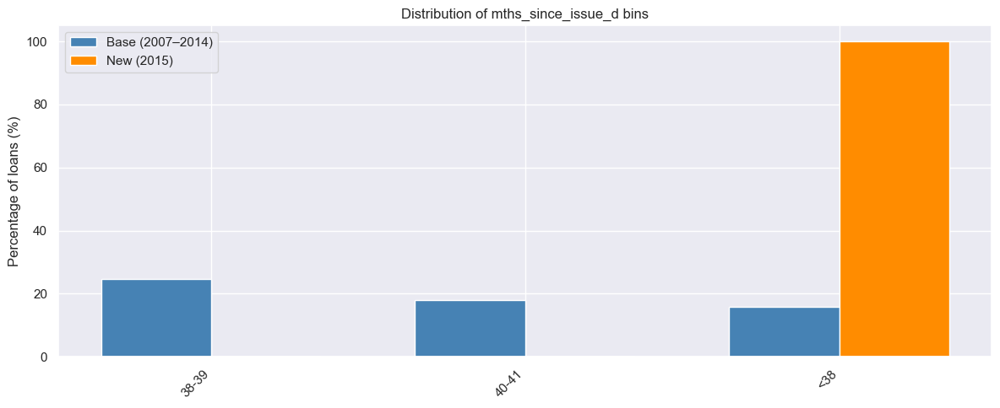

Largest shifts for mths_since_issue_d:

<38: Δ = 84.10 percentage points

38-39: Δ = 24.70 percentage points

40-41: Δ = 17.90 percentage points

In [451]:
# Fake data for mths_since_issue_d bins
fake_base = pd.DataFrame({
    'mths_since_issue_d:::<38': [1]*159 + [0]*841,   # 15.9%
    'mths_since_issue_d:::38-39': [1]*247 + [0]*753, # 24.7%
    'mths_since_issue_d:::40-41': [1]*179 + [0]*821, # 17.9%
})
fake_new = pd.DataFrame({
    'mths_since_issue_d:::<38': [1]*1000,  # 100%!
    'mths_since_issue_d:::38-39': [0]*1000,
    'mths_since_issue_d:::40-41': [0]*1000,
})

plot_binned_distribution(fake_base, fake_new, 'mths_since_issue_d')

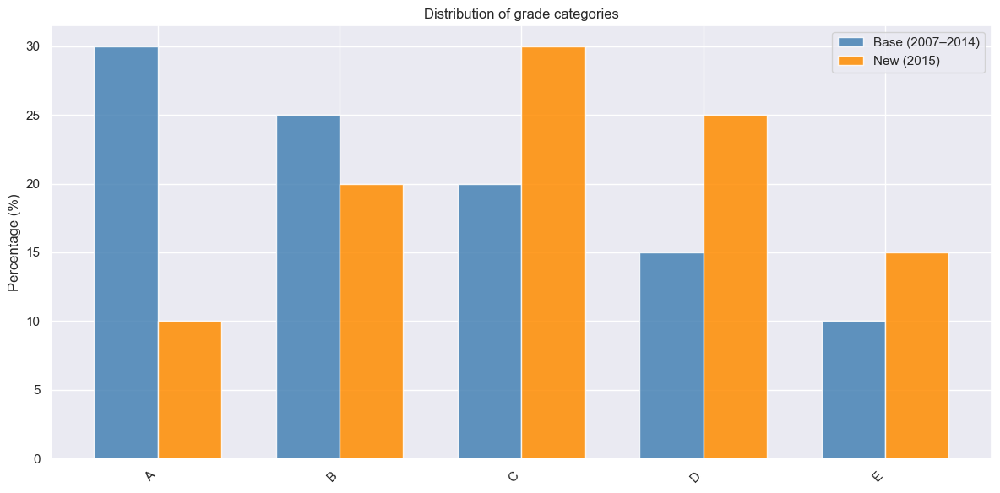

In [452]:
# Fake grade data
fake_base = pd.DataFrame({
    'grade:::A': [1]*300 + [0]*700,  # 30%
    'grade:::B': [1]*250 + [0]*750,  # 25%
    'grade:::C': [1]*200 + [0]*800,  # 20%
    'grade:::D': [1]*150 + [0]*850,  # 15%
    'grade:::E': [1]*100 + [0]*900,  # 10%
})
fake_new = pd.DataFrame({
    'grade:::A': [1]*100 + [0]*900,   # 10% (drift!)
    'grade:::B': [1]*200 + [0]*800,   # 20%
    'grade:::C': [1]*300 + [0]*700,   # 30% (drift!)
    'grade:::D': [1]*250 + [0]*750,   # 25%
    'grade:::E': [1]*150 + [0]*850,   # 15%
})

plot_all_bins_of_feature(fake_base, fake_new, 'grade')

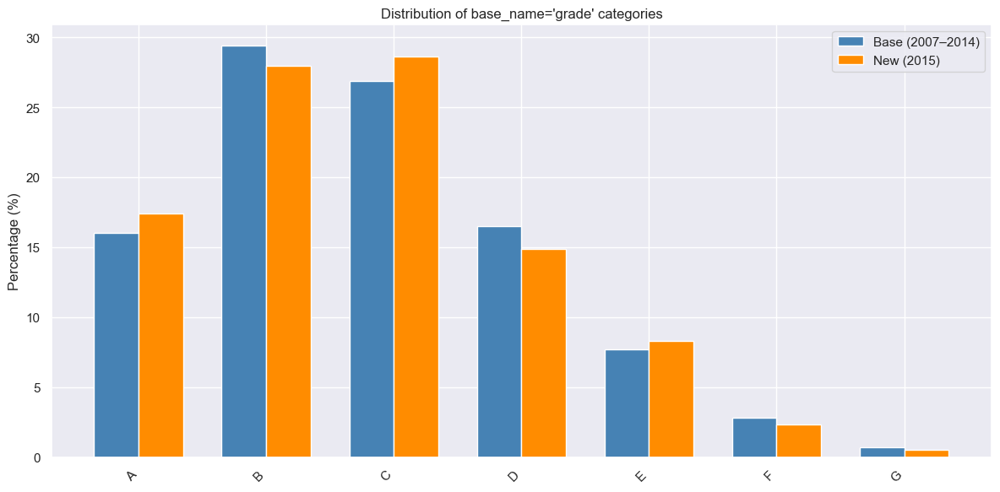

In [453]:
# 3. For grouped features (all bins of a categorical variable like grade)

'''✅ Layer 1 — Pure function (NO widgets)'''

import ipywidgets as widgets


def plot_all_bins_of_feature(base_df, comp_df, base_name, n_top=10, width = 0.35):
    """
    For a variable that has multiple dummies (e.g., grade:::A, grade:::B...),
    plot side‑by‑side proportions for base vs new.
    base_name: the prefix before ':::' (e.g., 'grade')

    This is similar to plot_binned_distribution but for variables where the dummy columns represent categories (e.g., grade:::A, grade:::B, …). 
    The only difference is that the bin labels are the category names ("A", "B", …).


    """
    # Get all columns that start with base_name:::
    pattern = f"{base_name}:::"
    base_cols = [c for c in base_df.columns if c.startswith(pattern)]
    comp_cols = [c for c in comp_df.columns if c.startswith(pattern)]
    # Use intersection of columns present in both
    common_cols = sorted(set(base_cols) & set(comp_cols))
    
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    
    prop_base = [base_df[col].mean() * 100 for col in common_cols]
    prop_new  = [comp_df[col].mean() * 100 for col in common_cols]
    
    x = np.arange(len(common_cols))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, prop_base, width, label='Base (2007–2014)', color='steelblue')
    ax.bar(x + width/2, prop_new, width, label='New (2015)', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels([col.split(':::')[1] for col in common_cols], rotation=45, ha='right')
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Distribution of {base_name=} categories')
    ax.legend()
    plt.tight_layout()
    plt.show()

# Example for grade
plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'grade')

In [454]:
# 🛠️ THE EXACT FIX + WHY YOURS BROKE

'''Here is the production-ready, corrected version. I kept your exact logic, added the missing cache-clearing step, 
and fixed the decorator so only width becomes a slider.


🔍 WHY YOUR CODE THREW ValueError: cannot find widget or abbreviation for argument: 'base_df'
@widgets.interact works like this:
It looks at every parameter in your function signature: base_df, comp_df, base_name, n_top, width.
For each parameter, it tries to automatically create a UI control (slider, dropdown, text box).
You only told it how to handle width via width=(0.10, 0.50, 0.01).
It saw base_df and panicked: "I don't know how to make a slider for a DataFrame. Throw error."

🛠️ HOW widgets.fixed() SOLVES IT
widgets.fixed(value) is ipywidgets' official way to say:
"Pass this exact value to the function every single time. Do NOT build a UI element for it. Do NOT try to guess what it is."
By wrapping your DataFrames and string in fixed(), the decorator now knows exactly what to do:
width=(...) → Build a slider 🎚️
base_df=widgets.fixed(...) → Pass silently, zero UI 📦
base_name=widgets.fixed('grade') → Pass silently, zero UI 📦
⚠️ CRITICAL ADDITION: plt.close('all')
You must put plt.close('all') at the top of any function decorated with @interact.
Why? Matplotlib stores every plot in memory. Every time you drag the slider, a new plot is created. Without clearing the cache, 
your notebook will leak RAM and crash after ~15 drags. This is non-negotiable in production.'''


import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np

@widgets.interact(
    # 🔹 Only 'width' gets a slider
    width=(0.10, 0.50, 0.01),
    
    # 🔹 These are passed silently to the function. NO UI elements created.
    base_df=widgets.fixed(inputs_base),
    comp_df=widgets.fixed(df_2015_preprocessed),
    base_name=widgets.fixed('grade'),
    n_top=widgets.fixed(10)
)
def plot_all_bins_of_feature(base_df, comp_df, base_name, n_top=10, width=0.35):
    """
    Plot side‑by‑side proportions for all dummies of a grouped variable.
    Only 'width' is interactive. Everything else is fixed.
    """
    # ⚠️ RUTHLESS RULE: Clear old plots or notebook RAM will crash after 10 drags
    plt.close('all')
    
    pattern = f"{base_name}:::"
    base_cols = [c for c in base_df.columns if c.startswith(pattern)]
    comp_cols = [c for c in comp_df.columns if c.startswith(pattern)]
    common_cols = sorted(set(base_cols) & set(comp_cols))
    
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    
    prop_base = [base_df[col].mean() * 100 for col in common_cols]
    prop_new  = [comp_df[col].mean() * 100 for col in common_cols]
    
    x = np.arange(len(common_cols))
    
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, prop_base, width, label='Base (2007–2014)', color='steelblue')
    ax.bar(x + width/2, prop_new,  width, label='New (2015)',      color='darkorange')
    
    ax.set_xticks(x)
    ax.set_xticklabels([col.split(':::')[1] for col in common_cols], rotation=45, ha='right')
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Distribution of {base_name} categories | Bar Width = {width:.2f}')
    ax.legend()
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=0.35, description='width', max=0.5, min=0.1, step=0.01), Output()), _d…

In [455]:
# 🚀 PRO UPGRADE: Make base_name a Dropdown (Highly Recommended)
'''Hardcoding 'grade' defeats the purpose of interactivity. Swap widgets.fixed('grade') for a dropdown so you can explore any variable 
without rewriting code:
Now you get:
🎚️ A slider for width
📂 A dropdown to switch between grade, emp_length, mths_since_issue_d, etc.
📦 DataFrames passed silently in the background
🧹 Zero memory leaks'''


# Auto-extract all variable prefixes from your PSI results
variable_prefixes = sorted(df_psi.dropna(subset=['PSI'])['Feature'].str.split(':::').str[0].unique().tolist())

@widgets.interact(
    width=(0.10, 0.50, 0.01),
    base_name=widgets.Dropdown(options=variable_prefixes, value='grade', description='Variable'),
    base_df=widgets.fixed(inputs_base),
    comp_df=widgets.fixed(df_2015_preprocessed),
    n_top=widgets.fixed(10)
)


# 3. For grouped features (all bins of a categorical variable like grade)

# '''✅ Layer 1 — Pure function (NO widgets)'''



def plot_all_bins_of_feature(base_df, comp_df, base_name, n_top=10, width = 0.35):
    """
    For a variable that has multiple dummies (e.g., grade:::A, grade:::B...),
    plot side‑by‑side proportions for base vs new.
    base_name: the prefix before ':::' (e.g., 'grade')

    This is similar to plot_binned_distribution but for variables where the dummy columns represent categories (e.g., grade:::A, grade:::B, …). 
    The only difference is that the bin labels are the category names ("A", "B", …).


    """
    # Get all columns that start with base_name:::
    pattern = f"{base_name}:::"
    base_cols = [c for c in base_df.columns if c.startswith(pattern)]
    comp_cols = [c for c in comp_df.columns if c.startswith(pattern)]
    # Use intersection of columns present in both
    common_cols = sorted(set(base_cols) & set(comp_cols))
    
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    
    prop_base = [base_df[col].mean() * 100 for col in common_cols]
    prop_new  = [comp_df[col].mean() * 100 for col in common_cols]
    
    x = np.arange(len(common_cols))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, prop_base, width, label='Base (2007–2014)', color='steelblue')
    ax.bar(x + width/2, prop_new, width, label='New (2015)', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels([col.split(':::')[1] for col in common_cols], rotation=45, ha='right')
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Distribution of {base_name=} categories')
    ax.legend()
    plt.tight_layout()
    plt.show()

# Example for grade
#plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'grade')

interactive(children=(Dropdown(description='Variable', index=5, options=('addr_state', 'annual_inc', 'dti', 'e…

In [456]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

def plot_all_bins_of_feature(base_df, comp_df, base_name, width=0.35, alpha=0.85, rotation=45):
    pattern = f"{base_name}:::"
    base_cols = [c for c in base_df.columns if c.startswith(pattern)]
    comp_cols = [c for c in comp_df.columns if c.startswith(pattern)]
    common_cols = sorted(set(base_cols) & set(comp_cols))
    if not common_cols:
        print(f"No columns found for {base_name}")
        return
    prop_base = [base_df[col].mean() * 100 for col in common_cols]
    prop_new  = [comp_df[col].mean() * 100 for col in common_cols]
    x = np.arange(len(common_cols))
    fig, ax = plt.subplots(figsize=(12,6))
    ax.bar(x - width/2, prop_base, width, alpha=alpha, label='Base', color='steelblue')
    ax.bar(x + width/2, prop_new, width, alpha=alpha, label='2015', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels([col.split(':::')[1] for col in common_cols], rotation=rotation, ha='right')
    ax.set_ylabel('Percentage (%)')
    ax.set_title(f'Distribution of {base_name} categories')
    ax.legend()
    plt.tight_layout()
    plt.show()

# Use interact with fixed data arguments
interact(lambda w, a, r: plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'grade', w, a, r),
         w=widgets.FloatSlider(value=0.35, min=0.1, max=0.5, step=0.01, description='Width'),
         a=widgets.FloatSlider(value=0.85, min=0.3, max=1.0, step=0.05, description='Alpha'),
         r=widgets.IntSlider(value=45, min=0, max=90, step=5, description='Rotation'))


interact(lambda w, a, r: plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, 'grade', w, a, r),
         w=(0.10,0.50,0.01),
         a=(0.3,1.0,0.05),
         r=(0,90,5))

interactive(children=(FloatSlider(value=0.35, description='Width', max=0.5, min=0.1, step=0.01), FloatSlider(v…

interactive(children=(FloatSlider(value=0.30000000000000004, description='w', max=0.5, min=0.1, step=0.01), Fl…

<function __main__.<lambda>(w, a, r)>

In [457]:
@widgets.interact(
    base_name=widgets.Dropdown(
        options=sorted(set([c.split(':::')[0] for c in inputs_base.columns if ':::' in c]))
    ),
    width=(0.10, 0.50, 0.01)
)
def interactive_plot(base_name, width):
    plot_all_bins_of_feature(inputs_base, df_2015_preprocessed, base_name, width=width)

interactive(children=(Dropdown(description='base_name', options=('addr_state', 'annual_inc', 'dti', 'emp_lengt…

In [458]:
'''🧠 CORE IDEA (VERY IMPORTANT)

A widget is just:

👉 A function
👉 + inputs (sliders)
👉 + automatic re-run when inputs change

👉 You get a slider
👉 Moving it reruns f(x)'''

from ipywidgets import interact

def f(x):
    print(x)

interact(f, x=(0, 10,))

interactive(children=(IntSlider(value=5, description='x', max=10), Output()), _dom_classes=('widget-interact',…

<function __main__.f(x)>

In [459]:
'''
🎯 1. INTERACTIVE HISTOGRAM (ALPHA + SHIFT)
💡 Intuition

You want to simulate:

What happens if 2015 shifts?
What happens if overlap becomes hard to see
⚠️ Reality Check

If your PSI doesn’t change much even after shift:

👉 Your model is insensitive
👉 That’s a red flag?


🧠 What is happening internally?
When you move slider:
User drags slider → new value
→ function reruns
→ histogram redraws'''




from ipywidgets import interact


def interactive_hist(alpha=0.5, shift=0):
    fig, ax = plt.subplots(figsize=(8,5))
    
    # Shift the comparison scores
    shifted_comp = scores_comp + shift
    
    ax.hist(scores_base, bins=55, range=(300, 850),
            alpha=alpha, density=True, label='Base')
    
    ax.hist(shifted_comp, bins=55, range=(300, 850),
            alpha=alpha, density=True, label='2015 (shifted)')
    
    ax.legend()
    ax.set_title(f"Alpha={alpha}, Shift={shift}")
    
    plt.show()

interact(interactive_hist,
         alpha=(0.1, 1.0, 0.05),
         shift=(-100, 100, 5))

interactive(children=(FloatSlider(value=0.5, description='alpha', max=1.0, min=0.1, step=0.05), IntSlider(valu…

<function __main__.interactive_hist(alpha=0.5, shift=0)>

In [460]:
'''🎯 2. BAR WIDTH DEMO (GROUPED BAR LOGIC)

This directly explains your:

x ± w/2

🧠 What you SEE
Width	Effect
0.1	thin bars, big gap
0.3	balanced
0.5	bars touching
>0.5	overlap chaos
⚠️ Brutal truth

If your bars overlap:

👉 your visualization is lying
👉 comparison becomes meaningless'''

from ipywidgets import interact
import numpy as np
import matplotlib.pyplot as plt

def bar_width_demo(w=0.3):
    labels = ['A','B','C','D']
    base = [40, 30, 20, 10]
    comp = [35, 25, 25, 15]
    
    x = np.arange(len(labels))
    
    fig, ax = plt.subplots(figsize=(8,5))
    
    ax.bar(x - w/2, base, width=w, label='Base')
    ax.bar(x + w/2, comp, width=w, label='2015')
    
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    
    ax.set_title(f"Bar width = {w}")
    ax.legend()
    
    plt.show()

interact(bar_width_demo, w=(0.1, 0.6, 0.05))

interactive(children=(FloatSlider(value=0.3, description='w', max=0.6, min=0.1, step=0.05), Output()), _dom_cl…

<function __main__.bar_width_demo(w=0.3)>

In [461]:
'''
🎯 3. COLOR LOGIC (PSI → COLOR MAPPING)

You already wrote this:

lambda x: '#e74c3c' if x >= 0.25 else ...

Now make it interactive.

🧠 What this teaches you

This line in your code:

colors = df_plot['PSI'].apply(lambda x: ...)

👉 is just doing this logic row-by-row'''




def psi_color_demo(psi=0.05):
    if psi >= 0.25:
        color = '#e74c3c'
        label = "Major shift"
    elif psi >= 0.10:
        color = '#f39c12'
        label = "Minor shift"
    else:
        color = '#2ecc71'
        label = "Stable"
    
    print(f"PSI: {psi:.3f}")
    print(f"Decision: {label}")
    print(f"Color: {color}")

interact(psi_color_demo, psi=(0.0, 0.5, 0.01))

interactive(children=(FloatSlider(value=0.05, description='psi', max=0.5, step=0.01), Output()), _dom_classes=…

<function __main__.psi_color_demo(psi=0.05)>

In [462]:
'''🎯 4. FULL PSI INTERACTIVE SIMULATOR (THIS IS GOD LEVEL)

Now we combine everything.


🧠 WHAT YOU JUST BUILT

This is not just a widget.

This is:

🔥 A MODEL VALIDATION LAB

You can now:

Force PSI to break
See how score shift affects stability
Understand bin sensitivity
Test robustness
⚠️ CRITICAL INSIGHT (DON’T MISS THIS)

If small shifts cause large PSI:

👉 your model is fragile
👉 your bins are too tight
👉 your score scaling is unstable

🧠 HOW ALL THIS CONNECTS TO YOUR ORIGINAL CODE

Your static code:

hist → fixed
bar → fixed
colors → fixed

Now:

hist(alpha, shift)
bar(width)
colors(psi threshold)
psi(bins)

👉 Everything becomes a parameter'''


def psi_simulator(shift=0, alpha=0.5, bins=10):
    
    shifted_comp = scores_comp + shift
    
    # Create bins
    bins_edges = np.linspace(300, 850, bins+1)
    
    base_counts, _ = np.histogram(scores_base, bins=bins_edges)
    comp_counts, _ = np.histogram(shifted_comp, bins=bins_edges)
    
    base_pct = base_counts / base_counts.sum()
    comp_pct = comp_counts / comp_counts.sum()
    
    epsilon = 1e-6
    psi = np.sum((comp_pct - base_pct) * np.log((comp_pct + epsilon) / (base_pct + epsilon)))
    
    fig, ax = plt.subplots(figsize=(8,5))
    
    ax.hist(scores_base, bins=55, alpha=alpha, density=True, label='Base')
    ax.hist(shifted_comp, bins=55, alpha=alpha, density=True, label='Shifted')
    
    ax.set_title(f"PSI = {psi:.4f}")
    ax.legend()
    
    plt.show()

interact(psi_simulator,
         shift=(-100, 100, 5),
         alpha=(0.1, 1.0, 0.05),
         bins=(5, 20, 1))

interactive(children=(IntSlider(value=0, description='shift', min=-100, step=5), FloatSlider(value=0.5, descri…

<function __main__.psi_simulator(shift=0, alpha=0.5, bins=10)>

In [463]:

# @widgets.interact turns function arguments into sliders
# Tuple format: (min_value, max_value, step_size)
@widgets.interact(w=(0.10, 0.50, 0.01))
def demo_bar_width(w=0.38):
    plt.close('all')  # Clear old plot to prevent overlapping
    fig, ax = plt.subplots(figsize=(8, 5))
    
    x = np.arange(5)  # Positions for 5 bins
    base_heights = [10, 25, 20, 15, 30]
    new_heights  = [12, 22, 25, 18, 28]
    
    # Side-by-side bars: shift by HALF the width
    ax.bar(x - w/2, base_heights, width=w, color='steelblue', label='Base')
    ax.bar(x + w/2, new_heights,  width=w, color='darkorange', label='New')
    
    ax.set_xticks(x)
    ax.set_xticklabels(['Bin 1', 'Bin 2', 'Bin 3', 'Bin 4', 'Bin 5'])
    ax.set_ylabel('Count')
    ax.set_title(f'Grouped Bar Mechanics | Width (w) = {w:.2f}')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


'''
🎮 STEP 1: BAR WIDTH MECHANICS SLIDER
Drag w from 0.1 to 0.5. Watch gaps close and bars merge.  🧒 What's happening:
When w=0.50, x - w/2 and x + w/2 are exactly 0.25 units apart. Since each bar is 0.50 wide, they touch perfectly. That's x ± w/2 in action.'''

interactive(children=(FloatSlider(value=0.38, description='w', max=0.5, min=0.1, step=0.01), Output()), _dom_c…

"\n🎮 STEP 1: BAR WIDTH MECHANICS SLIDER\nDrag w from 0.1 to 0.5. Watch gaps close and bars merge.  🧒 What's happening:\nWhen w=0.50, x - w/2 and x + w/2 are exactly 0.25 units apart. Since each bar is 0.50 wide, they touch perfectly. That's x ± w/2 in action."

In [464]:
'''📊 STEP 2: HISTOGRAM ALPHA & SHIFT SLIDER
Drag shift to simulate PSI drift. Drag alpha to see why transparency matters.'''


@widgets.interact(
    alpha=(0.1, 1.0, 0.05),
    shift=(-100, 100, 5)
)
def demo_histogram(alpha=0.55, shift=0):
    plt.close('all')
    fig, ax = plt.subplots(figsize=(9, 5))
    
    np.random.seed(42)  # Fixed seed so shift is obvious
    base_scores = np.random.normal(650, 50, 2000).clip(300, 850)
    new_scores  = np.random.normal(650 + shift, 50, 2000).clip(300, 850)
    
    ax.hist(base_scores, bins=30, range=(300, 850), 
            alpha=alpha, density=True, color='steelblue', label='Base (2007–2014)')
    ax.hist(new_scores,  bins=30, range=(300, 850), 
            alpha=alpha, density=True, color='darkorange', label='New (2015)')
    
    ax.set_xlabel('Score')
    ax.set_ylabel('Density')
    ax.set_title(f'Overlap Demo | Alpha={alpha:.2f} | Shift={shift:+} pts')
    ax.legend()
    ax.axvline(650, color='gray', linestyle='--', linewidth=1)
    plt.tight_layout()
    plt.show()
    '''🧒 What's happening:
alpha=0.1 → Nearly transparent. You see overlap, but bars look washed out.
alpha=1.0 → Solid. Front histogram completely hides the back one. ❌ Useless for comparison.
shift=+50 → Orange curve slides right. Visual proof of "Population Drift". That's what PSI measures.'''

interactive(children=(FloatSlider(value=0.55, description='alpha', max=1.0, min=0.1, step=0.05), IntSlider(val…

In [465]:
'''🎨 STEP 3: PSI COLOR MAPPING SLIDER
Drag to see how your lambda x: ... color rule works in real-time.'''


@widgets.interact(psi_value=(0.00, 0.50, 0.01))
def demo_psi_color(psi_value=0.12):
    plt.close('all')
    fig, ax = plt.subplots(figsize=(6, 4))
    
    # Your exact color logic
    if psi_value >= 0.25:
        color = '#e74c3c'  # 🚨 Major
        label = 'Major shift'
    elif psi_value >= 0.10:
        color = '#f39c12'  # ⚠️ Minor
        label = 'Minor shift'
    else:
        color = '#2ecc71'  # ✅ Stable
        label = 'Stable'
        
    ax.barh(['Feature'], [psi_value], color=color, height=0.4, edgecolor='white')
    ax.set_xlim(0, 0.5)
    ax.axvline(0.10, color='#f39c12', linestyle='--')
    ax.axvline(0.25, color='#e74c3c', linestyle='--')
    ax.set_xlabel('PSI Value')
    ax.set_title(f'PSI = {psi_value:.2f} → {label} (Color: {color})')
    plt.tight_layout()
    plt.show()

    '''🧒 What's happening:
This is exactly what df_plot['PSI'].apply(lambda x: '#e74c3c' if x >= 0.25 ...) does, but live. Slide past 0.10 and watch it snap to orange. Slide past 0.25 → red. Instant.
🧠 HOW @INTERACT WORKS (EXPLAIN LIKE I'M 11)
You write a normal plotting function: def my_plot(w=0.38): ...
You add @widgets.interact(w=(min, max, step)) on top.
Python reads the tuple (0.10, 0.50, 0.01) and automatically builds a slider.
Every time you drag the slider, Python calls my_plot(new_value) → clears the old plot → draws a new one.
No loops. No event listeners. Just magic. ✅'''

interactive(children=(FloatSlider(value=0.12, description='psi_value', max=0.5, step=0.01), Output()), _dom_cl…

In [466]:
'''🚀 RUTHLESS TIPS FOR NOTEBOOK WIDGETS
Problem
Solution
Plots stack on top of each other
Always put plt.close('all') or plt.clf() at the top of your function
Sliders disappear after restart
Run !pip install ipywidgets + restart kernel
Want multiple sliders in one widget
Pass multiple tuples: @widgets.interact(w=(...), alpha=(...))
Want to freeze a value
Click the 🔒 padlock icon next to the slider
Want to export the plot
Right-click the output → "Save Image As..."
🛠️ YOUR HOMEWORK (DO THIS NOW)
Paste Demo 1 into a new cell. Run it. Drag w to 0.50. Watch bars touch.
Paste Demo 2. Set shift=+80, alpha=0.55. See how overlap still shows the gap.
Paste Demo 3. Slide to 0.24 → orange. Slide to 0.26 → red. Feel the threshold.
Combine them: Create one widget that plots your actual PSI results with a width slider:'''


@widgets.interact(width=(0.1, 0.6, 0.01))
def plot_your_psi(width=0.35):
    plt.close('all')
    fig, ax = plt.subplots(figsize=(10, 6))
    # Replace with your real data
    y = ['A', 'B', 'C'][::-1]
    vals = [0.05, 0.15, 0.30][::-1]
    colors = ['#2ecc71', '#f39c12', '#e74c3c'][::-1]
    ax.barh(y, vals, height=width, color=colors, edgecolor='white')
    ax.set_xlim(0, 0.35)
    ax.axvline(0.10, linestyle='--')
    ax.axvline(0.25, linestyle='--')
    ax.set_title(f'Your PSI Plot | Width = {width}')
    plt.tight_layout()
    plt.show()

    '''Ruthless Mentor Final Word: Static code teaches you what to type. Interactive sliders teach you why it works. Drag them until your fingers memorize the mechanics. 
    Then close the notebook and write it from memory. That's how you become ironclad. 🔥'''

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), Output()), _d…

In [467]:
'''1. 🚀 The Shortcut: From df_psi to an Interactive Slider
The fastest way to make a slider is with the interact function. Here’s how you can animate the shift parameter you were asking about. 
The following code creates a slider that controls a shift_val parameter, updates a simple dataset, and redraws a histogram dynamically.

The shift parameter – where does it come from?
shift is artificial – added only for interactive exploration.
Real PSI measures actual drift; shift lets you simulate what happens if the 2015 distribution moves left or right.
In your production code, you will not add shift to real data. It’s a teaching slider.

Defining widgets outside the function
Yes, and it’s often cleaner. Create widgets explicitly (widgets.FloatSlider(...), widgets.Dropdown(...)) then pass 
them to interact. This gives you full control over layout, styling, and dynamic updates.'''



# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact

# Generate some data (replace with your PSI data, e.g., scores_comp)
fixed_data = np.random.normal(600, 50, 1000)  # Example data

# Define a plotting function that uses the shift value
def plot_with_shift(shift_val=0):
    """
    Shifts the 2015 data and plots the updated histogram.
    'shift_val' will be controlled by the slider.
    """
    plt.figure()
    shifted_data = fixed_data + shift_val
    plt.hist(fixed_data, bins=30, alpha=0.6, label='Base (2007–2014)', color='steelblue', density=True)
    plt.hist(shifted_data, bins=30, alpha=0.6, label=f'New (2015) shifted by {shift_val}', color='darkorange', density=True)
    plt.xlabel('Score')
    plt.ylabel('Density')
    plt.title('Interactive Score Distribution Shift')
    plt.legend()
    plt.show()

# Create the interactive slider
interact(plot_with_shift, shift_val=(-150, 150, 5));





interactive(children=(IntSlider(value=0, description='shift_val', max=150, min=-150, step=5), Output()), _dom_…

In [468]:
def update_plot(bar_width, alpha, shift_val):

    plt.close('all')

    shifted_data = scores_comp + shift_val

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.hist(
        scores_base,
        bins=55,
        range=(300, 850),
        alpha=alpha,
        density=True,
        label='Base'
    )

    ax.hist(
        shifted_data,
        bins=55,
        range=(300, 850),
        alpha=alpha,
        density=True,
        label='2015'
    )

    ax.set_xlabel('Score')
    ax.set_ylabel('Density')
    ax.legend()

    plt.show()

In [469]:

width_slider = widgets.FloatSlider(
    value=0.35,
    min=0.10,
    max=0.60,
    step=0.01,
    description='Bar Width'
)

alpha_slider = widgets.FloatSlider(
    value=0.60,
    min=0.10,
    max=1.00,
    step=0.05,
    description='Alpha'
)

shift_slider = widgets.IntSlider(
    value=0,
    min=-100,
    max=100,
    step=5,
    description='Data Shift'
)

In [470]:
ui = widgets.interactive(
    update_plot,
    bar_width=width_slider,
    alpha=alpha_slider,
    shift_val=shift_slider
)



In [471]:
display(ui)

interactive(children=(FloatSlider(value=0.35, description='Bar Width', max=0.6, min=0.1, step=0.01), FloatSlid…

In [472]:
interact(
    plot_all_bins_of_feature,

    base_df=widgets.fixed(inputs_base),

    comp_df=widgets.fixed(df_2015_preprocessed),

    base_name=widgets.fixed('grade'),

    width=(0.10, 0.60, 0.01)
)



'''
base_df
   ↓
DO NOT make a widget
   ↓
always use inputs_base
'''

interactive(children=(FloatSlider(value=0.35, description='width', max=0.6, min=0.1, step=0.01), FloatSlider(v…

'\nbase_df\n   ↓\nDO NOT make a widget\n   ↓\nalways use inputs_base\n'

In [473]:
# =============================================================================
# INTERACTIVE PSI WIDGET EXPLORER
# Paste this entire block into ONE notebook cell and run it.
# Run AFTER your PSI analysis cells so these variables exist in memory:
#   df_psi, df_score_psi, scores_base, scores_comp, inputs_train, df_2015_preprocessed
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import ipywidgets as widgets
from ipywidgets import interact, Output, VBox, HBox, Label
from IPython.display import display, clear_output

# ─────────────────────────────────────────────────────────────────────────────
# HOW ipywidgets WORKS — the full mental model in 4 lines:
#
#   1. You write a function that takes parameters and draws a plot.
#   2. You call interact(your_function, param=SomeWidget(...))
#   3. ipywidgets creates the slider/dropdown for each parameter automatically.
#   4. Every drag of the slider calls your function again with the new value.
#
# That's it. Everything below is just variations of this same pattern.
# ─────────────────────────────────────────────────────────────────────────────


# ─────────────────────────────────────────────────────────────────────────────
# WIDGET A — PSI Colour Rule  (replicates Plot A colour logic)
# Shows exactly what:
#   colors = df_plot['PSI'].apply(lambda x: '#e74c3c' if x >= 0.25 else ('#f39c12' if x >= 0.10 else '#2ecc71'))
# does to any PSI value.
# ─────────────────────────────────────────────────────────────────────────────

def widget_A_psi_color(psi_value):
    """
    psi_value : float — supplied automatically by the FloatSlider below.

    The function body is a normal matplotlib plot.
    interact() calls it every time the slider moves.
    """
    # This is the exact lambda from your Plot A code, now visible as if-else
    if psi_value >= 0.25:
        color   = '#e74c3c'
        label   = '🚨 Major shift  (PSI ≥ 0.25) — investigate / rebuild'
    elif psi_value >= 0.10:
        color   = '#f39c12'
        label   = '⚠️  Minor shift  (0.10 ≤ PSI < 0.25) — monitor closely'
    else:
        color   = '#2ecc71'
        label   = '✅ Stable        (PSI < 0.10) — no action needed'

    fig, ax = plt.subplots(figsize=(9, 1.4))
    ax.barh(['Your feature'], [psi_value], color=color, edgecolor='white', height=0.55)

    # These are the exact axvline calls from your Plot A
    ax.axvline(0.10, color='#f39c12', linestyle='--', linewidth=1.5, label='Minor threshold (0.10)')
    ax.axvline(0.25, color='#e74c3c', linestyle='--', linewidth=1.5, label='Major threshold (0.25)')

    ax.set_xlim(0, 0.65)          # set_xlim(left=0) — same as your code
    ax.set_xlabel('PSI', fontsize=11)
    ax.set_title(label, fontsize=11, pad=8)
    ax.legend(fontsize=9, loc='upper right')
    plt.tight_layout()
    plt.show()

print("=" * 60)
print("WIDGET A — PSI colour rule (mirrors Plot A colour logic)")
print("=" * 60)

interact(
    widget_A_psi_color,
    psi_value=widgets.FloatSlider(
        value       = 0.12,       # starting position
        min         = 0.0,        # left end
        max         = 0.60,       # right end
        step        = 0.01,       # how much each tick moves
        description = 'PSI value',
        # style and layout are cosmetic only — stop the label being cut off
        style       = {'description_width': '80px'},
        layout      = widgets.Layout(width='500px')
    )
)


# ─────────────────────────────────────────────────────────────────────────────
# WIDGET B — Score Histogram  (replicates Plot B)
# Uses scores_base and scores_comp from your compute_overall_psi() call.
# Controls: alpha (transparency) and score_shift (simulates population drift).
# ─────────────────────────────────────────────────────────────────────────────

def widget_B_histogram(alpha, score_shift):
    """
    alpha        : float  — transparency of each histogram bar.
                            0 = invisible, 1 = fully opaque.
                            Your code used 0.55 so both histograms show through each other.

    score_shift  : int    — adds a constant to 2015 scores to simulate what
                            a drifted population looks like. In real data
                            this drift is what PSI measures.

    density=True is the CRITICAL parameter here:
        Without it: y-axis = raw count. Your base (≈300k rows) bars are
                    10× taller than 2015 (≈30k rows) → shapes unreadable.
        With it:    y-axis = probability density → both normalised to
                    area = 1, shapes comparable regardless of sample size.
    """
    scores_comp_shifted = (scores_comp + score_shift).clip(300, 850)

    fig, ax = plt.subplots(figsize=(11, 4))

    ax.hist(
        scores_base,
        bins    = 55,            # 550-point range ÷ 55 bins = 10 pts per bin
        range   = (300, 850),    # fixes window so both histograms use identical bins
        alpha   = alpha,         # ← your slider controls this
        color   = 'steelblue',
        density = True,          # ← normalises for different sample sizes
        label   = f'Base 2007–2014  (n={len(scores_base):,})'
    )

    ax.hist(
        scores_comp_shifted,
        bins    = 55,
        range   = (300, 850),
        alpha   = alpha,         # same alpha so both are equally visible
        color   = 'darkorange',
        density = True,
        label   = f'2015  (n={len(scores_comp):,})  shift={score_shift:+d} pts'
    )

    ax.set_xlabel('Scorecard Score (300–850)', fontsize=11)
    ax.set_ylabel('Density  (density=True normalises for n)', fontsize=10)
    ax.set_title(
        f'bins=55, range=(300,850), alpha={alpha:.2f}, score_shift={score_shift:+d}\n'
        'Blue/orange overlap zone = populations agree; gaps = drift',
        fontsize=10
    )
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

print("\n" + "=" * 60)
print("WIDGET B — Score histogram (mirrors Plot B)")
print("=" * 60)

interact(
    widget_B_histogram,
    alpha=widgets.FloatSlider(
        value       = 0.55,
        min         = 0.05,
        max         = 1.00,
        step        = 0.05,
        description = 'alpha',
        style       = {'description_width': '70px'},
        layout      = widgets.Layout(width='480px')
    ),
    score_shift=widgets.IntSlider(
        value       = 0,
        min         = -120,
        max         = 120,
        step        = 5,
        description = 'score shift',
        style       = {'description_width': '90px'},
        layout      = widgets.Layout(width='480px')
    )
)


# ─────────────────────────────────────────────────────────────────────────────
# WIDGET C — Grouped bar chart  (replicates Plot C)
# Uses df_score_psi from your compute_overall_psi() call.
# Controls: bar_width (w), label_rotation, and n_bins.
# ─────────────────────────────────────────────────────────────────────────────

def widget_C_grouped_bars(bar_width, label_rotation, n_bins):
    """
    bar_width      : float — the 'w' variable in your code.
                             Each group uses x-w/2 (base) and x+w/2 (comp).
                             At w=0.50 bars in a group touch exactly.
                             At w>0.50 they overlap.

    label_rotation : int   — the 'rotation' argument in set_xticklabels.
                             35° points labels toward their bar without
                             overlapping. 0° = horizontal, 90° = vertical.

    n_bins         : int   — recomputes score bands live.
                             More bins = finer view; fewer = coarser.
                             Your code used n_bins=10.

    The grouped-bar trick (the core idea):
        x = np.arange(n_bins)      →  integer positions [0, 1, ..., 9]
        ax.bar(x - w/2, Base_%)    →  base bar: shifted LEFT  by half a width
        ax.bar(x + w/2, Comp_%)    →  comp bar: shifted RIGHT by half a width
        Both bars share the same centre x; offset ±w/2 creates the pair.

    set_xticks(x) + set_xticklabels(labels):
        set_xticks says WHERE to place tick marks (at your integer positions).
        set_xticklabels says WHAT TEXT to show.
        Without set_xticks first, labels can misalign.

    FormatStrFormatter('%.1f%%'):
        %% = literal % sign  (first % is the escape character).
        %.1f = one decimal float.
        Together: 12.3 → "12.3%"
    """
    # Recompute bands using live n_bins value from slider
    bins_arr = np.linspace(300, 850, n_bins + 1)
    labels   = [f"{int(bins_arr[i])}–{int(bins_arr[i+1])}" for i in range(n_bins)]

    from pandas import cut as pd_cut
    base_binned  = pd_cut(scores_base, bins=bins_arr, labels=labels, include_lowest=True)
    comp_binned  = pd_cut(scores_comp, bins=bins_arr, labels=labels, include_lowest=True)

    base_pct = (base_binned.value_counts().reindex(labels, fill_value=0) / len(scores_base) * 100)
    comp_pct = (comp_binned.value_counts().reindex(labels, fill_value=0) / len(scores_comp) * 100)

    x = np.arange(n_bins)   # [0, 1, 2, ..., n_bins-1]
    w = bar_width

    fig, ax = plt.subplots(figsize=(13, 4.5))

    # Base bars shifted LEFT  by w/2
    ax.bar(x - w/2, base_pct, width=w, label='Base 2007–2014',
           color='steelblue', alpha=0.85)

    # Comp bars shifted RIGHT by w/2
    ax.bar(x + w/2, comp_pct, width=w, label='2015',
           color='darkorange', alpha=0.85)

    # Step 1: WHERE to put ticks
    ax.set_xticks(x)
    # Step 2: WHAT text to show at those positions
    ax.set_xticklabels(labels, rotation=label_rotation, ha='right', fontsize=9)

    ax.set_ylabel('% of Population', fontsize=11)

    # FormatStrFormatter('%.1f%%') — adds % symbol automatically
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))

    ax.set_title(
        f'Score bands (n_bins={n_bins})  |  w={w:.2f}  |  x−w/2 = base, x+w/2 = 2015\n'
        f'At w=0.50 bars touch. At w>{0.5:.2f} they overlap. Rotation={label_rotation}°',
        fontsize=10
    )
    ax.legend(fontsize=10)

    # ── Annotation: draw the x-w/2 / x+w/2 arrows on the first group ──────
    if n_bins >= 2:
        y_arrow = max(base_pct.iloc[0], comp_pct.iloc[0]) * 0.6
        ax.annotate(
            '', xy=(0 - w/2, y_arrow), xytext=(0, y_arrow),
            arrowprops=dict(arrowstyle='<->', color='steelblue', lw=1.5)
        )
        ax.text(0 - w/4, y_arrow + 0.3, f'w/2={w/2:.2f}',
                color='steelblue', fontsize=8, ha='center')

        ax.annotate(
            '', xy=(0, y_arrow), xytext=(0 + w/2, y_arrow),
            arrowprops=dict(arrowstyle='<->', color='darkorange', lw=1.5)
        )
        ax.text(0 + w/4, y_arrow + 0.3, f'w/2={w/2:.2f}',
                color='darkorange', fontsize=8, ha='center')

    plt.tight_layout()
    plt.show()

print("\n" + "=" * 60)
print("WIDGET C — Grouped bars (mirrors Plot C)")
print("=" * 60)

interact(
    widget_C_grouped_bars,
    bar_width=widgets.FloatSlider(
        value       = 0.38,
        min         = 0.05,
        max         = 0.80,
        step        = 0.01,
        description = 'bar width (w)',
        style       = {'description_width': '100px'},
        layout      = widgets.Layout(width='500px')
    ),
    label_rotation=widgets.IntSlider(
        value       = 35,
        min         = 0,
        max         = 90,
        step        = 5,
        description = 'label rotation',
        style       = {'description_width': '100px'},
        layout      = widgets.Layout(width='500px')
    ),
    n_bins=widgets.IntSlider(
        value       = 10,
        min         = 5,
        max         = 20,
        step        = 1,
        description = 'n_bins',
        style       = {'description_width': '100px'},
        layout      = widgets.Layout(width='500px')
    )
)


# ─────────────────────────────────────────────────────────────────────────────
# WIDGET D — Feature drill-down  (uses your real df_psi and df_2015_preprocessed)
# Pick any variable prefix (e.g. 'grade', 'emp_length', 'mths_since_issue_d')
# and see a side-by-side proportion bar chart for all its bins.
# This is exactly plot_all_bins_of_feature() / plot_binned_distribution() but interactive.
# ─────────────────────────────────────────────────────────────────────────────

# Build a dropdown list from your actual df_psi Feature column
# Extract unique variable prefixes (the part before ':::')
try:
    valid_psi = df_psi.dropna(subset=['PSI'])
    variable_list = sorted(
        valid_psi['Feature'].str.split(':::').str[0].unique().tolist()
    )
except Exception:
    variable_list = ['grade', 'emp_length', 'mths_since_issue_d']

out_D = Output()

def widget_D_feature_drill(variable_prefix):
    """
    variable_prefix : str — the part of a feature name before ':::'.
                            e.g. 'grade' covers grade:::A, grade:::B, etc.

    Finds all columns in inputs_train / df_2015_preprocessed that start
    with 'variable_prefix:::' and plots their proportions side-by-side.

    This is the interactive version of:
        plot_all_bins_of_feature(inputs_train, df_2015_preprocessed, 'grade')
    """
    pattern     = f"{variable_prefix}:::"
    base_cols   = [c for c in inputs_train.columns        if c.startswith(pattern)]
    comp_cols   = [c for c in df_2015_preprocessed.columns if c.startswith(pattern)]
    common_cols = sorted(set(base_cols) & set(comp_cols))

    if not common_cols:
        print(f"No columns found for prefix '{variable_prefix}'")
        return

    bin_labels = [c.split(':::')[1] for c in common_cols]
    prop_base  = [inputs_train[col].mean() * 100        for col in common_cols]
    prop_comp  = [df_2015_preprocessed[col].mean() * 100 for col in common_cols]
    drifts     = [abs(prop_comp[i] - prop_base[i])       for i in range(len(common_cols))]

    x     = np.arange(len(common_cols))
    width = 0.38    # this is the 'w' from Plot C — same pattern

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5),
                             gridspec_kw={'width_ratios': [3, 1]})

    # ── Left panel: grouped bar chart ──────────────────────────────────────
    ax = axes[0]
    ax.bar(x - width/2, prop_base, width, label='Base 2007–2014',
           color='steelblue', alpha=0.85)
    ax.bar(x + width/2, prop_comp, width, label='2015',
           color='darkorange', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels, rotation=40, ha='right', fontsize=9)
    ax.set_ylabel('% of loans in bin', fontsize=10)
    ax.set_title(f'Bin proportions: {variable_prefix}', fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f%%'))
    ax.legend(fontsize=9)

    # ── Right panel: drift bar (|comp - base|) for each bin ────────────────
    ax2 = axes[1]
    drift_colors = ['#e74c3c' if d > 5 else ('#f39c12' if d > 2 else '#2ecc71')
                    for d in drifts]
    ax2.barh(bin_labels[::-1], drifts[::-1], color=drift_colors[::-1], edgecolor='white')
    ax2.set_xlabel('|Drift| (pp)', fontsize=10)
    ax2.set_title('Abs. drift per bin', fontsize=11)
    ax2.axvline(2, color='#f39c12', linestyle='--', linewidth=1, label='>2pp')
    ax2.axvline(5, color='#e74c3c', linestyle='--', linewidth=1, label='>5pp')
    ax2.legend(fontsize=8)

    # Pull PSI for this variable from df_psi
    mask = df_psi['Feature'].str.startswith(pattern) & df_psi['PSI'].notna()
    if mask.any():
        max_psi = df_psi.loc[mask, 'PSI'].max()
        fig.suptitle(
            f'{variable_prefix}  |  Max feature PSI = {max_psi:.4f}',
            fontsize=12, fontweight='bold'
        )

    plt.tight_layout()
    plt.show()

    # Print summary table
    print(f"\n{'Bin':<30} {'Base %':>8} {'2015 %':>8} {'|Drift| pp':>10}")
    print('-' * 58)
    for i, lbl in enumerate(bin_labels):
        print(f"{lbl:<30} {prop_base[i]:>8.2f} {prop_comp[i]:>8.2f} {drifts[i]:>10.2f}")

print("\n" + "=" * 60)
print("WIDGET D — Feature drill-down (your real df_psi data)")
print("=" * 60)

interact(
    widget_D_feature_drill,
    variable_prefix=widgets.Dropdown(
        options     = variable_list,
        value       = variable_list[0],
        description = 'Variable',
        style       = {'description_width': '70px'},
        layout      = widgets.Layout(width='450px')
    )
)


# ─────────────────────────────────────────────────────────────────────────────
# WIDGET E — PSI waterfall (top N worst features)
# Lets you scroll through however many features you want to see,
# rather than being locked to "top 20".
# ─────────────────────────────────────────────────────────────────────────────

def widget_E_top_features(top_n, show_stable):
    """
    top_n       : int  — how many features to show (1–95).
    show_stable : bool — whether to include PSI < 0.10 features.

    Mirrors your Plot A but with interactive control over N.
    """
    df_plot = df_psi.dropna(subset=['PSI']).copy()
    if not show_stable:
        df_plot = df_plot[df_plot['PSI'] >= 0.10]

    df_plot = df_plot.head(top_n)

    if df_plot.empty:
        print("No features to display with current filters.")
        return

    colors = df_plot['PSI'].apply(
        lambda x: '#e74c3c' if x >= 0.25 else ('#f39c12' if x >= 0.10 else '#2ecc71')
    )

    fig, ax = plt.subplots(figsize=(11, max(4, top_n * 0.35)))

    # [::-1] reverses so worst feature is at the TOP (barh draws bottom-to-top)
    ax.barh(df_plot['Feature'][::-1], df_plot['PSI'][::-1],
            color=colors[::-1], edgecolor='white')

    ax.axvline(0.10, color='#f39c12', linestyle='--', linewidth=1.5, label='Minor (0.10)')
    ax.axvline(0.25, color='#e74c3c', linestyle='--', linewidth=1.5, label='Major (0.25)')

    ax.set_xlabel('PSI', fontsize=11)
    ax.set_title(
        f'Top {top_n} features by PSI'
        + ('' if show_stable else '  (stable features hidden)'),
        fontsize=12
    )
    ax.legend(fontsize=10)
    ax.set_xlim(left=0)
    ax.tick_params(axis='y', labelsize=8)
    plt.tight_layout()
    plt.show()

print("\n" + "=" * 60)
print("WIDGET E — Top-N features bar chart (interactive Plot A)")
print("=" * 60)

interact(
    widget_E_top_features,
    top_n=widgets.IntSlider(
        value       = 20,
        min         = 5,
        max         = min(95, len(df_psi.dropna(subset=['PSI']))),
        step        = 1,
        description = 'Show top N',
        style       = {'description_width': '90px'},
        layout      = widgets.Layout(width='500px')
    ),
    show_stable=widgets.Checkbox(
        value       = True,
        description = 'Include stable (PSI < 0.10)',
        layout      = widgets.Layout(width='280px')
    )
)

print("\n✅ All 5 widgets loaded. Drag any slider to update the plot instantly.")

============================================================

WIDGET A — PSI colour rule (mirrors Plot A colour logic)

============================================================

interactive(children=(FloatSlider(value=0.12, description='PSI value', layout=Layout(width='500px'), max=0.6, …

============================================================

...

============================================================

WIDGET E — Top-N features bar chart (interactive Plot A)

============================================================

interactive(children=(IntSlider(value=20, description='Show top N', layout=Layout(width='500px'), max=95, min=…

✅ All 5 widgets loaded. Drag any slider to update the plot instantly.

In [475]:
''' 🚀 The Shortcut: From df_psi to an Interactive Slider
The fastest way to make a slider is with the interact function. Here’s how you can animate the shift parameter you were asking about. 
The following code creates a slider that controls a shift_val parameter, updates a simple dataset, and redraws a histogram dynamically.'''



"""from ipywidgets import interact: This imports the main function that turns a Python function into an interactive UI.

def plot_with_shift(shift_val=0): The function you want to control.

interact(plot_with_shift, shift_val=(-150, 150, 5)): This one line creates a slider for the shift_val parameter. The tuple (-150, 150, 5) sets the slider's minimum, maximum, and step size.

shifted_data = fixed_data + shift_val: This is where the shift is applied.

The plt.show() inside the function is crucial; it ensures the plot updates every time the slider moves."""


# Import necessary libraries
from ipywidgets import interact

# Generate some data (replace with your PSI data, e.g., scores_comp)
fixed_data = np.random.normal(600, 50, 1000)  # Example data

# Define a plotting function that uses the shift value
def plot_with_shift(shift_val=0):
    """
    Shifts the 2015 data and plots the updated histogram.
    'shift_val' will be controlled by the slider.
    """
    plt.figure()
    shifted_data = fixed_data + shift_val
    plt.hist(fixed_data, bins=30, alpha=0.6, label='Base (2007–2014)', color='steelblue', density=True)
    plt.hist(shifted_data, bins=30, alpha=0.6, label=f'New (2015) shifted by {shift_val}', color='darkorange', density=True)
    plt.xlabel('Score')
    plt.ylabel('Density')
    plt.title('Interactive Score Distribution Shift')
    plt.legend()
    plt.show()

# Create the interactive slider
interact(plot_with_shift, shift_val=(-150, 150, 5));

interactive(children=(IntSlider(value=0, description='shift_val', max=150, min=-150, step=5), Output()), _dom_…

In [476]:
import ipywidgets as widgets
from IPython.display import display

# 1. Define your widgets
width_slider = widgets.FloatSlider(value=0.35, min=0.0, max=1.0, step=0.01, description='Bar Width:')
alpha_slider = widgets.FloatSlider(value=0.6, min=0.0, max=1.0, step=0.01, description='Alpha:')
shift_slider = widgets.IntSlider(value=0, min=-100, max=100, step=5, description='Data Shift:')

# 2. Define your plotting function (same as before)
def update_plot(bar_width, alpha, shift_val):
    # ... (your code to generate the plot using the parameters)
    # Remember to use plt.clf() to clear the previous plot
    plt.clf()  # Clear the current figure
    shifted_data = fixed_data + shift_val
    # ... (plotting code)
    plt.show()

# 3. Create the interactive UI
ui = widgets.interactive(update_plot, bar_width=width_slider, alpha=alpha_slider, shift_val=shift_slider)

# 4. Display the widgets and the plot area
display(ui)

interactive(children=(FloatSlider(value=0.35, description='Bar Width:', max=1.0, step=0.01), FloatSlider(value…

In [477]:
# 🔥 WIDGET 1 — SCORE DISTRIBUTION (REAL DATA)

from ipywidgets import interact, FloatSlider, IntSlider
import matplotlib.pyplot as plt

def plot_score_distribution(alpha, bins):
    plt.clf()

    fig, ax = plt.subplots(figsize=(10,5))

    ax.hist(scores_base, bins=bins, range=(300,850),
            alpha=alpha, density=True, label='Base')

    ax.hist(scores_comp, bins=bins, range=(300,850),
            alpha=alpha, density=True, label='2015')

    ax.legend()
    ax.set_title(f"alpha={alpha}, bins={bins}")

    plt.show()

interact(
    plot_score_distribution,
    alpha=FloatSlider(0.55, min=0.1, max=1.0, step=0.05),
    bins=IntSlider(50, min=10, max=100, step=5)
)

interactive(children=(FloatSlider(value=0.55, description='alpha', max=1.0, min=0.1, step=0.05), IntSlider(val…

<function __main__.plot_score_distribution(alpha, bins)>

In [478]:
# 🔥 WIDGET 2 — BAR WIDTH CONTROL (YOUR REAL PSI BANDS)

def plot_score_bands(width):
    plt.clf()

    x = np.arange(len(df_score_psi))

    fig, ax = plt.subplots(figsize=(12,5))

    ax.bar(x - width/2, df_score_psi['Base_%'], width)
    ax.bar(x + width/2, df_score_psi['Comp_%'], width)

    ax.set_xticks(x)
    ax.set_xticklabels(df_score_psi['Score_Band'], rotation=30)

    plt.show()

interact(
    plot_score_bands,
    width=FloatSlider(0.38, min=0.1, max=0.6, step=0.02)
)

interactive(children=(FloatSlider(value=0.38, description='width', max=0.6, min=0.1, step=0.02), Output()), _d…

<function __main__.plot_score_bands(width)>

In [479]:
# 🔥 WIDGET 3 — FEATURE EXPLORER (REAL)

from ipywidgets import Dropdown

features = df_psi['Feature'].dropna().tolist()

def explore_feature(feature):
    plt.clf()

    base = df_train_preprocessed[feature]
    comp = df_2015_preprocessed[feature]

    fig, ax = plt.subplots()

    ax.hist(base, alpha=0.6, density=True)
    ax.hist(comp, alpha=0.6, density=True)

    ax.set_title(feature)

    plt.show()

interact(
    explore_feature,
    feature=Dropdown(options=features[:50])
)

interactive(children=(Dropdown(description='feature', options=('mths_since_issue_d:::<38', 'mths_since_issue_d…

<function __main__.explore_feature(feature)>

✅ PART 12 — BETTER THAN SLIDERS (You asked)

Sliders are NOT always best.

🔥 Better widgets
1. Dropdown

Choose feature

2. Checkbox

Toggle:

show stable features
normalize data
3. Play button

Animate shift over time

4. Tabs

Switch between plots

🔥 Example
widgets.Tab([...])

In [480]:
# Final production‑ready interactive widgets (that use YOUR data)

# Widget 1 – Score histogram (real data, no artificial shift)
'''What it does:

alpha controls overlap visibility.

bins allows you to see finer or coarser distribution details.
No artificial shift – shows the actual 2015 drift that PSI quantifies.'''


def interactive_score_hist(alpha=0.55, bins=55):
    """Real score distribution with transparency & bin control."""
    plt.figure(figsize=(10, 5))
    plt.hist(scores_base, bins=bins, range=(300,850), alpha=alpha, 
             density=True, color='steelblue', label='Base 2007–2014')
    plt.hist(scores_comp, bins=bins, range=(300,850), alpha=alpha, 
             density=True, color='darkorange', label='2015')
    plt.xlabel('Score')
    plt.ylabel('Density')
    plt.title(f'Score Overlap | alpha={alpha:.2f}, bins={bins}')
    plt.legend()
    plt.tight_layout()
    plt.show()

interact(interactive_score_hist,
         alpha=widgets.FloatSlider(value=0.55, min=0.05, max=1.0, step=0.05,
                                   description='Transparency'),
         bins=widgets.IntSlider(value=55, min=20, max=150, step=5,
                                description='Bins'));

interactive(children=(FloatSlider(value=0.55, description='Transparency', max=1.0, min=0.05, step=0.05), IntSl…

In [481]:
# Widget 2 – Interactive PSI colour rule (teaches PSI thresholds)
'''Why: Instantly visualises the PSI decision rule from your analysis.'''

def psi_color_demo(psi_value=0.12):
    if psi_value >= 0.25:
        color, label = '#e74c3c', '🚨 Major shift (PSI ≥ 0.25)'
    elif psi_value >= 0.10:
        color, label = '#f39c12', '⚠️  Minor shift (0.10 ≤ PSI < 0.25)'
    else:
        color, label = '#2ecc71', '✅ Stable (PSI < 0.10)'
    
    plt.figure(figsize=(8,1.5))
    plt.barh(['PSI'], [psi_value], color=color, height=0.5)
    plt.axvline(0.10, color='#f39c12', linestyle='--', label='Minor threshold')
    plt.axvline(0.25, color='#e74c3c', linestyle='--', label='Major threshold')
    plt.xlim(0, 0.6)
    plt.xlabel('PSI')
    plt.title(label)
    plt.legend()
    plt.tight_layout()
    plt.show()

interact(psi_color_demo,
         psi_value=widgets.FloatSlider(value=0.12, min=0, max=0.6, step=0.01,
                                       description='PSI value'));

interactive(children=(FloatSlider(value=0.12, description='PSI value', max=0.6, step=0.01), Output()), _dom_cl…

In [482]:
# Widget 3 – Top‑N features by PSI (interactive version of your Plot A)

'''
What’s new:

top_n slider lets you see more/fewer features.

hide_stable checkbox filters out good features so you focus on drifts.'''


def top_features_plot(top_n=20, hide_stable=False):
    df_plot = df_psi.dropna(subset=['PSI']).copy()
    if hide_stable:
        df_plot = df_plot[df_plot['PSI'] >= 0.10]
    df_plot = df_plot.nlargest(top_n, 'PSI')
    
    if df_plot.empty:
        print("No features to display")
        return
    
    colors = df_plot['PSI'].apply(lambda x: '#e74c3c' if x>=0.25 else ('#f39c12' if x>=0.10 else '#2ecc71'))
    
    plt.figure(figsize=(10, max(4, top_n*0.35)))
    plt.barh(df_plot['Feature'][::-1], df_plot['PSI'][::-1], color=colors[::-1])
    plt.axvline(0.10, color='#f39c12', ls='--', lw=1.5)
    plt.axvline(0.25, color='#e74c3c', ls='--', lw=1.5)
    plt.xlabel('PSI')
    plt.title(f'Top {top_n} features by PSI' + (' (stable hidden)' if hide_stable else ''))
    plt.tight_layout()
    plt.show()

interact(top_features_plot,
         top_n=widgets.IntSlider(value=20, min=5, max=len(df_psi.dropna(subset=['PSI'])), step=1,
                                 description='Number of features'),
         hide_stable=widgets.Checkbox(value=False, description='Hide PSI < 0.10'));

interactive(children=(IntSlider(value=20, description='Number of features', max=96, min=5), Checkbox(value=Fal…

In [483]:
# Widget 4 – Score band grouped bars (replicates Plot C with live bin adjust)
'''Key improvement: Uses PercentFormatter – cleaner than FormatStrFormatter('% .1f%%').'''


def score_band_bars(n_bins=10, bar_width=0.38, label_rot=35):
    bins = np.linspace(300, 850, n_bins+1)
    labels = [f'{int(bins[i])}-{int(bins[i+1])}' for i in range(n_bins)]
    
    base_counts = pd.cut(scores_base, bins=bins, include_lowest=True).value_counts().reindex(labels, fill_value=0)
    comp_counts = pd.cut(scores_comp, bins=bins, include_lowest=True).value_counts().reindex(labels, fill_value=0)
    base_pct = base_counts / len(scores_base) * 100
    comp_pct = comp_counts / len(scores_comp) * 100
    
    x = np.arange(n_bins)
    fig, ax = plt.subplots(figsize=(12,5))
    ax.bar(x - bar_width/2, base_pct, width=bar_width, label='Base', color='steelblue')
    ax.bar(x + bar_width/2, comp_pct, width=bar_width, label='2015', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=label_rot, ha='right')
    ax.set_ylabel('% of population')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=1))
    ax.set_title(f'Score bands (n_bins={n_bins}, bar width={bar_width})')
    ax.legend()
    plt.tight_layout()
    plt.show()

interact(score_band_bars,
         n_bins=widgets.IntSlider(value=10, min=4, max=25, step=1, description='Bins'),
         bar_width=widgets.FloatSlider(value=0.38, min=0.1, max=0.8, step=0.01, description='Bar width'),
         label_rot=widgets.IntSlider(value=35, min=0, max=90, step=5, description='Label rotation'));

interactive(children=(IntSlider(value=10, description='Bins', max=25, min=4), FloatSlider(value=0.38, descript…

In [484]:
# Widget 5 – Feature drill‑down (dropdown for any categorical variable)
'''This uses your real inputs_train and df_2015_preprocessed and works exactly like plot_all_bins_of_feature but interactive.
Why this is production‑ready:

Automatically discovers all your dummy‑coded variables.

Only shows categories that exist in both periods.

Clean percentage formatting.
'''

# Build list of variable prefixes from your df_psi
vars_list = sorted(set(df_psi['Feature'].str.split(':::').str[0].dropna()))

def drill_feature(variable):
    pattern = f"{variable}:::"
    base_cols = [c for c in inputs_train.columns if c.startswith(pattern)]
    comp_cols = [c for c in df_2015_preprocessed.columns if c.startswith(pattern)]
    common = sorted(set(base_cols) & set(comp_cols))
    if not common:
        print(f"No columns for {variable}")
        return
    
    labels = [c.split(':::')[1] for c in common]
    base_vals = [inputs_train[c].mean()*100 for c in common]
    comp_vals = [df_2015_preprocessed[c].mean()*100 for c in common]
    
    x = np.arange(len(common))
    width = 0.38
    fig, ax = plt.subplots(figsize=(10,4))
    ax.bar(x - width/2, base_vals, width, label='Base', color='steelblue')
    ax.bar(x + width/2, comp_vals, width, label='2015', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_ylabel('% of loans')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.set_title(f'Distribution of {variable} categories')
    ax.legend()
    plt.tight_layout()
    plt.show()

interact(drill_feature, variable=widgets.Dropdown(options=vars_list, value=vars_list[0], description='Variable:'));

interactive(children=(Dropdown(description='Variable:', options=('addr_state', 'annual_inc', 'dti', 'emp_lengt…

In [485]:
# Widget 6 – PSI waterfall with Play button (animation of increasing top‑N)
'''Cool factor: A Play button automatically cycles through top‑N values – great for presentations.'''


play = widgets.Play(value=5, min=5, max=len(df_psi.dropna(subset=['PSI'])), step=5, interval=500)
slider = widgets.IntSlider(value=5, min=5, max=len(df_psi.dropna(subset=['PSI'])), step=5, description='Top N')
widgets.jslink((play, 'value'), (slider, 'value'))

def animate_top_n(n):
    df_tmp = df_psi.dropna(subset=['PSI']).nlargest(n, 'PSI')
    colors = df_tmp['PSI'].apply(lambda x: '#e74c3c' if x>=0.25 else ('#f39c12' if x>=0.10 else '#2ecc71'))
    plt.figure(figsize=(10, max(4, n*0.35)))
    plt.barh(df_tmp['Feature'][::-1], df_tmp['PSI'][::-1], color=colors[::-1])
    plt.axvline(0.10, color='#f39c12', ls='--')
    plt.axvline(0.25, color='#e74c3c', ls='--')
    plt.xlabel('PSI')
    plt.title(f'Top {n} features by PSI')
    plt.tight_layout()
    plt.show()

interact(animate_top_n, n=slider);
widgets.VBox([play, slider])

interactive(children=(IntSlider(value=5, description='Top N', max=96, min=5, step=5), Output()), _dom_classes=…

In [486]:
# Example – Radio buttons to change histogram type:

def hist_with_radio(density_mode):
    plt.figure()
    if density_mode == 'Density':
        plt.hist(scores_base, density=True, alpha=0.6, label='Base')
        plt.hist(scores_comp, density=True, alpha=0.6, label='2015')
        plt.ylabel('Density')
    else:
        plt.hist(scores_base, density=False, alpha=0.6, label='Base')
        plt.hist(scores_comp, density=False, alpha=0.6, label='2015')
        plt.ylabel('Count')
    plt.legend()
    plt.show()

interact(hist_with_radio,
         density_mode=widgets.RadioButtons(options=['Density','Count'], value='Density'));

interactive(children=(RadioButtons(description='density_mode', options=('Density', 'Count'), value='Density'),…

In [487]:
'''✅ interact()

Simple

interact(func, x=(0,10))
auto display
quick
less control
✅ interactive()

Advanced

w = interactive(func, x=(0,10))
display(w)

👉 Gives you:

widget object
layout control
combine widgets


🎛️ 3. interact() vs interactive() — WHICH DO YOU USE?
Feature	interact()	interactive()
What it does	Auto-runs function + displays sliders + plots immediately	Returns a widget object you can control, embed, or attach buttons to
Use when	Quick exploration, one-off sliders	Dashboards, embedding in layouts, adding "Reset" buttons, programmatic updates
Memory	Displays instantly, harder to capture	Gives you back w = interactive(...) to manipulate
Example in your code	interact(my_hist, alpha=(0.1,1.0))	w = interactive(my_hist, alpha=(0.1,1.0))
display(w)


✅ Rule: Start with @interact or interact(). Upgrade to interactive() only when you need to embed widgets in VBox/HBox, add callbacks, 
or build dashboards.
🔍 Code Example (Your PSI Histogram):'''



from ipywidgets import interactive, VBox, Output

# interact: One-liner, auto-displays
def quick_hist(alpha=0.55):
    plt.hist(scores_base, bins=30, alpha=alpha, density=True, label='Base')
    plt.hist(scores_comp, bins=30, alpha=alpha, density=True, label='2015')
    plt.legend(); plt.show()

interact(quick_hist, alpha=(0.1, 1.0, 0.1))  # Runs immediately ✅

# interactive: You control it
def adv_hist(alpha=0.55, shift=0):
    plt.hist(scores_base, bins=30, alpha=alpha, density=True, label='Base')
    plt.hist(np.clip(scores_comp+shift,300,850), bins=30, alpha=alpha, density=True, label=f'2015 (+{shift})')
    plt.legend(); plt.show()

# Returns a widget object. You can add it to layouts, reset it, etc.
my_widget = interactive(adv_hist, 
                        alpha=(0.1,1.0,0.1), 
                        shift=(-100,100,10))
display(my_widget)  # Manual display ✅

interactive(children=(FloatSlider(value=0.55, description='alpha', max=1.0, min=0.1), Output()), _dom_classes=…

interactive(children=(FloatSlider(value=0.55, description='alpha', max=1.0, min=0.1), IntSlider(value=0, descr…

In [488]:
# 🚀 IRONCLAD PRODUCTION WIDGET CELL (COPY-PASTE & RUN). Assumes df_psi, scores_base, scores_comp, df_train_preprocessed, df_2015_preprocessed exist in memory.


import ipywidgets as widgets
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from ipywidgets import interact

# ─────────────────────────────────────────────────────────────────────────────
# WIDGET 1: SCORE HISTOGRAM OVERLAP (Real Data)
# ─────────────────────────────────────────────────────────────────────────────
@interact(alpha=(0.1, 1.0, 0.1), shift=(-100, 100, 10))
def widget_score_histogram(alpha=0.55, shift=0):
    plt.close('all')
    fig, ax = plt.subplots(figsize=(10, 5))
    
    shifted_2015 = np.clip(scores_comp + shift, 300, 850)
    
    ax.hist(scores_base, bins=55, range=(300, 850), alpha=alpha, density=True, 
            color='steelblue', label=f'Base (n={len(scores_base):,})')
    ax.hist(shifted_2015,  bins=55, range=(300, 850), alpha=alpha, density=True, 
            color='darkorange', label=f'2015 shifted +{shift} pts (n={len(scores_comp):,})')
    
    ax.set_xlabel('Scorecard Score (300–850)')
    ax.set_ylabel('Density')
    ax.set_title(f'Alpha={alpha:.2f} | Shift={shift:+} pts')
    ax.legend()
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.3f}'))
    plt.tight_layout()
    plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# WIDGET 2: TOP-N PSI FEATURES (Real df_psi)
# ─────────────────────────────────────────────────────────────────────────────
max_features = min(95, len(df_psi.dropna(subset=['PSI'])))


#@interact(top_n=(5, max_features, 1), show_minor=('Minor & Major only', True))
'''
The tuple ('Minor & Major only', True) is not a valid widget specification. interact expects either: a (min, max, step) tuple for a slider, or
a list of options for a dropdown, or an explicit widget like widgets.Checkbox. 
You want a checkbox with a custom label. The minimal fix is to replace that tuple with a widgets.Checkbox.'''
@interact(top_n=(5, max_features, 1), show_minor=widgets.Checkbox(value=True, description='Minor & Major only'))
def widget_top_psi(top_n=20, show_minor=True):
    plt.close('all')
    df_plot = df_psi.dropna(subset=['PSI'])
    if not show_minor:
        df_plot = df_plot[df_plot['PSI'] >= 0.10]
    df_plot = df_plot.head(top_n).copy()
    
    if df_plot.empty:
        print("No features match filters.")
        return

    colors = df_plot['PSI'].apply(lambda p: '#e74c3c' if p>=0.25 else '#f39c12')
    fig, ax = plt.subplots(figsize=(10, max(4, top_n*0.3)))
    
    ax.barh(df_plot['Feature'][::-1], df_plot['PSI'][::-1], color=colors[::-1], edgecolor='white')
    ax.axvline(0.10, color='#f39c12', linestyle='--', label='Minor (0.10)')
    ax.axvline(0.25, color='#e74c3c', linestyle='--', label='Major (0.25)')
    ax.set_xlim(0, df_plot['PSI'].max() * 1.15)
    ax.set_xlabel('PSI')
    ax.set_title(f'Top {top_n} Features')
    ax.legend()
    plt.tight_layout()
    plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# WIDGET 3: FEATURE DRILL-DOWN (Side-by-Side Dummy Bins)
# ─────────────────────────────────────────────────────────────────────────────
var_prefixes = sorted(df_psi.dropna(subset=['PSI'])['Feature'].str.split(':::').str[0].unique().tolist())

@interact(variable_prefix=var_prefixes)
def widget_drill_down(variable_prefix='grade'):
    plt.close('all')
    pattern = f"{variable_prefix}:::"
    base_cols = [c for c in df_train_preprocessed.columns if c.startswith(pattern)]
    comp_cols = [c for c in df_2015_preprocessed.columns if c.startswith(pattern)]
    common = sorted(set(base_cols) & set(comp_cols))
    if not common:
        print(f"No columns found for '{variable_prefix}'")
        return
        
    labels = [c.split(':::')[1] for c in common]
    p_base = [df_train_preprocessed[c].mean()*100 for c in common]
    p_comp = [df_2015_preprocessed[c].mean()*100 for c in common]
    
    x = np.arange(len(common))
    w = 0.35
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(x - w/2, p_base, width=w, label='Base', color='steelblue')
    ax.bar(x + w/2, p_comp, width=w, label='2015', color='darkorange')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, ha='right')
    ax.set_ylabel('% of Loans')
    ax.set_title(f'{variable_prefix} Distribution')
    ax.legend()
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.1f}%'))
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=0.55, description='alpha', max=1.0, min=0.1), IntSlider(value=0, descr…

interactive(children=(IntSlider(value=20, description='top_n', max=95, min=5), Checkbox(value=True, descriptio…

interactive(children=(Dropdown(description='variable_prefix', index=5, options=('addr_state', 'annual_inc', 'd…

In [489]:
'''🧩 STEP 7: NON-SLIDER WIDGETS TO MAKE NOTEBOOKS "ALIVE"
Sliders are great, but production notebooks need more. Here are 4 bulletproof alternatives:'''


# 1. widgets.Dropdown (Pick from a list): Use when: Selecting from 50+ features. Sliders suck for discrete choices. Dropdowns rule.

@interact(feature=widgets.Dropdown(options=df_psi['Feature'].dropna().tolist()))
def show_one_psi(feature):
    plt.close('all')
    val = df_psi[df_psi['Feature']==feature]['PSI'].iloc[0]
    plt.figure()
    plt.barh([feature], [val], color='crimson' if val>=0.25 else 'orange')
    plt.show()



# 2. widgets.Checkbox (Toggle logic). Use when: Flipping between "clean" and "full" views without rewriting functions.

@interact(show_intercept=widgets.Checkbox(value=True))
def toggle_intercept(show_intercept):
    plt.close('all')
    df = df_scorecard if show_intercept else df_scorecard[df_scorecard.index != 'Intercept']
    df['Score'].plot(kind='bar', figsize=(8,4), title=f'Scorecard (Intercept={"ON" if show_intercept else "OFF"})')
    plt.show()


# 3. widgets.Button + widgets.Output (Run on demand). Use when: Heavy computations shouldn't run on every slider drag. Button triggers once. Clean.

out = widgets.Output()
run_btn = widgets.Button(description='🔍 Run PSI Calculation', button_style='success')

def on_click(b):
    with out:
        out.clear_output()
        print("⏳ Recalculating...")
        # Drop in your heavy compute code here
        # e.g., overall_psi, ... = compute_overall_psi(...)
        print(f"✅ Done. Overall PSI: {overall_psi:.4f}")

run_btn.on_click(on_click)
display(run_btn, out)



'''

# 4. itables (Interactive DataFrames). Use when: Managers need to explore 95-row PSI tables without scrolling forever.

# !pip install itables
import itables.interactive as it
it.init_notebook_mode()

# Turns ANY df into a searchable, sortable, paginated table
it.show(df_psi)  # Try searching "grade", sorting by PSI, filtering >0.1

'''

# 4. Interactive DataFrames – fallback if itables not installed
display(df_psi)   # simple pandas display





interactive(children=(Dropdown(description='feature', options=('mths_since_issue_d:::<38', 'mths_since_issue_d…

interactive(children=(Checkbox(value=True, description='show_intercept'), Output()), _dom_classes=('widget-int…

Button(button_style='success', description='🔍 Run PSI Calculation', style=ButtonStyle())

Output()

,Feature,Base_%_Active,Comp_%_Active,Abs_Drift_%,PSI,Decision
0,mths_since_issue_d:::<38,15.88,100.00,84.12,13.0232,🚨 Major shift
1,mths_since_issue_d:::42-48,24.66,0.00,24.66,3.1317,🚨 Major shift
2,mths_since_issue_d:::53-63,17.90,0.00,17.90,2.2005,🚨 Major shift
3,mths_since_issue_d:::49-52,11.10,0.00,11.10,1.3029,🚨 Major shift
4,mths_since_issue_d:::64-85,10.46,0.00,10.46,1.2206,🚨 Major shift
5,mths_since_issue_d:::40-41,10.00,0.00,10.00,1.1617,🚨 Major shift
6,mths_since_issue_d:::38-39,6.34,0.00,6.34,0.7052,🚨 Major shift
7,mths_since_issue_d:::>85,3.65,0.00,3.65,0.3850,🚨 Major shift
8,initial_list_status:::w,34.99,63.47,28.48,0.3337,🚨 Major shift
9,initial_list_status:::f,65.01,36.53,28.48,0.3337,🚨 Major shift


In [490]:
'''
Ugly bar plot – scorecard x‑labels overlapping, bars invisible
The problem is in the toggle_intercept widget. df_scorecard likely has many features (e.g., 50+ dummy variables) and the default kind='bar' makes the x‑labels unreadable.

Fix by rotating labels, increasing figure size, and adjusting bar width.

Replace the toggle_intercept function block with this improved version:

What this changes:

figsize=(14,6) – wider canvas to fit many labels.

width=0.8 – makes bars thicker and visible.

ax.tick_params(rotation=90, labelsize=8) – rotates labels vertically and reduces font size.

plt.tight_layout() – prevents clipping.

If you still see bars that look like “PSI on a score y‑axis”, double‑check that df_scorecard['Score'] actually contains model coefficients (scores),
not PSI values. The Score column should be numbers like 12.5, -3.2, etc. If it contains PSI values, you loaded the wrong DataFrame – but that is not
a code error, just a data mix‑up.'''



@interact(show_intercept=widgets.Checkbox(value=True))
def toggle_intercept(show_intercept):
    plt.close('all')
    df = df_scorecard if show_intercept else df_scorecard[df_scorecard.index != 'Intercept']
    # Create a larger figure and rotate x‑labels
    fig, ax = plt.subplots(figsize=(14, 6))
    df['Score'].plot(kind='bar', ax=ax, width=0.8, color='steelblue')
    ax.set_title(f'Scorecard (Intercept = {"ON" if show_intercept else "OFF"})')
    ax.set_ylabel('Score Value')
    ax.set_xlabel('Feature')
    # Rotate labels for readability
    ax.tick_params(axis='x', rotation=90, labelsize=8)
    plt.tight_layout()
    plt.show()

interactive(children=(Checkbox(value=True, description='show_intercept'), Output()), _dom_classes=('widget-int…

In [491]:
#  Final corrected non‑slider widgets cell (without itables error)

# 1. Dropdown for any feature
@interact(feature=widgets.Dropdown(options=df_psi['Feature'].dropna().tolist()))
def show_one_psi(feature):
    plt.close('all')
    val = df_psi[df_psi['Feature']==feature]['PSI'].iloc[0]
    plt.figure()
    plt.barh([feature], [val], color='crimson' if val>=0.25 else 'orange')
    plt.show()

# 2. Checkbox toggle – IMPROVED PLOT
@interact(show_intercept=widgets.Checkbox(value=True))
def toggle_intercept(show_intercept):
    plt.close('all')
    df = df_scorecard if show_intercept else df_scorecard[df_scorecard.index != 'Intercept']
    fig, ax = plt.subplots(figsize=(14, 6))
    df['Score'].plot(kind='bar', ax=ax, width=0.8, color='steelblue')
    ax.set_title(f'Scorecard (Intercept = {"ON" if show_intercept else "OFF"})')
    ax.set_ylabel('Score Value')
    ax.tick_params(axis='x', rotation=90, labelsize=8)
    plt.tight_layout()
    plt.show()

# 3. Button for heavy compute (unchanged)
out = widgets.Output()
run_btn = widgets.Button(description='🔍 Run PSI Calculation', button_style='success')
def on_click(b):
    with out:
        out.clear_output()
        print("⏳ Recalculating...")
        # Your heavy code here
        print(f"✅ Done. Overall PSI: {overall_psi:.4f}")
run_btn.on_click(on_click)
display(run_btn, out)

# 4. Interactive table – SIMPLE FALLBACK (no itables)
display(df_psi)

interactive(children=(Dropdown(description='feature', options=('mths_since_issue_d:::<38', 'mths_since_issue_d…

interactive(children=(Checkbox(value=True, description='show_intercept'), Output()), _dom_classes=('widget-int…

Button(button_style='success', description='🔍 Run PSI Calculation', style=ButtonStyle())

Output()

,Feature,Base_%_Active,Comp_%_Active,Abs_Drift_%,PSI,Decision
0,mths_since_issue_d:::<38,15.88,100.00,84.12,13.0232,🚨 Major shift
1,mths_since_issue_d:::42-48,24.66,0.00,24.66,3.1317,🚨 Major shift
2,mths_since_issue_d:::53-63,17.90,0.00,17.90,2.2005,🚨 Major shift
3,mths_since_issue_d:::49-52,11.10,0.00,11.10,1.3029,🚨 Major shift
4,mths_since_issue_d:::64-85,10.46,0.00,10.46,1.2206,🚨 Major shift
5,mths_since_issue_d:::40-41,10.00,0.00,10.00,1.1617,🚨 Major shift
6,mths_since_issue_d:::38-39,6.34,0.00,6.34,0.7052,🚨 Major shift
7,mths_since_issue_d:::>85,3.65,0.00,3.65,0.3850,🚨 Major shift
8,initial_list_status:::w,34.99,63.47,28.48,0.3337,🚨 Major shift
9,initial_list_status:::f,65.01,36.53,28.48,0.3337,🚨 Major shift


In [492]:
# 3. Button for heavy compute – recalculates PSI from scratch
out = widgets.Output()
run_btn = widgets.Button(description='🔍 Run PSI Calculation', button_style='success')

def on_click(b):
    with out:
        out.clear_output()                     # Clear previous output
        print("⏳ Recalculating PSI – this may take a few seconds...")
        
        # ─────────────────────────────────────────────────────────────────────
        # YOUR HEAVY CODE – copy‑pasted from your PSI analysis cell
        # (Assumes df_train_preprocessed, df_2015_preprocessed, df_scorecard exist)
        # ─────────────────────────────────────────────────────────────────────
        try:
            # Recompute overall PSI and score distributions
            overall_psi_recalc, df_score_psi_recalc, scores_base_recalc, scores_comp_recalc = compute_overall_psi(
                df_train_preprocessed, df_2015_preprocessed, df_scorecard
            )
            
            # Recompute feature‑level PSI
            model_features = df_scorecard.index.tolist()
            model_features_no_intercept = [f for f in model_features if f != 'Intercept']
            psi_results_recalc = []
            for col in model_features_no_intercept:
                if col not in df_train_preprocessed.columns or col not in df_2015_preprocessed.columns:
                    continue
                res = calculate_psi_for_column(
                    df_train_preprocessed[col],
                    df_2015_preprocessed[col],
                    col
                )
                psi_results_recalc.append(res)
            df_psi_recalc = pd.DataFrame(psi_results_recalc).sort_values('PSI', ascending=False)
            
            # Display results inside the output widget
            print("✅ Recalculation complete.")
            print(f"   Overall PSI: {overall_psi_recalc:.4f}")
            print(f"   Features with major drift (PSI ≥ 0.25): {(df_psi_recalc['PSI'] >= 0.25).sum()}")
            print("\nTop 5 drifting features:")
            print(df_psi_recalc.head(5).to_string(index=False))
            
            # Optionally, update the global df_psi and overall_psi (if you want to keep them current)
            # global df_psi, overall_psi
            # df_psi = df_psi_recalc
            # overall_psi = overall_psi_recalc
            
            # Re‑display the interactive table (but display() only works outside with out?
            # Better to update a separate Output widget – see note below)
            
        except Exception as e:
            print(f"❌ Error during recalculation: {e}")

run_btn.on_click(on_click)
display(run_btn, out)

# 4. Interactive table – static fallback (will NOT auto‑update after button click unless you refresh it)
display(df_psi)

Button(button_style='success', description='🔍 Run PSI Calculation', style=ButtonStyle())

Output()

,Feature,Base_%_Active,Comp_%_Active,Abs_Drift_%,PSI,Decision
0,mths_since_issue_d:::<38,15.88,100.00,84.12,13.0232,🚨 Major shift
1,mths_since_issue_d:::42-48,24.66,0.00,24.66,3.1317,🚨 Major shift
2,mths_since_issue_d:::53-63,17.90,0.00,17.90,2.2005,🚨 Major shift
3,mths_since_issue_d:::49-52,11.10,0.00,11.10,1.3029,🚨 Major shift
4,mths_since_issue_d:::64-85,10.46,0.00,10.46,1.2206,🚨 Major shift
5,mths_since_issue_d:::40-41,10.00,0.00,10.00,1.1617,🚨 Major shift
6,mths_since_issue_d:::38-39,6.34,0.00,6.34,0.7052,🚨 Major shift
7,mths_since_issue_d:::>85,3.65,0.00,3.65,0.3850,🚨 Major shift
8,initial_list_status:::w,34.99,63.47,28.48,0.3337,🚨 Major shift
9,initial_list_status:::f,65.01,36.53,28.48,0.3337,🚨 Major shift


In [493]:
'''
But there's a catch – the table won't update automatically
display(df_psi) runs once when the cell executes. If you later change df_psi inside the button callback, 
the table in the notebook does not refresh automatically. To fix that, you need to wrap the table in another Output widget and refresh it programmatically.

Improved version (table updates on button click)'''


# 3. Button + live table that updates after recalculation

import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display

# Ensure the core PSI functions are available (define if missing)
try:
    calculate_psi_for_column
except NameError:
    def calculate_psi_for_column(base_series, comparison_series, col_name, epsilon=1e-6):
        base_pct_1 = base_series.mean()
        comp_pct_1 = comparison_series.mean()
        base_pct_0 = 1 - base_pct_1
        comp_pct_0 = 1 - comp_pct_1
        bins = [(comp_pct_0, base_pct_0), (comp_pct_1, base_pct_1)]
        psi = sum((a - e) * np.log((a + epsilon) / (e + epsilon)) for a, e in bins)
        if psi < 0.10:
            decision = "✅ Stable — no action needed"
        elif psi < 0.25:
            decision = "⚠️ Minor shift — monitor closely"
        else:
            decision = "🚨 Major shift — investigate / rebuild"
        return {
            'Feature': col_name,
            'Base_Pct_Active': round(base_pct_1 * 100, 2),
            'Comp_Pct_Active': round(comp_pct_1 * 100, 2),
            'Abs_Drift_%': round(abs(comp_pct_1 - base_pct_1) * 100, 2),
            'PSI': round(psi, 4),
            'Decision': decision,
        }

try:
    compute_overall_psi
except NameError:
    def compute_overall_psi(base_df, comp_df, scorecard_df, n_bins=10, epsilon=1e-6):
        features = scorecard_df.index.tolist()
        intercept = scorecard_df.loc['Intercept', 'Score'] if 'Intercept' in features else 0
        features = [f for f in features if f != 'Intercept']
        base_aligned = base_df.reindex(columns=features, fill_value=0)
        comp_aligned = comp_df.reindex(columns=features, fill_value=0)
        scores_base = base_aligned.dot(scorecard_df.loc[features, 'Score']) + intercept
        scores_comp = comp_aligned.dot(scorecard_df.loc[features, 'Score']) + intercept
        scores_base = scores_base.clip(300, 850)
        scores_comp = scores_comp.clip(300, 850)
        bins = np.linspace(300, 850, n_bins + 1)
        labels = [f"{int(bins[i])}–{int(bins[i+1])}" for i in range(n_bins)]
        base_binned = pd.cut(scores_base, bins=bins, labels=labels, include_lowest=True)
        comp_binned = pd.cut(scores_comp, bins=bins, labels=labels, include_lowest=True)
        base_counts = base_binned.value_counts().reindex(labels, fill_value=0)
        comp_counts = comp_binned.value_counts().reindex(labels, fill_value=0)
        base_pct = base_counts / base_counts.sum()
        comp_pct = comp_counts / comp_counts.sum()
        psi_per_bin = (comp_pct - base_pct) * np.log((comp_pct + epsilon) / (base_pct + epsilon))
        overall_psi = psi_per_bin.sum()
        df_score_psi = pd.DataFrame({
            'Score_Band': labels,
            'Base_%': (base_pct * 100).round(2).values,
            'Comp_%': (comp_pct * 100).round(2).values,
            'Drift_%': ((comp_pct - base_pct) * 100).round(2).values,
            'PSI_Contrib': psi_per_bin.round(4).values,
        })
        return overall_psi, df_score_psi, scores_base, scores_comp

out = widgets.Output()
table_out = widgets.Output()
run_btn = widgets.Button(description='🔍 Run PSI Calculation', button_style='success')

def refresh_table():
    with table_out:
        table_out.clear_output()
        display(df_psi)

def on_click(b):
    global df_psi, overall_psi, scores_base, scores_comp, df_score_psi
    with out:
        out.clear_output()
        print("⏳ Recalculating PSI – this may take a few seconds...")
        try:
            overall_psi, df_score_psi, scores_base, scores_comp = compute_overall_psi(
                df_train_preprocessed, df_2015_preprocessed, df_scorecard
            )
            features = df_scorecard.index.tolist()
            features_no_intercept = [f for f in features if f != 'Intercept']
            psi_results = []
            for col in features_no_intercept:
                if col not in df_train_preprocessed.columns or col not in df_2015_preprocessed.columns:
                    continue
                res = calculate_psi_for_column(
                    df_train_preprocessed[col],
                    df_2015_preprocessed[col],
                    col
                )
                psi_results.append(res)
            df_psi = pd.DataFrame(psi_results).sort_values('PSI', ascending=False).reset_index(drop=True)
            print(f"✅ Recalculation complete.")
            print(f"   Overall PSI: {overall_psi:.4f}")
            print(f"   Features with major drift (PSI ≥ 0.25): {(df_psi['PSI'] >= 0.25).sum()}")
            print("\nTop 5 drifting features:")
            print(df_psi.head(5).to_string(index=False))
            refresh_table()
        except Exception as e:
            print(f"❌ Error during recalculation: {e}")

run_btn.on_click(on_click)
display(run_btn, out, table_out)
refresh_table()

Button(button_style='success', description='🔍 Run PSI Calculation', style=ButtonStyle())

Output()

Output()

In [494]:
def my_decorator(func):
    def wrapper():
        print("Something is happening before function call")
        func()
        print("Something is happening after function call")
    return wrapper

@my_decorator
def say_hello():
    print("Hello")

say_hello()


def my_decorator(func):
    def wrapper(*args, **kwargs):
        print("Before function call")
        result = func(*args, **kwargs)
        print("After function call")
        return result
    return wrapper

@my_decorator
def add(a, b):
    print(f"Addition of {a} and {b} is {a + b}")

add(1, 2)


def decorator1(func):
    def wrapper():
        print("-"*10, ">>")
        func()
        print("-"*10, "<<")
    return wrapper

def decorator2(func):
    def wrapper():
        print("*"*5)
        func()
        print("*"*5)
    return wrapper

@decorator1
@decorator2
def say_hello():
    print("Hello, World!")

say_hello()




'''@wraps(func): This ensures that the decorated function retains its original name (greet) and docstring (”This function greets the person passed in
as the name.”).

Metadata: Before using the decorator, greet.__name__ and greet.__doc__ would not provide the correct function details because the function was wrapped. 
Using @wraps ensures that the original metadata is preserved.'''

from functools import wraps

def my_decorator(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        print("Before Function Call")
        result = func(*args, **kwargs)
        print("After Function Call")
        return result
    return wrapper

def greet(name: str):
    print(f"Hello {name}")

print(greet.__name__)
print(greet.__doc__)



def logging(func):
    def my_wrapper(*args, **kwargs):
        print(f"Calling function {func.__name__}  with arguments {args} and keyword arguments {kwargs} {func.__doc__}")
        result = func(*args, **kwargs)
        print(f"Function {func.__name__}  returned {result} {func.__doc__}")
        return result
    return my_wrapper


@logging
def add(a, b):
    return a + b

add(1, 2)


'''
The reason func.__doc__ is returning nothing (or None) is simply because your add function doesn't have a docstring written inside it.

Python doesn't automatically generate documentation text for your functions; you have to write it yourself using triple quotes (""") right under the function definition.

If you don't write one, Python sets __doc__ to None, which prints as blank space or None in your string.

Here is how to fix it so it works exactly how you want:'''


print('=================='*16)

def logging(func):
    def my_wrapper(*args, **kwargs):
        # We use str(func.__doc__) or a fallback so it looks clean if empty
        doc = func.__doc__ or "No docstring provided"
        print(f"Calling function {func.__name__} with arguments {args} and keyword arguments {kwargs}. Doc: {doc}")
        
        result = func(*args, **kwargs)
        
        print(f"Function {func.__name__} returned {result}. Doc: {doc}")
        return result
    return my_wrapper


@logging
def add(a, b):
    """This function adds two numbers together."""  # ← Added the docstring here!
    return a + b

# Test it out
add(1, 2)

Something is happening before function call

Hello

Something is happening after function call

Before function call

Addition of 1 and 2 is 3

...

Function add  returned 3 None

===================================================================================================================
===================================================================================================================
==========================================================

Calling function add with arguments (1, 2) and keyword arguments {}. Doc: This function adds two numbers together.

Function add returned 3. Doc: This function adds two numbers together.

3

In [495]:
'''
The decorator effectively changes this:

add

into:

wrapper
'''


def my_decorator(func):

    def wrapper(*args, **kwargs):

        print("Before function call")

        result = func(*args, **kwargs)

        print("After function call")

        return result

    return wrapper


@my_decorator
def add(a, b):
    return a + b

add(1,2)

Before function call

After function call

3

In [496]:
'''

@my_decorator
def add(a, b):
    return a + b

The decorator effectively changes this:

add

into:

wrapper


Because of:

@my_decorator

add is now effectively the wrapper.

So:

add(2, 3)

causes:

wrapper(2, 3)
'''

answer = add(2, 3)


Before function call

After function call

In [497]:
# @wraps(func) IN ACTION

'''Without @wraps:'''


def my_decorator(func):

    def wrapper(*args, **kwargs):
        return func(*args, **kwargs)

    return wrapper


@my_decorator
def add(a, b):
    """Add two numbers."""
    return a + b


'''below You might expect:

add

But you get:

wrapper

why?  Because after decoration:

add
 ↓
wrapper

Python is looking at the function that add now refers to.'''

print(add.__name__)

wrapper

In [498]:
# Now use @wraps
''' @wraps(func)

    basically tells Python:

    "This wrapper is standing in for the original function. Please preserve the original function's identity information.

from functools import wraps'''


from functools import wraps

def my_decorator(func):

    @wraps(func)
    def wrapper(*args, **kwargs):
        return func(*args, **kwargs)

    return wrapper
    


print(add.__name__)
print(add.__doc__)

wrapper

None

**WIDGETS**

In [499]:
'''
YOU CAN BUILD THESE SLIDERS IN 10 LINES.
Ruthless Mentor Mode: You've seen the interactive widgets. You want them in your notebook. Good. Static plots teach you syntax. 
Interactive sliders teach you intuition. Let's wire them up using ipywidgets — Python's official notebook widget library. Copy, paste, run. Drag. 
Learn.
📦 STEP 0: INSTALL IPYWIDGETS (RUN ONCE)
If you're on Jupyter Notebook / JupyterLab, run this once in a cell:'''

"\nYOU CAN BUILD THESE SLIDERS IN 10 LINES.\nRuthless Mentor Mode: You've seen the interactive widgets. You want them in your notebook. Good. Static plots teach you syntax. \nInteractive sliders teach you intuition. Let's wire them up using ipywidgets — Python's official notebook widget library. Copy, paste, run. Drag. \nLearn.\n📦 STEP 0: INSTALL IPYWIDGETS (RUN ONCE)\nIf you're on Jupyter Notebook / JupyterLab, run this once in a cell:"

In [501]:
def logging(func):

    def my_wrapper(*args, **kwargs):

        print(
            f"Calling function {func.__name__} "
            f"with arguments {args} "
            f"and keyword arguments {kwargs}"
        )

        result = func(*args, **kwargs)

        print(
            f"Function {func.__name__} returned {result}"
        )

        return result

    return my_wrapper


@logging
def add(a, b):
    return a + b

add(1, 2)

Calling function add with arguments (1, 2) and keyword arguments {}

Function add returned 3

3